# Calidad y composición de productos lácteos: agrupamiento y modelos supervisados
**Aprendizaje Automático y Grandes Datos · UNRaf · 2026**

Este cuaderno reúne el trabajo completo en ocho partes. Se entrega **ejecutado**: las tablas y los gráficos que se ven
son los de la última corrida, así que se puede leer sin volver a correrlo.

| parte | tema | algoritmos de la materia |
|---|---|---|
| [I](#parte-i) | agrupamiento de las muestras de laboratorio (Senasa y MQ) | k-medias (y minilotes, bisectivo), jerárquico (Ward, simple, promedio), mezcla de gaussianas, reglas de asociación (FP-growth) |
| [II](#parte-ii) | el mismo agrupamiento con categorías | k-modas, jerárquico con distancia de Hamming |
| [III](#parte-iii) | ciclo anual de la proteína y la grasa de la leche cruda | regresión lineal y polinómica; contra k-NN, árbol y SVM |
| [IV](#parte-iv) | probabilidad de que la leche cruda supere los umbrales de calidad | regresión logística; contra Bayes, k-NN, SVM y árbol |
| [V](#parte-v) | tipo de una muestra (familia y subtipo) según lo que se le midió | clasificación con árboles potenciados (HistGradientBoosting), validación cruzada agrupada |
| [VI](#parte-vi) | días de espera para que la leche UAT quede deslactosada | regresión de primer orden con censura (Tobit), validación dejando uno afuera, bootstrap |
| [VII](#parte-vii) | familia y subtipo de una muestra con una cascada de árboles (trabajo de otro integrante) | árbol de decisión (CART) con búsqueda en cuadrícula, validación cruzada estratificada, ROC uno contra el resto |
| [VIII](#parte-viii) | cuánto se parece la leche cruda a la temperatura: composición y recuentos | regresión lineal (mínimos cuadrados) |
| [—](#datos-por-entrenamiento) | cuántos datos se usaron en cada entrenamiento | |
| [—](#conclusiones-generales) | conclusiones generales | |

**Los datos.** Dos fuentes:
- Las muestras de laboratorio de productos lácteos (Senasa y el sistema MQ), con humedad, grasa, proteínas y cenizas.
- Las mediciones de leche cruda de tambo de 2019 a 2026: más de 600 000 filas, con células somáticas, bacterias,
  lactosa, grasa y proteína.

A eso se suma la temperatura diaria de Rafaela (NASA POWER, validada contra la estación del SMN).

**Confidencialidad.** Las empresas figuran con un código (`IND-nn`) y las marcas están codificadas: el cuaderno no
contiene nombres de clientes.

**Cómo se valida.**
- En las partes de agrupamiento no hay respuesta correcta. Los grupos se juzgan con la silueta, con su estabilidad y,
  al final, revelando la familia del producto, que el algoritmo no vio.
- En las partes sobre la leche cruda (III y IV) nunca se parte al azar, porque las muestras de un mismo día se parecen y
  eso filtraría el futuro. Se entrena hasta 2023 y se prueba en 2024–2026; además, se deja una industria afuera por vez.
- En la Parte V, validación cruzada agrupada por envío: las muestras de un mismo envío nunca quedan a ambos lados.
- En la Parte VI, que tiene pocos lotes, se deja un lote afuera por vez.
- En la Parte VII, como en el trabajo original, la prueba es un 20 % de las muestras al azar, estratificado por familia
  y subtipo. Para ver cuánto infla eso el resultado, se compara también con una validación agrupada por envío.
- La Parte VIII describe una asociación: las rectas usan todos los datos y se controlan con anomalías (lo que queda al
  restar la época del año).

**Para volver a correrlo.** Hace falta la carpeta del trabajo (`trabajo_senasa_mq/` con `src/`, `datos_entrada/` y los
datos anonimizados). Se ejecuta desde esa carpeta y tarda más de media hora.


<a id="parte-i"></a>

# Parte I · Agrupamiento de las muestras de Senasa y MQ

Revisión de los datos, k-medias con los cuatro análisis (humedad, grasa, proteínas y cenizas), segundo nivel por familia (dulce de leche, polvos, queso), categorías y reglas de asociación.

*(Generada a partir de `trabajo_senasa_mq.ipynb`.)*

## Trabajo Senasa + MQ: revisión, agrupamiento, categorías y reglas de asociación
**Aprendizaje Automático y Grandes Datos · UNRaf · 2026**

Un solo cuaderno para todo el trabajo actual. Lee las entradas de `datos_entrada/`, usa el código de `src/` y escribe
todo en `resultados/` (`excel/`, `tablas/`, `modelos/`). Se regenera con `build_notebook.py` (no editar a mano).

| sección | qué hace | escribe |
|---|---|---|
| 0 | rutas y parámetros | |
| 1 | lectura de Senasa y correcciones | |
| 2 | Excel de inconsistencias para revisión (solo Senasa; Senasa + MQ) | `excel/dataset_senasa_revision.xlsx`, `excel/dataset_senasa_mq_revision.xlsx` |
| 3 | agrupamiento solo Senasa (outliers por consenso, k-medias, tags, métricas y segundo nivel por familia: DDL y polvos; el queso va a una rama propia con la humedad del CAA, fuera del k-medias) | `tablas/clusters_senasa.csv`, `modelos/agrupamiento_senasa_clase41.joblib` |
| 4 | agrupamiento Senasa + MQ (MQ sale de `MQ encolumnado.xlsx`, sin las MO), con la clase 41 completa (y lo mismo que la sección 3, con la rama de queso y su agrupamiento sin tag previo) | `tablas/clusters_senasa_mq.csv`, `modelos/agrupamiento_senasa_mq_clase41.joblib` |
| 5 | cortes para categorizar (CAA por familia, terciles) | `tablas/cortes_categorias.csv` |
| 6 | categorías, ítems y reglas de asociación | `tablas/categorias_*.csv`, `tablas/transacciones_*.parquet` |
| 7 | MQ con el formato de Senasa encolumnado (solo si `REGENERAR_MQ = True`) | `excel/MQ encolumnado*.xlsx` |
| 8 | datos usados en cada entrenamiento (cuántas muestras entran a cada modelo, qué se excluye y cómo se reparte) | `resultados/datos_entrenamiento/trabajo_senasa_mq.csv` |
| 9 | verificación de las salidas | |

### 0 · Rutas y parámetros
Todas las rutas salen de `src/rutas.py` y son relativas a la carpeta `trabajo_senasa_mq/` (se puede cambiar con la
variable de entorno `TRABAJO_SENASA_MQ_RAIZ`). `REGENERAR_MQ = False` lee los dos Excel de MQ encolumnado ya generados;
con `True` los vuelve a armar desde los crudos de MQ (tarda más y los reemplaza). Las secciones 3 y 4 leen `MQ encolumnado.xlsx` (la sección 7 lo escribe al final), así que con `True` hay que ejecutar el cuaderno dos veces para que el agrupamiento use el Excel nuevo.

In [1]:
import sys
from pathlib import Path
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "rutas.py").exists()) / "src"
sys.path.insert(0, str(SRC))
import rutas as R
R.preparar()

REGENERAR_MQ = False

print("RAIZ:", R.RAIZ)
for nombre in ["SENASA", "CORRECCIONES", "MQ_ANCHA", "MQ_TIPO", "MQ_CRUDOS", "EXCEL", "TABLAS", "MODELOS"]:
    ruta = getattr(R, nombre)
    print(f"   {nombre:13} {ruta.relative_to(R.RAIZ)}{'' if ruta.exists() else '   (FALTA)'}")

RAIZ: E:\Downloads\UNRaf\4to cuatrimestre\IA\trabajo_senasa_mq
   SENASA        datos_entrada\Senasa encolumnado.xlsx
   CORRECCIONES  datos_entrada\correcciones_clase41.csv
   MQ_ANCHA      datos_entrada\mq\muestras_ancha.csv
   MQ_TIPO       datos_entrada\mq\mq_tipo_muestra.csv
   MQ_CRUDOS     datos_entrada\mq\crudos
   EXCEL         resultados\excel
   TABLAS        resultados\tablas
   MODELOS       resultados\modelos


### 1 · Lectura y correcciones

`Senasa encolumnado.xlsx` (en `datos_entrada/`) tiene una fila por muestra y una columna `Resultado ...` por análisis.
Los resultados vienen como texto: `28,45`, `29,35 +/- 0,09`, `&lt; 0,03`. Se leen así: coma decimal, se toma el valor y
no la incertidumbre, y los «< LD» (menores al límite de detección) se toman como 0.

**Qué columnas entran en el agrupamiento.** Las cuatro de la composición centesimal que se miden **juntas**: humedad,
materia grasa, proteínas y cenizas. Los sólidos totales no entran porque son 100 − humedad (sería contar dos veces la
misma variable). La lactosa tampoco, porque casi nunca se mide junto con las otras cuatro. Entra una muestra solo si
tiene los cuatro valores, y se descartan las que suman más de 102 g/100 g (error de carga).

**Correcciones** (decididas al revisar los Excel de la sección 2). La lectura y las correcciones están en un solo
lugar, `src/datos_clase41.py`, que usan las secciones 2, 3, 4 y 6:
- las puntuales, en `datos_entrada/correcciones_clase41.csv` (Identificador, campo, antes, después, motivo);
  `Senasa encolumnado.xlsx` no se toca;
- dos reglas generales de lectura: «,.» es un tipeo de «,», y «NO DETECTADO» vale 0 por defecto (como «< LD»);
- quedan **fuera del análisis** las muestras de Senasa cuya humedad + sólidos totales no da 100 ± 1 (si falta alguno de
  los dos, no se excluyen por esto).

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, MiniBatchKMeans, AgglomerativeClustering, BisectingKMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

from datos_clase41 import COLUMNAS, FAMILIAS_NO_LACTEAS, N_INIT_KMEDIAS, SEMILLA, SIN_FAMILIA, SUMA_MAX, TAGS, leer_senasa, leer_mq, unir, etiquetar
import mejoras_clustering as M      # outliers por consenso y métricas (probados en prueba_mejoras_clustering.ipynb)
import segundo_nivel as N           # subtags por familia: DDL, polvos y queso (las pruebas por familia)
import clustering_quesos as Q       # la rama de queso: los quesos que confirma el catálogo, fuera del k-medias
import warnings
warnings.filterwarnings("ignore", message=".*covariance matrix.*full rank.*")   # la elipse en grupos chicos y casi planos
warnings.filterwarnings("ignore", message=".*Determinant has increased.*")

AZUL, AMBAR, GRIS, ROJO, VERDE, VIOLETA = "#0055a5", "#f0a800", "#6b7280", "#c0392b", "#2e8b57", "#7c3aed"
COLORES = [AZUL, ROJO, VERDE, AMBAR, VIOLETA, "#0e7490", "#be185d", "#4d7c0f", "#92400e", "#334155"]
pd.set_option("display.width", 140)

S = leer_senasa()                    # Senasa corregido y parseado (datos_clase41.py)
senasa = S.crudo[["Identificador", "desc_familia", "desc_producto", "desc_tipo_muestra"] + COLUMNAS].copy()
coma = sum(v_[0] for v_ in S.celdas_tipeo.values()); no_det = sum(v_[1] for v_ in S.celdas_tipeo.values())
print(f"Senasa: {len(senasa)} muestras · {int(senasa[COLUMNAS].notna().all(axis=1).sum())} con los cuatro análisis")
print(f"Reglas generales: «,.» → «,» en {coma} celdas · NO DETECTADO = 0 en {no_det} celdas · "
      f"{len(S.excluidas)} muestras excluidas por humedad + sólidos fuera de 100 ± 1")
print("Correcciones puntuales (correcciones_clase41.csv):")
S.correcciones

Senasa: 16347 muestras · 2693 con los cuatro análisis
Reglas generales: «,.» → «,» en 2 celdas · NO DETECTADO = 0 en 42 celdas · 8 muestras excluidas por humedad + sólidos fuera de 100 ± 1
Correcciones puntuales (correcciones_clase41.csv):


,Identificador,campo,antes,despues,motivo
0,MO-02210-01,Resultado Humedad g/ 100g (*),4548,"45,48","error de tipeo: falta la coma decimal (queso, ..."
1,MQ-32694-01,Resultado Lactosa g /100g (*),"124,3",NaN,error de carga: lactosa > 100 en un suero; pod...
2,MQ-15026-02,desc_familia,manteca / crema,queso,"CREMOSO DOBLE CREMA es un queso cremoso, no ma..."


### 2 · Excel de inconsistencias
`src/revision_excel.py` (ex `exportar_dataset_senasa_mq.py`) arma un agrupamiento propio con el mismo método de las secciones 3 y 4
(outliers por consenso y k-medias por silueta), pero **sobre otra población**: no saca las familias que no son lácteas ni
los quesos de la rama de queso. Por eso su k y sus cantidades (muestras, outliers) **no coinciden** con las de esas
secciones; sirve para revisar las muestras, no para leer el agrupamiento. Marca las inconsistencias de cada muestra con reglas (suma > 102, humedad + sólidos, Senasa contra MQ,
todo cerca de 0...). Escribe dos Excel con las hojas `dataset`, `inconsistencias`, `resumen` y `notas`: uno solo con
Senasa y otro con Senasa + MQ. Las correcciones que salen de revisarlos van a `datos_entrada/correcciones_clase41.csv`.

In [3]:
import revision_excel
revision_excel.exportar()

Con 4 análisis: 4083 · tras filtro <=102: 4079 · K_PRE=6 · outliers: 112 · quedan 3967 · K=6


Escrito: E:\Downloads\UNRaf\4to cuatrimestre\IA\trabajo_senasa_mq\resultados\excel\dataset_senasa_mq_revision.xlsx
dataset: 30089 filas · inconsistencias: 924 filas
                                                 regla  filas  identificadores
                          R01 suma de los cuatro > 102      4                4
R03 Senasa: humedad + sólidos totales fuera de 100 ± 1      8                8
                              R04 Senasa y MQ difieren     67               63
                            R05 MQ con nota en revisar    138              138
                     R06 outlier (k-medias preliminar)    112              112
                                  R07 silueta negativa     14               14
    R08 familia distinta de la mayoritaria de su grupo    570              570
                          R09 valores todos cerca de 0     11               11


[solo Senasa] con 4 análisis: 2687 · tras filtro <=102: 2687 · K_PRE=5 · outliers: 62 · quedan 2625 · K=6


Escrito: E:\Downloads\UNRaf\4to cuatrimestre\IA\trabajo_senasa_mq\resultados\excel\dataset_senasa_revision.xlsx
dataset: 16347 filas · inconsistencias: 161 filas
                                                           regla  filas  identificadores
                  S03 humedad + sólidos totales fuera de 100 ± 1      8                8
                  S07 outlier (k-medias preliminar, solo Senasa)     62               62
                              S08 silueta negativa (solo Senasa)      1                1
S09 familia distinta de la mayoritaria de su grupo (solo Senasa)     89               89
                            S10 valor anulado por error de carga      1                1


### 3 · Agrupamiento (clase 41): Senasa

Los dos cuadernos de la clase 41 (`Clase_41_agrupamiento_simple` y `Clase_41_agrupamiento_particional_y_jerarquico`)
agrupan socios de un gimnasio. Acá se aplican los algoritmos a `Senasa encolumnado.xlsx`, **solo con los datos de Senasa** (sin MQ). Versión hermana: sección 4 (la misma clase con Senasa + MQ, con todos los algoritmos).

Pregunta: sin decirle al algoritmo qué producto es cada muestra, **¿hay grupos de muestras de composición parecida?
¿cuántos, y cómo son?** La familia del producto (dulce de leche, leche en polvo...), cuando se conoce, cumple el papel que tenía el *plan*
en el gimnasio: **no entra** en el agrupamiento; se guarda aparte y se compara al final. A cada grupo final se le da un
**tag** corto (DDL, POLVO_GRASO, QUESO...) que sale de su centroide, no del número de cluster. Dentro del DDL, de los
polvos y del queso, un segundo nivel por familia le da a una parte de las muestras un **subtag** (DDL_REPOSTERO,
POLVO_WPC, QUESO_SEMIDURO...).

Partes: **muestras y outliers** · **B.1 · cuántos grupos** (codo y silueta) · **B.2 · el modelo y sus tags** · **B.5 · métricas sin el sesgo del grupo más grande** · **F · qué es cada grupo, segundo nivel y guardar** · **G · qué quedó**. El resto de la clase (A, B.3, B.4, C, D, E) está en la sección 4.

##### Las muestras que entran
Solo Senasa: no se completa nada con MQ. Se quitan las excluidas por humedad + sólidos y las familias que no son
lácteas (cárnicos, panificados / otros, agua / hisopado y base nutricional: `FAMILIAS_NO_LACTEAS`) y los quesos, que van
a su rama propia (más abajo); se piden los cuatro análisis y se descartan las que suman más de 102. Todas tienen familia
conocida.

In [4]:
n_inicial = len(senasa)                                    # todas las muestras de Senasa, antes de cualquier filtro
todas = senasa[~senasa["Identificador"].isin(S.excluidas)].assign(origen="Senasa")
no_lactea = todas["desc_familia"].isin(FAMILIAS_NO_LACTEAS)
print(f"Fuera por no ser lácteas ({', '.join(FAMILIAS_NO_LACTEAS)}): {int(no_lactea.sum())} muestras, "
      f"{int(todas.loc[no_lactea, COLUMNAS].notna().all(axis=1).sum())} con los cuatro análisis")
todas = todas[~no_lactea]
rama, confirmados, sin_confirmar, conteo_q = Q.rama_queso(S, False)  # los quesos (desc_familia = queso) van a su rama
a_rama = todas["Identificador"].isin(confirmados)
print(f"Quesos de Senasa: {len(confirmados)} · salen de acá {int(a_rama.sum())} ({int(todas.loc[a_rama, COLUMNAS].notna().all(axis=1).sum())} con los cuatro análisis): no pasan por el k-medias")
todas = todas[~a_rama]
completas = todas.dropna(subset=COLUMNAS)
muestras = completas[completas[COLUMNAS].sum(axis=1) <= SUMA_MAX].reset_index(drop=True)
familia = muestras["desc_familia"]                  # se guarda aparte: NO entra en el agrupamiento
conocida = (familia != SIN_FAMILIA).values          # en esta versión, todas
print(f"Con los cuatro análisis: {len(completas)} · descartadas por sumar más de {SUMA_MAX}: {len(completas) - len(muestras)} · quedan {len(muestras)}")
print("Familias (no entran):", familia.value_counts().to_dict())
muestras[COLUMNAS].describe().round(2).T

Fuera por no ser lácteas (carnicos, panificados / otros, agua / hisopado, base nutricional): 1727 muestras, 27 con los cuatro análisis


Quesos de Senasa: 4006 · salen de acá 4006 (0 con los cuatro análisis): no pasan por el k-medias
Con los cuatro análisis: 2660 · descartadas por sumar más de 102: 0 · quedan 2660
Familias (no entran): {'dulce de leche': 2161, 'concentrado proteico': 326, 'leche en polvo': 100, 'suero / permeado': 57, 'yogur / bebida lactea': 11, 'helado': 3, 'arroz con leche / postre': 2}


,count,mean,std,min,25%,50%,75%,max
humedad,2660.0,23.38,9.91,1.49,23.17,27.57,28.84,77.92
grasa,2660.0,7.02,4.39,0.00,6.10,6.74,7.49,55.17
proteinas,2660.0,11.95,14.09,1.84,5.75,6.64,8.03,91.63
cenizas,2660.0,2.31,1.68,0.68,1.35,1.58,2.15,8.20


##### Imputar y escalar
No hay faltantes (se pidieron los cuatro análisis), pero el imputador queda en el flujo como en la clase, para que una
muestra nueva con un hueco también se pueda ubicar. Después se **escala**: media 0 y desvío 1 por columna. `Z` es lo
que ven los algoritmos.

In [5]:
imputador = SimpleImputer(strategy="median").fit(muestras[COLUMNAS])
escalador = StandardScaler().fit(imputador.transform(muestras[COLUMNAS]))
Z = escalador.transform(imputador.transform(muestras[COLUMNAS]))
print("Desvío de cada columna antes de escalar:", {c_: round(float(muestras[c_].std()), 2) for c_ in COLUMNAS})
print(f"Z: {Z.shape[0]} muestras × {Z.shape[1]} columnas · media ≈ {Z.mean(axis=0).round(2).tolist()} · desvío ≈ {Z.std(axis=0).round(2).tolist()}")

Desvío de cada columna antes de escalar: {'humedad': 9.91, 'grasa': 4.39, 'proteinas': 14.09, 'cenizas': 1.68}
Z: 2660 muestras × 4 columnas · media ≈ [-0.0, 0.0, 0.0, -0.0] · desvío ≈ [1.0, 1.0, 1.0, 1.0]


##### Quitar los outliers
Un filtro global por columna (IQR o z-score sobre todas las muestras) no sirve acá: el dulce de leche es la mayoría, y
un filtro así marcaría como «raros» a todos los polvos, que son grupos reales. Un outlier es una muestra
rara **para su tipo de producto**. Como la familia no se puede usar, el tipo sale de
un **k-medias preliminar**, con k elegido por silueta, igual que en B.1. Dentro de cada grupo se decide por **consenso**
(clase 46; `M.outliers_consenso`, probado en `prueba_mejoras_clustering.ipynb`):

1. k-medias preliminar sobre `Z`; cada muestra, a su grupo.
2. Dentro de cada grupo (de 30 muestras o más) se reescala con las muestras del grupo y se calculan tres puntajes, donde
   más bajo es más raro: el **factor local** (`LocalOutlierFactor`, 50 vecinos), el **bosque de aislamiento**
   (`IsolationForest`, 200 árboles) y la **elipse** (`EllipticEnvelope`).
3. Cada método marca el **3 %** de menor puntaje del grupo; es outlier lo que marcan **al menos 2 de los 3**.

Antes se usaba otra regla: distancia al centroide del grupo preliminar mayor que **Q3 + 1,5 · IQR** de las distancias
del grupo. Se reemplazó porque sacaba variantes legítimas del dulce de leche: el heladero (menos humedad, más cenizas)
queda lejos del centroide del DDL, y la regla IQR se llevaba casi todos. Abajo se comparan las dos reglas.

Se quitan, se vuelve a imputar y escalar con las que quedan, y **todo lo que sigue usa el conjunto sin outliers**.

k-medias preliminar con k = 5 · outliers por consenso (3 %, 2 de 3): 63 de 2660 (2.4 %) · con la regla IQR de antes serían 229 (8.6 %)


,muestras,outliers,con IQR (antes),% outliers
grupo preliminar,,,,
0,90,3,19,3.3
1,2167,51,207,2.4
2,344,9,3,2.6
3,49,0,0,0.0
4,10,0,0,0.0


Cuántas marca cada método y cuántas votos juntan: {'factor local': 81, 'bosque': 81, 'elipse': 81} · votos: {0: 2494, 1: 103, 2: 49, 3: 14}
Consenso contra la regla IQR de antes:


consenso (ahora),False,True,All
regla IQR (antes),,,
False,2425,6,2431
True,172,57,229
All,2597,63,2660


Dulces de leche especiales (por la descripción, que no entra en el agrupamiento):


,muestras,se conservan (consenso),se conservaban (IQR)
repostero,623,620,616
heladero,176,152,36
reducido en grasa,11,3,0


Outliers por familia: {'dulce de leche': 41, 'suero / permeado': 19, 'yogur / bebida lactea': 3}
Algunos outliers (g/100 g), los de más votos:


,Identificador,desc_familia,origen,humedad,grasa,proteinas,cenizas,votos
143,MO-08545-02,suero / permeado,Senasa,2.28,0.91,14.07,0.84,3
142,MO-08545-01,suero / permeado,Senasa,2.39,0.97,14.25,0.90,3
108,MO-08333-01,suero / permeado,Senasa,1.49,55.17,4.86,3.98,3
144,MO-08545-03,suero / permeado,Senasa,2.30,1.06,13.94,0.78,3
150,MO-08633-01,suero / permeado,Senasa,2.24,1.05,13.74,0.83,3
146,MO-08545-05,suero / permeado,Senasa,2.29,1.01,13.92,0.81,3
145,MO-08545-04,suero / permeado,Senasa,2.36,1.03,13.62,0.84,3
152,MO-08633-03,suero / permeado,Senasa,2.21,1.13,13.58,0.86,3
153,MO-08637-01,suero / permeado,Senasa,2.54,1.18,13.98,0.81,3
154,MO-08637-02,suero / permeado,Senasa,2.74,1.17,13.57,0.84,3


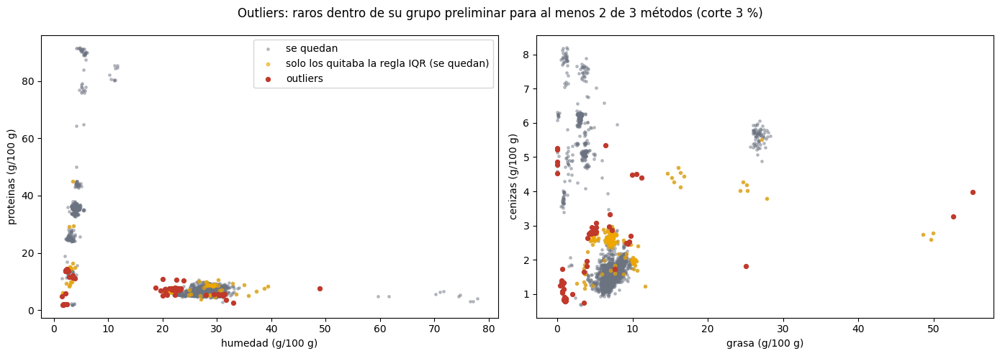

Quedan 2597 muestras

In [6]:
PCT_OUTLIER = 3                       # corte de cada método (% más raro del grupo); 2 de 3 votos
X_pre, Z_pre = muestras[COLUMNAS].to_numpy(), Z          # todas las que entran, antes de quitar (para B.5)
out_iqr, grupo_pre, K_PRE = M.outliers_iqr(Z)            # k-medias preliminar (k por silueta) y la regla IQR anterior
es_outlier, votos = M.outliers_consenso(X_pre, grupo_pre, pct=PCT_OUTLIER, minimo=2, n_vecinos=50)
ref = M.agregar_subtipo(muestras, S)                     # subtipo conocido y descripciones: NO entran, solo para comparar
muestras["subtipo_ref"] = ref["subtipo_ref"].to_numpy()
especiales = M.especiales_ddl(ref)                       # DDL repostero, heladero, reducido en grasa (por la descripción)

resumen = pd.DataFrame({"grupo preliminar": grupo_pre, "outlier": es_outlier, "regla IQR (antes)": out_iqr})
print(f"k-medias preliminar con k = {K_PRE} · outliers por consenso ({PCT_OUTLIER} %, 2 de 3): {int(es_outlier.sum())} de {len(Z)} "
      f"({100 * es_outlier.mean():.1f} %) · con la regla IQR de antes serían {int(out_iqr.sum())} ({100 * out_iqr.mean():.1f} %)")
display(resumen.groupby("grupo preliminar").agg(muestras=("outlier", "size"), outliers=("outlier", "sum"),
                                                **{"con IQR (antes)": ("regla IQR (antes)", "sum")}).assign(
    **{"% outliers": lambda t: (100 * t["outliers"] / t["muestras"]).round(1)}))
print("Cuántas marca cada método y cuántas votos juntan:", votos[["factor local", "bosque", "elipse"]].sum().to_dict(),
      "· votos:", votos["votos"].value_counts().sort_index().to_dict())
print("Consenso contra la regla IQR de antes:")
display(pd.crosstab(pd.Series(out_iqr, name="regla IQR (antes)"), pd.Series(es_outlier, name="consenso (ahora)"), margins=True))
conservados = pd.DataFrame({n: {"muestras": int(especiales[n].sum()), "se conservan (consenso)": int((especiales[n] & ~es_outlier).sum()),
                                "se conservaban (IQR)": int((especiales[n] & ~out_iqr).sum())} for n in especiales.columns}).T
print("Dulces de leche especiales (por la descripción, que no entra en el agrupamiento):"); display(conservados)
print("Outliers por familia:", muestras.loc[es_outlier, "desc_familia"].value_counts().to_dict())
print("Algunos outliers (g/100 g), los de más votos:")
display(muestras.loc[es_outlier, ["Identificador", "desc_familia", "origen"] + COLUMNAS].assign(votos=votos.loc[es_outlier, "votos"].to_numpy())
        .sort_values("votos", ascending=False).head(12))

fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5))
for ax, (x, y) in [(a, ("humedad", "proteinas")), (b, ("grasa", "cenizas"))]:
    ax.scatter(muestras.loc[~es_outlier, x], muestras.loc[~es_outlier, y], s=6, alpha=0.4, color=GRIS, label="se quedan")
    solo_iqr = out_iqr & ~es_outlier
    ax.scatter(muestras.loc[solo_iqr, x], muestras.loc[solo_iqr, y], s=10, color=AMBAR, alpha=0.6, label="solo los quitaba la regla IQR (se quedan)")
    ax.scatter(muestras.loc[es_outlier, x], muestras.loc[es_outlier, y], s=18, color=ROJO, label="outliers")
    ax.set_xlabel(f"{x} (g/100 g)"); ax.set_ylabel(f"{y} (g/100 g)")
a.legend()
fig.suptitle(f"Outliers: raros dentro de su grupo preliminar para al menos 2 de 3 métodos (corte {PCT_OUTLIER} %)")
plt.tight_layout(); plt.show()

# se guardan todas (con la marca de outlier) para el csv del final; desde acá, sin outliers
muestras_pre = muestras.assign(outlier=es_outlier)
muestras = muestras[~es_outlier].reset_index(drop=True)
familia = muestras["desc_familia"]; conocida = (familia != SIN_FAMILIA).values
imputador = SimpleImputer(strategy="median").fit(muestras[COLUMNAS])
escalador = StandardScaler().fit(imputador.transform(muestras[COLUMNAS]))
Z = escalador.transform(imputador.transform(muestras[COLUMNAS]))
print(f"Quedan {len(muestras)} muestras")

#### B · Cuántos grupos
##### B.1 · El codo y la silueta
Para k de 2 a 10: la **inercia** (baja siempre; se busca el codo) y la **silueta** promedio, (b − a)/max(a, b). Criterio
fijado antes de mirar: **k con la silueta máxima**.

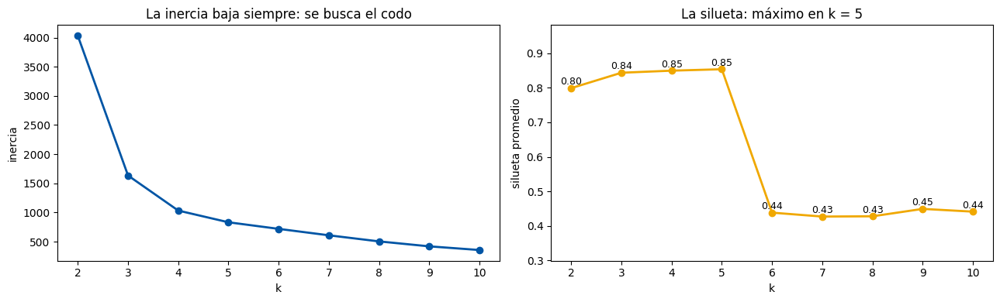

Inercia por k: {2: 4032, 3: 1635, 4: 1033, 5: 833, 6: 719, 7: 609, 8: 505, 9: 420, 10: 357}
Silueta por k: {2: 0.799, 3: 0.844, 4: 0.85, 5: 0.854, 6: 0.438, 7: 0.427, 8: 0.428, 9: 0.449, 10: 0.441}
Se elige k = 5.


In [7]:
ks = list(range(2, 11))
modelos = {k_: KMeans(n_clusters=k_, n_init=N_INIT_KMEDIAS, random_state=SEMILLA).fit(Z) for k_ in ks}
inercias = [modelos[k_].inertia_ for k_ in ks]; siluetas = [silhouette_score(Z, modelos[k_].labels_) for k_ in ks]
K = ks[int(np.argmax(siluetas))]
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4))
a.plot(ks, inercias, marker="o", color=AZUL, lw=2); a.set_xlabel("k"); a.set_ylabel("inercia"); a.set_title("La inercia baja siempre: se busca el codo")
b.plot(ks, siluetas, marker="o", color=AMBAR, lw=2); b.set_xlabel("k"); b.set_ylabel("silueta promedio"); b.set_title(f"La silueta: máximo en k = {K}")
for k_, s_ in zip(ks, siluetas): b.text(k_, s_ + 0.01, f"{s_:.2f}", ha="center", fontsize=9)
b.margins(y=0.3); plt.tight_layout(); plt.show()
print("Inercia por k:", {k_: round(float(v)) for k_, v in zip(ks, inercias)})
print("Silueta por k:", {k_: round(float(s_), 3) for k_, s_ in zip(ks, siluetas)})
print(f"Se elige k = {K}.")

**Lectura.** A diferencia de los socios del gimnasio (silueta 0,17 a 0,21, estructura débil), acá la silueta es alta
(0,80 ya con k = 2, sin outliers): hay grupos de verdad, porque los productos tienen composiciones muy distintas. El
máximo está en **k = 5** (0,854), con k = 3 y 4 muy cerca (0,84 y 0,85); con k = 6 cae a 0,44 y sigue entre 0,43 y 0,45
hasta k = 10: no hay un sexto grupo natural. (Con pocos reinicios el k que elige el k-medias preliminar, y con él el k final, cambiaba con la
semilla; con `n_init` = 50 no.) Ojo:
el dulce de leche es el 81 % de las muestras y forma una nube muy compacta, lo que
infla el promedio de la silueta. El diagrama de B.2 lo muestra grupo por grupo, y B.5 da las métricas que no dependen
del tamaño de cada grupo.

##### B.2 · El modelo elegido, sus tags y su diagrama de silueta
Los centroides se devuelven a g/100 g para leerlos. Cada grupo recibe un **tag** con las reglas sobre su centroide
(`etiquetar` en `datos_clase41.py`): humedad > 70 → LIQUIDO; entre 35 y 65 con grasa > 15 → QUESO (se evalúa antes que alta humedad); > 50 → ALTA_HUMEDAD; > 15 → DDL;
si no es un polvo: proteína > 70 → PROT_ALTA; grasa > 15 → POLVO_GRASO; si no, POLVO_MAGRO. El número de cluster cambia
entre corridas; el tag no. Si dos grupos caen en la misma regla se desambiguan con `_2`, `_3`, ordenados por humedad.
El diagrama: un coeficiente por muestra, ordenados por grupo; la altura es cuántas muestras tiene, el ancho qué tan adentro
están, la línea roja el promedio.

Centroides en g/100 g:


,tag,muestras,humedad,grasa,proteinas,cenizas
cluster,,,,,,
0,DDL,2116,27.64,7.03,6.47,1.57
1,POLVO_MAGRO,335,3.95,2.87,33.92,5.99
2,POLVO_GRASO,87,3.07,26.55,23.40,5.33
3,LIQUIDO,10,71.50,5.67,4.82,1.16
4,PROT_ALTA,49,6.39,2.39,84.76,4.11


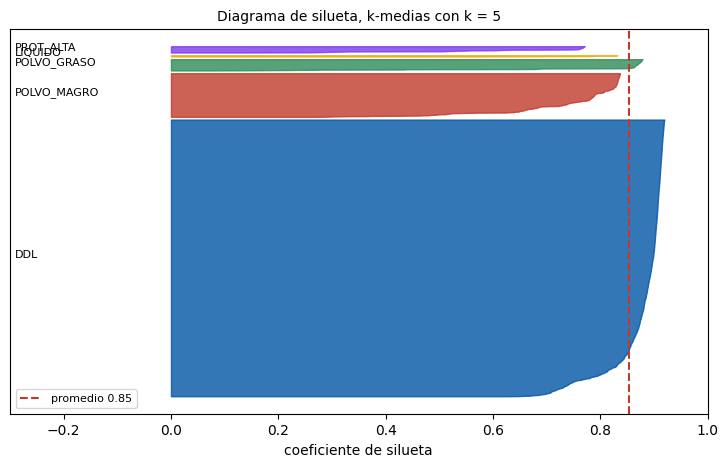

Silueta media por tag: {'DDL': 0.88, 'LIQUIDO': 0.76, 'POLVO_GRASO': 0.79, 'POLVO_MAGRO': 0.75, 'PROT_ALTA': 0.62}
Muestras con coeficiente negativo: 0 de 2597


In [8]:
km = modelos[K]; grupos = km.labels_
centros = pd.DataFrame(escalador.inverse_transform(km.cluster_centers_), columns=COLUMNAS, index=range(K)).round(2)
nombres, tags, repetidos = etiquetar(centros)
if repetidos:
    print(f"AVISO: más de un grupo cae en {repetidos}; se desambiguan con sufijo _2, _3 (por humedad del centroide).")
tag_de = np.array([tags[g] for g in grupos])
centros.insert(0, "muestras", np.bincount(grupos)); centros.insert(0, "tag", [tags[j] for j in range(K)])
centros.index.name = "cluster"
print("Centroides en g/100 g:"); display(centros)

def diagrama_silueta(ax, X, etiquetas, titulo, rotulos):
    valores = silhouette_samples(X, etiquetas); y0 = 10
    for j in range(etiquetas.max() + 1):
        v = np.sort(valores[etiquetas == j]); ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=COLORES[j], alpha=0.8)
        ax.text(-0.29, y0 + len(v) / 2, rotulos[j], fontsize=8); y0 += len(v) + 20
    ax.axvline(valores.mean(), color=ROJO, ls="--", label=f"promedio {valores.mean():.2f}")
    ax.set_xlim(-0.3, 1); ax.set_yticks([]); ax.set_xlabel("coeficiente de silueta"); ax.legend(fontsize=8); ax.set_title(titulo, fontsize=10)
    return valores

fig, ax = plt.subplots(figsize=(9, 5))
coef = diagrama_silueta(ax, Z, grupos, f"Diagrama de silueta, k-medias con k = {K}", tags)
plt.show()
print("Silueta media por tag:", pd.Series(coef).groupby(tag_de).mean().round(2).to_dict())
print(f"Muestras con coeficiente negativo: {int((coef < 0).sum())} de {len(Z)}")

##### B.5 · Métricas sin el sesgo del grupo más grande
La silueta promedio pesa cada **muestra** igual, así que la domina el DDL, que es la mayoría y forma una nube compacta.
Junto a ella (clase 43, `M.metricas`): la **silueta macro** (el promedio de las siluetas medias de cada grupo: cada
**grupo** pesa igual), la del **peor grupo**, **Davies-Bouldin** (cuánto se pisan los grupos con su vecino más
parecido; menor es mejor) y **Calinski-Harabasz** (dispersión entre grupos sobre dispersión dentro; mayor es mejor).

Para comparar el filtro de outliers nuevo con el de antes no alcanza con la silueta de cada uno sobre sus propias
muestras: el que quita más saca justo lo que está entre grupos y sale favorecido. Por eso se rehace el k-medias final
con cada filtro (`M.variante`) y se mide también sobre las **muestras comunes** (las que no quita ninguno de los dos), en
la misma escala.

In [9]:
print("Métricas del modelo elegido (sus muestras):")
display(pd.DataFrame([M.metricas(Z, grupos)]).round(3))
comunes = ~(out_iqr | es_outlier)
filtros = {}
for nombre_f, quita in [("regla IQR (antes)", out_iqr), (f"consenso {PCT_OUTLIER} % (ahora)", es_outlier)]:
    r_f, filtros[nombre_f], _ = M.variante(X_pre, quita, Z_pre, comunes)
    for e in especiales.columns:
        filtros[nombre_f][f"conserva {e}"] = int((especiales[e].to_numpy() & ~quita).sum())
assert r_f["K"] == K and (r_f["tag_de"] == tag_de).all()     # el k-medias de M.variante es el mismo de B.2
comparacion_filtros = pd.DataFrame(filtros).T.infer_objects()
print(f"Los dos filtros, cada uno con su k-medias final · muestras comunes: {int(comunes.sum())}")
display(comparacion_filtros.style.format(precision=3).format({"% quitado": "{:.1f}", "Calinski-Harabasz": "{:.0f}"}))

Métricas del modelo elegido (sus muestras):


,grupos,ruido,silueta global,silueta macro,peor grupo,Davies-Bouldin,Calinski-Harabasz
0,5,0,0.854,0.76,0.62,0.327,7437.45


Los dos filtros, cada uno con su k-medias final · muestras comunes: 2425


,% quitado,muestras,k,tags,silueta global,silueta macro,peor grupo,Davies-Bouldin,Calinski-Harabasz,silueta global (todas),silueta macro (todas),silueta global (comunes),silueta macro (comunes),Davies-Bouldin (comunes),conserva repostero,conserva heladero,conserva reducido en grasa
regla IQR (antes),8.6,2431,5,DDL LIQUIDO POLVO_GRASO POLVO_MAGRO PROT_ALTA,0.869257,0.791109,0.615366,0.316797,9846,0.839349,0.747175,0.876348,0.798804,0.303934,616,36,0
consenso 3 % (ahora),2.4,2597,5,DDL LIQUIDO POLVO_GRASO POLVO_MAGRO PROT_ALTA,0.853913,0.759912,0.620382,0.326592,7437,0.839349,0.747175,0.876348,0.798804,0.303934,620,152,3


#### F · Usarlo
##### Qué es cada grupo: cluster → tag → nombre → centroide → familia mayoritaria
El centroide en g/100 g, cuántas muestras, la familia más común y la tabla cruzada con la familia. El tag y el nombre
salen de las reglas sobre el centroide (B.2), no de la familia.

,tag,nombre,muestras,humedad,grasa,proteinas,cenizas,silueta media,familia mayoritaria,% de esa familia
cluster,,,,,,,,,,
0,DDL,pastoso tipo dulce de leche,2116,27.64,7.03,6.47,1.57,0.88,dulce de leche,100
1,POLVO_MAGRO,polvo magro (suero / concentrado),335,3.95,2.87,33.92,5.99,0.75,concentrado proteico,82
2,POLVO_GRASO,polvo graso (tipo leche entera),87,3.07,26.55,23.40,5.33,0.79,leche en polvo,82
3,LIQUIDO,líquido (leche fluida / suero),10,71.50,5.67,4.82,1.16,0.76,dulce de leche,50
4,PROT_ALTA,polvo de proteína muy alta,49,6.39,2.39,84.76,4.11,0.62,concentrado proteico,100


desc_familia,dulce de leche,concentrado proteico,leche en polvo,suero / permeado,yogur / bebida lactea,helado,arroz con leche / postre
tag,,,,,,,
DDL,2115,0,0,0,0,1,0
LIQUIDO,5,0,0,0,1,2,2
POLVO_GRASO,0,1,71,8,7,0,0
POLVO_MAGRO,0,276,29,30,0,0,0
PROT_ALTA,0,49,0,0,0,0,0


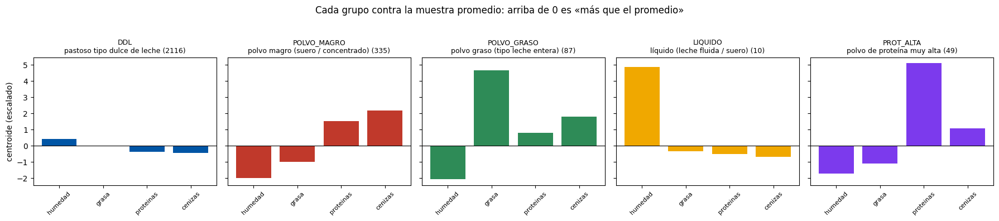

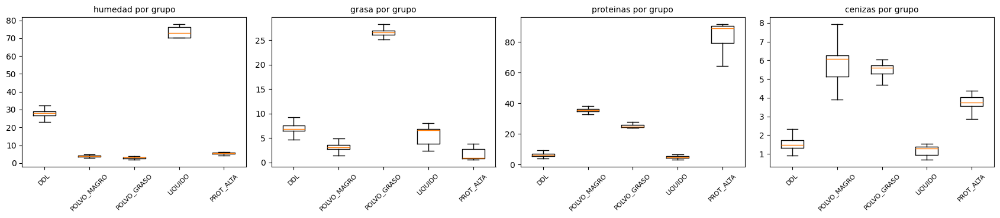

In [10]:
descripcion = centros.copy(); descripcion.insert(1, "nombre", [nombres[j] for j in range(K)])
descripcion["silueta media"] = [round(float(coef[grupos == j].mean()), 2) for j in range(K)]
fam_c = familia[conocida]; gr_c = grupos[conocida]
descripcion["familia mayoritaria"] = [fam_c[gr_c == j].mode()[0] if (gr_c == j).any() else "-" for j in range(K)]
descripcion["% de esa familia"] = [round(100 * (fam_c[gr_c == j] == fam_c[gr_c == j].mode()[0]).mean()) if (gr_c == j).any() else 0 for j in range(K)]
display(descripcion)
tabla = pd.crosstab(pd.Series(tag_de, name="tag"), familia)
display(tabla.loc[:, tabla.sum().sort_values(ascending=False).index])

fig, ejes = plt.subplots(1, K, figsize=(3.6 * K, 3.8), sharey=True)
for j, ax in enumerate(np.atleast_1d(ejes)):
    ax.bar(COLUMNAS, km.cluster_centers_[j], color=COLORES[j]); ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"{tags[j]}\n{nombres[j]} ({np.bincount(grupos)[j]})", fontsize=9); ax.tick_params(axis="x", rotation=45, labelsize=8)
np.atleast_1d(ejes)[0].set_ylabel("centroide (escalado)")
fig.suptitle("Cada grupo contra la muestra promedio: arriba de 0 es «más que el promedio»", y=1.03)
plt.tight_layout(); plt.show()

fig, ejes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, col in zip(ejes, COLUMNAS):
    ax.boxplot([muestras.loc[grupos == j, col] for j in range(K)], tick_labels=[tags[j] for j in range(K)], showfliers=False)
    ax.set_title(f"{col} por grupo", fontsize=10); ax.tick_params(axis="x", rotation=45, labelsize=8)
plt.tight_layout(); plt.show()

##### Segundo nivel por familia: subtags del DDL, de los polvos y del queso
El primer nivel separa tipos de producto; adentro de tres de ellos hay variantes que importan. Cada rama usa el método
que aprobó su prueba por familia (README, «Pruebas por familia»; código en `src/segundo_nivel.py`). Las ramas van por el
**tag**, no por la familia del rótulo: así el subtag queda siempre dentro de su tag y se puede predecir para una muestra
nueva con los cuatro análisis.

| rama | muestras | método | subtags |
|---|---|---|---|
| DDL | tag DDL | **regresión logística** multinomial sobre los cuatro análisis, entrenada con el subtipo conocido (`desc_subtipo`, o el de `desc_producto` o `mq_tipo_muestra.csv`); decide si la probabilidad es ≥ 0,70 y la muestra no es novedad (Mahalanobis robusta o LOF). Exactitud balanceada 0,86 en clientes no vistos (`prueba_subtipo_ddl.ipynb`) | DDL_FAMILIAR, DDL_REPOSTERO, DDL_HELADERO; «DDL» si no decide |
| polvo | tags POLVO_GRASO, POLVO_MAGRO y PROT_ALTA con humedad ≤ 15 | primero dos **reglas de composición en base seca**: suero reengrasado (grasa ≥ 15 y proteína ≤ 12) y leche descremada (grasa ≤ 2,5, cenizas ≥ 7 y proteína 30 a 40); el resto, outliers por consenso dentro de la rama y **k-medias** (k por silueta) en grasa, proteína y cenizas **en base seca**; un cluster lleva subtag si su tipo del rótulo tiene pureza ≥ 70 % y cobertura ≥ 50 % o, si no, su familia pureza ≥ 70 %, contado sin las muestras de las reglas (`prueba_clustering_polvos.ipynb`) | POLVO_SUERO_REENGRASADO, POLVO_LECHE_DESCREMADA, POLVO_LECHE_ENTERA, POLVO_WPC, POLVO_CASEINATO, POLVO_SUERO_...; el tag si no |
| queso | los quesos que confirma el catálogo (rama propia, fuera del k-medias; abajo) | **clase de humedad del CAA** (art. 605): < 36 duro, 36 a 46 semiduro, 46 a 55 pasta blanda, ≥ 55 muy alta humedad. Coincide con la consistencia del rótulo mejor que cualquier agrupamiento (`prueba_clustering_quesos.ipynb`) | QUESO_DURO, QUESO_SEMIDURO, QUESO_PASTA_BLANDA, QUESO_MUY_ALTA_HUMEDAD |

Las dos reglas del polvo existen porque el k-medias no separa esos productos: escala la proteína con todos los polvos
(de 3 a 91 g/100 g de extracto seco), y a esa escala el suero reengrasado queda con la leche entera o con los sueros
magros, y la leche descremada (proteína 35, cenizas 8) con un concentrado de suero de 46 % de proteína y las mismas
cenizas: ningún k de 6 a 14 le da un cluster puro. Por proteína sola la leche descremada (34 a 38,5) y el WPC 35 (35 a
39) se pisan; los separan las cenizas (8,1 contra 6,2) y la grasa (1,1 contra 3,4). Los umbrales salen de los rótulos y
se verifican abajo (subtag × tipo del rótulo).

Los demás tags quedan sin subtag (su subtag es el tag). El queso no depende del k-medias: sale de su rama. El subtipo o tipo del rótulo se usa para entrenar (DDL) y para
nombrar los clusters (polvo), **nunca como entrada**. Reemplaza al segundo nivel anterior (mezcla de gaussianas dentro del
DDL, que daba DDL_HELADERO y DDL_FAMILIAR y nunca el repostero). Los subtags se juzgan por pureza y cobertura, no con la
silueta: son un segundo nivel dentro de un grupo, no grupos del primero.

In [11]:
subtag_de, criterio_de, modelos_subtag = N.ajustar(muestras, tag_de, S)
print("De dónde sale el subtag:", pd.Series(criterio_de).value_counts().to_dict())
print("Muestras por subtag:", pd.Series(subtag_de).value_counts().to_dict())
base_ = N.tag_base(tag_de)          # sin el sufijo _2, _3: los clusters repetidos van a la misma rama
ddl_ = base_ == "DDL"
m_ = modelos_subtag["DDL"]
print(f"DDL · logística entrenada con {m_['etiquetadas']} muestras con subtipo {m_['por_clase']}; "
      f"decide en {int((criterio_de[ddl_] == N.C_DDL).sum())} de {int(ddl_.sum())}")
print("DDL · subtag (filas) contra el subtipo conocido (columnas); en las que tienen subtipo es el ajuste sobre ellas mismas:")
display(pd.crosstab(subtag_de[ddl_], muestras.loc[ddl_, "subtipo_ref"].fillna("sin subtipo").to_numpy(),
                    rownames=["subtag"], colnames=["subtipo conocido"], margins=True, margins_name="total"))
if "polvo" in modelos_subtag:
    p_ = modelos_subtag["polvo"]
    print(f"Polvo · {p_['n']} muestras en la rama, {p_['n_outliers']} outliers de la rama · k-medias con k = {p_['k']} "
          f"(silueta {p_['siluetas'][p_['k']]:.3f}) · por cluster (base seca, g/100 g de extracto seco):")
    display(p_["descripcion"])
    pol_ = N.es_polvo(tag_de)
    print("Polvo · tag (filas) × subtag (columnas):")
    display(pd.crosstab(tag_de[pol_], subtag_de[pol_], rownames=["tag"], colnames=["subtag"]))
    tipo_ = N._referencias_polvo(muestras.loc[pol_, "Identificador"], S)["tipo"].fillna("sin tipo").to_numpy()
    print("Polvo · subtag (filas) × tipo del rótulo (columnas); el tipo no entra, sirve para verificar las reglas y los nombres:")
    t_ = pd.crosstab(subtag_de[pol_], tipo_, rownames=["subtag"], colnames=["tipo del rótulo"])
    display(t_.loc[:, t_.sum().sort_values(ascending=False).index])
if "queso" in modelos_subtag:
    q_ = base_ == "QUESO"
    print("Queso · subtag × familia del rótulo:")
    display(pd.crosstab(subtag_de[q_], muestras.loc[q_, "desc_familia"].to_numpy(), rownames=["subtag"], colnames=["familia"],
                        margins=True, margins_name="total"))

De dónde sale el subtag: {'DDL: logística (prob ≥ 0,70)': 1632, 'DDL: sin decidir (prob < 0,70)': 452, 'polvo: k-medias en base seca': 423, 'DDL: sin decidir (novedad)': 32, 'polvo: regla leche descremada (grasa ≤ 2,5, cenizas ≥ 7, proteína 30 a 40)': 29, 'sin segundo nivel': 10, 'polvo: regla suero reengrasado (grasa ≥ 15, proteína ≤ 12)': 8, 'polvo: cluster sin tipo': 7, 'polvo: outlier de la rama': 4}
Muestras por subtag: {'DDL_FAMILIAR': 854, 'DDL_REPOSTERO': 621, 'DDL': 484, 'POLVO_WPC': 275, 'DDL_HELADERO': 157, 'POLVO_LECHE_ENTERA': 72, 'POLVO_CASEINATO': 39, 'POLVO_SUERO_PERMEADO': 32, 'POLVO_LECHE_DESCREMADA': 29, 'LIQUIDO': 10, 'POLVO_SUERO_REENGRASADO': 8, 'POLVO_GRASO': 7, 'POLVO_CONCENTRADO': 5, 'PROT_ALTA': 4}
DDL · logística entrenada con 1521 muestras con subtipo {'FAMILIAR': 749, 'REPOSTERO': 620, 'HELADERO': 152}; decide en 1632 de 2116
DDL · subtag (filas) contra el subtipo conocido (columnas); en las que tienen subtipo es el ajuste sobre ellas mismas:


subtipo conocido,FAMILIAR,HELADERO,REPOSTERO,sin subtipo,total
subtag,,,,,
DDL,145,5,122,212,484
DDL_FAMILIAR,564,0,44,246,854
DDL_HELADERO,1,146,3,7,157
DDL_REPOSTERO,39,1,451,130,621
total,749,152,620,595,2116


Polvo · 471 muestras en la rama, 8 outliers de la rama · k-medias con k = 8 (silueta 0.734) · por cluster (base seca, g/100 g de extracto seco):


,subtag,muestras,clientes,grasa_bs,proteina_bs,cenizas_bs,resto_bs,humedad,tipo mayoritario,% tipo,con tipo,% cobertura tipo,familia mayoritario,% familia,CAA leche mayoritario,% CAA leche
cluster,,,,,,,,,,,,,,,,
0,POLVO_SUERO_PERMEADO,32,7,1.5,11.4,5.1,82.0,3.0,SUERO DESMINERALIZADO,47.0,32,100.0,suero / permeado,94.0,-,NaN
1,(el tag),7,0,16.4,19.8,4.6,59.2,3.3,-,NaN,0,NaN,-,NaN,-,NaN
2,POLVO_LECHE_ENTERA,72,13,27.6,26.4,5.8,40.3,3.1,LECHE ENTERA,97.0,65,100.0,leche en polvo,99.0,entera,97.0
3,POLVO_WPC,98,3,3.8,37.2,5.3,53.7,4.0,WPC,99.0,98,36.0,concentrado proteico,100.0,-,NaN
4,POLVO_WPC,148,4,3.0,37.4,6.4,53.2,4.1,WPC,99.0,148,54.0,concentrado proteico,100.0,-,NaN
5,POLVO_WPC,29,2,3.7,45.1,7.8,43.3,4.3,WPC,100.0,27,10.0,concentrado proteico,100.0,-,NaN
6,POLVO_CONCENTRADO,5,1,1.3,90.5,9.0,-0.8,10.9,CASEINA,100.0,5,83.0,concentrado proteico,100.0,-,NaN
7,POLVO_CASEINATO,39,2,2.6,91.0,3.9,2.5,5.5,CASEINATO,84.0,31,100.0,concentrado proteico,100.0,-,NaN


Polvo · tag (filas) × subtag (columnas):


subtag,POLVO_CASEINATO,POLVO_CONCENTRADO,POLVO_GRASO,POLVO_LECHE_DESCREMADA,POLVO_LECHE_ENTERA,POLVO_SUERO_PERMEADO,POLVO_SUERO_REENGRASADO,POLVO_WPC,PROT_ALTA
tag,,,,,,,,,
POLVO_GRASO,0,0,7,0,72,0,8,0,0
POLVO_MAGRO,0,0,0,29,0,32,0,274,0
PROT_ALTA,39,5,0,0,0,0,0,1,4


Polvo · subtag (filas) × tipo del rótulo (columnas); el tipo no entra, sirve para verificar las reglas y los nombres:


tipo del rótulo,WPC,LECHE ENTERA,LECHE DESCREMADA,CASEINATO,sin tipo,SUERO,SUERO DESMINERALIZADO,CASEINA,PERMEADO,PROTEINAS LACTEAS,SUERO REENGRASADO,LECHE MODIFICADA,LECHE PARCIALMENTE DESCREMADA,MPC
subtag,,,,,,,,,,,,,,
POLVO_CASEINATO,2,0,0,26,8,0,0,1,0,2,0,0,0,0
POLVO_CONCENTRADO,0,0,0,0,0,0,0,5,0,0,0,0,0,0
POLVO_GRASO,0,0,0,0,7,0,0,0,0,0,0,0,0,0
POLVO_LECHE_DESCREMADA,0,0,28,0,0,0,0,0,0,0,0,0,1,0
POLVO_LECHE_ENTERA,0,63,0,0,7,0,0,0,0,0,0,1,0,1
POLVO_SUERO_PERMEADO,0,0,0,0,0,9,15,0,6,2,0,0,0,0
POLVO_SUERO_REENGRASADO,0,0,0,0,0,6,0,0,0,0,2,0,0,0
POLVO_WPC,271,0,0,0,2,0,0,0,0,2,0,0,0,0
PROT_ALTA,0,0,0,0,1,0,0,3,0,0,0,0,0,0


##### Rama de queso: fuera del k-medias de cuatro análisis
Los quesos no pasan por el k-medias: casi ninguno trae proteína ni cenizas (Senasa no las pide en queso), así que con la
regla de los cuatro análisis quedaban afuera o, si entraban, formaban un grupo débil entre el dulce de leche y los
polvos. Van a una **rama propia** con lo que sí tienen: **humedad** (100 − sólidos totales) y **materia grasa**. Solo
entra como queso **lo que confirma el catálogo**:

- **Senasa**: `desc_familia = queso`.
- **Solo MQ** (con `MQ encolumnado.xlsx`): la familia de las muestras solo MQ sale de un modelo (`mq_tipo_muestra.csv`,
  sin revisar a mano), así que no alcanza. Hace falta que el **rótulo** nombre una variedad de queso (el subtipo
  normalizado con el catálogo). Las que el modelo llama queso pero el rótulo no confirma **no entran** a la rama y siguen
  en el k-medias si tienen los cuatro análisis (desconfiar por defecto: no se les asume categoría).

Una muestra tiene **una sola asignación**: los quesos confirmados salen del k-medias (se quitan antes de elegir k y de
buscar outliers), de modo que el tag QUESO sale solo de esta rama. El **subtag** es la clase de humedad del CAA (art. 605):
< 36 duro, 36 a 46 semiduro, 46 a 55 pasta blanda, ≥ 55 muy alta humedad (`segundo_nivel.subtag_queso`; en
`prueba_clustering_quesos.ipynb` coincide con la consistencia del rótulo mejor que cualquier agrupamiento). Se piden MG y
ST y se descartan los imposibles (MG > ST, humedad + ST fuera de 100 ± 1). Código: `clustering_quesos.rama_queso`.

In [12]:
rama = rama.copy()
rama["subtag"] = N.subtag_queso(rama["humedad"]); rama["criterio_subtag"] = N.C_QUESO
assert (rama["subtag"] == rama["caa_humedad"].map(lambda c_: "QUESO_" + Q.NOMBRE_CAA[c_])).all()   # misma regla que el CAA
print("Cuántos quesos confirma el catálogo y cuántos entran a la rama:")
print({k_: v_ for k_, v_ in conteo_q.items()})
print(f"Rama de queso: {len(rama)} muestras · por origen: {rama['origen'].value_counts().to_dict()}")
print("Subtag:", rama["subtag"].value_counts().to_dict())
display(pd.crosstab(rama["subtag"], rama["origen"], margins=True, margins_name="total"))
print("Subtag (filas) contra la consistencia del rótulo (columnas); el rótulo no entra, solo se compara:")
display(pd.crosstab(rama["subtag"], rama["consistencia"].fillna("sin dato"), margins=True, margins_name="total"))
print("Con solo Senasa no hay solo MQ: todos los quesos son de desc_familia = queso.")

Cuántos quesos confirma el catálogo y cuántos entran a la rama:
{'quesos leídos': 4006, 'con MG y ST': 1627, 'excluidas: humedad + ST fuera de 100 ± 1': 0, 'excluidas: MG > ST o fuera de rango': 0, 'quedan': 1627, 'solo MQ de familia queso sin confirmar por el rótulo (no entran)': 0, 'de ellas, con MG y ST': 0}
Rama de queso: 1627 muestras · por origen: {'Senasa': 1627}
Subtag: {'QUESO_SEMIDURO': 793, 'QUESO_PASTA_BLANDA': 358, 'QUESO_DURO': 325, 'QUESO_MUY_ALTA_HUMEDAD': 151}


origen,Senasa,total
subtag,,
QUESO_DURO,325,325
QUESO_MUY_ALTA_HUMEDAD,151,151
QUESO_PASTA_BLANDA,358,358
QUESO_SEMIDURO,793,793
total,1627,1627


Subtag (filas) contra la consistencia del rótulo (columnas); el rótulo no entra, solo se compara:


consistencia,alta humedad,baja humedad,mediana humedad,procesado,sin dato,untable,total
subtag,,,,,,,
QUESO_DURO,0,295,1,26,3,0,325
QUESO_MUY_ALTA_HUMEDAD,4,0,1,137,0,9,151
QUESO_PASTA_BLANDA,309,0,42,7,0,0,358
QUESO_SEMIDURO,54,6,702,21,10,0,793
total,367,301,746,191,13,9,1627


Con solo Senasa no hay solo MQ: todos los quesos son de desc_familia = queso.


##### ¿Se pueden diferenciar los quesos en clusters sin aprender de un tag previo?
Se agrupan los quesos de la rama usando **solo humedad y MGES** (grasa en el extracto seco = 100·MG/ST), estandarizadas y
sin los outliers por consenso (3 %). No se usa ningún rótulo ni el CAA para ajustar nada: **k-medias** con k por silueta
y **mezcla de gaussianas** con k por BIC. Recién después se comparan con la **clase de humedad del CAA**, la **clase de
MGES del CAA** y la **consistencia** y el **tipo** del rótulo: Rand ajustado (ARI, 0 = azar, 1 = igual) e información
mutua normalizada (NMI), tablas cruzadas y estabilidad con otras semillas (`clustering_quesos.no_supervisado`). La fila
«regla CAA de humedad» es el corte del CAA aplicado directo, sin agrupar: es el techo contra el que mirar.

1627 quesos · 43 outliers por consenso · se agrupan 1584
k-medias, silueta por k: {2: 0.425, 3: 0.483, 4: 0.518, 5: 0.52, 6: 0.457, 7: 0.479, 8: 0.469, 9: 0.431, 10: 0.436} → k = 5
Mezcla de gaussianas, BIC por k: {1: 8950, 2: 8054, 3: 7846, 4: 7155, 5: 6908, 6: 6788, 7: 6663, 8: 6672} → k = 7


,k-medias (k = 5),"mezcla de gaussianas (k = 7, BIC)",regla CAA de humedad (sin agrupar)
grupos,5.00,7.00,4.00
ruido,0.00,0.00,0.00
silueta,0.52,0.43,0.31
silueta macro,0.53,0.46,0.34
peor grupo,0.37,0.06,0.26
Davies-Bouldin,0.63,0.79,1.23
Calinski-Harabasz,1716.79,1414.79,682.30
ARI CAA humedad,0.40,0.46,1.00
NMI CAA humedad,0.53,0.58,1.00
ARI CAA MGES,0.37,0.29,0.23


k-medias (k = 5) (filas) contra CAA humedad (columnas):


CAA humedad,alta humedad,baja humedad,mediana humedad,muy alta humedad
cluster,,,,
0,0,87,0,0
1,0,200,123,0
2,104,3,530,7
3,253,0,140,1
4,1,0,0,135


k-medias (k = 5) (filas) contra CAA MGES (columnas):


CAA MGES,extra graso,graso,semigraso
cluster,,,
0,0,0,87
1,0,207,116
2,1,643,0
3,0,50,344
4,2,99,35


... (7 outputs left out)

consistencia,alta humedad,baja humedad,mediana humedad,procesado,sin dato,untable
cluster,,,,,,
0,0,77,0,0,0,0
1,0,138,0,0,0,0
2,36,77,202,2,13,0
3,9,0,534,0,0,0
4,252,0,9,25,0,0
5,68,0,0,53,0,0
6,0,0,1,85,0,3


Estabilidad con 10 semillas: ARI de cada partición contra la de la semilla base (mismo k) y k que elige cada criterio:


,ARI k-medias (k fijo),ARI mezcla (k fijo),k elegido k-medias,k elegido mezcla
semilla,,,,
0,1.0,0.99,5,7
1,1.0,0.98,5,7
2,1.0,0.99,5,7
3,1.0,0.98,5,7
4,1.0,0.99,5,7
5,1.0,0.99,5,7
6,1.0,0.98,5,7
7,1.0,0.99,5,7
8,1.0,0.99,5,7


Promedio: {'ARI k-medias (k fijo)': 0.998, 'ARI mezcla (k fijo)': 0.987, 'k elegido k-medias': 5.0, 'k elegido mezcla': 7.0}


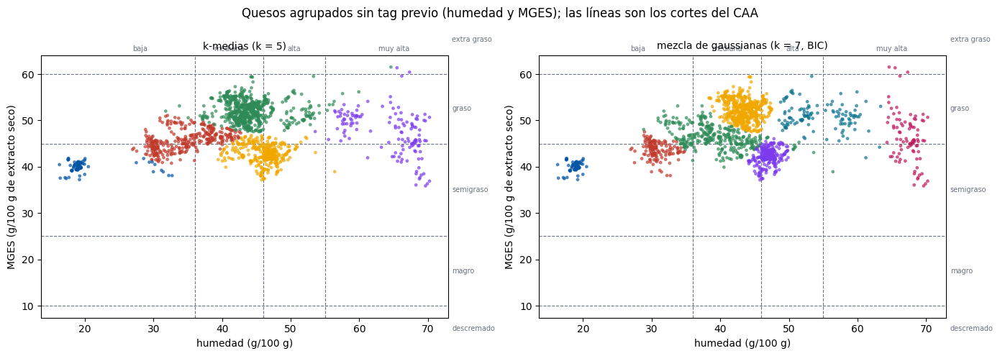

In [13]:
ns = Q.no_supervisado(rama)
print(f"{len(rama)} quesos · {ns['n_outliers']} outliers por consenso · se agrupan {len(ns['base'])}")
print("k-medias, silueta por k:", {k_: round(float(v_), 3) for k_, v_ in ns["silueta"].items()}, "→ k =", ns["k_km"])
print("Mezcla de gaussianas, BIC por k:", {k_: round(float(v_)) for k_, v_ in ns["bic"].items()}, "→ k =", ns["k_gm"])
display(ns["tabla"].round(2).T)
for (alg_, ref_), t_ in ns["cruzadas"].items():
    print(f"{alg_} (filas) contra {ref_} (columnas):")
    display(t_)
print("Estabilidad con 10 semillas: ARI de cada partición contra la de la semilla base (mismo k) y k que elige cada criterio:")
display(ns["estabilidad"].round(2))
print("Promedio:", ns["estabilidad"].mean().round(3).to_dict())

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
for ax_, (nombre_, et_) in zip(ejes, ns["et"].items()):
    ax_.scatter(ns["base"]["humedad"], ns["base"]["mges"], c=[COLORES[e_ % len(COLORES)] for e_ in et_], s=6, alpha=0.6)
    Q.lineas_caa(ax_); ax_.set_xlabel("humedad (g/100 g)"); ax_.set_ylabel("MGES (g/100 g de extracto seco)"); ax_.set_title(nombre_, fontsize=10)
fig.suptitle("Quesos agrupados sin tag previo (humedad y MGES); las líneas son los cortes del CAA")
plt.tight_layout(); plt.show()

**Respuesta.** Sí hay estructura, pero no es la del dominio y el número de grupos no es robusto. De los 1627 quesos de
Senasa, 43 salen como outliers y se agrupan 1584 (humedad y MGES estandarizadas).

- **Qué encuentra.** k-medias elige k = 5 (silueta 0,52; silueta macro 0,53; Davies-Bouldin 0,63) y la mezcla de
  gaussianas k = 7 por BIC (silueta 0,43). Son grupos más compactos que los del corte del CAA (silueta 0,31, Davies-Bouldin
  1,23): la composición no es una nube uniforme.
- **Coincidencia con el dominio.** Contra la clase de humedad del CAA el Rand ajustado (ARI) es 0,40 (k-medias) y 0,46
  (mezcla); contra la clase de MGES, 0,37 y 0,29. Los extremos se reconocen: un grupo de 135 quesos es casi puro de muy alta
  humedad (135 de 136) y otro de 87, puro de baja humedad; en el medio no hay un corte natural: dos grupos mezclan
  mediana y alta humedad (530 y 104; 140 y 253), porque el límite de 46 g/100 g del CAA cae dentro de una nube continua.
  Contra la **consistencia del rótulo** el agrupamiento da ARI 0,51 y 0,54, y la **regla del CAA aplicada directo, 0,76**:
  el corte por humedad coincide con el rótulo mejor que cualquier agrupamiento sin tag. Contra el **tipo** (variedad) pasa
  al revés: 0,46 y 0,52 contra 0,26 de la regla, porque los grupos separan también por grasa.
- **Estabilidad.** Con k fijo, otras 10 semillas dan la misma partición (ARI medio 1,00 en k-medias y 0,99 en la mezcla),
  y el k que elige la silueta es 5 en las 10 semillas (la mezcla elige 7 en las 10).

Conclusión: sin tag previo se separan grupos reproducibles en la composición, pero son una partición del continuo y
no una clasificación por tipo de queso; por eso el subtag de la rama sale de la regla del CAA, que además coincide mejor
con el rótulo.

##### Guardar: el tag y el subtag de cada muestra y el agrupamiento
`clusters_senasa.csv`: una fila por muestra que pasó el filtro (incluidos los outliers, que quedan sin cluster, tag ni subtag),
con Identificador, familia, origen, los cuatro análisis, cluster, tag, subtag (el tag cuando no hay subtag),
criterio_subtag (de qué rama y regla sale), silueta, outlier, votos_outlier (cuántos de los tres métodos la marcan) y, en
el DDL, las tres probabilidades de la logística (p_familiar, p_heladero, p_repostero). Y `agrupamiento_senasa_clase41.joblib`: imputar,
escalar y k-medias en un `Pipeline`, con el mapeo cluster → tag, los nombres, los centroides, el filtro de outliers usado
y los modelos del segundo nivel (`segundo_nivel`: la logística y los detectores de novedad del DDL; el escalador, el
k-medias, el mapeo cluster → subtag y los outliers de la rama del polvo; los cortes de humedad del queso).
`N.predecir` los usa.

In [14]:
import joblib
from sklearn.pipeline import Pipeline
muestras["cluster"] = grupos; muestras["tag"] = tag_de; muestras["subtag"] = subtag_de; muestras["criterio_subtag"] = criterio_de
muestras["silueta"] = coef
prob_ = N.probabilidades_ddl(modelos_subtag, muestras.loc[N.tag_base(tag_de) == "DDL", COLUMNAS]).round(4)
for c_ in prob_:
    muestras[c_] = np.nan
    muestras.loc[N.tag_base(tag_de) == "DDL", c_] = prob_[c_].to_numpy()
salida = muestras_pre[["Identificador", "desc_familia", "origen"] + COLUMNAS + ["outlier"]].rename(columns={"desc_familia": "familia"})
salida["votos_outlier"] = votos["votos"].to_numpy()
salida = salida.merge(muestras[["Identificador", "cluster", "tag", "subtag", "criterio_subtag", "silueta"] + list(prob_)],
                      on="Identificador", how="left")
salida["cluster"] = salida["cluster"].astype("Int64"); salida["silueta"] = salida["silueta"].round(4)
salida["rama"] = "k-medias"
filas_queso = pd.DataFrame({"Identificador": rama["Identificador"], "familia": "queso", "origen": rama["origen"], "humedad": rama["humedad"],
                            "grasa": rama["mg"], "proteinas": rama["proteina"], "cenizas": rama["cenizas"], "tag": "QUESO",
                            "subtag": rama["subtag"], "criterio_subtag": rama["criterio_subtag"], "outlier": False,
                            "rama": "queso (humedad y MG)"})
salida = pd.concat([salida, filas_queso], ignore_index=True)       # los quesos de la rama: sin cluster ni silueta
salida = salida[["Identificador", "familia", "origen", "rama"] + COLUMNAS + ["cluster", "tag", "subtag", "criterio_subtag", "silueta",
                                                                           "outlier", "votos_outlier"] + list(prob_)]
salida.to_csv(R.TABLAS / "clusters_senasa.csv", index=False, encoding="utf-8-sig")
print(f"Guardado: resultados/tablas/clusters_senasa.csv ({len(salida)} filas: {int((salida['rama'] == 'k-medias').sum())} del k-medias y {len(filas_queso)} de la rama de queso; "
      f"{int(salida['tag'].notna().sum())} con tag, {int(salida['outlier'].sum())} outliers)")
print("tag:", salida["tag"].value_counts(dropna=False).to_dict())
print("subtag:", salida["subtag"].value_counts(dropna=False).to_dict())
print("criterio_subtag:", salida["criterio_subtag"].value_counts(dropna=False).to_dict())

agrupamiento = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler()),
                         ("kmedias", KMeans(n_clusters=K, n_init=N_INIT_KMEDIAS, random_state=SEMILLA))]).fit(muestras[COLUMNAS])
assert (agrupamiento.predict(muestras[COLUMNAS]) == grupos).all()
out_polvo_ = muestras["Identificador"].isin(modelos_subtag.get("polvo", {}).get("outliers", [])).to_numpy()
assert (N.predecir(modelos_subtag, muestras[COLUMNAS], tag_de, out_polvo_)[0] == subtag_de).all()
joblib.dump({"modelo": agrupamiento, "tags": tags, "nombres": nombres, "columnas": COLUMNAS, "centros": centros,
             "outliers": {"método": "consenso (LOF 50 vecinos, IsolationForest 200, EllipticEnvelope) dentro del k-medias preliminar",
                          "k_preliminar": K_PRE, "pct": PCT_OUTLIER, "minimo_votos": 2},
             "segundo_nivel": N.para_guardar(modelos_subtag),
             "rama_queso": {"criterio": "familia queso del catálogo (Senasa) o rótulo con variedad (solo MQ); humedad = 100 − ST; subtag por clase de humedad del CAA",
                            "cortes_humedad": N.CORTES_QUESO, "muestras": int(len(rama))}},
            R.MODELOS / "agrupamiento_senasa_clase41.joblib")
print("Guardado: resultados/modelos/agrupamiento_senasa_clase41.joblib · cluster → tag:", tags, "· ramas del segundo nivel:", list(modelos_subtag),
      "· polvo, cluster → subtag:", modelos_subtag.get("polvo", {}).get("mapa"))

Guardado: resultados/tablas/clusters_senasa.csv (4287 filas: 2660 del k-medias y 1627 de la rama de queso; 4224 con tag, 63 outliers)
tag: {'DDL': 2116, 'QUESO': 1627, 'POLVO_MAGRO': 335, 'POLVO_GRASO': 87, nan: 63, 'PROT_ALTA': 49, 'LIQUIDO': 10}
subtag: {'DDL_FAMILIAR': 854, 'QUESO_SEMIDURO': 793, 'DDL_REPOSTERO': 621, 'DDL': 484, 'QUESO_PASTA_BLANDA': 358, 'QUESO_DURO': 325, 'POLVO_WPC': 275, 'DDL_HELADERO': 157, 'QUESO_MUY_ALTA_HUMEDAD': 151, 'POLVO_LECHE_ENTERA': 72, nan: 63, 'POLVO_CASEINATO': 39, 'POLVO_SUERO_PERMEADO': 32, 'POLVO_LECHE_DESCREMADA': 29, 'LIQUIDO': 10, 'POLVO_SUERO_REENGRASADO': 8, 'POLVO_GRASO': 7, 'POLVO_CONCENTRADO': 5, 'PROT_ALTA': 4}
criterio_subtag: {'DDL: logística (prob ≥ 0,70)': 1632, 'queso: humedad del CAA': 1627, 'DDL: sin decidir (prob < 0,70)': 452, 'polvo: k-medias en base seca': 423, nan: 63, 'DDL: sin decidir (novedad)': 32, 'polvo: regla leche descremada (grasa ≤ 2,5, cenizas ≥ 7, proteína 30 a 40)': 29, 'sin segundo nivel': 10, 'polvo: regla su

##### Cuántos datos entran en cada entrenamiento
La celda siguiente guarda los conteos de esta versión (cuántas muestras hay antes de los filtros, cuántas saca cada filtro,
cuántas entran a cada modelo); el apartado «Datos usados en cada entrenamiento», al final del cuaderno, los junta en una
tabla. No calcula nada nuevo.

In [15]:
ENTRENOS = globals().get("ENTRENOS", {})
n_nolact, n_quesos = int(no_lactea.sum()), int(a_rama.sum())
_ddl, _pol = modelos_subtag["DDL"], modelos_subtag["polvo"]
ENTRENOS["senasa"] = dict(
    inicial=n_inicial, n_hs=n_inicial - len(todas) - n_nolact - n_quesos, n_nolact=n_nolact, n_quesos=n_quesos,
    n_sin4=len(todas) - len(completas), n_suma=len(completas) - len(muestras_pre),
    pre=len(muestras_pre), k_pre=int(K_PRE), n_out=int(es_outlier.sum()), final=len(muestras), k=int(K), silueta=float(coef.mean()),
    ddl_n=int(ddl_.sum()), ddl_lab=int(_ddl["etiquetadas"]), ddl_clases=dict(_ddl["por_clase"]),
    ddl_decide=int((criterio_de[ddl_] == N.C_DDL).sum()),
    pol_tag=int(pol_.sum()), pol_rama=int(_pol["n"]), pol_out=int(_pol["n_outliers"]), pol_k=int(_pol["k"]),
    pol_sil=float(_pol["siluetas"][_pol["k"]]),
    q_leidos=int(conteo_q["quesos leídos"]), q_mgst=int(conteo_q["con MG y ST"]), q_rama=len(rama),
    q_sin_confirmar=int(conteo_q.get("solo MQ de familia queso sin confirmar por el rótulo (no entran)", 0)),
    q_out=int(ns["n_outliers"]), q_base=len(ns["base"]), q_k_km=int(ns["k_km"]), q_k_gm=int(ns["k_gm"]),
    comparacion=False)
print({k_: v_ for k_, v_ in ENTRENOS["senasa"].items()})

{'inicial': 16347, 'n_hs': 8, 'n_nolact': 1727, 'n_quesos': 4006, 'n_sin4': 7946, 'n_suma': 0, 'pre': 2660, 'k_pre': 5, 'n_out': 63, 'final': 2597, 'k': 5, 'silueta': 0.8539128512077044, 'ddl_n': 2116, 'ddl_lab': 1521, 'ddl_clases': {'FAMILIAR': 749, 'REPOSTERO': 620, 'HELADERO': 152}, 'ddl_decide': 1632, 'pol_tag': 471, 'pol_rama': 471, 'pol_out': 8, 'pol_k': 8, 'pol_sil': 0.733676343794965, 'q_leidos': 4006, 'q_mgst': 1627, 'q_rama': 1627, 'q_sin_confirmar': 0, 'q_out': 43, 'q_base': 1584, 'q_k_km': 5, 'q_k_gm': 7, 'comparacion': False}


#### G · Qué quedó
- Solo Senasa, con las correcciones de la revisión (`correcciones_clase41.csv`, «,.» → «,», NO DETECTADO = 0) y sin
  las 8 muestras con humedad + sólidos incoherentes. Sin las familias que no son lácteas (1727 muestras, 27 con los
  cuatro análisis: los cárnicos caían en ALTA_HUMEDAD): 2660 muestras con los cuatro análisis, ninguna suma más de 102.
- Outliers **dentro de cada tipo de producto**, por consenso (k-medias preliminar con k = 5; LOF, bosque de aislamiento y
  elipse dentro de cada grupo, corte 3 %, 2 de 3 votos): 63 (2,4 %), sobre todo dulces de leche (41) y sueros (19).
  Quedan 2597. La regla anterior (Q3 + 1,5·IQR) quitaría 229 (8,6 %) y se llevaría 140 de los 176 heladeros y los 11
  reducidos en grasa; el consenso conserva 152 heladeros y 3 reducidos en grasa.
- La silueta elige **k = 5** (0,854), con estructura fuerte; los mismos cinco tags con la regla anterior de outliers. Los
  cinco grupos y su tag: **DDL** (2116, dulce de leche), **POLVO_MAGRO** (335, concentrados y sueros), **POLVO_GRASO** (87,
  leche en polvo), **PROT_ALTA** (49, concentrados de más de 80 % de proteína) y **LIQUIDO** (10, humedad media 71,5:
  dulces de leche, helados y postres muy húmedos, no líquidos de verdad). **Ya no hay un sexto grupo (POLVO_GRASO_2)**: con
  k = 6 la silueta cae a 0,44 (B.1); los sueros reengrasados, que ese grupo separaba, quedan dentro de POLVO_GRASO y el
  segundo nivel los reconoce por regla (abajo). Sin los cárnicos ya no aparece ALTA_HUMEDAD; con solo Senasa no
  aparece QUESO en el k-medias: los quesos van a su rama propia (más abajo). PROT_ALTA es el grupo más débil (silueta media 0,62).
- Sin el sesgo del DDL (B.5): silueta macro 0,760, peor grupo 0,62, Davies-Bouldin 0,33, Calinski-Harabasz 7437. La
  silueta baja respecto de la regla anterior (0,869 y macro 0,791) porque ahora quedan muestras legítimas del borde de
  cada grupo; sobre las muestras que no quita ninguno de los dos filtros, los dos modelos dan lo mismo (0,876 y macro
  0,799).
- Segundo nivel por familia. **DDL** (logística entrenada con 1521 muestras de subtipo conocido): decide en 1632 de
  2116: **DDL_FAMILIAR** 854, **DDL_REPOSTERO** 621 y **DDL_HELADERO** 157; 484 quedan como DDL (452 sin probabilidad
  suficiente y 32 novedades). A las 595 sin subtipo les propone 246 familiar, 130 repostero y 7 heladero (212 sin
  decidir), lo mismo que `prueba_subtipo_ddl.ipynb`. **Polvo** (471 muestras con humedad ≤ 15; 8 outliers de la rama;
  k-medias k = 8 en base seca, silueta 0,73): por regla, **POLVO_LECHE_DESCREMADA** 29 (28 leche descremada y 1
  parcialmente descremada: todas las descremadas) y **POLVO_SUERO_REENGRASADO** 8 (2 rotuladas suero reengrasado y 6
  rotuladas suero); por k-medias, **POLVO_WPC** 275 (tres clusters de 99 a 100 % WPC; el de 45 % de proteína en
  base seca, de 29 muestras, es casi todo de IND-70: un concentrado), **POLVO_LECHE_ENTERA** 72, **POLVO_CASEINATO** 39,
  **POLVO_SUERO_PERMEADO** 32 (suero desmineralizado, suero y permeado: nombrado por la familia) y **POLVO_CONCENTRADO** 5
  (caseína). Un cluster de 7 sin tipo (grasa 16,4 y proteína 19,8 en base seca) y 4 outliers de la rama quedan con su tag. **Queso** (rama propia,
  fuera del k-medias: ninguno de los 4006 quesos de Senasa tiene los cuatro análisis, pero 1627 tienen humedad y grasa): 1627
  muestras, QUESO_SEMIDURO 793, QUESO_PASTA_BLANDA 358, QUESO_DURO 325 y QUESO_MUY_ALTA_HUMEDAD 151. El agrupamiento sin
  tag previo de esos quesos está en la sección anterior (k-medias k = 5, mezcla k = 7; ARI 0,40 y 0,46 contra la humedad del
  CAA).
- Al revelar la familia, los grupos se leen como tipos de producto; no coinciden del todo porque algunas familias
  comparten composición (suero en polvo y concentrados magros).
- En el trabajo anterior (los dos cuadernos separados) esta versión también corría los demás algoritmos: escalar casi no
  cambiaba la partición (Rand ajustado 0,98); k-medias, Ward, los enlaces completo y promedio euclidianos y los minilotes
  llegaban a la misma partición (1,00); el bisectivo que parte el grupo más grande cortaba el dulce de leche (silueta
  0,19). En el notebook único esa comparación se hace solo en la sección 4, con Senasa + MQ.
- Cada muestra queda con su `tag`, su `subtag` y su `criterio_subtag` en `resultados/tablas/clusters_senasa.csv` (2660
  del k-medias, 63 de ellas outliers sin tag, y 1627 de la rama de queso, con `rama = queso (humedad y MG)` y sin cluster),
  y el modelo con el mapeo cluster → tag y los modelos del segundo nivel en
  `resultados/modelos/agrupamiento_senasa_clase41.joblib`.

### 4 · Agrupamiento (clase 41): Senasa + MQ

Los dos cuadernos de la clase 41 (`Clase_41_agrupamiento_simple` y `Clase_41_agrupamiento_particional_y_jerarquico`)
agrupan socios de un gimnasio. Acá se aplican **los mismos algoritmos** a `Senasa encolumnado.xlsx`, sumándole las muestras de MQ (`resultados/excel/MQ encolumnado.xlsx`, la misma estructura que Senasa). Versión hermana: sección 3 (la misma clase solo con Senasa).

Pregunta: sin decirle al algoritmo qué producto es cada muestra, **¿hay grupos de muestras de composición parecida?
¿cuántos, y cómo son?** La familia del producto (dulce de leche, leche en polvo...), cuando se conoce, cumple el papel que tenía el *plan*
en el gimnasio: **no entra** en el agrupamiento; se guarda aparte y se compara al final. A cada grupo final se le da un
**tag** corto (DDL, POLVO_GRASO, QUESO...) que sale de su centroide, no del número de cluster. Dentro del DDL, de los
polvos y del queso, un segundo nivel por familia le da a una parte de las muestras un **subtag** (DDL_REPOSTERO,
POLVO_WPC, QUESO_SEMIDURO...).

Partes: **A · k-medias y k-means++** · **B · cuántos grupos** (codo, silueta, minilotes, escalar o no) · **C · aglomerativo** (Ward, enlaces, métricas, dendrograma) · **D · bisectivo** · **E · comparativo** · **B.5 · métricas sin el sesgo del grupo más grande** · **F · usarlo** (con el segundo nivel por familia) · **G · qué quedó**.

##### Sumar los datos MQ (`resultados/excel/MQ encolumnado.xlsx`)
MQ se lee con **la misma estructura que Senasa**: de `MQ encolumnado.xlsx` (sección 7), que tiene las 177 columnas de
`Senasa encolumnado.xlsx` (texto con coma decimal; la humedad en `humedad_derivada_100_menos_solidos`, 100 − sólidos
totales) más algunas propias de MQ. Así los dos orígenes se leen, se corrigen y se filtran igual. Entran **solo los
códigos MQ** (15821): las 1839 muestras de tipo MO de `muestras_ancha.csv` quedan afuera (decisión de Matías) porque ya
forman parte de Senasa; las que tienen código en Senasa entran por Senasa como cualquier muestra de Senasa (1511 de 1839;
las otras 328 no están en Senasa y no se agregan). Se suman con la regla del proyecto (la de `build_datos_mq.py`, hoy en
`_archivo/proyecto/`): **el catálogo Senasa manda**. En una muestra que está en Senasa, MQ solo completa un análisis que
Senasa no tiene; nunca pisa un valor. Las muestras que están solo en MQ se agregan enteras, **con su `desc_familia`,
`desc_producto` y `desc_tipo_muestra` de MQ encolumnado**, y se les aplican las mismas reglas que a las de Senasa: las
familias que no son lácteas (cárnicos, panificados / otros, agua / hisopado y base nutricional: `FAMILIAS_NO_LACTEAS`) no
entran, y solo entra como queso lo que confirma el catálogo (rama de queso, más abajo). La familia de las solo MQ la
asigna un modelo (`mq_tipo_muestra.csv`) y no está revisada a mano; las que el modelo no clasifica quedan en
«sin clasificar», que no es lo mismo que «sin familia»: no se sabe que no sean lácteas y siguen al k-medias. La familia no
entra en el agrupamiento: se guarda aparte y se usa al comparar. MQ encolumnado tiene huecos donde la tabla ancha tiene
valor (se verifica en `datos_clase41.leer_mq`; donde las dos tienen valor, coinciden): esas muestras no completan los
cuatro análisis.

In [16]:
mq_crudo, mq = leer_mq()
todas, completado = unir(senasa, mq)
n_inicial = len(todas)                                     # todas las muestras de Senasa y de MQ, antes de cualquier filtro
todas = todas[~todas["Identificador"].isin(S.excluidas)]   # humedad + sólidos de Senasa incoherentes
no_lactea = todas["desc_familia"].isin(FAMILIAS_NO_LACTEAS)
print(f"Fuera por no ser lácteas ({', '.join(FAMILIAS_NO_LACTEAS)}): {int(no_lactea.sum())} muestras, "
      f"{int(todas.loc[no_lactea, COLUMNAS].notna().all(axis=1).sum())} con los cuatro análisis")
todas = todas[~no_lactea]
rama, confirmados, sin_confirmar, conteo_q = Q.rama_queso(S, True)   # los quesos que confirma el catálogo van a su rama
a_rama = todas["Identificador"].isin(confirmados)
print(f"Quesos confirmados por el catálogo: {len(confirmados)} · de las muestras de acá salen {int(a_rama.sum())} "
      f"({int(todas.loc[a_rama, COLUMNAS].notna().all(axis=1).sum())} con los cuatro análisis): no pasan por el k-medias")
todas = todas[~a_rama]
completas = todas.dropna(subset=COLUMNAS)
muestras = completas[completas[COLUMNAS].sum(axis=1) <= SUMA_MAX].reset_index(drop=True)
familia = muestras["desc_familia"]                  # se guarda aparte: NO entra en el agrupamiento
conocida = (familia != SIN_FAMILIA).values
print(f"MQ: {len(mq)} muestras · {int(mq['Identificador'].isin(senasa['Identificador']).sum())} también están en Senasa · "
      f"{int((todas['origen'] == 'solo MQ').sum())} solo en MQ")
print("Valores de Senasa completados con MQ, por análisis:", completado)
print(f"Con los cuatro análisis: {len(completas)} · descartadas por sumar más de {SUMA_MAX}: {len(completas) - len(muestras)} · quedan {len(muestras)}")
print("Por origen:", muestras["origen"].value_counts().to_dict())
print("Familias (no entran):", familia.value_counts().to_dict())
muestras[COLUMNAS].describe().round(2).T

Fuera por no ser lácteas (carnicos, panificados / otros, agua / hisopado, base nutricional): 2319 muestras, 68 con los cuatro análisis


Quesos confirmados por el catálogo: 5915 · de las muestras de acá salen 5915 (75 con los cuatro análisis): no pasan por el k-medias
MQ: 15821 muestras · 2079 también están en Senasa · 11241 solo en MQ
Valores de Senasa completados con MQ, por análisis: {'humedad': 851, 'grasa': 800, 'proteinas': 444, 'cenizas': 783}
Con los cuatro análisis: 3940 · descartadas por sumar más de 102: 3 · quedan 3937
Por origen: {'Senasa': 2660, 'solo MQ': 950, 'Senasa completada con MQ': 327}
Familias (no entran): {'dulce de leche': 2233, 'leche en polvo': 681, 'concentrado proteico': 390, 'suero / permeado': 268, 'leche fluida': 148, 'yogur / bebida lactea': 98, 'sin clasificar': 57, 'queso': 44, 'manteca / crema': 8, 'arroz con leche / postre': 6, 'helado': 4}


,count,mean,std,min,25%,50%,75%,max
humedad,3937.0,27.33,24.57,1.49,4.15,27.32,29.22,99.40
grasa,3937.0,9.27,8.81,0.00,4.62,6.76,8.27,72.85
proteinas,3937.0,13.56,13.98,0.00,5.68,6.96,24.61,91.63
cenizas,3937.0,2.76,2.16,0.00,1.31,1.64,5.12,21.34


##### Las cuatro columnas, una por una
Histogramas. La humedad tiene tres montones: los polvos (menos de 10 g/100 g), el dulce de leche (cerca de 28) y,
con los datos de MQ, los líquidos (leche fluida y suero, más de 80); los quesos ya no están: van a su rama propia. La
proteína va de 0 a más de 90 y las cenizas de 0 a 21: unidades y rangos muy distintos.

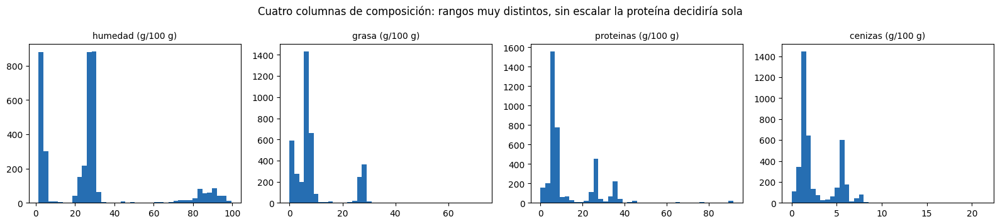

In [17]:
fig, ejes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, col in zip(ejes, COLUMNAS):
    ax.hist(muestras[col], bins=40, color=AZUL, alpha=0.85); ax.set_title(f"{col} (g/100 g)", fontsize=10)
fig.suptitle("Cuatro columnas de composición: rangos muy distintos, sin escalar la proteína decidiría sola")
plt.tight_layout(); plt.show()

##### Imputar y escalar
No hay faltantes (se pidieron los cuatro análisis), pero el imputador queda en el flujo como en la clase, para que una
muestra nueva con un hueco también se pueda ubicar. Después se **escala**: media 0 y desvío 1 por columna. `Z` es lo
que ven los algoritmos.

In [18]:
imputador = SimpleImputer(strategy="median").fit(muestras[COLUMNAS])
escalador = StandardScaler().fit(imputador.transform(muestras[COLUMNAS]))
Z = escalador.transform(imputador.transform(muestras[COLUMNAS]))
print("Desvío de cada columna antes de escalar:", {c_: round(float(muestras[c_].std()), 2) for c_ in COLUMNAS})
print(f"Z: {Z.shape[0]} muestras × {Z.shape[1]} columnas · media ≈ {Z.mean(axis=0).round(2).tolist()} · desvío ≈ {Z.std(axis=0).round(2).tolist()}")

Desvío de cada columna antes de escalar: {'humedad': 24.57, 'grasa': 8.81, 'proteinas': 13.98, 'cenizas': 2.16}
Z: 3937 muestras × 4 columnas · media ≈ [0.0, -0.0, -0.0, -0.0] · desvío ≈ [1.0, 1.0, 1.0, 1.0]


##### Quitar los outliers
Un filtro global por columna (IQR o z-score sobre todas las muestras) no sirve acá: el dulce de leche es la mayoría, y
un filtro así marcaría como «raros» a todos los polvos y líquidos, que son grupos reales. Un outlier es una muestra
rara **para su tipo de producto**. Como la familia no se puede usar (y las muestras de MQ no la tienen), el tipo sale de
un **k-medias preliminar**, con k elegido por silueta, igual que en B.1. Dentro de cada grupo se decide por **consenso**
(clase 46; `M.outliers_consenso`, probado en `prueba_mejoras_clustering.ipynb`):

1. k-medias preliminar sobre `Z`; cada muestra, a su grupo.
2. Dentro de cada grupo (de 30 muestras o más) se reescala con las muestras del grupo y se calculan tres puntajes, donde
   más bajo es más raro: el **factor local** (`LocalOutlierFactor`, 50 vecinos), el **bosque de aislamiento**
   (`IsolationForest`, 200 árboles) y la **elipse** (`EllipticEnvelope`).
3. Cada método marca el **3 %** de menor puntaje del grupo; es outlier lo que marcan **al menos 2 de los 3**.

Antes se usaba otra regla: distancia al centroide del grupo preliminar mayor que **Q3 + 1,5 · IQR** de las distancias
del grupo. Se reemplazó porque sacaba variantes legítimas del dulce de leche: el heladero (menos humedad, más cenizas)
queda lejos del centroide del DDL, y la regla IQR se llevaba casi todos. Abajo se comparan las dos reglas.

Se quitan, se vuelve a imputar y escalar con las que quedan, y **todo lo que sigue usa el conjunto sin outliers**.

k-medias preliminar con k = 5 · outliers por consenso (3 %, 2 de 3): 101 de 3937 (2.6 %) · con la regla IQR de antes serían 362 (9.2 %)


,muestras,outliers,con IQR (antes),% outliers
grupo preliminar,,,,
0,2281,55,234,2.4
1,665,21,86,3.2
2,67,1,0,1.5
3,466,12,38,2.6
4,458,12,4,2.6


Cuántas marca cada método y cuántas votos juntan: {'factor local': 119, 'bosque': 119, 'elipse': 119} · votos: {0: 3745, 1: 91, 2: 37, 3: 64}
Consenso contra la regla IQR de antes:


consenso (ahora),False,True,All
regla IQR (antes),,,
False,3562,13,3575
True,274,88,362
All,3836,101,3937


Dulces de leche especiales (por la descripción, que no entra en el agrupamiento):


,muestras,se conservan (consenso),se conservaban (IQR)
repostero,623,622,613
heladero,176,172,35
reducido en grasa,11,11,2


Outliers por origen: {'solo MQ': 57, 'Senasa': 35, 'Senasa completada con MQ': 9}
Outliers por familia: {'suero / permeado': 29, 'sin clasificar': 21, 'queso': 21, 'dulce de leche': 8, 'manteca / crema': 8, 'concentrado proteico': 4, 'yogur / bebida lactea': 3, 'arroz con leche / postre': 3, 'helado': 2, 'leche fluida': 1, 'leche en polvo': 1}
Algunos outliers (g/100 g), los de más votos:


,Identificador,desc_familia,origen,humedad,grasa,proteinas,cenizas,votos
78,MO-07984-01,yogur / bebida lactea,Senasa,3.97,9.96,11.05,4.49,3
85,MO-08051-01,suero / permeado,Senasa,1.79,0.00,2.14,5.23,3
106,MO-08308-01,yogur / bebida lactea,Senasa,3.46,11.23,11.33,4.39,3
142,MO-08545-01,suero / permeado,Senasa,2.39,0.97,14.25,0.90,3
143,MO-08545-02,suero / permeado,Senasa,2.28,0.91,14.07,0.84,3
144,MO-08545-03,suero / permeado,Senasa,2.30,1.06,13.94,0.78,3
145,MO-08545-04,suero / permeado,Senasa,2.36,1.03,13.62,0.84,3
146,MO-08545-05,suero / permeado,Senasa,2.29,1.01,13.92,0.81,3
150,MO-08633-01,suero / permeado,Senasa,2.24,1.05,13.74,0.83,3
151,MO-08633-02,suero / permeado,Senasa,2.22,0.91,13.52,0.82,3


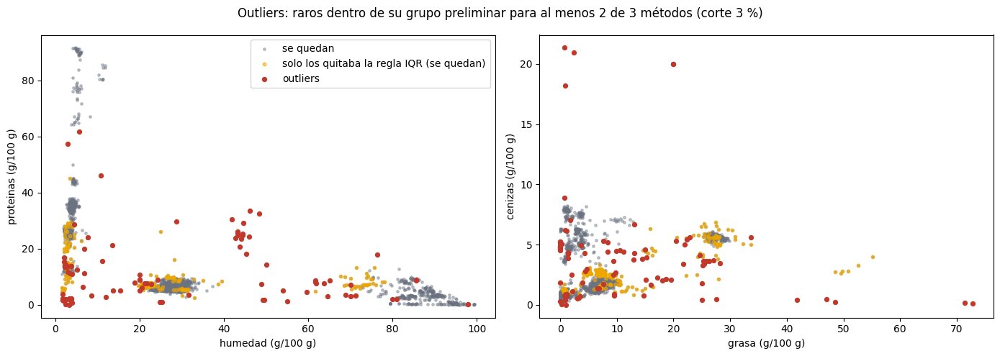

Quedan 3836 muestras · por origen: {'Senasa': 2625, 'solo MQ': 893, 'Senasa completada con MQ': 318}


In [19]:
PCT_OUTLIER = 3                       # corte de cada método (% más raro del grupo); 2 de 3 votos
X_pre, Z_pre = muestras[COLUMNAS].to_numpy(), Z          # todas las que entran, antes de quitar (para B.5)
out_iqr, grupo_pre, K_PRE = M.outliers_iqr(Z)            # k-medias preliminar (k por silueta) y la regla IQR anterior
es_outlier, votos = M.outliers_consenso(X_pre, grupo_pre, pct=PCT_OUTLIER, minimo=2, n_vecinos=50)
ref = M.agregar_subtipo(muestras, S)                     # subtipo conocido y descripciones: NO entran, solo para comparar
muestras["subtipo_ref"] = ref["subtipo_ref"].to_numpy()
especiales = M.especiales_ddl(ref)                       # DDL repostero, heladero, reducido en grasa (por la descripción)

resumen = pd.DataFrame({"grupo preliminar": grupo_pre, "outlier": es_outlier, "regla IQR (antes)": out_iqr})
print(f"k-medias preliminar con k = {K_PRE} · outliers por consenso ({PCT_OUTLIER} %, 2 de 3): {int(es_outlier.sum())} de {len(Z)} "
      f"({100 * es_outlier.mean():.1f} %) · con la regla IQR de antes serían {int(out_iqr.sum())} ({100 * out_iqr.mean():.1f} %)")
display(resumen.groupby("grupo preliminar").agg(muestras=("outlier", "size"), outliers=("outlier", "sum"),
                                                **{"con IQR (antes)": ("regla IQR (antes)", "sum")}).assign(
    **{"% outliers": lambda t: (100 * t["outliers"] / t["muestras"]).round(1)}))
print("Cuántas marca cada método y cuántas votos juntan:", votos[["factor local", "bosque", "elipse"]].sum().to_dict(),
      "· votos:", votos["votos"].value_counts().sort_index().to_dict())
print("Consenso contra la regla IQR de antes:")
display(pd.crosstab(pd.Series(out_iqr, name="regla IQR (antes)"), pd.Series(es_outlier, name="consenso (ahora)"), margins=True))
conservados = pd.DataFrame({n: {"muestras": int(especiales[n].sum()), "se conservan (consenso)": int((especiales[n] & ~es_outlier).sum()),
                                "se conservaban (IQR)": int((especiales[n] & ~out_iqr).sum())} for n in especiales.columns}).T
print("Dulces de leche especiales (por la descripción, que no entra en el agrupamiento):"); display(conservados)
print("Outliers por origen:", muestras.loc[es_outlier, "origen"].value_counts().to_dict())
print("Outliers por familia:", muestras.loc[es_outlier, "desc_familia"].value_counts().to_dict())
print("Algunos outliers (g/100 g), los de más votos:")
display(muestras.loc[es_outlier, ["Identificador", "desc_familia", "origen"] + COLUMNAS].assign(votos=votos.loc[es_outlier, "votos"].to_numpy())
        .sort_values("votos", ascending=False).head(12))

fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5))
for ax, (x, y) in [(a, ("humedad", "proteinas")), (b, ("grasa", "cenizas"))]:
    ax.scatter(muestras.loc[~es_outlier, x], muestras.loc[~es_outlier, y], s=6, alpha=0.4, color=GRIS, label="se quedan")
    solo_iqr = out_iqr & ~es_outlier
    ax.scatter(muestras.loc[solo_iqr, x], muestras.loc[solo_iqr, y], s=10, color=AMBAR, alpha=0.6, label="solo los quitaba la regla IQR (se quedan)")
    ax.scatter(muestras.loc[es_outlier, x], muestras.loc[es_outlier, y], s=18, color=ROJO, label="outliers")
    ax.set_xlabel(f"{x} (g/100 g)"); ax.set_ylabel(f"{y} (g/100 g)")
a.legend()
fig.suptitle(f"Outliers: raros dentro de su grupo preliminar para al menos 2 de 3 métodos (corte {PCT_OUTLIER} %)")
plt.tight_layout(); plt.show()

# se guardan todas (con la marca de outlier) para el csv del final; desde acá, sin outliers
muestras_pre = muestras.assign(outlier=es_outlier)
muestras = muestras[~es_outlier].reset_index(drop=True)
familia = muestras["desc_familia"]; conocida = (familia != SIN_FAMILIA).values
imputador = SimpleImputer(strategy="median").fit(muestras[COLUMNAS])
escalador = StandardScaler().fit(imputador.transform(muestras[COLUMNAS]))
Z = escalador.transform(imputador.transform(muestras[COLUMNAS]))
print(f"Quedan {len(muestras)} muestras · por origen: {muestras['origen'].value_counts().to_dict()}")

#### A · Centroides: k-medias y k-means++
##### A.1 · Asignar y mover, a mano
El algoritmo de la clase en cuatro líneas, sobre dos columnas (humedad y proteínas, escaladas) para poder dibujarlo:
k centroides iniciales; cada muestra al centroide más cercano; cada centroide a la media de su grupo; se repite. Los
centroides arrancan a propósito en las muestras de menor humedad, para ver cómo se mueven. La inercia baja en cada paso.

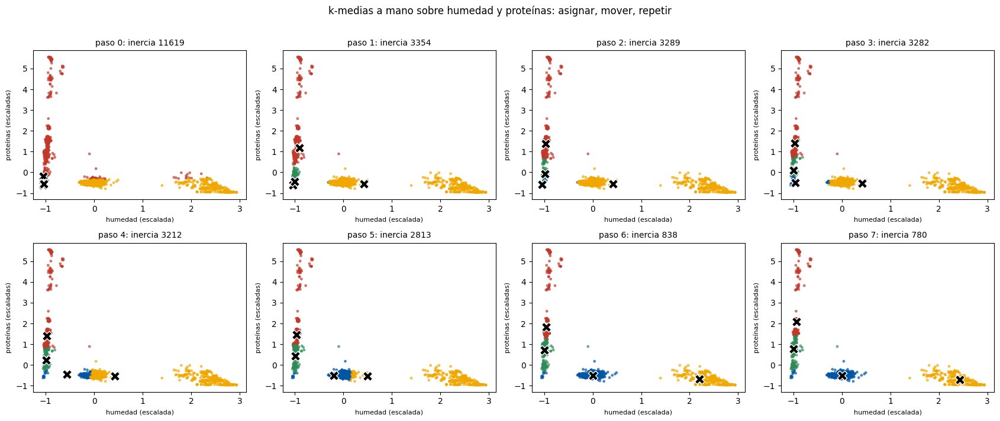

In [20]:
i_h, i_p = COLUMNAS.index("humedad"), COLUMNAS.index("proteinas")
dos = Z[:, [i_h, i_p]]

def asignar(X, centroides):
    return np.argmin(np.linalg.norm(X[:, None, :] - centroides[None, :, :], axis=2), axis=1)
def mover(X, etiquetas, k, anteriores):
    return np.array([X[etiquetas == j].mean(axis=0) if (etiquetas == j).any() else anteriores[j] for j in range(k)])
def inercia(X, centroides, etiquetas):
    return float(np.sum((X - centroides[etiquetas]) ** 2))

k = 4
centroides = dos[np.argsort(dos[:, 0])[:k]]                 # todos en la humedad más baja, a propósito
fig, ejes = plt.subplots(2, 4, figsize=(17, 7)); ejes = ejes.ravel()
for paso in range(8):
    etiquetas = asignar(dos, centroides)
    ax = ejes[paso]; ax.scatter(dos[:, 0], dos[:, 1], c=[COLORES[e] for e in etiquetas], s=6, alpha=0.6)
    ax.scatter(centroides[:, 0], centroides[:, 1], marker="X", s=140, c="black", edgecolor="white", zorder=5)
    ax.set_title(f"paso {paso}: inercia {inercia(dos, centroides, etiquetas):.0f}", fontsize=10)
    ax.set_xlabel("humedad (escalada)", fontsize=8); ax.set_ylabel("proteínas (escaladas)", fontsize=8)
    nuevos = mover(dos, etiquetas, k, centroides)
    if np.allclose(nuevos, centroides):
        for ax_ in ejes[paso + 1:]: ax_.axis("off")
        break
    centroides = nuevos
fig.suptitle("k-medias a mano sobre humedad y proteínas: asignar, mover, repetir", y=1.01)
plt.tight_layout(); plt.show()

##### A.2 · Converge, pero adónde: inicialización al azar contra k-means++
Cuarenta corridas de `KMeans(init="random", n_init=1)` y cuarenta con `init="k-means++"` sobre las cuatro columnas,
con k = 4: dónde termina cada una. Por eso la biblioteca corre `n_init` veces y se queda con la menor inercia, y por eso
k-means++ (centroides iniciales elegidos con probabilidad proporcional a D(x)²) es el defecto.

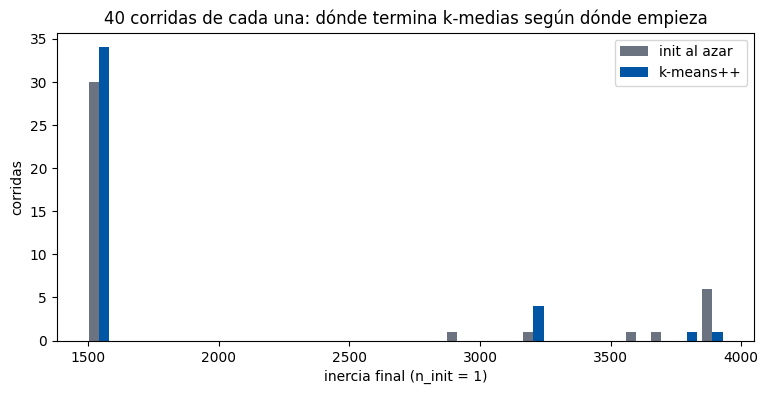

Al azar: inercia entre 1492 y 3939 · 10 de 40 terminan más de 1 % arriba de la mejor
k-means++: inercia entre 1492 y 3865 · 6 de 40 terminan más de 1 % arriba de la mejor


In [21]:
in_azar = np.array([KMeans(n_clusters=4, init="random", n_init=1, random_state=s).fit(Z).inertia_ for s in range(40)])
in_pp = np.array([KMeans(n_clusters=4, init="k-means++", n_init=1, random_state=s).fit(Z).inertia_ for s in range(40)])
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist([in_azar, in_pp], bins=25, color=[GRIS, AZUL], label=["init al azar", "k-means++"])
ax.set_xlabel("inercia final (n_init = 1)"); ax.set_ylabel("corridas"); ax.legend()
ax.set_title("40 corridas de cada una: dónde termina k-medias según dónde empieza")
plt.show()
mejor = min(in_azar.min(), in_pp.min())
print(f"Al azar: inercia entre {in_azar.min():.0f} y {in_azar.max():.0f} · {int((in_azar > mejor * 1.01).sum())} de 40 terminan más de 1 % arriba de la mejor")
print(f"k-means++: inercia entre {in_pp.min():.0f} y {in_pp.max():.0f} · {int((in_pp > mejor * 1.01).sum())} de 40 terminan más de 1 % arriba de la mejor")

#### B · Cuántos grupos
##### B.1 · El codo y la silueta
Para k de 2 a 10: la **inercia** (baja siempre; se busca el codo) y la **silueta** promedio, (b − a)/max(a, b). Criterio
fijado antes de mirar: **k con la silueta máxima**.

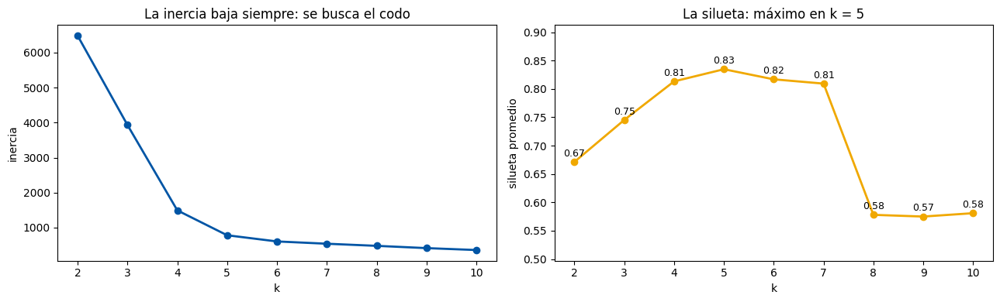

Inercia por k: {2: 6482, 3: 3930, 4: 1492, 5: 781, 6: 604, 7: 539, 8: 478, 9: 414, 10: 359}
Silueta por k: {2: 0.671, 3: 0.745, 4: 0.813, 5: 0.835, 6: 0.817, 7: 0.809, 8: 0.578, 9: 0.575, 10: 0.581}
Se elige k = 5.


In [22]:
ks = list(range(2, 11))
modelos = {k_: KMeans(n_clusters=k_, n_init=N_INIT_KMEDIAS, random_state=SEMILLA).fit(Z) for k_ in ks}
inercias = [modelos[k_].inertia_ for k_ in ks]; siluetas = [silhouette_score(Z, modelos[k_].labels_) for k_ in ks]
K = ks[int(np.argmax(siluetas))]
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4))
a.plot(ks, inercias, marker="o", color=AZUL, lw=2); a.set_xlabel("k"); a.set_ylabel("inercia"); a.set_title("La inercia baja siempre: se busca el codo")
b.plot(ks, siluetas, marker="o", color=AMBAR, lw=2); b.set_xlabel("k"); b.set_ylabel("silueta promedio"); b.set_title(f"La silueta: máximo en k = {K}")
for k_, s_ in zip(ks, siluetas): b.text(k_, s_ + 0.01, f"{s_:.2f}", ha="center", fontsize=9)
b.margins(y=0.3); plt.tight_layout(); plt.show()
print("Inercia por k:", {k_: round(float(v)) for k_, v in zip(ks, inercias)})
print("Silueta por k:", {k_: round(float(s_), 3) for k_, s_ in zip(ks, siluetas)})
print(f"Se elige k = {K}.")

**Lectura.** A diferencia de los socios del gimnasio (silueta 0,17 a 0,21, estructura débil), acá la silueta es alta
(0,81 o más de k = 4 a 7, ya sin outliers): hay grupos de verdad, porque los productos tienen composiciones muy
distintas. Con solo Senasa también sale k = 5 (ver la sección 3); al sumar MQ entran líquidos (leche fluida, suero), que
forman un grupo propio, y la silueta es máxima en **k = 5** (0,835). Sin los quesos, que van a su rama, ya no hay un grupo
entre el dulce de leche y los polvos (en una versión anterior, con los quesos adentro, el k había sido 6, con un grupo QUESO
de 87 muestras). La curva es casi
plana entre 4 y 7 (0,81 a 0,83) y cae a 0,58 con k = 8, así que k = 5 es una elección por criterio, no una verdad. Ojo: el
dulce de leche es más de la mitad de las muestras y forma una nube muy compacta, lo que infla el promedio de la silueta. El
diagrama de B.2 lo muestra grupo por grupo, y B.5 da las métricas que no dependen del tamaño de cada grupo.

##### B.2 · El modelo elegido, sus tags y su diagrama de silueta
Los centroides se devuelven a g/100 g para leerlos. Cada grupo recibe un **tag** con las reglas sobre su centroide
(`etiquetar` en `datos_clase41.py`): humedad > 70 → LIQUIDO; entre 35 y 65 con grasa > 15 → QUESO (se evalúa antes que alta humedad); > 50 → ALTA_HUMEDAD; > 15 → DDL;
si no es un polvo: proteína > 70 → PROT_ALTA; grasa > 15 → POLVO_GRASO; si no, POLVO_MAGRO. El número de cluster cambia
entre corridas; el tag no. Si dos grupos caen en la misma regla se desambiguan con `_2`, `_3`, ordenados por humedad.
El diagrama: un coeficiente por muestra, ordenados por grupo; la altura es cuántas muestras tiene, el ancho qué tan adentro
están, la línea roja el promedio.

Centroides en g/100 g:


,tag,muestras,humedad,grasa,proteinas,cenizas
cluster,,,,,,
0,DDL,2226,27.63,6.96,6.47,1.58
1,POLVO_GRASO,644,2.88,27.42,25.32,5.58
2,POLVO_MAGRO,446,3.84,3.01,32.36,6.12
3,LIQUIDO,454,86.88,1.46,3.69,0.79
4,PROT_ALTA,66,6.07,2.64,81.00,4.60


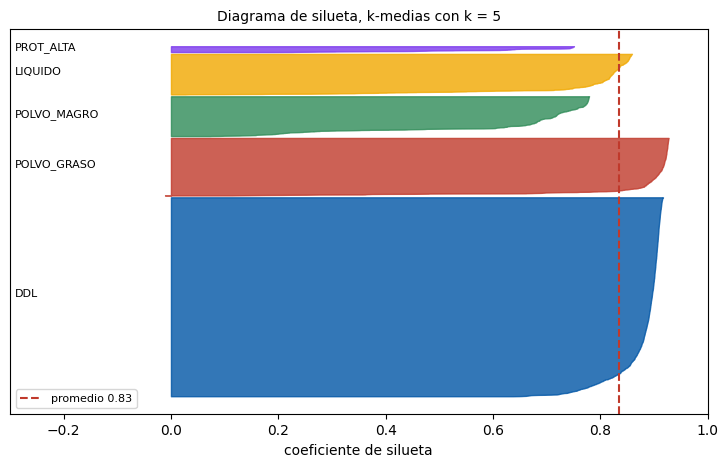

Silueta media por tag: {'DDL': 0.88, 'LIQUIDO': 0.78, 'POLVO_GRASO': 0.88, 'POLVO_MAGRO': 0.63, 'PROT_ALTA': 0.6}
Muestras con coeficiente negativo: 1 de 3836


In [23]:
km = modelos[K]; grupos = km.labels_
centros = pd.DataFrame(escalador.inverse_transform(km.cluster_centers_), columns=COLUMNAS, index=range(K)).round(2)
nombres, tags, repetidos = etiquetar(centros)
if repetidos:
    print(f"AVISO: más de un grupo cae en {repetidos}; se desambiguan con sufijo _2, _3 (por humedad del centroide).")
tag_de = np.array([tags[g] for g in grupos])
centros.insert(0, "muestras", np.bincount(grupos)); centros.insert(0, "tag", [tags[j] for j in range(K)])
centros.index.name = "cluster"
print("Centroides en g/100 g:"); display(centros)

def diagrama_silueta(ax, X, etiquetas, titulo, rotulos):
    valores = silhouette_samples(X, etiquetas); y0 = 10
    for j in range(etiquetas.max() + 1):
        v = np.sort(valores[etiquetas == j]); ax.fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, color=COLORES[j], alpha=0.8)
        ax.text(-0.29, y0 + len(v) / 2, rotulos[j], fontsize=8); y0 += len(v) + 20
    ax.axvline(valores.mean(), color=ROJO, ls="--", label=f"promedio {valores.mean():.2f}")
    ax.set_xlim(-0.3, 1); ax.set_yticks([]); ax.set_xlabel("coeficiente de silueta"); ax.legend(fontsize=8); ax.set_title(titulo, fontsize=10)
    return valores

fig, ax = plt.subplots(figsize=(9, 5))
coef = diagrama_silueta(ax, Z, grupos, f"Diagrama de silueta, k-medias con k = {K}", tags)
plt.show()
print("Silueta media por tag:", pd.Series(coef).groupby(tag_de).mean().round(2).to_dict())
print(f"Muestras con coeficiente negativo: {int((coef < 0).sum())} de {len(Z)}")

##### B.5 · Métricas sin el sesgo del grupo más grande
La silueta promedio pesa cada **muestra** igual, así que la domina el DDL, que es la mayoría y forma una nube compacta.
Junto a ella (clase 43, `M.metricas`): la **silueta macro** (el promedio de las siluetas medias de cada grupo: cada
**grupo** pesa igual), la del **peor grupo**, **Davies-Bouldin** (cuánto se pisan los grupos con su vecino más
parecido; menor es mejor) y **Calinski-Harabasz** (dispersión entre grupos sobre dispersión dentro; mayor es mejor).

Para comparar el filtro de outliers nuevo con el de antes no alcanza con la silueta de cada uno sobre sus propias
muestras: el que quita más saca justo lo que está entre grupos y sale favorecido. Por eso se rehace el k-medias final
con cada filtro (`M.variante`) y se mide también sobre las **muestras comunes** (las que no quita ninguno de los dos), en
la misma escala.

In [24]:
print("Métricas del modelo elegido (sus muestras):")
display(pd.DataFrame([M.metricas(Z, grupos)]).round(3))
comunes = ~(out_iqr | es_outlier)
filtros = {}
for nombre_f, quita in [("regla IQR (antes)", out_iqr), (f"consenso {PCT_OUTLIER} % (ahora)", es_outlier)]:
    r_f, filtros[nombre_f], _ = M.variante(X_pre, quita, Z_pre, comunes)
    for e in especiales.columns:
        filtros[nombre_f][f"conserva {e}"] = int((especiales[e].to_numpy() & ~quita).sum())
assert r_f["K"] == K and (r_f["tag_de"] == tag_de).all()     # el k-medias de M.variante es el mismo de B.2
comparacion_filtros = pd.DataFrame(filtros).T.infer_objects()
print(f"Los dos filtros, cada uno con su k-medias final · muestras comunes: {int(comunes.sum())}")
display(comparacion_filtros.style.format(precision=3).format({"% quitado": "{:.1f}", "Calinski-Harabasz": "{:.0f}"}))

Métricas del modelo elegido (sus muestras):


,grupos,ruido,silueta global,silueta macro,peor grupo,Davies-Bouldin,Calinski-Harabasz
0,5,0,0.835,0.754,0.596,0.371,17860.286


Los dos filtros, cada uno con su k-medias final · muestras comunes: 3562


,% quitado,muestras,k,tags,silueta global,silueta macro,peor grupo,Davies-Bouldin,Calinski-Harabasz,silueta global (todas),silueta macro (todas),silueta global (comunes),silueta macro (comunes),Davies-Bouldin (comunes),conserva repostero,conserva heladero,conserva reducido en grasa
regla IQR (antes),9.2,3575,5,DDL LIQUIDO POLVO_GRASO POLVO_MAGRO PROT_ALTA,0.861806,0.779391,0.584806,0.360833,23252,0.808864,0.731923,0.864367,0.784430,0.349663,613,35,2
consenso 3 % (ahora),2.6,3836,5,DDL LIQUIDO POLVO_GRASO POLVO_MAGRO PROT_ALTA,0.834644,0.753618,0.596164,0.371020,17860,0.808770,0.731274,0.864367,0.784430,0.349663,622,172,11


##### B.3 · Más rápido: Elkan y minilotes
Las dos variantes de la clase: `algorithm="elkan"` (usa la desigualdad triangular para calcular menos distancias) y
`MiniBatchKMeans` (lotes en vez de todo el conjunto). Con unas pocas miles de muestras y cuatro columnas, todo tarda
milisegundos; lo que importa es si la inercia empeora y si los grupos cambian.

In [25]:
filas = []
for nombre, modelo in [("k-medias (lloyd)", KMeans(n_clusters=K, n_init=N_INIT_KMEDIAS, algorithm="lloyd", random_state=SEMILLA)),
                       ("k-medias (elkan)", KMeans(n_clusters=K, n_init=N_INIT_KMEDIAS, algorithm="elkan", random_state=SEMILLA)),
                       ("minilotes (256)", MiniBatchKMeans(n_clusters=K, n_init=N_INIT_KMEDIAS, batch_size=256, random_state=SEMILLA))]:
    t0 = time.perf_counter(); modelo.fit(Z); ms = (time.perf_counter() - t0) * 1000
    filas.append({"variante": nombre, "ms": ms, "inercia": modelo.inertia_, "silueta": silhouette_score(Z, modelo.labels_),
                  "Rand ajustado contra k-medias": adjusted_rand_score(grupos, modelo.labels_)})
display(pd.DataFrame(filas).round(3))

,variante,ms,inercia,silueta,Rand ajustado contra k-medias
0,k-medias (lloyd),32.730,780.938,0.835,1.0
1,k-medias (elkan),54.615,780.938,0.835,1.0
2,minilotes (256),65.736,787.397,0.835,1.0


##### B.4 · Sin escalar
El mismo k-medias sobre las columnas en g/100 g. La proteína y la humedad (los desvíos más grandes) dominan la
distancia; las cenizas casi no cuentan. En los socios del gimnasio esto cambiaba todo (la cuota decidía sola). Acá los
grupos están tan separados en humedad y proteína que la partición cambia poco: se mide con el Rand ajustado.

In [26]:
X_crudo = imputador.transform(muestras[COLUMNAS])
km_crudo = KMeans(n_clusters=K, n_init=N_INIT_KMEDIAS, random_state=SEMILLA).fit(X_crudo)
print(f"Rand ajustado entre sin escalar y escalado: {adjusted_rand_score(grupos, km_crudo.labels_):.2f}")
print("Sin escalar contra escalado (tag):"); display(pd.crosstab(pd.Series(km_crudo.labels_, name="sin escalar"), pd.Series(tag_de, name="escalado")))
print("Centroides sin escalar (g/100 g):"); display(pd.DataFrame(km_crudo.cluster_centers_, columns=COLUMNAS).round(2))

Rand ajustado entre sin escalar y escalado: 1.00
Sin escalar contra escalado (tag):


escalado,DDL,LIQUIDO,POLVO_GRASO,POLVO_MAGRO,PROT_ALTA
sin escalar,,,,,
0,2226,0,0,0,0
1,0,454,0,0,0
2,0,0,644,0,0
3,0,0,0,446,0
4,0,0,0,0,66


Centroides sin escalar (g/100 g):


,humedad,grasa,proteinas,cenizas
0,27.63,6.96,6.47,1.58
1,86.88,1.46,3.69,0.79
2,2.88,27.42,25.32,5.58
3,3.84,3.01,32.36,6.12
4,6.07,2.64,81.00,4.60


#### C · Fusionar: el aglomerativo
##### C.1 · Ward
`AgglomerativeClustering(n_clusters=K, linkage="ward")`: cada muestra empieza sola y se fusionan de a dos las que menos
aumentan la varianza, hasta que quedan K. Se compara con k-medias: tamaños, tabla cruzada, Rand ajustado, silueta.

In [27]:
ward = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(Z)
print(f"Ward: tamaños {np.bincount(ward.labels_).tolist()} · silueta {silhouette_score(Z, ward.labels_):.3f} "
      f"(k-medias {silhouette_score(Z, grupos):.3f}) · Rand ajustado contra k-medias {adjusted_rand_score(grupos, ward.labels_):.2f}")
display(pd.crosstab(pd.Series(ward.labels_, name="Ward"), pd.Series(tag_de, name="k-medias (tag)")))

Ward: tamaños [446, 2226, 644, 454, 66] · silueta 0.835 (k-medias 0.835) · Rand ajustado contra k-medias 1.00


k-medias (tag),DDL,LIQUIDO,POLVO_GRASO,POLVO_MAGRO,PROT_ALTA
Ward,,,,,
0,0,0,0,446,0
1,2226,0,0,0,0
2,0,0,644,0,0
3,0,454,0,0,0
4,0,0,0,0,66


##### C.2 · Los enlaces y las métricas
Simple, completo y promedio, con distancia euclidiana, Manhattan y coseno (Ward solo admite la euclidiana). El enlace
decide qué es «cercano» entre dos grupos; el simple encadena vecino a vecino y suele dejar un grupo gigante. La silueta
se calcula con la misma métrica, así que no es comparable entre métricas.

In [28]:
filas = []
for enlace in ["single", "complete", "average"]:
    for metrica in ["euclidean", "manhattan", "cosine"]:
        et = AgglomerativeClustering(n_clusters=K, linkage=enlace, metric=metrica).fit_predict(Z)
        filas.append({"enlace": enlace, "métrica": metrica, "tamaños": sorted(np.bincount(et).tolist(), reverse=True),
                      "silueta (misma métrica)": silhouette_score(Z, et, metric=metrica),
                      "Rand ajustado contra k-medias": adjusted_rand_score(grupos, et)})
filas.append({"enlace": "ward", "métrica": "euclidean", "tamaños": sorted(np.bincount(ward.labels_).tolist(), reverse=True),
              "silueta (misma métrica)": silhouette_score(Z, ward.labels_), "Rand ajustado contra k-medias": adjusted_rand_score(grupos, ward.labels_)})
display(pd.DataFrame(filas).round(3))

,enlace,métrica,tamaños,silueta (misma métrica),Rand ajustado contra k-medias
0,single,euclidean,"[2680, 1149, 5, 1, 1]",0.535,0.639
1,single,manhattan,"[2680, 1084, 66, 5, 1]",0.717,0.657
2,single,cosine,"[2679, 1085, 66, 5, 1]",0.297,0.643
3,complete,euclidean,"[2680, 630, 454, 66, 6]",0.748,0.725
4,complete,manhattan,"[2680, 630, 454, 66, 6]",0.772,0.725
5,complete,cosine,"[2226, 644, 454, 446, 66]",0.879,1.000
6,average,euclidean,"[2680, 637, 447, 66, 6]",0.750,0.727
7,average,manhattan,"[2680, 630, 454, 66, 6]",0.772,0.725
8,average,cosine,"[2226, 643, 454, 447, 66]",0.881,0.985
9,ward,euclidean,"[2226, 644, 454, 446, 66]",0.835,1.000


##### C.3 · El dendrograma
Con miles de muestras el árbol no se lee. Se toman 40 al azar **estratificadas por grupo de k-medias** (para que
aparezcan los grupos chicos) y se dibuja el dendrograma de Ward: la altura de cada unión es la distancia a la que se
fusionaron; se corta donde la rama vertical es más larga. Las hojas llevan el tag de k-medias y la familia, que el
algoritmo no vio.

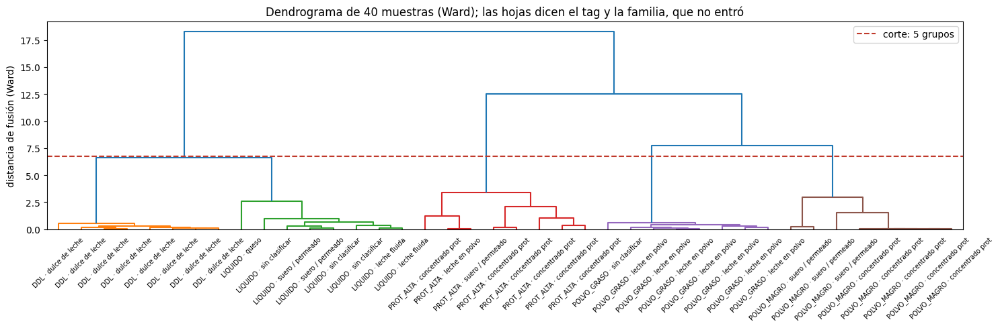

Últimas cinco fusiones a distancias [3.4, 6.6, 7.7, 12.5, 18.3] · el salto más grande deja 2 grupos


In [29]:
from scipy.cluster.hierarchy import linkage, dendrogram
rng = np.random.default_rng(SEMILLA)
por_grupo = max(2, 40 // K)
muestra = np.concatenate([rng.choice(np.where(grupos == j)[0], min(por_grupo, int((grupos == j).sum())), replace=False) for j in range(K)])
enlaces = linkage(Z[muestra], method="ward")
fig, ax = plt.subplots(figsize=(15, 5))
dendrogram(enlaces, labels=[f"{tag_de[i]} · {familia[i][:16]}" for i in muestra], leaf_font_size=7, color_threshold=enlaces[-(K - 1), 2], ax=ax)
ax.axhline(enlaces[-(K - 1), 2] * 1.02, color=ROJO, ls="--", label=f"corte: {K} grupos"); ax.set_ylabel("distancia de fusión (Ward)"); ax.legend()
ax.set_title(f"Dendrograma de {len(muestra)} muestras (Ward); las hojas dicen el tag y la familia, que no entró")
plt.tight_layout(); plt.show()
saltos = np.diff(enlaces[:, 2]); k_sugerido = len(enlaces) + 1 - (int(np.argmax(saltos)) + 1)
print(f"Últimas cinco fusiones a distancias {enlaces[-5:, 2].round(1).tolist()} · el salto más grande deja {k_sugerido} grupos")

#### D · Dividir: k-medias bisectivo
`BisectingKMeans`: parte un grupo en dos, y otra vez, hasta K. Las dos estrategias para elegir qué grupo partir: el más
grande o el de mayor inercia. Primero se ven las divisiones sucesivas sobre humedad y proteínas.

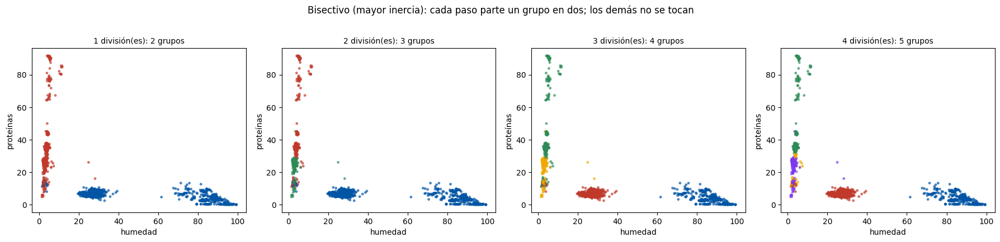

,estrategia,tamaños,inercia,silueta,Rand ajustado contra k-medias
0,largest_cluster,"[454, 182, 1258, 824, 1118]",3840.415,0.424,0.486
1,biggest_inertia,"[454, 2264, 428, 47, 643]",1371.167,0.772,0.960
2,k-medias (referencia),"[2226, 644, 446, 454, 66]",780.938,0.835,1.000


In [30]:
fig, ejes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, kb in zip(ejes, [2, 3, 4, 5]):
    bk = BisectingKMeans(n_clusters=kb, bisecting_strategy="biggest_inertia", random_state=SEMILLA).fit(Z)
    ax.scatter(muestras["humedad"], muestras["proteinas"], c=[COLORES[e] for e in bk.labels_], s=6, alpha=0.6)
    ax.set_title(f"{kb - 1} división(es): {kb} grupos", fontsize=10); ax.set_xlabel("humedad"); ax.set_ylabel("proteínas")
fig.suptitle("Bisectivo (mayor inercia): cada paso parte un grupo en dos; los demás no se tocan", y=1.02)
plt.tight_layout(); plt.show()
filas = []
for estrategia in ["largest_cluster", "biggest_inertia"]:
    bk = BisectingKMeans(n_clusters=K, bisecting_strategy=estrategia, random_state=SEMILLA).fit(Z)
    filas.append({"estrategia": estrategia, "tamaños": np.bincount(bk.labels_).tolist(), "inercia": bk.inertia_,
                  "silueta": silhouette_score(Z, bk.labels_), "Rand ajustado contra k-medias": adjusted_rand_score(grupos, bk.labels_)})
filas.append({"estrategia": "k-medias (referencia)", "tamaños": np.bincount(grupos).tolist(), "inercia": km.inertia_,
              "silueta": silhouette_score(Z, grupos), "Rand ajustado contra k-medias": 1.0})
display(pd.DataFrame(filas).round(3))

#### E · El comparativo: cuál para qué
Los cuatro algoritmos con K grupos: silueta, inercia, tiempo, tamaños y coincidencia con k-medias. Y, recién ahora,
la **familia** (que ninguno vio): Rand ajustado contra la familia.

,algoritmo,silueta,inercia,ms,tamaños,Rand ajustado contra k-medias,Rand ajustado contra la familia (conocida)
0,k-medias,0.835,780.938,36.295,"[2226, 644, 454, 446, 66]",1.00,0.921
1,minilotes,0.835,781.261,50.977,"[2226, 644, 454, 446, 66]",1.00,0.921
2,aglomerativo (Ward),0.835,NaN,123.036,"[2226, 644, 454, 446, 66]",1.00,0.921
3,bisectivo,0.772,1371.167,4.573,"[2264, 643, 454, 428, 47]",0.96,0.908


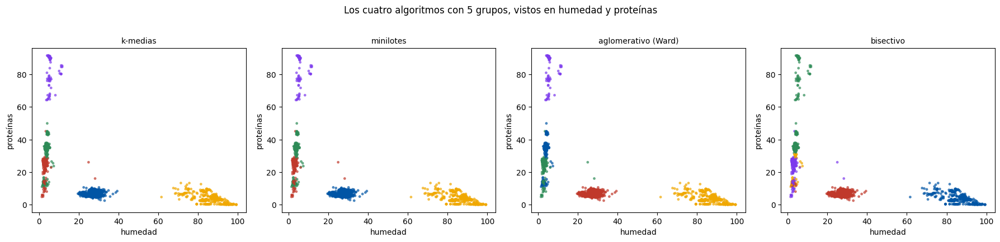

In [31]:
filas, particiones = [], {}
for nombre, modelo in [("k-medias", KMeans(n_clusters=K, n_init=N_INIT_KMEDIAS, random_state=SEMILLA)),
                       ("minilotes", MiniBatchKMeans(n_clusters=K, n_init=N_INIT_KMEDIAS, random_state=SEMILLA)),
                       ("aglomerativo (Ward)", AgglomerativeClustering(n_clusters=K, linkage="ward")),
                       ("bisectivo", BisectingKMeans(n_clusters=K, bisecting_strategy="biggest_inertia", random_state=SEMILLA))]:
    t0 = time.perf_counter(); et = modelo.fit_predict(Z); ms = (time.perf_counter() - t0) * 1000
    particiones[nombre] = et
    filas.append({"algoritmo": nombre, "silueta": silhouette_score(Z, et), "inercia": getattr(modelo, "inertia_", np.nan), "ms": ms,
                  "tamaños": sorted(np.bincount(et).tolist(), reverse=True), "Rand ajustado contra k-medias": adjusted_rand_score(grupos, et),
                  "Rand ajustado contra la familia (conocida)": adjusted_rand_score(familia[conocida], et[conocida])})
display(pd.DataFrame(filas).round(3))

fig, ejes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (nombre, et) in zip(ejes, particiones.items()):
    ax.scatter(muestras["humedad"], muestras["proteinas"], c=[COLORES[e] for e in et], s=6, alpha=0.6)
    ax.set_title(nombre, fontsize=10); ax.set_xlabel("humedad"); ax.set_ylabel("proteínas")
fig.suptitle(f"Los cuatro algoritmos con {K} grupos, vistos en humedad y proteínas", y=1.02)
plt.tight_layout(); plt.show()

#### F · Usarlo
##### Qué es cada grupo: cluster → tag → nombre → centroide → familia mayoritaria
El centroide en g/100 g, cuántas muestras, la familia más común y la tabla cruzada con la familia. El tag y el nombre
salen de las reglas sobre el centroide (B.2), no de la familia.

,tag,nombre,muestras,humedad,grasa,proteinas,cenizas,silueta media,familia mayoritaria,% de esa familia,% solo MQ
cluster,,,,,,,,,,,
0,DDL,pastoso tipo dulce de leche,2226,27.63,6.96,6.47,1.58,0.88,dulce de leche,100,3
1,POLVO_GRASO,polvo graso (tipo leche entera),644,2.88,27.42,25.32,5.58,0.88,leche en polvo,93,79
2,POLVO_MAGRO,polvo magro (suero / concentrado),446,3.84,3.01,32.36,6.12,0.63,concentrado proteico,65,17
3,LIQUIDO,líquido (leche fluida / suero),454,86.88,1.46,3.69,0.79,0.78,leche fluida,32,50
4,PROT_ALTA,polvo de proteína muy alta,66,6.07,2.64,81.00,4.60,0.60,concentrado proteico,88,14


desc_familia,dulce de leche,leche en polvo,concentrado proteico,suero / permeado,leche fluida,yogur / bebida lactea,sin clasificar,queso,arroz con leche / postre,helado
tag,,,,,,,,,,
DDL,2220,0,0,0,2,0,3,0,0,1
LIQUIDO,5,1,38,144,145,88,7,22,3,1
POLVO_GRASO,0,600,1,13,0,7,23,0,0,0
POLVO_MAGRO,0,74,289,79,0,0,3,1,0,0
PROT_ALTA,0,5,58,3,0,0,0,0,0,0


Grupos contra el origen del dato:


origen,Senasa,Senasa completada con MQ,solo MQ
tag,,,
DDL,2149,4,73
LIQUIDO,9,217,228
POLVO_GRASO,89,47,508
POLVO_MAGRO,329,42,75
PROT_ALTA,49,8,9


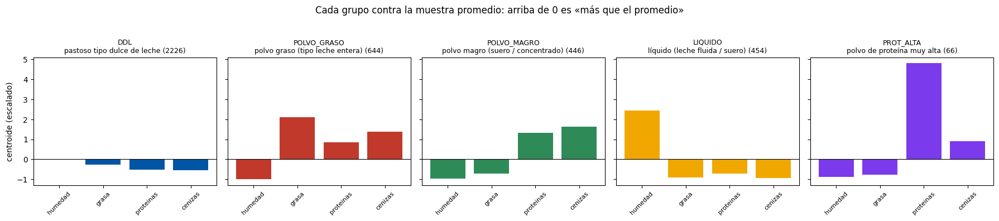

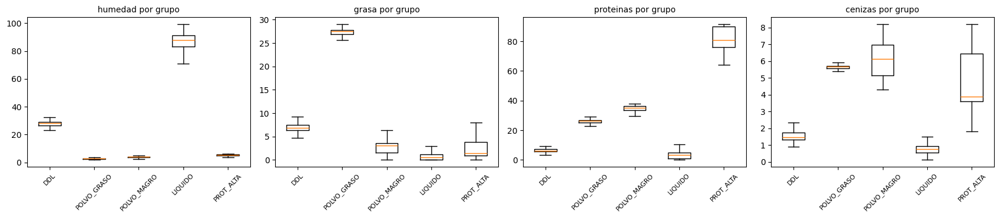

In [32]:
descripcion = centros.copy(); descripcion.insert(1, "nombre", [nombres[j] for j in range(K)])
descripcion["silueta media"] = [round(float(coef[grupos == j].mean()), 2) for j in range(K)]
fam_c = familia[conocida]; gr_c = grupos[conocida]
descripcion["familia mayoritaria"] = [fam_c[gr_c == j].mode()[0] if (gr_c == j).any() else "-" for j in range(K)]
descripcion["% de esa familia"] = [round(100 * (fam_c[gr_c == j] == fam_c[gr_c == j].mode()[0]).mean()) if (gr_c == j).any() else 0 for j in range(K)]
descripcion["% solo MQ"] = [round(100 * (muestras.loc[grupos == j, "origen"] == "solo MQ").mean()) for j in range(K)]
display(descripcion)
tabla = pd.crosstab(pd.Series(tag_de, name="tag"), familia)
display(tabla.loc[:, tabla.sum().sort_values(ascending=False).index])
print("Grupos contra el origen del dato:"); display(pd.crosstab(pd.Series(tag_de, name="tag"), muestras["origen"]))

fig, ejes = plt.subplots(1, K, figsize=(3.6 * K, 3.8), sharey=True)
for j, ax in enumerate(np.atleast_1d(ejes)):
    ax.bar(COLUMNAS, km.cluster_centers_[j], color=COLORES[j]); ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"{tags[j]}\n{nombres[j]} ({np.bincount(grupos)[j]})", fontsize=9); ax.tick_params(axis="x", rotation=45, labelsize=8)
np.atleast_1d(ejes)[0].set_ylabel("centroide (escalado)")
fig.suptitle("Cada grupo contra la muestra promedio: arriba de 0 es «más que el promedio»", y=1.03)
plt.tight_layout(); plt.show()

fig, ejes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, col in zip(ejes, COLUMNAS):
    ax.boxplot([muestras.loc[grupos == j, col] for j in range(K)], tick_labels=[tags[j] for j in range(K)], showfliers=False)
    ax.set_title(f"{col} por grupo", fontsize=10); ax.tick_params(axis="x", rotation=45, labelsize=8)
plt.tight_layout(); plt.show()

##### Los grupos en dos pares de columnas
Todas las muestras con el color de su grupo (calculado con las cuatro columnas) y su tag.

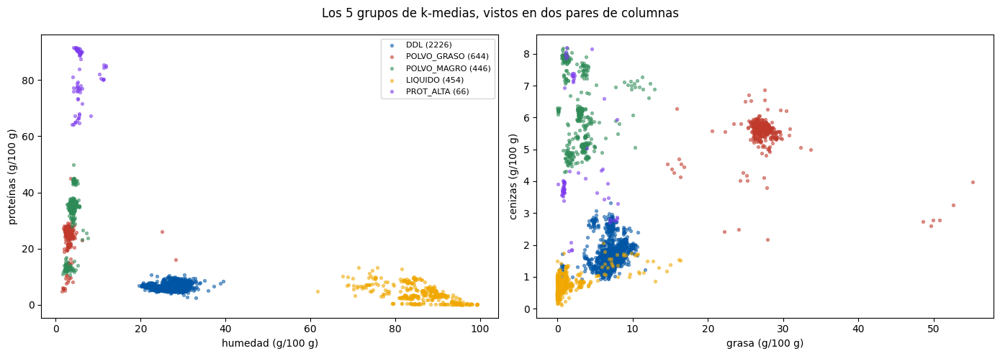

In [33]:
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 5))
for j in range(K):
    sel = grupos == j
    a.scatter(muestras.loc[sel, "humedad"], muestras.loc[sel, "proteinas"], s=8, alpha=0.5, color=COLORES[j], label=f"{tags[j]} ({sel.sum()})")
    b.scatter(muestras.loc[sel, "grasa"], muestras.loc[sel, "cenizas"], s=8, alpha=0.5, color=COLORES[j])
a.set_xlabel("humedad (g/100 g)"); a.set_ylabel("proteínas (g/100 g)"); a.legend(fontsize=8)
b.set_xlabel("grasa (g/100 g)"); b.set_ylabel("cenizas (g/100 g)")
fig.suptitle(f"Los {K} grupos de k-medias, vistos en dos pares de columnas")
plt.tight_layout(); plt.show()

##### Una muestra nueva
Se arma la fila, se imputa y escala con lo aprendido; `predict` da el grupo (y su tag) y `transform` la distancia a cada
centroide. Dos ejemplos: un dulce de leche típico y una leche en polvo entera.

In [34]:
nuevas = pd.DataFrame([{"humedad": 28.0, "grasa": 7.0, "proteinas": 6.5, "cenizas": 1.6},
                       {"humedad": 3.0, "grasa": 26.0, "proteinas": 25.0, "cenizas": 5.8}], index=["dulce de leche típico", "leche en polvo entera"])[COLUMNAS]
z_nuevas = escalador.transform(imputador.transform(nuevas))
for (etiqueta, fila), z in zip(nuevas.iterrows(), z_nuevas):
    g = int(km.predict(z[None, :])[0]); d = km.transform(z[None, :])[0]
    print(f"{etiqueta} {fila.to_dict()} → {tags[g]} ({nombres[g]}) · distancias: { {tags[j]: round(float(v), 2) for j, v in enumerate(d)} }")

dulce de leche típico {'humedad': 28.0, 'grasa': 7.0, 'proteinas': 6.5, 'cenizas': 1.6} → DDL (pastoso tipo dulce de leche) · distancias: {'DDL': 0.02, 'POLVO_GRASO': 3.49, 'POLVO_MAGRO': 3.06, 'LIQUIDO': 2.53, 'PROT_ALTA': 5.6}
leche en polvo entera {'humedad': 3.0, 'grasa': 26.0, 'proteinas': 25.0, 'cenizas': 5.8} → POLVO_GRASO (polvo graso (tipo leche entera)) · distancias: {'DDL': 3.43, 'POLVO_GRASO': 0.2, 'POLVO_MAGRO': 2.72, 'LIQUIDO': 5.29, 'PROT_ALTA': 4.86}


##### Diez muestras, con su tag y su silueta
Diez muestras elegidas para cubrir el rango de la silueta: de la que está bien adentro de su grupo a la que está sobre
un límite (o del lado equivocado). Es la tabla para discutir: ¿la muestra mal ubicada es un error de carga, un producto
raro, o un grupo que falta?

In [35]:
objetivos = np.linspace(coef.max(), coef.min(), 10); elegidos, usados = [], set()
for objetivo in objetivos:
    for candidato in np.argsort(np.abs(coef - objetivo), kind="stable"):
        if candidato not in usados: elegidos.append(candidato); usados.add(candidato); break
elegidos = np.array(elegidos)
explicado = muestras.loc[elegidos, ["Identificador", "desc_familia", "desc_producto"] + COLUMNAS].copy()
explicado["tag"] = tag_de[elegidos]
explicado["silueta"] = coef[elegidos].round(3)
explicado.style.format(precision=2).background_gradient(subset=["silueta"], cmap="RdYlGn", vmin=-0.3, vmax=1)

,Identificador,desc_familia,desc_producto,humedad,grasa,proteinas,cenizas,tag,silueta
3817,MQ-46324-01,leche en polvo,nan,2.52,27.52,26.34,5.64,POLVO_GRASO,0.93
2796,MQ-43994-01,suero / permeado,PERMEADO DE LECHE LIQUIDO UF,94.57,0.00,0.23,0.50,LIQUIDO,0.82
426,MO-10908-04,concentrado proteico,CONCENTRADO DE PROTEINAS DE SUERO DE QUESO EN POLVO,4.13,3.46,34.83,5.12,POLVO_MAGRO,0.72
2830,MQ-44236-01,concentrado proteico,POLVO CONCENTRADO DE PROTEINAS MUESTRAS · OBSERV,4.23,7.73,77.33,2.76,PROT_ALTA,0.61
3437,MQ-44509-01,sin clasificar,nan,7.14,7.98,25.50,5.49,POLVO_MAGRO,0.51
3039,MQ-40658-01,suero / permeado,nan,4.16,10.86,31.09,6.96,POLVO_MAGRO,0.41
2643,MQ-43201-01,suero / permeado,SUERO EN POLVO,5.48,2.01,67.49,7.30,PROT_ALTA,0.30
2340,MQ-40513-01,suero / permeado,SUERO DESMINERALIZADO EN POLVO,2.58,1.41,13.88,4.64,POLVO_MAGRO,0.20
379,MO-10554-01,suero / permeado,SUERO EN POLVO PARCIALMENTE DESMINERALIZADO,4.15,1.43,12.34,4.50,POLVO_MAGRO,0.09
3299,MQ-42969-01,sin clasificar,nan,3.96,22.19,8.09,2.42,POLVO_GRASO,-0.01


##### Segundo nivel por familia: subtags del DDL, de los polvos y del queso
El primer nivel separa tipos de producto; adentro de tres de ellos hay variantes que importan. Cada rama usa el método
que aprobó su prueba por familia (README, «Pruebas por familia»; código en `src/segundo_nivel.py`). Las ramas van por el
**tag**, no por la familia del rótulo: así el subtag queda siempre dentro de su tag y se puede predecir para una muestra
nueva con los cuatro análisis.

| rama | muestras | método | subtags |
|---|---|---|---|
| DDL | tag DDL | **regresión logística** multinomial sobre los cuatro análisis, entrenada con el subtipo conocido (`desc_subtipo`, o el de `desc_producto` o `mq_tipo_muestra.csv`); decide si la probabilidad es ≥ 0,70 y la muestra no es novedad (Mahalanobis robusta o LOF). Exactitud balanceada 0,86 en clientes no vistos (`prueba_subtipo_ddl.ipynb`) | DDL_FAMILIAR, DDL_REPOSTERO, DDL_HELADERO; «DDL» si no decide |
| polvo | tags POLVO_GRASO, POLVO_MAGRO y PROT_ALTA con humedad ≤ 15 | primero dos **reglas de composición en base seca**: suero reengrasado (grasa ≥ 15 y proteína ≤ 12) y leche descremada (grasa ≤ 2,5, cenizas ≥ 7 y proteína 30 a 40); el resto, outliers por consenso dentro de la rama y **k-medias** (k por silueta) en grasa, proteína y cenizas **en base seca**; un cluster lleva subtag si su tipo del rótulo tiene pureza ≥ 70 % y cobertura ≥ 50 % o, si no, su familia pureza ≥ 70 %, contado sin las muestras de las reglas (`prueba_clustering_polvos.ipynb`) | POLVO_SUERO_REENGRASADO, POLVO_LECHE_DESCREMADA, POLVO_LECHE_ENTERA, POLVO_WPC, POLVO_CASEINATO, POLVO_SUERO_...; el tag si no |
| queso | los quesos que confirma el catálogo (rama propia, fuera del k-medias; abajo) | **clase de humedad del CAA** (art. 605): < 36 duro, 36 a 46 semiduro, 46 a 55 pasta blanda, ≥ 55 muy alta humedad. Coincide con la consistencia del rótulo mejor que cualquier agrupamiento (`prueba_clustering_quesos.ipynb`) | QUESO_DURO, QUESO_SEMIDURO, QUESO_PASTA_BLANDA, QUESO_MUY_ALTA_HUMEDAD |

Las dos reglas del polvo existen porque el k-medias no separa esos productos: escala la proteína con todos los polvos
(de 3 a 91 g/100 g de extracto seco), y a esa escala el suero reengrasado queda con la leche entera o con los sueros
magros, y la leche descremada (proteína 35, cenizas 8) con un concentrado de suero de 46 % de proteína y las mismas
cenizas: ningún k de 6 a 14 le da un cluster puro. Por proteína sola la leche descremada (34 a 38,5) y el WPC 35 (35 a
39) se pisan; los separan las cenizas (8,1 contra 6,2) y la grasa (1,1 contra 3,4). Los umbrales salen de los rótulos y
se verifican abajo (subtag × tipo del rótulo).

Los demás tags quedan sin subtag (su subtag es el tag). El queso no depende del k-medias: sale de su rama. El subtipo o tipo del rótulo se usa para entrenar (DDL) y para
nombrar los clusters (polvo), **nunca como entrada**. Reemplaza al segundo nivel anterior (mezcla de gaussianas dentro del
DDL, que daba DDL_HELADERO y DDL_FAMILIAR y nunca el repostero). Los subtags se juzgan por pureza y cobertura, no con la
silueta: son un segundo nivel dentro de un grupo, no grupos del primero.

In [36]:
subtag_de, criterio_de, modelos_subtag = N.ajustar(muestras, tag_de, S)
print("De dónde sale el subtag:", pd.Series(criterio_de).value_counts().to_dict())
print("Muestras por subtag:", pd.Series(subtag_de).value_counts().to_dict())
base_ = N.tag_base(tag_de)          # sin el sufijo _2, _3: los clusters repetidos van a la misma rama
ddl_ = base_ == "DDL"
m_ = modelos_subtag["DDL"]
print(f"DDL · logística entrenada con {m_['etiquetadas']} muestras con subtipo {m_['por_clase']}; "
      f"decide en {int((criterio_de[ddl_] == N.C_DDL).sum())} de {int(ddl_.sum())}")
print("DDL · subtag (filas) contra el subtipo conocido (columnas); en las que tienen subtipo es el ajuste sobre ellas mismas:")
display(pd.crosstab(subtag_de[ddl_], muestras.loc[ddl_, "subtipo_ref"].fillna("sin subtipo").to_numpy(),
                    rownames=["subtag"], colnames=["subtipo conocido"], margins=True, margins_name="total"))
if "polvo" in modelos_subtag:
    p_ = modelos_subtag["polvo"]
    print(f"Polvo · {p_['n']} muestras en la rama, {p_['n_outliers']} outliers de la rama · k-medias con k = {p_['k']} "
          f"(silueta {p_['siluetas'][p_['k']]:.3f}) · por cluster (base seca, g/100 g de extracto seco):")
    display(p_["descripcion"])
    pol_ = N.es_polvo(tag_de)
    print("Polvo · tag (filas) × subtag (columnas):")
    display(pd.crosstab(tag_de[pol_], subtag_de[pol_], rownames=["tag"], colnames=["subtag"]))
    tipo_ = N._referencias_polvo(muestras.loc[pol_, "Identificador"], S)["tipo"].fillna("sin tipo").to_numpy()
    print("Polvo · subtag (filas) × tipo del rótulo (columnas); el tipo no entra, sirve para verificar las reglas y los nombres:")
    t_ = pd.crosstab(subtag_de[pol_], tipo_, rownames=["subtag"], colnames=["tipo del rótulo"])
    display(t_.loc[:, t_.sum().sort_values(ascending=False).index])
if "queso" in modelos_subtag:
    q_ = base_ == "QUESO"
    print("Queso · subtag × familia del rótulo:")
    display(pd.crosstab(subtag_de[q_], muestras.loc[q_, "desc_familia"].to_numpy(), rownames=["subtag"], colnames=["familia"],
                        margins=True, margins_name="total"))

De dónde sale el subtag: {'DDL: logística (prob ≥ 0,70)': 1699, 'polvo: k-medias en base seca': 1040, 'DDL: sin decidir (prob < 0,70)': 496, 'sin segundo nivel': 454, 'polvo: regla leche descremada (grasa ≤ 2,5, cenizas ≥ 7, proteína 30 a 40)': 73, 'DDL: sin decidir (novedad)': 31, 'polvo: cluster sin tipo': 18, 'polvo: regla suero reengrasado (grasa ≥ 15, proteína ≤ 12)': 15, 'polvo: outlier de la rama': 8, 'polvo: humedad > 15 (no es polvo)': 2}
Muestras por subtag: {'DDL_FAMILIAR': 876, 'DDL_REPOSTERO': 646, 'POLVO_LECHE_ENTERA': 620, 'DDL': 527, 'LIQUIDO': 454, 'POLVO_WPC': 310, 'DDL_HELADERO': 177, 'POLVO_LECHE_DESCREMADA': 73, 'POLVO_SUERO_DESMINERALIZADO': 70, 'POLVO_CASEINATO': 40, 'PROT_ALTA': 26, 'POLVO_SUERO_REENGRASADO': 15, 'POLVO_GRASO': 2}
DDL · logística entrenada con 1601 muestras con subtipo {'FAMILIAR': 789, 'REPOSTERO': 637, 'HELADERO': 175}; decide en 1699 de 2226
DDL · subtag (filas) contra el subtipo conocido (columnas); en las que tienen subtipo es el ajuste sob

subtipo conocido,FAMILIAR,HELADERO,REPOSTERO,sin subtipo,total
subtag,,,,,
DDL,165,8,130,224,527
DDL_FAMILIAR,584,1,45,246,876
DDL_HELADERO,2,165,2,8,177
DDL_REPOSTERO,38,1,460,147,646
total,789,175,637,625,2226


Polvo · 1154 muestras en la rama, 16 outliers de la rama · k-medias con k = 7 (silueta 0.768) · por cluster (base seca, g/100 g de extracto seco):


,subtag,muestras,clientes,grasa_bs,proteina_bs,cenizas_bs,resto_bs,humedad,tipo mayoritario,% tipo,con tipo,% cobertura tipo,familia mayoritario,% familia,CAA leche mayoritario,% CAA leche
cluster,,,,,,,,,,,,,,,,
0,POLVO_SUERO_DESMINERALIZADO,70,9,3.0,13.6,5.0,78.5,2.8,SUERO DESMINERALIZADO,80.0,65,98,suero / permeado,97.0,-,NaN
1,POLVO_LECHE_ENTERA,620,21,28.1,26.6,5.8,39.5,2.8,LECHE ENTERA,91.0,573,100,leche en polvo,100.0,entera,96.0
2,POLVO_WPC,101,3,4.1,36.6,5.3,54.0,4.0,WPC,100.0,98,34,concentrado proteico,100.0,-,NaN
3,POLVO_WPC,169,8,3.5,36.9,6.4,53.2,4.1,WPC,95.0,166,54,concentrado proteico,95.0,parcialmente descremada,100.0
4,POLVO_WPC,40,4,5.3,41.9,7.7,45.0,4.3,WPC,76.0,38,10,concentrado proteico,78.0,-,NaN
5,(el tag),18,4,2.6,78.1,7.9,11.3,6.6,CASEINA,36.0,14,100,concentrado proteico,61.0,parcialmente descremada,80.0
6,POLVO_CASEINATO,40,4,2.5,89.4,4.0,4.2,5.4,CASEINATO,79.0,33,100,concentrado proteico,98.0,-,NaN


Polvo · tag (filas) × subtag (columnas):


subtag,POLVO_CASEINATO,POLVO_GRASO,POLVO_LECHE_DESCREMADA,POLVO_LECHE_ENTERA,POLVO_SUERO_DESMINERALIZADO,POLVO_SUERO_REENGRASADO,POLVO_WPC,PROT_ALTA
tag,,,,,,,,
POLVO_GRASO,0,2,0,620,5,15,2,0
POLVO_MAGRO,0,0,73,0,65,0,308,0
PROT_ALTA,40,0,0,0,0,0,0,26


Polvo · subtag (filas) × tipo del rótulo (columnas); el tipo no entra, sirve para verificar las reglas y los nombres:


tipo del rótulo,LECHE ENTERA,WPC,sin tipo,LECHE DESCREMADA,SUERO DESMINERALIZADO,LECHE MODIFICADA,SUERO,CASEINATO,CASEINA,PROTEINAS LACTEAS,MPC,SUERO REENGRASADO,LECHE PARCIALMENTE DESCREMADA
subtag,,,,,,,,,,,,,
POLVO_CASEINATO,0,4,7,0,0,0,0,26,0,3,0,0,0
POLVO_GRASO,0,0,2,0,0,0,0,0,0,0,0,0,0
POLVO_LECHE_DESCREMADA,0,0,0,72,0,0,0,0,0,0,0,0,1
POLVO_LECHE_ENTERA,521,0,47,1,0,49,1,0,0,0,1,0,0
POLVO_SUERO_DESMINERALIZADO,0,0,5,0,52,0,11,0,0,2,0,0,0
POLVO_SUERO_REENGRASADO,0,0,3,0,0,0,8,0,0,0,0,4,0
POLVO_WPC,0,284,8,1,1,0,15,0,0,1,0,0,0
PROT_ALTA,2,3,7,0,0,0,2,0,9,0,3,0,0


##### Rama de queso: fuera del k-medias de cuatro análisis
Los quesos no pasan por el k-medias: casi ninguno trae proteína ni cenizas (Senasa no las pide en queso), así que con la
regla de los cuatro análisis quedaban afuera o, si entraban, formaban un grupo débil entre el dulce de leche y los
polvos. Van a una **rama propia** con lo que sí tienen: **humedad** (100 − sólidos totales) y **materia grasa**. Solo
entra como queso **lo que confirma el catálogo**:

- **Senasa**: `desc_familia = queso`.
- **Solo MQ** (con `MQ encolumnado.xlsx`): la familia de las muestras solo MQ sale de un modelo (`mq_tipo_muestra.csv`,
  sin revisar a mano), así que no alcanza. Hace falta que el **rótulo** nombre una variedad de queso (el subtipo
  normalizado con el catálogo). Las que el modelo llama queso pero el rótulo no confirma **no entran** a la rama y siguen
  en el k-medias si tienen los cuatro análisis (desconfiar por defecto: no se les asume categoría).

Una muestra tiene **una sola asignación**: los quesos confirmados salen del k-medias (se quitan antes de elegir k y de
buscar outliers), de modo que el tag QUESO sale solo de esta rama. El **subtag** es la clase de humedad del CAA (art. 605):
< 36 duro, 36 a 46 semiduro, 46 a 55 pasta blanda, ≥ 55 muy alta humedad (`segundo_nivel.subtag_queso`; en
`prueba_clustering_quesos.ipynb` coincide con la consistencia del rótulo mejor que cualquier agrupamiento). Se piden MG y
ST y se descartan los imposibles (MG > ST, humedad + ST fuera de 100 ± 1). Código: `clustering_quesos.rama_queso`.

In [37]:
rama = rama.copy()
rama["subtag"] = N.subtag_queso(rama["humedad"]); rama["criterio_subtag"] = N.C_QUESO
assert (rama["subtag"] == rama["caa_humedad"].map(lambda c_: "QUESO_" + Q.NOMBRE_CAA[c_])).all()   # misma regla que el CAA
print("Cuántos quesos confirma el catálogo y cuántos entran a la rama:")
print({k_: v_ for k_, v_ in conteo_q.items()})
print(f"Rama de queso: {len(rama)} muestras · por origen: {rama['origen'].value_counts().to_dict()}")
print("Subtag:", rama["subtag"].value_counts().to_dict())
display(pd.crosstab(rama["subtag"], rama["origen"], margins=True, margins_name="total"))
print("Subtag (filas) contra la consistencia del rótulo (columnas); el rótulo no entra, solo se compara:")
display(pd.crosstab(rama["subtag"], rama["consistencia"].fillna("sin dato"), margins=True, margins_name="total"))
ids_ = set(sin_confirmar["Identificador"])
en_pre = muestras_pre["Identificador"].isin(ids_)
en_km = muestras["Identificador"].isin(ids_).to_numpy()
print(f"Solo MQ de familia queso sin confirmar por el rótulo: {len(sin_confirmar)} ({int(sin_confirmar[['mg', 'st']].notna().all(axis=1).sum())} con MG y ST). "
      f"No entran a la rama. Con los cuatro análisis entran al k-medias {int(en_pre.sum())}; {int(muestras_pre.loc[en_pre, 'outlier'].sum())} salen como outliers; "
      f"las otras {int(en_km.sum())} reciben el tag:", pd.Series(tag_de[en_km]).value_counts().to_dict())

Cuántos quesos confirma el catálogo y cuántos entran a la rama:
{'quesos leídos': 5915, 'con MG y ST': 2892, 'excluidas: humedad + ST fuera de 100 ± 1': 0, 'excluidas: MG > ST o fuera de rango': 1, 'quedan': 2891, 'solo MQ de familia queso sin confirmar por el rótulo (no entran)': 1128, 'de ellas, con MG y ST': 697}
Rama de queso: 2891 muestras · por origen: {'Senasa': 1627, 'solo MQ': 1215, 'Senasa completada con MQ': 49}
Subtag: {'QUESO_SEMIDURO': 1195, 'QUESO_PASTA_BLANDA': 693, 'QUESO_DURO': 539, 'QUESO_MUY_ALTA_HUMEDAD': 464}


origen,Senasa,Senasa completada con MQ,solo MQ,total
subtag,,,,
QUESO_DURO,325,13,201,539
QUESO_MUY_ALTA_HUMEDAD,151,9,304,464
QUESO_PASTA_BLANDA,358,12,323,693
QUESO_SEMIDURO,793,15,387,1195
total,1627,49,1215,2891


Subtag (filas) contra la consistencia del rótulo (columnas); el rótulo no entra, solo se compara:


consistencia,alta humedad,baja humedad,mediana humedad,mezcla,procesado,sin dato,untable,total
subtag,,,,,,,,
QUESO_DURO,0,491,16,2,27,3,0,539
QUESO_MUY_ALTA_HUMEDAD,101,0,30,1,162,4,166,464
QUESO_PASTA_BLANDA,606,0,73,0,13,1,0,693
QUESO_SEMIDURO,115,36,997,0,36,11,0,1195
total,822,527,1116,3,238,19,166,2891


Solo MQ de familia queso sin confirmar por el rótulo: 1128 (697 con MG y ST). No entran a la rama. Con los cuatro análisis entran al k-medias 44; 21 salen como outliers; las otras 23 reciben el tag: {'LIQUIDO': 22, 'POLVO_MAGRO': 1}


##### ¿Se pueden diferenciar los quesos en clusters sin aprender de un tag previo?
Se agrupan los quesos de la rama usando **solo humedad y MGES** (grasa en el extracto seco = 100·MG/ST), estandarizadas y
sin los outliers por consenso (3 %). No se usa ningún rótulo ni el CAA para ajustar nada: **k-medias** con k por silueta
y **mezcla de gaussianas** con k por BIC. Recién después se comparan con la **clase de humedad del CAA**, la **clase de
MGES del CAA** y la **consistencia** y el **tipo** del rótulo: Rand ajustado (ARI, 0 = azar, 1 = igual) e información
mutua normalizada (NMI), tablas cruzadas y estabilidad con otras semillas (`clustering_quesos.no_supervisado`). La fila
«regla CAA de humedad» es el corte del CAA aplicado directo, sin agrupar: es el techo contra el que mirar.

2891 quesos · 81 outliers por consenso · se agrupan 2810
k-medias, silueta por k: {2: 0.37, 3: 0.423, 4: 0.433, 5: 0.475, 6: 0.461, 7: 0.491, 8: 0.485, 9: 0.475, 10: 0.476} → k = 7
Mezcla de gaussianas, BIC por k: {1: 15981, 2: 14608, 3: 14080, 4: 13409, 5: 13149, 6: 12770, 7: 12514, 8: 12256} → k = 8


,k-medias (k = 7),"mezcla de gaussianas (k = 8, BIC)",regla CAA de humedad (sin agrupar)
grupos,7.00,8.00,4.00
ruido,0.00,0.00,0.00
silueta,0.49,0.43,0.22
silueta macro,0.54,0.44,0.22
peor grupo,0.36,-0.39,0.06
Davies-Bouldin,0.63,1.18,1.70
Calinski-Harabasz,2727.57,1498.19,921.86
ARI CAA humedad,0.31,0.38,1.00
NMI CAA humedad,0.50,0.56,1.00
ARI CAA MGES,0.29,0.18,0.09


k-medias (k = 7) (filas) contra CAA humedad (columnas):


CAA humedad,alta humedad,baja humedad,mediana humedad,muy alta humedad
cluster,,,,
0,0,101,0,0
1,0,402,184,0
2,320,2,641,2
3,365,0,370,17
4,3,1,0,84
5,3,0,0,177
6,0,0,0,138


k-medias (k = 7) (filas) contra CAA MGES (columnas):


CAA MGES,extra graso,graso,magro,semigraso
cluster,,,,
0,0,0,0,101
1,0,312,0,274
2,1,964,0,0
3,0,157,0,595
4,0,0,39,49
5,12,168,0,0
6,0,53,0,85


... (7 outputs left out)

consistencia,alta humedad,baja humedad,mediana humedad,mezcla,procesado,sin dato,untable
cluster,,,,,,,
0,0,96,1,0,0,0,0
1,0,407,151,1,2,3,0
2,23,0,628,0,1,1,0
3,417,15,298,0,45,11,0
4,288,0,6,1,42,0,0
5,43,0,0,0,0,0,0
6,31,2,3,1,25,1,53
7,6,0,29,0,96,0,83


Estabilidad con 10 semillas: ARI de cada partición contra la de la semilla base (mismo k) y k que elige cada criterio:


,ARI k-medias (k fijo),ARI mezcla (k fijo),k elegido k-medias,k elegido mezcla
semilla,,,,
0,1.0,0.82,7,8
1,1.0,0.99,7,8
2,1.0,0.54,7,8
3,1.0,0.54,7,8
4,1.0,0.82,7,8
5,1.0,0.80,7,8
6,1.0,0.81,7,7
7,1.0,0.81,7,8
8,1.0,0.81,7,8


Promedio: {'ARI k-medias (k fijo)': 0.999, 'ARI mezcla (k fijo)': 0.745, 'k elegido k-medias': 7.0, 'k elegido mezcla': 7.9}


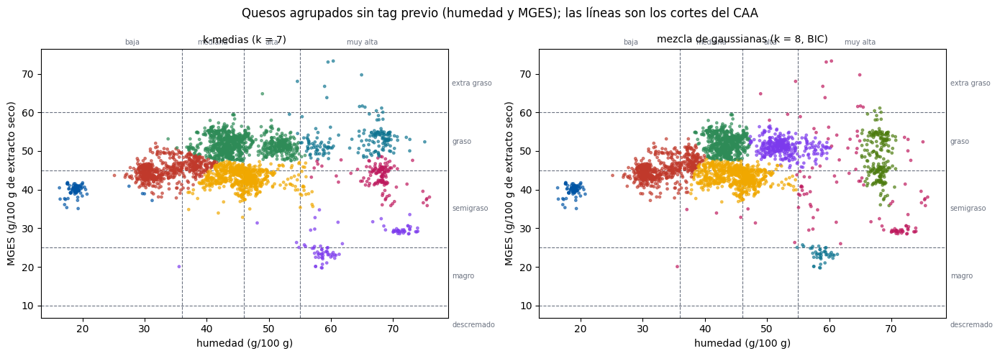

In [38]:
ns = Q.no_supervisado(rama)
print(f"{len(rama)} quesos · {ns['n_outliers']} outliers por consenso · se agrupan {len(ns['base'])}")
print("k-medias, silueta por k:", {k_: round(float(v_), 3) for k_, v_ in ns["silueta"].items()}, "→ k =", ns["k_km"])
print("Mezcla de gaussianas, BIC por k:", {k_: round(float(v_)) for k_, v_ in ns["bic"].items()}, "→ k =", ns["k_gm"])
display(ns["tabla"].round(2).T)
for (alg_, ref_), t_ in ns["cruzadas"].items():
    print(f"{alg_} (filas) contra {ref_} (columnas):")
    display(t_)
print("Estabilidad con 10 semillas: ARI de cada partición contra la de la semilla base (mismo k) y k que elige cada criterio:")
display(ns["estabilidad"].round(2))
print("Promedio:", ns["estabilidad"].mean().round(3).to_dict())

fig, ejes = plt.subplots(1, 2, figsize=(14, 5))
for ax_, (nombre_, et_) in zip(ejes, ns["et"].items()):
    ax_.scatter(ns["base"]["humedad"], ns["base"]["mges"], c=[COLORES[e_ % len(COLORES)] for e_ in et_], s=6, alpha=0.6)
    Q.lineas_caa(ax_); ax_.set_xlabel("humedad (g/100 g)"); ax_.set_ylabel("MGES (g/100 g de extracto seco)"); ax_.set_title(nombre_, fontsize=10)
fig.suptitle("Quesos agrupados sin tag previo (humedad y MGES); las líneas son los cortes del CAA")
plt.tight_layout(); plt.show()

**Respuesta.** Sí hay estructura, pero no es la del dominio y el número de grupos es poco robusto. De los 2891 quesos de
la rama, 81 salen como outliers y se agrupan 2810 (humedad y MGES estandarizadas).

- **Qué encuentra.** k-medias elige k = 7 (silueta 0,49; silueta macro 0,54; Davies-Bouldin 0,63) y la mezcla de
  gaussianas k = 8 por BIC (silueta 0,43). Son grupos más compactos que los del corte del CAA (silueta 0,22,
  Davies-Bouldin 1,70).
- **Coincidencia con el dominio.** Contra la clase de humedad del CAA el Rand ajustado (ARI) es 0,31 (k-medias) y 0,38
  (mezcla); contra la clase de MGES, 0,29 y 0,18 (NMI de humedad 0,50 y 0,56). Los extremos se reconocen (un grupo de 101
  quesos puros de baja humedad y dos de 177 y 138 casi puros de muy alta humedad); el medio no tiene corte natural: los
  grupos de humedad intermedia mezclan mediana y alta humedad (641 y 320; 370 y 365). Contra la **consistencia del rótulo**
  el agrupamiento da ARI 0,31 y 0,37 y **la regla del CAA aplicada directo, 0,63**: el corte por humedad coincide con el
  rótulo mejor que cualquier agrupamiento sin tag. Contra el **tipo** (variedad) pasa al revés: 0,28 y 0,36 contra 0,19 de
  la regla, porque los grupos separan también por grasa.
- **Estabilidad.** Con k fijo y otras 10 semillas, el ARI contra la partición base es 1,00 en promedio en k-medias (y el k
  que elige la silueta es 7 en las 10 semillas) y 0,75 en la mezcla (de 0,51 a 0,99; el k que elige el BIC es 8 en 9 semillas
  y 7 en una). Con solo Senasa la mezcla era mucho más estable (ARI 0,99): al sumar los quesos de MQ la humedad y la grasa se
  solapan más y la partición de la mezcla deja de ser única; la del k-medias se mantiene.

Conclusión: sin tag previo se separan grupos en la composición, pero son una partición del continuo (7 a 8 zonas, y la
de la mezcla cambia con la semilla) y no una clasificación por tipo de queso; por eso el subtag de la rama sale de la regla del CAA, que
además coincide mejor con el rótulo.

##### Guardar: el tag y el subtag de cada muestra y el agrupamiento
`clusters_senasa_mq.csv`: una fila por muestra que pasó el filtro (incluidos los outliers, que quedan sin cluster, tag ni subtag),
con Identificador, familia, origen, los cuatro análisis, cluster, tag, subtag (el tag cuando no hay subtag),
criterio_subtag (de qué rama y regla sale), silueta, outlier, votos_outlier (cuántos de los tres métodos la marcan) y, en
el DDL, las tres probabilidades de la logística (p_familiar, p_heladero, p_repostero). Y `agrupamiento_senasa_mq_clase41.joblib`: imputar,
escalar y k-medias en un `Pipeline`, con el mapeo cluster → tag, los nombres, los centroides, el filtro de outliers usado
y los modelos del segundo nivel (`segundo_nivel`: la logística y los detectores de novedad del DDL; el escalador, el
k-medias, el mapeo cluster → subtag y los outliers de la rama del polvo; los cortes de humedad del queso).
`N.predecir` los usa.

In [39]:
import joblib
from sklearn.pipeline import Pipeline
muestras["cluster"] = grupos; muestras["tag"] = tag_de; muestras["subtag"] = subtag_de; muestras["criterio_subtag"] = criterio_de
muestras["silueta"] = coef
prob_ = N.probabilidades_ddl(modelos_subtag, muestras.loc[N.tag_base(tag_de) == "DDL", COLUMNAS]).round(4)
for c_ in prob_:
    muestras[c_] = np.nan
    muestras.loc[N.tag_base(tag_de) == "DDL", c_] = prob_[c_].to_numpy()
salida = muestras_pre[["Identificador", "desc_familia", "origen"] + COLUMNAS + ["outlier"]].rename(columns={"desc_familia": "familia"})
salida["votos_outlier"] = votos["votos"].to_numpy()
salida = salida.merge(muestras[["Identificador", "cluster", "tag", "subtag", "criterio_subtag", "silueta"] + list(prob_)],
                      on="Identificador", how="left")
salida["cluster"] = salida["cluster"].astype("Int64"); salida["silueta"] = salida["silueta"].round(4)
salida["rama"] = "k-medias"
filas_queso = pd.DataFrame({"Identificador": rama["Identificador"], "familia": "queso", "origen": rama["origen"], "humedad": rama["humedad"],
                            "grasa": rama["mg"], "proteinas": rama["proteina"], "cenizas": rama["cenizas"], "tag": "QUESO",
                            "subtag": rama["subtag"], "criterio_subtag": rama["criterio_subtag"], "outlier": False,
                            "rama": "queso (humedad y MG)"})
salida = pd.concat([salida, filas_queso], ignore_index=True)       # los quesos de la rama: sin cluster ni silueta
salida = salida[["Identificador", "familia", "origen", "rama"] + COLUMNAS + ["cluster", "tag", "subtag", "criterio_subtag", "silueta",
                                                                           "outlier", "votos_outlier"] + list(prob_)]
salida.to_csv(R.TABLAS / "clusters_senasa_mq.csv", index=False, encoding="utf-8-sig")
print(f"Guardado: resultados/tablas/clusters_senasa_mq.csv ({len(salida)} filas: {int((salida['rama'] == 'k-medias').sum())} del k-medias y {len(filas_queso)} de la rama de queso; "
      f"{int(salida['tag'].notna().sum())} con tag, {int(salida['outlier'].sum())} outliers)")
print("tag:", salida["tag"].value_counts(dropna=False).to_dict())
print("subtag:", salida["subtag"].value_counts(dropna=False).to_dict())
print("criterio_subtag:", salida["criterio_subtag"].value_counts(dropna=False).to_dict())

agrupamiento = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler()),
                         ("kmedias", KMeans(n_clusters=K, n_init=N_INIT_KMEDIAS, random_state=SEMILLA))]).fit(muestras[COLUMNAS])
assert (agrupamiento.predict(muestras[COLUMNAS]) == grupos).all()
out_polvo_ = muestras["Identificador"].isin(modelos_subtag.get("polvo", {}).get("outliers", [])).to_numpy()
assert (N.predecir(modelos_subtag, muestras[COLUMNAS], tag_de, out_polvo_)[0] == subtag_de).all()
joblib.dump({"modelo": agrupamiento, "tags": tags, "nombres": nombres, "columnas": COLUMNAS, "centros": centros,
             "outliers": {"método": "consenso (LOF 50 vecinos, IsolationForest 200, EllipticEnvelope) dentro del k-medias preliminar",
                          "k_preliminar": K_PRE, "pct": PCT_OUTLIER, "minimo_votos": 2},
             "segundo_nivel": N.para_guardar(modelos_subtag),
             "rama_queso": {"criterio": "familia queso del catálogo (Senasa) o rótulo con variedad (solo MQ); humedad = 100 − ST; subtag por clase de humedad del CAA",
                            "cortes_humedad": N.CORTES_QUESO, "muestras": int(len(rama))}},
            R.MODELOS / "agrupamiento_senasa_mq_clase41.joblib")
print("Guardado: resultados/modelos/agrupamiento_senasa_mq_clase41.joblib · cluster → tag:", tags, "· ramas del segundo nivel:", list(modelos_subtag),
      "· polvo, cluster → subtag:", modelos_subtag.get("polvo", {}).get("mapa"))

Guardado: resultados/tablas/clusters_senasa_mq.csv (6828 filas: 3937 del k-medias y 2891 de la rama de queso; 6727 con tag, 101 outliers)
tag: {'QUESO': 2891, 'DDL': 2226, 'POLVO_GRASO': 644, 'LIQUIDO': 454, 'POLVO_MAGRO': 446, nan: 101, 'PROT_ALTA': 66}
subtag: {'QUESO_SEMIDURO': 1195, 'DDL_FAMILIAR': 876, 'QUESO_PASTA_BLANDA': 693, 'DDL_REPOSTERO': 646, 'POLVO_LECHE_ENTERA': 620, 'QUESO_DURO': 539, 'DDL': 527, 'QUESO_MUY_ALTA_HUMEDAD': 464, 'LIQUIDO': 454, 'POLVO_WPC': 310, 'DDL_HELADERO': 177, nan: 101, 'POLVO_LECHE_DESCREMADA': 73, 'POLVO_SUERO_DESMINERALIZADO': 70, 'POLVO_CASEINATO': 40, 'PROT_ALTA': 26, 'POLVO_SUERO_REENGRASADO': 15, 'POLVO_GRASO': 2}
criterio_subtag: {'queso: humedad del CAA': 2891, 'DDL: logística (prob ≥ 0,70)': 1699, 'polvo: k-medias en base seca': 1040, 'DDL: sin decidir (prob < 0,70)': 496, 'sin segundo nivel': 454, nan: 101, 'polvo: regla leche descremada (grasa ≤ 2,5, cenizas ≥ 7, proteína 30 a 40)': 73, 'DDL: sin decidir (novedad)': 31, 'polvo: cluster s

##### Cuántos datos entran en cada entrenamiento
La celda siguiente guarda los conteos de esta versión (cuántas muestras hay antes de los filtros, cuántas saca cada filtro,
cuántas entran a cada modelo); el apartado «Datos usados en cada entrenamiento», al final del cuaderno, los junta en una
tabla. No calcula nada nuevo.

In [40]:
ENTRENOS = globals().get("ENTRENOS", {})
n_nolact, n_quesos = int(no_lactea.sum()), int(a_rama.sum())
_ddl, _pol = modelos_subtag["DDL"], modelos_subtag["polvo"]
ENTRENOS["senasa_mq"] = dict(
    inicial=n_inicial, n_hs=n_inicial - len(todas) - n_nolact - n_quesos, n_nolact=n_nolact, n_quesos=n_quesos,
    n_sin4=len(todas) - len(completas), n_suma=len(completas) - len(muestras_pre),
    pre=len(muestras_pre), k_pre=int(K_PRE), n_out=int(es_outlier.sum()), final=len(muestras), k=int(K), silueta=float(coef.mean()),
    ddl_n=int(ddl_.sum()), ddl_lab=int(_ddl["etiquetadas"]), ddl_clases=dict(_ddl["por_clase"]),
    ddl_decide=int((criterio_de[ddl_] == N.C_DDL).sum()),
    pol_tag=int(pol_.sum()), pol_rama=int(_pol["n"]), pol_out=int(_pol["n_outliers"]), pol_k=int(_pol["k"]),
    pol_sil=float(_pol["siluetas"][_pol["k"]]),
    q_leidos=int(conteo_q["quesos leídos"]), q_mgst=int(conteo_q["con MG y ST"]), q_rama=len(rama),
    q_sin_confirmar=int(conteo_q.get("solo MQ de familia queso sin confirmar por el rótulo (no entran)", 0)),
    q_out=int(ns["n_outliers"]), q_base=len(ns["base"]), q_k_km=int(ns["k_km"]), q_k_gm=int(ns["k_gm"]),
    comparacion=True)
print({k_: v_ for k_, v_ in ENTRENOS["senasa_mq"].items()})

{'inicial': 30089, 'n_hs': 8, 'n_nolact': 2319, 'n_quesos': 5915, 'n_sin4': 17907, 'n_suma': 3, 'pre': 3937, 'k_pre': 5, 'n_out': 101, 'final': 3836, 'k': 5, 'silueta': 0.8346436859093868, 'ddl_n': 2226, 'ddl_lab': 1601, 'ddl_clases': {'FAMILIAR': 789, 'REPOSTERO': 637, 'HELADERO': 175}, 'ddl_decide': 1699, 'pol_tag': 1156, 'pol_rama': 1154, 'pol_out': 16, 'pol_k': 7, 'pol_sil': 0.7677762234245176, 'q_leidos': 5915, 'q_mgst': 2892, 'q_rama': 2891, 'q_sin_confirmar': 1128, 'q_out': 81, 'q_base': 2810, 'q_k_km': 7, 'q_k_gm': 8, 'comparacion': True}


#### G · Qué quedó
- Se sumaron Senasa y MQ con la regla del proyecto (Senasa manda; MQ completa huecos y aporta las muestras que no están
  en Senasa). MQ sale de `MQ encolumnado.xlsx` (misma estructura que Senasa; solo los códigos MQ, sin las 1839 MO de la tabla
  ancha, que ya son de Senasa), con las correcciones de la revisión, sin las 8 muestras con humedad + sólidos incoherentes,
  sin las familias que no son lácteas (68 con los cuatro análisis) y **sin los quesos confirmados por el catálogo, que van
  a su rama** (5915 quesos, 75 con los cuatro análisis). Quedan 3940 muestras con los cuatro análisis y 3937 tras
  descartar las 3 que suman más de 102.
- Outliers **dentro de cada tipo de producto**, por consenso (k-medias preliminar con k = 5; LOF, bosque de aislamiento y
  elipse dentro de cada grupo, corte 3 %, 2 de 3 votos): 101 (2,6 %), 57 solo MQ, 35 de Senasa y 9 de Senasa completadas
  con MQ; por familia, 29 sueros, 21 sin clasificar y 21 «queso» (solo MQ que el modelo llama queso y el rótulo no confirma:
  son raras para su grupo). Quedan 3836. La regla anterior (Q3 + 1,5·IQR) quitaría 362 (9,2 %), entre ellos 141 de
  los 176 heladeros: el consenso conserva 172 heladeros y los 11 reducidos en grasa.
- La silueta elige **k = 5** (0,835). Los cinco grupos y su tag: **DDL** (2226), **POLVO_GRASO** (644, leche en polvo),
  **POLVO_MAGRO** (446, concentrados y sueros), **LIQUIDO** (454, suero y leche fluida) y **PROT_ALTA** (66). **Ya no hay
  QUESO en el k-medias**: el tag sale solo de la rama de queso. POLVO_MAGRO y PROT_ALTA son los grupos más débiles
  (silueta media 0,63 y 0,60).
- Sin el sesgo del DDL (B.5): silueta macro 0,754, peor grupo 0,60, Davies-Bouldin 0,37, Calinski-Harabasz 17860.
  Contra la regla anterior (0,862 y macro 0,779) baja porque quedan muestras legítimas del borde; sobre las muestras que
  no quita ninguno de los dos filtros, los dos modelos dan lo mismo (0,864 y macro 0,784).
- Escalar es la decisión correcta, aunque acá la partición no cambia sin escalar (Rand ajustado 1,00).
- k-medias, minilotes y Ward llegan a particiones casi iguales (Rand ajustado 0,999 a 1). El enlace simple encadena y
  deja grupos de 1 a 5 muestras (0,64), el promedio manhattan también se aparta (0,73), y el bisectivo que parte el
  grupo **más grande** corta el dulce de leche en pedazos (0,49).
- Al revelar la familia (la de MQ encolumnado), los grupos se leen como tipos de producto (Rand ajustado contra la familia
  0,92); no coinciden del todo porque algunas familias comparten composición (suero en polvo y concentrados magros; suero
  líquido y leche fluida).
- Las muestras **solo MQ** (893 de las 3836) llevan la familia que les asigna un modelo (`mq_tipo_muestra.csv`, no revisada a
  mano): 508 caen en POLVO_GRASO y 228 en LIQUIDO. De las 1128 solo MQ que el modelo llama queso y el rótulo no confirma
  (697 con MG y ST), ninguna entra a la rama de queso; 44 tenían los cuatro análisis y entraron al k-medias, 21 salieron como
  outliers y las otras 23 cayeron en LIQUIDO (22) y POLVO_MAGRO (1).
- Segundo nivel por familia. **DDL** (logística entrenada con 1601 muestras de subtipo conocido): decide en 1699 de
  2226: **DDL_FAMILIAR** 876, **DDL_REPOSTERO** 646 y **DDL_HELADERO** 177; 527 quedan como DDL (496 sin probabilidad
  suficiente y 31 novedades). Entre las etiquetadas acierta 584 de 789 familiares, 460 de 637 reposteros y 165 de 175
  heladeros (es el ajuste sobre ellas mismas: la exactitud honesta, 0,86 en clientes no vistos, es la de
  `prueba_subtipo_ddl.ipynb`). **Polvo** (1154 muestras con humedad ≤ 15; 16 outliers de la rama; k-medias k = 7 en base seca, silueta
  0,77): por regla, **POLVO_LECHE_DESCREMADA** 73 (72 leches descremadas y 1 parcialmente descremada) y
  **POLVO_SUERO_REENGRASADO** 15 (4 rotuladas suero reengrasado, 8 rotuladas suero y 3 sin tipo); por k-medias,
  **POLVO_LECHE_ENTERA** 620, **POLVO_WPC** 310 (284 WPC; 15 rotuladas solo «suero», con proteína de WPC, y 8 sin tipo),
  **POLVO_SUERO_DESMINERALIZADO** 70 y **POLVO_CASEINATO** 40; un cluster de 18 sin subtag (78 % de proteína en base seca,
  sobre todo caseína) y los outliers de la rama quedan con su tag (PROT_ALTA 26), y 2 muestras con humedad > 15, que no son
  polvo, con el suyo (POLVO_GRASO 2). El LIQUIDO (454) no tiene segundo nivel.
- **Queso** (rama propia, fuera del k-medias; por la humedad del CAA): 2891 quesos (1627 de Senasa, 49 de Senasa completados
  con MQ y 1215 solo MQ con el rótulo que lo confirma): QUESO_SEMIDURO 1195, QUESO_PASTA_BLANDA 693, QUESO_DURO 539 y
  QUESO_MUY_ALTA_HUMEDAD 464. Contra la consistencia del rótulo: 491 de los 539 duros son de baja humedad, 997 de los 1195
  semiduros de mediana, 606 de los 693 de pasta blanda de alta; los muy altos de humedad son sobre todo untables (166) y
  procesados (162). La pregunta «¿se separan sin tag previo?» está arriba: sí, pero en 7 a 8 zonas (las de la mezcla cambian
  con la semilla) y sin coincidir con el CAA (ARI 0,31 a 0,38).
- Cada muestra queda con su `tag`, su `subtag` y su `criterio_subtag` en `resultados/tablas/clusters_senasa_mq.csv` (3937
  del k-medias, 101 de ellas outliers sin tag, y 2891 de la rama de queso, con `rama = queso (humedad y MG)` y sin cluster),
  y el modelo con el mapeo cluster → tag y los modelos del segundo nivel en
  `resultados/modelos/agrupamiento_senasa_mq_clase41.joblib`.

### 5 · Cortes para categorizar (CAA por familia)
`src/cortes_caa.py` (ex `build_cortes_categorias.py`) arma `resultados/tablas/cortes_categorias.csv`: donde el Código
Alimentario Argentino define clases, esas; donde no, terciles dentro de la familia; con menos de 30 valores, cortes
globales (familia `*`). La tabla no se edita a mano: se regenera acá. Criterios y decisiones abiertas:
`docs/cortes_categorias.md`.

**Terciles por estado.** En suero / permeado, concentrado proteico, yogur / bebida láctea, base nutricional y
manteca / crema la composición cambia por completo entre el polvo y el líquido (o entre la manteca y la crema), así que
los terciles se calculan aparte para cada estado (columna `estado`). El estado de una muestra sale de la humedad medida
(≤ 15 polvo, ≥ 25 líquido; en manteca / crema, < 30 es manteca) y, si no hay humedad, del estado declarado. Donde
Senasa tiene menos de 30 valores de un estado (casi no tiene cremas ni sueros líquidos) se suman las muestras nuevas
de MQ. Una muestra de esas familias sin estado no se categoriza en los análisis que dependen del estado.

In [41]:
import cortes_caa
cortes = cortes_caa.armar()
display(cortes.groupby(["analisis", "fuente"], sort=False).size().rename("filas").reset_index()
        .assign(fuente=lambda t: t["fuente"].str.replace(r" \(http.*\)", "", regex=True)))

361 filas -> E:\Downloads\UNRaf\4to cuatrimestre\IA\trabajo_senasa_mq\resultados\tablas\cortes_categorias.csv
  humedad: cortes globales para carnicos (17), helado (14), leche fluida (22), panificados / otros (12), sin clasificar (2)
  materia_grasa: cortes globales para carnicos (15), panificados / otros (11), sin clasificar (2)
  proteinas: cortes globales para arroz con leche / postre (5), carnicos (17), panificados / otros (11)
  cenizas: cortes globales para arroz con leche / postre (2), carnicos (15), panificados / otros (11)
  solidos_totales: cortes globales para helado (14), leche fluida (22), panificados / otros (12), sin clasificar (2)
  lactosa: cortes globales para agua / hisopado (6), arroz con leche / postre (2), manteca / crema (4), panificados / otros (7), sin clasificar (6)
  galactosa: cortes globales para agua / hisopado (12), arroz con leche / postre (2), base nutricional (12), concentrado proteico (26), manteca / crema (3), panificados / otros (11), sin clasificar

,analisis,fuente,filas
0,humedad,terciles globales (Senasa encolumnado.xlsx),3
1,humedad,terciles (Senasa encolumnado.xlsx),9
2,humedad,terciles por estado (Senasa + MQ encolumnado.x...,18
3,humedad,terciles por estado (Senasa encolumnado.xlsx),9
4,humedad,"CAA art. 605, inc. 2.b",4
5,materia_grasa,terciles globales (Senasa encolumnado.xlsx),3
6,materia_grasa,terciles (Senasa encolumnado.xlsx),6
7,materia_grasa,terciles por estado (Senasa + MQ encolumnado.x...,12
8,materia_grasa,terciles por estado (Senasa encolumnado.xlsx),9
9,materia_grasa,"CAA art. 592, inc. 5.2",3


### 6 · Categorías de los análisis e ítems para reglas de asociación

Cada resultado numérico de una muestra pasa a una categoría (por ejemplo `humedad=alta humedad` o
`materia_grasa=entera`) con la tabla `cortes_categorias.csv` (criterio «CAA por familia»; ver
`docs/cortes_categorias.md`; la tabla se regenera en la sección 5). Con las categorías, la familia y el tag del cluster se arma una canasta por muestra y se buscan
reglas de asociación como en la clase 44.

**Tag y subtag.** Cada muestra agrupada lleva su `tag=` (el primer nivel: DDL, POLVO_GRASO...), igual que antes, y las
que tienen subtag (secciones 3 y 4, segundo nivel por familia: DDL_FAMILIAR, DDL_REPOSTERO, DDL_HELADERO, POLVO_WPC,
POLVO_LECHE_ENTERA...) suman además el ítem `subtag=`. Se eligió sumar en vez de reemplazar porque así `tag=DDL` sigue
siendo todo el dulce de leche (las reglas del primer nivel no cambian de significado y se comparan con las de antes) y el
subtag agrega lo que el tag no ve: el heladero tiene menos humedad y más cenizas que el familiar, justo lo que miden las
categorías. Una regla que junta el tag con su propio subtag (`subtag=DDL_HELADERO ⇒ tag=DDL`) es trivial («mismo
análisis»). El subtag del queso (QUESO_SEMIDURO...) **no** entra como ítem: es la clase de humedad del CAA, que ya está
como `humedad=`; queda en `clusters_senasa_mq.csv`.

- Lectura y correcciones: `src/datos_clase41.py` (las mismas de la clase 41, sección 1).
- Categorización: `src/categorizar.py`. Las decisiones están como constantes al principio del módulo.
- Salidas, en `resultados/tablas/`: `categorias_senasa.csv`, `categorias_senasa_mq.csv` (una fila por muestra) y
  `transacciones_senasa.parquet`, `transacciones_senasa_mq.parquet` (matriz one-hot muestra × ítem).

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
import warnings; warnings.filterwarnings("ignore")

import categorizar as cz

AZUL, AMBAR, GRIS, ROJO, VERDE = "#0055a5", "#f0a800", "#6b7280", "#c0392b", "#2e8b57"
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 110); pd.set_option("display.max_rows", 200)
nombre = lambda s: "{" + ", ".join(sorted(s)) + "}"

print("Decisiones (categorizar.py):")
for k in ["HUMEDAD_QUESO_4_CLASES", "NO_SON_ITEMS", "USAR_CORTES_GLOBALES", "GLOBALES_PARA_SIN_FAMILIA",
          "MARCAR_DDL_GRASA_BAJO_MINIMO", "LACTOSA_REFERENCIA", "SUBTIPO_COMO_ITEM", "SUBTAG_COMO_ITEM", "LIFT_MIN"]:
    print(f"   {k} = {getattr(cz, k)}")
print("   desc_consistencia: queda como columna, no es ítem · terciles por subtipo: no")

Decisiones (categorizar.py):
   HUMEDAD_QUESO_4_CLASES = True
   NO_SON_ITEMS = ['solidos_totales']
   USAR_CORTES_GLOBALES = True
   GLOBALES_PARA_SIN_FAMILIA = True
   MARCAR_DDL_GRASA_BAJO_MINIMO = True
   LACTOSA_REFERENCIA = 4.83
   SUBTIPO_COMO_ITEM = False
   SUBTAG_COMO_ITEM = True
   LIFT_MIN = 1.2
   desc_consistencia: queda como columna, no es ítem · terciles por subtipo: no


#### 1 · Las dos tablas

Solo Senasa, y Senasa + MQ (MQ sale de `MQ encolumnado.xlsx`: Senasa manda; MQ completa huecos de humedad, grasa,
proteínas y cenizas y agrega las muestras que solo están en MQ, con la familia que les asigna MQ encolumnado). Los quesos
que confirma el catálogo llevan `tag=QUESO` (rama propia, fuera del k-medias de cuatro análisis); su subtag no es un ítem,
porque sale de la humedad. Las muestras excluidas por humedad + sólidos fuera de 100 ± 1 quedan en la
tabla, sin categorías y con el motivo.

In [43]:
tablas, matrices = {}, {}
for version in ["senasa", "senasa_mq"]:
    tablas[version], matrices[version] = cz.guardar(version)
A = cz.ANALISIS_LISTA
resumen = []
for version, t in tablas.items():
    n_val = int(t[A].notna().sum().sum()); n_cat = int(t[[f"cat_{a}" for a in A]].notna().sum().sum())
    resumen.append({"versión": version, "muestras": len(t), "con algún análisis": int(t[A].notna().any(axis=1).sum()),
                    "transacciones (con ítems)": len(matrices[version]), "ítems distintos": matrices[version].shape[1],
                    "valores": n_val, "categorizados": n_cat, "% categorizado": round(100 * n_cat / n_val, 2),
                    "excluidas": int(t["excluida"].sum())})
display(pd.DataFrame(resumen).set_index("versión"))
t = tablas["senasa"]; M = matrices["senasa"]
print("Orígenes en Senasa + MQ:", tablas["senasa_mq"]["origen"].value_counts().to_dict())
print("Dos muestras con sus ítems:")
for i in t.index[t["items"].map(len) >= 6][:2]:
    print(f"   {t.at[i, 'Identificador']} ({t.at[i, 'familia']}): {t.at[i, 'items']}")

,muestras,con algún análisis,transacciones (con ítems),ítems distintos,valores,categorizados,% categorizado,excluidas
versión,,,,,,,,
senasa,16347,15997,15757,116,40480,40096,99.05,8
senasa_mq,30089,27860,27484,123,65423,64753,98.98,8


Orígenes en Senasa + MQ: {'Senasa': 15996, 'solo MQ': 13742, 'Senasa completada con MQ': 351}
Dos muestras con sus ítems:
   MO-07253-01 (suero / permeado): ['humedad=bajo', 'materia_grasa=medio', 'proteinas=medio', 'cenizas=alto', 'familia=suero / permeado', 'tag=POLVO_MAGRO', 'subtag=POLVO_SUERO_PERMEADO']
   MO-07274-01 (suero / permeado): ['humedad=medio', 'materia_grasa=alto', 'proteinas=medio', 'cenizas=alto', 'familia=suero / permeado', 'tag=POLVO_MAGRO', 'subtag=POLVO_SUERO_PERMEADO']


#### 2 · Los cortes que se aplicaron

Para cada análisis y familia: qué juego de cortes se usó (familia + subtipo, familia o los globales `*`), cada
categoría con sus límites (desde incluido, hasta excluido), si está verificada en el CAA y cuántas muestras cayeron.

In [44]:
cortes = cz.leer_cortes()
filas = []
for a in A:
    x = t[t[f"cat_{a}"].notna()]
    g = x.groupby(["familia", f"juego_{a}", f"cat_{a}"]).size().reset_index(name="n")
    g.columns = ["familia", "juego", "categoria", "n"]; g.insert(0, "analisis", a)
    filas.append(g)
aplicados = pd.concat(filas, ignore_index=True)
aplicados["familia_corte"] = np.where(aplicados["juego"] == "globales (*)", "*", aplicados["familia"])
aplicados = aplicados.merge(cortes[["analisis", "familia", "categoria", "desde", "hasta", "verificado", "fuente"]]
                            .rename(columns={"familia": "familia_corte"}), on=["analisis", "familia_corte", "categoria"], how="left")
assert aplicados["desde"].notna().all()
aplicados["fuente"] = aplicados["fuente"].str.replace(r" \(http.*\)", "", regex=True)
print(f"{len(aplicados)} combinaciones análisis × familia × categoría con muestras · juegos usados:",
      aplicados.groupby("juego")["n"].sum().to_dict())
display(aplicados[["analisis", "familia", "juego", "categoria", "desde", "hasta", "verificado", "n", "fuente"]])

371 combinaciones análisis × familia × categoría con muestras · juegos usados: {'familia': 36364, 'familia + estado': 6338, 'globales (*)': 481}


,analisis,familia,juego,categoria,desde,hasta,verificado,n,fuente
0,humedad,arroz con leche / postre,familia,alto,69.350000,inf,no,16,terciles (Senasa encolumnado.xlsx)
1,humedad,arroz con leche / postre,familia,bajo,0.000000,69.020000,no,13,terciles (Senasa encolumnado.xlsx)
2,humedad,arroz con leche / postre,familia,medio,69.020000,69.350000,no,14,terciles (Senasa encolumnado.xlsx)
3,humedad,base nutricional,familia + estado,alto,55.382400,inf,no,1,terciles por estado (Senasa + MQ encolumnado.xlsx)
4,humedad,base nutricional,familia + estado,alto,7.132000,inf,no,1,terciles por estado (Senasa + MQ encolumnado.xlsx)
...,...,...,...,...,...,...,...,...,...
366,fibra,panificados / otros,globales (*),alto,0.960000,inf,no,1,terciles globales (Senasa encolumnado.xlsx)
367,fibra,yogur / bebida lactea,globales (*),no detectado / 0,0.000000,0.000001,no,1,terciles globales (Senasa encolumnado.xlsx)
368,plomo,dulce de leche,familia,no detectado / 0,0.000000,0.000001,no,36,terciles (Senasa encolumnado.xlsx)
369,arsenico,dulce de leche,familia,detectado,0.000001,inf,no,1,terciles (Senasa encolumnado.xlsx)


In [45]:
print("Familias que usan los cortes globales (*), por análisis (n muestras):")
g = aplicados[aplicados["juego"] == "globales (*)"].groupby(["analisis", "familia"])["n"].sum()
for a, s in g.groupby(level=0):
    print(f"   {a}: " + ", ".join(f"{f} ({n})" for (_, f), n in s.items()))

Familias que usan los cortes globales (*), por análisis (n muestras):
   actividad_agua: arroz con leche / postre (3), helado (2), panificados / otros (1)
   azucares_totales: base nutricional (2), concentrado proteico (2), helado (2), leche en polvo (25), leche fluida (17), manteca / crema (2), sin clasificar (10), suero / permeado (6)
   carbohidratos_totales: helado (2), panificados / otros (2)
   cenizas: arroz con leche / postre (2), carnicos (15), panificados / otros (11)
   fibra: helado (2), panificados / otros (1), yogur / bebida lactea (1)
   galactosa: agua / hisopado (12), arroz con leche / postre (2), base nutricional (12), concentrado proteico (26), manteca / crema (2), panificados / otros (11), sin clasificar (5)
   grasas_saturadas: helado (2), panificados / otros (2), yogur / bebida lactea (1)
   grasas_trans: helado (2), panificados / otros (2), yogur / bebida lactea (1)
   humedad: carnicos (17), helado (14), leche fluida (21), panificados / otros (12), sin clasifica

#### 3 · Conteos por categoría y familia

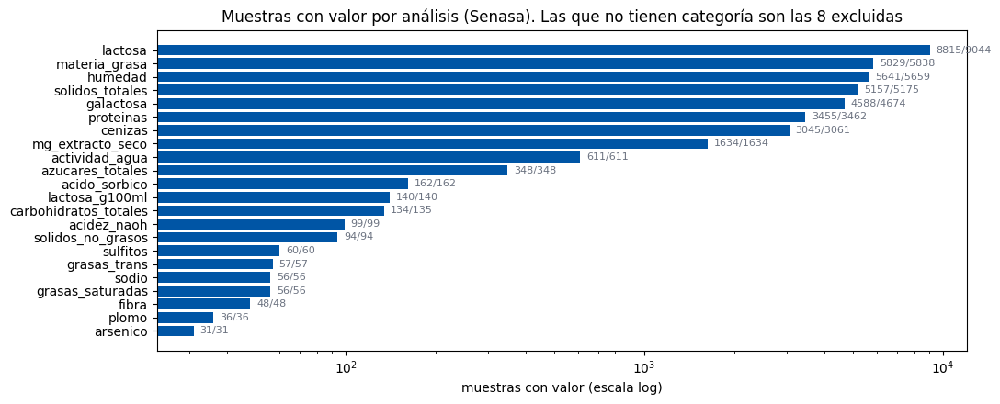

In [46]:
fig, ax = plt.subplots(figsize=(11, 4.5))
p = pd.DataFrame({"valores": t[A].notna().sum(), "categorizados": t[[f"cat_{a}" for a in A]].notna().sum().values}, index=A)
p = p.sort_values("valores")
ax.barh(p.index, p["valores"], color=AZUL); ax.set_xscale("log"); ax.set_xlabel("muestras con valor (escala log)")
ax.set_title("Muestras con valor por análisis (Senasa). Las que no tienen categoría son las 8 excluidas")
for y, (v, k) in enumerate(zip(p["valores"], p["categorizados"])):
    ax.text(v * 1.05, y, f"{k}/{v}", va="center", fontsize=8, color=GRIS)
plt.tight_layout(); plt.show()

In [47]:
for a in ["humedad", "materia_grasa", "proteinas", "cenizas", "lactosa", "galactosa", "mg_extracto_seco"]:
    x = t[t[f"cat_{a}"].notna()]
    tab = pd.crosstab(x[f"cat_{a}"], x["familia"], margins=True, margins_name="total")
    print(f"{a}: {len(x)} muestras"); display(tab)

humedad: 5641 muestras


familia,arroz con leche / postre,base nutricional,carnicos,concentrado proteico,dulce de leche,helado,leche en polvo,leche fluida,manteca / crema,panificados / otros,queso,sin clasificar,suero / permeado,yogur / bebida lactea,total
cat_humedad,,,,,,,,,,,,,,,
alta humedad,0,0,0,0,0,0,0,0,0,0,419,0,0,0,419
alto,16,1,14,111,1007,13,34,21,51,2,0,2,20,0,1292
baja humedad,0,0,0,0,0,0,0,0,0,0,385,0,0,0,385
bajo,13,1,1,108,965,0,33,0,47,9,0,0,19,7,1203
mediana humedad,0,0,0,0,0,0,0,0,0,0,980,0,0,0,980
medio,14,0,2,107,967,1,33,0,47,1,0,0,18,1,1191
muy alta humedad,0,0,0,0,0,0,0,0,0,0,171,0,0,0,171
total,43,2,17,326,2939,14,100,21,145,12,1955,2,57,8,5641


materia_grasa: 5829 muestras


familia,arroz con leche / postre,base nutricional,carnicos,concentrado proteico,dulce de leche,helado,leche en polvo,leche fluida,manteca / crema,panificados / otros,queso,sin clasificar,suero / permeado,yogur / bebida lactea,total
cat_materia_grasa,,,,,,,,,,,,,,,
alto,16,1,13,112,0,0,0,0,51,1,554,1,20,0,769
bajo,16,1,2,105,0,0,0,0,47,10,537,1,19,0,738
bajo el mínimo (<6),0,0,0,0,524,0,0,0,0,0,0,0,0,0,524
con crema,0,0,0,0,77,0,0,0,0,0,0,0,0,10,87
descremada,0,0,0,0,0,0,29,0,0,0,0,0,0,0,29
dulce de leche,0,0,0,0,2728,0,0,0,0,0,0,0,0,0,2728
entera,0,0,0,0,0,0,69,2,0,0,0,0,0,0,71
helado de crema,0,0,0,0,0,114,0,0,0,0,0,0,0,0,114
helado de leche,0,0,0,0,0,11,0,0,0,0,0,0,0,0,11


proteinas: 3455 muestras


familia,arroz con leche / postre,base nutricional,carnicos,concentrado proteico,dulce de leche,helado,leche en polvo,panificados / otros,suero / permeado,yogur / bebida lactea,total
cat_proteinas,,,,,,,,,,,
alto,0,0,16,113,959,34,34,0,20,2,1178
bajo,5,1,1,108,932,31,33,11,19,3,1144
medio,0,0,0,105,935,29,33,0,18,13,1133
total,5,1,17,326,2826,94,100,11,57,18,3455


... (4 outputs left out)

galactosa: 4588 muestras


familia,agua / hisopado,arroz con leche / postre,base nutricional,concentrado proteico,dulce de leche,helado,leche en polvo,leche fluida,manteca / crema,panificados / otros,queso,sin clasificar,suero / permeado,yogur / bebida lactea,total
cat_galactosa,,,,,,,,,,,,,,,
alto,0,0,2,0,140,165,16,490,0,2,635,1,26,26,1503
bajo,12,2,9,25,132,152,14,472,2,5,605,3,23,25,1481
medio,0,0,1,1,131,0,18,473,0,4,610,1,25,23,1287
no detectado / 0,0,0,0,0,0,317,0,0,0,0,0,0,0,0,317
total,12,2,12,26,403,634,48,1435,2,11,1850,5,74,74,4588


mg_extracto_seco: 1634 muestras


familia,dulce de leche,queso,sin clasificar,total
cat_mg_extracto_seco,,,,
bajo,4,0,1,5
extra graso,0,8,0,8
graso,0,1000,0,1000
magro,0,30,0,30
semigraso,0,591,0,591
total,4,1629,1,1634


In [48]:
print("Análisis con pocos datos (casi todos de dulce de leche):")
chicos = [a for a in A if t[f"cat_{a}"].notna().sum() < 400]
display(pd.DataFrame({a: t[f"cat_{a}"].value_counts() for a in chicos}).fillna(0).astype(int).T)

Análisis con pocos datos (casi todos de dulce de leche):


,alto,bajo,detectado,lactosa normal,medio,no detectado / 0
lactosa_g100ml,0,0,0,140,0,0
acido_sorbico,55,54,0,0,53,0
carbohidratos_totales,46,43,0,0,45,0
azucares_totales,122,87,0,0,47,92
acidez_naoh,36,31,0,0,32,0
solidos_no_grasos,32,32,0,0,30,0
sulfitos,0,0,0,0,0,60
grasas_saturadas,20,19,0,0,17,0
grasas_trans,20,18,0,0,19,0
sodio,22,18,0,0,16,0


#### 4 · Requisitos del CAA y marcas

Los requisitos que no son clases (`cortes_categorias.md`, decisión 3) entran como ítems `req_<requisito>=cumple / no
cumple`. Además se marcan los dulces de leche con grasa menor a 6 (conservan la categoría «bajo el mínimo (<6)») y la
lactosa «bajo / reducido / normal» de la leche fluida, que depende de la referencia 4,83 g/100 g (no verificada en el
CAA).

In [49]:
req = pd.DataFrame({f"req_{r[0]}": t[f"req_{r[0]}"].value_counts() for r in cz.REQUISITOS}).fillna(0).astype(int).T
req["% no cumple"] = (100 * req.get("no cumple", 0) / req.sum(axis=1)).round(1)
req["fuente"] = [r[6] for r in cz.REQUISITOS]
display(req)
ddl = t[t["ddl_grasa_bajo_minimo"]]
print(f"Dulce de leche con grasa < 6: {len(ddl)} · por subtipo: {ddl['subtipo'].fillna('sin subtipo').value_counts().to_dict()}")
print(f"Lactosa con categoría que depende de la referencia {cz.LACTOSA_REFERENCIA} (no verificada): {int(t['lactosa_sin_verificar'].sum())} muestras",
      t.loc[t["lactosa_sin_verificar"], "cat_lactosa"].value_counts().to_dict())

,cumple,no cumple,% no cumple,fuente
req_ddl_humedad_max_30,2681,258,8.8,CAA art. 592
req_ddl_proteinas_min_5,2631,195,6.9,CAA art. 592
req_ddl_cenizas_max_2,2058,379,15.6,CAA art. 592
req_polvo_humedad_max_5,100,0,0.0,CAA art. 567
req_manteca_grasa_min_82,145,0,0.0,CAA art. 596
req_manteca_humedad_max_16,145,0,0.0,CAA art. 596


Dulce de leche con grasa < 6: 524 · por subtipo: {'FAMILIAR': 199, 'HELADERO': 136, 'sin subtipo': 101, 'REPOSTERO': 88}
Lactosa con categoría que depende de la referencia 4.83 (no verificada): 1614 muestras {'reducido en lactosa': 670, 'lactosa normal': 551, 'bajo en lactosa': 253}


#### 5 · Muestras sin categoría y por qué

Cada valor sin categoría tiene su motivo en la columna `sin_categoria` («análisis: motivo»). Motivos posibles: muestra
excluida (humedad + sólidos), valor fuera del rango físico, valor negativo, familia sin cortes ni globales, globales
desactivados.

In [50]:
for version, tv in tablas.items():
    s = tv["sin_categoria"].dropna().str.split("; ").explode()
    mot = s.str.split(": ", n=1).str[1].str.replace(r"valor [-\d.e+]+", "valor X", regex=True)
    print(f"{version}: {tv['sin_categoria'].notna().sum()} muestras con algún valor sin categoría · {len(s)} valores")
    display(pd.crosstab(s.str.split(": ", n=1).str[0], mot))
    # comprobación: todo valor tiene categoría o motivo
    for a in A:
        sin = tv[a].notna() & tv[f"cat_{a}"].isna()
        assert tv.loc[sin, "sin_categoria"].fillna("").str.contains(f"{a}: ", regex=False).all(), a
print("Comprobado: cada valor sin categoría tiene su motivo.")
display(t.loc[t["sin_categoria"].notna(), ["Identificador", "familia", "humedad", "solidos_totales", "sin_categoria"]])

senasa: 248 muestras con algún valor sin categoría · 384 valores


sin_categoria,la familia tiene cortes por estado y la muestra no tiene estado (ni humedad medida ni declarado),muestra excluida: humedad + sólidos fuera de 100 ± 1,sin cortes de cenizas para el estado POLVO de «yogur / bebida lactea» (menos de 30 valores),sin cortes de humedad para el estado POLVO de «yogur / bebida lactea» (menos de 30 valores),sin cortes de solidos_totales para el estado POLVO de «yogur / bebida lactea» (menos de 30 valores)
sin_categoria,,,,,
carbohidratos_totales,0,1,0,0,0
cenizas,0,6,10,0,0
galactosa,86,0,0,0,0
humedad,0,8,0,10,0
lactosa,229,0,0,0,0
materia_grasa,1,8,0,0,0
proteinas,1,6,0,0,0
solidos_totales,0,8,0,0,10


senasa_mq: 478 muestras con algún valor sin categoría · 670 valores


sin_categoria,la familia tiene cortes por estado y la muestra no tiene estado (ni humedad medida ni declarado),muestra excluida: humedad + sólidos fuera de 100 ± 1,sin cortes de cenizas para el estado LIQUIDO de «base nutricional» (menos de 30 valores),sin cortes de cenizas para el estado POLVO de «yogur / bebida lactea» (menos de 30 valores),sin cortes de humedad para el estado POLVO de «yogur / bebida lactea» (menos de 30 valores),sin cortes de proteinas para el estado LIQUIDO de «base nutricional» (menos de 30 valores),sin cortes de solidos_totales para el estado POLVO de «yogur / bebida lactea» (menos de 30 valores)
sin_categoria,,,,,,,
carbohidratos_totales,0,1,0,0,0,0,0
cenizas,48,6,4,10,0,0,0
galactosa,85,0,0,0,0,0,0
humedad,0,8,0,0,11,0,0
lactosa,219,0,0,0,0,0,0
materia_grasa,87,8,0,0,0,0,0
proteinas,147,6,0,0,0,12,0
solidos_totales,0,8,0,0,0,0,10


Comprobado: cada valor sin categoría tiene su motivo.


,Identificador,familia,humedad,solidos_totales,sin_categoria
1466,MO-07732-01,yogur / bebida lactea,3.88,96.12,humedad: sin cortes de humedad para el estado POLVO de «yogur / bebida lactea» (menos de 30 valores); ceni...
1540,MO-07984-01,yogur / bebida lactea,3.97,96.03,humedad: sin cortes de humedad para el estado POLVO de «yogur / bebida lactea» (menos de 30 valores); ceni...
1668,MO-08308-01,yogur / bebida lactea,3.46,96.54,humedad: sin cortes de humedad para el estado POLVO de «yogur / bebida lactea» (menos de 30 valores); ceni...
1701,MO-08429-01,leche fluida,90.70,4.30,humedad: muestra excluida: humedad + sólidos fuera de 100 ± 1; materia_grasa: muestra excluida: humedad + ...
1833,MO-08806-01,yogur / bebida lactea,3.69,96.31,humedad: sin cortes de humedad para el estado POLVO de «yogur / bebida lactea» (menos de 30 valores); ceni...
...,...,...,...,...,...
16026,MQ-44089-01,concentrado proteico,NaN,NaN,lactosa: la familia tiene cortes por estado y la muestra no tiene estado (ni humedad medida ni declarado)
16027,MQ-44091-01,concentrado proteico,NaN,NaN,lactosa: la familia tiene cortes por estado y la muestra no tiene estado (ni humedad medida ni declarado)
16028,MQ-44094-01,concentrado proteico,NaN,NaN,lactosa: la familia tiene cortes por estado y la muestra no tiene estado (ni humedad medida ni declarado)
16101,MQ-44348-01,concentrado proteico,NaN,NaN,lactosa: la familia tiene cortes por estado y la muestra no tiene estado (ni humedad medida ni declarado)


#### 6 · Las categorías frente a los tags de cluster (clase 41)

El tag sale del agrupamiento de humedad, grasa, proteínas y cenizas (solo para las muestras con los cuatro análisis; los
outliers no tienen tag ni subtag). Si las categorías y los clusters cuentan la misma historia, cada tag debería
concentrarse en pocas categorías. Las tablas por categoría usan el subtag (que fuera del DDL y de los polvos es el mismo
tag), para ver también en qué se diferencian los subtipos del DDL y los tipos de polvo.

In [51]:
for version, tv in tablas.items():
    print(f"{version} · estado del cluster:", tv["estado_cluster"].value_counts().to_dict())
x = t[t["tag"].notna()]
display(pd.crosstab(x["familia"], x["tag"], margins=True, margins_name="total"))
print("Subtags del DDL contra el subtipo (Senasa):")
display(pd.crosstab(x.loc[x["tag"] == "DDL", "subtag"], x.loc[x["tag"] == "DDL", "subtipo"].fillna("sin subtipo"), margins=True, margins_name="total"))
for a in ["humedad", "materia_grasa", "proteinas", "cenizas"]:
    y = x[x[f"cat_{a}"].notna()]
    print(f"{a} × subtag (Senasa, fila = familia | categoría; % de cada subtag, que es el tag fuera del DDL y de los polvos):")
    tab = pd.crosstab([y["familia"], y[f"cat_{a}"]], y["subtag"], normalize="columns").mul(100).round(0)
    display(tab[(tab > 0).any(axis=1)])

senasa · estado del cluster: {'no agrupada (faltan análisis, suma > 102 o excluida)': 12060, 'con tag': 2597, 'con tag (rama de queso)': 1627, 'outlier (sin tag)': 63}
senasa_mq · estado del cluster: {'no agrupada (faltan análisis, suma > 102 o excluida)': 23261, 'con tag': 3836, 'con tag (rama de queso)': 2891, 'outlier (sin tag)': 101}


tag,DDL,LIQUIDO,POLVO_GRASO,POLVO_MAGRO,PROT_ALTA,QUESO,total
familia,,,,,,,
arroz con leche / postre,0,2,0,0,0,0,2
concentrado proteico,0,0,1,276,49,0,326
dulce de leche,2115,5,0,0,0,0,2120
helado,1,2,0,0,0,0,3
leche en polvo,0,0,71,29,0,0,100
queso,0,0,0,0,0,1627,1627
suero / permeado,0,0,8,30,0,0,38
yogur / bebida lactea,0,1,7,0,0,0,8
total,2116,10,87,335,49,1627,4224


Subtags del DDL contra el subtipo (Senasa):


subtipo,FAMILIAR,HELADERO,REPOSTERO,sin subtipo,total
subtag,,,,,
DDL,145,5,120,214,484
DDL_FAMILIAR,564,0,43,247,854
DDL_HELADERO,1,146,3,7,157
DDL_REPOSTERO,39,1,446,135,621
total,749,152,612,603,2116


humedad × subtag (Senasa, fila = familia | categoría; % de cada subtag, que es el tag fuera del DDL y de los polvos):


subtag                                      DDL  DDL_FAMILIAR  DDL_HELADERO  DDL_REPOSTERO  LIQUIDO  POLVO_CASEINATO  POLVO_CONCENTRADO  \
familia                  cat_humedad                                                                                                      
arroz con leche / postre alto               0.0           0.0           0.0            0.0     20.0              0.0                0.0   
concentrado proteico     alto               0.0           0.0           0.0            0.0      0.0             97.0              100.0   
                         bajo               0.0           0.0           0.0            0.0      0.0              0.0                0.0   
                         medio              0.0           0.0           0.0            0.0      0.0              3.0                0.0   
dulce de leche           alto              31.0          70.0           3.0            5.0     50.0              0.0                0.0   
                         bajo              12.0           0.0          92.0           64.0      0.0              0.0                0.0   
                         medio             57.0          30.0           5.0           32.0      0.0              0.0                0.0   
helado                   alto               0.0           0.0           0.0            0.0     20.0              0.0                0.0   
leche en polvo           alto               0.0           0.0           0.0            0.0      0.0              0.0                0.0   
                         bajo               0.0           0.0           0.0            0.0      0.0              0.0                0.0   
                         medio              0.0           0.0           0.0            0.0      0.0              0.0                0.0   
queso                    alta humedad       0.0           0.0           0.0            0.0      0.0              0.0                0.0   
                         baja humedad       0.0           0.0           0.0            0.0      0.0              0.0                0.0   
                         mediana humedad    0.0           0.0           0.0            0.0      0.0              0.0                0.0   
                         muy alta humedad   0.0           0.0           0.0            0.0      0.0              0.0                0.0   
suero / permeado         alto               0.0           0.0           0.0            0.0      0.0              0.0                0.0   
                         bajo               0.0           0.0           0.0            0.0      0.0              0.0                0.0   
                         medio              0.0           0.0           0.0            0.0      0.0              0.0                0.0   
yogur / bebida lactea    bajo               0.0           0.0           0.0            0.0     10.0              0.0                0.0   

subtag                                     POLVO_LECHE_DESCREMADA  POLVO_LECHE_ENTERA  POLVO_SUERO_PERMEADO  POLVO_SUERO_REENGRASADO  POLVO_WPC  PROT_ALTA  \
familia                  cat_humedad                                                                                                                         
arroz con leche / postre alto                                 0.0                 0.0                   0.0                      0.0        0.0        0.0   
concentrado proteico     alto                                 0.0                 0.0                   3.0                      0.0       23.0      100.0   
                         bajo                                 0.0                 1.0                   3.0                      0.0       39.0        0.0   
                         medio                                0.0                 0.0                   0.0                      0.0       39.0        0.0   
dulce de leche           alto                                 0.0                 0.0                   0.0                      0.0

... (2 outputs left out)

proteinas × subtag (Senasa, fila = familia | categoría; % de cada subtag, que es el tag fuera del DDL y de los polvos):


subtag                                   DDL  DDL_FAMILIAR  DDL_HELADERO  DDL_REPOSTERO  LIQUIDO  POLVO_CASEINATO  POLVO_CONCENTRADO  POLVO_GRASO  \
familia                  cat_proteinas                                                                                                              
arroz con leche / postre bajo            0.0           0.0           0.0            0.0     20.0              0.0                0.0          0.0   
concentrado proteico     alto            0.0           0.0           0.0            0.0      0.0            100.0              100.0          0.0   
                         bajo            0.0           0.0           0.0            0.0      0.0              0.0                0.0          0.0   
                         medio           0.0           0.0           0.0            0.0      0.0              0.0                0.0          0.0   
dulce de leche           alto           48.0          18.0          69.0           63.0     10.0              0.0                0.0          0.0   
                         bajo           14.0          32.0           5.0           25.0     20.0              0.0                0.0          0.0   
                         medio          38.0          51.0          26.0           13.0     20.0              0.0                0.0          0.0   
helado                   alto            0.0           0.0           0.0            0.0     10.0              0.0                0.0          0.0   
                         medio           0.0           0.0           0.0            0.0     10.0              0.0                0.0          0.0   
leche en polvo           alto            0.0           0.0           0.0            0.0      0.0              0.0                0.0          0.0   
                         bajo            0.0           0.0           0.0            0.0      0.0              0.0                0.0          0.0   
                         medio           0.0           0.0           0.0            0.0      0.0              0.0                0.0          0.0   
suero / permeado         alto            0.0           0.0           0.0            0.0      0.0              0.0                0.0          0.0   
                         bajo            0.0           0.0           0.0            0.0      0.0              0.0                0.0          0.0   
                         medio           0.0           0.0           0.0            0.0      0.0              0.0                0.0          0.0   
yogur / bebida lactea    alto            0.0           0.0           0.0            0.0      0.0              0.0                0.0         29.0   
                         medio           0.0           0.0           0.0            0.0     10.0              0.0                0.0         71.0   

subtag                                  POLVO_LECHE_DESCREMADA  POLVO_LECHE_ENTERA  POLVO_SUERO_PERMEADO  POLVO_SUERO_REENGRASADO  POLVO_WPC  PROT_ALTA  
familia                  cat_proteinas                                                                                                                   
arroz con leche / postre bajo                              0.0                 0.0                   0.0                      0.0        0.0        0.0  
concentrado proteico     alto                              0.0                 1.0                   0.0                      0.0       23.0      100.0  
                         bajo                              0.0                 0.0                   6.0                      0.0       39.0        0.0  
                         medio                             0.0                 0.0                   0.0                      0.0       38.0        0.0  
dulce de leche           alto                              0.0                 0.0                   0.0                      0.0        0.0        0.0  
                         bajo                              0.0                 0.0        

cenizas × subtag (Senasa, fila = familia | categoría; % de cada subtag, que es el tag fuera del DDL y de los polvos):


subtag                                 DDL  DDL_FAMILIAR  DDL_HELADERO  DDL_REPOSTERO  LIQUIDO  POLVO_CASEINATO  POLVO_CONCENTRADO  POLVO_LECHE_DESCREMADA  \
familia                  cat_cenizas                                                                                                                         
arroz con leche / postre bajo          0.0           0.0           0.0            0.0     20.0              0.0                0.0                     0.0   
concentrado proteico     alto          0.0           0.0           0.0            0.0      0.0              0.0              100.0                     0.0   
                         bajo          0.0           0.0           0.0            0.0      0.0             97.0                0.0                     0.0   
                         medio         0.0           0.0           0.0            0.0      0.0              3.0                0.0                     0.0   
dulce de leche           alto         29.0          10.0          97.0           30.0      0.0              0.0                0.0                     0.0   
                         bajo         28.0          53.0           0.0           28.0     30.0              0.0                0.0                     0.0   
                         medio        44.0          37.0           3.0           42.0     20.0              0.0                0.0                     0.0   
helado                   medio         0.0           0.0           0.0            0.0     20.0              0.0                0.0                     0.0   
leche en polvo           alto          0.0           0.0           0.0            0.0      0.0              0.0                0.0                   100.0   
                         bajo          0.0           0.0           0.0            0.0      0.0              0.0                0.0                     0.0   
                         medio         0.0           0.0           0.0            0.0      0.0              0.0                0.0                     0.0   
suero / permeado         alto          0.0           0.0           0.0            0.0      0.0              0.0                0.0                     0.0   
                         bajo          0.0           0.0           0.0            0.0      0.0              0.0                0.0                     0.0   
                         medio         0.0           0.0           0.0            0.0      0.0              0.0                0.0                     0.0   
yogur / bebida lactea    medio         0.0           0.0           0.0            0.0     10.0              0.0                0.0                     0.0   

subtag                                POLVO_LECHE_ENTERA  POLVO_SUERO_PERMEADO  POLVO_SUERO_REENGRASADO  POLVO_WPC  PROT_ALTA  
familia                  cat_cenizas                                                                                           
arroz con leche / postre bajo                        0.0                   0.0                      0.0        0.0        0.0  
concentrado proteico     alto                        0.0                   0.0                      0.0       38.0       25.0  
                         bajo                        0.0                   6.0                      0.0       24.0       75.0  
                         medio                       1.0                   0.0                      0.0       38.0        0.0  
dulce de leche           alto                        0.0                   0.0                      0.0        0.0        0.0  
                         bajo                        0.0                   0.0                      0.0        0.0        0.0  
                         medio                       0.0                   0.0                      0.0        0.0        0.0  
helado                   medio                       0.0                   0.0                      0.0        0.0        0.0  
leche en polvo           alto    

#### 7 · La matriz transaccional

Una fila por muestra con al menos un análisis categorizado; una columna por ítem. Como en la clase 44, la matriz sale de
`TransactionEncoder`. Los sólidos totales están categorizados pero no son ítems (son ≈ 100 − humedad).

Matriz Senasa: 15757 transacciones × 116 ítems · ítems por muestra: {'count': 15757.0, 'mean': 4.2, 'std': 2.8, 'min': 2.0, '25%': 2.0, '50%': 3.0, '75%': 5.0, 'max': 18.0}

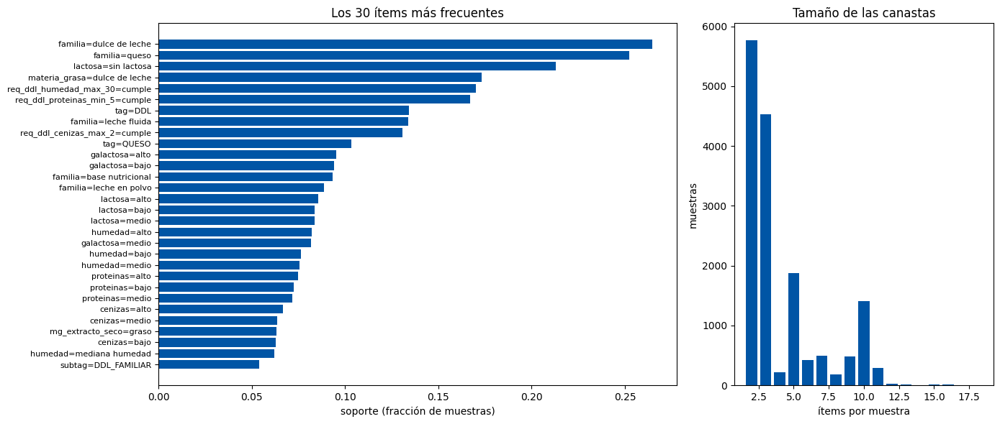

,acidez_naoh=alto,acidez_naoh=bajo,acidez_naoh=medio,acido_sorbico=alto,acido_sorbico=bajo,acido_sorbico=medio,actividad_agua=alto,actividad_agua=bajo,actividad_agua=medio,arsenico=detectado,...,subtag=POLVO_SUERO_PERMEADO,subtag=POLVO_SUERO_REENGRASADO,subtag=POLVO_WPC,sulfitos=no detectado / 0,tag=DDL,tag=LIQUIDO,tag=POLVO_GRASO,tag=POLVO_MAGRO,tag=PROT_ALTA,tag=QUESO
Identificador,,,,,,,,,,,,,,,,,,,,,
MO-01393-01,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
MO-01395-01,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
MO-01396-01,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
MO-01397-01,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
MO-01431-01,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [52]:
soportes = M.mean().sort_values(ascending=False)
print(f"Matriz Senasa: {M.shape[0]} transacciones × {M.shape[1]} ítems · ítems por muestra: {M.sum(axis=1).describe().round(1).to_dict()}")
fig, (a, b) = plt.subplots(1, 2, figsize=(14, 6), gridspec_kw={"width_ratios": [2, 1]})
top = soportes.head(30)
a.barh(top.index, top.values, color=AZUL); a.invert_yaxis(); a.set_xlabel("soporte (fracción de muestras)"); a.set_title("Los 30 ítems más frecuentes")
a.tick_params(axis="y", labelsize=8)
tam = M.sum(axis=1).value_counts().sort_index(); b.bar(tam.index, tam.values, color=AZUL)
b.set_xlabel("ítems por muestra"); b.set_ylabel("muestras"); b.set_title("Tamaño de las canastas")
plt.tight_layout(); plt.show()
M.head().astype(int)

#### 8 · Reglas de asociación (Senasa)

`fpgrowth` (da los mismos conjuntos que `apriori`, más rápido) con soporte mínimo 1 % (la celda imprime cuántas
transacciones son) y hasta 3 ítems; `association_rules` con confianza mínima 0,6.

Muchas reglas son triviales. `cz.filtrar_reglas` las marca:

- **mismo análisis**: el consecuente repite un análisis del antecedente (humedad=alto ⇒ req_ddl_humedad_max_30=no
  cumple repite la definición del corte);
- **cuenta**: la materia grasa en extracto seco junto con la grasa y la humedad, de las que se calcula;
- **define la familia**: materia_grasa=helado de crema ⇒ familia=helado (esa categoría solo existe en el helado);
- **familia redundante**: familia=queso junto con una categoría que solo existe en el queso;
- **cortes globales en la familia**: familia=X junto con un análisis que en X usa los cortes globales (familias chicas
  y muestras solo MQ): `cenizas=alto` de una muestra sin familia no se compara con el tercil de cada familia;
- **explicada por la familia o el panel**: la elevación global es alta solo porque la categoría es propia de una
  familia o porque los análisis se miden juntos (cenizas y proteínas van en el mismo panel). Se recalcula la elevación
  sobre las muestras que pueden tener la regla (las familias donde aparecen sus ítems, con sus análisis medidos):
  `lift_ajustado`. Si es menor que 1,2, la regla es trivial.

Las reglas útiles se ordenan por elevación (`lift`); al lado, `lift_ajustado`.

In [53]:
MIN_SOPORTE, MIN_CONFIANZA, MAX_LEN = 0.01, 0.6, 3
columnas = ["regla", "support", "confidence", "lift", "lift_ajustado", "familias"]

def reglas_de(M_):
    frec = fpgrowth(M_, min_support=MIN_SOPORTE, use_colnames=True, max_len=MAX_LEN)
    r = association_rules(frec, metric="confidence", min_threshold=MIN_CONFIANZA)
    r = cz.filtrar_reglas(r, M_)
    r["regla"] = [f"{nombre(a)} ⇒ {nombre(b)}" for a, b in zip(r["antecedents"], r["consequents"])]
    return frec, r      # los listados ordenan por elevación y desempatan por soporte y por texto: sin eso, el orden de los empates cambia entre corridas

frec, reglas = reglas_de(M)
print(f"Soporte mínimo {MIN_SOPORTE:.0%} de {len(M)} transacciones = {MIN_SOPORTE * len(M):.0f} muestras (Senasa) · y de {len(matrices['senasa_mq'])} = {MIN_SOPORTE * len(matrices['senasa_mq']):.0f} (Senasa + MQ)")
print(f"{len(frec)} conjuntos frecuentes (por tamaño: {frec['itemsets'].apply(len).value_counts().sort_index().to_dict()}) → {len(reglas)} reglas con confianza ≥ {MIN_CONFIANZA}")
print("Reglas por motivo:", reglas["motivo_trivial"].fillna("útil").value_counts().to_dict())
for m in ["mismo análisis", "cuenta", "define la familia", "familia redundante", "cortes globales en la familia", "explicada por la familia o el panel"]:
    ej = reglas[reglas["motivo_trivial"] == m].sort_values(["lift", "support", "regla"], ascending=[False, False, True], kind="mergesort")
    if len(ej):
        print(f"Triviales «{m}» (las 3 de mayor elevación):"); display(ej[columnas].head(3).round(3).reset_index(drop=True))

Soporte mínimo 1% de 15757 transacciones = 158 muestras (Senasa) · y de 27484 = 275 (Senasa + MQ)
741 conjuntos frecuentes (por tamaño: {1: 55, 2: 206, 3: 480}) → 1090 reglas con confianza ≥ 0.6
Reglas por motivo: {'explicada por la familia o el panel': 527, 'mismo análisis': 199, 'define la familia': 159, 'familia redundante': 113, 'útil': 85, 'cuenta': 7}
Triviales «mismo análisis» (las 3 de mayor elevación):


,regla,support,confidence,lift,lift_ajustado,familias
0,"{familia=concentrado proteico, tag=POLVO_MAGRO} ⇒ {subtag=POLVO_WPC}",0.017,0.993,56.883,1.177,concentrado proteico
1,"{subtag=POLVO_WPC} ⇒ {familia=concentrado proteico, tag=POLVO_MAGRO}",0.017,0.996,56.883,1.177,concentrado proteico
2,"{tag=POLVO_MAGRO} ⇒ {familia=concentrado proteico, subtag=POLVO_WPC}",0.017,0.818,46.865,1.380,concentrado proteico


Triviales «cuenta» (las 3 de mayor elevación):


,regla,support,confidence,lift,lift_ajustado,familias
0,"{materia_grasa=bajo, mg_extracto_seco=semigraso} ⇒ {humedad=alta humedad}",0.015,0.677,25.468,3.095,queso
1,"{humedad=alta humedad, materia_grasa=bajo} ⇒ {mg_extracto_seco=semigraso}",0.015,0.822,21.907,2.262,queso
2,"{humedad=alta humedad, mg_extracto_seco=semigraso} ⇒ {materia_grasa=bajo}",0.015,1.000,21.351,3.030,queso


Triviales «define la familia» (las 3 de mayor elevación):


,regla,support,confidence,lift,lift_ajustado,familias
0,{subtag=POLVO_WPC} ⇒ {familia=concentrado proteico},0.017,1.0,27.741,1.0,concentrado proteico
1,"{subtag=POLVO_WPC, tag=POLVO_MAGRO} ⇒ {familia=concentrado proteico}",0.017,1.0,27.741,1.0,concentrado proteico
2,{galactosa=no detectado / 0} ⇒ {familia=helado},0.020,1.0,23.413,1.0,helado


Triviales «familia redundante» (las 3 de mayor elevación):


,regla,support,confidence,lift,lift_ajustado,familias
0,"{familia=queso, materia_grasa=bajo} ⇒ {mg_extracto_seco=semigraso}",0.022,0.646,17.228,1.779,queso
1,"{familia=queso, humedad=alta humedad} ⇒ {materia_grasa=bajo}",0.018,0.683,14.574,2.434,queso
2,"{familia=queso, materia_grasa=medio} ⇒ {mg_extracto_seco=graso}",0.028,0.813,12.817,1.326,queso


Triviales «explicada por la familia o el panel» (las 3 de mayor elevación):


,regla,support,confidence,lift,lift_ajustado,familias
0,{tag=POLVO_MAGRO} ⇒ {familia=concentrado proteico},0.018,0.824,22.855,1.173,concentrado proteico
1,"{materia_grasa=alto, tag=QUESO} ⇒ {mg_extracto_seco=graso}",0.026,0.733,11.548,1.195,queso
2,{mg_extracto_seco=semigraso} ⇒ {tag=QUESO},0.038,1.000,9.685,1.000,queso


In [54]:
utiles = reglas[reglas["motivo_trivial"].isna()].sort_values(["lift", "support", "regla"], ascending=[False, False, True], kind="mergesort").reset_index(drop=True)
print(f"{len(utiles)} reglas no triviales, ordenadas por elevación:")
display(utiles[columnas].round(3))

85 reglas no triviales, ordenadas por elevación:


,regla,support,confidence,lift,lift_ajustado,familias
0,"{humedad=bajo, req_ddl_cenizas_max_2=cumple} ⇒ {subtag=DDL_REPOSTERO}",0.024,0.845,21.453,2.912,dulce de leche
1,"{subtag=DDL_REPOSTERO} ⇒ {humedad=bajo, req_ddl_cenizas_max_2=cumple}",0.024,0.617,21.453,2.912,dulce de leche
2,"{humedad=alta humedad} ⇒ {materia_grasa=bajo, tag=QUESO}",0.018,0.683,20.029,2.434,queso
3,"{cenizas=medio, humedad=bajo} ⇒ {subtag=DDL_REPOSTERO}",0.011,0.729,18.504,3.065,dulce de leche
4,"{humedad=baja humedad} ⇒ {materia_grasa=alto, tag=QUESO}",0.015,0.621,17.656,2.160,queso
5,"{humedad=alta humedad, tag=QUESO} ⇒ {mg_extracto_seco=semigraso}",0.015,0.660,17.600,1.817,queso
6,"{materia_grasa=bajo, tag=QUESO} ⇒ {mg_extracto_seco=semigraso}",0.022,0.646,17.228,1.779,queso
7,"{humedad=alta humedad, tag=QUESO} ⇒ {materia_grasa=bajo}",0.018,0.803,17.153,2.434,queso
8,"{humedad=baja humedad, tag=QUESO} ⇒ {mg_extracto_seco=semigraso}",0.013,0.631,16.817,1.736,queso
9,"{cenizas=bajo, humedad=bajo} ⇒ {subtag=DDL_REPOSTERO}",0.011,0.602,15.278,2.820,dulce de leche


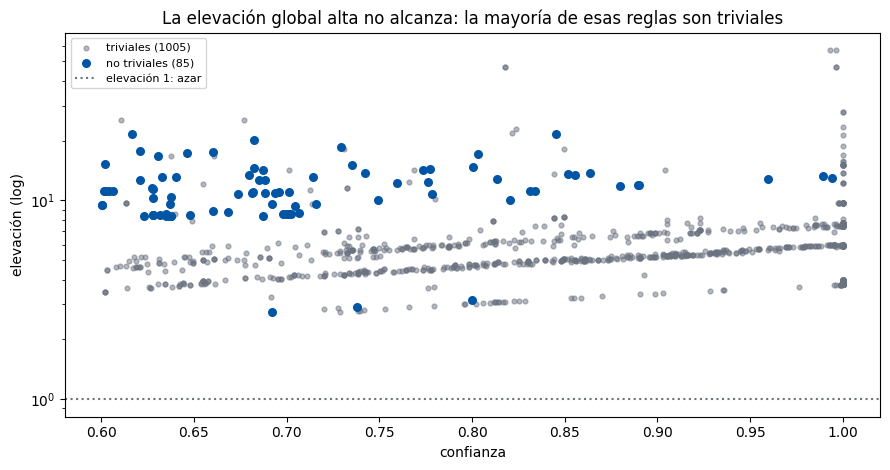

In [55]:
fig, ax = plt.subplots(figsize=(9, 4.8))
tr = reglas["motivo_trivial"].notna()
ax.scatter(reglas.loc[tr, "confidence"], reglas.loc[tr, "lift"], s=12, alpha=0.5, color=GRIS, label=f"triviales ({tr.sum()})")
ax.scatter(reglas.loc[~tr, "confidence"], reglas.loc[~tr, "lift"], s=30, color=AZUL, label=f"no triviales ({(~tr).sum()})")
ax.axhline(1, color=GRIS, ls=":", label="elevación 1: azar"); ax.set_yscale("log")
ax.set_xlabel("confianza"); ax.set_ylabel("elevación (log)"); ax.legend(fontsize=8)
ax.set_title("La elevación global alta no alcanza: la mayoría de esas reglas son triviales")
plt.tight_layout(); plt.show()

#### 9 · Reglas con Senasa + MQ

Las muestras solo MQ llevan la familia de MQ encolumnado (la asigna un modelo o, si el modelo no decide y la descripción es clara, una regla por descripción; no está revisada a mano). En las familias con terciles por estado (sección 5) cada muestra se compara con las de su mismo estado. Las «sin clasificar» usan los cortes globales y solo tienen los cuatro análisis principales.

In [56]:
M2 = matrices["senasa_mq"]
frec2, reglas2 = reglas_de(M2)
print(f"Senasa + MQ: {M2.shape[0]} transacciones × {M2.shape[1]} ítems · {len(frec2)} frecuentes → {len(reglas2)} reglas")
print("Reglas por motivo:", reglas2["motivo_trivial"].fillna("útil").value_counts().to_dict())
utiles2 = reglas2[reglas2["motivo_trivial"].isna()].sort_values(["lift", "support", "regla"], ascending=[False, False, True], kind="mergesort").reset_index(drop=True)
display(utiles2[columnas].head(20).round(3))
nuevas = sorted(set(utiles2["regla"]) - set(utiles["regla"]))
print(f"Reglas útiles que aparecen con MQ y no solo con Senasa: {len(nuevas)} (las primeras 15):")
for r in nuevas[:15]:
    print("   ", r)

Senasa + MQ: 27484 transacciones × 123 ítems · 694 frecuentes → 913 reglas
Reglas por motivo: {'explicada por la familia o el panel': 411, 'mismo análisis': 152, 'define la familia': 131, 'útil': 121, 'familia redundante': 94, 'cuenta': 3, 'cortes globales en la familia': 1}


,regla,support,confidence,lift,lift_ajustado,familias
0,"{materia_grasa=entera, proteinas=medio} ⇒ {tag=POLVO_GRASO}",0.016,0.863,36.816,1.274,leche en polvo; yogur / bebida lactea
1,"{tag=POLVO_GRASO} ⇒ {materia_grasa=entera, proteinas=medio}",0.016,0.693,36.816,1.274,leche en polvo; yogur / bebida lactea
2,"{humedad=bajo, req_ddl_cenizas_max_2=cumple} ⇒ {subtag=DDL_REPOSTERO}",0.014,0.841,35.793,2.919,dulce de leche
3,"{subtag=POLVO_LECHE_ENTERA} ⇒ {familia=leche en polvo, proteinas=medio}",0.017,0.732,30.264,2.158,leche en polvo
4,"{tag=POLVO_GRASO} ⇒ {familia=leche en polvo, proteinas=medio}",0.017,0.707,29.200,2.230,leche en polvo
5,"{cenizas=medio, materia_grasa=entera} ⇒ {tag=POLVO_GRASO}",0.011,0.662,28.235,1.276,leche en polvo; yogur / bebida lactea
6,"{subtag=POLVO_WPC, tag=POLVO_MAGRO} ⇒ {familia=concentrado proteico}",0.010,0.932,27.538,10.272,concentrado proteico
7,{subtag=POLVO_WPC} ⇒ {familia=concentrado proteico},0.010,0.926,27.360,10.433,concentrado proteico
8,"{subtag=POLVO_LECHE_ENTERA} ⇒ {humedad=bajo, proteinas=medio}",0.014,0.637,24.185,1.899,4 familias
9,"{subtag=DDL_FAMILIAR} ⇒ {humedad=alto, req_ddl_cenizas_max_2=cumple}",0.022,0.701,24.050,1.973,dulce de leche


Reglas útiles que aparecen con MQ y no solo con Senasa: 72 (las primeras 15):
    {cenizas=bajo, humedad=medio} ⇒ {familia=dulce de leche}
    {cenizas=bajo, materia_grasa=entera} ⇒ {humedad=bajo}
    {cenizas=medio, humedad=alto} ⇒ {familia=dulce de leche}
    {cenizas=medio, humedad=medio} ⇒ {familia=dulce de leche}
    {cenizas=medio, materia_grasa=entera} ⇒ {familia=leche en polvo}
    {cenizas=medio, materia_grasa=entera} ⇒ {humedad=bajo}
    {cenizas=medio, materia_grasa=entera} ⇒ {tag=POLVO_GRASO}
    {cenizas=medio, proteinas=alto} ⇒ {familia=dulce de leche}
    {cenizas=medio, subtag=POLVO_LECHE_ENTERA} ⇒ {familia=leche en polvo}
    {cenizas=medio, tag=POLVO_GRASO} ⇒ {familia=leche en polvo}
    {cenizas=medio, tag=POLVO_GRASO} ⇒ {materia_grasa=entera}
    {familia=dulce de leche, subtag=DDL_REPOSTERO} ⇒ {humedad=bajo}
    {familia=dulce de leche, subtag=DDL_REPOSTERO} ⇒ {proteinas=alto}
    {familia=leche en polvo, humedad=bajo} ⇒ {materia_grasa=entera}
    {familia=leche en

#### 10 · Lo que queda abierto

- Las categorías por terciles son relativas a la familia: `humedad=alto` no es el mismo número en el queso que en el
  dulce de leche. Por eso las reglas que mezclan familias se leen con `lift_ajustado`.
- El soporte mínimo de 1 % deja afuera a las familias chicas (manteca, helado, yogur). Para ellas conviene correr las
  reglas dentro de cada familia.
- Por la misma razón, no todos los subtags llegan al 1 % de las transacciones: quedan afuera los polvos chicos y, según
  la versión, hasta algún subtag del DDL. La celda de abajo cuenta cuáles entran y cuáles
  no, en cada versión. Para ver las reglas de los que quedan afuera hay que correrlas dentro de la familia o bajar el
  soporte.
- Las decisiones de `cortes_categorias.md` siguen abiertas (bases de la leche fluida, del yogur y del helado; lactosa con
  referencia 4,83; cortes globales en las familias chicas y en las muestras sin familia; dulce de leche con grasa < 6).
  Se cambian en las constantes de `categorizar.py`.

In [57]:
for version, Mx in [("senasa", M), ("senasa_mq", M2)]:
    corte = MIN_SOPORTE * len(Mx)
    n_sub = Mx[[c for c in Mx.columns if c.startswith("subtag=")]].sum().sort_values(ascending=False)
    n_sub.index = n_sub.index.str.replace("subtag=", "", regex=False)
    print(f"{version} (corte: {corte:.0f} de {len(Mx)} transacciones)")
    print("   entran:   ", ", ".join(f"{k} ({v})" for k, v in n_sub[n_sub >= corte].items()))
    print("   quedan afuera:", ", ".join(f"{k} ({v})" for k, v in n_sub[n_sub < corte].items()))

senasa (corte: 158 de 15757 transacciones)
   entran:    DDL_FAMILIAR (854), DDL_REPOSTERO (621), POLVO_WPC (275)
   quedan afuera: DDL_HELADERO (157), POLVO_LECHE_ENTERA (72), POLVO_CASEINATO (39), POLVO_SUERO_PERMEADO (32), POLVO_LECHE_DESCREMADA (29), POLVO_SUERO_REENGRASADO (8), POLVO_CONCENTRADO (5)
senasa_mq (corte: 275 de 27484 transacciones)
   entran:    DDL_FAMILIAR (876), DDL_REPOSTERO (646), POLVO_LECHE_ENTERA (620), POLVO_WPC (310)
   quedan afuera: DDL_HELADERO (177), POLVO_LECHE_DESCREMADA (73), POLVO_SUERO_DESMINERALIZADO (70), POLVO_CASEINATO (40), POLVO_SUERO_REENGRASADO (15)


### 7 · MQ con el formato de Senasa encolumnado
`src/mq_encolumnado.py` (ex `build_mq_encolumnado.py`) pone las muestras de tipo MQ con las 177 columnas de
`Senasa encolumnado.xlsx` (más los analitos que solo tiene MQ), para sumarlas al entrenamiento del modelo supervisado.
Usa los crudos de `datos_entrada/mq/crudos/`, `muestras_ancha.csv`, `mq_tipo_muestra.csv` y el extractor de
`src/compartido/Filtrado_de_Datos_2_ordenado.ipynb`; lo que escribe pasa por `src/compartido/anonimizar.py`.
Con `REGENERAR_MQ = False` (por defecto) solo lee los dos Excel ya generados.

La familia de las muestras nuevas la asigna un modelo. Las que el modelo deja «sin clasificar» pasan por las reglas de
`src/reglas_descripcion.py`: si la descripción nombra un producto de una sola familia (crema, manteca, ricota, WPC,
salame...) se clasifica; si es ambigua, queda «sin clasificar». `desc_familia_fuente` dice de dónde sale cada familia.

In [58]:
import mq_encolumnado
mq_todas, mq_nuevas = mq_encolumnado.armar(REGENERAR_MQ)
print(f"MQ encolumnado: {mq_todas.shape} · solo nuevas: {mq_nuevas.shape}")
display(mq_todas["desc_familia"].value_counts().rename("muestras MQ").to_frame()
        .join(mq_nuevas["desc_familia"].value_counts().rename("nuevas (no están en Senasa)")).fillna(0).astype(int))
display(mq_nuevas["desc_familia_fuente"].value_counts().rename("muestras nuevas").to_frame())

AVISO: falta datos/marcas_privadas.txt; sin lista negra de marcas.


Leídos (sin regenerar): MQ encolumnado.xlsx (15821, 199) · MQ encolumnado - solo nuevas.xlsx (13742, 199)
MQ encolumnado: (15821, 199) · solo nuevas: (13742, 199)


,muestras MQ,nuevas (no están en Senasa)
desc_familia,,
leche en polvo,4485,4231
queso,3101,3037
suero / permeado,1590,1342
sin clasificar,1282,1280
manteca / crema,1185,1181
dulce de leche,1160,112
leche fluida,1020,830
yogur / bebida lactea,565,538
concentrado proteico,542,460


,muestras nuevas
desc_familia_fuente,
modelo,11132
sin clasificar,1280
regla por descripción: crema,830
regla por descripción: carnicos,131
regla por descripción: ricota,81
regla por descripción: harina / cereal / lactosa,77
regla por descripción: soja,62
regla por descripción: manteca,57
regla por descripción: wpc,43


#### 7.1 · Lo declarado contra la humedad medida
`src/declarado_vs_medido.py` compara lo que la clasificación afirma sobre la humedad con el resultado: la consistencia
del queso (baja / mediana / alta, donde «alta» incluye «muy alta») contra la clase del CAA art. 605, y el estado
(polvo ≤ 15, líquido ≥ 25). «borde» es quedar fuera de la clase por 1 g/100 g o menos. El detalle de las que no
coinciden queda en `resultados/excel/declarado_vs_medido.xlsx`.

In [59]:
import declarado_vs_medido
dvm, dvm_resumen = declarado_vs_medido.armar()
display(dvm_resumen)
q = dvm[dvm["eje"] == "consistencia del queso"]
display(q.groupby(["origen", "origen_declarado"]).agg(muestras=("coincide", "size"), coincide=("coincide", "mean"))
        .assign(coincide=lambda t: (100 * t["coincide"]).round(1)).rename(columns={"coincide": "% coincide"}))

6502 comparaciones (347 no coinciden) -> declarado_vs_medido.csv, declarado_vs_medido.xlsx


,eje,origen,declarado,muestras,coincide,borde,no coincide,% coincide,% coincide o borde
0,consistencia del queso,MQ nueva (automática),TOTAL,1399,1200,72,127,85.8,90.9
1,consistencia del queso,MQ nueva (automática),alta humedad,562,499,24,39,88.8,93.1
2,consistencia del queso,MQ nueva (automática),baja humedad,363,305,13,45,84.0,87.6
3,consistencia del queso,MQ nueva (automática),mediana humedad,474,396,35,43,83.5,90.9
4,consistencia del queso,Senasa (manual),TOTAL,1706,1590,66,50,93.2,97.1
5,consistencia del queso,Senasa (manual),alta humedad,424,362,25,37,85.4,91.3
6,consistencia del queso,Senasa (manual),baja humedad,356,351,4,1,98.6,99.7
7,consistencia del queso,Senasa (manual),mediana humedad,926,877,37,12,94.7,98.7
8,estado,MQ nueva (automática),LIQUIDO,1046,1045,0,1,99.9,99.9
9,estado,MQ nueva (automática),POLVO,1953,1928,0,25,98.7,98.7


muestras  % coincide
origen                origen_declarado                      
MQ nueva (automática) formato                125        95.2
                      rotulo                  71        59.2
                      variedad              1203        86.4
Senasa (manual)       formato                102       100.0
                      rotulo                 256       100.0
                      variedad              1348        91.4

### 8 · Datos usados en cada entrenamiento
Cuántas muestras entran a cada modelo que se entrena en este cuaderno, con la misma tabla que en los demás cuadernos:
cuántas hay antes de los filtros propios del modelo, cuántas se excluyen y por qué, cuántas se usan y cómo se reparten
entre entrenamiento, validación y prueba. Los números salen de las variables de las secciones 3, 4 y 6 (no están escritos
a mano). Una fila por modelo y por población (solo Senasa; Senasa + MQ). Los agrupamientos no tienen prueba: se ajustan
con todas las muestras que usan. La tabla también se guarda en `resultados/datos_entrenamiento/trabajo_senasa_mq.csv`.

In [60]:
import datos_entrenamiento as DE

ETIQUETAS = {"senasa": "solo Senasa", "senasa_mq": "Senasa + MQ"}
SIN_PARTICION = "sin partición: se ajusta con todas las muestras que usa"
filas = []
for clave, etiqueta in ETIQUETAS.items():
    e = ENTRENOS[clave]
    origen = "muestras de Senasa" if clave == "senasa" else "muestras de Senasa y de MQ"
    umbral = str(N.UMBRAL_DDL).replace(".", ",")
    filas += [
        DE.fila("I", f"k-medias preliminar y consenso de outliers, {etiqueta}", f"{origen} con los cuatro análisis (humedad, grasa, proteínas y cenizas)",
                e["inicial"], e["pre"],
                motivo=(f"{e['n_hs']} con humedad + sólidos incoherentes; {e['n_nolact']} de familias no lácteas; {e['n_quesos']} quesos (van a su rama); "
                        f"{e['n_sin4']} sin los cuatro análisis; {e['n_suma']} suman más de {SUMA_MAX}"),
                particion=SIN_PARTICION,
                nota=(f"k-medias preliminar con k = {e['k_pre']} (silueta, {N_INIT_KMEDIAS} reinicios, semilla {SEMILLA}); el consenso (factor local, bosque de "
                      f"aislamiento y elipse, 2 de 3 votos, dentro de cada grupo preliminar) marca {e['n_out']} outliers")),
        DE.fila("I", f"k-medias final, {etiqueta}", "muestras del k-medias preliminar sin los outliers", e["pre"], e["final"],
                motivo=f"{e['n_out']} outliers por consenso", particion=SIN_PARTICION,
                nota=f"k = {e['k']} por silueta máxima ({e['silueta']:.3f}); {N_INIT_KMEDIAS} reinicios, semilla {SEMILLA}"),
        DE.fila("I", f"segundo nivel del DDL: regresión logística, {etiqueta}", "muestras con tag DDL del k-medias final", e["ddl_n"], e["ddl_lab"],
                motivo="sin subtipo conocido: no se usan para ajustar (el modelo les propone un subtag)",
                particion="sin partición en este cuaderno (se ajusta con todas las que tienen subtipo); la validación por cliente, con clientes no vistos, está en prueba_subtipo_ddl.ipynb",
                nota=(f"subtipo conocido por clase: {e['ddl_clases']}; decide en {e['ddl_decide']} de {e['ddl_n']} (probabilidad ≥ {umbral} y sin novedad; "
                      f"la novedad se detecta con Mahalanobis robusta y LOF)")),
        DE.fila("I", f"segundo nivel de polvos: k-medias en base seca, {etiqueta}", "muestras con tag POLVO_GRASO, POLVO_MAGRO o PROT_ALTA",
                e["pol_tag"], e["pol_rama"] - e["pol_out"],
                motivo=f"{e['pol_tag'] - e['pol_rama']} con humedad > 15 (no son polvo); {e['pol_out']} outliers de la rama (consenso)",
                particion=SIN_PARTICION,
                nota=(f"k = {e['pol_k']} por silueta ({e['pol_sil']:.2f}) en grasa, proteína y cenizas en base seca; además dos reglas de composición "
                      f"(leche descremada y suero reengrasado) que no se entrenan")),
        DE.fila("I", f"rama de queso: regla del CAA, no se entrena, {etiqueta}", "quesos que confirma el catálogo", e["q_leidos"], e["q_rama"],
                motivo=(f"{e['q_leidos'] - e['q_mgst']} sin materia grasa o sin sólidos totales; {e['q_mgst'] - e['q_rama']} imposibles "
                        f"(MG > ST o humedad + sólidos fuera de 100 ± 1)"),
                entrenamiento=0, particion="no se entrena: el subtag sale de la clase de humedad del CAA (art. 605)",
                nota=(f"entran las {e['q_rama']}, sin quitar outliers" +
                      (f"; {e['q_sin_confirmar']} solo MQ de familia queso que el rótulo no confirma no entran" if e["q_sin_confirmar"] else ""))),
        DE.fila("I", f"quesos sin tag previo: k-medias y mezcla de gaussianas, {etiqueta}", "quesos de la rama (humedad y MGES)", e["q_rama"], e["q_base"],
                motivo=f"{e['q_out']} outliers por consenso", particion=SIN_PARTICION + "; estabilidad con 10 semillas",
                nota=f"k-medias con k = {e['q_k_km']} (silueta) y mezcla con k = {e['q_k_gm']} (BIC); es un ensayo, no un modelo guardado"),
    ]
    if e["comparacion"]:
        filas.append(DE.fila("I", f"comparación de algoritmos (k-medias sin escalar, minilotes, Ward, enlaces, bisectivo), {etiqueta}",
                             "muestras del k-medias final", e["pre"], e["final"], motivo=f"{e['n_out']} outliers por consenso", particion=SIN_PARTICION,
                             nota=(f"ninguno se guarda: se comparan con el k-medias final (k = {e['k']}); la sección 3 no los repite. Entran también las 40 corridas "
                                   f"de A.2 (inicialización al azar contra k-means++)")))
for clave, etiqueta, mx, fr, rg in [("senasa", "solo Senasa", matrices["senasa"], frec, reglas), ("senasa_mq", "Senasa + MQ", matrices["senasa_mq"], frec2, reglas2)]:
    tv = tablas[clave]
    filas.append(DE.fila("I", f"reglas de asociación (FP-growth), {etiqueta}", "muestras con ítems (categorías de los análisis, familia, tag y subtag)", len(tv), len(mx),
                         motivo=f"{len(tv) - len(mx)} sin ningún ítem: no son transacciones (hay {int(tv['excluida'].sum())} excluidas por humedad + sólidos, que pierden los ítems de sus análisis)",
                         particion="sin partición: las reglas se buscan en todas las transacciones",
                         nota=(f"soporte mínimo {MIN_SOPORTE:.0%}, hasta {MAX_LEN} ítems, confianza ≥ {str(MIN_CONFIANZA).replace('.', ',')}: "
                               f"{len(fr)} conjuntos frecuentes y {len(rg)} reglas, {int(rg['motivo_trivial'].isna().sum())} no triviales")))
display(DE.guardar(filas, "trabajo_senasa_mq"))

,parte,modelo,datos,disponibles,excluidas,motivo de exclusión,usadas,entrenamiento,validación,prueba,partición,nota
0,I,"k-medias preliminar y consenso de outliers, solo Senasa","muestras de Senasa con los cuatro análisis (humedad, grasa, proteínas y cenizas)",16347,13687,8 con humedad + sólidos incoherentes; 1727 de familias no lácteas; 4006 quesos (van a su rama); 7946 sin l...,2660,2660,<NA>,<NA>,sin partición: se ajusta con todas las muestras que usa,"k-medias preliminar con k = 5 (silueta, 50 reinicios, semilla 42); el consenso (factor local, bosque de ai..."
1,I,"k-medias final, solo Senasa",muestras del k-medias preliminar sin los outliers,2660,63,63 outliers por consenso,2597,2597,<NA>,<NA>,sin partición: se ajusta con todas las muestras que usa,"k = 5 por silueta máxima (0.854); 50 reinicios, semilla 42"
2,I,"segundo nivel del DDL: regresión logística, solo Senasa",muestras con tag DDL del k-medias final,2116,595,sin subtipo conocido: no se usan para ajustar (el modelo les propone un subtag),1521,1521,<NA>,<NA>,"sin partición en este cuaderno (se ajusta con todas las que tienen subtipo); la validación por cliente, co...","subtipo conocido por clase: {'FAMILIAR': 749, 'REPOSTERO': 620, 'HELADERO': 152}; decide en 1632 de 2116 (..."
3,I,"segundo nivel de polvos: k-medias en base seca, solo Senasa","muestras con tag POLVO_GRASO, POLVO_MAGRO o PROT_ALTA",471,8,0 con humedad > 15 (no son polvo); 8 outliers de la rama (consenso),463,463,<NA>,<NA>,sin partición: se ajusta con todas las muestras que usa,"k = 8 por silueta (0.73) en grasa, proteína y cenizas en base seca; además dos reglas de composición (lech..."
4,I,"rama de queso: regla del CAA, no se entrena, solo Senasa",quesos que confirma el catálogo,4006,2379,2379 sin materia grasa o sin sólidos totales; 0 imposibles (MG > ST o humedad + sólidos fuera de 100 ± 1),1627,0,<NA>,<NA>,no se entrena: el subtag sale de la clase de humedad del CAA (art. 605),"entran las 1627, sin quitar outliers"
5,I,"quesos sin tag previo: k-medias y mezcla de gaussianas, solo Senasa",quesos de la rama (humedad y MGES),1627,43,43 outliers por consenso,1584,1584,<NA>,<NA>,sin partición: se ajusta con todas las muestras que usa; estabilidad con 10 semillas,"k-medias con k = 5 (silueta) y mezcla con k = 7 (BIC); es un ensayo, no un modelo guardado"
6,I,"k-medias preliminar y consenso de outliers, Senasa + MQ","muestras de Senasa y de MQ con los cuatro análisis (humedad, grasa, proteínas y cenizas)",30089,26152,8 con humedad + sólidos incoherentes; 2319 de familias no lácteas; 5915 quesos (van a su rama); 17907 sin ...,3937,3937,<NA>,<NA>,sin partición: se ajusta con todas las muestras que usa,"k-medias preliminar con k = 5 (silueta, 50 reinicios, semilla 42); el consenso (factor local, bosque de ai..."
7,I,"k-medias final, Senasa + MQ",muestras del k-medias preliminar sin los outliers,3937,101,101 outliers por consenso,3836,3836,<NA>,<NA>,sin partición: se ajusta con todas las muestras que usa,"k = 5 por silueta máxima (0.835); 50 reinicios, semilla 42"
8,I,"segundo nivel del DDL: regresión logística, Senasa + MQ",muestras con tag DDL del k-medias final,2226,625,sin subtipo conocido: no se usan para ajustar (el modelo les propone un subtag),1601,1601,<NA>,<NA>,"sin partición en este cuaderno (se ajusta con todas las que tienen subtipo); la validación por cliente, co...","subtipo conocido por clase: {'FAMILIAR': 789, 'REPOSTERO': 637, 'HELADERO': 175}; decide en 1699 de 2226 (..."
9,I,"segundo nivel de polvos: k-medias en base seca, Senasa + MQ","muestras con tag POLVO_GRASO, POLVO_MAGRO o PROT_ALTA",1156,18,2 con humedad > 15 (no son polvo); 16 outliers de la rama (consenso),1138,1138,<NA>,<NA>,sin partición: se ajusta con todas las muestras que usa,"k = 7 por silueta (0.77) en grasa, proteína y cenizas en base seca; además dos reglas de composición (lech..."


### 9 · Verificación
Que estén todas las salidas, con su forma y su huella (sha256), y que sean coherentes entre sí: el tag de cada muestra
en `clusters_*.csv` es el del modelo guardado, y el subtag el que dan los modelos del segundo nivel del joblib; las tablas de categorías tienen una fila por muestra de Senasa (o de
Senasa + MQ), y MQ encolumnado empieza con las 177 columnas de Senasa encolumnado.

In [61]:
import hashlib
import joblib
import segundo_nivel

def huella(p):
    return hashlib.sha256(p.read_bytes()).hexdigest()[:12]

salidas = {
    "excel/dataset_senasa_revision.xlsx": None, "excel/dataset_senasa_mq_revision.xlsx": None,
    "excel/MQ encolumnado.xlsx": None, "excel/MQ encolumnado - solo nuevas.xlsx": None,
    "tablas/clusters_senasa.csv": None, "tablas/clusters_senasa_mq.csv": None, "tablas/cortes_categorias.csv": None,
    "tablas/categorias_senasa.csv": None, "tablas/categorias_senasa_mq.csv": None,
    "tablas/declarado_vs_medido.csv": None, "excel/declarado_vs_medido.xlsx": None,
    "tablas/transacciones_senasa.parquet": None, "tablas/transacciones_senasa_mq.parquet": None,
    "modelos/agrupamiento_senasa_clase41.joblib": None, "modelos/agrupamiento_senasa_mq_clase41.joblib": None,
}
filas = []
for rel in salidas:
    p = R.RESULTADOS / rel
    assert p.exists(), f"falta {rel}"
    if p.suffix == ".csv":
        forma = pd.read_csv(p, low_memory=False).shape
    elif p.suffix == ".parquet":
        forma = pd.read_parquet(p).shape
    elif p.suffix == ".xlsx":
        forma = {h: d.shape for h, d in pd.read_excel(p, sheet_name=None).items()}
    else:
        forma = "-"
    filas.append({"salida": rel, "forma": str(forma), "bytes": p.stat().st_size, "sha256 (12)": huella(p)})
display(pd.DataFrame(filas))

for v, archivo in [("senasa", "agrupamiento_senasa_clase41.joblib"), ("senasa_mq", "agrupamiento_senasa_mq_clase41.joblib")]:
    cl = pd.read_csv(R.TABLAS / f"clusters_{v}.csv", encoding="utf-8-sig")
    m = joblib.load(R.MODELOS / archivo)
    con = cl.dropna(subset=["cluster"])
    assert (con["cluster"].astype(int).map(m["tags"]) == con["tag"]).all(), v
    assert cl.loc[cl["outlier"], "tag"].isna().all() and cl.loc[cl["outlier"], "subtag"].isna().all(), v
    assert con["subtag"].notna().all(), v
    q = cl[cl["rama"] == "queso (humedad y MG)"]            # la rama de queso: sin cluster, tag QUESO, subtag por humedad del CAA
    assert q["cluster"].isna().all() and (q["tag"] == "QUESO").all() and not q["outlier"].any(), v
    assert (q["subtag"].to_numpy() == segundo_nivel.subtag_queso(q["humedad"])).all(), v
    assert not set(q["Identificador"]) & set(con["Identificador"]), f"{v}: un queso en el k-medias y en la rama"
    assert len(q) + len(con) + int(cl["outlier"].sum()) == len(cl), v
    sn = m["segundo_nivel"]
    out_polvo = con["Identificador"].isin(sn.get("polvo", {}).get("outliers", [])).to_numpy()
    sub, crit = segundo_nivel.predecir(sn, con[COLUMNAS], con["tag"], out_polvo)
    assert (sub == con["subtag"].to_numpy()).all() and (crit == con["criterio_subtag"].to_numpy()).all(), v
    cat = pd.read_csv(R.TABLAS / f"categorias_{v}.csv", encoding="utf-8-sig", low_memory=False)
    assert cat["Identificador"].is_unique, v
    print(f"{v}: {len(con)} muestras con tag {sorted(m['tags'].values())} · subtags {sorted(set(con['subtag']) - set(con['tag']))} · "
          f"{int(cl['outlier'].sum())} outliers · {len(q)} quesos en su rama {q['subtag'].value_counts().to_dict()} · categorías {cat.shape}")
assert len(pd.read_csv(R.TABLAS / "categorias_senasa.csv", encoding="utf-8-sig", low_memory=False)) == len(S.crudo)
cols_senasa = list(pd.read_excel(R.SENASA, nrows=0).columns)
for d in (mq_todas, mq_nuevas):
    assert list(d.columns[:177]) == cols_senasa
sin = mq_nuevas["desc_familia"].eq("sin clasificar")
assert (mq_nuevas.loc[sin, "desc_familia_fuente"] == "sin clasificar").all() and not (mq_nuevas.loc[~sin, "desc_familia_fuente"] == "sin clasificar").any()
ce = cortes[cortes["estado"].fillna("").ne("")]
assert set(ce["familia"]) <= set(cortes_caa.FAMILIAS_CON_ESTADO) and set(ce["estado"]) <= set(cortes_caa.ESTADOS)
print("Verificación: todo en orden.")

,salida,forma,bytes,sha256 (12)
0,excel/dataset_senasa_revision.xlsx,"{'dataset': (16347, 43), 'inconsistencias': (161, 6), 'resumen': (44, 7), 'notas': (34, 3)}",2920253,37a3dee8331e
1,excel/dataset_senasa_mq_revision.xlsx,"{'dataset': (30089, 55), 'inconsistencias': (924, 7), 'resumen': (53, 10), 'notas': (41, 3)}",5598870,dc1a6e030e8b
2,excel/MQ encolumnado.xlsx,"{'Sheet1': (15821, 199)}",8531221,e70d29ae636c
3,excel/MQ encolumnado - solo nuevas.xlsx,"{'Sheet1': (13742, 199)}",7375957,d6a890c28ebb
4,tablas/clusters_senasa.csv,"(4287, 18)",592607,ca033364c262
5,tablas/clusters_senasa_mq.csv,"(6828, 18)",934855,d3cadab8aff1
6,tablas/cortes_categorias.csv,"(361, 11)",58750,bf5026bf6a53
7,tablas/categorias_senasa.csv,"(16347, 87)",5759568,52134b53b73e
8,tablas/categorias_senasa_mq.csv,"(30089, 87)",9855394,318ab5ffb5c2
9,tablas/declarado_vs_medido.csv,"(6502, 15)",1283108,1f417ddb9e56


senasa: 2597 muestras con tag ['DDL', 'LIQUIDO', 'POLVO_GRASO', 'POLVO_MAGRO', 'PROT_ALTA'] · subtags ['DDL_FAMILIAR', 'DDL_HELADERO', 'DDL_REPOSTERO', 'POLVO_CASEINATO', 'POLVO_CONCENTRADO', 'POLVO_LECHE_DESCREMADA', 'POLVO_LECHE_ENTERA', 'POLVO_SUERO_PERMEADO', 'POLVO_SUERO_REENGRASADO', 'POLVO_WPC'] · 63 outliers · 1627 quesos en su rama {'QUESO_SEMIDURO': 793, 'QUESO_PASTA_BLANDA': 358, 'QUESO_DURO': 325, 'QUESO_MUY_ALTA_HUMEDAD': 151} · categorías (16347, 87)
senasa_mq: 3836 muestras con tag ['DDL', 'LIQUIDO', 'POLVO_GRASO', 'POLVO_MAGRO', 'PROT_ALTA'] · subtags ['DDL_FAMILIAR', 'DDL_HELADERO', 'DDL_REPOSTERO', 'POLVO_CASEINATO', 'POLVO_LECHE_DESCREMADA', 'POLVO_LECHE_ENTERA', 'POLVO_SUERO_DESMINERALIZADO', 'POLVO_SUERO_REENGRASADO', 'POLVO_WPC'] · 101 outliers · 2891 quesos en su rama {'QUESO_SEMIDURO': 1195, 'QUESO_PASTA_BLANDA': 693, 'QUESO_DURO': 539, 'QUESO_MUY_ALTA_HUMEDAD': 464} · categorías (30089, 87)


Verificación: todo en orden.


<a id="parte-ii"></a>

# Parte II · Clustering con números contra clustering con categorías

Las mismas muestras de la Parte I, agrupadas con k-modas sobre los análisis pasados a categorías, y comparadas con el k-medias.

*(Generada a partir de `comparacion_numerico_categorico.ipynb`.)*

## Clustering con números contra clustering con categorías
**Trabajo Senasa + MQ · UNRaf · 2026**

Dos algoritmos sobre **las mismas muestras**: las que entran al k-medias actual (secciones 3 y 4 de
la Parte I (`trabajo_senasa_mq.ipynb`): humedad, grasa, proteínas y cenizas completas, suma ≤ 102, sin los outliers por consenso), en las dos
versiones (solo Senasa y Senasa + MQ). Las familias no lácteas (cárnicos, panificados / otros, agua / hisopado, base
nutricional) ya vienen excluidas de esos CSV, y los quesos que confirma el catálogo tampoco están: van a su rama propia
(humedad y materia grasa), sin cluster, y esta comparación solo toma las filas con cluster.

| | numérico | categórico |
|---|---|---|
| entrada | los cuatro análisis en g/100 g, escalados | los mismos cuatro análisis pasados a categorías (`cat_*`) |
| algoritmo | k-medias (euclídea) | k-modas (Hamming); como control, aglomerativo con Hamming y k-medias sobre one-hot |
| k | el de la clase 41 (por silueta: 5 en las dos versiones) | **fijo en 5** en las dos versiones: el mismo k que el numérico y que el codo de solo Senasa (se explica en la sección 3); k = 6 se muestra solo como sensibilidad |

Las categorías van en dos variantes, porque los cortes de `cortes_categorias.csv` dependen de la familia:

- **(a) con familia**: las `cat_*` de `categorias_*.csv`, tal cual. «humedad = alto» es el tercio de arriba **dentro de
  su familia** (en un polvo, más de ~4 %; en un dulce de leche, más de ~29 %), y algunas clases del CAA existen solo en
  una familia (grasa «dulce de leche», «entera», humedad del queso). La categoría ya trae información de la familia:
  es una **fuga** si después se compara contra la familia.
- **(b) globales**: los mismos cortes para todas las muestras: los cortes «*» de `cortes_categorias.csv` (terciles
  sobre todo Senasa), sin familia.

**Familia, tag y subtipo no entran en ningún algoritmo**: quedan aparte, solo para evaluar.

Secciones: 0 preparación · 1 las muestras y las dos variantes de categorías · 2 el numérico reproducido · 3 el k del
categórico (fijo en 5) y su estabilidad · 4 tabla comparativa · 5 tags numéricos contra clusters categóricos · 6 perfil y tag de cada cluster
categórico · 7 subtipos · 8 control con otros algoritmos categóricos · 9 muestras incompletas («no medido») ·
10 guardar · 11 datos usados en cada entrenamiento · Conclusión (sus números se calculan en la propia celda).

### 0 · Preparación
Rutas de `src/rutas.py`, semilla 42. Se verifica si el paquete `kmodes` está en el entorno: **no está, y no se
instala**. Por eso el k-modas es una implementación corta en numpy dentro de `src/clustering_categorico.py` (el
algoritmo de Huang, 1998, el mismo que usa `kmodes` con `init="Huang"`), y los controles salen de sklearn
(`AgglomerativeClustering(metric="hamming")` y `KMeans` sobre one-hot).

In [62]:
import sys, importlib.util
from pathlib import Path
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "rutas.py").exists()) / "src"
sys.path.insert(0, str(SRC))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

import rutas as R
import clustering_categorico as CC
from datos_clase41 import COLUMNAS, SEMILLA

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
AZUL, ROJO, VERDE, AMBAR = "#0055a5", "#c0392b", "#2e8b57", "#f0a800"
K_SENS = CC.K_SENSIBILIDAD       # k de sensibilidad: el que se usó hasta el 2026-11-11 (el fijo es CC.K_KMODAS)


def ks_de(a, d):
    # los k que se muestran en las tablas: el fijo, el del numérico (si es otro) y el de sensibilidad
    return list(dict.fromkeys([d["k_opt"], a["K"], K_SENS]))


def rotulo(k, a, d):
    if k == d["k_opt"]:
        return "(fijo; = k del numérico)" if k == a["K"] else "(fijo)"
    return "(= k del numérico)" if k == a["K"] else "(sensibilidad)"


print("semilla:", SEMILLA, "· kmodes instalado:", importlib.util.find_spec("kmodes") is not None)

semilla: 42 · kmodes instalado: False


### 1 · Las muestras y las dos variantes de categorías
`CC.analizar(version)` lee las muestras con tag de `clusters_<version>.csv`, les pega las `cat_*` de
`categorias_<version>.csv` (variante a) y calcula las globales (variante b, con `categorizar.categorizar` y solo los
cortes «*»). Después reproduce el k-medias y corre el barrido de k del categórico (secciones 2 y 3). Tarda menos de un
minuto por versión.

In [63]:
A = {v: CC.analizar(v) for v in CC.VERSIONES}
for v, a in A.items():
    t = a["t"]
    print(f"{CC.VERSIONES[v]}: {len(t)} muestras · k numérico = {a['K']} · familias conocidas {int(t['familia_conocida'].sum())} · "
          f"con subtipo de evaluación {int(t['subtipo_eval'].notna().sum())}")
    for clave, d in a["var"].items():
        print(f"   variante ({clave}) {d['nombre']:12}: niveles por análisis {[len(n) for n in d['niveles'].values()]} · "
              f"perfiles distintos {d['perfiles']}")

Solo Senasa: 2597 muestras · k numérico = 5 · familias conocidas 2597 · con subtipo de evaluación 1516
   variante (a) con familia : niveles por análisis [4, 11, 3, 4] · perfiles distintos 148
   variante (b) globales    : niveles por análisis [3, 3, 3, 3] · perfiles distintos 53
Senasa + MQ: 3836 muestras · k numérico = 5 · familias conocidas 3836 · con subtipo de evaluación 1619
   variante (a) con familia : niveles por análisis [6, 11, 3, 4] · perfiles distintos 192
   variante (b) globales    : niveles por análisis [3, 3, 3, 3] · perfiles distintos 61


#### La fuga, a la vista
En la variante (a), la misma categoría cubre rangos numéricos muy distintos según la familia, y la grasa tiene clases
que solo existen en una familia. En la (b) cada categoría es un solo rango para todas. La tabla muestra el rango de
humedad de «alto», «medio» y «bajo» por familia (Senasa + MQ, familias con 20 muestras o más) y las clases de grasa.

In [64]:
t = A["senasa_mq"]["t"]
grandes = t["familia"].value_counts()[lambda s: s >= 20].index
rango = lambda s: f"{s.min():.1f} – {s.max():.1f}"
print("Humedad (g/100 g) de cada categoría, por familia · variante (a) con familia:")
display(t[t["familia"].isin(grandes)].pivot_table(index="familia", columns="cat_humedad", values="humedad", aggfunc=rango, fill_value=""))
print("Variante (b) globales:")
display(t[t["familia"].isin(grandes)].pivot_table(index="familia", columns="catg_humedad", values="humedad", aggfunc=rango, fill_value=""))
print("Grasa, variante (a): clases contra familia")
display(pd.crosstab(t["cat_materia_grasa"], t["familia"]).loc[:, lambda d: d.sum() >= 20])

Humedad (g/100 g) de cada categoría, por familia · variante (a) con familia:


cat_humedad,alto,baja humedad,bajo,medio,muy alta humedad,sin corte
familia,,,,,,
concentrado proteico,4.3 – 97.5,,2.5 – 75.4,4.0 – 84.2,,
dulce de leche,28.6 – 74.8,,19.6 – 27.0,27.0 – 28.6,,
leche en polvo,3.6 – 67.7,,1.8 – 3.1,3.1 – 3.5,,
leche fluida,73.8 – 97.9,,26.6 – 27.2,,,
queso,,7.5 – 7.5,,,68.6 – 81.8,
sin clasificar,70.2 – 92.1,,2.1 – 7.1,28.3 – 30.2,,
suero / permeado,2.9 – 99.4,,1.5 – 82.7,2.3 – 87.8,,
yogur / bebida lactea,84.4 – 92.5,,72.5 – 78.4,81.2 – 84.4,,2.9 – 3.9


Variante (b) globales:


catg_humedad,alto,bajo,medio
familia,,,
concentrado proteico,71.4 – 97.5,2.5 – 11.8,
dulce de leche,31.1 – 74.8,19.6 – 27.2,27.2 – 31.0
leche en polvo,67.7 – 67.7,1.8 – 25.0,
leche fluida,73.8 – 97.9,26.6 – 27.2,
queso,68.6 – 81.8,7.5 – 7.5,
sin clasificar,70.2 – 92.1,2.1 – 7.1,28.3 – 30.2
suero / permeado,75.2 – 99.4,1.5 – 8.3,
yogur / bebida lactea,72.5 – 92.5,2.9 – 3.9,


Grasa, variante (a): clases contra familia


familia,concentrado proteico,dulce de leche,leche en polvo,leche fluida,queso,sin clasificar,suero / permeado,yogur / bebida lactea
cat_materia_grasa,,,,,,,,
alto,139,0,0,0,0,24,99,0
bajo,124,0,0,0,23,8,94,0
bajo el mínimo (<6),0,199,0,0,0,0,0,0
con crema,0,67,0,0,0,0,0,7
descremada,0,0,70,54,0,0,0,9
dulce de leche,0,1959,0,0,0,0,0,0
entera,0,0,576,27,0,0,0,4
helado de crema,0,0,0,0,0,0,0,0
helado de leche,0,0,0,0,0,0,0,0


### 2 · El algoritmo numérico, reproducido
`CC.reproducir_numerico` repite la receta de `celdas_clase41.py` sobre las mismas muestras (escalado, `KMeans` con
`n_init=50` y semilla 42, k del CSV) y nombra los grupos con `etiquetar()` de `datos_clase41.py`. Falla si algún
tag no coincide con el de `clusters_*.csv`: si esta celda corre, el numérico es exactamente el del trabajo.

In [65]:
from sklearn.metrics import silhouette_score
for v, a in A.items():
    t = a["t"]
    print(f"{CC.VERSIONES[v]}: k = {a['K']} · silueta euclídea {silhouette_score(a['Z'], a['et_num']):.3f} · "
          f"tags {t['tag_num'].value_counts().to_dict()}")

Solo Senasa: k = 5 · silueta euclídea 0.854 · tags {'DDL': 2116, 'POLVO_MAGRO': 335, 'POLVO_GRASO': 87, 'PROT_ALTA': 49, 'LIQUIDO': 10}


Senasa + MQ: k = 5 · silueta euclídea 0.835 · tags {'DDL': 2226, 'POLVO_GRASO': 644, 'LIQUIDO': 454, 'POLVO_MAGRO': 446, 'PROT_ALTA': 66}


### 3 · El k del categórico: fijo en 5
Para cada versión y variante se corre el barrido de k de 2 a 14 con cuatro métodos: **k-modas** (el principal), aglomerativo con
Hamming (`average` y `complete`) y k-medias sobre one-hot. **El k del k-modas no se elige con la silueta: queda fijo en
`CC.K_KMODAS = 5`**, en las dos versiones y en las dos variantes. Es una decisión (Matías, 2026-11-11), y se apoya en esto:

- **Es el mismo k que el del k-medias numérico**, que da 5 en las dos versiones: las dos particiones tienen el mismo número de
  grupos y se comparan de igual a igual.
- **Coincide con el codo del costo** (suma de desacuerdos del k-modas) de solo Senasa, en las dos variantes. En Senasa + MQ el
  codo da 5 en la variante (a) y 6 en la (b); la celda de abajo imprime los codos y la baja del costo.
- **La silueta de Hamming no sirve para elegirlo.** Con cuatro variables categóricas hay pocos perfiles distintos (la celda de
  abajo imprime cuántos): cada muestra es una de esas combinaciones de «bajo / medio / alto». Si se piden tantos grupos como
  combinaciones hay, cada grupo es una copia de un perfil y la silueta de Hamming da casi 1. Por eso **la silueta sube sola al
  aumentar k**, y el k de mayor silueta cae en el borde del rango probado (se ve en la tabla y en la figura de abajo).
- Mismo k en las dos versiones: las dos salidas son comparables entre sí.
- Contra: no sale de un criterio único, porque el codo de Senasa + MQ (b) está en 6 y no en 5, y porque hasta el 2026-11-11 el
  k fijo era 6 («el mejor punto»). Con la semilla 42 y `n_init = 50` el numérico pasó a 5 en las dos versiones y el codo ya no
  alcanza para sostener el 6, así que se cambió a 5. **k = 6 queda como sensibilidad**: se calcula y se muestra al lado
  en las tablas de las secciones 4 a 6 y en la conclusión, para ver qué cambia.

**Reinicios.** El k-modas arranca de modas al azar y el costo no siempre baja al subir k con pocos reinicios, así
que se usan `CC.N_INIT = 1000` reinicios (≈ 1 s por corrida): con 1000, las cinco semillas probadas llegan al mismo costo
mínimo. Pero llegar al mismo costo no es llegar a la misma partición: hay particiones distintas con el mismo costo
(muestras que están a la misma distancia de dos modas). La estabilidad de la sección siguiente lo mide.

Solo Senasa · variante (a) con familia · k del k-modas (fijo) = 5 (k del numérico = 5) · k de mayor silueta = 13 (borde del rango: 14) · codo del costo = 5 · perfiles distintos 148


metodo,aglomerativo-average,aglomerativo-complete,kmedias-onehot,kmodas,grupo mínimo (k-modas),costo k-modas,baja del costo
k,,,,,,,
2,0.322000,0.061000,0.322000,0.231000,982,4011,nan
3,0.314000,0.056000,0.394000,0.316000,798,3027,-984.000000
4,0.378000,0.105000,0.362000,0.352000,556,2627,-400.000000
5,0.332000,0.090000,0.375000,0.354000,321,2306,-321.000000
6,0.296000,0.151000,0.412000,0.359000,321,2121,-185.000000
7,0.314000,0.150000,0.412000,0.331000,175,1959,-162.000000
8,0.313000,0.167000,0.445000,0.307000,149,1810,-149.000000
9,0.297000,0.172000,0.473000,0.342000,66,1744,-66.000000
10,0.286000,0.177000,0.460000,0.401000,101,1553,-191.000000


   k-modas: silueta 0.352 (k = 4) → 0.354 (k = 5) → 0.359 (k = 6) · baja del costo de 4 a 5: 321, de 5 a 6: 185, de 6 a 7: 162 · grupo mínimo con k = 5: 321 muestras (12.4 %)
Solo Senasa · variante (b) globales · k del k-modas (fijo) = 5 (k del numérico = 5) · k de mayor silueta = 14 (borde del rango: 14) · codo del costo = 5 · perfiles distintos 53


metodo,aglomerativo-average,aglomerativo-complete,kmedias-onehot,kmodas,grupo mínimo (k-modas),costo k-modas,baja del costo
k,,,,,,,
2,0.369000,0.092000,0.408000,0.362000,1237,3301,nan
3,0.399000,-0.035000,0.457000,0.438000,621,2380,-921.000000
4,0.334000,0.125000,0.477000,0.474000,589,1872,-508.000000
5,0.312000,0.334000,0.519000,0.506000,382,1581,-291.000000
6,0.381000,0.349000,0.544000,0.525000,346,1367,-214.000000
7,0.410000,0.335000,0.569000,0.525000,181,1196,-171.000000
8,0.489000,0.367000,0.602000,0.541000,140,1056,-140.000000
9,0.482000,0.419000,0.636000,0.597000,95,923,-133.000000
10,0.473000,0.463000,0.666000,0.667000,140,765,-158.000000


   k-modas: silueta 0.474 (k = 4) → 0.506 (k = 5) → 0.525 (k = 6) · baja del costo de 4 a 5: 291, de 5 a 6: 214, de 6 a 7: 171 · grupo mínimo con k = 5: 382 muestras (14.7 %)
Senasa + MQ · variante (a) con familia · k del k-modas (fijo) = 5 (k del numérico = 5) · k de mayor silueta = 14 (borde del rango: 14) · codo del costo = 5 · perfiles distintos 192


metodo,aglomerativo-average,aglomerativo-complete,kmedias-onehot,kmodas,grupo mínimo (k-modas),costo k-modas,baja del costo
k,,,,,,,
2,0.254000,0.128000,0.296000,0.209000,1721,6755,nan
3,0.283000,0.089000,0.372000,0.302000,1065,5276,-1479.000000
4,0.259000,0.093000,0.372000,0.327000,563,4397,-879.000000
5,0.348000,0.174000,0.378000,0.324000,484,3973,-424.000000
6,0.329000,0.188000,0.373000,0.324000,525,3691,-282.000000
7,0.274000,0.184000,0.396000,0.297000,232,3465,-226.000000
8,0.325000,0.185000,0.398000,0.324000,258,3211,-254.000000
9,0.352000,0.161000,0.438000,0.384000,257,3018,-193.000000
10,0.347000,0.195000,0.432000,0.332000,199,2875,-143.000000


   k-modas: silueta 0.327 (k = 4) → 0.324 (k = 5) → 0.324 (k = 6) · baja del costo de 4 a 5: 424, de 5 a 6: 282, de 6 a 7: 226 · grupo mínimo con k = 5: 484 muestras (12.6 %)
Senasa + MQ · variante (b) globales · k del k-modas (fijo) = 5 (k del numérico = 5) · k de mayor silueta = 14 (borde del rango: 14) · codo del costo = 6 · perfiles distintos 61


metodo,aglomerativo-average,aglomerativo-complete,kmedias-onehot,kmodas,grupo mínimo (k-modas),costo k-modas,baja del costo
k,,,,,,,
2,0.436000,0.391000,0.455000,0.412000,1416,5266,nan
3,0.485000,0.398000,0.536000,0.516000,1011,3439,-1827.000000
4,0.422000,0.421000,0.551000,0.526000,596,2835,-604.000000
5,0.377000,0.399000,0.570000,0.512000,582,2262,-573.000000
6,0.337000,0.478000,0.599000,0.556000,453,1837,-425.000000
7,0.350000,0.509000,0.618000,0.596000,328,1620,-217.000000
8,0.433000,0.485000,0.625000,0.618000,227,1404,-216.000000
9,0.414000,0.492000,0.665000,0.632000,150,1268,-136.000000
10,0.445000,0.492000,0.698000,0.637000,95,1135,-133.000000


   k-modas: silueta 0.526 (k = 4) → 0.512 (k = 5) → 0.556 (k = 6) · baja del costo de 4 a 5: 573, de 5 a 6: 425, de 6 a 7: 217 · grupo mínimo con k = 5: 582 muestras (15.2 %)


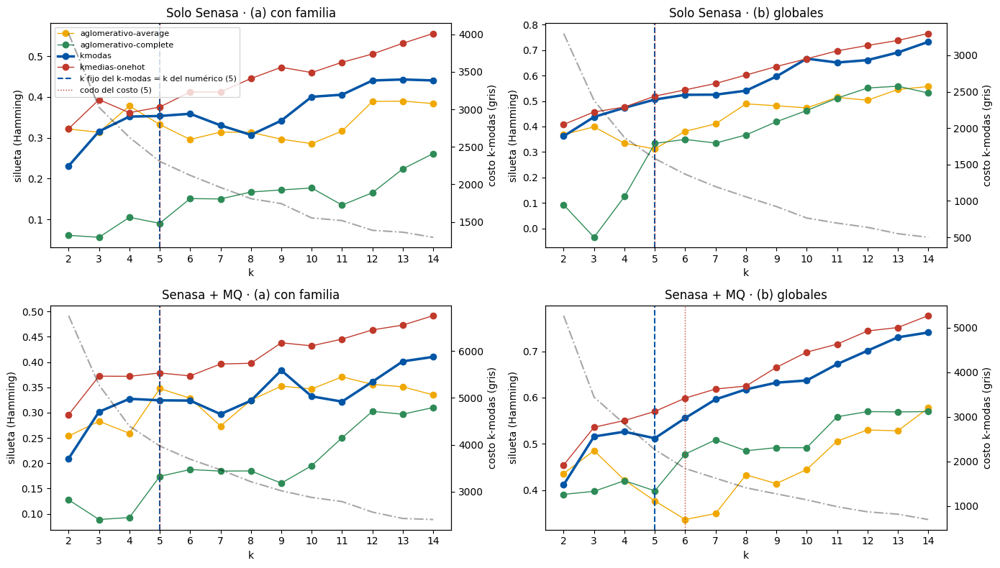

In [66]:
for v, a in A.items():
    for clave, d in a["var"].items():
        b = d["barrido"]
        print(f"{CC.VERSIONES[v]} · variante ({clave}) {d['nombre']} · k del k-modas (fijo) = {d['k_opt']} (k del numérico = {a['K']}) · "
              f"k de mayor silueta = {d['k_sil']} (borde del rango: {CC.KS[-1]}) · codo del costo = {d['k_codo']} · perfiles distintos {d['perfiles']}")
        tab = b.pivot(index="k", columns="metodo", values="silueta_hamming").round(3)
        tab["grupo mínimo (k-modas)"] = b[b["metodo"] == "kmodas"].set_index("k")["grupo_min"]
        tab["costo k-modas"] = b[b["metodo"] == "kmodas"].set_index("k")["costo_kmodas"].astype(int)
        tab["baja del costo"] = tab["costo k-modas"].diff()
        display(tab.style.apply(lambda f: ["font-weight: bold" if f.name == d["k_opt"] else "" for _ in f], axis=1))
        sil, kf = tab["kmodas"], d["k_opt"]
        print(f"   k-modas: silueta {sil[kf - 1]:.3f} (k = {kf - 1}) → {sil[kf]:.3f} (k = {kf}) → {sil[kf + 1]:.3f} (k = {kf + 1}) · "
              f"baja del costo de {kf - 1} a {kf}: {-tab.loc[kf, 'baja del costo']:.0f}, de {kf} a {kf + 1}: {-tab.loc[kf + 1, 'baja del costo']:.0f}, "
              f"de {kf + 1} a {kf + 2}: {-tab.loc[kf + 2, 'baja del costo']:.0f} · grupo mínimo con k = {kf}: {int(tab.loc[kf, 'grupo mínimo (k-modas)'])} muestras "
              f"({100 * tab.loc[kf, 'grupo mínimo (k-modas)'] / len(a['t']):.1f} %)")

fig, ejes = plt.subplots(2, 2, figsize=(14, 8))
for fila, (v, a) in enumerate(A.items()):
    for col, (clave, d) in enumerate(a["var"].items()):
        ax = ejes[fila, col]; b = d["barrido"]
        for m, color in zip(CC.METODOS, [AMBAR, VERDE, AZUL, ROJO]):
            s = b[b["metodo"] == m]
            ax.plot(s["k"], s["silueta_hamming"], marker="o", color=color, label=m, lw=2.5 if m == "kmodas" else 1)
        if a["K"] == d["k_opt"]:
            ax.axvline(d["k_opt"], color=AZUL, ls="--", label=f"k fijo del k-modas = k del numérico ({d['k_opt']})")
        else:
            ax.axvline(a["K"], color="gray", ls=":", label=f"k del numérico ({a['K']})"); ax.axvline(d["k_opt"], color=AZUL, ls="--", label=f"k fijo del k-modas ({d['k_opt']})")
        ax.axvline(d["k_codo"], color=ROJO, ls=":", lw=1, label=f"codo del costo ({d['k_codo']})")
        ax.set_xticks(CC.KS)
        ax2 = ax.twinx(); s = b[b["metodo"] == "kmodas"]
        ax2.plot(s["k"], s["costo_kmodas"], color="black", alpha=0.35, ls="-."); ax2.set_ylabel("costo k-modas (gris)")
        ax.set_title(f"{CC.VERSIONES[v]} · ({clave}) {d['nombre']}"); ax.set_xlabel("k"); ax.set_ylabel("silueta (Hamming)")
ejes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

#### Estabilidad con k = 5
El k-modas con la variante (b) y k = 5, corrido con cinco semillas distintas (`CC.estabilidad`): costo, grupo más chico y
**ARI entre todos los pares de corridas** (1 = misma partición). Si el costo es el mismo pero el ARI no llega a 1, hay
varias particiones empatadas en costo (muestras que están a la misma distancia de dos modas y van a una u otra).
Debajo, qué cambia de una semilla a otra con k = 5: los clusters que salen MIXTO y a qué cluster va la mayoría de los DDL
heladeros. **Los conteos por cluster de este cuaderno valen para la semilla 42** (la de `SEMILLA`): con otra semilla los
totales por tag del numérico no cambian, pero la composición de los clusters que mezclan productos sí.

In [67]:
ESTAB, HEL_SEM = {}, {}
for v, a in A.items():
    tab, aris = CC.estabilidad(a["var"]["b"]["X"])
    ESTAB[v] = (tab, aris)
    print(f"{CC.VERSIONES[v]} · variante (b), k = {CC.K_KMODAS}, {CC.N_INIT} reinicios · ARI entre corridas: mínimo {aris.min():.2f} · "
          f"media {aris.mean():.2f} · máximo {aris.max():.2f}")
    display(tab.set_index("semilla").T)
    # qué cambia entre semillas: los clusters MIXTO y dónde caen los DDL heladeros (dependen de la partición exacta)
    t, X = a["t"], a["var"]["b"]["X"]
    hel = (t["subtipo_eval"] == "DDL heladero").values
    filas = []
    for sem in tab["semilla"]:
        et, _, _ = CC.kmodas(X, CC.K_KMODAS, semilla=int(sem))
        _, tags_ = CC.perfil(t, et, a["var"]["b"]["cols"])
        cuenta = pd.Series(et[hel]).value_counts()
        filas.append({"semilla": sem, "clusters MIXTO": ", ".join(sorted(x for x in tags_.values() if x.startswith("MIXTO"))) or "-",
                      "heladeros en el cluster con más": f"{int(cuenta.iloc[0])} de {int(hel.sum())} ({tags_[cuenta.index[0]]})"})
    HEL_SEM[v] = pd.DataFrame(filas).set_index("semilla")
    display(HEL_SEM[v])

Solo Senasa · variante (b), k = 5, 1000 reinicios · ARI entre corridas: mínimo 0.80 · media 0.84 · máximo 0.99


semilla,42,1,2,3,4
costo,1581,1581,1581,1581,1581
grupo mínimo,382,361,367,418,430


,clusters MIXTO,heladeros en el cluster con más
semilla,,
42,MIXTO_POLVO_MAGRO,104 de 152 (DDL)
1,MIXTO_POLVO_MAGRO,144 de 152 (MIXTO_POLVO_MAGRO)
2,MIXTO_POLVO_MAGRO,144 de 152 (MIXTO_POLVO_MAGRO)
3,MIXTO_POLVO_MAGRO,133 de 152 (MIXTO_POLVO_MAGRO)
4,MIXTO_POLVO_MAGRO,94 de 152 (DDL_2)


Senasa + MQ · variante (b), k = 5, 1000 reinicios · ARI entre corridas: mínimo 0.66 · media 0.78 · máximo 1.00


semilla,42,1,2,3,4
costo,2262,2262,2262,2262,2262
grupo mínimo,582,557,537,557,587


,clusters MIXTO,heladeros en el cluster con más
semilla,,
42,MIXTO_ALTA_HUMEDAD,110 de 175 (POLVO_GRASO)
1,MIXTO_ALTA_HUMEDAD,110 de 175 (POLVO_GRASO)
2,"MIXTO_ALTA_HUMEDAD, MIXTO_POLVO_MAGRO",165 de 175 (MIXTO_POLVO_MAGRO)
3,MIXTO_ALTA_HUMEDAD,110 de 175 (POLVO_GRASO)
4,MIXTO_ALTA_HUMEDAD,97 de 175 (DDL)


### 4 · Tabla comparativa
Para cada versión: el numérico, y el k-modas en las dos variantes con k = 5 (fijo; es también el k del numérico) y con k = 6 como sensibilidad.

- **silueta propia**: en el espacio con el que se armó (euclídea escalada para el numérico; Hamming sobre sus
  categorías para el categórico). **Macro**: el promedio de la silueta media de cada grupo (un grupo chico pesa igual
  que uno grande).
- **silueta en el otro espacio**: el numérico medido con Hamming sobre las categorías de la variante (a o b, según la
  fila de comparación) y el categórico medido con euclídea sobre los análisis escalados.
- **ARI / NMI familia**: solo muestras con familia conocida (acá todas la traen; la de las solo MQ sale de MQ encolumnado, que la asigna un modelo).
- **ARI / NMI subtipo**: DDL familiar / repostero / heladero y la clase de humedad del CAA en el queso (los quesos de la rama propia no
  entran; quedan unos pocos con familia queso en Senasa + MQ, los que el catálogo no confirma: sección 7); **subtipo DDL**: lo mismo, solo dentro del dulce de leche.
- **ARI / NMI con el numérico**: acuerdo entre la partición categórica y la numérica (1 = idénticas, 0 = al azar).
- La fila **«+ subtags del DDL»** es el numérico con el segundo nivel de las secciones 3 y 4 (`subtag` de
  `clusters_*.csv`: DDL_HELADERO, DDL_FAMILIAR, DDL_REPOSTERO y el resto del DDL como DDL). Su silueta es baja a propósito: los subtags
  son un segundo nivel dentro del DDL, no grupos del primero; lo que importa de esa fila es el ARI contra el subtipo.

Una silueta propia **no es comparable** entre los dos espacios (Hamming y euclídea miden cosas distintas); la silueta
en el espacio del otro sí lo es dentro de cada espacio.

In [68]:
filas = []
for v, a in A.items():
    t, Z = a["t"], a["Z"]
    for clave, d in a["var"].items():
        m = CC.metricas(t, a["et_num"], Z, d["X"], "euclidea")
        filas.append({"versión": CC.VERSIONES[v], "algoritmo": f"k-medias numérico (otro espacio = Hamming {clave})",
                      **m, "ARI con el numérico": 1.0, "NMI con el numérico": 1.0})
    et_sub = pd.factorize(t["subtag"])[0]          # el numérico con el segundo nivel del DDL (DDL_HELADERO, DDL_FAMILIAR)
    m = CC.metricas(t, et_sub, Z, a["var"]["b"]["X"], "euclidea")
    filas.append({"versión": CC.VERSIONES[v], "algoritmo": "k-medias numérico + subtags del DDL (otro espacio = Hamming b)",
                  **m, "ARI con el numérico": adjusted_rand_score(a["et_num"], et_sub),
                  "NMI con el numérico": normalized_mutual_info_score(a["et_num"], et_sub)})
    for clave, d in a["var"].items():
        for k in ks_de(a, d):
            et = d["part"][("kmodas", k)]
            m = CC.metricas(t, et, Z, d["X"], "hamming")
            filas.append({"versión": CC.VERSIONES[v],
                          "algoritmo": f"k-modas ({clave}) {d['nombre']}, k = {k} " + rotulo(k, a, d),
                          **m, "ARI con el numérico": adjusted_rand_score(a["et_num"], et),
                          "NMI con el numérico": normalized_mutual_info_score(a["et_num"], et)})
comparacion = pd.DataFrame(filas).set_index(["versión", "algoritmo"])
# las dos filas del numérico solo difieren en la silueta en el otro espacio
comparacion.round(3)

k  silueta propia  silueta macro propia  silueta en el otro espacio  \
versión     algoritmo                                                                                                                              
Solo Senasa k-medias numérico (otro espacio = Hamming a)                     5           0.854                 0.760                       0.062   
            k-medias numérico (otro espacio = Hamming b)                     5           0.854                 0.760                       0.145   
            k-medias numérico + subtags del DDL (otro espacio = Hamming b)  14           0.227                 0.452                      -0.060   
            k-modas (a) con familia, k = 5 (fijo; = k del numérico)          5           0.354                 0.371                      -0.094   
            k-modas (a) con familia, k = 6 (sensibilidad)                    6           0.359                 0.377                      -0.118   
            k-modas (b) globales, k = 5 (fijo; = k del numérico)             5           0.506                 0.510                       0.082   
            k-modas (b) globales, k = 6 (sensibilidad)                       6           0.525                 0.521                       0.045   
Senasa + MQ k-medias numérico (otro espacio = Hamming a)                     5           0.835                 0.754                       0.133   
            k-medias numérico (otro espacio = Hamming b)                     5           0.835                 0.754                       0.328   
            k-medias numérico + subtags del DDL (otro espacio = Hamming b)  13           0.371                 0.341                       0.110   
            k-modas (a) con familia, k = 5 (fijo; = k del numérico)          5           0.324                 0.357                      -0.014   
            k-modas (a) con familia, k = 6 (sensibilidad)                    6           0.324                 0.339                       0.002   
            k-modas (b) globales, k = 5 (fijo; = k del numérico)             5           0.512                 0.531                       0.186   
            k-modas (b) globales, k = 6 (sensibilidad)                       6           0.556                 0.557                       0.147   

                                                                            silueta macro en el otro espacio  ARI familia  NMI familia  ARI subtipo  \
versión     algoritmo                                                                                                                                 
Solo Senasa k-medias numérico (otro espacio = Hamming a)                                               0.169        0.968        0.839       -0.000   
            k-medias numérico (otro espacio = Hamming b)                                               0.338        0.968        0.839       -0.000   
            k-medias numérico + subtags del DDL (otro espacio = Hamming b)                            -0.143        0.225        0.523        0.527   
            k-modas (a) con familia, k = 5 (fijo; = k del numérico)                                   -0.100        0.006        0.015        0.133   
            k-modas (a) con familia, k = 6 (sensibilidad)                                             -0.138        0.007        0.020        0.149   
            k-modas (b) globales, k = 5 (fijo; = k del numérico)                                       0.072        0.119        0.336        0.174   
            k-modas (b) globales, k = 6 (sensibilidad)                                                 0.027        0.066        0.283        0.201   
Senasa + MQ k-medias numérico (otro espacio = Hamming a)                                               0.199        0.921        0.762        0.038   
            k-medias numérico (otro espacio = Hamming b)                                               0.370        0.921        0.762        0.038   
            k-medias numérico + subtags del DDL

### 5 · Tags numéricos contra clusters categóricos
Tabla cruzada con k = 5 (fijo; el del numérico) y con k = 6 (sensibilidad): filas = tag del k-medias, columnas = cluster del k-modas
(numerado por tamaño, 0 = el más grande). Si las dos particiones coincidieran, cada fila tendría una sola celda llena.

In [69]:
for v, a in A.items():
    for clave, d in a["var"].items():
        for k in ks_de(a, d):
            et = d["part"][("kmodas", k)]
            print(f"{CC.VERSIONES[v]} · variante ({clave}) {d['nombre']} · k = {k} {rotulo(k, a, d)}")
            display(pd.crosstab(pd.Series(a["t"]["tag_num"].values, name="tag numérico"), pd.Series(et, name="cluster categórico"), margins=True, margins_name="total"))

Solo Senasa · variante (a) con familia · k = 5 (fijo; = k del numérico)


cluster categórico,0,1,2,3,4,total
tag numérico,,,,,,
DDL,555,467,447,420,227,2116
LIQUIDO,1,4,0,5,0,10
POLVO_GRASO,34,33,9,11,0,87
POLVO_MAGRO,83,79,80,45,48,335
PROT_ALTA,2,0,0,1,46,49
total,675,583,536,482,321,2597


Solo Senasa · variante (a) con familia · k = 6 (sensibilidad)


cluster categórico,0,1,2,3,4,5,total
tag numérico,,,,,,,
DDL,447,443,383,321,295,227,2116
LIQUIDO,0,1,1,4,4,0,10
POLVO_GRASO,9,22,29,16,11,0,87
POLVO_MAGRO,80,26,77,59,45,48,335
PROT_ALTA,0,2,0,0,1,46,49
total,536,494,490,400,356,321,2597


Solo Senasa · variante (b) globales · k = 5 (fijo; = k del numérico)


cluster categórico,0,1,2,3,4,total
tag numérico,,,,,,
DDL,587,568,87,506,368,2116
LIQUIDO,2,0,0,0,8,10
POLVO_GRASO,0,0,87,0,0,87
POLVO_MAGRO,0,0,329,0,6,335
PROT_ALTA,0,0,49,0,0,49
total,589,568,552,506,382,2597


... (6 outputs left out)

Senasa + MQ · variante (b) globales · k = 5 (fijo; = k del numérico)


cluster categórico,0,1,2,3,4,total
tag numérico,,,,,,
DDL,985,204,340,120,577,2226
LIQUIDO,6,16,424,3,5,454
POLVO_GRASO,0,644,0,0,0,644
POLVO_MAGRO,0,20,0,426,0,446
PROT_ALTA,0,10,0,56,0,66
total,991,894,764,605,582,3836


Senasa + MQ · variante (b) globales · k = 6 (sensibilidad)


cluster categórico,0,1,2,3,4,5,total
tag numérico,,,,,,,
DDL,389,280,43,531,535,448,2226
LIQUIDO,436,3,5,5,0,5,454
POLVO_GRASO,0,0,644,0,0,0,644
POLVO_MAGRO,0,431,15,0,0,0,446
PROT_ALTA,0,66,0,0,0,0,66
total,825,780,707,536,535,453,3836


### 6 · Perfil y tag de cada cluster categórico
Por cluster (k = 5, el fijo y el del numérico; y k = 6 como sensibilidad): categoría modal de cada análisis y qué fracción del grupo la tiene, familia
mayoritaria (entre las de familia conocida), tag numérico mayoritario y el centroide numérico en g/100 g (la media de
los análisis originales de las muestras del grupo, que el algoritmo **no** vio). El **tag** sale de ese centroide con
las mismas reglas que el numérico (`etiquetar()`: DDL, POLVO_GRASO, POLVO_MAGRO, PROT_ALTA, LIQUIDO, QUESO,
ALTA_HUMEDAD; si dos grupos caen en la misma regla, el de menor humedad y grasa conserva el nombre y el otro lleva `_2`,
`_3`: por ejemplo, los clusters de DDL del k-modas se llaman DDL, DDL_2, DDL_3…). Cuando el grupo junta productos
distintos (el tag numérico mayoritario cubre menos del 60 %), el centroide es un promedio sin sentido físico y el grupo
se rotula **`MIXTO_<tag>`** (por ejemplo líquidos con dulce de leche, o polvos magros con dulce de leche), para no hacer
pasar por un producto un grupo que no lo es. Había también un tag `POLVO` para los grupos que mezclaban solo polvos;
no apareció en ninguna de las 52 particiones probadas (2 versiones × 2 cortes × k de 2 a 14) y se quitó.

In [70]:
PERFILES, TAGS_CAT = {}, {}
for v, a in A.items():
    for clave, d in a["var"].items():
        for k in ks_de(a, d):
            et = d["part"][("kmodas", k)]
            p, _ = CC.perfil(a["t"], et, d["cols"])
            PERFILES[(v, clave, k)] = p; TAGS_CAT[(v, clave, k)] = p["tag"].to_dict()
            print(f"{CC.VERSIONES[v]} · variante ({clave}) {d['nombre']} · k = {k} {rotulo(k, a, d)}")
            display(p)

Solo Senasa · variante (a) con familia · k = 5 (fijo; = k del numérico)


,tag,muestras,humedad,materia_grasa,proteinas,cenizas,familia mayoritaria,sin familia,tag numérico mayoritario,humedad (g/100 g),grasa (g/100 g),proteinas (g/100 g),cenizas (g/100 g)
cluster,,,,,,,,,,,,,
0,DDL_4,675,medio (89 %),dulce de leche (79 %),medio (67 %),medio (67 %),dulce de leche (82 %),0,DDL (82 %),23.47,7.36,10.69,2.19
1,DDL_3,583,bajo (51 %),dulce de leche (67 %),bajo (92 %),bajo (93 %),dulce de leche (80 %),0,DDL (80 %),22.95,7.19,10.23,1.99
2,DDL,536,bajo (71 %),dulce de leche (74 %),alto (86 %),alto (76 %),dulce de leche (83 %),0,DDL (83 %),21.70,7.04,12.03,2.74
3,DDL_5,482,alto (100 %),dulce de leche (81 %),medio (70 %),medio (71 %),dulce de leche (88 %),0,DDL (87 %),26.91,6.92,8.87,1.95
4,DDL_2,321,alto (100 %),dulce de leche (55 %),alto (96 %),alto (85 %),dulce de leche (71 %),0,DDL (71 %),22.65,6.36,22.99,3.00


Solo Senasa · variante (a) con familia · k = 6 (sensibilidad)


,tag,muestras,humedad,materia_grasa,proteinas,cenizas,familia mayoritaria,sin familia,tag numérico mayoritario,humedad (g/100 g),grasa (g/100 g),proteinas (g/100 g),cenizas (g/100 g)
cluster,,,,,,,,,,,,,
0,DDL,536,bajo (71 %),dulce de leche (74 %),alto (86 %),alto (76 %),dulce de leche (83 %),0,DDL (83 %),21.70,7.04,12.03,2.74
1,DDL_5,494,medio (65 %),dulce de leche (83 %),medio (70 %),bajo (100 %),dulce de leche (90 %),0,DDL (90 %),25.80,7.35,8.52,1.67
2,DDL_2,490,medio (85 %),dulce de leche (74 %),medio (56 %),medio (92 %),dulce de leche (78 %),0,DDL (78 %),22.41,7.47,11.59,2.43
3,DDL_4,400,bajo (63 %),dulce de leche (69 %),bajo (100 %),bajo (90 %),dulce de leche (81 %),0,DDL (80 %),23.06,6.81,10.07,1.97
4,DDL_6,356,alto (100 %),dulce de leche (76 %),medio (59 %),medio (96 %),dulce de leche (83 %),0,DDL (83 %),25.98,7.00,9.93,2.18
5,DDL_3,321,alto (100 %),dulce de leche (55 %),alto (96 %),alto (85 %),dulce de leche (71 %),0,DDL (71 %),22.65,6.36,22.99,3.00


Solo Senasa · variante (b) globales · k = 5 (fijo; = k del numérico)


,tag,muestras,humedad,materia_grasa,proteinas,cenizas,familia mayoritaria,sin familia,tag numérico mayoritario,humedad (g/100 g),grasa (g/100 g),proteinas (g/100 g),cenizas (g/100 g)
cluster,,,,,,,,,,,,,
0,DDL,589,medio (61 %),medio (81 %),medio (93 %),medio (83 %),dulce de leche (100 %),0,DDL (100 %),27.23,7.01,6.31,1.70
1,DDL_3,568,medio (70 %),medio (85 %),alto (100 %),medio (73 %),dulce de leche (100 %),0,DDL (100 %),28.45,7.93,7.73,1.77
2,MIXTO_POLVO_MAGRO,552,bajo (99 %),bajo (75 %),alto (98 %),alto (97 %),concentrado proteico (59 %),0,POLVO_MAGRO (60 %),7.26,7.19,33.00,5.15
3,DDL_4,506,medio (92 %),medio (80 %),medio (70 %),bajo (100 %),dulce de leche (100 %),0,DDL (100 %),28.46,6.77,5.86,1.30
4,DDL_2,382,bajo (57 %),bajo (92 %),bajo (95 %),bajo (95 %),dulce de leche (97 %),0,DDL (96 %),27.48,5.99,5.23,1.31


... (6 outputs left out)

Senasa + MQ · variante (b) globales · k = 5 (fijo; = k del numérico)


,tag,muestras,humedad,materia_grasa,proteinas,cenizas,familia mayoritaria,sin familia,tag numérico mayoritario,humedad (g/100 g),grasa (g/100 g),proteinas (g/100 g),cenizas (g/100 g)
cluster,,,,,,,,,,,,,
0,DDL,991,medio (84 %),medio (82 %),medio (82 %),bajo (57 %),dulce de leche (99 %),0,DDL (99 %),28.55,6.93,6.08,1.40
1,POLVO_GRASO,894,bajo (92 %),alto (80 %),alto (88 %),alto (97 %),leche en polvo (67 %),0,POLVO_GRASO (72 %),9.16,22.08,21.63,4.76
2,MIXTO_ALTA_HUMEDAD,764,alto (58 %),bajo (100 %),bajo (90 %),bajo (99 %),dulce de leche (45 %),0,LIQUIDO (55 %),60.89,3.09,4.21,0.96
3,POLVO_MAGRO,605,bajo (97 %),bajo (100 %),alto (89 %),alto (89 %),concentrado proteico (56 %),0,POLVO_MAGRO (70 %),8.60,3.18,31.80,5.14
4,DDL_2,582,medio (73 %),medio (87 %),alto (92 %),medio (85 %),dulce de leche (99 %),0,DDL (99 %),28.71,7.64,7.46,1.73


Senasa + MQ · variante (b) globales · k = 6 (sensibilidad)

,tag,muestras,humedad,materia_grasa,proteinas,cenizas,familia mayoritaria,sin familia,tag numérico mayoritario,humedad (g/100 g),grasa (g/100 g),proteinas (g/100 g),cenizas (g/100 g)
cluster,,,,,,,,,,,,,
0,MIXTO_ALTA_HUMEDAD,825,alto (55 %),bajo (95 %),bajo (89 %),bajo (96 %),dulce de leche (47 %),0,LIQUIDO (53 %),59.05,3.39,4.35,0.99
1,MIXTO_POLVO_MAGRO,780,bajo (96 %),bajo (78 %),alto (79 %),alto (91 %),concentrado proteico (44 %),0,POLVO_MAGRO (55 %),11.62,4.13,27.33,4.56
2,POLVO_GRASO,707,bajo (94 %),alto (100 %),alto (99 %),alto (99 %),leche en polvo (85 %),0,POLVO_GRASO (91 %),4.96,25.88,24.27,5.36
3,DDL_3,536,medio (72 %),medio (90 %),alto (100 %),medio (83 %),dulce de leche (99 %),0,DDL (99 %),28.75,7.77,7.63,1.75
4,DDL,535,medio (93 %),medio (78 %),medio (71 %),bajo (100 %),dulce de leche (100 %),0,DDL (100 %),28.50,6.75,5.88,1.30
5,DDL_2,453,medio (77 %),medio (86 %),medio (95 %),medio (98 %),dulce de leche (99 %),0,DDL (99 %),28.63,7.16,6.29,1.54


### 7 · Subtipos: ¿quién separa el dulce de leche familiar, repostero y heladero?
Dentro del dulce de leche con subtipo conocido: la composición media de cada subtipo, y cómo se reparten en los grupos
del numérico (tag y subtag) y del k-modas (k = 5). Los quesos que confirma el catálogo no están en el k-medias; los que quedan con familia queso (solo MQ, sin confirmar por el rótulo) se muestran
aparte.

In [71]:
for v, a in A.items():
    t = a["t"]; ddl = t["subtipo_eval"].str.startswith("DDL", na=False).values
    print(f"{CC.VERSIONES[v]} · DDL con subtipo: {int(ddl.sum())}")
    display(t[ddl].groupby("subtipo_eval")[COLUMNAS].agg(["mean", "std"]).round(2))
    partes = {"numérico (tag)": t["tag_num"].values, "numérico (subtag)": t["subtag"].values}
    for clave, d in a["var"].items():
        partes[f"k-modas ({clave})"] = d["part"][("kmodas", d["k_opt"])]
    tablas = [pd.crosstab(pd.Series(t.loc[ddl, "subtipo_eval"].values, name="subtipo"), pd.Series(np.asarray(e)[ddl], name=n)) for n, e in partes.items()]
    display(pd.concat(tablas, axis=1, keys=list(partes)))
q = A["senasa_mq"]["t"]; q = q[q["familia"] == "queso"]
print("Quesos (Senasa + MQ):")
display(q[["subtipo", "subtipo_eval", "tag_num"] + COLUMNAS].assign(
    **{f"k-modas ({c})": A["senasa_mq"]["var"][c]["part"][("kmodas", CC.K_KMODAS)][q.index] for c in "ab"}))

Solo Senasa · DDL con subtipo: 1516


humedad       grasa       proteinas       cenizas      
                 mean   std  mean   std      mean   std    mean   std
subtipo_eval                                                         
DDL familiar    28.73  1.88  6.78  0.72      5.90  0.55    1.37  0.16
DDL heladero    22.40  2.19  6.74  0.80      6.67  0.54    2.49  0.30
DDL repostero   26.64  3.10  7.01  1.02      6.46  1.06    1.48  0.25

numérico (tag)         numérico (subtag)                                                 k-modas (a)                    k-modas (b)           \
                         DDL LIQUIDO               DDL DDL_FAMILIAR DDL_HELADERO DDL_REPOSTERO LIQUIDO           0    1    2    3   4           0    1   2   
subtipo                                                                                                                                                      
DDL familiar             749       1               145          564            1            39       1         228  225   13  267  17         223   29   3   
DDL heladero             152       0                 5            0          146             1       0           7    0  138    0   7         104    0  41   
DDL repostero            612       2               120           43            3           446       2         183  205  193   26   7         126  215  26   

                         
                 3    4  
subtipo                  
DDL familiar   376  119  
DDL heladero     0    7  
DDL repostero   45  202

Senasa + MQ · DDL con subtipo: 1596


humedad       grasa       proteinas       cenizas      
                 mean   std  mean   std      mean   std    mean   std
subtipo_eval                                                         
DDL familiar    28.77  1.87  6.67  1.03      5.90  0.56    1.37  0.17
DDL heladero    22.46  2.20  6.54  0.99      6.72  0.59    2.51  0.32
DDL repostero   26.65  3.08  7.00  1.02      6.47  1.08    1.48  0.26

numérico (tag)         numérico (subtag)                                                 k-modas (a)                   k-modas (b)            \
                         DDL LIQUIDO               DDL DDL_FAMILIAR DDL_HELADERO DDL_REPOSTERO LIQUIDO           0    1   2   3    4           0    1    2   
subtipo                                                                                                                                                      
DDL familiar             789       1               165          584            2            38       1         382  355  47   0    6         606    4  125   
DDL heladero             175       0                 8            1          165             1       0           8    7   1   1  158           8  110    0   
DDL repostero            629       2               129           44            2           454       2         219  187  52  12  161         164   29  174   

                        
                3    4  
subtipo                 
DDL familiar    9   46  
DDL heladero   55    2  
DDL repostero  43  221

Quesos (Senasa + MQ):


,subtipo,subtipo_eval,tag_num,humedad,grasa,proteinas,cenizas,k-modas (a),k-modas (b)
3005,NaN,queso muy alta humedad,LIQUIDO,72.26,14.54,5.80,1.18,0,0
3121,NaN,queso muy alta humedad,LIQUIDO,73.85,7.38,11.23,1.34,0,0
3303,NaN,queso muy alta humedad,LIQUIDO,70.97,12.71,6.60,1.50,1,1
3304,NaN,queso muy alta humedad,LIQUIDO,81.75,6.23,6.24,1.08,0,2
3305,NaN,queso muy alta humedad,LIQUIDO,68.73,13.49,9.95,1.30,0,1
3306,NaN,queso muy alta humedad,LIQUIDO,74.19,7.24,10.29,1.38,0,0
3307,NaN,queso muy alta humedad,LIQUIDO,75.37,7.97,7.61,1.70,1,4
3308,NaN,queso muy alta humedad,LIQUIDO,75.98,7.17,7.21,1.57,1,4
3347,NaN,queso muy alta humedad,LIQUIDO,72.24,10.69,6.61,1.71,1,1
3348,NaN,queso muy alta humedad,LIQUIDO,73.00,11.92,7.05,1.49,1,1


### 8 · Control: otros algoritmos categóricos
¿El resultado es del k-modas o de las categorías? Con k = 5: aglomerativo con Hamming (`average` y
`complete`) y k-medias sobre one-hot, contra el k-modas y contra el numérico. Si los cuatro dan ARI parecidos contra la
familia y contra el numérico, la conclusión depende de la codificación, no del algoritmo.

In [72]:
filas = []
for v, a in A.items():
    for clave, d in a["var"].items():
        ref = d["part"][("kmodas", d["k_opt"])]
        for m in CC.METODOS:
            et = d["part"][(m, d["k_opt"])]
            ari_f, _ = CC.contra(et, a["t"]["familia"].where(a["t"]["familia_conocida"]))
            ari_s, _ = CC.contra(et, a["t"]["subtipo_eval"])
            filas.append({"versión": CC.VERSIONES[v], "variante": f"({clave}) {d['nombre']}", "método": m,
                          "silueta Hamming": d["barrido"].set_index(["metodo", "k"]).loc[(m, d["k_opt"]), "silueta_hamming"],
                          "grupo mínimo": int(np.bincount(et).min()),
                          "ARI con k-modas": adjusted_rand_score(ref, et), "ARI con el numérico": adjusted_rand_score(a["et_num"], et),
                          "ARI familia": ari_f, "ARI subtipo": ari_s})
CONTROL = pd.DataFrame(filas).set_index(["versión", "variante", "método"])
CONTROL.round(3)

silueta Hamming  grupo mínimo  ARI con k-modas  ARI con el numérico  ARI familia  ARI subtipo
versión     variante        método                                                                                                              
Solo Senasa (a) con familia aglomerativo-average             0.332             7            0.336                0.025        0.023        0.155
                            aglomerativo-complete            0.090           188            0.203               -0.013       -0.009        0.174
                            kmodas                           0.354           321            1.000                0.007        0.006        0.133
                            kmedias-onehot                   0.375           366            0.428               -0.008       -0.011        0.145
            (b) globales    aglomerativo-average             0.312             3            0.302                0.041        0.038        0.178
                            aglomerativo-complete            0.334            21            0.392                0.193        0.192        0.124
                            kmodas                           0.506           382            1.000                0.120        0.119        0.174
                            kmedias-onehot                   0.519           390            0.917                0.102        0.101        0.171
Senasa + MQ (a) con familia aglomerativo-average             0.348             7            0.399                0.062        0.054        0.171
                            aglomerativo-complete            0.174           395            0.193                0.037        0.028        0.271
                            kmodas                           0.324           484            1.000                0.115        0.101        0.139
                            kmedias-onehot                   0.378           540            0.551                0.132        0.122        0.189
            (b) globales    aglomerativo-average             0.377            47            0.425                0.164        0.128        0.183
                            aglomerativo-complete            0.399           427            0.391                0.180        0.140        0.278
                            kmodas                           0.512           582            1.000                0.326        0.260        0.301
                            kmedias-onehot                   0.570           596            0.659                0.322        0.258        0.121

### 9 · Extra: el categórico admite muestras incompletas («no medido»)
El k-medias necesita los cuatro análisis. Con categorías, un análisis que falta puede ser una categoría más,
**«no medido»**. `CC.cargar_ampliado` toma, además de las muestras del k-medias, las que tienen entre 1 y 3 de los
cuatro análisis (sin las excluidas por humedad + sólidos). Para el clustering se piden **al menos 2 de 4** (con uno
solo, la muestra es casi toda «no medido»). Se corre el k-modas con k = 5 y se mira (i) cuántas muestras más
entran, (ii) si las muestras completas quedan agrupadas como sin las incompletas (ARI) y (iii) cuánto se agrupa por
«qué se midió» en vez de por composición (un grupo con «no medido» como moda es un grupo armado por el patrón de
faltantes, no por el producto).

In [73]:
AMPLIADO, CONTEOS, AMP_ARI = {}, {}, {}
for v, a in A.items():
    amp, conteo = CC.cargar_ampliado(v)
    CONTEOS[v] = conteo
    print(f"{CC.VERSIONES[v]} · muestras por cantidad de análisis medidos (de humedad, grasa, proteínas, cenizas):")
    display(conteo)
    print(f"   entran con ≥ 2 de 4: {len(amp)} ({int(amp['completa'].sum())} completas + {int((~amp['completa']).sum())} incompletas, "
          f"×{len(amp) / amp['completa'].sum():.1f})")
    for clave, (nombre, cols) in CC.VARIANTES.items():
        X, _ = CC.codificar(amp, cols)
        et, _, _ = CC.kmodas(X, CC.K_KMODAS)
        AMPLIADO[(v, clave)] = (amp, et)
        sel = amp["completa"].values
        base = pd.Series(a["var"][clave]["part"][("kmodas", CC.K_KMODAS)], index=a["t"]["Identificador"])
        ari_c = adjusted_rand_score(base[amp.loc[sel, "Identificador"]].values, et[sel])
        ari_f, _ = CC.contra(et, amp["familia"].where(amp["familia"] != CC.SIN_FAMILIA))
        no_med = amp[cols].eq(CC.NO_MEDIDO).groupby(et).mean().round(2)
        no_med.columns = [c.split("_", 1)[1] for c in cols]
        AMP_ARI[(v, clave)] = ari_c
        print(f"   variante ({clave}) {nombre}: ARI de las completas contra el k-modas sin incompletas {ari_c:.2f} · ARI familia {ari_f:.2f}")
        display(no_med.assign(muestras=np.bincount(et), familia_mayoritaria=amp.groupby(et)["familia"].agg(lambda s: s.value_counts().index[0]))
                .rename_axis("cluster").add_prefix("").rename(columns=lambda c: c if c in ("muestras", "familia_mayoritaria") else f"% no medido {c}"))

Solo Senasa · muestras por cantidad de análisis medidos (de humedad, grasa, proteínas, cenizas):


análisis medidos (de 4),1,2,3,4,total
row_0,,,,,
completa (k-medias),0,7,0,2590,2597
incompleta,1151,367,701,0,2219
total,1151,374,701,2590,4816


   entran con ≥ 2 de 4: 3665 (2597 completas + 1068 incompletas, ×1.4)


   variante (a) con familia: ARI de las completas contra el k-modas sin incompletas 0.57 · ARI familia 0.03


,% no medido humedad,% no medido materia_grasa,% no medido proteinas,% no medido cenizas,muestras,familia_mayoritaria
cluster,,,,,,
0,0.04,0.01,0.01,0.13,1128,dulce de leche
1,0.03,0.00,0.00,0.06,929,dulce de leche
2,0.04,0.00,0.00,0.05,871,dulce de leche
3,0.00,0.00,0.73,1.00,463,dulce de leche
4,0.99,0.00,0.00,0.03,274,dulce de leche


   variante (b) globales: ARI de las completas contra el k-modas sin incompletas 0.69 · ARI familia 0.13


... (4 outputs left out)

   variante (a) con familia: ARI de las completas contra el k-modas sin incompletas 0.47 · ARI familia 0.15


,% no medido humedad,% no medido materia_grasa,% no medido proteinas,% no medido cenizas,muestras,familia_mayoritaria
cluster,,,,,,
0,0.09,0.09,0.06,0.15,2447,dulce de leche
1,0.61,0.05,0.20,0.13,2238,dulce de leche
2,0.01,0.03,0.73,0.80,1958,queso
3,0.03,0.05,0.60,0.52,1403,leche en polvo
4,0.10,0.04,0.00,0.03,1171,dulce de leche


   variante (b) globales: ARI de las completas contra el k-modas sin incompletas 0.55 · ARI familia 0.32


,% no medido humedad,% no medido materia_grasa,% no medido proteinas,% no medido cenizas,muestras,familia_mayoritaria
cluster,,,,,,
0,0.00,0.04,0.26,0.14,2232,leche en polvo
1,0.03,0.07,0.81,0.94,2045,queso
2,0.03,0.00,0.00,0.11,1929,dulce de leche
3,0.10,0.00,0.16,0.23,1516,dulce de leche
4,1.00,0.18,0.26,0.14,1495,sin clasificar


### 10 · Guardar
`resultados/comparacion_num_cat/comparacion_<version>.csv`: una fila por muestra del k-medias, con Identificador,
familia, subtipo, origen, tag numérico y, para cada variante y k (el fijo, 5; el del numérico, si es otro; y 6 como sensibilidad), el cluster categórico y su tag.
Además la tabla comparativa (`tabla_comparativa.csv`) y los perfiles (`perfiles_<version>.csv`).

In [74]:
CC.SALIDA.mkdir(parents=True, exist_ok=True)
for v, a in A.items():
    t = a["t"].copy(); cols = []
    for clave, d in a["var"].items():
        for k in ks_de(a, d):
            et = d["part"][("kmodas", k)]; nom = f"{clave}_k{k}"
            t[f"cluster_cat_{nom}"] = et; t[f"tag_cat_{nom}"] = [TAGS_CAT[(v, clave, k)][g] for g in et]
            cols += [f"cluster_cat_{nom}", f"tag_cat_{nom}"]
    ruta = CC.guardar(t, cols, v)
    pd.concat({f"({c}) k={k}": p for (vv, c, k), p in PERFILES.items() if vv == v}, names=["variante", "cluster"]).to_csv(
        CC.SALIDA / f"perfiles_{v}.csv", encoding="utf-8-sig")
    print("Guardado:", ruta.relative_to(R.RAIZ), pd.read_csv(ruta).shape)
comparacion.round(4).to_csv(CC.SALIDA / "tabla_comparativa.csv", encoding="utf-8-sig")
print("Guardado:", (CC.SALIDA / "tabla_comparativa.csv").relative_to(R.RAIZ))

Guardado: resultados\comparacion_num_cat\comparacion_senasa.csv (2597, 13)
Guardado: resultados\comparacion_num_cat\comparacion_senasa_mq.csv (3836, 13)
Guardado: resultados\comparacion_num_cat\tabla_comparativa.csv


### 11 · Datos usados en cada entrenamiento
Cuántas muestras entran a cada modelo de este cuaderno, con el mismo formato que en los demás (parte II del cuaderno
general). No hay partición en entrenamiento y prueba: son agrupamientos, se entrenan y se evalúan con las mismas
muestras. Los números salen de las variables de arriba, no están escritos a mano. Los modelos que se entrenan son el
k-medias numérico de referencia, el k-modas (variantes a y b, con k = 5 y k = 6 de sensibilidad), los dos controles categóricos
(aglomerativo con Hamming y k-medias sobre one-hot) y el k-modas con «no medido» de la sección 9.

In [75]:
import datos_entrenamiento as DE
from datos_clase41 import N_INIT_KMEDIAS

PART = "sin partición: no supervisado, se entrena y se evalúa con las mismas muestras"
filas, DISP = [], {}
for v, a in A.items():
    cl = pd.read_csv(R.TABLAS / f"clusters_{v}.csv", encoding="utf-8-sig")
    rama = cl["rama"] == "k-medias"
    n_disp, n_usa, n_queso = int(rama.sum()), len(a["t"]), int((~rama).sum())
    assert n_usa == int(cl["cluster"].notna().sum()), "las muestras del cuaderno no son las del k-medias"
    DISP[v] = n_disp
    nom = CC.VERSIONES[v]
    datos = f"{nom}: muestras de la rama k-medias (cuatro análisis completos, suma ≤ 102, lácteas)"
    comun = dict(disponibles=n_disp, usadas=n_usa, motivo=f"{n_disp - n_usa} outliers por consenso del k-medias", particion=PART)
    fuera = f"los {n_queso} quesos de la rama propia no están"
    barrido = f"k de {CC.KS[0]} a {CC.KS[-1]} en las dos variantes"
    filas += [
        DE.fila("II", f"k-medias numérico de referencia, {nom}", datos + ", escaladas",
                nota=f"k = {a['K']}, n_init = {N_INIT_KMEDIAS}, semilla {SEMILLA}; reproduce el del cuaderno principal; {fuera}", **comun),
        DE.fila("II", f"k-modas (a) con familia, {nom}", datos + ", con los cuatro análisis pasados a categorías (cortes por familia)",
                nota=f"k = {CC.K_KMODAS} (fijo; el del numérico es {a['K']}) y k = {K_SENS} (sensibilidad); barrido de {barrido}; {CC.N_INIT} reinicios por corrida", **comun),
        DE.fila("II", f"k-modas (b) globales, {nom}", datos + ", con los cuatro análisis pasados a categorías (cortes «*» globales)",
                nota=f"k = {CC.K_KMODAS} (fijo; el del numérico es {a['K']}) y k = {K_SENS} (sensibilidad); barrido de {barrido}; {CC.N_INIT} reinicios por corrida; "
                     f"estabilidad con {len(ESTAB[v][0])} semillas", **comun),
        DE.fila("II", f"aglomerativo con Hamming (average y complete), {nom}", datos + ", categorías de las variantes (a) y (b)",
                nota=f"control; k = {CC.K_KMODAS} en las tablas y barrido de {barrido}", **comun),
        DE.fila("II", f"k-medias sobre one-hot, {nom}", datos + ", categorías de las variantes (a) y (b) en one-hot",
                nota=f"control; n_init = {N_INIT_KMEDIAS}; k = {CC.K_KMODAS} en las tablas y barrido de {barrido}", **comun),
    ]
    cont, amp = CONTEOS[v], AMPLIADO[(v, "b")][0]
    n_tot, n_amp, n_comp = int(cont.loc["total", "total"]), len(amp), int(amp["completa"].sum())
    filas.append(DE.fila(
        "II", f"k-modas con «no medido» (a) y (b), k = {CC.K_KMODAS}, {nom}",
        f"{nom}: muestras con 1 a 4 de los cuatro análisis (las completas del k-medias y las incompletas, sin las excluidas)",
        n_tot, n_amp, motivo=f"{n_tot - n_amp} con un solo análisis medido (se piden al menos 2 de 4)", particion=PART,
        nota=f"{n_comp} completas + {n_amp - n_comp} incompletas; {n_amp} de {n_tot}; el análisis que falta es una categoría más"))
display(DE.guardar(filas, "comparacion_numerico_categorico"))

,parte,modelo,datos,disponibles,excluidas,motivo de exclusión,usadas,entrenamiento,validación,prueba,partición,nota
0,II,"k-medias numérico de referencia, Solo Senasa","Solo Senasa: muestras de la rama k-medias (cuatro análisis completos, suma ≤ 102, lácteas), escaladas",2660,63,63 outliers por consenso del k-medias,2597,2597,<NA>,<NA>,"sin partición: no supervisado, se entrena y se evalúa con las mismas muestras","k = 5, n_init = 50, semilla 42; reproduce el del cuaderno principal; los 1627 quesos de la rama propia no ..."
1,II,"k-modas (a) con familia, Solo Senasa","Solo Senasa: muestras de la rama k-medias (cuatro análisis completos, suma ≤ 102, lácteas), con los cuatro...",2660,63,63 outliers por consenso del k-medias,2597,2597,<NA>,<NA>,"sin partición: no supervisado, se entrena y se evalúa con las mismas muestras",k = 5 (fijo; el del numérico es 5) y k = 6 (sensibilidad); barrido de k de 2 a 14 en las dos variantes; 10...
2,II,"k-modas (b) globales, Solo Senasa","Solo Senasa: muestras de la rama k-medias (cuatro análisis completos, suma ≤ 102, lácteas), con los cuatro...",2660,63,63 outliers por consenso del k-medias,2597,2597,<NA>,<NA>,"sin partición: no supervisado, se entrena y se evalúa con las mismas muestras",k = 5 (fijo; el del numérico es 5) y k = 6 (sensibilidad); barrido de k de 2 a 14 en las dos variantes; 10...
3,II,"aglomerativo con Hamming (average y complete), Solo Senasa","Solo Senasa: muestras de la rama k-medias (cuatro análisis completos, suma ≤ 102, lácteas), categorías de ...",2660,63,63 outliers por consenso del k-medias,2597,2597,<NA>,<NA>,"sin partición: no supervisado, se entrena y se evalúa con las mismas muestras",control; k = 5 en las tablas y barrido de k de 2 a 14 en las dos variantes
4,II,"k-medias sobre one-hot, Solo Senasa","Solo Senasa: muestras de la rama k-medias (cuatro análisis completos, suma ≤ 102, lácteas), categorías de ...",2660,63,63 outliers por consenso del k-medias,2597,2597,<NA>,<NA>,"sin partición: no supervisado, se entrena y se evalúa con las mismas muestras",control; n_init = 50; k = 5 en las tablas y barrido de k de 2 a 14 en las dos variantes
5,II,"k-modas con «no medido» (a) y (b), k = 5, Solo Senasa","Solo Senasa: muestras con 1 a 4 de los cuatro análisis (las completas del k-medias y las incompletas, sin ...",4816,1151,1151 con un solo análisis medido (se piden al menos 2 de 4),3665,3665,<NA>,<NA>,"sin partición: no supervisado, se entrena y se evalúa con las mismas muestras",2597 completas + 1068 incompletas; 3665 de 4816; el análisis que falta es una categoría más
6,II,"k-medias numérico de referencia, Senasa + MQ","Senasa + MQ: muestras de la rama k-medias (cuatro análisis completos, suma ≤ 102, lácteas), escaladas",3937,101,101 outliers por consenso del k-medias,3836,3836,<NA>,<NA>,"sin partición: no supervisado, se entrena y se evalúa con las mismas muestras","k = 5, n_init = 50, semilla 42; reproduce el del cuaderno principal; los 2891 quesos de la rama propia no ..."
7,II,"k-modas (a) con familia, Senasa + MQ","Senasa + MQ: muestras de la rama k-medias (cuatro análisis completos, suma ≤ 102, lácteas), con los cuatro...",3937,101,101 outliers por consenso del k-medias,3836,3836,<NA>,<NA>,"sin partición: no supervisado, se entrena y se evalúa con las mismas muestras",k = 5 (fijo; el del numérico es 5) y k = 6 (sensibilidad); barrido de k de 2 a 14 en las dos variantes; 10...
8,II,"k-modas (b) globales, Senasa + MQ","Senasa + MQ: muestras de la rama k-medias (cuatro análisis completos, suma ≤ 102, lácteas), con los cuatro...",3937,101,101 outliers por consenso del k-medias,3836,3836,<NA>,<NA>,"sin partición: no supervisado, se entrena y se evalúa con las mismas muestras",k = 5 (fijo; el del numérico es 5) y k = 6 (sensibilidad); barrido de k de 2 a 14 en las dos variantes; 10...
9,II,"aglomerativo con Hamming (average y complete), Senasa + MQ","Senasa + MQ: muestras de la rama k-medias (cuatro análisis completos, suma ≤ 102, lácteas), categorías de ...",3937,10

### Conclusión
Los números de esta conclusión **se calculan en la celda de abajo** con las salidas de este mismo cuaderno (semilla 42):
si cambian los datos o la semilla, cambian solos. Lo que no cambia solo son las afirmaciones, que hay que revisar.

In [76]:
from IPython.display import Markdown

cm = lambda x, d=2: f"{round(float(x), d) + 0:.{d}f}".replace(".", ",")      # coma decimal, sin «-0,00»
pc = lambda x: f"{100 * x:.0f} %"
S1, S2 = "senasa", "senasa_mq"
NOM, KF = CC.VERSIONES, CC.K_KMODAS
n_muestras = {v: len(a["t"]) for v, a in A.items()}
n_out = {v: DISP[v] - n_muestras[v] for v in A}
K_NUM = A[S1]["K"]


def met(v, clave, k):
    # métricas del k-modas (variante `clave`, k) y el ARI contra el numérico
    a = A[v]; d = a["var"][clave]; et = d["part"][("kmodas", k)]
    m = CC.metricas(a["t"], et, a["Z"], d["X"], "hamming")
    m["ARI numérico"] = adjusted_rand_score(a["et_num"], et)
    return m


MET = {(v, c, k): met(v, c, k) for v in A for c in "ab" for k in dict.fromkeys([KF, A[v]["K"], K_SENS])}
NUM = {v: CC.metricas(a["t"], a["et_num"], a["Z"], a["var"]["b"]["X"], "euclidea") for v, a in A.items()}
SUBTAG = {v: CC.metricas(a["t"], pd.factorize(a["t"]["subtag"])[0], a["Z"], a["var"]["b"]["X"], "euclidea") for v, a in A.items()}
SIL_NUM = {v: silhouette_score(a["Z"], a["et_num"]) for v, a in A.items()}


def donde_caen(v, k=KF):
    # dónde caen los tags numéricos que no son DDL en el k-modas (b), y cuánto DDL arrastra ese cluster
    t = A[v]["t"]; et = A[v]["var"]["b"]["part"][("kmodas", k)]
    ct = pd.crosstab(t["tag_num"], et); tags = TAGS_CAT[(v, "b", k)]
    hel = (t["subtipo_eval"] == "DDL heladero").values
    por_g = {}
    for tag in ["POLVO_GRASO", "POLVO_MAGRO", "PROT_ALTA", "LIQUIDO"]:
        if tag not in ct.index:
            continue
        g = ct.loc[tag].idxmax()
        if ct.loc[tag, g] / ct.loc[tag].sum() >= 0.5:
            por_g.setdefault(g, []).append(f"{ct.loc[tag, g]} de {ct.loc[tag].sum()} {tag}")
    return "; ".join(f"{', '.join(x)} van al cluster {g} (`{tags[g]}`, {ct[g].sum()} muestras, con {ct.loc['DDL', g]} DDL y {int((hel & (et == g)).sum())} heladeros)"
                     for g, x in por_g.items())


def ddl_partido(v, k=KF):
    # cuántos clusters son DDL casi puro y cuáles mezclan
    t = A[v]["t"]; et = A[v]["var"]["b"]["part"][("kmodas", k)]
    ct = pd.crosstab(t["tag_num"], et); share = ct.loc["DDL"] / ct.sum(); tags = TAGS_CAT[(v, "b", k)]
    puros = int((share >= 0.95).sum())
    mezcla = ", ".join(f"`{tags[g]}` ({pc(share[g])} de DDL)" for g in ct.columns if share[g] < 0.95)
    return f"{puros} de {k} clusters son DDL casi puro (95 % o más) y los otros mezclan: {mezcla}"


def n_puros(v, k=KF):
    t = A[v]["t"]; et = A[v]["var"]["b"]["part"][("kmodas", k)]; ct = pd.crosstab(t["tag_num"], et)
    return int(((ct.loc["DDL"] / ct.sum()) >= 0.95).sum())


def mixtos(v, k):
    m = [x for x in TAGS_CAT[(v, "b", k)].values() if x.startswith("MIXTO")]
    return f"{len(m)}" + (f" (`{'`, `'.join(m)}`)" if m else "")


def ddl_en_tag(v):
    t = A[v]["t"]; ddl = t["familia"] == "dulce de leche"; en = ddl & (t["tag_num"] == "DDL")
    otros = t.loc[ddl & ~en, "tag_num"].value_counts()
    resto = ", ".join(f"{n} en {tg}" for tg, n in otros.items()) or "ninguno en otro tag"
    return f"{int(en.sum())} de los {int(ddl.sum())} DDL en el tag DDL ({resto})"


def subtipos(v):
    t = A[v]["t"]; ddl = t["subtipo_eval"].str.startswith("DDL", na=False)
    tab = pd.crosstab(t.loc[ddl, "subtipo_eval"], t.loc[ddl, "subtag"]); tot = tab.sum(axis=1)
    return (f"DDL_HELADERO junta {tab.loc['DDL heladero', 'DDL_HELADERO']} de los {tot['DDL heladero']} heladeros y "
            f"{tab['DDL_HELADERO'].sum() - tab.loc['DDL heladero', 'DDL_HELADERO']} muestras de otros subtipos; DDL_FAMILIAR junta "
            f"{tab.loc['DDL familiar', 'DDL_FAMILIAR']} de los {tot['DDL familiar']} familiares, con {tab.loc['DDL repostero', 'DDL_FAMILIAR']} reposteros; "
            f"DDL_REPOSTERO junta {tab.loc['DDL repostero', 'DDL_REPOSTERO']} de los {tot['DDL repostero']} reposteros")


def heladeros_k(v, k=KF):
    t = A[v]["t"]; et = A[v]["var"]["b"]["part"][("kmodas", k)]; tags = TAGS_CAT[(v, "b", k)]
    hel = (t["subtipo_eval"] == "DDL heladero").values; cuenta = pd.Series(et[hel]).value_counts().head(2)
    return " y ".join(f"{n} de {int(hel.sum())} en el cluster {g} (`{tags[g]}`)" for g, n in cuenta.items())


def mayoria(n, k=KF):
    return "la mayoría de los clusters" if 2 * n > k else "menos de la mitad de los clusters"


def liquidos_en_ddl(v, k=KF):
    # el cluster donde cae la mayoría de los LIQUIDO (b): cuánto de ese cluster es DDL
    t = A[v]["t"]; et = A[v]["var"]["b"]["part"][("kmodas", k)]; ct = pd.crosstab(t["tag_num"], et)
    g = ct.loc["LIQUIDO"].idxmax()
    return f"{int(ct.loc['LIQUIDO', g])} de {int(ct.loc['LIQUIDO'].sum())} LIQUIDO en un cluster de {int(ct[g].sum())} muestras con {pc(ct.loc['DDL', g] / ct[g].sum())} de DDL"


def semillas_hel(v):
    # con las 5 semillas: cuántos clusters distintos (por tag) se llevan la mayoría de los heladeros y cuántos conjuntos MIXTO distintos salen
    h = HEL_SEM[v]["heladeros en el cluster con más"].str.extract(r"\((.*)\)")[0]
    return h.nunique(), ", ".join(f"`{x}`" for x in h.unique()), HEL_SEM[v]["clusters MIXTO"].nunique()


def familias_por_tag(v):
    t = A[v]["t"]; ct = pd.crosstab(t["tag_num"], t["familia"])
    return (ct.max(axis=1) / ct.sum(axis=1)), ct


def faltantes(v):
    # clusters armados por «qué se midió»: un análisis (o dos) en «no medido» en el 75 % o más del grupo
    amp, et = AMPLIADO[(v, "b")]; nm = amp[CC.CAT_B].eq(CC.NO_MEDIDO).groupby(et).mean(); out, n = [], 0
    for g in nm.index:
        mal = [c for c in CC.CAT_B if nm.loc[g, c] >= 0.75]
        if mal:
            m = nm.loc[g, mal].min(); n += int((et == g).sum())
            out.append(f"un cluster de {int((et == g).sum())} muestras con {' y '.join(c.split('_', 1)[1] for c in mal)} «no medido» "
                       f"{'en el' if m >= 0.995 else 'en al menos el'} {pc(m)}")
    return "; ".join(out), n


def perfil_a(v, k=KF):
    # familia mayoritaria de cada cluster de la variante (a): cuántos son de dulce de leche y en qué rango de %
    fm = PERFILES[(v, "a", k)]["familia mayoritaria"]
    nombre = fm.str.replace(r" \(\d+ %\)", "", regex=True); pct = fm.str.extract(r"\((\d+) %\)")[0].astype(int)
    d = nombre == "dulce de leche"
    return f"{int(d.sum())} de {len(fm)} clusters tienen al dulce de leche como familia mayoritaria ({pct[d].min()} a {pct[d].max()} %)"


cortes = pd.read_csv(R.TABLAS / "cortes_categorias.csv", encoding="utf-8-sig")
cortes = cortes[(cortes["familia"] == "*") & (cortes["analisis"] == "humedad")].set_index("categoria")["hasta"]
polvos = lambda v: A[v]["t"]["tag_num"].isin(["POLVO_GRASO", "POLVO_MAGRO", "PROT_ALTA"]).values
polvo_bajo = {v: (A[v]["t"].loc[polvos(v), "catg_humedad"] == "bajo").mean() for v in A}
import re
ddl_sh = {v: (A[v]["t"]["familia"] == "dulce de leche").mean() for v in A}
hum_ddl = A[S2]["t"].loc[A[S2]["t"]["familia"] == "dulce de leche", "humedad"].quantile([0.25, 0.5, 0.75])
alto_a = A[S2]["t"].groupby("familia")["humedad"].apply(lambda x: x[A[S2]["t"].loc[x.index, "cat_humedad"] == "alto"].min())
ce_hel = {v: A[v]["t"].loc[A[v]["t"]["subtipo_eval"] == "DDL heladero", "cenizas"].mean() for v in A}
ce_ddl = {v: A[v]["t"].loc[A[v]["t"]["subtipo_eval"].isin(["DDL familiar", "DDL repostero"]), "cenizas"].mean() for v in A}
modas = [int(re.search(r"\((\d+) %", x).group(1)) for v in A for c in ["humedad", "materia_grasa", "proteinas", "cenizas"] for x in PERFILES[(v, "b", KF)][c]]
cg_ddl = A[S2]["t"].loc[A[S2]["t"]["cat_materia_grasa"] == "dulce de leche", "familia"].value_counts()
nq_amp = {v: int((AMPLIADO[(v, "b")][0]["familia"] == "queso").sum()) for v in A}

fam_tag = {v: familias_por_tag(v) for v in A}
sin_liq = pd.concat([f.drop("LIQUIDO", errors="ignore") for f, _ in fam_tag.values()])
liq = {v: (fam_tag[v][0]["LIQUIDO"], fam_tag[v][1].loc["LIQUIDO"].sort_values(ascending=False)) for v in A}
nq = int((A[S2]["t"]["familia"] == "queso").sum())

b = {v: A[v]["var"]["b"] for v in A}
cuerpo = {v: b[v]["barrido"][b[v]["barrido"]["metodo"] == "kmodas"].set_index("k") for v in A}
baja = {v: (cuerpo[v].loc[KF - 1, "costo_kmodas"] - cuerpo[v].loc[KF, "costo_kmodas"], cuerpo[v].loc[KF, "costo_kmodas"] - cuerpo[v].loc[KF + 1, "costo_kmodas"]) for v in A}
n_codo = sum(d["k_codo"] == KF for v in A for d in A[v]["var"].values())
codo_v = {v: " y ".join(f"{A[v]['var'][c]['k_codo']} en ({c})" for c in "ab") for v in A}
chico = {v: cuerpo[v].loc[KF, "grupo_min"] for v in A}
codos = ", ".join(f"{d['k_codo']} en {NOM[v]} ({c})" for v, a in A.items() for c, d in a["var"].items())
aris = {v: ESTAB[v][1] for v in A}
mismo_costo = all(ESTAB[v][0]["costo"].nunique() == 1 for v in A)
n_sem = len(ESTAB[S1][0])
agl = CONTROL.xs("aglomerativo-average", level="método")["grupo mínimo"]
agl_txt = ", ".join(f"{n} en {var} de {ver}" for (ver, var), n in agl.items())
rng_ctrl = CONTROL[["ARI familia", "ARI con el numérico"]]
amp_n = {v: len(AMPLIADO[(v, "b")][0]) for v in A}
amp_ari = [x for x in AMP_ARI.values()]

texto = f'''
Los números citados son los de la tabla de la sección 4 (k-modas con k = {KF}, fijo, salvo que se diga otra cosa), con las
muestras del k-medias actual: {n_muestras[S1]} en solo Senasa y {n_muestras[S2]} en Senasa + MQ, ya sin los outliers por consenso
({n_out[S1]} y {n_out[S2]}), sin las familias no lácteas ni los quesos de la rama propia. La silueta propia **no se compara**
entre algoritmos: una es euclídea sobre números y la otra es de Hamming sobre 4 símbolos. Todo con la semilla {SEMILLA}.

**En qué coinciden, a medias.** Con categorías globales (b) y k = {KF}, los polvos se juntan en pocos clusters, pero ninguno queda limpio: todos
arrastran dulce de leche, y los líquidos no tienen cluster propio (en solo Senasa, {liquidos_en_ddl(S1)}; en Senasa + MQ, {liquidos_en_ddl(S2)}). En solo Senasa: {donde_caen(S1)}. En Senasa + MQ: {donde_caen(S2)}. Los quesos ya no forman parte de esta comparación (van a su rama
propia): en Senasa + MQ quedan {nq} muestras con familia queso, las que el catálogo no confirma, así que no se puede ver si el k-modas separa
las clases de humedad del CAA.

**En qué difieren.** El k-medias usa sus {K_NUM} grupos para los **tipos de producto**: ARI contra la familia de {cm(NUM[S1]["ARI familia"])} en solo
Senasa y {cm(NUM[S2]["ARI familia"])} en Senasa + MQ, y casi todo el dulce de leche en un solo tag (en solo Senasa, {ddl_en_tag(S1)}; en Senasa + MQ,
{ddl_en_tag(S2)}). El k-modas dedica {mayoria(n_puros(S1))} (solo Senasa) y {mayoria(n_puros(S2))} (Senasa + MQ) a **partir el dulce de leche**: en solo Senasa, {ddl_partido(S1)};
en Senasa + MQ, {ddl_partido(S2)}. Eso pasa porque el dulce de leche es el {pc(ddl_sh[S1])} de las muestras de solo Senasa y el {pc(ddl_sh[S2])} de Senasa + MQ, y los cortes
globales de humedad ({cm(cortes["bajo"])} y {cm(cortes["medio"])}) caen en medio de su rango (mediana {cm(hum_ddl[0.5], 1)}, 50 % central entre {cm(hum_ddl[0.25], 1)} y {cm(hum_ddl[0.75], 1)} en
Senasa + MQ): el {pc(polvo_bajo[S1])} (solo Senasa) y el {pc(polvo_bajo[S2])} (Senasa + MQ) de los polvos quedan en «bajo» y el DDL se reparte en las tres categorías. El acuerdo entre las dos particiones es bajo: ARI de
{cm(MET[(S1, "b", KF)]["ARI numérico"])} en solo Senasa y {cm(MET[(S2, "b", KF)]["ARI numérico"])} en Senasa + MQ con k = {KF} ({cm(MET[(S1, "b", K_SENS)]["ARI numérico"])} y {cm(MET[(S2, "b", K_SENS)]["ARI numérico"])} con k = {K_SENS}, la sensibilidad).
Además salen clusters MIXTO (su centroide es un promedio de productos distintos): con k = {KF}, {mixtos(S1, KF)} en solo Senasa y
{mixtos(S2, KF)} en Senasa + MQ; con k = {K_SENS}, {mixtos(S1, K_SENS)} y {mixtos(S2, K_SENS)}. Cuántos MIXTO salen y cuáles dependen del k y, en Senasa + MQ, de la semilla (ver la
tabla de estabilidad de la sección 3).

**La fuga de la variante (a) no hace lo que se esperaba.** Esas categorías son relativas a la familia: «alto» en una
leche en polvo es más de {cm(alto_a["leche en polvo"], 1)} % de humedad y en un DDL más de {cm(alto_a["dulce de leche"], 1)} % (Senasa + MQ), pero para el algoritmo es el mismo símbolo. El k-modas agrupa
entonces por el **perfil dentro de la familia** («alto en proteína y cenizas para lo que es») y mezcla familias dentro de cada cluster: en solo Senasa, {perfil_a(S1)}; en
Senasa + MQ, {perfil_a(S2)}. El ARI
contra la familia da {cm(MET[(S1, "a", KF)]["ARI familia"])} en solo Senasa y {cm(MET[(S2, "a", KF)]["ARI familia"])} en Senasa + MQ, y contra el numérico {cm(MET[(S1, "a", KF)]["ARI numérico"])} y {cm(MET[(S2, "a", KF)]["ARI numérico"])}. La fuga más directa
es la clase de grasa («dulce de leche», «entera», «descremada»), que nombra a la familia ({cg_ddl.iloc[0]} muestras con la clase «dulce de leche» y todas de familia {cg_ddl.index[0]}), pero es una variable de
cuatro. Conclusión práctica: para agrupar sin familia hay que usar la variante (b), y con (a) cualquier comparación
contra la familia está contaminada en los dos sentidos.

**Subtipos.** Con el tag solo, el numérico no separa nada dentro del DDL (ARI subtipo DDL = {cm(NUM[S1]["ARI subtipo DDL"])} en solo Senasa y {cm(NUM[S2]["ARI subtipo DDL"])} en Senasa + MQ: los
tres subtipos tienen el mismo tag). Con el **subtag** (el segundo nivel de las secciones 3 y 4 del trabajo) el ARI sube a
{cm(SUBTAG[S1]["ARI subtipo DDL"])} en solo Senasa y {cm(SUBTAG[S2]["ARI subtipo DDL"])} en Senasa + MQ. En solo Senasa, {subtipos(S1)}. Con MQ, {subtipos(S2)}. El categórico (b) con k = {KF} llega a
{cm(MET[(S1, "b", KF)]["ARI subtipo DDL"])} en solo Senasa y {cm(MET[(S2, "b", KF)]["ARI subtipo DDL"])} en Senasa + MQ ({cm(MET[(S1, "b", K_SENS)]["ARI subtipo DDL"])} y {cm(MET[(S2, "b", K_SENS)]["ARI subtipo DDL"])} con k = {K_SENS}). Los heladeros tienen
cenizas de {cm(ce_hel[S1], 1)} en solo Senasa ({cm(ce_ddl[S1], 1)} los otros DDL) y {cm(ce_hel[S2], 1)} en Senasa + MQ ({cm(ce_ddl[S2], 1)}), pero no tienen un cluster propio: en solo Senasa, {heladeros_k(S1)}; en Senasa + MQ, {heladeros_k(S2)}. En qué cluster caen
**depende de la semilla** (sección 3, con k = {KF} y la variante b): con las {n_sem} semillas, la mayoría de los heladeros de solo Senasa va a {semillas_hel(S1)[0]} clusters distintos ({semillas_hel(S1)[1]})
y la de Senasa + MQ a {semillas_hel(S2)[0]} ({semillas_hel(S2)[1]}). Es un costo de medir con
Hamming sobre 4 símbolos. Para los subtipos del DDL, el subtag numérico separa mejor que el categórico.

**Interpretabilidad.** Cada cluster categórico se lee como una regla («humedad medio, grasa medio, proteína alta,
cenizas medio»), con modas que cubren del {min(modas)} al {max(modas)} % del grupo. Pero las categorías globales son terciles de todas las muestras de Senasa, no de un
producto, así que la regla dice poco del producto. El numérico es más interpretable como **tipo de
producto**: tags con {pc(sin_liq.min())} a {pc(sin_liq.max())} de una familia (salvo LIQUIDO, con {pc(liq[S1][0])} en solo Senasa, {int(fam_tag[S1][1].loc["LIQUIDO"].sum())} muestras, y {pc(liq[S2][0])} en Senasa + MQ, donde
junta {liq[S2][1].index[0]}, {liq[S2][1].index[1]} y {liq[S2][1].index[2]}), silueta de {cm(SIL_NUM[S1], 3)} y {cm(SIL_NUM[S2], 3)}. La familia de las solo MQ sale de un modelo, no está revisada a mano. Medido
en el espacio del otro, el numérico sigue siendo positivo con Hamming (b), más débil en solo Senasa: {cm(NUM[S1]["silueta en el otro espacio"])} y {cm(NUM[S2]["silueta en el otro espacio"])}. El
categórico, medido con euclídea, da {cm(MET[(S1, "b", KF)]["silueta en el otro espacio"])} y {cm(MET[(S2, "b", KF)]["silueta en el otro espacio"])} con k = {KF}.

**Elegir k.** El k del k-modas queda **fijo en {KF}**, en las dos versiones y las dos variantes (decisión de Matías, 2026-11-11), y no sale de la
silueta. Se eligió {KF} porque coincide con el k del k-medias numérico ({K_NUM} en las dos versiones) y con el codo del costo de solo Senasa. El codo da {codo_v[S1]} en solo Senasa y {codo_v[S2]} en
Senasa + MQ: {KF} en {n_codo} de las 4 combinaciones de versión y variante. Hasta el 2026-11-11 el k fijo era {K_SENS}; con la semilla {SEMILLA} el numérico da {K_NUM} y el codo ya no
alcanza para sostener el {K_SENS}. La silueta con Hamming no sirve para elegir: con cuatro variables categóricas hay solo {b[S1]["perfiles"]} (solo Senasa) y {b[S2]["perfiles"]} (Senasa + MQ) perfiles
distintos en la variante (b), y la silueta sube sola con k porque cada cluster se vuelve una copia de un perfil: el k de mayor silueta (variante b) es {b[S1]["k_sil"]} en solo Senasa y
{b[S2]["k_sil"]} en Senasa + MQ, en el borde del rango probado (de {CC.KS[0]} a {CC.KS[-1]}; los k que dejan un grupo de menos del 1 % no cuentan). Con k = {KF} la baja del costo de {KF - 1} a {KF} es de
{baja[S1][0]:.0f} (solo Senasa) y {baja[S2][0]:.0f} (Senasa + MQ), y de {KF} a {KF + 1} de {baja[S1][1]:.0f} y {baja[S2][1]:.0f}. El grupo más chico tiene {chico[S1]} muestras ({cm(100 * chico[S1] / n_muestras[S1], 1)} %) en solo Senasa
y {chico[S2]} ({cm(100 * chico[S2] / n_muestras[S2], 1)} %) en Senasa + MQ. {"Con " + str(CC.N_INIT) + " reinicios, las " + str(n_sem) + " semillas llegan al mismo costo mínimo" if mismo_costo else "Con " + str(CC.N_INIT) + " reinicios, las " + str(n_sem) + " semillas no llegan al mismo costo"};
las particiones empatadas en costo no son idénticas entre semillas (ARI entre corridas de {cm(aris[S1].min())} a {cm(aris[S1].max())} en solo Senasa y de {cm(aris[S2].min())} a {cm(aris[S2].max())} en Senasa + MQ).

**Sensibilidad: k = {K_SENS}.** Con un grupo más, el ARI contra el numérico es de {cm(MET[(S1, "b", K_SENS)]["ARI numérico"])} en solo Senasa y {cm(MET[(S2, "b", K_SENS)]["ARI numérico"])} en Senasa + MQ (con k = {KF}: {cm(MET[(S1, "b", KF)]["ARI numérico"])} y {cm(MET[(S2, "b", KF)]["ARI numérico"])}).
Clusters MIXTO con k = {K_SENS}: {mixtos(S1, K_SENS)} en solo Senasa y {mixtos(S2, K_SENS)} en Senasa + MQ. Heladeros con k = {K_SENS}: en solo Senasa, {heladeros_k(S1, K_SENS)}; en Senasa + MQ, {heladeros_k(S2, K_SENS)}.
Clusters de DDL casi puro con k = {K_SENS}: {n_puros(S1, K_SENS)} de {K_SENS} en solo Senasa y {n_puros(S2, K_SENS)} de {K_SENS} en Senasa + MQ.

**Los controles** (aglomerativo con Hamming y k-medias sobre one-hot) dan el mismo cuadro: ARI contra la familia y
contra el numérico entre {cm(rng_ctrl.min().min())} y {cm(rng_ctrl.max().max())}. El aglomerativo `average` deja grupos mínimos chicos: {agl_txt}. La conclusión
depende de la codificación, no del algoritmo.

**Muestras incompletas.** Con «no medido», el categórico pasa de {n_muestras[S1]} a {amp_n[S1]} muestras en solo Senasa (×{cm(amp_n[S1] / n_muestras[S1], 1)}) y de {n_muestras[S2]}
a {amp_n[S2]} en Senasa + MQ (×{cm(amp_n[S2] / n_muestras[S2], 1)}); entran también muestras de familia queso ({nq_amp[S1]} en solo Senasa y {nq_amp[S2]} en Senasa + MQ). Pero parte de los grupos se arma por **qué se midió**, no por el producto: en
solo Senasa sale {faltantes(S1)[0]} ({pc(faltantes(S1)[1] / amp_n[S1])} de las muestras del clustering); en Senasa + MQ, {faltantes(S2)[0]} ({pc(faltantes(S2)[1] / amp_n[S2])}). Las muestras completas conservan su partición
solo en parte (ARI entre {cm(min(amp_ari))} y {cm(max(amp_ari))} contra el k-modas sin incompletas). Sirve para no descartar muestras, pero el
patrón de faltantes manda.

**Veredicto.** El k-modas no reemplaza al k-medias: el acuerdo con el numérico es bajo (ARI de {cm(MET[(S1, "b", KF)]["ARI numérico"])} y {cm(MET[(S2, "b", KF)]["ARI numérico"])} con los
cortes globales y k = {KF}), parte el dulce de leche ({n_puros(S1)} de {KF} clusters de DDL casi puro en solo Senasa y {n_puros(S2)} de {KF} en Senasa + MQ; el resto del DDL queda repartido en clusters que mezclan) y deja polvos y líquidos
mezclados con DDL. Los heladeros no tienen cluster propio y su cluster cambia con la semilla. Y la
silueta de Hamming no sirve para elegir k: sube con k hasta el borde del rango.

**Recomendación.** El k-medias numérico queda como la partición de tipos de producto, y su subtag como la forma de
separar el heladero y el familiar dentro del DDL. El categórico con cortes globales (b) sirve para describir el dulce de
leche, no para reemplazarlo. La variante (a) no conviene como entrada de un clustering que se va a validar contra la
familia.
'''
display(Markdown(texto))


Los números citados son los de la tabla de la sección 4 (k-modas con k = 5, fijo, salvo que se diga otra cosa), con las
muestras del k-medias actual: 2597 en solo Senasa y 3836 en Senasa + MQ, ya sin los outliers por consenso
(63 y 101), sin las familias no lácteas ni los quesos de la rama propia. La silueta propia **no se compara**
entre algoritmos: una es euclídea sobre números y la otra es de Hamming sobre 4 símbolos. Todo con la semilla 42.

**En qué coinciden, a medias.** Con categorías globales (b) y k = 5, los polvos se juntan en pocos clusters, pero ninguno queda limpio: todos
arrastran dulce de leche, y los líquidos no tienen cluster propio (en solo Senasa, 8 de 10 LIQUIDO en un cluster de 382 muestras con 96 % de DDL; en Senasa + MQ, 424 de 454 LIQUIDO en un cluster de 764 muestras con 45 % de DDL). En solo Senasa: 87 de 87 POLVO_GRASO, 329 de 335 POLVO_MAGRO, 49 de 49 PROT_ALTA van al cluster 2 (`MIXTO_POLVO_MAGRO`, 552 muestras, con 87 DDL y 41 heladeros); 8 de 10 LIQUIDO van al cluster 4 (`DDL_2`, 382 muestras, con 368 DDL y 7 heladeros). En Senasa + MQ: 644 de 644 POLVO_GRASO van al cluster 1 (`POLVO_GRASO`, 894 muestras, con 204 DDL y 110 heladeros); 426 de 446 POLVO_MAGRO, 56 de 66 PROT_ALTA van al cluster 3 (`POLVO_MAGRO`, 605 muestras, con 120 DDL y 55 heladeros); 424 de 454 LIQUIDO van al cluster 2 (`MIXTO_ALTA_HUMEDAD`, 764 muestras, con 340 DDL y 0 heladeros). Los quesos ya no forman parte de esta comparación (van a su rama
propia): en Senasa + MQ quedan 23 muestras con familia queso, las que el catálogo no confirma, así que no se puede ver si el k-modas separa
las clases de humedad del CAA.

**En qué difieren.** El k-medias usa sus 5 grupos para los **tipos de producto**: ARI contra la familia de 0,97 en solo
Senasa y 0,92 en Senasa + MQ, y casi todo el dulce de leche en un solo tag (en solo Senasa, 2115 de los 2120 DDL en el tag DDL (5 en LIQUIDO); en Senasa + MQ,
2220 de los 2225 DDL en el tag DDL (5 en LIQUIDO)). El k-modas dedica la mayoría de los clusters (solo Senasa) y menos de la mitad de los clusters (Senasa + MQ) a **partir el dulce de leche**: en solo Senasa, 4 de 5 clusters son DDL casi puro (95 % o más) y los otros mezclan: `MIXTO_POLVO_MAGRO` (16 % de DDL);
en Senasa + MQ, 2 de 5 clusters son DDL casi puro (95 % o más) y los otros mezclan: `POLVO_GRASO` (23 % de DDL), `MIXTO_ALTA_HUMEDAD` (45 % de DDL), `POLVO_MAGRO` (20 % de DDL). Eso pasa porque el dulce de leche es el 82 % de las muestras de solo Senasa y el 58 % de Senasa + MQ, y los cortes
globales de humedad (27,22 y 31,05) caen en medio de su rango (mediana 28,1, 50 % central entre 26,7 y 29,1 en
Senasa + MQ): el 100 % (solo Senasa) y el 100 % (Senasa + MQ) de los polvos quedan en «bajo» y el DDL se reparte en las tres categorías. El acuerdo entre las dos particiones es bajo: ARI de
0,12 en solo Senasa y 0,33 en Senasa + MQ con k = 5 (0,07 y 0,25 con k = 6, la sensibilidad).
Además salen clusters MIXTO (su centroide es un promedio de productos distintos): con k = 5, 1 (`MIXTO_POLVO_MAGRO`) en solo Senasa y
1 (`MIXTO_ALTA_HUMEDAD`) en Senasa + MQ; con k = 6, 1 (`MIXTO_POLVO_MAGRO`) y 2 (`MIXTO_ALTA_HUMEDAD`, `MIXTO_POLVO_MAGRO`). Cuántos MIXTO salen y cuáles dependen del k y, en Senasa + MQ, de la semilla (ver la
tabla de estabilidad de la sección 3).

**La fuga de la variante (a) no hace lo que se esperaba.** Esas categorías son relativas a la familia: «alto» en una
leche en polvo es más de 3,6 % de humedad y en un DDL más de 28,6 % (Senasa + MQ), pero para el algoritmo es el mismo símbolo. El k-modas agrupa
entonces por el **perfil dentro de la familia** («alto en proteína y cenizas para lo que es») y mezcla familias dentro de cada cluster: en solo Senasa, 5 de 5 clusters tienen al dulce de leche como familia mayoritaria (71 a 88 %); en
Senasa + MQ, 4 de 5 clusters tienen al dulce de leche como familia mayoritaria (57 a 75 %). El ARI
contra la familia da 0,01 en solo Senasa y 0,10 en Senasa + MQ, y contra el numérico 0,01 y 0,12. La fuga más directa
es la clase de grasa («dulce de leche», «entera», «descremada»), que nombra a la familia (1959 muestras con la clase «dulce de leche» y todas de familia dulce de leche), pero es una variable de
cuatro. Conclusión práctica: para agrupar sin familia hay que usar la variante (b), y con (a) cualquier comparación
contra la familia está contaminada en los dos sentidos.

**Subtipos.** Con el tag solo, el numérico no separa nada dentro del DDL (ARI subtipo DDL = 0,00 en solo Senasa y 0,00 en Senasa + MQ: los
tres subtipos tienen el mismo tag). Con el **subtag** (el segundo nivel de las secciones 3 y 4 del trabajo) el ARI sube a
0,53 en solo Senasa y 0,52 en Senasa + MQ. En solo Senasa, DDL_HELADERO junta 146 de los 152 heladeros y 4 muestras de otros subtipos; DDL_FAMILIAR junta 564 de los 750 familiares, con 43 reposteros; DDL_REPOSTERO junta 446 de los 614 reposteros. Con MQ, DDL_HELADERO junta 165 de los 175 heladeros y 4 muestras de otros subtipos; DDL_FAMILIAR junta 584 de los 790 familiares, con 44 reposteros; DDL_REPOSTERO junta 454 de los 631 reposteros. El categórico (b) con k = 5 llega a
0,17 en solo Senasa y 0,30 en Senasa + MQ (0,20 y 0,23 con k = 6). Los heladeros tienen
cenizas de 2,5 en solo Senasa (1,4 los otros DDL) y 2,5 en Senasa + MQ (1,4), pero no tienen un cluster propio: en solo Senasa, 104 de 152 en el cluster 0 (`DDL`) y 41 de 152 en el cluster 2 (`MIXTO_POLVO_MAGRO`); en Senasa + MQ, 110 de 175 en el cluster 1 (`POLVO_GRASO`) y 55 de 175 en el cluster 3 (`POLVO_MAGRO`). En qué cluster caen
**depende de la semilla** (sección 3, con k = 5 y la variante b): con las 5 semillas, la mayoría de los heladeros de solo Senasa va a 3 clusters distintos (`DDL`, `MIXTO_POLVO_MAGRO`, `DDL_2`)
y la de Senasa + MQ a 3 (`POLVO_GRASO`, `MIXTO_POLVO_MAGRO`, `DDL`). Es un costo de medir con
Hamming sobre 4 símbolos. Para los subtipos del DDL, el subtag numérico separa mejor que el categórico.

**Interpretabilidad.** Cada cluster categórico se lee como una regla («humedad medio, grasa medio, proteína alta,
cenizas medio»), con modas que cubren del 57 al 100 % del grupo. Pero las categorías globales son terciles de todas las muestras de Senasa, no de un
producto, así que la regla dice poco del producto. El numérico es más interpretable como **tipo de
producto**: tags con 65 % a 100 % de una familia (salvo LIQUIDO, con 50 % en solo Senasa, 10 muestras, y 32 % en Senasa + MQ, donde
junta leche fluida, suero / permeado y yogur / bebida lactea), silueta de 0,854 y 0,835. La familia de las solo MQ sale de un modelo, no está revisada a mano. Medido
en el espacio del otro, el numérico sigue siendo positivo con Hamming (b), más débil en solo Senasa: 0,15 y 0,33. El
categórico, medido con euclídea, da 0,08 y 0,19 con k = 5.

**Elegir k.** El k del k-modas queda **fijo en 5**, en las dos versiones y las dos variantes (decisión de Matías, 2026-11-11), y no sale de la
silueta. Se eligió 5 porque coincide con el k del k-medias numérico (5 en las dos versiones) y con el codo del costo de solo Senasa. El codo da 5 en (a) y 5 en (b) en solo Senasa y 5 en (a) y 6 en (b) en
Senasa + MQ: 5 en 3 de las 4 combinaciones de versión y variante. Hasta el 2026-11-11 el k fijo era 6; con la semilla 42 el numérico da 5 y el codo ya no
alcanza para sostener el 6. La silueta con Hamming no sirve para elegir: con cuatro variables categóricas hay solo 53 (solo Senasa) y 61 (Senasa + MQ) perfiles
distintos en la variante (b), y la silueta sube sola con k porque cada cluster se vuelve una copia de un perfil: el k de mayor silueta (variante b) es 14 en solo Senasa y
14 en Senasa + MQ, en el borde del rango probado (de 2 a 14; los k que dejan un grupo de menos del 1 % no cuentan). Con k = 5 la baja del costo de 4 a 5 es de
291 (solo Senasa) y 573 (Senasa + MQ), y de 5 a 6 de 214 y 425. El grupo más chico tiene 382 muestras (14,7 %) en solo Senasa
y 582 (15,2 %) en Senasa + MQ. Con 1000 reinicios, las 5 semillas llegan al mismo costo mínimo;
las particiones empatadas en costo no son idénticas entre semillas (ARI entre corridas de 0,80 a 0,99 en solo Senasa y de 0,66 a 1,00 en Senasa + MQ).

**Sensibilidad: k = 6.** Con un grupo más, el ARI contra el numérico es de 0,07 en solo Senasa y 0,25 en Senasa + MQ (con k = 5: 0,12 y 0,33).
Clusters MIXTO con k = 6: 1 (`MIXTO_POLVO_MAGRO`) en solo Senasa y 2 (`MIXTO_ALTA_HUMEDAD`, `MIXTO_POLVO_MAGRO`) en Senasa + MQ. Heladeros con k = 6: en solo Senasa, 100 de 152 en el cluster 5 (`DDL`) y 41 de 152 en el cluster 0 (`MIXTO_POLVO_MAGRO`); en Senasa + MQ, 165 de 175 en el cluster 1 (`MIXTO_POLVO_MAGRO`) y 8 de 175 en el cluster 5 (`DDL_2`).
Clusters de DDL casi puro con k = 6: 5 de 6 en solo Senasa y 3 de 6 en Senasa + MQ.

**Los controles** (aglomerativo con Hamming y k-medias sobre one-hot) dan el mismo cuadro: ARI contra la familia y
contra el numérico entre -0,01 y 0,33. El aglomerativo `average` deja grupos mínimos chicos: 7 en (a) con familia de Solo Senasa, 3 en (b) globales de Solo Senasa, 7 en (a) con familia de Senasa + MQ, 47 en (b) globales de Senasa + MQ. La conclusión
depende de la codificación, no del algoritmo.

**Muestras incompletas.** Con «no medido», el categórico pasa de 2597 a 3665 muestras en solo Senasa (×1,4) y de 3836
a 9217 en Senasa + MQ (×2,4); entran también muestras de familia queso (0 en solo Senasa y 718 en Senasa + MQ). Pero parte de los grupos se arma por **qué se midió**, no por el producto: en
solo Senasa sale un cluster de 576 muestras con cenizas «no medido» en al menos el 91 % (16 % de las muestras del clustering); en Senasa + MQ, un cluster de 2045 muestras con proteinas y cenizas «no medido» en al menos el 81 %; un cluster de 1495 muestras con humedad «no medido» en el 100 % (38 %). Las muestras completas conservan su partición
solo en parte (ARI entre 0,47 y 0,69 contra el k-modas sin incompletas). Sirve para no descartar muestras, pero el
patrón de faltantes manda.

**Veredicto.** El k-modas no reemplaza al k-medias: el acuerdo con el numérico es bajo (ARI de 0,12 y 0,33 con los
cortes globales y k = 5), parte el dulce de leche (4 de 5 clusters de DDL casi puro en solo Senasa y 2 de 5 en Senasa + MQ; el resto del DDL queda repartido en clusters que mezclan) y deja polvos y líquidos
mezclados con DDL. Los heladeros no tienen cluster propio y su cluster cambia con la semilla. Y la
silueta de Hamming no sirve para elegir k: sube con k hasta el borde del rango.

**Recomendación.** El k-medias numérico queda como la partición de tipos de producto, y su subtag como la forma de
separar el heladero y el familiar dentro del DDL. El categórico con cortes globales (b) sirve para describir el dulce de
leche, no para reemplazarlo. La variante (a) no conviene como entrada de un clustering que se va a validar contra la
familia.


<a id="parte-iii"></a>

# Parte III · Regresión lineal y polinómica: el ciclo anual de la leche cruda

Proteína y grasa de la leche cruda en función del día del año y de la temperatura; elección del grado por validación temporal y comparación con otros algoritmos.

*(Generada a partir de `regresion_ciclo_leche_cruda.ipynb`.)*

## Regresión lineal y polinómica: el ciclo anual de la proteína y la grasa de la leche cruda
**Aprendizaje Automático y Grandes Datos · UNRaf · 2026**

Modelos de **regresión con scikit-learn** (`LinearRegression`, `PolynomialFeatures`, `Pipeline`, `ColumnTransformer`) para
**explicar y predecir la proteína y la grasa de la leche cruda** a partir del **ciclo anual** (día del año) y de la
**temperatura** de Rafaela. Cada fila de datos es una muestra de un tambo dentro de un informe de una industria
(las industrias figuran como `IND-nn`).

**Preguntas**
1. ¿Cuánto del valor de una muestra se puede predecir con el día del año? ¿Cuál es la forma del ciclo (amplitud, mes del pico)?
2. Un polinomio del día del año y un ciclo con senos y cosenos (Fourier): ¿cuál conviene y de qué grado? (el ejemplo clásico de
   sobreajuste, con el error de entrenamiento y el de prueba en función de la complejidad).
3. ¿La temperatura agrega algo **sobre la estación**? Estación y temperatura van juntas, así que se usa la **anomalía**: la
   temperatura menos la que es normal para ese día del año. ¿Cuánto vale 1 °C de anomalía? ¿Aporta un término cuadrático (estrés por calor)?
4. ¿El ciclo estimado con unas industrias sirve para otra (se deja una industria afuera por vez)?

**Cómo se valida (nunca al azar).** Las muestras del mismo día o de la misma semana se parecen entre sí, así que mezclar al azar
filtraría información del futuro. Se **entrena hasta fin de 2023 y se prueba en 2024–2026**. Para *elegir* (el grado, la ventana de
temperatura, qué términos dejar) se usa solo el pasado: una **ventana que crece por año** (se entrena con todo lo anterior a 2021 y se
valida en 2021; se entrena hasta 2021 y se valida en 2022; y así hasta 2023). La prueba de 2024–2026 se mira una vez elegido el modelo.

**Cómo se mide.** MAE y RMSE (los dos, porque con colas largas divergen) y R², **por muestra** y **por promedio semanal de cada
industria** (celdas industria × semana con al menos 20 muestras). La razón: una muestra individual tiene mucho ruido entre tambos
(desvío de 0,3 g/100 g en grasa) frente a un ciclo de 0,3 g/100 g de punta a punta, así que el R² por muestra es bajo aunque el ciclo
sea real; el promedio semanal es lo que un ciclo estacional puede esperar acertar. Se informan ambos y se elige con el semanal, que
distingue mejor entre modelos parecidos.

**Intervalos.** Las filas no son independientes (muchas muestras por informe y por semana, todas con el mismo clima y la misma calibración),
por eso los intervalos se calculan con **bootstrap por bloques**: se remuestrean bloques enteros de 28 días (o semanas), no filas.

Semilla 42. Código en `src/regresion_leche.py`. Salidas en `resultados/regresion_ciclo_leche/`.

### 0 · Rutas y parámetros

In [77]:
import sys
import warnings
from pathlib import Path
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "rutas.py").exists()) / "src"
sys.path.insert(0, str(SRC))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rutas as R
import regresion_leche as RL

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 10, "axes.labelsize": 9,
                     "legend.fontsize": 8, "legend.frameon": False})
SALIDA = R.RESULTADOS / "regresion_ciclo_leche"; SALIDA.mkdir(parents=True, exist_ok=True)
miles = lambda n: f"{int(n):,}".replace(",", ".")        # 477512 -> 477.512
OBJ = RL.OBJETIVOS                      # ["proteina", "grasa"]
DPI = 150
B = 1000                                # remuestreos del bootstrap por bloques
print("fin del entrenamiento:", RL.FIN_ENTRENAMIENTO.date(), "· cortes físicos:", RL.CORTES, "· celda mínima:", RL.MIN_CELDA)

fin del entrenamiento: 2023-12-31 · cortes físicos: {'grasa': (2.0, 6.5), 'proteina': (2.5, 4.5)} · celda mínima: 20


### 1 · Datos y limpieza
Se leen la leche cruda (`datos/leche_cruda.csv`) y la temperatura diaria de Rafaela (`datos_entrada/temperatura_rafaela.csv`, NASA POWER,
temperatura media del día, validada contra la estación del SMN con r = 0,98). La limpieza se hace en pasos y se cuenta cuántas filas saca cada uno:

* **Sin fecha, grasa o proteína**: no se pueden usar.
* **Antes de 2019**: hay muy pocas filas sueltas (fechas dudosas) y ninguna cobertura; el período útil empieza en 2019.
* **Rangos físicos**: grasa entre 2,0 y 6,5 y proteína entre 2,5 y 4,5 g/100 g. Son valores que una leche de vaca cruda puede tener; lo de afuera
  (grasa de 1 o de 10, por ejemplo) es error de carga, de unidad o una muestra que no es leche cruda de tambo.
* **Duplicados**: mismo cliente, fecha, muestra y valores (el mismo informe cargado dos veces).
* **Temperatura**: cada muestra toma la temperatura media de los N días que terminan en su fecha (7, 14 y 30); las filas sin esa ventana no se usan.

**Trampa de fechas.** Un tercio de las fechas (`fecha_origen == "creación"`) es la fecha de creación del archivo, que coincide con la real a ±3 días
en el 89 % de los casos: sirve para escala semanal o mensual, no diaria. Por eso la temperatura se promedia en ventanas de 7 días o más, y más adelante se
repite la estimación del efecto de la temperatura solo con las fechas escritas en el informe.

In [78]:
L = RL.cargar_leche(); T = RL.cargar_temperatura()
D0, tabla_limpieza = RL.limpiar(L, T)
print(tabla_limpieza.to_string(index=False))
print("\nTemperatura: días", len(T), "· desde", T["fecha"].min().date(), "hasta", T["fecha"].max().date(), "· con valor:", int(T["t_media"].notna().sum()))
print("\nMuestras que quedan:", len(D0), "· período", D0["fecha"].min().date(), "->", D0["fecha"].max().date(),
      "· informes:", D0["informe"].nunique(), "· muestras por informe (mediana):", int(D0.groupby("informe").size().median()))
print("\norigen de la fecha (% de las muestras):")
print((100 * D0["fecha_origen"].value_counts(normalize=True)).round(1).to_string())
resumen = D0.groupby("cliente").agg(muestras=("grasa", "size"), desde=("fecha", "min"), hasta=("fecha", "max"),
                                    proteina=("proteina", "mean"), grasa=("grasa", "mean")).round(2).sort_values("muestras", ascending=False)
print("\npor industria:"); print(resumen.to_string())
print("\nmuestras por año:"); print(D0.groupby("anio").size().to_string())
tabla_limpieza.to_csv(SALIDA / "limpieza.csv", index=False)

                                                         paso   saca  quedan
                            filas del archivo leche_cruda.csv      0  628035
                          sin fecha, sin grasa o sin proteína 143868  484167
                        fecha anterior a 2019 (sin cobertura)     32  484135
                               grasa fuera de 2.0-6.5 g/100 g   1583  482552
                            proteina fuera de 2.5-4.5 g/100 g    130  482422
duplicados (misma industria, fecha, muestra y mismos valores)   4168  478254
              sin temperatura de las ventanas de 7/14/30 días      0  478254

Temperatura: días 4307 · desde 2015-01-01 hasta 2026-10-16 · con valor: 4303

Muestras que quedan: 478254 · período 2019-09-05 -> 2026-09-04 · informes: 13676 · muestras por informe (mediana): 12

origen de la fecha (% de las muestras):
fecha_origen
creación     36.8
contenido    33.7
nombre       29.6

por industria:
         muestras      desde      hasta  proteina  grasa
client

### 2 · Antes de modelar: ¿hay escalones por industria?
Si la calibración de un laboratorio o de una industria cambiara de golpe, un modelo de ciclo lo confundiría con estación. Se ajusta el modelo simple
(ciclo de 2 armónicos + industria) con todo y se mira **el residuo medio por industria y año** y **el mes con el mayor salto** del residuo
(media de los 6 meses siguientes menos la de los 6 anteriores). Si los escalones fueran de una industria, cada una saltaría en su fecha; si son
simultáneos, es algo común a todas.

In [79]:
m0 = RL.construir([("fourier", 2), ("industria",)]).fit(D0, D0[OBJ].to_numpy())
res0 = D0[OBJ].to_numpy() - m0.predict(D0)
for j, v in enumerate(OBJ):
    t = pd.DataFrame({"cliente": D0["cliente"], "anio": D0["anio"], "r": res0[:, j]})
    print(f"Residuo medio de {v} (g/100 g) por industria y año, con todas las industrias:")
    print(t.pivot_table(index="cliente", columns="anio", values="r", aggfunc="mean").round(2).to_string(), "\n")

Residuo medio de proteina (g/100 g) por industria y año, con todas las industrias:
anio     2019  2020  2021  2022  2023  2024  2025  2026
cliente                                                
IND-103   NaN   NaN -0.14 -0.17   NaN   NaN  0.03  0.24
IND-29  -0.06 -0.07 -0.03  0.02 -0.00 -0.02  0.06  0.07
IND-30  -0.00 -0.06 -0.03  0.04 -0.03 -0.03  0.03  0.09
IND-51    NaN   NaN   NaN   NaN   NaN -0.03  0.00  0.01
IND-57   0.05 -0.05 -0.04  0.01 -0.01 -0.02  0.05  0.08
IND-59   0.08 -0.02 -0.02  0.01 -0.02 -0.03  0.03  0.07
IND-68   0.05 -0.03 -0.03  0.02 -0.03 -0.02  0.04  0.06
IND-81   0.02 -0.03 -0.02  0.02 -0.03 -0.03  0.05  0.06
IND-88   0.03 -0.03 -0.03  0.01 -0.03 -0.02  0.05  0.08
IND-93   0.02 -0.00 -0.04 -0.01 -0.12 -0.03 -0.03  0.10 

Residuo medio de grasa (g/100 g) por industria y año, con todas las industrias:
anio     2019  2020  2021  2022  2023  2024  2025  2026
cliente                                                
IND-103   NaN   NaN -0.31 -0.27   NaN   NaN -0.05  

La industria con muy pocas muestras y una serie cortada se separa del resto: se saca todo lo que tiene menos de 1000 muestras (queda
a la vista cuál es). Es el 0,15 % de las filas, pero como sus semanas pesan igual que las de industrias con decenas de miles de muestras,
distorsiona las métricas semanales.

In [80]:
D, chicas = RL.sin_industrias_chicas(D0)
print("industrias que se sacan (< %d muestras):" % RL.MIN_MUESTRAS_INDUSTRIA, chicas, "· filas:", len(D0) - len(D), "· quedan", len(D), "muestras y", D["cliente"].nunique(), "industrias")
Y = D[OBJ].to_numpy()
m1 = RL.construir([("fourier", 2), ("industria",)]).fit(D, Y)
res1 = Y - m1.predict(D)
for j, v in enumerate(OBJ):
    esc = RL.escalones(D, res1[:, j])
    ref = pd.Period(esc.loc[esc["industria"] == "(todas)", "mes del mayor salto"].iloc[0])
    grandes = esc[(esc["industria"] != "(todas)") & (esc["meses con datos"] >= 60)]
    dist = grandes["mes del mayor salto"].map(lambda s: abs((pd.Period(s) - ref).n))
    mismo = np.sign(grandes["salto"]) == np.sign(esc.loc[esc["industria"] == "(todas)", "salto"].iloc[0])
    print(f"\n{v}: mayor salto por industria (media de 6 meses después menos 6 antes; sd = desvío del residuo mensual)")
    print(esc.round(3).to_string(index=False))
    print(f"-> promedio de todas: salto en {ref}. De las {len(grandes)} industrias con 60 meses o más de datos, "
          f"{int(((dist <= 2) & mismo).sum())} tienen su mayor salto a menos de 2 meses de esa fecha y en el mismo sentido; "
          f"{int(mismo.sum())} lo tienen en el mismo sentido.")

industrias que se sacan (< 1000 muestras): ['IND-103'] · filas: 742 · quedan 477512 muestras y 9 industrias



proteina: mayor salto por industria (media de 6 meses después menos 6 antes; sd = desvío del residuo mensual)
industria mes del mayor salto  salto  sd del residuo mensual  salto / sd  meses con datos
   IND-29             2024-12  0.081                   0.059       1.372               84
   IND-30             2020-08 -0.102                   0.063      -1.620               85
   IND-51             2025-08  0.019                   0.038       0.487               24
   IND-57             2020-03 -0.078                   0.056      -1.385               85
   IND-59             2020-03 -0.081                   0.054      -1.515               85
   IND-68             2023-03 -0.086                   0.052      -1.642               85
   IND-81             2024-11  0.083                   0.048       1.724               85
   IND-88             2023-03 -0.073                   0.052      -1.395               84
   IND-93             2020-08  0.042                   0.054       0.771       

Se mira además el residuo mes a mes (todas las industrias juntas): si sube o baja a la vez en todas, no es de una industria.

In [81]:
D["ym"] = D["fecha"].dt.to_period("M")
for j, v in enumerate(OBJ):
    t = pd.DataFrame({"cliente": D["cliente"], "ym": D["ym"], "r": res1[:, j]})
    p = t.pivot_table(index="ym", columns="cliente", values="r", aggfunc="mean")
    n = t.groupby("ym").size()
    p = p[n >= 100]
    gr = [c for c in p.columns if p[c].notna().sum() >= 60]
    corr = p[gr].corr().values[np.triu_indices(len(gr), 1)]; corr = corr[~np.isnan(corr)]
    print(f"{v}: correlación entre industrias del residuo mensual (industrias con 60 o más meses): mediana {np.median(corr):.2f}, mínima {corr.min():.2f}, máxima {corr.max():.2f}")

proteina: correlación entre industrias del residuo mensual (industrias con 60 o más meses): mediana 0.81, mínima 0.17, máxima 0.96


grasa: correlación entre industrias del residuo mensual (industrias con 60 o más meses): mediana 0.78, mínima -0.13, máxima 0.95


**Lectura.** Con los números de arriba:

* La industria sacada (`IND-103`) tiene un residuo de grasa de −0,31 y −0,27 en 2021–2022 y de +0,46 en 2026, mientras que las demás quedan dentro de ±0,15: sus datos
  (pocos, y en dos tramos separados por años sin muestras) no sostienen un nivel propio y se sacan.
* El residuo mensual de una industria se parece mucho al de las otras (la correlación mediana entre industrias es de 0,8 en los dos objetivos): el vaivén de mes a mes y
  el corrimiento de nivel **son comunes**, no de cada industria. En la tabla por año se ve que el residuo de todas las industrias sube en 2025–2026.
* En la grasa el mayor salto cae en agosto–septiembre de 2020 en 4 de las 7 industrias grandes y en el mismo sentido en las 7. En la proteína los saltos están más repartidos
  (2 de 7 coinciden con el del promedio): no hay un escalón único claro.

Eso puede ser **real** (pasto, año seco, genética) o **de calibración común** (mismo laboratorio o método); con estos datos no se pueden distinguir. Consecuencia para
el modelado: queda una componente que no es estacional y que ningún ciclo ni ninguna industria captura. Se la tiene en cuenta en la validación (por año) y con una
**tendencia lineal** como modelo aparte (sección 8).

### 3 · La forma del ciclo y por qué un polinomio tiene un salto
Primero se mira el dato crudo: el promedio por semana del año (todas las industrias y años juntos, con su intervalo de 95 % por bloques de 28 días).

Un **polinomio del día del año** (x entre −1 el 1.º de enero y +1 el 31 de diciembre) ajusta bien la forma, pero **no sabe que el 31 de diciembre y el
1.º de enero son días vecinos**: nada obliga a que el valor de la curva coincida en las dos puntas, y puede haber un salto artificial. Un **ciclo
de Fourier** (senos y cosenos de 2π·k·día/365,25) cierra sobre sí mismo por construcción. Con k = 1 es una sola onda anual; con
k = 2 ya admite un pico asimétrico. Se comparan polinomios de grado 1 a 6 con Fourier de k = 1 a 3, todo con `Pipeline` + `LinearRegression`.

Salto entre el 31-dic y el 1-ene de cada curva (y rango de la curva en el año):
           modelo  salto 31-dic → 1-ene, proteina (g/100 g)  salto 31-dic → 1-ene, grasa (g/100 g)  rango anual, proteina  rango anual, grasa
polinomio grado 1                                    0.0380                                 0.0976                 0.0380              0.0976
polinomio grado 2                                    0.0420                                 0.1038                 0.2512              0.4071
polinomio grado 3                                   -0.0495                                -0.0907                 0.2619              0.4212
polinomio grado 4                                   -0.0499                                -0.0913                 0.2332              0.3824
polinomio grado 5                                    0.0050                                -0.0113                 0.2170              0.3538
polinomio grado 6                                    0.0052         

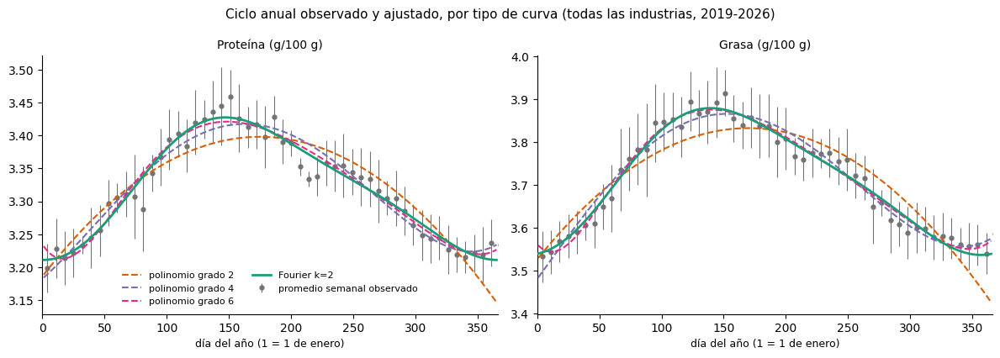

In [82]:
D["sem_anio"] = (D["doy"] - 1) // 7                 # semana del año 0..52
obs = {v: RL.se_por_bin(D[v].to_numpy(), D["sem_anio"].to_numpy(), D["bloque"].to_numpy()) for v in OBJ}
ajustes = {f"polinomio grado {g}": [("poly", g)] for g in range(1, 7)}
ajustes.update({f"Fourier k={k}": [("fourier", k)] for k in (1, 2, 3)})
curvas, saltos = {}, []
for nombre, comps in ajustes.items():
    m = RL.construir(comps).fit(D, Y)
    cu = RL.curva_anual(m, D)
    curvas[nombre] = cu
    saltos.append({"modelo": nombre, **{f"salto 31-dic → 1-ene, {v} (g/100 g)": cu[0, j] - cu[-1, j] for j, v in enumerate(OBJ)},
                   **{f"rango anual, {v}": np.ptp(cu[:, j]) for j, v in enumerate(OBJ)}})
saltos = pd.DataFrame(saltos)
print("Salto entre el 31-dic y el 1-ene de cada curva (y rango de la curva en el año):")
print(saltos.round(4).to_string(index=False))
saltos.to_csv(SALIDA / "saltos_diciembre_enero.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
estilos = {"polinomio grado 2": ("#d95f02", "--"), "polinomio grado 4": ("#7570b3", "--"), "polinomio grado 6": ("#e7298a", "--"), "Fourier k=2": ("#1b9e77", "-")}
dias = np.arange(1, 366)
for j, v in enumerate(OBJ):
    a = ax[j]
    o = obs[v]
    a.errorbar(o["bin"] * 7 + 4, o["media"], yerr=1.96 * o["se"], fmt="o", color="0.45", ms=3.5, lw=0.8, label="promedio semanal observado", zorder=1)
    for nombre, (col, ls) in estilos.items():
        a.plot(dias, curvas[nombre][:, j], color=col, ls=ls, lw=2 if "Fourier" in nombre else 1.5, label=nombre, zorder=3)
    a.set_title(("Proteína" if v == "proteina" else "Grasa") + " (g/100 g)"); a.set_xlabel("día del año (1 = 1 de enero)")
    a.set_xlim(0, 366)
    if j == 0: a.legend(loc="lower center", ncol=2)
fig.suptitle("Ciclo anual observado y ajustado, por tipo de curva (todas las industrias, 2019-2026)", fontsize=11)
fig.tight_layout(); fig.savefig(SALIDA / "fig1_ciclo_observado_vs_ajustado.png", dpi=DPI); plt.show()

**En simple:** los puntos grises son lo que se midió en promedio cada semana del año; las líneas son lo que cada modelo dice que es «lo normal» para esa fecha.
Si una línea sigue a los puntos, capta el ciclo; si en los bordes (principio y fin del año) se va para otro lado o no coincide entre el 31 de diciembre y el 1.º
de enero, es el defecto del polinomio, que no sabe que el año es un círculo. La tabla de arriba pone en números ese salto.

### 4 · Temperatura, estación y anomalía
La temperatura sube y baja con las estaciones, igual que la composición de la leche. Si se la usa sola, lleva el efecto de la estación. Para separarlos
se calcula, para cada día, la **anomalía** = temperatura media de los últimos N días menos su **climatología** (el ciclo medio de la temperatura, ajustado con
3 armónicos usando solo los años 2015–2023 y sin mirar la leche). La anomalía es cuánto más caluroso o más frío estuvo respecto de lo normal para esa fecha.

In [83]:
filas = []
for n in RL.VENTANAS_T:
    t, an = D[f"t{n}"], D[f"an{n}"]
    f = {"ventana (días)": n, "sd temperatura (°C)": t.std(), "sd anomalía (°C)": an.std(),
         "% de la varianza de la temperatura que es estación": 100 * (1 - an.var() / t.var())}
    for v in OBJ:
        f[f"corr {v} con temperatura"] = np.corrcoef(D[v], t)[0, 1]
        f[f"corr {v} con anomalía"] = np.corrcoef(D[v], an)[0, 1]
    filas.append(f)
print(pd.DataFrame(filas).round(3).to_string(index=False))

 ventana (días)  sd temperatura (°C)  sd anomalía (°C)  % de la varianza de la temperatura que es estación  corr proteina con temperatura  corr proteina con anomalía  corr grasa con temperatura  corr grasa con anomalía
              7                6.167             2.567                                              82.672                         -0.396                      -0.200                      -0.278                   -0.109
             14                6.005             2.061                                              88.217                         -0.381                      -0.210                      -0.265                   -0.111
             30                5.802             1.526                                              93.081                         -0.330                      -0.176                      -0.228                   -0.096


### 5 · Todos los modelos, con validación temporal
Se arma una grilla de modelos de menor a mayor complejidad (para cada objetivo, proteína y grasa, que se ajustan juntos con `LinearRegression`).
Primero los de **forma del ciclo**: las referencias (media global, media por industria), el mes como one-hot, polinomios de grado 1 a 6 y Fourier de k = 1 a 3.
Para cada uno: error **de entrenamiento** (ajustado hasta 2023), de **validación** (ventana que crece por año, 2021–2023) y de **prueba** (ajustado hasta 2023, probado 2024–2026).

In [84]:
MA = {"media global": [], "media por industria": [("industria",)], "mes (one-hot)": [("mes",)]}
for g in range(1, 7): MA[f"polinomio grado {g}"] = [("poly", g)]
for k in (1, 2, 3): MA[f"Fourier k={k}"] = [("fourier", k)]
tmA, rodA = RL.tabla_modelos(D, MA)

def ancho(tm, nombres, etapa, metricas=("mae", "rmse", "r2", "rmse_sem")):
    t = tm[(tm["etapa"] == etapa) & tm["modelo"].isin(nombres)].pivot(index="modelo", columns="objetivo", values=list(metricas))
    t = t.loc[list(nombres)]
    t = t.reorder_levels([1, 0], axis=1).sort_index(axis=1, level=0, sort_remaining=False)
    return t[[(o, m) for o in OBJ for m in metricas]]

for etapa in ("entrenamiento", "validación 2021-23", "prueba 2024-26"):
    print(f"\n=== {etapa} (MAE, RMSE y R² por muestra; rmse_sem = RMSE de los promedios semanales por industria; g/100 g) ===")
    print(ancho(tmA, MA, etapa).round(4).to_string())
tmA.to_csv(SALIDA / "metricas_ciclo.csv", index=False)


=== entrenamiento (MAE, RMSE y R² por muestra; rmse_sem = RMSE de los promedios semanales por industria; g/100 g) ===
objetivo            proteina                            grasa                         
                         mae    rmse      r2 rmse_sem     mae    rmse      r2 rmse_sem
modelo                                                                                
media global          0.1262  0.1617  0.0000   0.0908  0.2380  0.3257  0.0000   0.1491
media por industria   0.1257  0.1609  0.0098   0.0898  0.2366  0.3240  0.0102   0.1436
mes (one-hot)         0.1128  0.1465  0.1790   0.0572  0.2186  0.3068  0.1130   0.1032
polinomio grado 1     0.1258  0.1611  0.0073   0.0892  0.2368  0.3246  0.0066   0.1461
polinomio grado 2     0.1140  0.1481  0.1609   0.0610  0.2203  0.3084  0.1033   0.1081
polinomio grado 3     0.1137  0.1476  0.1667   0.0594  0.2189  0.3070  0.1113   0.1037
polinomio grado 4     0.1134  0.1472  0.1714   0.0585  0.2185  0.3067  0.1133   0.1031
polinomio g

### 6 · Elegir el grado por validación (sobreajuste)
**Regla.** De los modelos de forma del ciclo (mes, polinomios, Fourier) se mira el error de **validación** (solo 2021–2023, nunca la prueba). Se calcula un
puntaje: el RMSE semanal de cada modelo dividido por el mejor, promediado entre proteína y grasa. Se elige el modelo **más simple (menos parámetros) que quede
a menos del 0,5 % del mejor**; si hay empate en parámetros, gana el cíclico (Fourier). Abajo se ve qué pasaría con otras tolerancias,
y por qué importa: un ciclo de un solo armónico es una onda simétrica (el pico cae justo medio año después del mínimo), y el segundo armónico le permite subir más rápido de lo que baja.

In [85]:
cand = ["media por industria", "mes (one-hot)"] + [f"Fourier k={k}" for k in (1, 2, 3)] + [f"polinomio grado {g}" for g in range(1, 7)]
n_par = {n: RL.n_parametros(MA[n], D) for n in cand}
ciclo_nombre, sel = RL.elegir(tmA, cand, n_par)
print(sel.round(4).to_string())
print("\nelegido:", ciclo_nombre, "·", n_par[ciclo_nombre], "parámetros del ciclo")
print("sensibilidad a la tolerancia:", {f"{100 * t:.1f} %": RL.elegir(tmA, cand, n_par, t)[0] for t in (0, 0.005, 0.01)})
CICLO = MA[ciclo_nombre]
print("\nPico y mínimo de la curva según el número de armónicos (ajuste con todos los datos):")
pm = []
for k in (1, 2, 3):
    amp, pk, mn = RL.ciclo_simple(D, D, [("fourier", k)])
    for j, v in enumerate(OBJ):
        pm.append({"armónicos": k, "objetivo": v, "amplitud (g/100 g)": amp[j], "pico": RL.dia_del_anio(pk[j]), "mínimo": RL.dia_del_anio(mn[j]), "días del mínimo al pico": (pk[j] - mn[j]) % 365})
print(pd.DataFrame(pm).round(3).to_string(index=False))

                     parámetros  puntaje  dentro de la tolerancia
media por industria           8   1.5333                    False
mes (one-hot)                12   1.0576                    False
Fourier k=1                   2   1.0117                    False
Fourier k=2                   4   1.0027                     True
Fourier k=3                   6   1.0189                    False
polinomio grado 1             1   1.5108                    False
polinomio grado 2             2   1.0400                    False
polinomio grado 3             3   1.0156                    False
polinomio grado 4             4   1.0143                    False
polinomio grado 5             5   1.0108                    False
polinomio grado 6             6   1.0184                    False



elegido: Fourier k=2 · 4 parámetros del ciclo
sensibilidad a la tolerancia: {'0.0 %': 'Fourier k=2', '0.5 %': 'Fourier k=2', '1.0 %': 'Fourier k=1'}

Pico y mínimo de la curva según el número de armónicos (ajuste con todos los datos):
 armónicos objetivo  amplitud (g/100 g)   pico mínimo  días del mínimo al pico
         1 proteina               0.204 15 jun 15 dic                      182
         1    grasa               0.325  8 jun  7 dic                      183
         2 proteina               0.216 27 may 31 dic                      147
         2    grasa               0.343 19 may 23 dic                      147
         3 proteina               0.226 26 may 19 dic                      158
         3    grasa               0.333  9 may 28 dic                      132


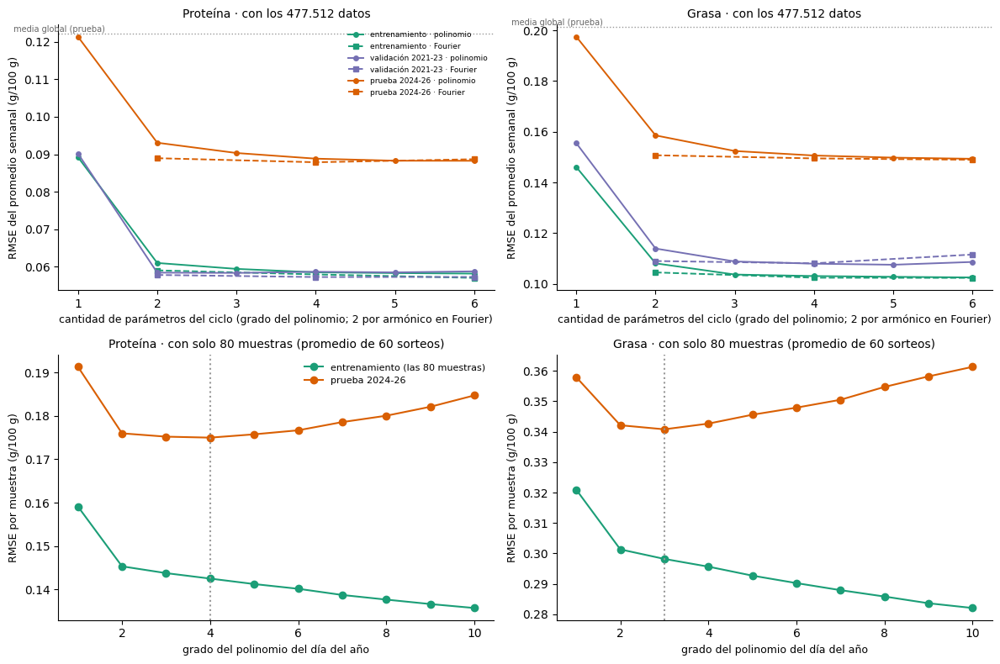

grado con menor error de prueba usando 80 muestras: objetivo  grado  rmse_entrenamiento  rmse_prueba
   grasa      3              0.2982       0.3408
proteina      4              0.1425       0.1750
proteina: con 80 muestras el error de prueba es mínimo en el grado 4 (0.1750); con grado 1 es 0.1913 y con grado 10 es 0.1847 (5.6 % más que en el mínimo); grado 10 queda mejor que el grado 1, pero peor que el mínimo.
grasa: con 80 muestras el error de prueba es mínimo en el grado 3 (0.3408); con grado 1 es 0.3579 y con grado 10 es 0.3613 (6.0 % más que en el mínimo); grado 10 queda peor que el grado 1.


In [86]:
# Curva de error según la complejidad: entrenamiento, validación y prueba (arriba, con todos los datos) y el mismo experimento con pocas muestras (abajo)
N_POCAS, SORTEOS = 80, 60
pocas = RL.curva_pocas_muestras(D, grados=range(1, 11), n=N_POCAS, sorteos=SORTEOS)
col = {"entrenamiento": "#1b9e77", "validación 2021-23": "#7570b3", "prueba 2024-26": "#d95f02"}
fig, ax = plt.subplots(2, 2, figsize=(12, 8))
for j, v in enumerate(OBJ):
    a = ax[0, j]
    for etapa, cc in col.items():
        for fam, pref, ls, mk in (("polinomio", "polinomio grado ", "-", "o"), ("Fourier", "Fourier k=", "--", "s")):
            ns = [n for n in MA if n.startswith(pref)]
            x = [n_par[n] if n in n_par else RL.n_parametros(MA[n], D) for n in ns]
            y = [tmA[(tmA["modelo"] == n) & (tmA["etapa"] == etapa) & (tmA["objetivo"] == v)]["rmse_sem"].iloc[0] for n in ns]
            a.plot(x, y, ls=ls, marker=mk, color=cc, ms=4, lw=1.4, label=f"{etapa} · {fam}")
    ref = tmA[(tmA["modelo"] == "media global") & (tmA["etapa"] == "prueba 2024-26") & (tmA["objetivo"] == v)]["rmse_sem"].iloc[0]
    a.axhline(ref, color="0.6", ls=":", lw=1); a.text(0.15, ref, " media global (prueba)", va="bottom", fontsize=7, color="0.4")
    a.set_title(f"{'Proteína' if v == 'proteina' else 'Grasa'} · con los {miles(len(D))} datos")
    a.set_xlabel("cantidad de parámetros del ciclo (grado del polinomio; 2 por armónico en Fourier)"); a.set_ylabel("RMSE del promedio semanal (g/100 g)")
    if j == 0: a.legend(fontsize=6.5, ncol=1, loc="upper right")
    b = ax[1, j]
    p = pocas[pocas["objetivo"] == v]
    b.plot(p["grado"], p["rmse_entrenamiento"], "o-", color=col["entrenamiento"], label="entrenamiento (las %d muestras)" % N_POCAS)
    b.plot(p["grado"], p["rmse_prueba"], "o-", color=col["prueba 2024-26"], label="prueba 2024-26")
    gmin = int(p.loc[p["rmse_prueba"].idxmin(), "grado"]); b.axvline(gmin, color="0.6", ls=":")
    b.set_title(f"{'Proteína' if v == 'proteina' else 'Grasa'} · con solo {N_POCAS} muestras (promedio de {SORTEOS} sorteos)")
    b.set_xlabel("grado del polinomio del día del año"); b.set_ylabel("RMSE por muestra (g/100 g)")
    if j == 0: b.legend()
fig.tight_layout(); fig.savefig(SALIDA / "fig2_error_vs_grado.png", dpi=DPI); plt.show()
print("grado con menor error de prueba usando %d muestras:" % N_POCAS, pocas.loc[pocas.groupby("objetivo")["rmse_prueba"].idxmin(), ["objetivo", "grado", "rmse_entrenamiento", "rmse_prueba"]].round(4).to_string(index=False))
pocas.to_csv(SALIDA / "sobreajuste_pocas_muestras.csv", index=False)
for v in OBJ:
    q = pocas[pocas["objetivo"] == v].set_index("grado")["rmse_prueba"]
    gm = int(q.idxmin())
    print(f"{v}: con {N_POCAS} muestras el error de prueba es mínimo en el grado {gm} ({q[gm]:.4f}); con grado 1 es {q[1]:.4f} y con grado 10 es {q[10]:.4f} ({100 * (q[10] / q[gm] - 1):.1f} % más que en el mínimo)"
          + ("; grado 10 queda peor que el grado 1." if q[10] > q[1] else "; grado 10 queda mejor que el grado 1, pero peor que el mínimo."))

**En simple:** de izquierda a derecha el modelo se hace más flexible. Arriba, con casi 480 mil datos: pasar de 1 a 2 parámetros baja mucho el error (es la diferencia entre
una recta y una curva que sube y baja), pero de ahí en adelante el de entrenamiento casi no cambia y el de validación y el de prueba dejan de mejorar (con tres armónicos en la
grasa, incluso empeora un poco la validación). Con datos de sobra, más curvas ni ayudan ni hacen mucho daño. Abajo está la lección clásica: con solo 80 muestras, a medida que se
le agregan curvas al polinomio **el error con los datos que ya vio baja siempre, pero el de los datos nuevos tiene un mínimo en un grado bajo y sube después** (la línea de abajo de la figura dice cuál es el
grado del mínimo y cuánto más error hay con grado 10): se está aprendiendo el ruido, no el ciclo.

### 7 · ¿Qué agrega la temperatura sobre la estación?
Sobre el ciclo elegido se suman, de a uno, la **industria**, la **temperatura** y la **anomalía** (ventanas de 7, 14 y 30 días; lineal y con término cuadrático para el estrés por calor).
Dos modelos extra sirven para el diagnóstico: la **temperatura sola** (sin ciclo; lleva la confusión estación–temperatura) y la **temperatura absoluta junto con el ciclo**
(debería ser lo mismo que la anomalía: controlar por la estación es lo mismo que restarle la climatología). Y una **tendencia lineal** (años), como modelo aparte, para el
corrimiento que no es estacional visto en la sección 2.

In [87]:
MB = {"ciclo": CICLO, "ciclo + industria": CICLO + [("industria",)], "ciclo + tendencia": CICLO + [("tendencia",)],
      "ciclo + industria + tendencia": CICLO + [("industria",), ("tendencia",)]}
for n in RL.VENTANAS_T:
    MB[f"temperatura sola {n} d"] = [("temp", n, 1)]
    MB[f"ciclo + temperatura absoluta {n} d"] = CICLO + [("temp", n, 1)]
    MB[f"ciclo + anomalía {n} d"] = CICLO + [("anom", n, 1)]
    MB[f"ciclo + anomalía {n} d (grado 2)"] = CICLO + [("anom", n, 2)]
    MB[f"ciclo + industria + anomalía {n} d"] = CICLO + [("industria",), ("anom", n, 1)]
    MB[f"ciclo + industria + anomalía {n} d (grado 2)"] = CICLO + [("industria",), ("anom", n, 2)]
    MB[f"ciclo + anomalía {n} d + tendencia"] = CICLO + [("anom", n, 1), ("tendencia",)]
MB["temperatura sola 7 d (grado 2)"] = [("temp", 7, 2)]
tmB, rodB = RL.tabla_modelos(D, MB)
tm = pd.concat([tmA[~tmA["modelo"].isin(MB)], tmB], ignore_index=True)
rod = {**rodA, **rodB}
tm.to_csv(SALIDA / "metricas_todas.csv", index=False)

principales = ["ciclo", "ciclo + industria"] + [f"ciclo + anomalía {n} d" for n in RL.VENTANAS_T] + \
              [f"ciclo + anomalía {n} d (grado 2)" for n in RL.VENTANAS_T] + [f"ciclo + industria + anomalía {n} d" for n in RL.VENTANAS_T]
for etapa in ("validación 2021-23", "prueba 2024-26"):
    print(f"\n=== {etapa} ===")
    print(ancho(tm, ["media global"] + principales, etapa).round(4).to_string())


=== validación 2021-23 ===
objetivo                          proteina                            grasa                         
                                       mae    rmse      r2 rmse_sem     mae    rmse      r2 rmse_sem
modelo                                                                                              
media global                        0.1256  0.1608 -0.0189   0.0904  0.2422  0.3323 -0.0483   0.1587
ciclo                               0.1127  0.1461  0.1594   0.0572  0.2217  0.3113  0.0797   0.1081
ciclo + industria                   0.1125  0.1457  0.1637   0.0585  0.2217  0.3111  0.0811   0.1094
ciclo + anomalía 7 d                0.1112  0.1444  0.1782   0.0528  0.2210  0.3107  0.0836   0.1064
ciclo + anomalía 14 d               0.1114  0.1447  0.1750   0.0541  0.2214  0.3110  0.0814   0.1074
ciclo + anomalía 30 d               0.1128  0.1463  0.1570   0.0581  0.2218  0.3114  0.0793   0.1083
ciclo + anomalía 7 d (grado 2)      0.1113  0.1445  0.1773   0.

In [88]:
# Elección de la ventana y de los términos con la validación (2021-23) solo. Se compara ciclo / + industria / + anomalía (lineal y grado 2), con y sin industria.
cand_T = ["ciclo", "ciclo + industria"] + [f"ciclo + anomalía {n} d" for n in RL.VENTANAS_T] + [f"ciclo + anomalía {n} d (grado 2)" for n in RL.VENTANAS_T] \
         + [f"ciclo + industria + anomalía {n} d" for n in RL.VENTANAS_T] + [f"ciclo + industria + anomalía {n} d (grado 2)" for n in RL.VENTANAS_T]
n_par_T = {n: RL.n_parametros(MB[n], D) for n in cand_T}
elegido_nombre, selT = RL.elegir(tm, cand_T, n_par_T)
print(selT.round(4).to_string())
print("\nmodelo elegido:", elegido_nombre, "·", n_par_T[elegido_nombre], "parámetros ·", MB[elegido_nombre])
# ventana de temperatura con mejor validación entre los modelos "ciclo + anomalía N d"
pv = RL.puntaje_validacion(tm, [f"ciclo + anomalía {n} d" for n in RL.VENTANAS_T])
NSTAR = RL.VENTANAS_T[int(np.argmin(pv.to_numpy()))]
print("ventana con mejor validación (ciclo + anomalía N d):", NSTAR, "días")
ELEGIDO = MB[elegido_nombre]

                                             parámetros  puntaje  dentro de la tolerancia
ciclo                                                 4   1.0498                    False
ciclo + industria                                    12   1.0680                    False
ciclo + anomalía 7 d                                  5   1.0000                     True
ciclo + anomalía 14 d                                 5   1.0161                    False
ciclo + anomalía 30 d                                 5   1.0586                    False
ciclo + anomalía 7 d (grado 2)                        6   1.0035                     True
ciclo + anomalía 14 d (grado 2)                       6   1.0188                    False
ciclo + anomalía 30 d (grado 2)                       6   1.0515                    False
ciclo + industria + anomalía 7 d                     13   1.0229                    False
ciclo + industria + anomalía 14 d                    13   1.0393                    False
ciclo + in

In [89]:
# Cuánto agrega la temperatura sobre la estación: ciclo vs ciclo + anomalía (ventana elegida), en cada etapa
base, con_t, cuad = "ciclo", f"ciclo + anomalía {NSTAR} d", f"ciclo + anomalía {NSTAR} d (grado 2)"
filas = []
for etapa in ("validación 2021-23", "prueba 2024-26"):
    for v in OBJ:
        g = lambda n, m: tm[(tm["modelo"] == n) & (tm["etapa"] == etapa) & (tm["objetivo"] == v)][m].iloc[0]
        for m in ("rmse", "rmse_sem", "mae", "r2"):
            filas.append({"etapa": etapa, "objetivo": v, "métrica": m, "media global": g("media global", m), "ciclo": g(base, m),
                          "ciclo + anomalía": g(con_t, m), "ciclo + anomalía grado 2": g(cuad, m)})
aporte = pd.DataFrame(filas)
aporte["mejora de la anomalía sobre el ciclo (%)"] = np.where(aporte["métrica"] == "r2", np.nan, 100 * (1 - aporte["ciclo + anomalía"] / aporte["ciclo"]))
aporte["mejora del grado 2 sobre el lineal (%)"] = np.where(aporte["métrica"] == "r2", np.nan, 100 * (1 - aporte["ciclo + anomalía grado 2"] / aporte["ciclo + anomalía"]))
print(f"Ventana elegida: {NSTAR} días. Mejora = reducción del error (positivo = mejor).")
print(aporte.round(4).to_string(index=False))
aporte.to_csv(SALIDA / "aporte_temperatura.csv", index=False)

print("\nDiagnóstico de la confusión (prueba 2024-26, RMSE semanal): la temperatura sola vs el ciclo, y la absoluta con ciclo vs la anomalía con ciclo")
dg = ancho(tm, ["media global", base, f"temperatura sola {NSTAR} d", f"ciclo + temperatura absoluta {NSTAR} d", con_t], "prueba 2024-26", ("rmse", "rmse_sem", "r2"))
print(dg.round(4).to_string())

Ventana elegida: 7 días. Mejora = reducción del error (positivo = mejor).
             etapa objetivo  métrica  media global  ciclo  ciclo + anomalía  ciclo + anomalía grado 2  mejora de la anomalía sobre el ciclo (%)  mejora del grado 2 sobre el lineal (%)
validación 2021-23 proteina     rmse        0.1608 0.1461            0.1444                    0.1445                                    1.1268                                 -0.0582
validación 2021-23 proteina rmse_sem        0.0904 0.0572            0.0528                    0.0531                                    7.7080                                 -0.4615
validación 2021-23 proteina      mae        0.1256 0.1127            0.1112                    0.1113                                    1.3343                                 -0.0879
validación 2021-23 proteina       r2       -0.0189 0.1594            0.1782                    0.1773                                       NaN                                     NaN
valida

### 8 · Año por año (ventana que crece) y el corrimiento de nivel
Para ver si lo anterior se sostiene, la ventana que crece por año da el error de cada año (se entrena con todo lo anterior a ese año). Se incluye la
**tendencia lineal**, que no es estacional: ¿ayuda a predecir el nivel de los años siguientes?

In [90]:
noms = ["media global", "ciclo", "ciclo + industria", f"ciclo + anomalía {NSTAR} d", elegido_nombre, "ciclo + tendencia", f"ciclo + anomalía {NSTAR} d + tendencia"]
noms = list(dict.fromkeys(noms))
py = RL.por_anio(D, {n: rod[n] for n in noms})
for m in ("rmse", "rmse_sem"):
    print(f"\n{m} por año de la ventana que crece (g/100 g):")
    print(py.pivot_table(index=["objetivo", "modelo"], columns="anio", values=m, sort=False).reindex([(o, n) for o in OBJ for n in noms]).round(4).to_string())
mej = py.pivot_table(index=["objetivo", "anio"], columns="modelo", values="rmse_sem")
for v in OBJ:
    mv = mej.loc[v]
    print(f"\n{v}: años (de {len(mv)}) en que 'ciclo + anomalía {NSTAR} d' tiene menor RMSE semanal que 'ciclo':", int((mv[f'ciclo + anomalía {NSTAR} d'] < mv['ciclo']).sum()),
          "· años en que 'ciclo + tendencia' lo tiene menor que 'ciclo':", int((mv['ciclo + tendencia'] < mv['ciclo']).sum()))
py.to_csv(SALIDA / "metricas_por_anio.csv", index=False)


rmse por año de la ventana que crece (g/100 g):
anio                                         2021    2022    2023    2024    2025    2026
objetivo modelo                                                                          
proteina media global                      0.1617  0.1649  0.1558  0.1808  0.1832  0.2086
         ciclo                             0.1467  0.1470  0.1446  0.1657  0.1697  0.1793
         ciclo + industria                 0.1468  0.1463  0.1441  0.1648  0.1675  0.1781
         ciclo + anomalía 7 d              0.1458  0.1442  0.1435  0.1617  0.1686  0.1736
         ciclo + tendencia                 0.1672  0.1547  0.1509  0.1662  0.1690  0.1685
         ciclo + anomalía 7 d + tendencia  0.1644  0.1505  0.1470  0.1633  0.1655  0.1620
grasa    media global                      0.3252  0.3490  0.3207  0.3309  0.3476  0.3917
         ciclo                             0.3044  0.3236  0.3044  0.3120  0.3307  0.3537
         ciclo + industria                 0.3016  

**Lectura.** Sumar la anomalía de temperatura mejora el error semanal en casi todos los años (en cuántos, arriba). La tendencia lineal, en cambio, no es confiable: cuando se la estima con pocos años
(2019–2020 para predecir 2021) empeora mucho la proteína, y recién ayuda en 2026; en la grasa ayuda en la mayoría de los años pero no en todos. El nivel de la composición se corrió, pero no a un ritmo
constante que se pueda extrapolar con seguridad.

### 9 · Residuos en el tiempo
Residuo = valor medido − lo que predice el **modelo elegido** (ajustado hasta 2023). Se promedia por mes; las líneas finas son cada industria (con 60 o más
meses de datos) y la gruesa, el promedio de todas.

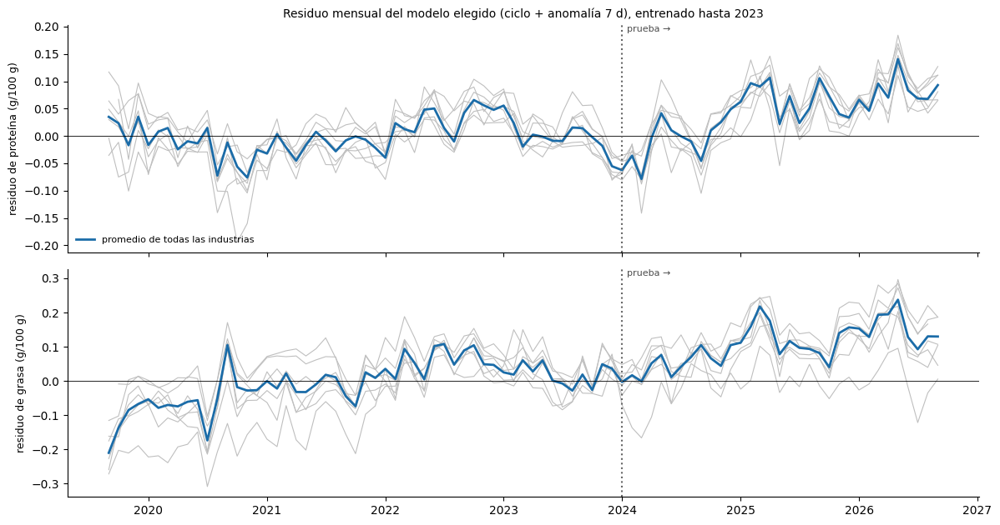

proteina: residuo medio mensual en el entrenamiento -0.001 · en la prueba (2024-26) +0.043 g/100 g
grasa: residuo medio mensual en el entrenamiento -0.004 · en la prueba (2024-26) +0.104 g/100 g


In [91]:
ent = (D["fecha"] <= RL.FIN_ENTRENAMIENTO).to_numpy()
m_el = RL.construir(ELEGIDO).fit(D[ent], Y[ent])
res_t = Y - m_el.predict(D)
D["mes_f"] = D["fecha"].dt.to_period("M").dt.to_timestamp()
fig, ax = plt.subplots(2, 1, figsize=(12, 6.4), sharex=True)
resumen_res = []
for j, v in enumerate(OBJ):
    t = pd.DataFrame({"cliente": D["cliente"], "mes": D["mes_f"], "r": res_t[:, j]})
    pm = t.pivot_table(index="mes", columns="cliente", values="r", aggfunc="mean")
    cnt = t.pivot_table(index="mes", columns="cliente", values="r", aggfunc="size")
    pm = pm.where(cnt >= 30)
    todas = t.groupby("mes")["r"].agg(["mean", "size"]); todas = todas[todas["size"] >= 100]["mean"]
    a = ax[j]
    for cli in pm.columns:
        if pm[cli].notna().sum() >= 60: a.plot(pm.index, pm[cli], color="0.75", lw=0.8)
    a.plot(todas.index, todas, color="#1b6ca8", lw=2, label="promedio de todas las industrias")
    a.axhline(0, color="k", lw=0.6); a.axvline(pd.Timestamp("2024-01-01"), color="0.4", ls=":")
    a.text(pd.Timestamp("2024-01-15"), a.get_ylim()[1], "prueba →", va="top", fontsize=8, color="0.3")
    a.set_ylabel(f"residuo de {'proteína' if v == 'proteina' else 'grasa'} (g/100 g)")
    resumen_res.append((v, todas[todas.index <= "2023-12-01"].mean(), todas[todas.index > "2023-12-01"].mean()))
ax[0].legend(loc="lower left"); ax[0].set_title(f"Residuo mensual del modelo elegido ({elegido_nombre}), entrenado hasta 2023")
fig.tight_layout(); fig.savefig(SALIDA / "fig3_residuos_en_el_tiempo.png", dpi=DPI); plt.show()
for v, a_, b_ in resumen_res:
    print(f"{v}: residuo medio mensual en el entrenamiento {a_:+.3f} · en la prueba (2024-26) {b_:+.3f} g/100 g")

**En simple:** cada punto es cuánto se equivocó el modelo en promedio ese mes (sobre cero: la leche tuvo más de lo que el modelo esperaba; bajo cero: menos). Si el modelo
captara todo lo que es regular, los residuos oscilarían al azar alrededor de cero. Las curvas grises de las industrias suben y bajan casi juntas, y en la zona de prueba
el promedio se corre del cero: queda un movimiento común, de varios meses, que no es estacional y que este modelo no explica.

### 10 · Industria dejada afuera
¿El ciclo estimado con unas industrias sirve para otra? Con `GroupKFold` por industria, cada industria se deja afuera, el modelo se ajusta con las demás y se prueba en ella (se compara con
la media global de las demás). No pueden llevar el término de industria: una industria nueva no tiene efecto propio. Se hace de dos formas: (a) con todos los años (¿se generaliza **entre industrias**?) y
(b) ajustando hasta 2023 y probando 2024–2026 en la industria que quedó afuera (industria **nueva y período futuro** a la vez).

In [92]:
MC = {"media global": [], "ciclo": CICLO, f"ciclo + anomalía {NSTAR} d": CICLO + [("anom", NSTAR, 1)]}
lo_a = RL.industria_afuera(D, MC, solo_pasado=False)
lo_b = RL.industria_afuera(D, MC, solo_pasado=True)
lo_a.insert(0, "esquema", "(a) todos los años"); lo_b.insert(0, "esquema", "(b) hasta 2023 → 2024-26")
lo = pd.concat([lo_a, lo_b], ignore_index=True)
lo.to_csv(SALIDA / "industria_afuera.csv", index=False)
for esq, g in lo.groupby("esquema", sort=False):
    print(f"\n=== {esq} ===")
    for m in ("rmse", "rmse_sem"):
        t = g.pivot_table(index=["objetivo", "industria"], columns="modelo", values=m, sort=False)[list(MC)]
        t["mejora del ciclo sobre la media (%)"] = 100 * (1 - t["ciclo"] / t["media global"])
        t["mejora de la anomalía sobre el ciclo (%)"] = 100 * (1 - t[f"ciclo + anomalía {NSTAR} d"] / t["ciclo"])
        print(f"\n{m}:"); print(t.round(4).to_string())
    n = g[g["modelo"] == "ciclo"].set_index(["objetivo", "industria"])["n"]
    for v in OBJ:
        t = g.pivot_table(index=["objetivo", "industria"], columns="modelo", values="rmse_sem", sort=False).loc[v]
        t2 = g.pivot_table(index=["objetivo", "industria"], columns="modelo", values="rmse", sort=False).loc[v]
        print(f"-> {v}: el ciclo baja el RMSE por muestra en {int((t2['ciclo'] < t2['media global']).sum())} de {len(t2)} industrias y el RMSE semanal en {int((t['ciclo'] < t['media global']).sum())} de {len(t)}")


=== (a) todos los años ===

rmse:
modelo              media global   ciclo  ciclo + anomalía 7 d  mejora del ciclo sobre la media (%)  mejora de la anomalía sobre el ciclo (%)
objetivo industria                                                                                                                           
proteina IND-81           0.1754  0.1600                0.1575                               8.7715                                    1.5685
         IND-68           0.1748  0.1597                0.1582                               8.5994                                    0.9763
         IND-59           0.1573  0.1420                0.1389                               9.6973                                    2.2184
         IND-88           0.1825  0.1660                0.1639                               9.0881                                    1.2342
         IND-29           0.1631  0.1416                0.1397                              13.1764              

### 11 · Interpretación: amplitud, pico y efecto de 1 °C de anomalía
El modelo para interpretar es el ciclo elegido **más la industria como control** (para que el efecto de la temperatura sea dentro de cada industria) y la anomalía de la
ventana elegida; se ajusta con **todos los datos** (2019–2026) y los intervalos de 95 % salen de **1000 remuestreos de bloques de 28 días** (y, para comparar, de semanas sueltas).
Las ecuaciones normales por bloque dan exactamente los mismos coeficientes que `LinearRegression` (el notebook lo verifica).

In [93]:
comps_int = CICLO + [("industria",), ("anom", NSTAR, 2)]
aj28 = RL.ajuste_bloques(comps_int, D, bloque="bloque", B=B)
ajsem = RL.ajuste_bloques(comps_int, D, bloque="sem_id", B=B)
print(f"modelo de interpretación: {comps_int}\nmuestras {miles(aj28['n'])} · bloques de 28 días: {aj28['n_bloques']} · semanas: {ajsem['n_bloques']}")
for nombre, aj in (("bloques de 28 días", aj28), ("semanas", ajsem)):
    print(f"\n--- Ciclo anual estimado (IC 95 % por bootstrap de {nombre}) ---")
    ap = RL.amplitud_pico(aj, D)
    print(ap.round(3).to_string(index=False))
    if nombre.startswith("bloques"): ap.to_csv(SALIDA / "amplitud_pico.csv", index=False)

modelo de interpretación: [('fourier', 2), ('industria',), ('anom', 7, 2)]
muestras 477.512 · bloques de 28 días: 93 · semanas: 366

--- Ciclo anual estimado (IC 95 % por bootstrap de bloques de 28 días) ---
objetivo  amplitud pico a pico (g/100 g)  ic95 inf  ic95 sup  % del promedio   pico      pico ic95 mínimo    mínimo ic95
proteina                           0.206     0.179     0.237           6.211 25 may 14 may a 9 jun 30 dic 19 dic a 9 ene
   grasa                           0.333     0.292     0.381           8.962 17 may  3 may a 5 jun 23 dic 10 dic a 2 ene

--- Ciclo anual estimado (IC 95 % por bootstrap de semanas) ---
objetivo  amplitud pico a pico (g/100 g)  ic95 inf  ic95 sup  % del promedio   pico      pico ic95 mínimo     mínimo ic95
proteina                           0.206     0.190     0.223           6.211 25 may 18 may a 3 jun 30 dic  23 dic a 5 ene
   grasa                           0.333     0.307     0.360           8.962 17 may 8 may a 27 may 23 dic 16 dic a 28 di

In [94]:
# ¿La fase y la amplitud se repiten año a año y entre industrias? (sin bootstrap: ciclo estimado por separado en cada año / industria)
amp_pico_simple = lambda dd, comps: RL.ciclo_simple(dd, D, comps)
anual = []
for a in range(2020, 2026):
    dd = D[D["anio"] == a]
    amp, pk, mn = amp_pico_simple(dd, CICLO + [("industria",)])
    for j, v in enumerate(OBJ):
        anual.append({"año": a, "objetivo": v, "muestras": len(dd), "amplitud (g/100 g)": amp[j], "pico": RL.dia_del_anio(pk[j]), "mínimo": RL.dia_del_anio(mn[j]), "pico (día)": pk[j]})
anual = pd.DataFrame(anual)
print("Ciclo estimado año por año (años completos, ciclo + industria):"); print(anual.drop(columns="pico (día)").round(3).to_string(index=False))
for v in OBJ:
    pk = anual[anual["objetivo"] == v]["pico (día)"]
    print(f"{v}: día del pico entre años: mínimo {pk.min()}, máximo {pk.max()} (rango {pk.max() - pk.min()} días)")
por_ind = []
for cli, dd in D.groupby("cliente"):
    if dd["anio"].nunique() < 5 or len(dd) < 5000: continue
    amp, pk, mn = amp_pico_simple(dd, CICLO)
    for j, v in enumerate(OBJ):
        por_ind.append({"industria": cli, "objetivo": v, "muestras": len(dd), "amplitud (g/100 g)": amp[j], "pico": RL.dia_del_anio(pk[j]), "mínimo": RL.dia_del_anio(mn[j])})
por_ind = pd.DataFrame(por_ind)
print("\nCiclo estimado por industria (industrias con 5 años o más y 5000 muestras o más):"); print(por_ind.round(3).to_string(index=False))
anual.to_csv(SALIDA / "ciclo_por_anio.csv", index=False); por_ind.to_csv(SALIDA / "ciclo_por_industria.csv", index=False)

Ciclo estimado año por año (años completos, ciclo + industria):
 año objetivo  muestras  amplitud (g/100 g)   pico mínimo
2020 proteina     71773               0.218  9 jun 30 nov
2020    grasa     71773               0.290 12 may  4 ene
2021 proteina     62865               0.199  4 jun 31 dic
2021    grasa     62865               0.316  8 jun 10 dic
2022 proteina     75276               0.260 15 may 13 ene
2022    grasa     75276               0.375 20 may 30 dic
2023 proteina     74880               0.174 13 jun 20 dic
2023    grasa     74880               0.317 15 may 31 dic
2024 proteina     68887               0.253  5 jun  1 feb
2024    grasa     68887               0.324 30 may  5 ene
2025 proteina     65790               0.222  1 may 25 dic
2025    grasa     65790               0.323 10 may 15 dic
proteina: día del pico entre años: mínimo 121, máximo 164 (rango 43 días)
grasa: día del pico entre años: mínimo 130, máximo 159 (rango 29 días)

Ciclo estimado por industria (indust

In [95]:
# Efecto de 1 °C de anomalía (g/100 g por °C): ajuste lineal y con término cuadrático, y robustez
n_lin, n_cuad = f"anom__an{NSTAR}", f"anom__an{NSTAR}^2"
aj_lin28 = RL.ajuste_bloques(CICLO + [("industria",), ("anom", NSTAR, 1)], D, bloque="bloque", B=B)
aj_linsem = RL.ajuste_bloques(CICLO + [("industria",), ("anom", NSTAR, 1)], D, bloque="sem_id", B=B)
aj_tend = RL.ajuste_bloques(CICLO + [("industria",), ("anom", NSTAR, 1), ("tendencia",)], D, bloque="bloque", B=B)
aj_exac = RL.ajuste_bloques(CICLO + [("industria",), ("anom", NSTAR, 1)], D, bloque="bloque", B=B, mascara=D["exacta"].to_numpy())
aj_sola = RL.ajuste_bloques([("temp", NSTAR, 1)], D, bloque="bloque", B=B)
filas = []
def agregar(desc, aj, nombre):
    for v in OBJ:
        e, lo_, hi_ = RL.coef(aj, nombre, v)
        filas.append({"estimación": desc, "objetivo": v, "g/100 g por °C": e, "ic95 inf": lo_, "ic95 sup": hi_, "el 0 está dentro": lo_ <= 0 <= hi_})
agregar(f"anomalía {NSTAR} d, lineal, bloques de 28 d (principal)", aj_lin28, n_lin)
agregar(f"anomalía {NSTAR} d, lineal, semanas", aj_linsem, n_lin)
agregar(f"anomalía {NSTAR} d, lineal, con tendencia lineal", aj_tend, n_lin)
agregar(f"anomalía {NSTAR} d, lineal, solo fechas escritas en el informe ({miles(D['exacta'].sum())} muestras)", aj_exac, n_lin)
agregar(f"anomalía {NSTAR} d, lineal, ajuste con término cuadrático (parte lineal)", aj28, n_lin)
agregar(f"temperatura {NSTAR} d SOLA, sin ciclo (mezcla estación y temperatura)", aj_sola, f"temp__t{NSTAR}")
efecto = pd.DataFrame(filas)
print(f"Efecto de +1 °C de la temperatura (media de {NSTAR} días) sobre la composición, IC 95 %:")
print(efecto.round(4).to_string(index=False))
efecto.to_csv(SALIDA / "efecto_anomalia.csv", index=False)
for v in OBJ:
    e, lo_, hi_ = RL.coef(aj_tend, "tendencia__anios", v)
    print(f"tendencia lineal ({v}, en el ajuste con todos los datos): {e:+.4f} g/100 g por año (IC 95 % {lo_:+.4f} a {hi_:+.4f})")
print(f"\nSD de la anomalía de {NSTAR} días: {D[f'an{NSTAR}'].std():.2f} °C · percentiles 1 y 99: {D[f'an{NSTAR}'].quantile(.01):.1f} y {D[f'an{NSTAR}'].quantile(.99):.1f} °C")
for v in OBJ:
    e, lo_, hi_ = RL.coef(aj_lin28, n_lin, v)
    s = D[f"an{NSTAR}"].std()
    print(f"{v}: una anomalía de +1 sd ({s:.1f} °C) mueve la composición {e * s:+.3f} g/100 g (IC {lo_ * s:+.3f} a {hi_ * s:+.3f}), frente a un ciclo de punta a punta de {RL.amplitud_pico(aj28, D).set_index('objetivo').loc[v, 'amplitud pico a pico (g/100 g)']:.3f}")

Efecto de +1 °C de la temperatura (media de 7 días) sobre la composición, IC 95 %:
                                                                 estimación objetivo  g/100 g por °C  ic95 inf  ic95 sup  el 0 está dentro
                          anomalía 7 d, lineal, bloques de 28 d (principal) proteina         -0.0105   -0.0125   -0.0084             False
                          anomalía 7 d, lineal, bloques de 28 d (principal)    grasa         -0.0099   -0.0132   -0.0063             False
                                              anomalía 7 d, lineal, semanas proteina         -0.0105   -0.0123   -0.0086             False
                                              anomalía 7 d, lineal, semanas    grasa         -0.0099   -0.0126   -0.0069             False
                                 anomalía 7 d, lineal, con tendencia lineal proteina         -0.0109   -0.0128   -0.0090             False
                                 anomalía 7 d, lineal, con tendencia lineal    gras

In [96]:
# ¿Aporta el término cuadrático (estrés por calor)?
filas = []
for v in OBJ:
    e, lo_, hi_ = RL.coef(aj28, n_cuad, v); e2, lo2, hi2 = RL.coef(ajsem, n_cuad, v)
    filas.append({"objetivo": v, "coef. de a² (g/100 g por °C²), bloques 28 d": e, "ic95 inf": lo_, "ic95 sup": hi_, "0 dentro (28 d)": lo_ <= 0 <= hi_,
                  "ic95 semanas inf": lo2, "ic95 semanas sup": hi2, "0 dentro (semanas)": lo2 <= 0 <= hi2})
cu = pd.DataFrame(filas)
print(cu.round(5).to_string(index=False))
print()
for v in OBJ:
    c0 = RL.efecto_anomalia(aj28, n_lin, n_cuad, v, [-5, -3, 3, 5])
    cl0 = RL.efecto_anomalia(aj_lin28, n_lin, None, v, [-5, -3, 3, 5])
    print(f"{v}: efecto (g/100 g) de una anomalía de -5, -3, +3, +5 °C · modelo cuadrático:", np.round(c0[0], 3), "· modelo lineal:", np.round(cl0[0], 3))
print("\nPredicción (RMSE semanal): lineal vs cuadrático, validación y prueba:")
print(aporte[(aporte['métrica'] == 'rmse_sem')][["etapa", "objetivo", "ciclo", "ciclo + anomalía", "ciclo + anomalía grado 2", "mejora del grado 2 sobre el lineal (%)"]].round(4).to_string(index=False))
cu.to_csv(SALIDA / "termino_cuadratico.csv", index=False)

objetivo  coef. de a² (g/100 g por °C²), bloques 28 d  ic95 inf  ic95 sup  0 dentro (28 d)  ic95 semanas inf  ic95 semanas sup  0 dentro (semanas)
proteina                                      0.00016  -0.00034   0.00062             True          -0.00030           0.00065                True
   grasa                                      0.00071  -0.00017   0.00162             True          -0.00007           0.00146                True

proteina: efecto (g/100 g) de una anomalía de -5, -3, +3, +5 °C · modelo cuadrático: [ 0.058  0.034 -0.031 -0.05 ] · modelo lineal: [ 0.053  0.032 -0.032 -0.053]
grasa: efecto (g/100 g) de una anomalía de -5, -3, +3, +5 °C · modelo cuadrático: [ 0.072  0.039 -0.026 -0.037] · modelo lineal: [ 0.049  0.03  -0.03  -0.049]

Predicción (RMSE semanal): lineal vs cuadrático, validación y prueba:
             etapa objetivo  ciclo  ciclo + anomalía  ciclo + anomalía grado 2  mejora del grado 2 sobre el lineal (%)
validación 2021-23 proteina 0.0572            0

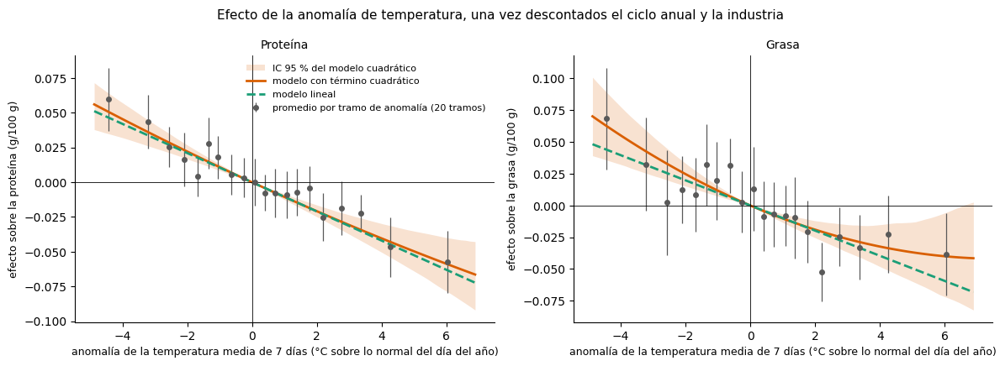

In [97]:
# Gráfico: efecto de la anomalía de temperatura sobre la composición (lo que queda después de sacar ciclo e industria)
m_ci = RL.construir(CICLO + [("industria",)]).fit(D, Y)
res_ci = Y - m_ci.predict(D)
an = D[f"an{NSTAR}"].to_numpy()
cortes = pd.qcut(an, 20, duplicates="drop")
grid = np.linspace(np.quantile(an, 0.01), np.quantile(an, 0.99), 80)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
for j, v in enumerate(OBJ):
    s = RL.se_por_bin(res_ci[:, j], cortes, D["bloque"].to_numpy())
    xm = pd.Series(an).groupby(cortes, observed=True).mean().to_numpy()
    a = ax[j]
    a.errorbar(xm, s["media"], yerr=1.96 * s["se"], fmt="o", color="0.35", ms=4, lw=0.9, label="promedio por tramo de anomalía (20 tramos)", zorder=2)
    cen, lo_, hi_ = RL.efecto_anomalia(aj28, n_lin, n_cuad, v, grid)
    a.fill_between(grid, lo_, hi_, color="#d95f02", alpha=0.18, lw=0, label="IC 95 % del modelo cuadrático")
    a.plot(grid, cen, color="#d95f02", lw=2, label="modelo con término cuadrático")
    cl, ll, hl = RL.efecto_anomalia(aj_lin28, n_lin, None, v, grid)
    a.plot(grid, cl, color="#1b9e77", lw=2, ls="--", label="modelo lineal")
    a.axhline(0, color="k", lw=0.6); a.axvline(0, color="k", lw=0.6)
    a.set_xlabel(f"anomalía de la temperatura media de {NSTAR} días (°C sobre lo normal del día del año)")
    a.set_ylabel("efecto sobre " + ("la proteína" if v == "proteina" else "la grasa") + " (g/100 g)")
    a.set_title("Proteína" if v == "proteina" else "Grasa")
    if j == 0: a.legend(loc="upper right")
fig.suptitle("Efecto de la anomalía de temperatura, una vez descontados el ciclo anual y la industria", fontsize=11)
fig.tight_layout(); fig.savefig(SALIDA / "fig4_efecto_anomalia.png", dpi=DPI); plt.show()

**En simple:** cada punto agrupa los días en que hizo más o menos calor del normal para la época (a la derecha, más caluroso que lo habitual; a la izquierda, más frío) y muestra cuánto
quedó la composición por encima o por debajo de lo que explican la estación y la industria. Si los puntos bajan hacia la derecha, los períodos más cálidos que lo normal vienen con
menos proteína y grasa que lo esperable para esa época. La línea verde es el efecto «por grado» (recta) y la naranja deja que se curve; la banda es la incertidumbre.
Es una asociación: no prueba que el calor sea la causa.

### 12 · Conclusiones

In [98]:
def g(n, etapa, v, m):
    return tm[(tm["modelo"] == n) & (tm["etapa"] == etapa) & (tm["objetivo"] == v)][m].iloc[0]
ap = RL.amplitud_pico(aj28, D).set_index("objetivo")
print(f"Datos: {miles(len(D))} muestras de {D['cliente'].nunique()} industrias, {D['fecha'].min().date()} a {D['fecha'].max().date()}.")
print(f"Ciclo elegido por validación: {ciclo_nombre} ({n_par[ciclo_nombre]} parámetros). Modelo elegido con temperatura: {elegido_nombre}. Ventana de temperatura: {NSTAR} días.\n")
for v in OBJ:
    et = "prueba 2024-26"
    print(f"== {v} ==")
    print(f"  Ciclo: amplitud de punta a punta {ap.loc[v, 'amplitud pico a pico (g/100 g)']:.3f} g/100 g (IC {ap.loc[v, 'ic95 inf']:.3f}-{ap.loc[v, 'ic95 sup']:.3f}), "
          f"{ap.loc[v, '% del promedio']:.1f} % del promedio; pico el {ap.loc[v, 'pico']} (IC {ap.loc[v, 'pico ic95']}); mínimo el {ap.loc[v, 'mínimo']}.")
    for n in ("media global", "ciclo", elegido_nombre):
        print(f"  prueba 2024-26 · {n:<45} MAE {g(n, et, v, 'mae'):.4f} · RMSE {g(n, et, v, 'rmse'):.4f} · R² {g(n, et, v, 'r2'):+.3f} · RMSE semanal {g(n, et, v, 'rmse_sem'):.4f}")
    rg, rc, rt = g("media global", et, v, "rmse"), g("ciclo", et, v, "rmse"), g(elegido_nombre, et, v, "rmse")
    sg, sc, st = g("media global", et, v, "rmse_sem"), g("ciclo", et, v, "rmse_sem"), g(elegido_nombre, et, v, "rmse_sem")
    print(f"  El ciclo baja el RMSE de prueba {100 * (1 - rc / rg):.1f} % por muestra y {100 * (1 - sc / sg):.1f} % por promedio semanal respecto de la media global; "
          f"la temperatura (modelo elegido) lo baja otro {100 * (1 - rt / rc):.1f} % por muestra y {100 * (1 - st / sc):.1f} % por promedio semanal.")
    e, lo_, hi_ = RL.coef(aj_lin28, n_lin, v)
    print(f"  Efecto de +1 °C de anomalía ({NSTAR} d): {e:+.4f} g/100 g (IC 95 % {lo_:+.4f} a {hi_:+.4f}).")
print()
for esq, gg in lo.groupby("esquema", sort=False):
    for v in OBJ:
        t = gg[gg["objetivo"] == v].pivot_table(index="industria", columns="modelo", values="rmse_sem")
        print(f"Industria afuera {esq}, {v}: el ciclo mejora el RMSE semanal en {int((t['ciclo'] < t['media global']).sum())} de {len(t)} industrias.")

Datos: 477.512 muestras de 9 industrias, 2019-09-05 a 2026-09-04.
Ciclo elegido por validación: Fourier k=2 (4 parámetros). Modelo elegido con temperatura: ciclo + anomalía 7 d. Ventana de temperatura: 7 días.

== proteina ==
  Ciclo: amplitud de punta a punta 0.206 g/100 g (IC 0.179-0.237), 6.2 % del promedio; pico el 25 may (IC 14 may a 9 jun); mínimo el 30 dic.
  prueba 2024-26 · media global                                  MAE 0.1485 · RMSE 0.1898 · R² -0.073 · RMSE semanal 0.1222
  prueba 2024-26 · ciclo                                         MAE 0.1322 · RMSE 0.1710 · R² +0.129 · RMSE semanal 0.0879
  prueba 2024-26 · ciclo + anomalía 7 d                          MAE 0.1294 · RMSE 0.1677 · R² +0.163 · RMSE semanal 0.0811
  El ciclo baja el RMSE de prueba 9.9 % por muestra y 28.1 % por promedio semanal respecto de la media global; la temperatura (modelo elegido) lo baja otro 1.9 % por muestra y 7.6 % por promedio semanal.
  Efecto de +1 °C de anomalía (7 d): -0.0105 g/100 g (IC 

**Qué se puede decir y qué no**

* **Hay un ciclo anual real, estable en la forma, chico frente al ruido.** Proteína y grasa son más altas hacia mayo y más bajas hacia fines de diciembre; el pico cae en mayo en todas las industrias que se estimaron por separado
  (tablas de la sección 11) y entre principios de mayo y mediados de junio según el año. La fase no es idéntica año a año con estos datos (rango de 43 días en la proteína y 29 en la grasa, con un solo año por ajuste). El ciclo
  sirve para predecir el **promedio semanal de una industria** (baja el error de prueba más de un cuarto respecto de la media global), pero predice poco una **muestra individual**: el R² por muestra es bajo
  y casi toda la variabilidad es entre tambos dentro del mismo día. El error de prueba es mayor que el de validación porque 2024–2026 tuvo un nivel más alto (ver residuos), y eso también le pasa a la media global.
* **La forma del ciclo importa menos que tener una.** Los polinomios de grado 3 a 6 y Fourier con 2 armónicos dan errores muy parecidos; el de Fourier tiene la ventaja de cerrar entre diciembre y enero (el polinomio no: saltos de hasta
  0,05 g/100 g en proteína en la tabla de la sección 3). Con 1 armónico el pico queda forzado a caer medio año después del mínimo y se corre unas tres semanas. Con muchos datos más grado no sobreajusta; con pocas muestras sí (figura 2, abajo).
* **La temperatura agrega poco sobre la estación.** La anomalía de 7 días mejora el error semanal de la proteína de forma apreciable y casi nada el de la grasa, y poco el error por muestra en los dos (cifras en la sección 7). Su efecto por grado es chico
  (sección 11) pero distinguible de cero con el intervalo por bloques, y no cambia al agregar tendencia ni al usar solo las fechas escritas en el informe. El término cuadrático no mejora la predicción y su coeficiente no se distingue de cero (sección 11): no hay evidencia de un estrés por calor que se acelere.
* **Estación y temperatura no se separan del todo.** La estación explica la mayor parte de la varianza de la temperatura (sección 4). En la proteína la pendiente de la temperatura sola y la de la anomalía casi no difieren; en la grasa la pendiente de la temperatura sola es bastante mayor que la de la anomalía, o sea que parte de lo que parecía efecto de la temperatura era estación.
* **No se puede concluir causalidad.** Estación, temperatura, alimentación (pasto, silo), parición y genética se mueven juntas. La anomalía separa la estación de la temperatura, no la temperatura de todo lo demás que cambia con el clima (la humedad, el pasto). Que un período haya sido más cálido y la leche tenga menos proteína no dice que el calor lo haya causado.
* **El ciclo se generaliza entre industrias.** Dejando una industria afuera, el ciclo mejora el error semanal en casi todas (el conteo exacto está en la sección 10), también cuando además se predice el futuro (2024–2026); las excepciones son industrias con pocas muestras.
* **Hay un movimiento común de nivel que no se explica.** El corrimiento del residuo es común a las industrias (sección 2) y puede ser real o de calibración; no se distinguen con estos datos. Por eso predecir un año de nivel distinto, y extrapolar una tendencia lineal (sección 8), es poco fiable.
* **Límites de los datos.** Un tercio de las fechas es la de creación del archivo (±3 días en el 89 % de los casos): la escala útil es semanal, no diaria. La temperatura es de una sola localidad (Rafaela) y puede no representar a todos los tambos. Una industria (la sacada por tener muy pocas muestras) y
  los años anteriores a 2019 no entran. Los intervalos por bloques tienen en cuenta que las muestras de una misma semana se parecen, pero no que lo hagan los años entre sí: con 7 años de datos, la incertidumbre del ciclo es probablemente algo mayor que la informada.

### 13 · ¿Por qué regresión lineal / polinómica / Fourier y no otro algoritmo?
Hasta acá se comparó **dentro** de la familia lineal (mes, polinomios de grado 1 a 6, Fourier de 1 a 3 armónicos). Falta ponerla frente a los otros algoritmos de la cátedra, **sobre el mismo problema**: predecir proteína y grasa
**a partir del día del año** (el modelo «ciclo» de la sección 6, sin industria ni temperatura), con la **misma partición temporal** (ajustar hasta 2023, probar 2024-2026) y la **misma métrica** (RMSE por muestra y RMSE del promedio semanal de cada industria, `RL.metricas`).

Lo que ya está calculado **no se repite**: la media global, la regresión lineal (polinomio de grado 1), el polinomio de grado elegido y Fourier con k = 2 se leen de la tabla de métricas de la sección 5 (`metricas_ciclo.csv`; fig. 2 muestra su curva de error contra la complejidad). Se agregan:

| Algoritmo | Cómo entra acá |
|---|---|
| Regresión lineal | polinomio de grado 1 del día del año (de la tabla de la sección 5) |
| Regresión polinómica | el grado elegido por la misma regla de la sección 6, pero **entre los polinomios** (de la tabla de la sección 5) |
| Fourier k = 2 | el ciclo elegido (de la tabla de la sección 5) |
| k-NN regresor | `KNeighborsRegressor` sobre el día del año **codificado circular** (sen y cos, para que el 31-dic quede al lado del 1-ene); `k` elegido por validación entre 4 000 y 40 000 vecinos (tope: el entrenamiento de la validación de 2021 tiene 87 000 filas) (hay unas 800 muestras de entrenamiento por día del año, así que `k` chico solo promedia un día) |
| Árbol de regresión | **solo como referencia** (el árbol lo trabaja otro integrante del grupo): `DecisionTreeRegressor` sobre el día del año, profundidad elegida por validación, hojas de al menos 500 filas |
| SVR | `SVR` con núcleo RBF y `LinearSVR`, sobre sen y cos, con las salidas estandarizadas; ajustados con **10 000 muestras al azar del entrenamiento** (el SVR con núcleo es cuadrático o peor en la cantidad de filas) y `C` elegido por validación |

Los hiperparámetros se eligen con la **validación de la sección 5** (ventana que crece por año, 2021-2023; puntaje = RMSE semanal relativo a la media global, promediado entre proteína y grasa), nunca con la prueba. Como el único predictor es el día del año, k-NN y los demás se evalúan
sobre los días distintos y se reparten a las filas (resultado idéntico, mucho más rápido).

In [99]:
import time
from IPython.display import Markdown, display
from sklearn.compose import TransformedTargetRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR, LinearSVR
from sklearn.tree import DecisionTreeRegressor

D["sen1"] = np.sin(2 * np.pi * D["doy"] / RL.PERIODO); D["cos1"] = np.cos(2 * np.pi * D["doy"] / RL.PERIODO)
N_SVR = 10_000
GRID_R = {"knn": [4000, 10000, 20000, 40000], "arbol": [2, 3, 4, 6, 8], "svr_rbf": [0.1, 1, 10], "svr_lin": [0.1, 1]}
NOM = {"media": "Media global (referencia)", "lin": "Regresión lineal (grado 1)", "poly": "Regresión polinómica", "four": "Fourier k = 2 (elegido)", "knn": "k-NN regresor",
       "arbol": "Árbol de regresión (referencia)", "svr_rbf": "SVR núcleo RBF", "svr_lin": "SVR lineal"}
INTERP = {"media": "no aplica", "lin": "sí: coeficientes (pendiente)", "poly": "sí: coeficientes (curva)", "four": "sí: amplitud y día del pico con IC", "knn": "no", "arbol": "parcial: cortes por fecha, sin amplitud ni pico",
          "svr_rbf": "no", "svr_lin": "sí: coeficientes, sin IC"}
pru_m = (D["fecha"] > RL.FIN_ENTRENAMIENTO).to_numpy(); ent_m = ~pru_m
val_m = D["anio"].isin((2021, 2022, 2023)).to_numpy()
celda_val, celda_pru = D.loc[val_m, "celda"].to_numpy(), D.loc[pru_m, "celda"].to_numpy()


def fabrica(clave, hp):
    if clave == "knn":
        return KNeighborsRegressor(n_neighbors=hp, n_jobs=-1)
    if clave == "arbol":
        return DecisionTreeRegressor(max_depth=hp, min_samples_leaf=500, random_state=RL.SEMILLA)
    base = SVR(C=hp, kernel="rbf", epsilon=0.1) if clave == "svr_rbf" else LinearSVR(C=hp, epsilon=0.1, max_iter=5000, random_state=RL.SEMILLA)
    return TransformedTargetRegressor(MultiOutputRegressor(base), transformer=StandardScaler())


feats = lambda clave: ["doy"] if clave == "arbol" else ["sen1", "cos1"]


def ajustar_nuevo(clave, hp, mascara):
    e = D[mascara]
    if clave.startswith("svr") and len(e) > N_SVR:
        e = e.sample(N_SVR, random_state=RL.SEMILLA)
    m = fabrica(clave, hp)
    t0 = time.time()
    m.fit(e[feats(clave)].to_numpy(), e[OBJ].to_numpy())
    return m, time.time() - t0


def predecir_doy(m, clave, dd):
    # el único predictor es el día del año: se predice una vez por día distinto y se reparte a las filas
    u = dd.drop_duplicates("doy")
    pu = m.predict(u[feats(clave)].to_numpy())
    pos = pd.Series(np.arange(len(u)), index=u["doy"].to_numpy())
    return pu[pos.loc[dd["doy"].to_numpy()].to_numpy()]


mg_val = RL.metricas(Y[val_m], rod["media global"][val_m], celda_val)


def puntaje(clave, hp):
    pred = np.full((len(D), 2), np.nan)
    for a in (2021, 2022, 2023):
        e, p = (D["anio"] < a).to_numpy(), (D["anio"] == a).to_numpy()
        m, _ = ajustar_nuevo(clave, hp, e)
        pred[p] = predecir_doy(m, clave, D[p])
    mt = RL.metricas(Y[val_m], pred[val_m], celda_val)
    return float(np.mean([mt[v]["rmse_sem"] / mg_val[v]["rmse_sem"] for v in OBJ]))


T_CMP = time.time()
filas, VALID_HP, PRED_CMP = [], {}, {}
# 1) los que ya están calculados en la tabla de la sección 5 (se leen) y su tiempo de ajuste (se mide de nuevo)
polys = [f"polinomio grado {g}" for g in range(1, 7)]
poly_nombre, _ = RL.elegir(tm, polys, {n: n_par[n] for n in polys})
LEIDOS = {"media": "media global", "lin": "polinomio grado 1", "poly": poly_nombre, "four": ciclo_nombre}
assert ciclo_nombre == "Fourier k=2", ciclo_nombre
for clave, nombre in LEIDOS.items():
    comps = MA[nombre]
    t0 = time.time(); RL.ajustar_predecir(comps, D, ent_m, pru_m); t_aj = time.time() - t0
    for v in OBJ:
        r = tm[(tm["modelo"] == nombre) & (tm["etapa"] == "prueba 2024-26") & (tm["objetivo"] == v)].iloc[0]
        filas.append({"algoritmo": NOM[clave], "clave": clave, "modelo en la tabla de la sección 5": nombre, "hiperparámetro": "-", "objetivo": v, "rmse": r["rmse"], "rmse_sem": r["rmse_sem"], "mae": r["mae"], "r2": r["r2"],
                      "tiempo de ajuste (s)": t_aj, "interpretable": INTERP[clave], "filas de entrenamiento": int(ent_m.sum())})
# 2) los nuevos
for clave, hps in GRID_R.items():
    sc = [(hp, puntaje(clave, hp)) for hp in hps]
    hp = min(sc, key=lambda r: r[1])[0]
    VALID_HP[clave] = sc
    m, t_aj = ajustar_nuevo(clave, hp, ent_m)
    p = predecir_doy(m, clave, D[pru_m])
    PRED_CMP[clave] = p
    mt = RL.metricas(Y[pru_m], p, celda_pru)
    hp_txt = {"knn": f"k = {hp}", "arbol": f"profundidad {hp}", "svr_rbf": f"C = {hp:g} ({N_SVR:,} muestras)".replace(",", "."), "svr_lin": f"C = {hp:g} ({N_SVR:,} muestras)".replace(",", ".")}[clave]
    for v in OBJ:
        filas.append({"algoritmo": NOM[clave], "clave": clave, "modelo en la tabla de la sección 5": "(nuevo)", "hiperparámetro": hp_txt, "objetivo": v, "rmse": mt[v]["rmse"], "rmse_sem": mt[v]["rmse_sem"], "mae": mt[v]["mae"],
                      "r2": mt[v]["r2"], "tiempo de ajuste (s)": t_aj, "interpretable": INTERP[clave], "filas de entrenamiento": min(N_SVR, int(ent_m.sum())) if clave.startswith("svr") else int(ent_m.sum())})
    print(f"{NOM[clave]:<32} {hp_txt:<28} puntaje de validación por hiperparámetro: " + ", ".join(f"{a}: {b:.4f}" for a, b in sc) + f" · ajuste {t_aj:.2f} s", flush=True)
cmpr = pd.DataFrame(filas)
ref = cmpr[cmpr["clave"] == "media"].set_index("objetivo")
cmpr["mejora RMSE vs media global (%)"] = [100 * (1 - r["rmse"] / ref.loc[r["objetivo"], "rmse"]) for _, r in cmpr.iterrows()]
cmpr["mejora RMSE semanal vs media global (%)"] = [100 * (1 - r["rmse_sem"] / ref.loc[r["objetivo"], "rmse_sem"]) for _, r in cmpr.iterrows()]
orden_r = list(NOM)
cmpr["_o"] = cmpr["clave"].map({k: i for i, k in enumerate(orden_r)})
cmpr["_ob"] = cmpr["objetivo"].map({"proteina": 0, "grasa": 1})
cmpr = cmpr.sort_values(["_ob", "_o"]).drop(columns=["_o", "_ob"]).reset_index(drop=True)
cmpr.drop(columns="clave").to_csv(SALIDA / "comparacion_algoritmos.csv", index=False, encoding="utf-8-sig")
print(f"\nPolinomio elegido (regla de la sección 6, solo entre polinomios): {poly_nombre}")
print("Prueba 2024-26 (g/100 g):")
print(cmpr[["objetivo", "algoritmo", "hiperparámetro", "rmse", "rmse_sem", "mejora RMSE vs media global (%)", "mejora RMSE semanal vs media global (%)", "tiempo de ajuste (s)", "interpretable"]].round(4).to_string(index=False))
print(f"\nComparación de algoritmos: {time.time() - T_CMP:.0f} s")

k-NN regresor                    k = 20000                    puntaje de validación por hiperparámetro: 4000: 0.7069, 10000: 0.6824, 20000: 0.6733, 40000: 0.6998 · ajuste 0.07 s


Árbol de regresión (referencia)  profundidad 4                puntaje de validación por hiperparámetro: 2: 0.7514, 3: 0.7072, 4: 0.7053, 6: 0.7251, 8: 0.7314 · ajuste 0.07 s


SVR núcleo RBF                   C = 0.1 (10.000 muestras)    puntaje de validación por hiperparámetro: 0.1: 0.6902, 1: 0.6991, 10: 0.7062 · ajuste 3.38 s


SVR lineal                       C = 1 (10.000 muestras)      puntaje de validación por hiperparámetro: 0.1: 0.6709, 1: 0.6706 · ajuste 0.01 s



Polinomio elegido (regla de la sección 6, solo entre polinomios): polinomio grado 3
Prueba 2024-26 (g/100 g):
objetivo                       algoritmo            hiperparámetro   rmse  rmse_sem  mejora RMSE vs media global (%)  mejora RMSE semanal vs media global (%)  tiempo de ajuste (s)                                   interpretable
proteina       Media global (referencia)                         - 0.1898    0.1222                           0.0000                                   0.0000                0.0821                                       no aplica
proteina      Regresión lineal (grado 1)                         - 0.1896    0.1214                           0.1219                                   0.6631                0.1057                    sí: coeficientes (pendiente)
proteina            Regresión polinómica                         - 0.1722    0.0903                           9.2591                                  26.0624                0.1197                        sí

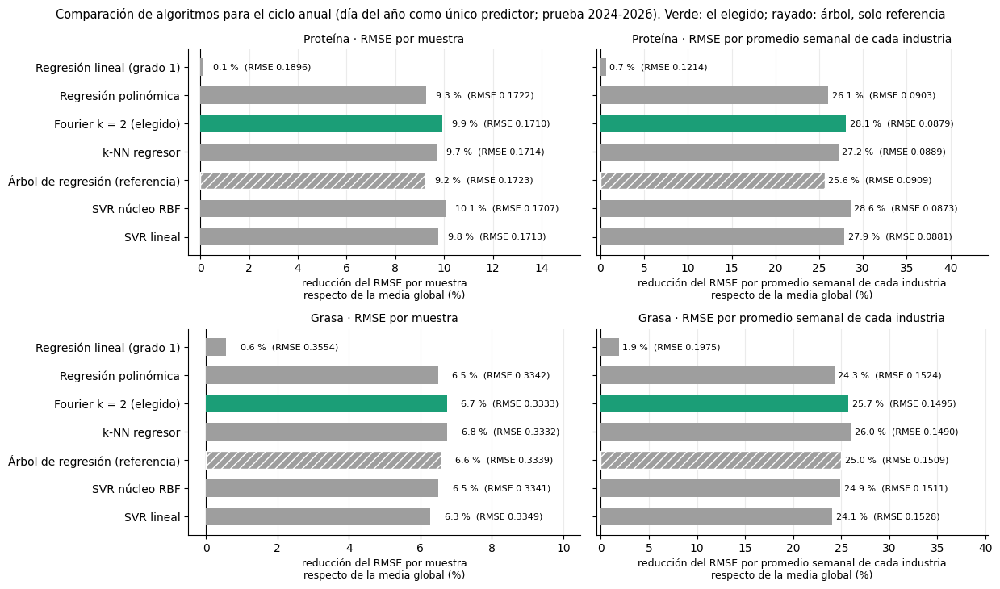

In [100]:
fig, ax = plt.subplots(2, 2, figsize=(12.5, 7.4))
claves = [k for k in NOM if k != "media"]
for i, v in enumerate(OBJ):
    s = cmpr[cmpr["objetivo"] == v].set_index("clave")
    for j, (col, tit, ref_col) in enumerate([("mejora RMSE vs media global (%)", "por muestra", "rmse"), ("mejora RMSE semanal vs media global (%)", "por promedio semanal de cada industria", "rmse_sem")]):
        a = ax[i, j]
        val = s.loc[claves, col].to_numpy()
        ypos = np.arange(len(claves))
        colores = ["#1b9e77" if k == "four" else "0.62" for k in claves]
        barras = a.barh(ypos, val, color=colores, height=0.62, zorder=3)
        for b_, k in zip(barras, claves):
            if k == "arbol":
                b_.set_hatch("///"); b_.set_edgecolor("white")
        for yy, vv, k in zip(ypos, val, claves):
            a.text(vv + 0.4, yy, f"{vv:.1f} %  (RMSE {s.loc[k, ref_col]:.4f})", va="center", fontsize=8)
        a.axvline(0, color="k", lw=0.8)
        a.set_xlim(min(0, val.min()) - 0.5, val.max() * 1.55)
        a.set_yticks(ypos); a.set_yticklabels([NOM[k] for k in claves] if j == 0 else [""] * len(ypos)); a.invert_yaxis()
        a.set_xlabel(f"reducción del RMSE {tit}\nrespecto de la media global (%)"); a.set_title(("Proteína" if v == "proteina" else "Grasa") + f" · RMSE {tit}")
        a.grid(axis="x", alpha=0.25); a.set_axisbelow(True)
fig.suptitle("Comparación de algoritmos para el ciclo anual (día del año como único predictor; prueba 2024-2026). Verde: el elegido; rayado: árbol, solo referencia", fontsize=10.5)
fig.tight_layout(); fig.savefig(SALIDA / "fig5_comparacion_algoritmos.png", dpi=DPI, bbox_inches="tight"); plt.show()

In [101]:
def f3(x, n=4):
    return f"{x:.{n}f}".replace(".", ",")

lineas = ["**Veredicto de la comparación (prueba 2024-2026, g/100 g).**", ""]
for v in OBJ:
    s = cmpr[cmpr["objetivo"] == v].set_index("clave").drop(index="media")
    mejor_m, mejor_s = s["rmse"].idxmin(), s["rmse_sem"].idxmin()
    fo = s.loc["four"]
    emp = [NOM[k] for k in s.index if k != "four" and abs(s.loc[k, "rmse_sem"] / fo["rmse_sem"] - 1) < 0.01]
    lineas.append(f"**{'Proteína' if v == 'proteina' else 'Grasa'}.** Menor RMSE por muestra: **{NOM[mejor_m]}** ({f3(s.loc[mejor_m, 'rmse'])}; Fourier k = 2: {f3(fo['rmse'])}). Menor RMSE semanal: **{NOM[mejor_s]}** ({f3(s.loc[mejor_s, 'rmse_sem'])}; Fourier k = 2: {f3(fo['rmse_sem'])}). "
                  f"A menos de 1 % del RMSE semanal de Fourier k = 2: {', '.join(emp) if emp else 'ninguno'}. La regresión lineal (grado 1) queda en {f3(s.loc['lin', 'rmse_sem'])} de RMSE semanal "
                  f"({f3(s.loc['lin', 'mejora RMSE semanal vs media global (%)'], 1)} % de mejora contra {f3(fo['mejora RMSE semanal vs media global (%)'], 1)} % de Fourier). Árbol (referencia): {f3(s.loc['arbol', 'rmse_sem'])}.")
lineas.append("")
display(Markdown("\n".join(lineas)))

**Veredicto de la comparación (prueba 2024-2026, g/100 g).**

**Proteína.** Menor RMSE por muestra: **SVR núcleo RBF** (0,1707; Fourier k = 2: 0,1710). Menor RMSE semanal: **SVR núcleo RBF** (0,0873; Fourier k = 2: 0,0879). A menos de 1 % del RMSE semanal de Fourier k = 2: SVR núcleo RBF, SVR lineal. La regresión lineal (grado 1) queda en 0,1214 de RMSE semanal (0,7 % de mejora contra 28,1 % de Fourier). Árbol (referencia): 0,0909.
**Grasa.** Menor RMSE por muestra: **k-NN regresor** (0,3332; Fourier k = 2: 0,3333). Menor RMSE semanal: **k-NN regresor** (0,1490; Fourier k = 2: 0,1495). A menos de 1 % del RMSE semanal de Fourier k = 2: k-NN regresor, Árbol de regresión (referencia). La regresión lineal (grado 1) queda en 0,1975 de RMSE semanal (1,9 % de mejora contra 25,7 % de Fourier). Árbol (referencia): 0,1509.


**Por qué esta familia, a la vista de los números de arriba.**
* **Hay un ciclo, y eso es lo que importa.** El salto grande es de la media global y la recta del tiempo (grado 1: 0,7 % de mejora del RMSE semanal en proteína y 1,9 % en grasa) a cualquier algoritmo que pueda curvarse: polinomio de grado 3, Fourier, k-NN, árbol y SVR mejoran el RMSE semanal entre 24 % y 29 %.
  La recta no sirve porque el ciclo anual sube y baja (el promedio de una recta a lo largo del año es casi la media global).
* **Entre los que aprendieron el ciclo las diferencias son chicas, y ninguno gana en todo.** En proteína el SVR con núcleo RBF tiene apenas menos error que Fourier k = 2 (RMSE semanal 0,0873 contra 0,0879, 0,7 % menos; por muestra 0,1707 contra 0,1710), y el SVR lineal y Fourier casi se igualan (0,0881);
  en grasa el k-NN lo supera por 0,3 % en el RMSE semanal (0,1490 contra 0,1495). Son diferencias de menos del 1 %, y entre todos esos algoritmos el orden cambia de un objetivo a otro: es un empate técnico, no una ventaja que justifique un modelo sin intervalos.
  El SVR, además, se ajusta con 10 000 filas al azar del entrenamiento y su error cambia con el sorteo (con otra semilla del sorteo quedaba peor que Fourier en grasa), así que no se lo toma como una ventaja estable.
  El error que queda es la variación entre tambos y un corrimiento de nivel común que ninguno predice con solo el día del año: con un único predictor y unas 800 muestras por día, un algoritmo más flexible no tiene estructura nueva que encontrar.
  (El `k` elegido del k-NN, 20 000, equivale a promediar una ventana de unos 25 días (±12) alrededor de la fecha: es un suavizador, no un modelo «local».)
* **Interpretabilidad.** La pregunta del trabajo (amplitud del ciclo, día del pico, cuánto vale 1 °C de anomalía) se responde con **coeficientes y sus intervalos por bootstrap de bloques** (sección 11); en Fourier, la amplitud y el día del pico salen de los coeficientes de seno y coseno.
  Con k-NN o con el SVR con núcleo habría que leer la curva predicha y no habría intervalos; el árbol da una curva en escalones (cortes por fecha) que no cierra suavemente entre diciembre y enero.
* **Cíclico por construcción.** Fourier cierra entre el 31-dic y el 1-ene; el polinomio no (sección 3). El k-NN lo logra porque se le dio el día codificado en círculo; el árbol, con el día crudo, trata el 1-ene y el 31-dic como extremos.
* **Costo.** Todos ajustan en una fracción de segundo salvo el SVR con núcleo, que se ajusta con 10 000 muestras porque su costo crece más que linealmente con las filas.
* **Lo que no cubre esta comparación.** Solo el ciclo (día del año); no se probó k-NN, árbol ni SVR con anomalía de temperatura e industria. Con ese predictor adicional, la regresión lineal permite además **separar** la estación de la temperatura y estimar un efecto por °C con intervalo (sección 11), cosa que los otros algoritmos no dan de forma directa.

### 14 · Datos usados en cada entrenamiento
Cuántas filas de la leche cruda entran en cada modelo de este cuaderno, cuáles se sacan y por qué, y cómo se reparten entre entrenamiento, validación y prueba. Proteína y grasa se ajustan **juntas** con las mismas filas
(una fila por objetivo, con los mismos números). La validación sale del propio pasado: cada año de 2021-2023 se valida con un modelo ajustado con los años anteriores (ventana que crece), y el modelo final se reajusta con todo hasta 2023;
por eso «entrenamiento» cuenta las filas anteriores a 2021 y «validación» las de 2021-2023 (las dos juntas son las que ajustan el modelo final). La prueba es 2024-2026 y no decide nada. Las submuestras de los algoritmos de la sección 13 figuran en la nota.

In [102]:
import datos_entrenamiento as DE
from IPython.display import display

N_ARCHIVO = int(tabla_limpieza["quedan"].iloc[0])
excl = [f"{r['paso']}: {miles(r['saca'])}" for _, r in tabla_limpieza.iloc[1:].iterrows() if r["saca"] > 0]
if len(D0) - len(D):
    excl.append(f"industria con menos de {RL.MIN_MUESTRAS_INDUSTRIA} muestras ({', '.join(chicas)}, se saca de todos los modelos): {miles(len(D0) - len(D))}")
MOTIVO = "; ".join(excl)
n_pre = int((D["fecha"] < "2021-01-01").sum()); n_val = int(val_m.sum()); n_pru = int(pru_m.sum()); n_h23 = int(ent_m.sum())
assert n_pre + n_val + n_pru == len(D)
PART = "temporal: hasta 2023 / prueba 2024-26; validación móvil 2021-23 (ventana que crece por año)"
NOTA_FINAL = f"el modelo final se reajusta con todo hasta 2023 ({miles(n_h23)} filas); proteína y grasa se ajustan juntas con las mismas filas"
ROT = {"proteina": "proteína", "grasa": "grasa"}
filas = []
DAT = "muestras de leche cruda con fecha, grasa, proteína y temperatura"

def reg(v, modelo, nota="", **kw):
    filas.append(DE.fila("III", f"{modelo}, {ROT[v]}", DAT, N_ARCHIVO, len(D), MOTIVO, entrenamiento=n_pre, validacion=n_val, prueba=n_pru, particion=PART, nota=nota or NOTA_FINAL, **kw))

for v in OBJ:
    reg(v, f"ciclo elegido ({ciclo_nombre})")
for v in OBJ:
    reg(v, f"ciclo + temperatura, modelo elegido ({elegido_nombre})")
for v in OBJ:
    filas.append(DE.fila("III", f"interpretación ({ciclo_nombre} + industria + anomalía de {NSTAR} d, grado 2), {ROT[v]}", DAT, N_ARCHIVO, len(D), MOTIVO, particion="sin partición: todos los datos 2019-2026, intervalos por bootstrap de bloques de 28 días",
                         nota=f"ciclo + industria + anomalía de {NSTAR} días con término cuadrático; {B} remuestreos; proteína y grasa con las mismas filas"))
for v in OBJ:
    filas.append(DE.fila("III", f"polinomio de grado 1 a 10 con pocas muestras, {ROT[v]}", DAT, N_ARCHIVO, N_POCAS + n_pru,
                         MOTIVO + f"; de las {miles(n_h23)} filas hasta 2023 solo entran {N_POCAS} al azar por sorteo", entrenamiento=N_POCAS, prueba=n_pru,
                         particion="temporal: {0} muestras al azar hasta 2023 / prueba 2024-26".format(N_POCAS), nota=f"{SORTEOS} sorteos; se promedia el error de prueba (figura 2, abajo)"))
for esq, g_, pasado in (("(a) todos los años", lo_a, False), ("(b) hasta 2023 → 2024-26", lo_b, True)):
    for v in OBJ:
        gg = g_[(g_["modelo"] == "ciclo") & (g_["objetivo"] == v)]
        inds = list(gg["industria"])
        n_te = int(round(gg["n"].mean()))
        if pasado:
            n_tr = int(round((ent_m.sum() - D[ent_m & D["cliente"].isin(inds).to_numpy()].groupby("cliente").size().reindex(inds).mean())))
        else:
            n_tr = int(round(len(D) - gg["n"].mean()))
        filas.append(DE.fila("III", f"industria afuera {esq}: ciclo, {ROT[v]}", DAT, N_ARCHIVO, len(D), MOTIVO, entrenamiento=n_tr, prueba=n_te,
                             particion=f"una industria afuera por vez ({len(inds)} industrias evaluadas)" + (", ajuste hasta 2023 y prueba 2024-26" if pasado else ""),
                             nota="entrenamiento y prueba son el promedio por industria dejada afuera; sin término de industria; proteína y grasa con las mismas filas"))
NOTA_ALG = {
    "lin": "polinomio de grado 1; sin submuestra", "poly": f"{poly_nombre}; sin submuestra",
    "knn": f"sin submuestra; k = {min(VALID_HP['knn'], key=lambda r: r[1])[0]} elegido por validación; se evalúa por día del año distinto",
    "arbol": f"sin submuestra; hojas de al menos 500 filas; profundidad {min(VALID_HP['arbol'], key=lambda r: r[1])[0]} elegida por validación",
    "svr_rbf": f"SUBMUESTRA: {miles(N_SVR)} filas al azar de las {miles(n_h23)} hasta 2023 (también en cada año de la validación); C = {min(VALID_HP['svr_rbf'], key=lambda r: r[1])[0]:g}",
    "svr_lin": f"SUBMUESTRA: {miles(N_SVR)} filas al azar de las {miles(n_h23)} hasta 2023 (también en cada año de la validación); C = {min(VALID_HP['svr_lin'], key=lambda r: r[1])[0]:g}",
}
for clave in ("lin", "poly", "knn", "arbol", "svr_rbf", "svr_lin"):
    filas.append(DE.fila("III", f"sección 13: {NOM[clave]}, proteína y grasa", "muestras de leche cruda (solo el día del año como predictor)", N_ARCHIVO, len(D), MOTIVO,
                         entrenamiento=n_pre, validacion=n_val, prueba=n_pru, particion=PART, nota=NOTA_ALG[clave] + "; el modelo final se reajusta con todo hasta 2023"))
display(DE.guardar(filas, "regresion_ciclo_leche_cruda"))

,parte,modelo,datos,disponibles,excluidas,motivo de exclusión,usadas,entrenamiento,validación,prueba,partición,nota
0,III,"ciclo elegido (Fourier k=2), proteína","muestras de leche cruda con fecha, grasa, proteína y temperatura",628035,150523,"sin fecha, sin grasa o sin proteína: 143.868; fecha anterior a 2019 (sin cobertura): 32; grasa fuera de 2....",477512,87701,213021,176790,temporal: hasta 2023 / prueba 2024-26; validación móvil 2021-23 (ventana que crece por año),el modelo final se reajusta con todo hasta 2023 (300.722 filas); proteína y grasa se ajustan juntas con la...
1,III,"ciclo elegido (Fourier k=2), grasa","muestras de leche cruda con fecha, grasa, proteína y temperatura",628035,150523,"sin fecha, sin grasa o sin proteína: 143.868; fecha anterior a 2019 (sin cobertura): 32; grasa fuera de 2....",477512,87701,213021,176790,temporal: hasta 2023 / prueba 2024-26; validación móvil 2021-23 (ventana que crece por año),el modelo final se reajusta con todo hasta 2023 (300.722 filas); proteína y grasa se ajustan juntas con la...
2,III,"ciclo + temperatura, modelo elegido (ciclo + anomalía 7 d), proteína","muestras de leche cruda con fecha, grasa, proteína y temperatura",628035,150523,"sin fecha, sin grasa o sin proteína: 143.868; fecha anterior a 2019 (sin cobertura): 32; grasa fuera de 2....",477512,87701,213021,176790,temporal: hasta 2023 / prueba 2024-26; validación móvil 2021-23 (ventana que crece por año),el modelo final se reajusta con todo hasta 2023 (300.722 filas); proteína y grasa se ajustan juntas con la...
3,III,"ciclo + temperatura, modelo elegido (ciclo + anomalía 7 d), grasa","muestras de leche cruda con fecha, grasa, proteína y temperatura",628035,150523,"sin fecha, sin grasa o sin proteína: 143.868; fecha anterior a 2019 (sin cobertura): 32; grasa fuera de 2....",477512,87701,213021,176790,temporal: hasta 2023 / prueba 2024-26; validación móvil 2021-23 (ventana que crece por año),el modelo final se reajusta con todo hasta 2023 (300.722 filas); proteína y grasa se ajustan juntas con la...
4,III,"interpretación (Fourier k=2 + industria + anomalía de 7 d, grado 2), proteína","muestras de leche cruda con fecha, grasa, proteína y temperatura",628035,150523,"sin fecha, sin grasa o sin proteína: 143.868; fecha anterior a 2019 (sin cobertura): 32; grasa fuera de 2....",477512,477512,<NA>,<NA>,"sin partición: todos los datos 2019-2026, intervalos por bootstrap de bloques de 28 días",ciclo + industria + anomalía de 7 días con término cuadrático; 1000 remuestreos; proteína y grasa con las ...
5,III,"interpretación (Fourier k=2 + industria + anomalía de 7 d, grado 2), grasa","muestras de leche cruda con fecha, grasa, proteína y temperatura",628035,150523,"sin fecha, sin grasa o sin proteína: 143.868; fecha anterior a 2019 (sin cobertura): 32; grasa fuera de 2....",477512,477512,<NA>,<NA>,"sin partición: todos los datos 2019-2026, intervalos por bootstrap de bloques de 28 días",ciclo + industria + anomalía de 7 días con término cuadrático; 1000 remuestreos; proteína y grasa con las ...
6,III,"polinomio de grado 1 a 10 con pocas muestras, proteína","muestras de leche cruda con fecha, grasa, proteína y temperatura",628035,451165,"sin fecha, sin grasa o sin proteína: 143.868; fecha anterior a 2019 (sin cobertura): 32; grasa fuera de 2....",176870,80,<NA>,176790,temporal: 80 muestras al azar hasta 2023 / prueba 2024-26,"60 sorteos; se promedia el error de prueba (figura 2, abajo)"
7,III,"polinomio de grado 1 a 10 con pocas muestras, grasa","muestras de leche cruda con fecha, grasa, proteína y temperatura",628035,451165,"sin fecha, sin grasa o sin proteína: 143.868; fecha anterior a 2019 (sin cobertura): 32; grasa fuera de 2....",176870,80,<NA>,176790,temporal: 80 muestras al azar hasta 2023 / prueba 2024-26,"60 sorteos; se promedia el error de prueba (figura 2, abajo)"
8,III,"industria afuera (a) todos los años: ciclo, proteína","muestras de leche cruda con fecha, grasa, proteína y temperatura",628035,150523,"sin fecha, si

<a id="parte-iv"></a>

# Parte IV · Regresión logística: calidad de la leche cruda

Probabilidad de que una muestra supere el umbral de células somáticas o de bacterias; curva ROC, calibración, matriz de confusión, lactosa y comparación con otros algoritmos.

*(Generada a partir de `logistica_calidad_leche_cruda.ipynb`.)*

## ¿Con qué probabilidad una muestra de leche cruda supera el umbral de células somáticas o de bacterias? Regresión logística
**Aprendizaje Automático y Grandes Datos · UNRaf · 2026**

Modelos del apartado de regresión logística (`LogisticRegression` de scikit-learn) sobre la **leche cruda** de 10 industrias
(`IND-nn`), 2019-2026. Para cada muestra de tambo se estima la **probabilidad** de que:

* **RCS**: el recuento de células somáticas supere **400 000 cél/mL** (indicador de mastitis);
* **RBT**: el recuento bacteriano total supere **100 000 UFC/mL** (leche de primera calidad: por debajo).

**Pregunta de fondo.** El calor, ¿sube el riesgo? Estación y temperatura están confundidas (el verano es caluroso *y* es
estación), así que no alcanza con la temperatura: se usa la **anomalía** (cuánto más caliente que lo habitual para esa época del
año) con la estación en el modelo. Una probabilidad bien **calibrada** es el entregable útil, por eso se mira la curva de
calibración además del AUC.

**Cuidados que ordenan el cuaderno.** (1) **Unidades**: se confirman antes de poner umbrales (y aparece un cambio de unidad
del RBT en una industria). (2) **Validación temporal**: se entrena hasta fin de 2023 y se prueba en 2024-2026; nunca un KFold
aleatorio (las muestras de un mismo día, tambo e informe se parecen). Además, **una industria afuera** (`GroupKFold` por cliente).
(3) **Intervalos con bootstrap por bloques de semanas**: las filas no son independientes. (4) Ningún predictor deriva del objetivo.

Semilla 42. Escribe solo en `resultados/logistica_calidad_leche/`.

### 0 · Rutas y parámetros

In [103]:
import sys
import time
import warnings
from pathlib import Path
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "rutas.py").exists()) / "src"
sys.path.insert(0, str(SRC))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
from IPython.display import Markdown, display
from sklearn.metrics import roc_curve
from sklearn.model_selection import GroupKFold
import rutas as R
import logistica_leche as L

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 120)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 10.5, "axes.labelsize": 9.5,
                     "legend.fontsize": 8.5, "axes.grid": True, "grid.alpha": 0.25})
SALIDA = R.RESULTADOS / "logistica_calidad_leche"; SALIDA.mkdir(parents=True, exist_ok=True)
DICCIONARIO = R.RAIZ.parent / "_archivo" / "datos" / "diccionario_leche_cruda.csv"
DPI = 150
AZUL, NARANJA, GRIS, OSCURO = "#2a6f97", "#d9822b", "#8a8f98", "#1d3557"
COLOR = {"RCS": AZUL, "RBT": NARANJA}
NOMBRE = {"RCS": "células somáticas > 400 000 cél/mL", "RBT": "recuento bacteriano > 100 000 UFC/mL"}
T0 = time.time()
RES = {}      # resultados que alimentan las conclusiones


def en_simple(txt):
    display(Markdown("**En simple:** " + txt))


def guardar(fig, nombre):
    fig.savefig(SALIDA / nombre, dpi=DPI, bbox_inches="tight")
    plt.show()


def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n
    den = 1 + z ** 2 / n
    cen = (p + z ** 2 / (2 * n)) / den
    mar = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return cen - mar, cen + mar


print("rutas listas · semilla", L.SEMILLA)

rutas listas · semilla 42


### 1 · Carga y unidades (antes de fijar ningún umbral)
El diccionario de columnas (`_archivo/datos/diccionario_leche_cruda.csv`) da las unidades de los dos recuentos: **ambos en
miles por mL**. Se confirman con los datos, y se busca si hay valores en otra unidad o topes de medición. `archivo` no se lee.

In [104]:
dic = pd.read_csv(DICCIONARIO, encoding="utf-8-sig")
print(dic.loc[dic["variable"].isin(["celulas_somaticas", "rbt"]), ["variable", "descripcion", "unidad", "mediana", "p95", "referencia"]].to_string(index=False))
d, info = L.cargar_leche()
d, LIM = L.acotar_composicion(d)
temp, n_vacios = L.cargar_temperatura()
print()
print(info)
print("Límites de recorte de la composición (percentiles 0,1-99,9 del entrenamiento):", {k: tuple(round(x, 2) for x in v) for k, v in LIM.items()})
print("Temperatura:", temp.index.min().date(), "→", temp.index.max().date(), "· días sin dato interpolados:", n_vacios)
print("Leche cruda:", d["fecha"].min().date(), "→", d["fecha"].max().date(), "·", len(d), "filas ·", d["cliente"].nunique(), "industrias")

         variable                                          descripcion       unidad  mediana   p95                                       referencia
celulas_somaticas Recuento de células somáticas; indicador de mastitis     miles/mL    427.0 938.0 umbral de mastitis subclínica en torno a 200-400
              rbt          Recuento bacteriano total (UFC en los .txt) miles UFC/mL     48.0 993.0       leche de primera calidad por debajo de 100



{'filas_archivo': 628035, 'filas_desde_2019': 628002, 'rbt_en_ufc_descartados': 21093, 'rbt_ind59_desde_junio_2024_descartados': 122, 'rcs_descartados_ind59': 6}
Límites de recorte de la composición (percentiles 0,1-99,9 del entrenamiento): {'lactosa': (4.05, 5.31), 'grasa': (1.76, 7.58), 'proteina': (2.59, 3.91)}
Temperatura: 2015-01-01 → 2026-10-16 · días sin dato interpolados: 4
Leche cruda: 2019-08-30 → 2026-09-07 · 628002 filas · 10 industrias


In [105]:
# RBT: ¿hay valores en otra unidad? Distribución por rangos y por industria (antes de corregir)
r = d[d["rbt"].notna()]
rangos = [0, 10, 25, 50, 100, 200, 400, 1000, 2000, 5000, 20000, 50000, 99999, 1e9]
print("Filas con RBT por rango (unidad declarada: miles UFC/mL):")
print(pd.cut(r["rbt"], rangos).value_counts(sort=False).to_string())
print("\nFilas con RBT >= 5000, por industria:", r[r["rbt"] >= 5000].groupby("cliente").size().to_dict())
ind = L.CAMBIO_UNIDAD_RBT["cliente"]
x = r[r["cliente"] == ind]
m = x.groupby(x["fecha"].dt.to_period("M"))["rbt"].agg(mediana="median", filas="size", prop_ge_5000=lambda s: (s >= 5000).mean())
print("\nIndustria con el salto, mediana mensual del RBT declarado (miles UFC/mL), 2024:")
print(m.loc["2024-03":"2024-09"].round(2).to_string())
x2 = x[(x["fecha"] >= "2024-05-01") & (x["fecha"] <= "2024-06-10")]
print("\nEn mayo-junio 2024 la unidad cambia informe a informe (días con valores típicos de ~30 en miles, y días de ~30 000):")
print(x2.groupby("fecha")["rbt"].agg(mediana="median", minimo="min", maximo="max", filas="size").to_string())

# ¿Es solo un cambio de unidad? Si lo fuera, dividiendo por 1000 la distribución debería ser la misma. Se compara antes y después.
q = d[d["rbt_equiv_miles"].notna()].copy(); q["trim"] = q["fecha"].dt.to_period("Q"); q["esa"] = np.where(q["cliente"] == ind, "industria con el salto", "las demás")
tab = q.groupby(["esa", "trim"]).agg(filas=("rbt_equiv_miles", "size"), mediana=("rbt_equiv_miles", "median"), p90=("rbt_equiv_miles", lambda s: s.quantile(0.9)),
                                      maximo=("rbt_equiv_miles", "max"), prop_sobre_100=("rbt_equiv_miles", lambda s: (s > 100).mean())).reset_index()
print("\nRBT en miles (dividiendo por 1000 lo informado en UFC/mL), por trimestre: la industria con el salto contra todas las demás")
print(tab[(tab["trim"] >= "2023Q3") & (tab["trim"] <= "2025Q2")].pivot(index="trim", columns="esa", values=["mediana", "p90", "maximo", "prop_sobre_100"]).round(3).to_string())
nuevo_reg = (d["cliente"] == ind) & (d["fecha"] >= L.CAMBIO_UNIDAD_RBT["desde"]) & (d["rbt"] >= L.CAMBIO_UNIDAD_RBT["minimo_en_ufc"])
print("\nRBT en el régimen nuevo (UFC/mL → miles): máximo", d.loc[nuevo_reg, "rbt_equiv_miles"].max(), "· valores exactamente 100 (100 000 UFC/mL):", int((d.loc[nuevo_reg, "rbt_equiv_miles"] == 100).sum()),
      "· proporción > 100:", round(float((d.loc[nuevo_reg, "rbt_equiv_miles"] > 100).mean()), 4))
a23 = d[(d["cliente"] == ind) & (d["fecha"].dt.year == 2023)]["rbt_equiv_miles"]
print("Misma industria, en 2023 (régimen anterior): proporción > 100:", round(float((a23 > 100).mean()), 3))
print("\nTratamiento: en esa industria, desde 2024-05-01 se descartan los RBT >= 5000 (régimen nuevo) y desde 2024-06-01 todo su RBT.")
print("  filas descartadas por régimen nuevo:", info["rbt_en_ufc_descartados"], "· descartadas además desde junio de 2024:", info["rbt_ind59_desde_junio_2024_descartados"])
r2 = d[d["rbt_corr"].notna()]
print("\nRBT utilizable, percentiles (miles UFC/mL):", r2["rbt_corr"].quantile([.05, .25, .5, .75, .9, .95, .99, .999]).round(1).to_dict(), "· máximo:", r2["rbt_corr"].max())
print("Filas con RBT exactamente 3000 (acumulación sospechosa de un tope de otro método; todas por encima del umbral):", int((r2["rbt_corr"] == 3000).sum()))
rc = d["celulas_somaticas"].dropna()
print("\nRCS (miles cél/mL), percentiles:", rc.quantile([.05, .25, .5, .75, .9, .95, .99, .999]).round(0).to_dict(), "· máximo:", rc.max())
print("RCS descartados por parecer un RBT mal ubicado (valores redondos >= 2000 de esa industria después de junio de 2024):", info["rcs_descartados_ind59"])

Filas con RBT por rango (unidad declarada: miles UFC/mL):
rbt
(0.0, 10.0]                  9188
(10.0, 25.0]                93087
(25.0, 50.0]               166182
(50.0, 100.0]              129994
(100.0, 200.0]              55566
(200.0, 400.0]              31204
(400.0, 1000.0]             19356
(1000.0, 2000.0]             6986
(2000.0, 5000.0]             4311
(5000.0, 20000.0]            3682
(20000.0, 50000.0]          11443
(50000.0, 99999.0]           5929
(99999.0, 1000000000.0]        39

Filas con RBT >= 5000, por industria: {'IND-59': 21093}

Industria con el salto, mediana mensual del RBT declarado (miles UFC/mL), 2024:
         mediana  filas  prop_ge_5000
fecha                                
2024-03     42.0    639          0.00
2024-04     33.0    586          0.00
2024-05     48.0    847          0.39
2024-06  30000.0    735          1.00
2024-07  29000.0    953          1.00
2024-08  25000.0    897          1.00
2024-09  31000.0    798          1.00

En mayo-junio 2


RBT en miles (dividiendo por 1000 lo informado en UFC/mL), por trimestre: la industria con el salto contra todas las demás
                      mediana                              p90                           maximo                   prop_sobre_100          
esa    industria con el salto las demás industria con el salto las demás industria con el salto las demás industria con el salto las demás
trim                                                                                                                                      
2023Q3                   36.0      47.0                  160.0     227.3                 3000.0    3000.0                  0.153     0.232
2023Q4                   41.0      52.0                  203.0     259.0                 3000.0    3000.0                  0.219     0.259
2024Q1                   44.0      70.0                  200.9     315.0                 3000.0    3000.0                  0.191     0.340
2024Q2                   29.0      47.0   

**Lectura de las unidades.** Los dos recuentos están en **miles por mL** (diccionario y percentiles coinciden: RCS con
mediana en torno a 400, RBT con mediana en torno a 50). Entonces **RCS > 400 equivale a 400 000 cél/mL** y **RBT > 100 equivale a
100 000 UFC/mL**. Una industria cambió el RBT en mayo de 2024: pasó a informar en UFC/mL (1000 veces más grande), informe a informe. Dividiendo
por 1000 la mediana queda en el mismo nivel, **pero la proporción sobre 100 cae a casi cero y el máximo es exactamente 100 000 UFC/mL**: el método nuevo
parece **censurado en 100 000 UFC/mL** (no informa valores más altos), así que en esos informes no se puede saber si se pasó el umbral. Dejarlos como «no pasó» fabricaría una mejora falsa
de esa industria, y dejarlos sin dividir la haría «contaminada» en casi todo; por eso **se descarta el RBT de esa industria desde mayo de 2024**.
(Los valores de RCS de esa industria posteriores a junio de 2024 son 6 números redondos que parecen un RBT mal ubicado: también se descartan.)

### 2 · Cobertura, escalones y formatos antes de modelar
Hay escalones simultáneos no estacionales en otras variables de esta base (crioscopía, MUN). Se revisa si RCS o RBT tienen
niveles distintos por industria y año, o cambios por formato de archivo o por origen de la fecha.

In [106]:
def desvio_anual(col, log):
    x = d[d[col].notna()].copy()
    x["m"] = x["fecha"].dt.to_period("M")
    v = np.log(x[col]) if log else x[col]
    med = v.groupby([x["m"], x["cliente"]]).median().unstack()
    cnt = x.groupby(["m", "cliente"]).size().unstack()
    med = med.where(cnt >= 30)                       # mes-industria con al menos 30 mediciones
    dev = med.sub(med.median(axis=1), axis=0)        # desvío respecto de la mediana de industrias ese mes
    dev = dev[med.count(axis=1) >= 4]
    return dev.groupby(dev.index.year).mean()

dev_rcs = desvio_anual("celulas_somaticas", False)
dev_rbt = np.exp(desvio_anual("rbt_corr", True))
print("RCS: desvío medio de cada industria respecto de la mediana de industrias del mismo mes (miles cél/mL), por año")
print(dev_rcs.round(0).to_string())
print("\nRBT corregido: cociente medio (industria / mediana de industrias del mismo mes), por año")
print(dev_rbt.round(2).to_string())
gr = [(a, i, round(float(dev_rcs.loc[a, i]))) for a in dev_rcs.index for i in dev_rcs.columns if abs(dev_rcs.loc[a, i]) > 60]
gb = [(a, i, round(float(dev_rbt.loc[a, i]), 2)) for a in dev_rbt.index for i in dev_rbt.columns if dev_rbt.loc[a, i] > 1.6 or dev_rbt.loc[a, i] < 0.6]
print("\nDesvíos grandes de RCS (|desvío| > 60 mil cél/mL):", gr if gr else "ninguno")
print("Desvíos grandes de RBT (cociente > 1,6 o < 0,6):", gb if gb else "ninguno")

print("\nPor formato de archivo y por origen de la fecha:")
print(d.groupby("formato").agg(filas=("fecha", "size"), rcs_mediana=("celulas_somaticas", "median"), rbt_mediana=("rbt_corr", "median")).round(1).to_string())
print(d.groupby("fecha_origen").agg(filas=("fecha", "size"), rcs_mediana=("celulas_somaticas", "median"), rbt_mediana=("rbt_corr", "median")).round(1).to_string())
print("\nFilas con RCS / RBT por industria y año")
print(d.pivot_table(index="cliente", columns="anio", values="y_rcs", aggfunc="count").fillna(0).astype(int).to_string())
print(d.pivot_table(index="cliente", columns="anio", values="y_rbt", aggfunc="count").fillna(0).astype(int).to_string())

RCS: desvío medio de cada industria respecto de la mediana de industrias del mismo mes (miles cél/mL), por año
cliente  IND-103  IND-29  IND-30  IND-51  IND-57  IND-59  IND-68  IND-81  IND-88  IND-93
m                                                                                       
2019         NaN    50.0    69.0     NaN   -13.0  -111.0    -2.0     9.0   -31.0   -35.0
2020         NaN    28.0    40.0     NaN    -2.0   -37.0    -3.0    28.0   -22.0   -29.0
2021       170.0    -3.0     7.0     NaN    29.0   -56.0    -6.0    34.0   -30.0    17.0
2022       222.0     9.0     4.0     NaN    37.0   -53.0    -2.0    40.0   -23.0   -12.0
2023         NaN    -8.0    41.0     NaN    35.0   -53.0    -5.0    43.0   -28.0     NaN
2024         NaN    -6.0    34.0    10.0    30.0   -10.0   -16.0    54.0   -40.0     NaN
2025         NaN    -8.0    -5.0    19.0    13.0     NaN    -6.0    38.0   -39.0     7.0
2026      -116.0   -14.0    20.0    43.0    20.0     NaN    -0.0    78.0   -21.0   -10.0

**Qué se hace con esto.** Los niveles por industria no son iguales (cada industria tiene su tasa propia): por eso el modelo lleva
**industria como variable** y la referencia es la tasa por industria, no solo la global. Lo que queda sin modelar son los cambios de nivel de
una industria **a lo largo de los años** (calibración de equipos, mezcla de tambos): no se pueden predecir con temperatura y aparecen
como deterioro de la calibración en la prueba 2024-2026. Las industrias que empiezan o terminan a mitad de camino (IND-51 solo desde 2024;
IND-59 sin RCS ni RBT utilizable desde junio de 2024; IND-93 con huecos) cambian la composición de la muestra de prueba.

### 3 · Umbrales y balance de clases
Umbrales de referencia: RCS > 400 000 cél/mL y RBT > 100 000 UFC/mL. Se mide la proporción de positivos (global, por industria
y año) y se prueban umbrales alternativos para ver qué tan sensible es el planteo.

In [107]:
for t, y in L.OBJETIVOS.items():
    s = d[d[y].notna()]
    print(f"{t}: {len(s):,} filas con medición · positivos {100 * s[y].mean():.1f} %")
print()
for t, y in L.OBJETIVOS.items():
    print(f"Tasa de positivos {t} (%), por industria y año:")
    pv = (100 * d.pivot_table(index="cliente", columns="anio", values=y, aggfunc="mean")).round(1)
    pv["total"] = (100 * d.groupby("cliente")[y].mean()).round(1)
    print(pv.to_string()); print()
    pv.reset_index().to_csv(SALIDA / f"tasa_positivos_industria_anio_{t.lower()}.csv", index=False, encoding="utf-8-sig")

print("Sensibilidad al umbral (proporción de positivos):")
alt = pd.DataFrame({"RCS (miles cél/mL)": {u: 100 * (d["celulas_somaticas"].dropna() > u).mean() for u in (300, 400, 500, 600)}})
print(alt.round(1).T.to_string())
alt2 = pd.DataFrame({"RBT (miles UFC/mL)": {u: 100 * (d["rbt_corr"].dropna() > u).mean() for u in (50, 100, 200)}})
print(alt2.round(1).T.to_string())
ta = {t: float(d[y].mean()) for t, y in L.OBJETIVOS.items()}
for t, p in ta.items():
    bal = "casi equilibrada (no hace falta reponderar clases)" if 0.35 <= p <= 0.65 else ("desbalanceada moderada: se prueba class_weight='balanced' y se explica el costo en calibración" if p >= 0.1 else "muy desbalanceada: usar un umbral alternativo")
    print(f"Veredicto {t}: positivos {100 * p:.1f} % → {bal}.")
RES["tasa_global"] = ta

RCS: 470,049 filas con medición · positivos 53.6 %


RBT: 515,752 filas con medición · positivos 22.8 %

Tasa de positivos RCS (%), por industria y año:
anio     2019  2020  2021  2022  2023  2024  2025  2026  total
cliente                                                       
IND-103   NaN   NaN  79.3  80.6   NaN   NaN  66.7  23.5   58.8
IND-29   62.0  63.2  59.6  50.5  54.0  52.0  44.4  55.8   54.4
IND-30   68.9  65.1  58.7  52.4  62.7  58.9  46.2  61.4   57.5
IND-51    NaN   NaN   NaN   NaN   NaN  47.9  50.0  64.1   54.0
IND-57   41.7  59.8  63.7  58.0  63.5  61.6  48.8  61.6   59.2
IND-59   33.1  46.6  44.4  36.1  41.7  68.3   NaN   NaN   44.0
IND-68   42.2  56.2  53.4  48.8  55.0  51.7  44.7  59.3   51.8
IND-81   46.6  61.8  61.6  55.3  62.5  64.4  54.3  70.2   60.7
IND-88   23.7  49.2  49.0  41.0  47.5  44.2  35.2  54.6   44.9
IND-93   31.2  50.0  57.9  51.8   NaN   NaN  40.5  56.7   51.1

Tasa de positivos RBT (%), por industria y año:
anio     2019  2020  2021  2022  2023  2024   2025  2026  total
cliente                       

**Decisión.** Se usan los umbrales de referencia en los dos casos. Con RCS el corte de 400 000 cél/mL queda en la zona donde está
la mediana de la base (la tasa de positivos ronda la mitad, ver arriba), así que **no hay desbalance**; que más de la mitad de las muestras
lo supere dice que, en estas industrias, ese corte no es un «umbral de excepción»: el modelo estima el riesgo de estar por encima de un
nivel típico, y por eso las probabilidades son altas para todos. Con RBT la tasa de positivos es menor (un quinto aproximadamente):
desbalance moderado, que se trata con `class_weight='balanced'` solo como comparación. Los umbrales alternativos de arriba permiten ver
cuánto cambia el planteo; más adelante se repite el AUC con otros umbrales.

### 4 · Temperatura: climatología y anomalía
Para cada medición se toma la temperatura de los **N días que terminan el día del informe** (media de `t_media` o máxima de
`t_max`). La **climatología** es la temperatura típica de ese día del año (regresión con 3 armónicos del día del año, ajustada
**solo con fechas hasta 2023**); la **anomalía** es la ventana menos su climatología. Ejemplo: una anomalía de +3 °C es una semana 3 °C más
calurosa que lo habitual para esa fecha. Se elige la ventana (media o máxima, N = 3, 7, 14) por el **log-loss promedio de una validación rodante 2021-2023** (cada año
se valida entrenando con los años anteriores), sin mirar 2024-2026. La climatología usa solo temperaturas (nunca el objetivo).

In [108]:
VENTANAS = [(e, n) for e in ("media", "max") for n in (3, 7, 14)]
NUM_M3, CAT = ["sen", "cos", "anom_x"], ["cliente"]

def base_objetivo(t, est, n):
    y = L.OBJETIVOS[t]
    x = L.agregar_temperatura(d, temp, est, n)
    return x[x[y].notna() & x["temp_x"].notna()].copy()

filas = []
for t, y in L.OBJETIVOS.items():
    for est, n in VENTANAS:
        x = base_objetivo(t, est, n)
        filas.append({"objetivo": t, "ventana": f"{est} {n} d", **L.validar_rodante(x, y, NUM_M3, CAT)})
    filas.append({"objetivo": t, "ventana": "(referencia: solo industria)", **L.validar_rodante(x, y, [], CAT)})
sel = pd.DataFrame(filas)
print("Validación rodante 2021-2023 (promedio de tres años; cada año se valida entrenando con los anteriores), modelo estación + anomalía + industria:")
print(sel.round(4).to_string(index=False))
ELEG = {}
for t in L.OBJETIVOS:
    s = sel[(sel["objetivo"] == t) & ~sel["ventana"].str.startswith("(")].sort_values("log-loss").iloc[0]["ventana"].split()
    ELEG[t] = (s[0], int(s[1]))
print("\nVentana elegida:", {t: f"{e} {n} días" for t, (e, n) in ELEG.items()})
DATOS = {t: base_objetivo(t, *ELEG[t]) for t in L.OBJETIVOS}
for t, x in DATOS.items():
    print(t, "· filas:", len(x), "· entrenamiento (<2024):", int((x["fecha"] < L.CORTE_PRUEBA).sum()), "· prueba (>=2024):", int((x["fecha"] >= L.CORTE_PRUEBA).sum()),
          "· anomalía media entren./prueba:", round(x.loc[x['fecha'] < L.CORTE_PRUEBA, 'anom_x'].mean(), 2), "/", round(x.loc[x['fecha'] >= L.CORTE_PRUEBA, 'anom_x'].mean(), 2))
RES["ventana"] = ELEG
sel.to_csv(SALIDA / "seleccion_ventana_temperatura.csv", index=False, encoding="utf-8-sig")

Validación rodante 2021-2023 (promedio de tres años; cada año se valida entrenando con los anteriores), modelo estación + anomalía + industria:
objetivo                      ventana    AUC  log-loss  Brier
     RCS                    media 3 d 0.6230    0.6727 0.2397
     RCS                    media 7 d 0.6222    0.6731 0.2399
     RCS                   media 14 d 0.6228    0.6728 0.2397
     RCS                      max 3 d 0.6231    0.6724 0.2396
     RCS                      max 7 d 0.6222    0.6731 0.2399
     RCS                     max 14 d 0.6225    0.6728 0.2398
     RCS (referencia: solo industria) 0.5666    0.6854 0.2461
     RBT                    media 3 d 0.5671    0.5357 0.1761
     RBT                    media 7 d 0.5671    0.5359 0.1761
     RBT                   media 14 d 0.5665    0.5360 0.1762
     RBT                      max 3 d 0.5672    0.5357 0.1760
     RBT                      max 7 d 0.5671    0.5359 0.1761
     RBT                     max 14 d 0.5671    0.

RCS · filas: 470049 · entrenamiento (<2024): 295361 · prueba (>=2024): 174688 · anomalía media entren./prueba: 0.97 / 0.34
RBT · filas: 515752 · entrenamiento (<2024): 340504 · prueba (>=2024): 175248 · anomalía media entren./prueba: 0.83 / 0.25


### 5 · Tasa de positivos por mes y por temperatura
Gráfico 1. Fila de arriba RCS, fila de abajo RBT. Columnas: mes del año; temperatura (media de los 7 días previos, en diez grupos
de igual tamaño); y anomalía de esa temperatura (cuánto más cálido que lo habitual para la fecha). Las barras son intervalos binomiales
que **ignoran la dependencia entre muestras** (son optimistas; los intervalos del modelo vienen más adelante con bootstrap por bloques).

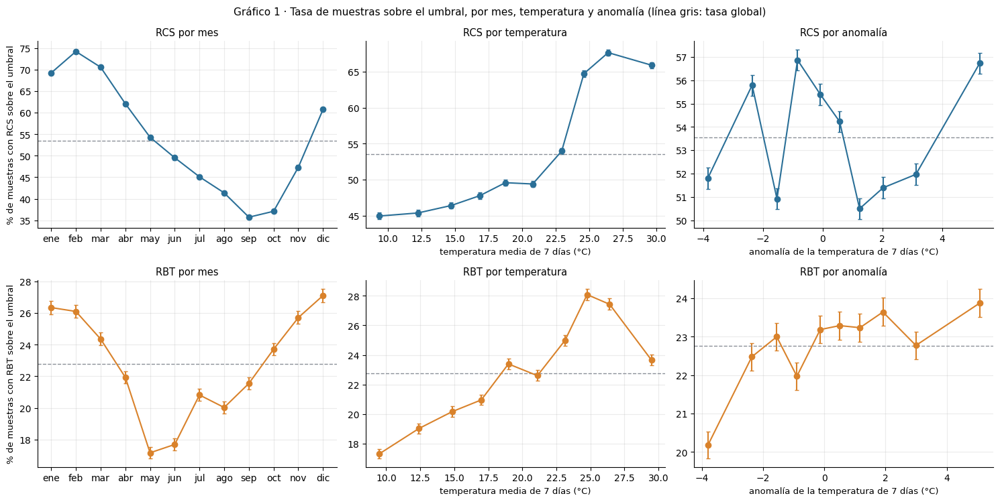

objetivo variable  primer decil (%)  último decil (%)
     RCS   temp_x              44.9              65.9
     RCS   anom_x              51.8              56.7
     RBT   temp_x              17.3              23.7
     RBT   anom_x              20.2              23.9


**En simple:** cada punto es el porcentaje de muestras que pasó el umbral en ese mes (izquierda), en ese tramo de temperatura (centro) o en ese tramo de anomalía (derecha). Si la curva sube con la temperatura pero se aplana en la columna de anomalía, el efecto que se ve en el centro es en buena parte la estación, no el calor en sí.

In [109]:
D7 = L.agregar_temperatura(d, temp, "media", 7)
MESES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
fig, ax = plt.subplots(2, 3, figsize=(15, 7.6))
tabla_tasas = []
for i, (t, y) in enumerate(L.OBJETIVOS.items()):
    x = D7[D7[y].notna() & D7["temp_x"].notna()]
    tasa = x[y].mean()
    g = x.groupby("mes")[y].agg(["mean", "sum", "count"])
    lo, hi = wilson(g["sum"], g["count"])
    ax[i, 0].errorbar(g.index, 100 * g["mean"], yerr=[100 * (g["mean"] - lo), 100 * (hi - g["mean"])], fmt="o-", color=COLOR[t], capsize=2)
    ax[i, 0].set_xticks(range(1, 13)); ax[i, 0].set_xticklabels(MESES)
    ax[i, 0].set_ylabel(f"% de muestras con {t} sobre el umbral"); ax[i, 0].set_title(f"{t} por mes")
    for j, (col, rot) in enumerate([("temp_x", "temperatura media de 7 días (°C)"), ("anom_x", "anomalía de la temperatura de 7 días (°C)")], start=1):
        q = pd.qcut(x[col], 10, duplicates="drop")
        gg = x.groupby(q, observed=True).agg(xm=(col, "mean"), k=(y, "sum"), n=(y, "size"))
        lo, hi = wilson(gg["k"], gg["n"]); pm = gg["k"] / gg["n"]
        ax[i, j].errorbar(gg["xm"], 100 * pm, yerr=[100 * (pm - lo), 100 * (hi - pm)], fmt="o-", color=COLOR[t], capsize=2)
        ax[i, j].set_xlabel(rot); ax[i, j].set_title(f"{t} por " + ("temperatura" if col == "temp_x" else "anomalía"))
        tabla_tasas.append({"objetivo": t, "variable": col, "primer decil (%)": round(100 * pm.iloc[0], 1), "último decil (%)": round(100 * pm.iloc[-1], 1)})
    for j in range(3):
        ax[i, j].axhline(100 * tasa, color=GRIS, ls="--", lw=1)
fig.suptitle("Gráfico 1 · Tasa de muestras sobre el umbral, por mes, temperatura y anomalía (línea gris: tasa global)", fontsize=11)
fig.tight_layout()
guardar(fig, "01_tasa_positivos_mes_temperatura.png")
print(pd.DataFrame(tabla_tasas).to_string(index=False))
en_simple("cada punto es el porcentaje de muestras que pasó el umbral en ese mes (izquierda), en ese tramo de temperatura (centro) o en ese tramo de anomalía "
          "(derecha). Si la curva sube con la temperatura pero se aplana en la columna de anomalía, el efecto que se ve en el centro es en buena parte la estación, no el calor en sí.")

### 6 · Modelos anidados y validación temporal
Modelos, de menor a mayor (todos `Pipeline`: `StandardScaler` en las numéricas + `OneHotEncoder` en la industria + `LogisticRegression`):

| Modelo | Predictores |
|---|---|
| R0 | tasa global del entrenamiento (sin predictores) |
| R1 | industria (= tasa por industria) |
| M1 | industria + estación (sen, cos del día del año) |
| M2 | industria + temperatura absoluta, **sin** estación (muestra el efecto confundido) |
| M3 | industria + estación + **anomalía** de la temperatura (el modelo que responde a la pregunta del calor) |

La composición (lactosa, grasa, proteína) va en un modelo aparte (sección 9), porque no todas las filas la tienen.
Primero se elige la **regularización C** (y se compara `class_weight='balanced'`) en el modelo M3 con la validación rodante 2021-2023 (la prueba 2024-2026 se muestra al lado pero no decide).

In [110]:
GRID_C = [1e-5, 1e-4, 1e-3, 1e-2, 1.0, 100.0]
filas = []
for t, y in L.OBJETIVOS.items():
    x = DATOS[t]
    ent, ev = x[x["fecha"] < L.CORTE_PRUEBA], x[x["fecha"] >= L.CORTE_PRUEBA]
    for cw, C in [(None, c) for c in GRID_C] + [("balanced", 1.0)]:
        r = {"objetivo": t, "C": C, "class_weight": cw or "-"}
        v = L.validar_rodante(x, y, NUM_M3, CAT, C=C, class_weight=cw)
        r.update({"AUC valid": v["AUC"], "log-loss valid": v["log-loss"], "Brier valid": v["Brier"]})
        p, _ = L.ajustar_predecir(L.hacer_pipeline(NUM_M3, CAT, C=C, class_weight=cw), ent, ev, y, NUM_M3, CAT)
        m = L.metricas(ev[y], p)
        mm = L.matriz_umbral(ev[y], p, 0.5)
        r.update({"AUC prueba": m["AUC"], "log-loss prueba": m["log-loss"], "Brier prueba": m["Brier"], "sens@0,5": mm["sensibilidad"], "espec@0,5": mm["especificidad"],
                  "prob. media predicha": p.mean(), "tasa observada": ev[y].mean()})
        filas.append(r)
reg = pd.DataFrame(filas)
print(reg.round(4).to_string(index=False))
C_ELEG = {}
for t in L.OBJETIVOS:
    s = reg[(reg["objetivo"] == t) & (reg["class_weight"] == "-")]
    mejor = s["log-loss valid"].min()
    C_ELEG[t] = float(s[s["log-loss valid"] <= mejor + 2e-4]["C"].min())     # empate técnico → la más regularizada
print("\nC elegido (menor log-loss de validación rodante; si empatan por menos de 0,0002, el más regularizado):", C_ELEG)
RES["C"] = C_ELEG
reg.to_csv(SALIDA / "regularizacion_y_balanceo.csv", index=False, encoding="utf-8-sig")

objetivo        C class_weight  AUC valid  log-loss valid  Brier valid  AUC prueba  log-loss prueba  Brier prueba  sens@0,5  espec@0,5  prob. media predicha  tasa observada
     RCS   0.0000            -     0.6113          0.6829       0.2449      0.6858           0.6649        0.2360    0.8305     0.3765                0.5418          0.5425
     RCS   0.0001            -     0.6168          0.6726       0.2399      0.6915           0.6438        0.2259    0.7874     0.4661                0.5580          0.5425
     RCS   0.0010            -     0.6224          0.6717       0.2394      0.6914           0.6402        0.2243    0.7889     0.4662                0.5671          0.5425
     RCS   0.0100            -     0.6232          0.6722       0.2395      0.6900           0.6404        0.2244    0.7892     0.4640                0.5691          0.5425
     RCS   1.0000            -     0.6231          0.6724       0.2396      0.6894           0.6408        0.2246    0.7887     0.4643 

**Cómo leerlo.** Con cientos de miles de filas y pocos predictores, la regularización casi no cambia nada hasta que C es muy chico
(el coeficiente se encoge hacia 0 y el modelo se parece a la referencia). `class_weight='balanced'` casi no mueve el AUC (el orden de las
muestras es prácticamente el mismo). En **RBT**, que tiene pocos positivos (alrededor de una de cada cinco muestras), **empeora mucho el log-loss y el Brier y la probabilidad media predicha se aleja
de la tasa observada** (mirar las dos últimas columnas); a cambio, la sensibilidad a 0,5 pasa de cero a un valor útil. En **RCS**, donde las clases ya están casi equilibradas, cambia poco.
Reponderar las clases equivale a mover el umbral de decisión, y en RBT se paga con la probabilidad calibrada. Por eso la probabilidad se estima sin reponderar, y el compromiso
sensibilidad/especificidad se resuelve eligiendo el umbral (sección 7).

In [111]:
MODELOS = {
    "R1 industria": ([], CAT),
    "M1 estación + industria": (["sen", "cos"], CAT),
    "M2 temperatura (sin estación) + industria": (["temp_x"], CAT),
    "M3 estación + anomalía + industria": (NUM_M3, CAT),
}
AJ = {}          # (objetivo, modelo) → dict con pipeline, predicciones y filas
filas = []
for t, y in L.OBJETIVOS.items():
    x = DATOS[t]
    ent, pru = x[x["fecha"] < L.CORTE_PRUEBA], x[x["fecha"] >= L.CORTE_PRUEBA]
    tasa0 = ent[y].mean()
    m0 = L.metricas(pru[y], np.full(len(pru), tasa0))
    filas.append({"objetivo": t, "modelo": "R0 tasa global", **m0, "ECE": abs(pru[y].mean() - tasa0), "pendiente calib.": np.nan, "prob. media": tasa0, "tasa observada": pru[y].mean()})
    for nombre, (num, cat) in MODELOS.items():
        p, pipe = L.ajustar_predecir(L.hacer_pipeline(num, cat, C=C_ELEG[t]), ent, pru, y, num, cat)
        AJ[(t, nombre)] = {"pipe": pipe, "p": p, "y": pru[y].to_numpy(), "ent": ent, "pru": pru, "num": num, "cat": cat}
        m = L.metricas(pru[y], p); _, ece = L.calibracion(pru[y], p); pend, inter = L.pendiente_calibracion(pru[y], p)
        filas.append({"objetivo": t, "modelo": nombre, **m, "ECE": ece, "pendiente calib.": pend, "prob. media": p.mean(), "tasa observada": pru[y].mean()})
    # modelo con class_weight balanced, solo para el gráfico de calibración
    p, pipe = L.ajustar_predecir(L.hacer_pipeline(NUM_M3, CAT, C=C_ELEG[t], class_weight="balanced"), ent, pru, y, NUM_M3, CAT)
    AJ[(t, "M3 balanceado")] = {"pipe": pipe, "p": p, "y": pru[y].to_numpy(), "ent": ent, "pru": pru, "num": NUM_M3, "cat": CAT}
res = pd.DataFrame(filas)
res["Δ log-loss vs R1"] = res["log-loss"] - res.groupby("objetivo")["log-loss"].transform(lambda s: s[res.loc[s.index, "modelo"] == "R1 industria"].iloc[0])
print(f"Prueba temporal: entrenar hasta 2023, probar {L.CORTE_PRUEBA.year}-2026 (C elegido por objetivo: {C_ELEG}).")
print(res.round(4).to_string(index=False))
res.to_csv(SALIDA / "metricas_prueba_modelos_anidados.csv", index=False, encoding="utf-8-sig")
RES["tabla_main"] = res

Prueba temporal: entrenar hasta 2023, probar 2024-2026 (C elegido por objetivo: {'RCS': 0.001, 'RBT': 0.001}).
objetivo                                    modelo    AUC  log-loss  Brier    ECE  pendiente calib.  prob. media  tasa observada  Δ log-loss vs R1
     RCS                            R0 tasa global 0.5000    0.6898 0.2483 0.0110               NaN       0.5315          0.5425            0.0059
     RCS                              R1 industria 0.5673    0.6839 0.2454 0.0250            1.1572       0.5461          0.5425            0.0000
     RCS                   M1 estación + industria 0.6908    0.6404 0.2244 0.0491            1.5205       0.5657          0.5425           -0.0435
     RCS M2 temperatura (sin estación) + industria 0.6059    0.6755 0.2413 0.0328            1.6707       0.5426          0.5425           -0.0084
     RCS        M3 estación + anomalía + industria 0.6914    0.6402 0.2243 0.0495            1.5249       0.5671          0.5425           -0.0437
     RB

**Cómo leerlo.** AUC: probabilidad de que una muestra positiva reciba más probabilidad que una negativa (0,5 = azar). Log-loss y Brier: error
de las probabilidades (menor es mejor), se comparan con **R1**, el piso razonable (la tasa de cada industria). **Pendiente de calibración** (regresión de lo observado sobre el logit de lo predicho): 1 = bien calibrado; **más de 1 = el modelo es tímido** (sus probabilidades están demasiado cerca del promedio y lo real se
abre más); menos de 1 = exagera (probabilidades demasiado extremas). **ECE**: distancia media entre lo predicho y lo observado.

In [112]:
# Modelos con composición: aparte, en el subconjunto de filas que tienen lactosa, grasa y proteína (la falta de composición depende de
# la industria y del año, así que se compara contra los mismos modelos reajustados en ese subconjunto).
COMP = L.COMPOSICION
MOD_COMP = {
    "M1s estación + industria (subconjunto)": (["sen", "cos"], CAT),
    "M3s estación + anomalía + industria (subconjunto)": (NUM_M3, CAT),
    "C1 estación + composición + industria": (["sen", "cos"] + COMP, CAT),
    "C2 estación + anomalía + composición + industria": (NUM_M3 + COMP, CAT),
}
filas = []
SUB = {}
for t, y in L.OBJETIVOS.items():
    x = DATOS[t]
    cobertura = x[COMP].notna().all(axis=1).mean()
    xs = x[x[COMP].notna().all(axis=1)]
    SUB[t] = xs
    ent, pru = xs[xs["fecha"] < L.CORTE_PRUEBA], xs[xs["fecha"] >= L.CORTE_PRUEBA]
    print(f"{t}: con composición completa {100 * cobertura:.1f} % de las filas ({len(xs):,}); positivos {100 * xs[y].mean():.1f} % (sin composición: {100 * x.loc[~x.index.isin(xs.index), y].mean():.1f} %) "
          f"· entrenamiento {len(ent):,} · prueba {len(pru):,}")
    p1, _ = L.ajustar_predecir(L.hacer_pipeline([], CAT, C=C_ELEG[t]), ent, pru, y, [], CAT)
    filas.append({"objetivo": t, "modelo": "R1s industria (subconjunto)", **L.metricas(pru[y], p1), "ECE": L.calibracion(pru[y], p1)[1], "pendiente calib.": L.pendiente_calibracion(pru[y], p1)[0]})
    for nombre, (num, cat) in MOD_COMP.items():
        p, pipe = L.ajustar_predecir(L.hacer_pipeline(num, cat, C=C_ELEG[t]), ent, pru, y, num, cat)
        AJ[(t, nombre)] = {"pipe": pipe, "p": p, "y": pru[y].to_numpy(), "ent": ent, "pru": pru, "num": num, "cat": cat}
        filas.append({"objetivo": t, "modelo": nombre, **L.metricas(pru[y], p), "ECE": L.calibracion(pru[y], p)[1], "pendiente calib.": L.pendiente_calibracion(pru[y], p)[0]})
resc = pd.DataFrame(filas)
print()
print(resc.round(4).to_string(index=False))
resc.to_csv(SALIDA / "metricas_prueba_con_composicion.csv", index=False, encoding="utf-8-sig")
RES["tabla_comp"] = resc

RCS: con composición completa 82.8 % de las filas (389,425); positivos 55.7 % (sin composición: 43.4 %) · entrenamiento 240,839 · prueba 148,586


RBT: con composición completa 88.9 % de las filas (458,719); positivos 20.6 % (sin composición: 40.0 %) · entrenamiento 296,946 · prueba 161,773



objetivo                                            modelo    AUC  log-loss  Brier    ECE  pendiente calib.
     RCS                       R1s industria (subconjunto) 0.5431    0.6852 0.2461 0.0225            0.7619
     RCS            M1s estación + industria (subconjunto) 0.6724    0.6479 0.2281 0.0517            1.5372
     RCS M3s estación + anomalía + industria (subconjunto) 0.6727    0.6479 0.2281 0.0536            1.5361
     RCS             C1 estación + composición + industria 0.7207    0.6176 0.2145 0.0469            1.3118
     RCS  C2 estación + anomalía + composición + industria 0.7213    0.6175 0.2144 0.0477            1.3179
     RBT                       R1s industria (subconjunto) 0.5280    0.4793 0.1510 0.0374            0.5979
     RBT            M1s estación + industria (subconjunto) 0.5645    0.4758 0.1498 0.0353            0.8661
     RBT M3s estación + anomalía + industria (subconjunto) 0.5626    0.4763 0.1500 0.0363            0.8400
     RBT             C1 est

### 7 · Curva ROC, calibración y matriz de confusión
Gráfico 2. ROC (izquierda) y calibración (derecha) en la **prueba 2024-2026**. La calibración agrupa las muestras en diez grupos según la probabilidad que
el modelo les dio y compara con el porcentaje que realmente superó el umbral. En línea de puntos, M3 con `class_weight='balanced'`: ilustra qué se pierde al reponderar.

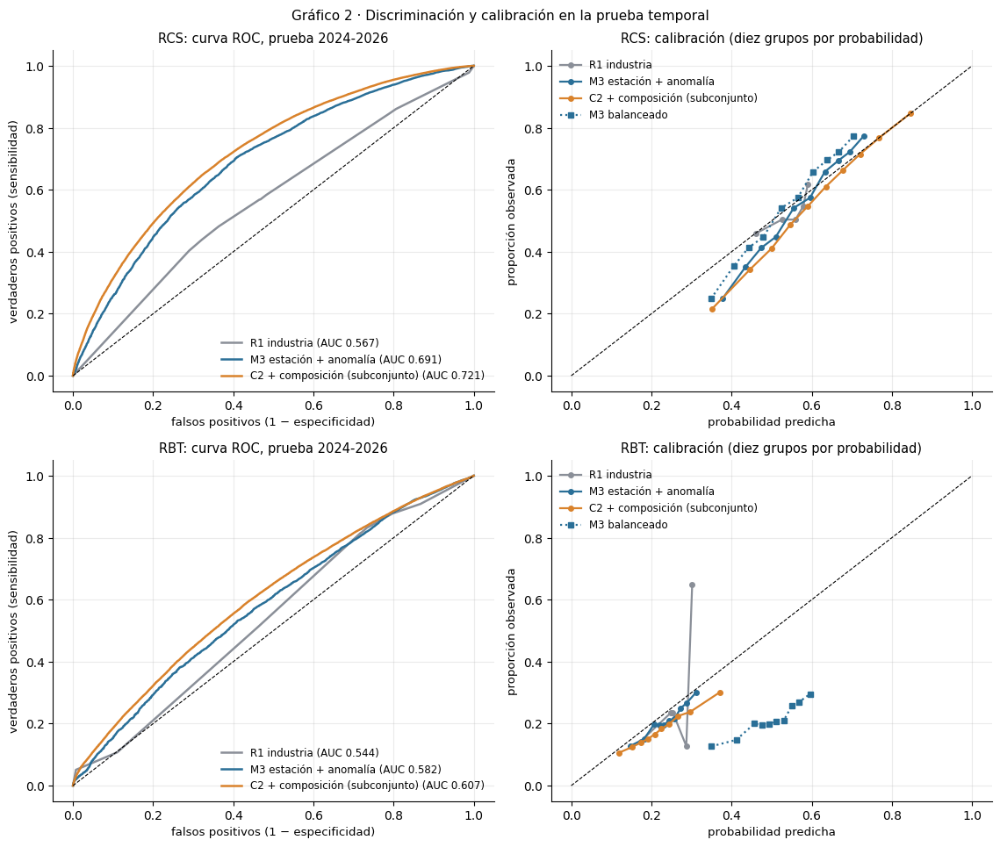

RCS calibración (prueba):
  R1 industria: ECE 0.025 · predicha por grupo [0.46, 0.53, 0.56, 0.58, 0.59] · observada [0.46, 0.5, 0.5, 0.55, 0.62]
  M3 estación + anomalía + industria: ECE 0.050 · predicha por grupo [0.38, 0.44, 0.47, 0.51, 0.56, 0.6, 0.63, 0.67, 0.69, 0.73] · observada [0.25, 0.35, 0.41, 0.45, 0.54, 0.57, 0.66, 0.7, 0.72, 0.77]
  C2 estación + anomalía + composición + industria: ECE 0.048 · predicha por grupo [0.35, 0.44, 0.5, 0.55, 0.59, 0.63, 0.68, 0.72, 0.77, 0.85] · observada [0.21, 0.34, 0.41, 0.49, 0.55, 0.61, 0.66, 0.72, 0.77, 0.85]
RBT calibración (prueba):
  R1 industria: ECE 0.038 · predicha por grupo [0.17, 0.25, 0.25, 0.29, 0.3] · observada [0.14, 0.23, 0.24, 0.13, 0.65]
  M3 estación + anomalía + industria: ECE 0.025 · predicha por grupo [0.15, 0.18, 0.21, 0.22, 0.23, 0.24, 0.26, 0.27, 0.29, 0.31] · observada [0.13, 0.15, 0.2, 0.19, 0.19, 0.21, 0.22, 0.25, 0.27, 0.3]
  C2 estación + anomalía + composición + industria: ECE 0.042 · predicha por grupo [0.12, 0

**En simple:** la curva ROC dice qué tan bien el modelo ordena las muestras de menos a más riesgosas (cuanto más arriba y a la izquierda, mejor; la diagonal es tirar una moneda). La calibración dice si la probabilidad se puede creer: si en el grupo al que el modelo le dio 60 % realmente el 60 % pasó el umbral, los puntos caen sobre la diagonal. Si los puntos quedan por debajo o por encima de la diagonal, el modelo está sobreestimando o subestimando el riesgo en esos años.

In [113]:
fig, ax = plt.subplots(2, 2, figsize=(11.5, 9.8))
SERIES = [("R1 industria", GRIS, "-", "R1 industria"), ("M3 estación + anomalía + industria", AZUL, "-", "M3 estación + anomalía"),
          ("C2 estación + anomalía + composición + industria", NARANJA, "-", "C2 + composición (subconjunto)"), ("M3 balanceado", AZUL, ":", "M3 balanceado")]
for i, t in enumerate(L.OBJETIVOS):
    for nombre, col, ls, lab in SERIES:
        a = AJ[(t, nombre)]
        if "balanceado" not in nombre:
            fpr, tpr, _ = roc_curve(a["y"], a["p"])
            ax[i, 0].plot(fpr, tpr, color=col, ls=ls, lw=1.8, label=f"{lab} (AUC {L.metricas(a['y'], a['p'])['AUC']:.3f})")
        tab, ece = L.calibracion(a["y"], a["p"])
        ax[i, 1].plot(tab["predicha"], tab["observada"], "o" + ls if ls == "-" else "s:", color=col, lw=1.6, ms=4, label=lab)
    ax[i, 0].plot([0, 1], [0, 1], color="k", lw=0.8, ls="--")
    ax[i, 0].set_xlabel("falsos positivos (1 − especificidad)"); ax[i, 0].set_ylabel("verdaderos positivos (sensibilidad)")
    ax[i, 0].set_title(f"{t}: curva ROC, prueba 2024-2026"); ax[i, 0].legend(loc="lower right")
    lim = [0, 1]
    ax[i, 1].plot(lim, lim, color="k", lw=0.8, ls="--")
    ax[i, 1].set_xlabel("probabilidad predicha"); ax[i, 1].set_ylabel("proporción observada")
    ax[i, 1].set_title(f"{t}: calibración (diez grupos por probabilidad)"); ax[i, 1].legend(loc="upper left")
fig.suptitle("Gráfico 2 · Discriminación y calibración en la prueba temporal", fontsize=11)
fig.tight_layout()
guardar(fig, "02_roc_calibracion.png")
for t in L.OBJETIVOS:
    print(t, "calibración (prueba):")
    for nombre in ("R1 industria", "M3 estación + anomalía + industria", "C2 estación + anomalía + composición + industria"):
        tab, ece = L.calibracion(AJ[(t, nombre)]["y"], AJ[(t, nombre)]["p"])
        print(f"  {nombre}: ECE {ece:.3f} · predicha por grupo {tab['predicha'].round(2).tolist()} · observada {tab['observada'].round(2).tolist()}")
en_simple("la curva ROC dice qué tan bien el modelo ordena las muestras de menos a más riesgosas (cuanto más arriba y a la izquierda, mejor; la diagonal es tirar una moneda). "
          "La calibración dice si la probabilidad se puede creer: si en el grupo al que el modelo le dio 60 % realmente el 60 % pasó el umbral, los puntos caen sobre la diagonal. "
          "Si los puntos quedan por debajo o por encima de la diagonal, el modelo está sobreestimando o subestimando el riesgo en esos años.")

**Matriz de confusión y el compromiso sensibilidad/especificidad.** Una probabilidad se convierte en un «sí/no» con un umbral de decisión. Bajarlo detecta más positivos
(sube la **sensibilidad**) a costa de marcar más negativos como positivos (baja la **especificidad**); subirlo hace lo contrario. No hay un umbral «correcto»: depende
de cuánto cuesta no detectar una muestra mala frente a revisar una buena. Acá se toma como punto de partida el umbral de **Youden** calculado **en el entrenamiento**
(el que maximiza sensibilidad + especificidad − 1), se lo aplica a la prueba y se muestran otros cortes para ver el compromiso.

In [114]:
filas, tablas_umbral = [], []
for t in L.OBJETIVOS:
    for nombre in ("M3 estación + anomalía + industria", "C2 estación + anomalía + composición + industria"):
        a = AJ[(t, nombre)]; y = L.OBJETIVOS[t]
        cols = a["num"] + a["cat"]
        p_ent = a["pipe"].predict_proba(a["ent"][cols])[:, 1]
        u = L.umbral_youden(a["ent"][y], p_ent)
        mm = L.matriz_umbral(a["y"], a["p"], u)
        filas.append({"objetivo": t, "modelo": nombre, **mm})
        if nombre.startswith("C2") or nombre.startswith("M3"):
            for q in (0.1, 0.3, 0.5, 0.7, 0.9):
                tablas_umbral.append({"objetivo": t, "modelo": nombre[:2], **L.matriz_umbral(a["y"], a["p"], float(np.quantile(a["p"], q)))})
cm = pd.DataFrame(filas)
print("Matriz de confusión en la prueba 2024-2026, con el umbral de Youden del entrenamiento:")
print(cm.round(3).to_string(index=False))
print()
tu = pd.DataFrame(tablas_umbral)
print("Compromiso sensibilidad / especificidad al mover el umbral (cortes en los percentiles 10-90 de la probabilidad predicha):")
print(tu.round(3).to_string(index=False))
cm.to_csv(SALIDA / "matriz_confusion_umbral_youden.csv", index=False, encoding="utf-8-sig")
tu.to_csv(SALIDA / "compromiso_umbrales.csv", index=False, encoding="utf-8-sig")
RES["cm"] = cm

Matriz de confusión en la prueba 2024-2026, con el umbral de Youden del entrenamiento:
objetivo                                           modelo  umbral    VP    FN    FP    VN  sensibilidad  especificidad  precisión (VPP)  exactitud
     RCS               M3 estación + anomalía + industria   0.519 72013 22752 39140 40783         0.760          0.510            0.648      0.646
     RCS C2 estación + anomalía + composición + industria   0.549 64894 18360 30782 34550         0.779          0.529            0.678      0.669
     RBT               M3 estación + anomalía + industria   0.227 24720 12283 78099 60146         0.668          0.435            0.240      0.484
     RBT C2 estación + anomalía + composición + industria   0.223 17508 12110 57444 74711         0.591          0.565            0.234      0.570

Compromiso sensibilidad / especificidad al mover el umbral (cortes en los percentiles 10-90 de la probabilidad predicha):
objetivo modelo  umbral    VP    FN     FP     VN  sens

### 8 · Interpretación: odds ratio con intervalos por bootstrap por bloques
Los **odds ratio** salen de exponenciar los coeficientes: un OR de 1,10 por °C dice que cada grado de anomalía **multiplica por 1,10 las chances** (odds) de pasar el umbral,
a igualdad del resto. El modelo de interpretación usa la anomalía de la temperatura, **el mes** (en vez de sen/cos, para dar un OR por mes) y la industria, ajustado con
**todos los datos 2019-2026**. Los OR de mes y de industria se expresan **respecto del promedio** de los meses (o de las industrias).

**Intervalos.** Las filas no son independientes: muchas muestras comparten informe, día y tambo, y todas las industrias ven el mismo clima. Un intervalo calculado como si fueran
independientes sería demasiado angosto. Se usa **bootstrap por bloques**: se remuestrean **semanas completas** con reposición (300 réplicas) y se reajusta el modelo; el
intervalo es el percentil 2,5-97,5 de los OR. (Como los predictores solo dependen de la industria, el día y el mes, las filas se agrupan en celdas con peso: el ajuste es idéntico al
de las filas y el bootstrap rápido; se verifica abajo.) Queda sin captar la dependencia entre semanas vecinas: por eso se prueba también con bloques de 4 y 8 semanas.

In [115]:
def ajustar_or(x, t, num, cat, B=300, ancho=1, C=1.0):
    y = L.OBJETIVOS[t]
    cel = L.armar_celdas(x, y, ["cliente", "fecha", "mes"], extra=[c for c in num if c not in ("cliente", "fecha", "mes")])
    pipe = L.hacer_pipeline(num, cat, C=C)
    pipe.fit(cel[num + cat], cel["y"], lr__sample_weight=cel["w"])
    nombres = L.nombres_columnas(pipe)
    punto = L.coef_crudos(pipe, nombres)
    sal = L.bootstrap_bloques(pipe, cel[num + cat], cel["y"], cel["w"], L.bloques_de(cel["semana"], ancho), B=B, semilla=L.SEMILLA)
    return {"pipe": pipe, "nombres": nombres, "punto": punto, "boot": L.desescalar_matriz(pipe, sal), "celdas": len(cel) // 2}

def or_variable(o, nombre, escala=1.0):
    i = o["nombres"].index(nombre)
    b = o["boot"][:, i] * escala
    return float(np.exp(o["punto"].iloc[i] * escala)), float(np.exp(np.quantile(b, 0.025))), float(np.exp(np.quantile(b, 0.975)))

NUM_OR, CAT_OR = ["anom_x"], ["cliente", "mes"]
OR = {}
t0 = time.time()
for t in L.OBJETIVOS:
    OR[t] = ajustar_or(DATOS[t], t, NUM_OR, CAT_OR, B=300)
    print(f"{t}: {OR[t]['celdas']:,} celdas (industria × día) · bootstrap 300 réplicas listo")
print(f"{time.time() - t0:.0f} s")

# verificación: celdas vs filas
for t, y in L.OBJETIVOS.items():
    x = DATOS[t]
    pf = L.hacer_pipeline(NUM_OR, CAT_OR, C=1.0).fit(x[NUM_OR + CAT_OR], x[y].astype(int))
    cf = L.coef_crudos(pf)
    print(f"{t}: coeficiente de la anomalía, filas {cf['num__anom_x']:.5f} vs celdas {OR[t]['punto']['num__anom_x']:.5f} (diferencia {abs(cf['num__anom_x'] - OR[t]['punto']['num__anom_x']):.1e})")

RCS: 7,305 celdas (industria × día) · bootstrap 300 réplicas listo


RBT: 7,660 celdas (industria × día) · bootstrap 300 réplicas listo
9 s


RCS: coeficiente de la anomalía, filas -0.01056 vs celdas -0.01056 (diferencia 2.0e-06)


RBT: coeficiente de la anomalía, filas -0.00817 vs celdas -0.00820 (diferencia 2.1e-05)


In [116]:
# Efecto de la temperatura según qué se controla (ventana elegida por objetivo)
filas = []
for t in L.OBJETIVOS:
    x = DATOS[t]
    espec = {"(a) temperatura absoluta, solo industria (confunde estación y calor)": (["temp_x"], ["cliente"], "num__temp_x"),
             "(b) anomalía, solo industria": (["anom_x"], ["cliente"], "num__anom_x"),
             "(c) temperatura absoluta, industria + mes": (["temp_x"], CAT_OR, "num__temp_x"),
             "(d) anomalía, industria + mes (modelo de interpretación)": (NUM_OR, CAT_OR, "num__anom_x")}
    for nombre, (num, cat, var) in espec.items():
        o = OR[t] if nombre.startswith("(d)") else ajustar_or(x, t, num, cat, B=300)
        orr, lo, hi = or_variable(o, var)
        filas.append({"objetivo": t, "especificación": nombre, "OR por +1 °C": orr, "IC95 inf": lo, "IC95 sup": hi})
tt = pd.DataFrame(filas)
print("Odds ratio por +1 °C según lo que se controle (IC95 por bootstrap de semanas):")
print(tt.round(4).to_string(index=False))
tt.to_csv(SALIDA / "or_temperatura_segun_control.csv", index=False, encoding="utf-8-sig")
RES["control"] = tt
RES["or_calor"] = {t: or_variable(OR[t], "num__anom_x") for t in L.OBJETIVOS}
for t in L.OBJETIVOS:
    o, lo, hi = RES["or_calor"][t]
    print(f"{t}: anomalía ({ELEG[t][0]} de {ELEG[t][1]} días): OR por +1 °C = {o:.3f} [{lo:.3f}; {hi:.3f}] · por +3 °C = {o ** 3:.3f} [{lo ** 3:.3f}; {hi ** 3:.3f}]")

Odds ratio por +1 °C según lo que se controle (IC95 por bootstrap de semanas):
objetivo                                                       especificación  OR por +1 °C  IC95 inf  IC95 sup
     RCS (a) temperatura absoluta, solo industria (confunde estación y calor)        1.0298    1.0221    1.0383
     RCS                                         (b) anomalía, solo industria        0.9927    0.9795    1.0069
     RCS                            (c) temperatura absoluta, industria + mes        0.9910    0.9829    1.0013
     RCS             (d) anomalía, industria + mes (modelo de interpretación)        0.9895    0.9809    0.9999
     RBT (a) temperatura absoluta, solo industria (confunde estación y calor)        1.0191    1.0139    1.0246
     RBT                                         (b) anomalía, solo industria        0.9956    0.9871    1.0035
     RBT                            (c) temperatura absoluta, industria + mes        0.9934    0.9857    1.0004
     RBT             (d) 

In [117]:
# Odds ratio por mes y por industria (respecto del promedio), con IC95 por bootstrap de semanas
filas_forest = {}
for t in L.OBJETIVOS:
    o = OR[t]
    out = []
    orr, lo, hi = RES["or_calor"][t]
    out.append(("anomalía +1 °C", "calor", orr, lo, hi))
    niv, dev_p = L.or_desvio_categoria(o["punto"].to_numpy(), o["nombres"], "cat__mes_")
    _, dev_b = L.or_desvio_categoria(o["boot"], o["nombres"], "cat__mes_")
    for k in sorted(range(len(niv)), key=lambda k: int(niv[k])):
        out.append((MESES[int(niv[k]) - 1], "mes", float(np.exp(dev_p[0, k])), float(np.exp(np.quantile(dev_b[:, k], 0.025))), float(np.exp(np.quantile(dev_b[:, k], 0.975)))))
    niv, dev_p = L.or_desvio_categoria(o["punto"].to_numpy(), o["nombres"], "cat__cliente_")
    _, dev_b = L.or_desvio_categoria(o["boot"], o["nombres"], "cat__cliente_")
    for k in sorted(range(len(niv)), key=lambda k: niv[k]):
        out.append((niv[k], "industria", float(np.exp(dev_p[0, k])), float(np.exp(np.quantile(dev_b[:, k], 0.025))), float(np.exp(np.quantile(dev_b[:, k], 0.975)))))
    filas_forest[t] = pd.DataFrame(out, columns=["término", "grupo", "OR", "IC95 inf", "IC95 sup"])
    print(f"{t} — odds ratio (mes e industria: respecto del promedio de sus niveles):")
    print(filas_forest[t].round(3).to_string(index=False)); print()
    filas_forest[t].to_csv(SALIDA / f"odds_ratio_{t.lower()}.csv", index=False, encoding="utf-8-sig")
RES["forest"] = filas_forest

RCS — odds ratio (mes e industria: respecto del promedio de sus niveles):
       término     grupo    OR  IC95 inf  IC95 sup
anomalía +1 °C     calor 0.989     0.981     1.000
           ene       mes 1.899     1.634     2.310
           feb       mes 2.518     2.186     3.010
           mar       mes 2.074     1.778     2.435
           abr       mes 1.396     1.184     1.642
           may       mes 0.991     0.880     1.105
           jun       mes 0.806     0.689     0.950
           jul       mes 0.684     0.578     0.800
           ago       mes 0.580     0.522     0.644
           sep       mes 0.463     0.409     0.521
           oct       mes 0.504     0.457     0.553
           nov       mes 0.757     0.671     0.873
           dic       mes 1.288     1.143     1.435
       IND-103 industria 0.984     0.423     1.294
        IND-29 industria 1.054     1.006     1.166
        IND-30 industria 1.200     1.132     1.332
        IND-51 industria 1.014     0.926     1.209
        

Gráfico 3. Odds ratio con intervalo de 95 % (bootstrap por bloques de semanas). La línea vertical en 1 es «sin efecto». Arriba el efecto de **+1 °C de anomalía**; después los
meses y las industrias, cada uno relativo al promedio de los de su grupo. Eje en escala logarítmica.

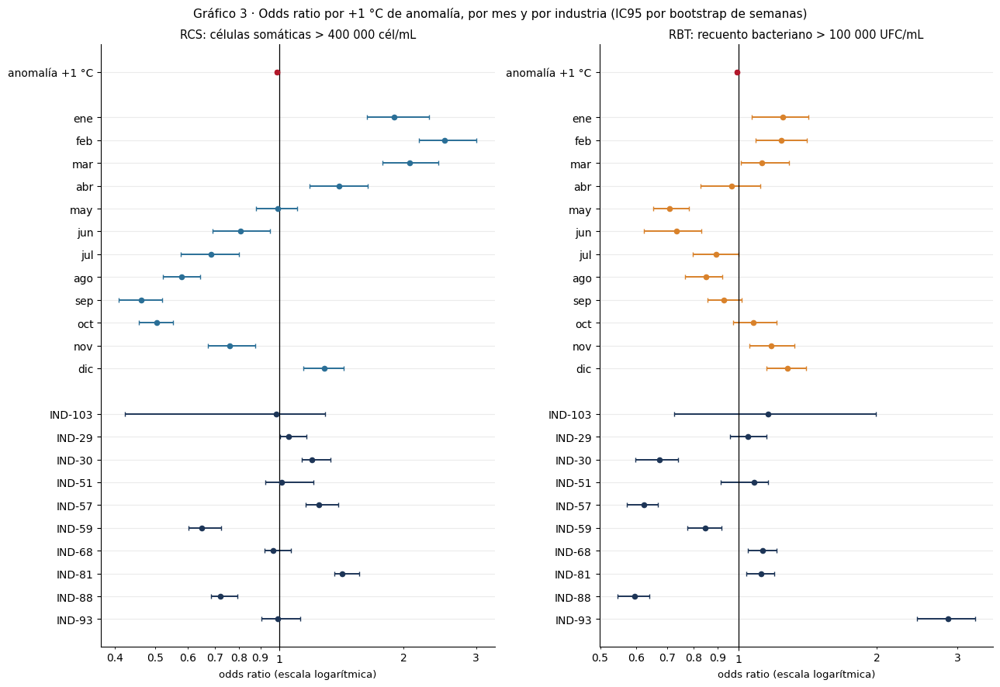

**En simple:** cada punto dice cuántas veces cambian las chances de pasar el umbral: 1 es «igual que el promedio», más de 1 es más riesgo, menos de 1 es menos. La barra es la incertidumbre: si cruza el 1, no se puede asegurar que haya diferencia. El primer renglón es el efecto de un grado más de calor que lo habitual para la fecha, con la estación ya descontada; los meses muestran la estacionalidad pura y las industrias, cuánto cambia el riesgo de una a otra.

In [118]:
fig, ax = plt.subplots(1, 2, figsize=(13, 9), sharey=False)
for k, t in enumerate(L.OBJETIVOS):
    f = filas_forest[t].reset_index(drop=True)
    ypos, pos = [], 0
    for g, sub in f.groupby("grupo", sort=False):
        for i in sub.index:
            ypos.append(pos); pos += 1
        pos += 1
    f["y"] = ypos
    for g, col in [("calor", "#b2182b"), ("mes", COLOR[t]), ("industria", OSCURO)]:
        s = f[f["grupo"] == g]
        ax[k].errorbar(s["OR"], s["y"], xerr=[s["OR"] - s["IC95 inf"], s["IC95 sup"] - s["OR"]], fmt="o", color=col, capsize=2.5, ms=4.5, lw=1.4)
    ax[k].axvline(1, color="k", lw=0.9)
    ax[k].set_xscale("log"); ax[k].set_yticks(f["y"]); ax[k].set_yticklabels(f["término"]); ax[k].invert_yaxis()
    ax[k].set_xlabel("odds ratio (escala logarítmica)"); ax[k].set_title(f"{t}: {NOMBRE[t]}")
    ax[k].xaxis.set_major_formatter(mt.FormatStrFormatter("%.2g"))
    ax[k].xaxis.set_minor_formatter(mt.FormatStrFormatter("%.2g"))
fig.suptitle("Gráfico 3 · Odds ratio por +1 °C de anomalía, por mes y por industria (IC95 por bootstrap de semanas)", fontsize=11)
fig.tight_layout()
guardar(fig, "03_odds_ratio.png")
en_simple("cada punto dice cuántas veces cambian las chances de pasar el umbral: 1 es «igual que el promedio», más de 1 es más riesgo, menos de 1 es menos. La barra es la incertidumbre: "
          "si cruza el 1, no se puede asegurar que haya diferencia. El primer renglón es el efecto de un grado más de calor que lo habitual para la fecha, con la estación ya descontada; los meses muestran la estacionalidad pura y las industrias, cuánto cambia el riesgo de una a otra.")

In [119]:
# Robustez del efecto del calor: ventana, ancho del bloque, y solo fechas exactas (no de creación del archivo)
filas = []
for t, y in L.OBJETIVOS.items():
    for est, n in VENTANAS:
        x = base_objetivo(t, est, n)
        o = ajustar_or(x, t, NUM_OR, CAT_OR, B=200)
        orr, lo, hi = or_variable(o, "num__anom_x")
        filas.append({"objetivo": t, "variante": f"ventana {est} {n} d", "OR por +1 °C": orr, "IC95 inf": lo, "IC95 sup": hi})
    x = DATOS[t]
    for ancho in (4, 8):
        o = ajustar_or(x, t, NUM_OR, CAT_OR, B=200, ancho=ancho)
        orr, lo, hi = or_variable(o, "num__anom_x")
        filas.append({"objetivo": t, "variante": f"bloques de {ancho} semanas", "OR por +1 °C": orr, "IC95 inf": lo, "IC95 sup": hi})
    xf = x[x["fecha_fina"]]
    o = ajustar_or(xf, t, NUM_OR, CAT_OR, B=200)
    orr, lo, hi = or_variable(o, "num__anom_x")
    filas.append({"objetivo": t, "variante": f"solo fecha exacta ({len(xf):,} filas)", "OR por +1 °C": orr, "IC95 inf": lo, "IC95 sup": hi})
    xf = x[x["fecha"] < L.CORTE_PRUEBA]
    o = ajustar_or(xf, t, NUM_OR, CAT_OR, B=200)
    orr, lo, hi = or_variable(o, "num__anom_x")
    filas.append({"objetivo": t, "variante": "solo entrenamiento (hasta 2023)", "OR por +1 °C": orr, "IC95 inf": lo, "IC95 sup": hi})
rob = pd.DataFrame(filas)
print("Robustez del OR por +1 °C de anomalía (con mes e industria; 200 réplicas):")
print(rob.round(4).to_string(index=False))
rob.to_csv(SALIDA / "or_calor_robustez.csv", index=False, encoding="utf-8-sig")
RES["robustez"] = rob

Robustez del OR por +1 °C de anomalía (con mes e industria; 200 réplicas):
objetivo                          variante  OR por +1 °C  IC95 inf  IC95 sup
     RCS                 ventana media 3 d        0.9904    0.9776    1.0039
     RCS                 ventana media 7 d        0.9980    0.9810    1.0181
     RCS                ventana media 14 d        1.0164    0.9941    1.0419
     RCS                   ventana max 3 d        0.9895    0.9808    1.0000
     RCS                   ventana max 7 d        0.9959    0.9859    1.0087
     RCS                  ventana max 14 d        1.0102    0.9951    1.0226
     RCS              bloques de 4 semanas        0.9895    0.9799    1.0009
     RCS              bloques de 8 semanas        0.9895    0.9783    1.0009
     RCS solo fecha exacta (246,730 filas)        0.9878    0.9798    0.9973
     RCS   solo entrenamiento (hasta 2023)        0.9904    0.9821    0.9996
     RBT                 ventana media 3 d        0.9979    0.9870    1.0074
 

### 9 · Composición: la señal de mastitis (lactosa)
Más células somáticas, menos lactosa: la mastitis daña la glándula y la lactosa de la leche baja. Se ajusta el modelo **C2** (estación + anomalía + composición + industria) en el subconjunto con lactosa, grasa y proteína.
**Aclaración:** lactosa, grasa y proteína son análisis aparte de las células y de las bacterias, no derivan del objetivo, pero **no son causas**; la relación es
una señal de que el tambo tiene mastitis, útil para estimar el riesgo, y no prueba que la lactosa baje por sí sola el recuento. Los OR se calculan por +0,1 g/100 g de cada componente (bootstrap por semanas, 150 réplicas, ajustado con todas las filas del subconjunto).

In [120]:
NUM_C2 = NUM_M3 + COMP
OR_COMP = {}
t0 = time.time()
for t, y in L.OBJETIVOS.items():
    xs = SUB[t]
    pipe = L.hacer_pipeline(NUM_C2, CAT, C=1.0).fit(xs[NUM_C2 + CAT], xs[y].astype(int))
    sal = L.bootstrap_bloques(pipe, xs[NUM_C2 + CAT], xs[y].astype(int).to_numpy(), np.ones(len(xs)), L.bloques_de(xs["semana"]), B=150, semilla=L.SEMILLA)
    nombres = L.nombres_columnas(pipe); punto = L.coef_crudos(pipe, nombres); boot = L.desescalar_matriz(pipe, sal)
    OR_COMP[t] = {"pipe": pipe, "nombres": nombres, "punto": punto, "boot": boot}
    filas = []
    for var, esc, lab in [("num__lactosa", 0.1, "lactosa +0,1 g/100 g"), ("num__grasa", 0.1, "grasa +0,1 g/100 g"), ("num__proteina", 0.1, "proteína +0,1 g/100 g"), ("num__anom_x", 1.0, "anomalía +1 °C")]:
        o, lo, hi = or_variable(OR_COMP[t], var, esc)
        filas.append({"término": lab, "OR": o, "IC95 inf": lo, "IC95 sup": hi})
    tab = pd.DataFrame(filas)
    print(f"{t}: odds ratio del modelo con composición (filas {len(xs):,}; IC95 por bootstrap de semanas):")
    print(tab.round(3).to_string(index=False)); print()
    tab.assign(objetivo=t).to_csv(SALIDA / f"odds_ratio_composicion_{t.lower()}.csv", index=False, encoding="utf-8-sig")
    OR_COMP[t]["tabla"] = tab
print(f"{time.time() - t0:.0f} s")
RES["or_lactosa"] = {t: OR_COMP[t]["tabla"].iloc[0][["OR", "IC95 inf", "IC95 sup"]].astype(float).tolist() for t in L.OBJETIVOS}

RCS: odds ratio del modelo con composición (filas 389,425; IC95 por bootstrap de semanas):
              término    OR  IC95 inf  IC95 sup
 lactosa +0,1 g/100 g 0.699     0.687     0.710
   grasa +0,1 g/100 g 1.043     1.037     1.048
proteína +0,1 g/100 g 1.022     1.009     1.039
       anomalía +1 °C 0.990     0.978     1.001



RBT: odds ratio del modelo con composición (filas 458,719; IC95 por bootstrap de semanas):
              término    OR  IC95 inf  IC95 sup
 lactosa +0,1 g/100 g 0.813     0.803     0.824
   grasa +0,1 g/100 g 1.014     1.011     1.018
proteína +0,1 g/100 g 0.990     0.977     1.006
       anomalía +1 °C 0.997     0.989     1.005



150 s


Gráfico 4. Probabilidad predicha según la lactosa. La curva es la **dependencia parcial** del modelo C2 ajustado hasta 2023 y evaluado en la prueba 2024-2026: para cada valor de lactosa se
asigna ese valor a todas las muestras de prueba (el resto queda como está) y se promedia la probabilidad predicha. Los puntos son la proporción observada de positivos en diez grupos de lactosa de la prueba.

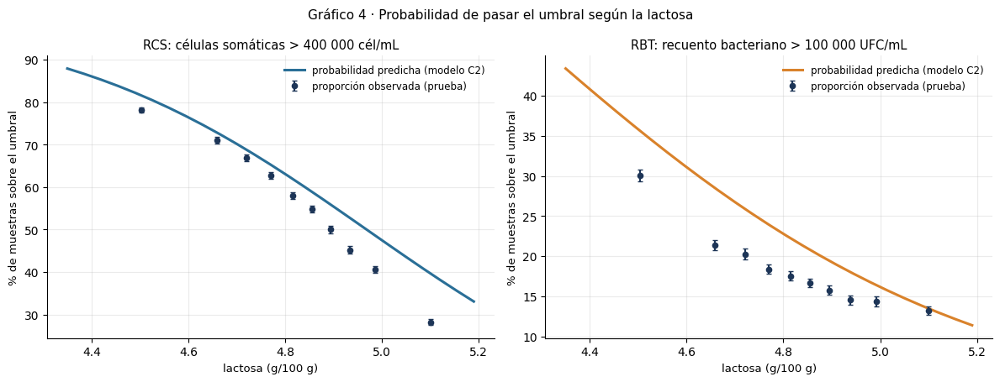

RCS: la probabilidad predicha pasa de 87.9 % con lactosa 4.35 a 33.1 % con lactosa 5.19 g/100 g
RBT: la probabilidad predicha pasa de 43.4 % con lactosa 4.35 a 11.4 % con lactosa 5.19 g/100 g


**En simple:** la curva muestra cuánto cambia, en promedio, la probabilidad de pasar el umbral cuando solo cambia la lactosa de la muestra. Si baja al subir la lactosa (más células con menos lactosa), es la huella de la mastitis; los puntos son lo que pasó de verdad y deberían acompañar la curva. Es una señal asociada, no una causa.

In [121]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
res_lact = {}
for k, t in enumerate(L.OBJETIVOS):
    y = L.OBJETIVOS[t]
    a = AJ[(t, "C2 estación + anomalía + composición + industria")]
    pru = a["pru"]; cols = a["num"] + a["cat"]
    q = pru["lactosa"].quantile([0.01, 0.99]).to_numpy()
    grilla = np.linspace(q[0], q[1], 25)
    muestra = pru.sample(min(20000, len(pru)), random_state=L.SEMILLA)[cols]
    pd_ = []
    for g in grilla:
        z = muestra.copy(); z["lactosa"] = g
        pd_.append(a["pipe"].predict_proba(z)[:, 1].mean())
    obs = pru.groupby(pd.qcut(pru["lactosa"], 10, duplicates="drop"), observed=True).agg(l=("lactosa", "mean"), k=(y, "sum"), n=(y, "size"))
    lo, hi = wilson(obs["k"], obs["n"]); pm = obs["k"] / obs["n"]
    ax[k].plot(grilla, 100 * np.array(pd_), color=COLOR[t], lw=2.2, label="probabilidad predicha (modelo C2)")
    ax[k].errorbar(obs["l"], 100 * pm, yerr=[100 * (pm - lo), 100 * (hi - pm)], fmt="o", color=OSCURO, capsize=2, ms=4.5, label="proporción observada (prueba)")
    ax[k].set_xlabel("lactosa (g/100 g)"); ax[k].set_ylabel("% de muestras sobre el umbral"); ax[k].set_title(f"{t}: {NOMBRE[t]}"); ax[k].legend(loc="best")
    res_lact[t] = (float(pd_[0]), float(pd_[-1]), float(grilla[0]), float(grilla[-1]))
fig.suptitle("Gráfico 4 · Probabilidad de pasar el umbral según la lactosa", fontsize=11)
fig.tight_layout()
guardar(fig, "04_probabilidad_vs_lactosa.png")
for t, (p0, p1, g0, g1) in res_lact.items():
    print(f"{t}: la probabilidad predicha pasa de {100 * p0:.1f} % con lactosa {g0:.2f} a {100 * p1:.1f} % con lactosa {g1:.2f} g/100 g")
RES["lactosa_pd"] = res_lact
en_simple("la curva muestra cuánto cambia, en promedio, la probabilidad de pasar el umbral cuando solo cambia la lactosa de la muestra. Si baja al subir la lactosa (más células con menos lactosa), "
          "es la huella de la mastitis; los puntos son lo que pasó de verdad y deberían acompañar la curva. Es una señal asociada, no una causa.")

### 10 · Una industria afuera (`GroupKFold` por cliente)
Para ver si el modelo sirve en una industria que no vio, se entrena con las otras nueve y se prueba en la que quedó afuera (en cada fila). Como la industria nueva no tiene
su propio nivel, el modelo **no lleva industria** (estación; estación + anomalía; y estación + anomalía + composición) y se lo compara con la tasa global de las otras industrias. Se informa el AUC **dentro** de la
industria dejada afuera, el log-loss y el Brier, y el **sesgo** (probabilidad media predicha menos la tasa observada): ahí se ve cuánto pesa el nivel propio de cada industria.

In [122]:
def loio(t):
    y = L.OBJETIVOS[t]
    x = DATOS[t]
    modelos = {"S1 estación": (["sen", "cos"], False), "S2 estación + anomalía": (NUM_M3, False), "S3 estación + anomalía + composición": (NUM_C2, True)}
    gkf = GroupKFold(n_splits=x["cliente"].nunique())
    filas = []
    for ent_idx, te_idx in gkf.split(x, groups=x["cliente"]):
        ent, te = x.iloc[ent_idx], x.iloc[te_idx]
        ind = te["cliente"].unique()
        assert len(ind) == 1
        fila = {"industria": ind[0], "filas": len(te), "tasa observada": te[y].mean(), "tasa ref. (otras industrias)": ent[y].mean()}
        mr = L.metricas(te[y], np.full(len(te), ent[y].mean()))
        fila["Brier ref."] = mr["Brier"]; fila["log-loss ref."] = mr["log-loss"]
        for nombre, (num, comp) in modelos.items():
            e2, t2 = (ent[ent[COMP].notna().all(axis=1)], te[te[COMP].notna().all(axis=1)]) if comp else (ent, te)
            if len(t2) < 200 or t2[y].nunique() < 2:
                fila[f"AUC {nombre[:2]}"] = np.nan; fila[f"skill Brier {nombre[:2]}"] = np.nan; fila[f"sesgo {nombre[:2]}"] = np.nan
                continue
            p, _ = L.ajustar_predecir(L.hacer_pipeline(num, [], C=C_ELEG[t]), e2, t2, y, num, [])
            m = L.metricas(t2[y], p)
            br = L.metricas(t2[y], np.full(len(t2), e2[y].mean()))["Brier"]
            fila[f"AUC {nombre[:2]}"] = m["AUC"]; fila[f"skill Brier {nombre[:2]}"] = 1 - m["Brier"] / br; fila[f"sesgo {nombre[:2]}"] = p.mean() - t2[y].mean()
        filas.append(fila)
    return pd.DataFrame(filas)

LOIO = {}
for t in L.OBJETIVOS:
    t0 = time.time()
    LOIO[t] = loio(t)
    print(f"\n{t}: una industria afuera (skill Brier = 1 − Brier del modelo / Brier de la tasa global; > 0 mejora la referencia; sesgo = media predicha − observada) · {time.time() - t0:.0f} s")
    f = LOIO[t].copy()
    print(f.round(3).to_string(index=False))
    w = f["filas"]
    resumen = {c: float(np.nansum(f[c] * w) / w[f[c].notna()].sum()) for c in f.columns if c.startswith(("AUC", "skill"))}
    print("Promedio ponderado por filas:", {k: round(v, 3) for k, v in resumen.items()})
    f.to_csv(SALIDA / f"industria_afuera_{t.lower()}.csv", index=False, encoding="utf-8-sig")
    LOIO[t].attrs["resumen"] = resumen
RES["loio"] = LOIO


RCS: una industria afuera (skill Brier = 1 − Brier del modelo / Brier de la tasa global; > 0 mejora la referencia; sesgo = media predicha − observada) · 4 s
industria  filas  tasa observada  tasa ref. (otras industrias)  Brier ref.  log-loss ref.  AUC S1  skill Brier S1  sesgo S1  AUC S2  skill Brier S2  sesgo S2  AUC S3  skill Brier S3  sesgo S3
   IND-68 138914           0.518                         0.543       0.250          0.694   0.654           0.070     0.023   0.654           0.071     0.022   0.699           0.118    -0.007
   IND-81 138220           0.607                         0.506       0.249          0.691   0.626           0.040    -0.104   0.627           0.041    -0.104   0.691           0.107    -0.068
   IND-88  67706           0.449                         0.550       0.258          0.709   0.670           0.082     0.099   0.671           0.083     0.099   0.676           0.104    -0.005
   IND-29  45921           0.544                         0.535       0.248


RBT: una industria afuera (skill Brier = 1 − Brier del modelo / Brier de la tasa global; > 0 mejora la referencia; sesgo = media predicha − observada) · 5 s
industria  filas  tasa observada  tasa ref. (otras industrias)  Brier ref.  log-loss ref.  AUC S1  skill Brier S1  sesgo S1  AUC S2  skill Brier S2  sesgo S2  AUC S3  skill Brier S3  sesgo S3
   IND-81 178103           0.248                         0.217       0.187          0.563   0.540           0.003    -0.031   0.540           0.003    -0.031   0.577           0.017    -0.038
   IND-68 126675           0.249                         0.221       0.188          0.564   0.547           0.005    -0.029   0.549           0.005    -0.029   0.640           0.037    -0.021
   IND-88  54423           0.149                         0.237       0.135          0.445   0.555           0.006     0.086   0.559           0.006     0.086   0.588           0.045     0.053
   IND-59  47182           0.204                         0.230       0.163

**Cómo leerlo.** El AUC por industria dice si, dentro de esa industria, el modelo ordena bien las muestras sin conocer su nivel. El *skill* del Brier se mide contra la tasa global de las otras industrias:
si es negativo, el modelo sin la industria es **peor que ese promedio simple**: pasa cuando el nivel propio de la industria (que el modelo no conoce) pesa más que la señal de estación y temperatura.
El sesgo muestra qué tan lejos queda el nivel medio predicho del real.

### 11 · Sensibilidad al umbral
¿Cambia la historia con otro corte? Se reajusta M3 y R1 con umbrales alternativos de cada recuento (mismo entrenamiento y prueba) y se compara el AUC y la mejora del Brier respecto de R1.

In [123]:
filas = []
for t, col, umbrales in [("RCS", "celulas_somaticas", (300, 400, 500, 600)), ("RBT", "rbt_corr", (50, 100, 200))]:
    x = DATOS[t].copy()
    for u in umbrales:
        x["yy"] = (x[col] > u).astype(float)
        ent, pru = x[x["fecha"] < L.CORTE_PRUEBA], x[x["fecha"] >= L.CORTE_PRUEBA]
        r1, _ = L.ajustar_predecir(L.hacer_pipeline([], CAT, C=C_ELEG[t]), ent, pru, "yy", [], CAT)
        m3, _ = L.ajustar_predecir(L.hacer_pipeline(NUM_M3, CAT, C=C_ELEG[t]), ent, pru, "yy", NUM_M3, CAT)
        a, b = L.metricas(pru["yy"], r1), L.metricas(pru["yy"], m3)
        filas.append({"objetivo": t, "umbral": u, "% positivos": 100 * x["yy"].mean(), "AUC R1": a["AUC"], "AUC M3": b["AUC"], "Brier R1": a["Brier"], "Brier M3": b["Brier"], "mejora Brier (%)": 100 * (1 - b["Brier"] / a["Brier"])})
sens = pd.DataFrame(filas)
print(sens.round(4).to_string(index=False))
sens.to_csv(SALIDA / "sensibilidad_umbral.csv", index=False, encoding="utf-8-sig")

objetivo  umbral  % positivos  AUC R1  AUC M3  Brier R1  Brier M3  mejora Brier (%)
     RCS     300      78.0144  0.5267  0.6794    0.1754    0.1658            5.4535
     RCS     400      53.5553  0.5673  0.6914    0.2454    0.2243            8.5949
     RCS     500      33.2538  0.5869  0.6975    0.2225    0.2051            7.7900
     RCS     600      20.3421  0.6093  0.7001    0.1669    0.1578            5.4863
     RBT      50      47.9601  0.5468  0.6129    0.2497    0.2446            2.0475
     RBT     100      22.7621  0.5439  0.5822    0.1661    0.1648            0.7645
     RBT     200      11.9905  0.5498  0.5669    0.0968    0.0965            0.3211


### 12 · Conclusiones (generadas con los resultados de arriba)

In [124]:
def veredicto(o, lo, hi):
    if lo > 1: return "el intervalo queda por encima de 1: hay una asociación con más riesgo"
    if hi < 1: return "el intervalo queda apenas por debajo de 1: el efecto es mínimo y de signo contrario al esperado (no hay evidencia de que el calor suba el riesgo)"
    return "el intervalo incluye 1: no hay evidencia de que el calor, con la estación descontada, cambie el riesgo"

tm, tc = RES["tabla_main"], RES["tabla_comp"]
def g(df, t, modelo, col):
    return float(df[(df["objetivo"] == t) & (df["modelo"] == modelo)][col].iloc[0])

lineas = ["**Resumen de resultados (prueba temporal 2024-2026, entrenando hasta 2023).**", ""]
for t in L.OBJETIVOS:
    o, lo, hi = RES["or_calor"][t]
    e, n = RES["ventana"][t]
    r1 = "R1 industria"; m3 = "M3 estación + anomalía + industria"; c2 = "C2 estación + anomalía + composición + industria"; c1s = "M3s estación + anomalía + industria (subconjunto)"
    lineas += [
        f"**{t} ({NOMBRE[t]}; {100 * RES['tasa_global'][t]:.0f} % de positivos).**",
        f"* **Calor.** Con la estación y la industria controladas, +1 °C de anomalía ({e} de {n} días) da un OR de {o:.3f} [IC95 {lo:.3f}; {hi:.3f}] (+3 °C: {o ** 3:.2f} [{lo ** 3:.2f}; {hi ** 3:.2f}]): {veredicto(o, lo, hi)}.",
        f"* **Discriminación.** AUC en la prueba: referencia por industria {g(tm, t, r1, 'AUC'):.3f}; estación + industria {g(tm, t, 'M1 estación + industria', 'AUC'):.3f}; con anomalía (M3) {g(tm, t, m3, 'AUC'):.3f}. "
        f"Con composición (subconjunto): {g(tc, t, c1s, 'AUC'):.3f} sin composición contra {g(tc, t, c2, 'AUC'):.3f} con ella.",
        f"* **Probabilidad.** Brier de M3 {g(tm, t, m3, 'Brier'):.4f} contra {g(tm, t, r1, 'Brier'):.4f} de la referencia por industria (log-loss {g(tm, t, m3, 'log-loss'):.4f} contra {g(tm, t, r1, 'log-loss'):.4f}); "
        f"pendiente de calibración de M3 {g(tm, t, m3, 'pendiente calib.'):.2f} (más de 1 = el modelo es tímido: sus probabilidades quedan más cerca del promedio de lo que muestran los datos), ECE {g(tm, t, m3, 'ECE'):.3f}; probabilidad media predicha {g(tm, t, m3, 'prob. media'):.3f} contra {g(tm, t, m3, 'tasa observada'):.3f} observada.",
    ]
    rb = RES["robustez"][RES["robustez"]["objetivo"] == t]
    n_var, n_sube, n_baja = len(rb), int((rb["IC95 inf"] > 1).sum()), int((rb["IC95 sup"] < 1).sum())
    ctl = RES["control"]; ca = ctl[(ctl["objetivo"] == t) & ctl["especificación"].str.startswith("(a)")].iloc[0]
    lineas.append(f"* **Robustez del calor.** De {n_var} variantes (ventanas, bloques, fechas exactas, solo entrenamiento) el intervalo excluye 1 en {n_sube + n_baja}: {n_sube} por encima y {n_baja} por debajo; "
                  f"los OR van de {rb['OR por +1 °C'].min():.3f} a {rb['OR por +1 °C'].max():.3f}. En cambio, sin descontar la estación (temperatura absoluta y solo industria) el OR sale {ca['OR por +1 °C']:.3f} [{ca['IC95 inf']:.3f}; {ca['IC95 sup']:.3f}]: "
                  f"esa asociación aparente es estacionalidad, no un efecto del calor.")
    ol, ll, hl = RES["or_lactosa"][t]
    lineas.append(f"* **Lactosa.** OR por +0,1 g/100 g: {ol:.3f} [{ll:.3f}; {hl:.3f}]: " + ("más lactosa, menos riesgo (consistente con mastitis)." if hl < 1 else ("más lactosa, más riesgo." if ll > 1 else "no se distingue de cero efecto.")))
    lf = LOIO[t]
    rs = lf.attrs["resumen"]
    lineas.append(f"* **Industria afuera.** AUC ponderado {rs['AUC S2']:.3f} (S2, estación + anomalía) y {rs['AUC S3']:.3f} (S3, con composición); skill de Brier S2 {rs['skill Brier S2']:.3f} y S3 {rs['skill Brier S3']:.3f} contra la tasa global.")
    lineas.append("")
display(Markdown("\n".join(lineas)))

**Resumen de resultados (prueba temporal 2024-2026, entrenando hasta 2023).**

**RCS (células somáticas > 400 000 cél/mL; 54 % de positivos).**
* **Calor.** Con la estación y la industria controladas, +1 °C de anomalía (max de 3 días) da un OR de 0.989 [IC95 0.981; 1.000] (+3 °C: 0.97 [0.94; 1.00]): el intervalo queda apenas por debajo de 1: el efecto es mínimo y de signo contrario al esperado (no hay evidencia de que el calor suba el riesgo).
* **Discriminación.** AUC en la prueba: referencia por industria 0.567; estación + industria 0.691; con anomalía (M3) 0.691. Con composición (subconjunto): 0.673 sin composición contra 0.721 con ella.
* **Probabilidad.** Brier de M3 0.2243 contra 0.2454 de la referencia por industria (log-loss 0.6402 contra 0.6839); pendiente de calibración de M3 1.52 (más de 1 = el modelo es tímido: sus probabilidades quedan más cerca del promedio de lo que muestran los datos), ECE 0.050; probabilidad media predicha 0.567 contra 0.542 observada.
* **Robustez del calor.** De 10 variantes (ventanas, bloques, fechas exactas, solo entrenamiento) el intervalo excluye 1 en 3: 0 por encima y 3 por debajo; los OR van de 0.988 a 1.016. En cambio, sin descontar la estación (temperatura absoluta y solo industria) el OR sale 1.030 [1.022; 1.038]: esa asociación aparente es estacionalidad, no un efecto del calor.
* **Lactosa.** OR por +0,1 g/100 g: 0.699 [0.687; 0.710]: más lactosa, menos riesgo (consistente con mastitis).
* **Industria afuera.** AUC ponderado 0.645 (S2, estación + anomalía) y 0.690 (S3, con composición); skill de Brier S2 0.060 y S3 0.104 contra la tasa global.

**RBT (recuento bacteriano > 100 000 UFC/mL; 23 % de positivos).**
* **Calor.** Con la estación y la industria controladas, +1 °C de anomalía (max de 3 días) da un OR de 0.992 [IC95 0.984; 0.999] (+3 °C: 0.98 [0.95; 1.00]): el intervalo queda apenas por debajo de 1: el efecto es mínimo y de signo contrario al esperado (no hay evidencia de que el calor suba el riesgo).
* **Discriminación.** AUC en la prueba: referencia por industria 0.544; estación + industria 0.583; con anomalía (M3) 0.582. Con composición (subconjunto): 0.563 sin composición contra 0.607 con ella.
* **Probabilidad.** Brier de M3 0.1648 contra 0.1661 de la referencia por industria (log-loss 0.5101 contra 0.5137); pendiente de calibración de M3 1.11 (más de 1 = el modelo es tímido: sus probabilidades quedan más cerca del promedio de lo que muestran los datos), ECE 0.025; probabilidad media predicha 0.236 contra 0.211 observada.
* **Robustez del calor.** De 10 variantes (ventanas, bloques, fechas exactas, solo entrenamiento) el intervalo excluye 1 en 2: 0 por encima y 2 por debajo; los OR van de 0.986 a 1.010. En cambio, sin descontar la estación (temperatura absoluta y solo industria) el OR sale 1.019 [1.014; 1.025]: esa asociación aparente es estacionalidad, no un efecto del calor.
* **Lactosa.** OR por +0,1 g/100 g: 0.813 [0.803; 0.824]: más lactosa, menos riesgo (consistente con mastitis).
* **Industria afuera.** AUC ponderado 0.553 (S2, estación + anomalía) y 0.601 (S3, con composición); skill de Brier S2 0.005 y S3 0.024 contra la tasa global.


#### Qué se puede y qué no se puede concluir
* **El efecto del calor** se lee del OR por °C de anomalía del resumen de arriba, con la estación (mes) y la industria descontadas; si su intervalo incluye 1, los datos **no** muestran un efecto
del calor distinto del de la estación. La tabla (a)-(d) de la sección 8 muestra que la temperatura absoluta sin estación mezcla calor con estación, y las variantes de ventana, bloques y fechas
exactas dicen qué tan estable es esa conclusión.
* **Qué tan bien discrimina.** Se compara siempre contra la referencia por industria, que ya incorpora los niveles propios. La ganancia de estación y temperatura sobre esa referencia, y la de la composición,
están en las tablas de la sección 6; el valor práctico es de **probabilidad calibrada**, no de clasificación perfecta (ver matriz de confusión y compromiso de umbrales en la sección 7).
* **Deriva en el tiempo.** Los cambios de nivel de una industria entre años (calibración de equipos, mezcla de tambos, cambios de método) no se pueden prever con estación y temperatura; se ven como desvío en la calibración
de 2024-2026 (probabilidad media predicha vs. observada). Además, una industria cambió el método del RBT en mayo de 2024 (UFC/mL con tope de 100 000) y se descartó su RBT desde entonces: la prueba 2024-2026 del RBT tiene una industria menos que el entrenamiento.
* **Lo que no se puede concluir.** No hay datos del **tambo individual** (la unidad real del riesgo), del **manejo** (ordeñe, refrigeración, limpieza de equipos, alimentación, sombra), ni de la **humedad** o del estrés térmico (ITH);
la temperatura es la de Rafaela (NASA POWER), no la del tambo, y las industrias reciben leche de zonas distintas. Buena parte de las fechas son las de **creación del archivo** (±3 días; ver el cuadro por origen de la fecha de la sección 2), lo que
vuelve ruidosa la temperatura de las ventanas más cortas. Los OR son asociaciones, no causas, y valen para el conjunto de muestras de estas industrias.
* **Intervalos.** Se calcularon con bootstrap por bloques de semanas, que corrige la dependencia entre muestras de un mismo día e informe, pero no la que hay entre semanas vecinas ni la de un mismo tambo en el tiempo
(la base no identifica el tambo); los intervalos pueden seguir siendo algo optimistas.

### 13 · ¿Por qué regresión logística y no otro algoritmo?
Hasta acá se compararon modelos **dentro** de la familia logística (R0, R1, M1-M3, con composición, regularizaciones). Falta la pregunta de fondo: ¿conviene este algoritmo frente a los otros de la cátedra?
Se comparan sobre **exactamente el mismo problema**: las mismas variables del modelo elegido (M3: estación `sen`, `cos` + anomalía de la temperatura de la ventana elegida + industria), las mismas filas y
la misma partición temporal (entrenamiento hasta 2023; para elegir hiperparámetros se entrena hasta 2022 y se valida en 2023; prueba 2024-2026, que no decide nada).

| Algoritmo | Cómo entra acá |
|---|---|
| Regresión logística | la elegida (`C` de la sección 6) |
| **Softmax** (regresión logística multinomial) | no se ajusta aparte: **con dos clases es exactamente la regresión logística** (la softmax de dos clases se reduce a la sigmoide), así que ya está cubierta |
| Naive Bayes gaussiano | `GaussianNB` sobre las mismas columnas (numéricas escaladas + industria en one-hot) |
| k-NN | `KNeighborsClassifier`; `k` elegido por log-loss de validación entre 300, 1000 y 3000 |
| SVM lineal | `LinearSVC` + `CalibratedClassifierCV` (Platt, 3 pliegues al azar **dentro** del entrenamiento) para obtener probabilidades; `C` elegido por validación |
| Árbol de decisión | **solo como referencia**: el árbol lo trabaja otro integrante del grupo. Profundidad elegida por validación, hojas de al menos 200 filas |

Se mide lo mismo que en la sección 6 (AUC, log-loss, Brier, ECE; se reutilizan `L.metricas` y `L.calibracion`), el **tiempo de ajuste** y si el modelo da **odds ratio** (la forma de responder «¿cuánto sube el riesgo por cada °C?»).
Después se repite con **una industria afuera** (sin el término de industria, como en la sección 10) para ver si el orden entre algoritmos se mantiene con una industria que el modelo no vio.

In [125]:
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedKFold
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

N_KNN = 50_000          # k-NN: filas de entrenamiento (submuestreo al azar; la predicción es lo caro, no el ajuste)
N_VAL_KNN = 20_000      # k-NN: filas de la validación 2023 usadas para elegir k
GRID_HP = {"knn": [300, 1000, 3000], "svm": [0.001, 0.01, 0.1], "arbol": [2, 3, 4, 6, 8, 12]}
ALG = {"log": "Regresión logística (elegida)", "nb": "Naive Bayes gaussiano", "knn": "k-NN", "svm": "SVM lineal (calibrada)", "arbol": "Árbol de decisión (referencia)"}
OR_SI = {"log": "sí", "nb": "no", "knn": "no", "svm": "no", "arbol": "no"}
QUE_DA = {"log": "odds ratio por variable (con IC por bootstrap)", "nb": "medias y desvíos por clase, sin OR", "knn": "ninguna (vecinos)",
          "svm": "coeficientes del margen, no son odds", "arbol": "reglas de corte, sin OR"}


def preproc(num, cat):
    tr = []
    if num:
        tr.append(("num", StandardScaler(), list(num)))
    if cat:
        tr.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(cat)))
    return ColumnTransformer(tr)


def hacer_modelo(clave, num, cat, C_log, hp):
    if clave == "log":
        return L.hacer_pipeline(num, cat, C=C_log)
    if clave == "nb":
        est = GaussianNB()
    elif clave == "knn":
        est = KNeighborsClassifier(n_neighbors=hp, n_jobs=-1)
    elif clave == "svm":
        est = CalibratedClassifierCV(LinearSVC(C=hp, dual=False), method="sigmoid", cv=StratifiedKFold(3, shuffle=True, random_state=L.SEMILLA))
    else:
        est = DecisionTreeClassifier(max_depth=hp, min_samples_leaf=200, random_state=L.SEMILLA)
    return Pipeline([("pre", preproc(num, cat)), ("m", est)])


def submuestra(x, n):
    return x if len(x) <= n else x.sample(n, random_state=L.SEMILLA)


def proba(m, X, trozo=25_000):
    # probabilidad de la clase positiva, por trozos (el k-NN con k grande devuelve una matriz de vecinos enorme si se predice todo junto)
    return np.concatenate([m.predict_proba(X.iloc[i:i + trozo])[:, 1] for i in range(0, len(X), trozo)])


def texto_hp(clave, hp, C_log):
    if clave == "log":
        return f"C = {C_log:g}"
    if clave == "nb":
        return "-"
    if clave == "knn":
        return f"k = {hp} (entrenamiento: {N_KNN:,} filas al azar)".replace(",", ".")
    return f"C = {hp:g}" if clave == "svm" else f"profundidad {hp}"


COLS = NUM_M3 + CAT
FILAS_CMP, P_CMP, HP_CMP = [], {}, {}
T_SEC = time.time()
for t, y in L.OBJETIVOS.items():
    x = DATOS[t]
    ent_v, val = x[x["fecha"] < L.CORTE_VALID], x[(x["fecha"] >= L.CORTE_VALID) & (x["fecha"] < L.CORTE_PRUEBA)]
    ent, pru = x[x["fecha"] < L.CORTE_PRUEBA], x[x["fecha"] >= L.CORTE_PRUEBA]
    for clave in ALG:
        hps = GRID_HP.get(clave, [None])
        valid = []
        for hp in hps:
            if len(hps) == 1:
                break
            e = submuestra(ent_v, N_KNN) if clave == "knn" else ent_v
            v = submuestra(val, N_VAL_KNN) if clave == "knn" else val
            m = hacer_modelo(clave, NUM_M3, CAT, C_ELEG[t], hp).fit(e[COLS], e[y].astype(int))
            valid.append((hp, L.metricas(v[y], proba(m, v[COLS]))["log-loss"]))
        hp = min(valid, key=lambda r: r[1])[0] if valid else None
        e = submuestra(ent, N_KNN) if clave == "knn" else ent
        t0 = time.time()
        m = hacer_modelo(clave, NUM_M3, CAT, C_ELEG[t], hp).fit(e[COLS], e[y].astype(int))
        t_ajuste = time.time() - t0
        t0 = time.time()
        p = proba(m, pru[COLS])
        t_pred = time.time() - t0
        P_CMP[(t, clave)], HP_CMP[(t, clave)] = p, hp
        met = L.metricas(pru[y], p)
        _, ece = L.calibracion(pru[y], p)
        pend, _ = L.pendiente_calibracion(pru[y], p)
        FILAS_CMP.append({"objetivo": t, "algoritmo": ALG[clave], "clave": clave, "hiperparámetro": texto_hp(clave, hp, C_ELEG[t]),
                          "validación (log-loss 2023)": dict(valid).get(hp, np.nan) if valid else np.nan, **met, "ECE": ece, "pendiente calib.": pend,
                          "prob. media": float(p.mean()), "tasa observada": float(pru[y].mean()), "tiempo de ajuste (s)": t_ajuste, "tiempo de predicción (s)": t_pred,
                          "odds ratio": OR_SI[clave], "qué se interpreta": QUE_DA[clave], "filas de entrenamiento": len(e)})
        print(f"{t} · {ALG[clave]:<32} {texto_hp(clave, hp, C_ELEG[t]):<44} AUC {met['AUC']:.4f} · log-loss {met['log-loss']:.4f} · Brier {met['Brier']:.4f} · ECE {ece:.4f} · ajuste {t_ajuste:.1f} s · predicción {t_pred:.1f} s", flush=True)
    # control: la logística de acá es la misma de la sección 6 (mismas predicciones)
    p_ref = AJ[(t, "M3 estación + anomalía + industria")]["p"]
    assert np.allclose(p_ref, P_CMP[(t, "log")], atol=1e-8), "la logística de la comparación no coincide con la de la sección 6"
    # referencia R1 (industria sola), de la sección 6
    pr1 = AJ[(t, "R1 industria")]["p"]
    FILAS_CMP.append({"objetivo": t, "algoritmo": "R1 industria (referencia)", "clave": "r1", "hiperparámetro": f"C = {C_ELEG[t]:g}", **L.metricas(pru[y], pr1), "ECE": L.calibracion(pru[y], pr1)[1],
                      "pendiente calib.": L.pendiente_calibracion(pru[y], pr1)[0], "prob. media": float(pr1.mean()), "tasa observada": float(pru[y].mean()), "odds ratio": "sí",
                      "qué se interpreta": "tasa por industria"})
print(f"\nAjuste y evaluación de los algoritmos: {time.time() - T_SEC:.0f} s en total")

RCS · Regresión logística (elegida)    C = 0.001                                    AUC 0.6914 · log-loss 0.6402 · Brier 0.2243 · ECE 0.0495 · ajuste 0.2 s · predicción 0.0 s


RCS · Naive Bayes gaussiano            -                                            AUC 0.6248 · log-loss 0.8042 · Brier 0.2668 · ECE 0.1554 · ajuste 0.1 s · predicción 0.1 s


RCS · k-NN                             k = 3000 (entrenamiento: 50.000 filas al azar) AUC 0.6958 · log-loss 0.6421 · Brier 0.2252 · ECE 0.0694 · ajuste 0.1 s · predicción 40.3 s


RCS · SVM lineal (calibrada)           C = 0.1                                      AUC 0.6895 · log-loss 0.6406 · Brier 0.2245 · ECE 0.0457 · ajuste 0.4 s · predicción 0.1 s


RCS · Árbol de decisión (referencia)   profundidad 3                                AUC 0.6679 · log-loss 0.6468 · Brier 0.2274 · ECE 0.0591 · ajuste 0.1 s · predicción 0.0 s


RBT · Regresión logística (elegida)    C = 0.001                                    AUC 0.5822 · log-loss 0.5101 · Brier 0.1648 · ECE 0.0251 · ajuste 0.2 s · predicción 0.0 s


RBT · Naive Bayes gaussiano            -                                            AUC 0.5682 · log-loss 0.7387 · Brier 0.1852 · ECE 0.0857 · ajuste 0.1 s · predicción 0.1 s


RBT · k-NN                             k = 3000 (entrenamiento: 50.000 filas al azar) AUC 0.5714 · log-loss 0.5130 · Brier 0.1658 · ECE 0.0302 · ajuste 0.1 s · predicción 41.2 s


RBT · SVM lineal (calibrada)           C = 0.1                                      AUC 0.5817 · log-loss 0.5092 · Brier 0.1644 · ECE 0.0262 · ajuste 0.6 s · predicción 0.1 s


RBT · Árbol de decisión (referencia)   profundidad 2                                AUC 0.5565 · log-loss 0.5128 · Brier 0.1657 · ECE 0.0229 · ajuste 0.1 s · predicción 0.0 s



Ajuste y evaluación de los algoritmos: 107 s en total


**Una industria afuera.** Como en la sección 10, se entrena con las otras nueve industrias y se prueba en la que quedó afuera; el modelo **no lleva industria** (estación + anomalía), porque una industria nueva no tiene nivel propio. Cada algoritmo usa los
hiperparámetros ya elegidos arriba (para el k-NN, el mismo `k` con 50 000 filas al azar del entrenamiento). Se informa el AUC **dentro** de la industria dejada afuera, el *skill* del Brier contra la tasa global de las otras industrias
(> 0: mejora la referencia) y el valor absoluto del sesgo (probabilidad media predicha menos tasa observada), promediados con peso por filas.

In [126]:
def loio_alg(t, clave):
    y = L.OBJETIVOS[t]
    x = DATOS[t]
    hp = HP_CMP[(t, clave)]
    filas = []
    for ent_idx, te_idx in GroupKFold(n_splits=x["cliente"].nunique()).split(x, groups=x["cliente"]):
        ent, te = x.iloc[ent_idx], x.iloc[te_idx]
        if te[y].nunique() < 2 or len(te) < 200:
            continue
        e = submuestra(ent, N_KNN) if clave == "knn" else ent
        m = hacer_modelo(clave, NUM_M3, [], C_ELEG[t], hp).fit(e[NUM_M3], e[y].astype(int))
        p = proba(m, te[NUM_M3])
        br = L.metricas(te[y], np.full(len(te), ent[y].mean()))["Brier"]
        mt = L.metricas(te[y], p)
        filas.append({"objetivo": t, "algoritmo": ALG[clave], "industria": te["cliente"].iloc[0], "filas": len(te), "AUC": mt["AUC"], "skill Brier": 1 - mt["Brier"] / br, "sesgo": p.mean() - te[y].mean()})
    return filas


T_LO = time.time()
det = []
for t in L.OBJETIVOS:
    for clave in ALG:
        t0 = time.time()
        det += loio_alg(t, clave)
        print(f"{t} · {ALG[clave]}: una industria afuera listo ({time.time() - t0:.0f} s)", flush=True)
det = pd.DataFrame(det)
det.to_csv(SALIDA / "comparacion_algoritmos_industria_afuera.csv", index=False, encoding="utf-8-sig")
res_lo = (det.groupby(["objetivo", "algoritmo"]).apply(lambda g: pd.Series({
    "AUC industria afuera": np.average(g["AUC"], weights=g["filas"]), "skill Brier industria afuera": np.average(g["skill Brier"], weights=g["filas"]),
    "|sesgo| industria afuera": np.average(g["sesgo"].abs(), weights=g["filas"]), "industrias con skill > 0": int((g["skill Brier"] > 0).sum()), "industrias": len(g)})).reset_index())
CMP = pd.DataFrame(FILAS_CMP).merge(res_lo, on=["objetivo", "algoritmo"], how="left")
orden = ["log", "nb", "knn", "svm", "arbol", "r1"]
CMP["_o"] = CMP["clave"].map({k: i for i, k in enumerate(orden)})
CMP = CMP.sort_values(["objetivo", "_o"]).drop(columns=["_o", "clave"]).reset_index(drop=True)
CMP.to_csv(SALIDA / "comparacion_algoritmos.csv", index=False, encoding="utf-8-sig")
print(f"Una industria afuera: {time.time() - T_LO:.0f} s\n")
cols_show = ["objetivo", "algoritmo", "hiperparámetro", "AUC", "log-loss", "Brier", "ECE", "pendiente calib.", "tiempo de ajuste (s)", "odds ratio", "AUC industria afuera", "skill Brier industria afuera", "|sesgo| industria afuera"]
print(CMP[cols_show].round(4).to_string(index=False))
RES["cmp"] = CMP

RCS · Regresión logística (elegida): una industria afuera listo (2 s)


RCS · Naive Bayes gaussiano: una industria afuera listo (1 s)


RCS · k-NN: una industria afuera listo (81 s)


RCS · SVM lineal (calibrada): una industria afuera listo (5 s)


RCS · Árbol de decisión (referencia): una industria afuera listo (2 s)


RBT · Regresión logística (elegida): una industria afuera listo (2 s)


RBT · Naive Bayes gaussiano: una industria afuera listo (1 s)


RBT · k-NN: una industria afuera listo (91 s)


RBT · SVM lineal (calibrada): una industria afuera listo (6 s)


RBT · Árbol de decisión (referencia): una industria afuera listo (2 s)


Una industria afuera: 193 s

objetivo                      algoritmo                                 hiperparámetro    AUC  log-loss  Brier    ECE  pendiente calib.  tiempo de ajuste (s) odds ratio  AUC industria afuera  skill Brier industria afuera  |sesgo| industria afuera
     RBT  Regresión logística (elegida)                                      C = 0.001 0.5822    0.5101 0.1648 0.0251            1.1053                0.2069         sí                0.5529                        0.0055                    0.0420
     RBT          Naive Bayes gaussiano                                              - 0.5682    0.7387 0.1852 0.0857            0.0919                0.1055         no                0.5524                        0.0054                    0.0419
     RBT                           k-NN k = 3000 (entrenamiento: 50.000 filas al azar) 0.5714    0.5130 0.1658 0.0302            1.3796                0.1018         no                0.5578                        0.0072          

Gráfico 5. Izquierda: AUC en la prueba 2024-2026 por algoritmo (la línea punteada es la referencia **R1**, solo industria; el eje arranca en 0,5 = azar). Derecha: ECE (distancia media entre probabilidad predicha y proporción observada; **menos es mejor**,
la línea punteada es el de R1). La regresión logística va en color; el árbol (barra rayada) es solo referencia.

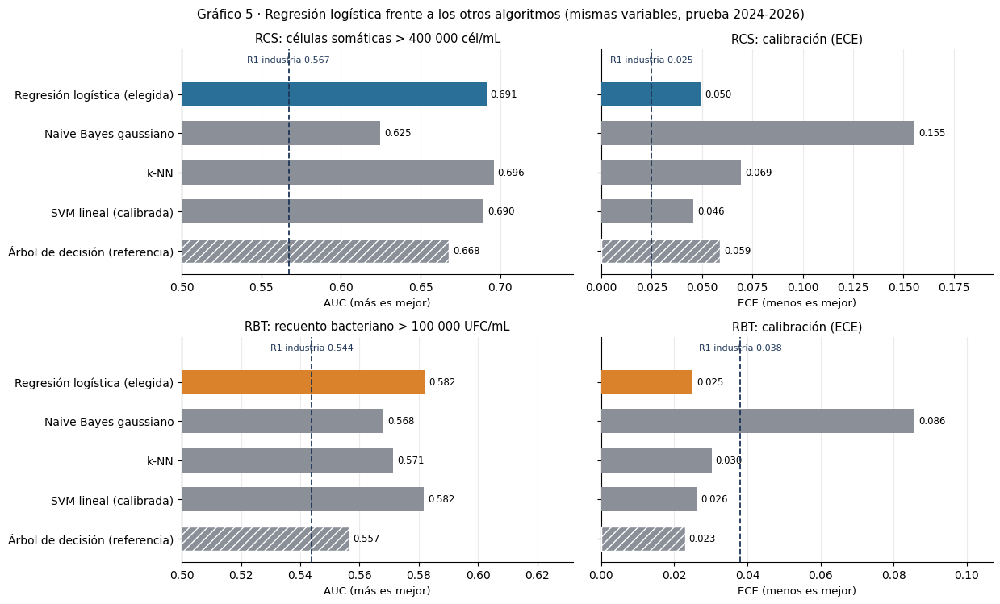

In [127]:
fig, ax = plt.subplots(2, 2, figsize=(12.5, 7.6))
nombres_alg = list(ALG.values())
for i, t in enumerate(L.OBJETIVOS):
    s = CMP[CMP["objetivo"] == t].set_index("algoritmo")
    r1 = s.loc["R1 industria (referencia)"]
    for j, (col, lab) in enumerate([("AUC", "AUC (más es mejor)"), ("ECE", "ECE (menos es mejor)")]):
        a = ax[i, j]
        v = s.loc[nombres_alg, col]
        ypos = np.arange(len(nombres_alg))
        colores = [COLOR[t] if n.startswith("Regresión") else GRIS for n in nombres_alg]
        barras = a.barh(ypos, v.to_numpy(), color=colores, height=0.62, zorder=3)
        for b_, n in zip(barras, nombres_alg):
            if n.startswith("Árbol"):
                b_.set_hatch("///"); b_.set_edgecolor("white")
        a.axvline(r1[col], color=OSCURO, ls="--", lw=1.3, zorder=4)
        lo_x, hi_x = (0.5, max(v.max(), r1[col]) + 0.05) if col == "AUC" else (0, max(v.max(), r1[col]) * 1.25)
        a.set_xlim(lo_x, hi_x)
        for yy, val_ in zip(ypos, v.to_numpy()):
            a.text(val_ + (hi_x - lo_x) * 0.01, yy, f"{val_:.3f}", va="center", fontsize=8.5)
        a.text(r1[col], -0.78, f"R1 industria {r1[col]:.3f}", ha="center", va="bottom", fontsize=8, color=OSCURO)
        a.set_yticks(ypos); a.set_yticklabels(nombres_alg if j == 0 else [""] * len(ypos)); a.invert_yaxis()
        a.set_ylim(len(nombres_alg) - 0.4, -1.15)
        a.set_xlabel(lab); a.set_title(f"{t}: {NOMBRE[t]}" if j == 0 else f"{t}: calibración (ECE)")
        a.grid(axis="y", visible=False)
fig.suptitle("Gráfico 5 · Regresión logística frente a los otros algoritmos (mismas variables, prueba 2024-2026)", fontsize=11)
fig.tight_layout()
guardar(fig, "05_comparacion_algoritmos.png")

In [128]:
def fmt(x, n=3):
    return f"{x:.{n}f}".replace(".", ",")

PARES = lambda s: s.drop(index="R1 industria (referencia)")
lineas = ["**Veredicto de la comparación (prueba 2024-2026; las diferencias de AUC menores a 0,005 se tratan como empate: es un criterio de este cuaderno, no un test).**", ""]
for t in L.OBJETIVOS:
    s = PARES(CMP[CMP["objetivo"] == t].set_index("algoritmo"))
    lg = s.loc["Regresión logística (elegida)"]
    mejor_auc, mejor_ll, mejor_ece = s["AUC"].idxmax(), s["log-loss"].idxmin(), s["ECE"].idxmin()
    emp = [n for n in s.index if n != "Regresión logística (elegida)" and abs(s.loc[n, "AUC"] - lg["AUC"]) < 0.005]
    ref_ar = s.loc["Árbol de decisión (referencia)"]
    lineas.append(f"**{t}.** AUC más alto: **{mejor_auc}** ({fmt(s.loc[mejor_auc, 'AUC'])}); la logística tiene {fmt(lg['AUC'])} ({'gana' if mejor_auc.startswith('Regresión') else 'diferencia de ' + fmt(s.loc[mejor_auc, 'AUC'] - lg['AUC'])}). "
                  f"Empatan con ella (menos de 0,005): {', '.join(emp) if emp else 'ninguno'}. Menor log-loss: **{mejor_ll}** ({fmt(s.loc[mejor_ll, 'log-loss'], 4)} contra {fmt(lg['log-loss'], 4)} de la logística). "
                  f"Mejor calibración (ECE): **{mejor_ece}** ({fmt(s.loc[mejor_ece, 'ECE'])} contra {fmt(lg['ECE'])}).")
    lineas.append(f"* Una industria afuera (sin industria en el modelo): AUC ponderado " + ", ".join(f"{n.split(' (')[0]} {fmt(s.loc[n, 'AUC industria afuera'])}" for n in s.index) +
                  f"; sesgo medio absoluto " + ", ".join(f"{n.split(' (')[0]} {fmt(s.loc[n, '|sesgo| industria afuera'])}" for n in s.index) + ".")
    lineas.append(f"* Tiempo de ajuste: " + ", ".join(f"{n.split(' (')[0]} {s.loc[n, 'tiempo de ajuste (s)']:.1f} s".replace('.', ',') for n in s.index) + f"; predecir la prueba con el k-NN (k = {HP_CMP[(t, 'knn')]}) tardó {s.loc['k-NN', 'tiempo de predicción (s)']:.0f} s. El árbol de referencia (profundidad {HP_CMP[(t, 'arbol')]}): AUC {fmt(ref_ar['AUC'])}, ECE {fmt(ref_ar['ECE'])}.")
    lineas.append("")
display(Markdown("\n".join(lineas)))

**Veredicto de la comparación (prueba 2024-2026; las diferencias de AUC menores a 0,005 se tratan como empate: es un criterio de este cuaderno, no un test).**

**RCS.** AUC más alto: **k-NN** (0,696); la logística tiene 0,691 (diferencia de 0,004). Empatan con ella (menos de 0,005): k-NN, SVM lineal (calibrada). Menor log-loss: **Regresión logística (elegida)** (0,6402 contra 0,6402 de la logística). Mejor calibración (ECE): **SVM lineal (calibrada)** (0,046 contra 0,050).
* Una industria afuera (sin industria en el modelo): AUC ponderado Regresión logística 0,645, Naive Bayes gaussiano 0,646, k-NN 0,649, SVM lineal 0,645, Árbol de decisión 0,641; sesgo medio absoluto Regresión logística 0,063, Naive Bayes gaussiano 0,063, k-NN 0,062, SVM lineal 0,063, Árbol de decisión 0,062.
* Tiempo de ajuste: Regresión logística 0,2 s, Naive Bayes gaussiano 0,1 s, k-NN 0,1 s, SVM lineal 0,4 s, Árbol de decisión 0,1 s; predecir la prueba con el k-NN (k = 3000) tardó 40 s. El árbol de referencia (profundidad 3): AUC 0,668, ECE 0,059.

**RBT.** AUC más alto: **Regresión logística (elegida)** (0,582); la logística tiene 0,582 (gana). Empatan con ella (menos de 0,005): SVM lineal (calibrada). Menor log-loss: **SVM lineal (calibrada)** (0,5092 contra 0,5101 de la logística). Mejor calibración (ECE): **Árbol de decisión (referencia)** (0,023 contra 0,025).
* Una industria afuera (sin industria en el modelo): AUC ponderado Regresión logística 0,553, Naive Bayes gaussiano 0,552, k-NN 0,558, SVM lineal 0,553, Árbol de decisión 0,548; sesgo medio absoluto Regresión logística 0,042, Naive Bayes gaussiano 0,042, k-NN 0,041, SVM lineal 0,042, Árbol de decisión 0,042.
* Tiempo de ajuste: Regresión logística 0,2 s, Naive Bayes gaussiano 0,1 s, k-NN 0,1 s, SVM lineal 0,6 s, Árbol de decisión 0,1 s; predecir la prueba con el k-NN (k = 3000) tardó 41 s. El árbol de referencia (profundidad 2): AUC 0,557, ECE 0,023.


**Por qué la regresión logística, a la vista de los números de arriba.** (Lo que sigue se lee junto con la tabla y el veredicto generado; si se vuelve a ejecutar con otros datos, hay que revisar estas frases.)
* **No gana en todo, y no hace falta.** En RCS el k-NN le saca 0,004 de AUC, pero queda peor en log-loss (0,6421 contra 0,6402) y en ECE (0,069 contra 0,050); en RBT la logística tiene el AUC más alto, y el SVM lineal la supera por 0,0009 de log-loss. Entre la logística, el SVM lineal y el k-NN
  las diferencias de AUC son de 0,011 o menos en los dos objetivos (el SVM lineal empata con la logística en los dos; el k-NN, solo en RCS: en RBT queda 0,011 por debajo), mucho menos que lo que separa a cualquiera de ellos de la referencia por industria R1 (0,12 en RCS y 0,04 en RBT). Con solo estas variables (estación, anomalía e industria) el techo de discriminación es bajo para todos:
  la información que hay es poca, no el algoritmo. Un modelo más flexible (k-NN, árbol) no encuentra estructura nueva que la logística no vea. El SVM lineal es, en la práctica, el mismo modelo (frontera lineal) con otra pérdida.
* **Calibración.** El entregable es una probabilidad. Naive Bayes es el único claramente peor: su log-loss (0,80 en RCS y 0,74 en RBT) es peor que el de predecir la tasa global, y su ECE es 3 a 4 veces mayor, porque supone variables independientes y gaussianas
  (la estación `sen`/`cos` y la industria en one-hot no lo son) y sus probabilidades salen demasiado extremas. El k-NN tiene el ECE peor que la logística en los dos objetivos; el SVM lineal necesita la corrección de Platt encima para dar una probabilidad y queda a la par
  (algo mejor en RCS, algo peor en RBT); el árbol de referencia tiene el menor ECE en RBT, pero con profundidad 2 es un modelo muy simple y su AUC es de los más bajos (0,668 en RCS y 0,557 en RBT).
* **Interpretabilidad.** La pregunta del trabajo es si el calor sube el riesgo. Solo la regresión logística da un **odds ratio por °C de anomalía con intervalo** (sección 8), con la estación y la industria descontadas. Con k-NN, Naive Bayes o un árbol habría que armar gráficos de dependencia parcial y
  no se tendría un intervalo; los coeficientes del SVM lineal están en la escala del margen y no son odds. Por esto la logística responde la pregunta del trabajo y los demás no, aunque el k-NN discrimine un poco más en RCS.
* **Estabilidad dejando una industria afuera.** Sin el nivel propio de la industria el rendimiento de todos baja a AUC 0,64-0,65 (RCS) y 0,55-0,56 (RBT), y las diferencias entre algoritmos se mantienen chicas (k-NN apenas arriba: 0,649 y 0,558; Naive Bayes queda a la par de la logística, probablemente porque sin la industria en one-hot su supuesto de independencia pesa menos). El sesgo medio absoluto es casi el mismo para todos (0,062-0,063 en RCS y 0,041-0,042 en RBT): ningún algoritmo, por flexible que sea, aprende el nivel de una industria que no vio (sección 10).
* **Costo.** La logística se ajusta en una fracción de segundo con todas las filas. El k-NN hay que submuestrearlo (50 000 filas) porque la predicción compara cada fila contra el entrenamiento: tarda unos 40 s en predecir la prueba (el tiempo exacto cambia de una corrida a otra), contra décimas de segundo de la logística. Además, en los dos objetivos el `k` elegido (3000) es el
  extremo de la grilla: un `k` mayor podría mejorar un poco más (hacia un modelo casi constante), lo que dice que ahí el k-NN no encuentra estructura local.
* **Qué quedó afuera.** SVM con núcleo (RBF) y k-NN con todo el entrenamiento: con 300 000 filas son caros, y el SVM lineal y el k-NN submuestreado ya muestran que los modelos más flexibles no separan mejor. El árbol de decisión lo trabaja otro integrante del grupo: acá es solo un punto de comparación.

### 14 · Datos usados en cada entrenamiento
Cuántas filas de la leche cruda entran en cada modelo de este cuaderno, cuáles se sacan y por qué, y cómo se reparten entre entrenamiento, validación y prueba. La validación sale del propio pasado:
C y la ventana de temperatura se eligen con la validación móvil 2021-2023 (cada año se valida con un modelo ajustado con los años anteriores) y los hiperparámetros de la sección 13, entrenando hasta 2022 y validando en 2023;
el modelo final se reajusta siempre con todo hasta 2023. Por eso «entrenamiento» cuenta las filas anteriores al período de validación y «validación» las de ese período (las dos juntas ajustan el modelo final). La prueba es 2024-2026 y no decide nada.
Las submuestras del k-NN figuran en la nota.

In [129]:
import inspect
import datos_entrenamiento as DE

mil = lambda n: f"{int(n):,}".replace(",", ".")
N_ARCHIVO = int(info["filas_archivo"])
ANTES_INICIO = N_ARCHIVO - len(d)
ANIOS_VAL = inspect.signature(L.validar_rodante).parameters["anios"].default        # 2021-2023, la validación móvil de la sección 6
INI_VAL = pd.Timestamp(ANIOS_VAL[0], 1, 1)
UBI = L.CAMBIO_UNIDAD_RBT["cliente"]


def motivo(t):
    y = L.OBJETIVOS[t]
    p = []
    if ANTES_INICIO:
        p.append(f"anteriores a {L.INICIO.year}: {mil(ANTES_INICIO)}")
    if t == "RCS":
        p.append(f"sin valor de células somáticas: {mil(d['celulas_somaticas'].isna().sum() - info['rcs_descartados_ind59'])}")
        p.append(f"RCS redondos de {UBI} desde junio de 2024 (parecen un RBT mal ubicado): {mil(info['rcs_descartados_ind59'])}")
    else:
        p.append(f"sin valor de RBT: {mil(d['rbt'].isna().sum())}")
        p.append(f"RBT de {UBI} desde mayo de 2024 (UFC/mL con tope de 100.000, no se sabe si pasó el umbral): {mil((d['rbt'].notna() & d['rbt_corr'].isna()).sum())}")
    p.append(f"sin temperatura de la ventana ({ELEG[t][0]} de {ELEG[t][1]} días): {mil(d[y].notna().sum() - len(DATOS[t]))}")
    return "; ".join(p)


def reparto(x, ini_val):
    f = x["fecha"]
    return int((f < ini_val).sum()), int(((f >= ini_val) & (f < L.CORTE_PRUEBA)).sum()), int((f >= L.CORTE_PRUEBA).sum())


filas = []
PART_M = "temporal: hasta 2023 / prueba 2024-26; C y ventana con validación móvil 2021-23"
PART_A = "temporal: hasta 2022 / validación 2023 / prueba 2024-26"
for t in L.OBJETIVOS:
    x, y = DATOS[t], L.OBJETIVOS[t]
    m = motivo(t)
    n_sacadas = ANTES_INICIO + int(d[y].isna().sum()) + int(d[y].notna().sum() - len(x))
    assert N_ARCHIVO - n_sacadas == len(x), (N_ARCHIVO, n_sacadas, len(x))
    n_pre, n_val, n_pru = reparto(x, INI_VAL)
    n_h23 = n_pre + n_val
    filas.append(DE.fila("IV", f"logística M3 (estación + anomalía + industria), {t}", f"muestras de leche cruda con {t} y temperatura", N_ARCHIVO, len(x), m,
                         entrenamiento=n_pre, validacion=n_val, prueba=n_pru, particion=PART_M, nota=f"C = {C_ELEG[t]:g}; el modelo final se reajusta con todo hasta 2023 ({mil(n_h23)} filas)"))
    xs = SUB[t]
    s_pre, s_val, s_pru = reparto(xs, INI_VAL)
    filas.append(DE.fila("IV", f"logística C2 (M3 + lactosa, grasa y proteína), {t}", "muestras con la composición completa", N_ARCHIVO, len(xs), m + f"; sin lactosa, grasa o proteína: {mil(len(x) - len(xs))}",
                         entrenamiento=s_pre + s_val, prueba=s_pru, particion="temporal: hasta 2023 / prueba 2024-26", nota=f"mismo C que M3 ({C_ELEG[t]:g}); sin validación propia"))
    filas.append(DE.fila("IV", f"logística de interpretación (OR por +1 °C con mes e industria), {t}", f"muestras de leche cruda con {t} y temperatura", N_ARCHIVO, len(x), m,
                         particion="sin partición: todos los datos 2019-2026, intervalos por bootstrap de semanas", nota=f"celdas industria × día: {mil(OR[t]['celdas'])}; 300 remuestreos"))
    g = LOIO[t]
    filas.append(DE.fila("IV", f"industria afuera: logística S2 (estación + anomalía) y S3 (+ composición), {t}", f"muestras de leche cruda con {t} y temperatura", N_ARCHIVO, len(x), m,
                         entrenamiento=len(x) - int(round(g["filas"].mean())), prueba=int(round(g["filas"].mean())), particion=f"una industria afuera por vez ({len(g)} industrias)",
                         nota="entrenamiento y prueba son el promedio por industria dejada afuera; sin término de industria; S3 usa solo las filas con composición"))
    e22, v23, p24 = reparto(x, L.CORTE_VALID)
    HP = {c: HP_CMP[(t, c)] for c in ALG}
    NOTA = {
        "nb": "sin hiperparámetros; sin submuestra",
        "knn": f"SUBMUESTRA: entrena con {mil(min(N_KNN, e22))} filas al azar de las {mil(e22)} hasta 2022 al elegir k y con {mil(min(N_KNN, e22 + v23))} al azar de las {mil(e22 + v23)} hasta 2023 en el ajuste final; "
               f"elige k con {mil(min(N_VAL_KNN, v23))} filas al azar de 2023; k = {HP['knn']}",
        "svm": f"C = {HP['svm']:g} elegido por validación; Platt con 3 pliegues al azar dentro del entrenamiento; sin submuestra",
        "arbol": f"profundidad {HP['arbol']} elegida por validación; hojas de al menos 200 filas; sin submuestra"}
    for c in ("nb", "knn", "svm", "arbol"):
        filas.append(DE.fila("IV", f"sección 13: {ALG[c]}, {t}", f"muestras de leche cruda con {t} y temperatura", N_ARCHIVO, len(x), m,
                             entrenamiento=e22, validacion=v23, prueba=p24, particion=PART_A, nota=NOTA[c] + f"; el modelo final se reajusta con todo hasta 2023 ({mil(e22 + v23)} filas)"))
    dd = det[det["objetivo"] == t]
    n_ind = dd["industria"].nunique()
    f_prom = int(round(dd[dd["algoritmo"] == ALG["log"]]["filas"].mean()))
    filas.append(DE.fila("IV", f"industria afuera: los cinco algoritmos de la sección 13, {t}", f"muestras de leche cruda con {t} y temperatura", N_ARCHIVO, len(x), m,
                         entrenamiento=len(x) - f_prom, prueba=f_prom, particion=f"una industria afuera por vez ({n_ind} industrias)",
                         nota=f"entrenamiento y prueba son el promedio por industria dejada afuera; sin término de industria; el k-NN entrena con {mil(N_KNN)} filas al azar en cada pliegue (SUBMUESTRA)"))
display(DE.guardar(filas, "logistica_calidad_leche_cruda"))

,parte,modelo,datos,disponibles,excluidas,motivo de exclusión,usadas,entrenamiento,validación,prueba,partición,nota
0,IV,"logística M3 (estación + anomalía + industria), RCS",muestras de leche cruda con RCS y temperatura,628035,157986,anteriores a 2019: 33; sin valor de células somáticas: 157.947; RCS redondos de IND-59 desde junio de 2024...,470049,74776,220585,174688,temporal: hasta 2023 / prueba 2024-26; C y ventana con validación móvil 2021-23,C = 0.001; el modelo final se reajusta con todo hasta 2023 (295.361 filas)
1,IV,"logística C2 (M3 + lactosa, grasa y proteína), RCS",muestras con la composición completa,628035,238610,anteriores a 2019: 33; sin valor de células somáticas: 157.947; RCS redondos de IND-59 desde junio de 2024...,389425,240839,<NA>,148586,temporal: hasta 2023 / prueba 2024-26,mismo C que M3 (0.001); sin validación propia
2,IV,"logística de interpretación (OR por +1 °C con mes e industria), RCS",muestras de leche cruda con RCS y temperatura,628035,157986,anteriores a 2019: 33; sin valor de células somáticas: 157.947; RCS redondos de IND-59 desde junio de 2024...,470049,470049,<NA>,<NA>,"sin partición: todos los datos 2019-2026, intervalos por bootstrap de semanas",celdas industria × día: 7.305; 300 remuestreos
3,IV,"industria afuera: logística S2 (estación + anomalía) y S3 (+ composición), RCS",muestras de leche cruda con RCS y temperatura,628035,157986,anteriores a 2019: 33; sin valor de células somáticas: 157.947; RCS redondos de IND-59 desde junio de 2024...,470049,423044,<NA>,47005,una industria afuera por vez (10 industrias),entrenamiento y prueba son el promedio por industria dejada afuera; sin término de industria; S3 usa solo ...
4,IV,"sección 13: Naive Bayes gaussiano, RCS",muestras de leche cruda con RCS y temperatura,628035,157986,anteriores a 2019: 33; sin valor de células somáticas: 157.947; RCS redondos de IND-59 desde junio de 2024...,470049,212889,82472,174688,temporal: hasta 2022 / validación 2023 / prueba 2024-26,sin hiperparámetros; sin submuestra; el modelo final se reajusta con todo hasta 2023 (295.361 filas)
5,IV,"sección 13: k-NN, RCS",muestras de leche cruda con RCS y temperatura,628035,157986,anteriores a 2019: 33; sin valor de células somáticas: 157.947; RCS redondos de IND-59 desde junio de 2024...,470049,212889,82472,174688,temporal: hasta 2022 / validación 2023 / prueba 2024-26,SUBMUESTRA: entrena con 50.000 filas al azar de las 212.889 hasta 2022 al elegir k y con 50.000 al azar de...
6,IV,"sección 13: SVM lineal (calibrada), RCS",muestras de leche cruda con RCS y temperatura,628035,157986,anteriores a 2019: 33; sin valor de células somáticas: 157.947; RCS redondos de IND-59 desde junio de 2024...,470049,212889,82472,174688,temporal: hasta 2022 / validación 2023 / prueba 2024-26,C = 0.1 elegido por validación; Platt con 3 pliegues al azar dentro del entrenamiento; sin submuestra; el ...
7,IV,"sección 13: Árbol de decisión (referencia), RCS",muestras de leche cruda con RCS y temperatura,628035,157986,anteriores a 2019: 33; sin valor de células somáticas: 157.947; RCS redondos de IND-59 desde junio de 2024...,470049,212889,82472,174688,temporal: hasta 2022 / validación 2023 / prueba 2024-26,profundidad 3 elegida por validación; hojas de al menos 200 filas; sin submuestra; el modelo final se reaj...
8,IV,"industria afuera: los cinco algoritmos de la sección 13, RCS",muestras de leche cruda con RCS y temperatura,628035,157986,anteriores a 2019: 33; sin valor de células somáticas: 157.947; RCS redondos de IND-59 desde junio de 2024...,470049,423044,<NA>,47005,una industria afuera por vez (10 industrias),entrenamiento y prueba son el promedio por industria dejada afuera; sin término de industria; el k-NN entr...
9,IV,"logística M3 (estación + anomalía + industria), RBT",muestras de leche cruda con RBT y temperatura,628035,112283,anteriores a 2019: 33; sin valor de RBT: 91.035; RBT de IND-59 desde mayo de 2024 (UFC/mL con tope de 100....,515752,107247,233257,175248,temporal: hasta 2

In [130]:
print(f"Notebook completo en {time.time() - T0:.0f} s. Archivos en {SALIDA}:")
for p in sorted(SALIDA.iterdir()):
    print(" ", p.name)

Notebook completo en 591 s. Archivos en E:\Downloads\UNRaf\4to cuatrimestre\IA\trabajo_senasa_mq\resultados\logistica_calidad_leche:
  01_tasa_positivos_mes_temperatura.png
  02_roc_calibracion.png
  03_odds_ratio.png
  04_probabilidad_vs_lactosa.png
  05_comparacion_algoritmos.png
  comparacion_algoritmos.csv
  comparacion_algoritmos_industria_afuera.csv
  compromiso_umbrales.csv
  industria_afuera_rbt.csv
  industria_afuera_rcs.csv
  matriz_confusion_umbral_youden.csv
  metricas_prueba_con_composicion.csv
  metricas_prueba_modelos_anidados.csv
  odds_ratio_composicion_rbt.csv
  odds_ratio_composicion_rcs.csv
  odds_ratio_rbt.csv
  odds_ratio_rcs.csv
  or_calor_robustez.csv
  or_temperatura_segun_control.csv
  regularizacion_y_balanceo.csv
  seleccion_ventana_temperatura.csv
  sensibilidad_umbral.csv
  tasa_positivos_industria_anio_rbt.csv
  tasa_positivos_industria_anio_rcs.csv


<a id="parte-v"></a>

# Parte V · ¿Se puede predecir el tipo de una muestra por lo que se le midió?

Senasa y MQ nuevas: con los resultados numéricos y los análisis pedidos, HistGradientBoosting en dos niveles (familia y subtipo), validación cruzada agrupada por envío, umbral de probabilidad, muestras de calibración y propuesta para las «sin clasificar».

*(Generada a partir de `prediccion_tipo.ipynb`.)*

## ¿Se puede predecir el tipo de una muestra por lo que se le midió?

**Datos.** Senasa (clasificación manual) + MQ nuevas (clasificación automática por texto o reglas).

**Fuera del entrenamiento** (se usan para evaluar):
- muestras de **calibración**: «control de laboratorio» o descripción con calibración, patrón, referencia,
  repetibilidad / reproducibilidad (la descripción se lee en memoria, no se muestra);
- «ensayo» y «pool»;
- las que **declaran algo que no coincide** con la humedad medida (`declarado_vs_medido`; «borde» sí entra);
- humedad + sólidos fuera de 100 ± 1 y las «sin clasificar».

**Variables.** Resultados numéricos (NaN si no se midieron) y qué análisis se pidieron.
**Modelo.** HistGradientBoosting en dos niveles: familia; después subtipo dentro de cada familia (en queso, la
consistencia del CAA). **Validación** cruzada en 5 pliegues agrupada por envío. Con probabilidad < 0,80 la muestra
queda «sin decidir».

In [131]:
import sys
from pathlib import Path
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "rutas.py").exists()) / "src"
sys.path.insert(0, str(SRC))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import prediccion_tipo as PT

r = PT.armar(escribir=True)
t = r["datos"]
r["resumen"]

,concepto,valor
0,muestras totales,30089
1,entrenamiento,27241
2,calibración (fuera del entrenamiento),449
3,calibración por origen,"{'MQ nueva (automática)': 251, 'Senasa (manual)': 198}"
4,declarado no coincide (fuera del entrenamiento),209
5,sin clasificar con análisis,1298
6,exactitud de familia en calibración (con familia conocida),0.651
7,"ídem, solo con prob ≥ 0.8",0.923
8,no coinciden: el subtipo predicho sigue a la humedad medida (quesos),0.87


### Métricas fuera de pliegue
Exactitud, F1 macro y, con el umbral, cuántas muestras se deciden y con qué exactitud.

In [132]:
r["metricas"]

,nivel,origen,muestras,exactitud,F1 macro,% con prob ≥ 0.8,exactitud con prob ≥ 0.8
0,familia,todas,27241,0.792,0.621,64.829,0.949
1,familia,MQ nueva (automática),11678,0.801,0.549,61.475,0.934
2,familia,Senasa (manual),15563,0.785,0.637,67.346,0.959
3,subtipo · queso,todas,5382,0.830,0.819,79.283,0.905
4,subtipo · queso,MQ nueva (automática),2033,0.813,0.780,80.521,0.880
5,subtipo · queso,Senasa (manual),3349,0.840,0.839,78.531,0.920
6,subtipo · leche en polvo,todas,4832,0.976,0.964,98.262,0.985
7,subtipo · leche en polvo,MQ nueva (automática),3803,0.977,0.953,98.396,0.984
8,subtipo · leche en polvo,Senasa (manual),1029,0.972,0.972,97.765,0.989
9,subtipo · dulce de leche,todas,3102,0.810,0.809,80.916,0.889


### ¿Las probabilidades son creíbles?
Exactitud observada por rango de probabilidad (familia).

In [133]:
PT.fiabilidad(r["oof_familia"])

,rango_prob,muestras,prob_media,exactitud
0,"[0.0, 0.5)",4092,0.445546,0.358504
1,"[0.5, 0.6)",2374,0.541152,0.581719
2,"[0.6, 0.7)",1412,0.649713,0.587819
3,"[0.7, 0.8)",1703,0.754353,0.660599
4,"[0.8, 0.9)",2365,0.853345,0.798732
5,"[0.9, 0.95)",2043,0.926825,0.869799
6,"[0.95, 1.0)",13252,0.987385,0.988077


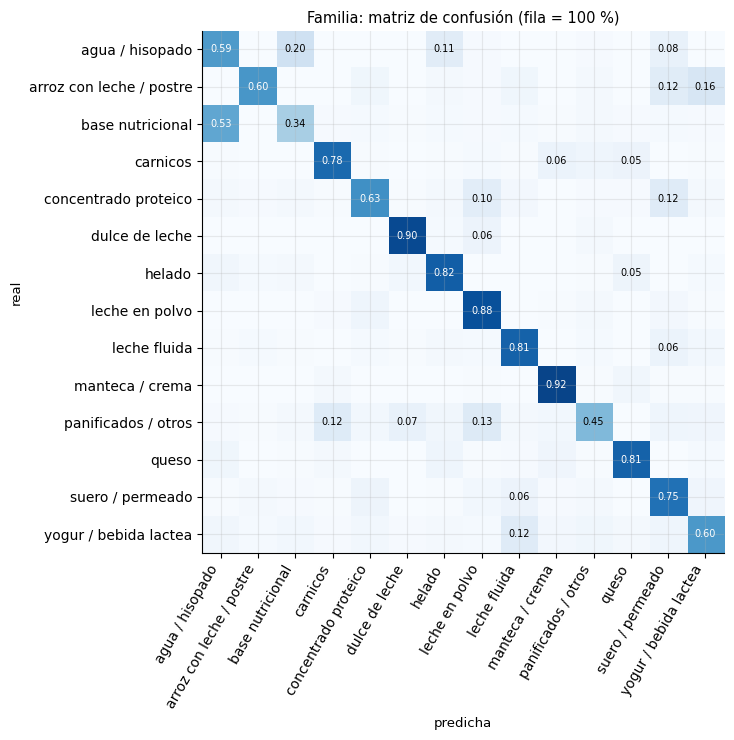

In [134]:
cm = r["confusion"]["familia"]
cmn = cm.div(cm.sum(1), axis=0)
fig, ax = plt.subplots(figsize=(9, 7.5))
ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(cm)), cm.columns, rotation=60, ha="right"); ax.set_yticks(range(len(cm)), cm.index)
for i in range(len(cm)):
    for j in range(len(cm)):
        if cmn.iat[i, j] >= .05:
            ax.text(j, i, f"{cmn.iat[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w" if cmn.iat[i, j] > .5 else "k")
ax.set(xlabel="predicha", ylabel="real", title="Familia: matriz de confusión (fila = 100 %)")
plt.tight_layout(); plt.show()

### Muestras de calibración
No entrenaron. Acierto de familia por origen y familia declarada.

In [135]:
cal = r["calibracion"]
cal[cal["desc_familia"].ne(PT.SIN)].groupby(["origen", "desc_familia"]).agg(
    muestras=("acierta_familia", "size"), acierto=("acierta_familia", "mean"), prob_media=("prob_familia", "mean")).round(2)

muestras   acierto  prob_media
origen                desc_familia                                        
MQ nueva (automática) base nutricional            30  0.033333        0.60
                      concentrado proteico         1       0.0        0.54
                      leche en polvo              39   0.74359        0.76
                      leche fluida                30  0.366667        0.58
                      manteca / crema             24  0.541667        0.59
                      queso                       45  0.911111        0.91
                      suero / permeado            15  0.066667        0.57
Senasa (manual)       carnicos                     3       1.0        0.75
                      concentrado proteico         1       0.0        0.63
                      dulce de leche              50      0.64        0.62
                      leche en polvo               1       1.0        0.86
                      leche fluida                86  0.953488        0.67
                      queso                        3       1.0        0.84
                      suero / permeado             7  0.142857        0.50

### Declarado que no coincide con lo medido
En quesos: consistencia declarada, la que corresponde a la humedad medida y la que predice el modelo.

In [136]:
nc = r["no_coinciden"]
q = nc[nc["desc_familia"].eq("queso")]
pd.crosstab([q["subtipo"].rename("declarada"), q["clase_por_humedad"].rename("por humedad")], q["subtipo_pred"].rename("predicha"))

predicha                          alta humedad  baja humedad  bebida láctea  mediana humedad  procesado
declarada       por humedad                                                                            
alta humedad    mediana humedad              0             0              0               70          6
baja humedad    mediana humedad              0             1              1               41          0
mediana humedad alta humedad                19             0              0                0          1
                baja humedad                 0             5              0                0          0
                muy alta humedad            19             0              0                0         11

### «Sin clasificar»: lo que propone el modelo
Solo propuestas; no se cambia ninguna familia.

In [137]:
sc = r["sin_clasificar"]
print(sc["decision"].value_counts().to_string())
sc[sc["decision"].eq("propuesta")]["familia_pred"].value_counts()

decision
sin decidir    818
propuesta      480


familia_pred
carnicos                    182
suero / permeado             72
leche en polvo               61
panificados / otros          39
agua / hisopado              29
queso                        28
manteca / crema              15
yogur / bebida lactea        14
base nutricional             12
dulce de leche               10
leche fluida                  8
concentrado proteico          4
helado                        3
arroz con leche / postre      3
Name: count, dtype: int64

### Datos usados en cada entrenamiento
Cuántas muestras entran en cada modelo de este cuaderno (familia y un modelo de subtipo por familia), cuáles se sacan y por qué,
y cómo se reparte lo que queda. No hay conjunto de validación propio: los hiperparámetros son fijos. La evaluación es la validación
cruzada agrupada por envío; «entrenamiento» y «prueba» son el tamaño medio de cada pliegue. Las muestras de calibración, las que
declaran algo que no coincide y las «sin clasificar» no entrenan: se predicen con el modelo final.

In [138]:
import inspect
import datos_entrenamiento as DE
from datos_clase41 import TOL_HUM_SOL
from sklearn.model_selection import StratifiedGroupKFold

miles = lambda n: f"{int(n):,}".replace(",", ".")
N_PLIEGUES = inspect.signature(PT.validar).parameters["n_folds"].default
CX = PT.columnas_x(t)


def pliegues(objetivo, filtro):
    # Mismas filas y mismos pliegues que PT.validar: devuelve las filas y el tamaño medio de entrenamiento y de prueba.
    base = t[t["entrena"] & filtro & t[objetivo].notna()]
    base = base[base[objetivo].isin(PT._clases_validas(base[objetivo]))]
    cv = StratifiedGroupKFold(n_splits=N_PLIEGUES, shuffle=True, random_state=PT.SEMILLA)
    tam = [(len(a), len(b)) for a, b in cv.split(base[CX], base[objetivo].astype(str), base["Envío"].astype(str))]
    return base, round(np.mean([a for a, _ in tam])), round(np.mean([b for _, b in tam]))


PARTICION = f"validación cruzada de {N_PLIEGUES} pliegues agrupada por envío"
fuera = [("de calibración", t["calibracion"]),
         ("de ensayo, pool u otro tipo que no es producción", ~t["desc_tipo_muestra"].isin(["produccion"])),
         ("sin clasificar o sin familia", t["desc_familia"].eq(PT.SIN) | t["desc_familia"].isna()),
         (f"con humedad + sólidos fuera de 100 ± {TOL_HUM_SOL:g}", t["excluida_hum_sol"]),
         ("con lo declarado distinto de lo medido", t["declarado_no_coincide"]),
         ("sin ningún análisis", t["n_analisis"].eq(0))]
quedan, partes = pd.Series(True, index=t.index), []
for nombre, cond in fuera:
    partes.append(f"{nombre}: {miles((quedan & cond).sum())}")
    quedan &= ~cond
assert quedan.equals(t["entrena"])

base_f, tr_f, te_f = pliegues("desc_familia", pd.Series(True, index=t.index))
assert set(base_f.index) == set(r["oof_familia"].index)
partes.append(f"familias con menos de {PT.MIN_CLASE} muestras: {miles(quedan.sum() - len(base_f))}")
filas = [DE.fila(
    parte="V", modelo="familia: HistGradientBoosting", datos="muestras de Senasa y MQ nuevas",
    disponibles=len(t), usadas=len(base_f), motivo="; ".join(partes), entrenamiento=tr_f, prueba=te_f, particion=PARTICION,
    nota=(f"entrenamiento y prueba son el promedio por pliegue; el modelo final se reajusta con las {miles(len(base_f))} filas; "
          f"con probabilidad menor que {str(PT.UMBRAL_PROB).replace(".", ",")} la muestra queda sin decidir; sin entrenar se predicen "
          f"{miles(len(r['calibracion']))} de calibración, {miles(len(r['no_coinciden']))} con declarado que no coincide y "
          f"{miles(len(r['sin_clasificar']))} sin clasificar con análisis"))]

for fam, oof in r["oof_subtipo"].items():
    de_fam = t["desc_familia"].eq(fam)
    disp = (t["entrena"] & de_fam).sum()
    base_s, tr_s, te_s = pliegues("subtipo", de_fam)
    assert set(base_s.index) == set(oof.index)
    sin_sub = (t["entrena"] & de_fam & t["subtipo"].isna()).sum()
    filas.append(DE.fila(
        parte="V", modelo=f"subtipo · {fam}: HistGradientBoosting", datos=f"muestras de entrenamiento de {fam}",
        disponibles=disp, usadas=len(base_s),
        motivo=(f"sin subtipo declarado o fuera de las clases del mapa: {miles(sin_sub)}; "
                f"subtipos con menos de {PT.MIN_CLASE} muestras: {miles(disp - sin_sub - len(base_s))}"),
        entrenamiento=tr_s, prueba=te_s, particion=PARTICION,
        nota=f"entrenamiento y prueba son el promedio por pliegue; el modelo final se reajusta con las {miles(len(base_s))} filas"))

display(DE.guardar(filas, "prediccion_tipo"))

,parte,modelo,datos,disponibles,excluidas,motivo de exclusión,usadas,entrenamiento,validación,prueba,partición,nota
0,V,familia: HistGradientBoosting,muestras de Senasa y MQ nuevas,30089,2848,"de calibración: 449; de ensayo, pool u otro tipo que no es producción: 859; sin clasificar o sin familia: ...",27241,21793,<NA>,5448,validación cruzada de 5 pliegues agrupada por envío,entrenamiento y prueba son el promedio por pliegue; el modelo final se reajusta con las 27.241 filas; con ...
1,V,subtipo · queso: HistGradientBoosting,muestras de entrenamiento de queso,6659,1277,sin subtipo declarado o fuera de las clases del mapa: 1.277; subtipos con menos de 20 muestras: 0,5382,4306,<NA>,1076,validación cruzada de 5 pliegues agrupada por envío,entrenamiento y prueba son el promedio por pliegue; el modelo final se reajusta con las 5.382 filas
2,V,subtipo · leche en polvo: HistGradientBoosting,muestras de entrenamiento de leche en polvo,5351,519,sin subtipo declarado o fuera de las clases del mapa: 519; subtipos con menos de 20 muestras: 0,4832,3866,<NA>,966,validación cruzada de 5 pliegues agrupada por envío,entrenamiento y prueba son el promedio por pliegue; el modelo final se reajusta con las 4.832 filas
3,V,subtipo · dulce de leche: HistGradientBoosting,muestras de entrenamiento de dulce de leche,4216,1114,sin subtipo declarado o fuera de las clases del mapa: 1.114; subtipos con menos de 20 muestras: 0,3102,2482,<NA>,620,validación cruzada de 5 pliegues agrupada por envío,entrenamiento y prueba son el promedio por pliegue; el modelo final se reajusta con las 3.102 filas
4,V,subtipo · suero / permeado: HistGradientBoosting,muestras de entrenamiento de suero / permeado,2171,132,sin subtipo declarado o fuera de las clases del mapa: 132; subtipos con menos de 20 muestras: 0,2039,1631,<NA>,408,validación cruzada de 5 pliegues agrupada por envío,entrenamiento y prueba son el promedio por pliegue; el modelo final se reajusta con las 2.039 filas
5,V,subtipo · leche fluida: HistGradientBoosting,muestras de entrenamiento de leche fluida,2788,839,sin subtipo declarado o fuera de las clases del mapa: 826; subtipos con menos de 20 muestras: 13,1949,1559,<NA>,390,validación cruzada de 5 pliegues agrupada por envío,entrenamiento y prueba son el promedio por pliegue; el modelo final se reajusta con las 1.949 filas
6,V,subtipo · concentrado proteico: HistGradientBoosting,muestras de entrenamiento de concentrado proteico,1016,64,sin subtipo declarado o fuera de las clases del mapa: 59; subtipos con menos de 20 muestras: 5,952,762,<NA>,190,validación cruzada de 5 pliegues agrupada por envío,entrenamiento y prueba son el promedio por pliegue; el modelo final se reajusta con las 952 filas
7,V,subtipo · manteca / crema: HistGradientBoosting,muestras de entrenamiento de manteca / crema,1305,0,sin subtipo declarado o fuera de las clases del mapa: 0; subtipos con menos de 20 muestras: 0,1305,1044,<NA>,261,validación cruzada de 5 pliegues agrupada por envío,entrenamiento y prueba son el promedio por pliegue; el modelo final se reajusta con las 1.305 filas
8,V,subtipo · yogur / bebida lactea: HistGradientBoosting,muestras de entrenamiento de yogur / bebida lactea,679,16,sin subtipo declarado o fuera de las clases del mapa: 16; subtipos con menos de 20 muestras: 0,663,530,<NA>,133,validación cruzada de 5 pliegues agrupada por envío,entrenamiento y prueba son el promedio por pliegue; el modelo final se reajusta con las 663 filas


### Lectura
- Con las mediciones solas la **familia** se acierta en ~8 de 10 muestras; con probabilidad ≥ 0,80 se decide ~2/3 de
  las muestras con ~95 % de exactitud. Las probabilidades entre 0,8 y 0,95 son algo optimistas; desde 0,95 son fiables.
- Se confunden familias con composición parecida y pocos análisis: base nutricional con agua / hisopado (se les pide
  poco), concentrado proteico con leche en polvo y suero, queso con helado / manteca.
- Los **subtipos** salen muy bien en leche en polvo (entera / descremada), concentrado proteico, manteca / crema; bien en
  queso (consistencia), DDL y leche fluida; peor en suero / permeado y en yogur de Senasa.
- En los quesos cuya consistencia declarada no coincide, el modelo sigue casi siempre a la **humedad medida**: es
  evidencia de que la consistencia declarada estaba mal, no la medición.
- Las de **calibración** se aciertan peor (son matrices de referencia, a veces con un solo análisis); por eso no deben
  entrar al entrenamiento.
- Archivo: `resultados/excel/prediccion_tipo.xlsx`; modelo: `resultados/modelos/prediccion_tipo.joblib`
  (`PT.predecir(joblib.load(...), X)` con las columnas de `PT._variables`).

In [139]:
assert not (t["entrena"] & t["calibracion"]).any() and not (t["entrena"] & t["declarado_no_coincide"]).any()
assert (PT.R.EXCEL / "prediccion_tipo.xlsx").exists() and PT.SALIDA_MODELO.exists()
for k in ["calibracion", "no_coinciden", "sin_clasificar"]:
    assert "Descripción" not in r[k].columns
    assert r[k]["Cliente"].dropna().astype(str).str.match(r"^IND-\d+$").all()
print("Verificación: todo en orden.")

Verificación: todo en orden.


### La aplicación, desde el cuaderno
La celda siguiente escribe `app_prediccion.py` (dos pestañas: días de espera para deslactosar una UAT y tipo de
muestra según lo medido). La de después la abre en http://localhost:8501.

Streamlit no corre adentro de una celda: es un programa aparte, y mientras está abierto el kernel queda ocupado.
Para abrirla cambiá `ABRIR_APP = True` y ejecutá la celda; para cerrarla, interrumpí el kernel (■). También se abre
desde una terminal, en la carpeta `trabajo_senasa_mq`: `../.venv/bin/streamlit run app_prediccion.py`.

In [140]:
%%writefile app_prediccion.py
# Trabajo Senasa + MQ · aplicación Streamlit con los dos modelos predictivos
# 1) Cuántos días esperar para que una leche UAT baje de 0,1 g/100 g de lactosa (src/deslactosado_uat.py).
# 2) Tipo de muestra (familia y subtipo) a partir de lo medido (src/prediccion_tipo.py).
# Los modelos los guardan los notebooks prediccion_deslactosado.ipynb y prediccion_tipo.ipynb en resultados/modelos/.
# Para abrirla, desde la carpeta trabajo_senasa_mq:  ../.venv/bin/streamlit run app_prediccion.py
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import streamlit as st

AQUI = Path(__file__).resolve().parent
sys.path.insert(0, str(AQUI / "src"))
import deslactosado_uat as D  # noqa: E402
import prediccion_tipo as PT  # noqa: E402

st.set_page_config(page_title="Predicciones Senasa + MQ", layout="centered")
st.title("Predicciones Senasa + MQ")
st.caption("Dos modelos ajustados en los notebooks del trabajo. Cargá los parámetros y la app devuelve el resultado.")


@st.cache_resource
def cargar(ruta):
    return joblib.load(ruta)


faltan = [p for p in (D.SALIDA_MODELO, PT.SALIDA_MODELO) if not p.exists()]
if faltan:
    st.error("Faltan modelos: " + ", ".join(p.name for p in faltan) + ". Ejecutá los notebooks prediccion_*.ipynb.")
    st.stop()

tab1, tab2 = st.tabs(["Deslactosado UAT", "Tipo de muestra"])

# ------------------------------------------------------------------ 1. deslactosado
with tab1:
    m = cargar(D.SALIDA_MODELO)
    th, boot, umbral = m["theta"], m["boot"], m["umbral"]
    st.subheader("¿Cuántos días esperar?")
    st.write(f"Modelo de primer orden ajustado con {m['n_lotes']} lotes UAT remuestreados de Senasa "
             f"({m['rango_dias'][0]} a {m['rango_dias'][1]} días entre análisis). Umbral de deslactosado: "
             f"**{umbral:.1f} g/100 g**.")
    c1, c2 = st.columns(2)
    l0 = c1.number_input("Lactosa medida (g/100 g)", 0.01, 3.0, 0.60, step=0.01, format="%.2f")
    t_sem = c2.slider("Temperatura media de la semana (°C)", 5.0, 35.0, 18.0, step=0.5)

    if l0 <= umbral:
        st.success(f"Ya está en {umbral:.1f} g/100 g o menos: no hace falta esperar.")
    else:
        dias = float(D.dias_hasta(l0, t_sem, th))
        dd = D.dias_hasta(l0, t_sem, boot.T)
        inf, sup = np.percentile(dd, [2.5, 97.5])
        k1, k2 = st.columns(2)
        k1.metric("Días de espera estimados", f"{dias:.1f}")
        k2.metric("Intervalo 95 % (bootstrap)", f"{inf:.1f} a {sup:.1f}")
        st.write(f"Tasa a esa temperatura: k = {float(D.k_de(th, t_sem)):.3f} por día "
                 f"(la lactosa baja ~{100 * (1 - np.exp(-float(D.k_de(th, t_sem)))):.0f} % por día).")
        if dias > m["rango_dias"][1]:
            st.warning(f"La espera supera los {m['rango_dias'][1]} días observados entre análisis: es una extrapolación.")
        lo, hi = m["rango_t"]
        if not lo - 2 <= t_sem <= hi + 2:
            st.warning(f"Temperatura fuera del rango observado ({lo:.0f} a {hi:.0f} °C): es una extrapolación.")

    st.info("El efecto de la temperatura dentro de los remuestreos no es significativo (el IC incluye cero): "
            "tomá el resultado como orden de magnitud, no como garantía.")

    T = np.linspace(5, 35, 61)
    fig, ax = plt.subplots(figsize=(8, 4))
    for v, col in [(0.3, "#9ecae1"), (0.5, "#4292c6"), (1.0, "#08519c")]:
        ax.plot(T, D.dias_hasta(v, T, th), color=col, lw=1, label=f"L₀ = {v}")
    if l0 > umbral:
        dT = D.dias_hasta(l0, T[:, None], boot.T)
        ax.fill_between(T, *np.percentile(dT, [2.5, 97.5], axis=1), color="#c0392b", alpha=0.15)
        ax.plot(T, D.dias_hasta(l0, T, th), color="#c0392b", lw=2, label=f"esta muestra (L₀ = {l0:.2f})")
        ax.scatter([t_sem], [D.dias_hasta(l0, t_sem, th)], s=200, marker="*", color="#c0392b", zorder=5)
    ax.axvspan(*m["rango_t"], color="grey", alpha=0.08, label="temperaturas observadas")
    ax.set(xlabel="temperatura media de la semana (°C)", ylabel=f"días hasta {umbral:.1f} g/100 g",
           title="Espera predicha según la temperatura")
    ax.legend(fontsize=8)
    st.pyplot(fig)

# ------------------------------------------------------------------ 2. tipo de muestra
with tab2:
    paq = cargar(PT.SALIDA_MODELO)
    st.subheader("¿Qué tipo de muestra es?")
    st.write("Cargá los análisis que se midieron; los que no, dejalos sin marcar (el modelo también usa *qué* "
             "análisis se pidieron). Con probabilidad menor a "
             f"{paq['umbral']:.2f} el resultado queda como «sin decidir».")

    CAMPOS = [  # (variable, etiqueta, valor por defecto, medida por defecto)
        ("humedad", "Humedad (g/100 g)", 3.5, True),
        ("grasa", "Materia grasa (g/100 g)", 26.0, True),
        ("proteinas", "Proteínas (g/100 g)", 25.0, True),
        ("cenizas", "Cenizas (g/100 g)", 6.0, False),
        ("grasa_es", "Materia grasa en extracto seco (g/100 g)", 45.0, False),
        ("cloruros", "Cloruros (NaCl g/100 g)", 1.5, False),
        ("acidez_naoh", "Acidez (ml NaOH 0,1 N / 10 g SNG)", 15.0, False),
        ("acidez_lactico", "Acidez (% ácido láctico)", 0.15, False),
        ("lactosa", "Lactosa (g/100 g)", 38.0, False),
        ("galactosa", "D-galactosa (g/100 g)", 0.1, False),
        ("azucares", "Azúcares totales (g/100 g)", 50.0, False),
        ("ph", "pH", 6.6, False),
        ("aw", "Actividad de agua", 0.85, False),
        ("almidon", "Almidón total (g/100 g)", 1.0, False),
        ("sodio", "Sodio (mg/100 g)", 400.0, False),
        ("calcio", "Calcio (mg/100 g)", 900.0, False),
        ("brix", "Grado Brix (°Bx)", 70.0, False),
        ("solubilidad", "Solubilidad (%)", 99.0, False),
    ]
    valores = {}
    c1, c2 = st.columns(2)
    for i, (var, etiqueta, defecto, medido) in enumerate(CAMPOS):
        col = c1 if i % 2 == 0 else c2
        if col.checkbox(etiqueta, value=medido, key=f"chk_{var}"):
            valores[var] = col.number_input(etiqueta, value=float(defecto), key=f"val_{var}", label_visibility="collapsed")

    if not valores:
        st.warning("Marcá al menos un análisis.")
        st.stop()

    fila = {v: np.nan for v in PT.VARIABLES}
    fila.update(valores)
    n_medidos = len(valores)
    if np.isfinite(fila["humedad"]):                         # igual que en el entrenamiento
        fila["solidos"] = 100 - fila["humedad"]
    fila["n_analisis"] = n_medidos
    for v in PT.VARIABLES:
        fila[f"pide_{v}"] = int(np.isfinite(fila[v]))
    X = pd.DataFrame([fila])[paq["columnas"]]
    if np.isfinite(fila["humedad"]) and not 0 <= fila["humedad"] <= 100:
        st.error("La humedad tiene que estar entre 0 y 100.")
        st.stop()

    res = PT.predecir(paq, X).iloc[0]
    k1, k2 = st.columns(2)
    k1.metric("Familia", res["familia_pred"], f"prob. {res['prob_familia']:.2f}", delta_color="off")
    if pd.notna(res["subtipo_pred"]):
        k2.metric("Subtipo", res["subtipo_pred"], f"prob. {res['prob_subtipo']:.2f}", delta_color="off")
    if res["decision"] == "sin decidir":
        st.warning("Probabilidad baja: el modelo no decide. Mirá las alternativas abajo o agregá análisis.")
    else:
        st.success("Propuesta del modelo con probabilidad suficiente.")

    mf = paq["modelos"]["familia"]
    pf = pd.Series(mf.predict_proba(X)[0], index=mf.classes_).sort_values(ascending=True).tail(6)
    fig2, ax2 = plt.subplots(figsize=(8, 3.5))
    ax2.barh(pf.index, pf.values, color=["#c0392b" if i == res["familia_pred"] else "#4292c6" for i in pf.index])
    ax2.axvline(paq["umbral"], color="black", lw=0.8, ls="--", label=f"umbral {paq['umbral']:.2f}")
    ax2.set(xlim=(0, 1), xlabel="probabilidad", title="Familias más probables")
    ax2.legend(fontsize=8, loc="lower right")
    st.pyplot(fig2)

    if res["familia_pred"] in paq["modelos"]:
        ms = paq["modelos"][res["familia_pred"]]
        ps = pd.Series(ms.predict_proba(X)[0], index=ms.classes_).sort_values(ascending=False)
        st.write("Subtipos dentro de la familia: " + " · ".join(f"{k} {v:.2f}" for k, v in ps.items()))

    st.caption("Validación agrupada por envío: familia 81 % de acierto en general, 95 % cuando la probabilidad es ≥ 0,80.")
    with st.expander("Ver la fila que recibe el modelo"):
        st.dataframe(X.T.rename(columns={0: "valor"}))

Overwriting app_prediccion.py


In [141]:
import sys
ABRIR_APP = False   # True para abrirla (bloquea el kernel hasta interrumpirlo)
if ABRIR_APP:
    print("Abrir http://localhost:8501 en el navegador. Para cortarla: interrumpir el kernel (■).")
    !"{sys.executable}" -m streamlit run app_prediccion.py --server.headless true
else:
    print("App escrita en app_prediccion.py. Para abrirla: ABRIR_APP = True y volver a ejecutar esta celda.")

App escrita en app_prediccion.py. Para abrirla: ABRIR_APP = True y volver a ejecutar esta celda.


<a id="parte-vi"></a>

# Parte VI · ¿Cuánto esperar para que la leche UAT quede deslactosada?

Solo Senasa: modelo de primer orden con censura (Tobit) para la baja de la lactosa entre dos análisis del mismo lote, con la temperatura media de Rafaela; validación dejando un lote afuera, intervalos por bootstrap y tabla de espera.

*(Generada a partir de `prediccion_deslactosado.ipynb`.)*

## ¿Cuánto esperar para que la leche UAT quede deslactosada?

**Pregunta.** Con la lactosa del análisis original y del remuestreo, los días entre los dos y la temperatura media
de Rafaela (5 días previos a la recepción y el período entre análisis), ¿se puede predecir cuántos días esperar,
según la temperatura media de la semana, para que la lactosa baje de **0,1 g/100 g**?

**Datos.** Solo Senasa (MQ no mide lactosa): leche fluida UAT con lactosa medida. Lote remuestreado = mismo lote en
más de una fecha de recepción. «< 0,03» se trata como censurado (Tobit), no como 0.

**Modelo.** Primer orden: ln L₁ = ln L₀ + c − k(T)·días, con k(T) = exp(a + b·(T − 20)). El término c recoge la
baja que aparece ya al primer día: el lote se remuestrea porque el primer valor dio alto (selección), y esa baja no
es tiempo de espera. La espera se calcula solo con k(T): días = ln(L₀ / 0,1) / k(T). Se compara con el modelo sin
desfase, sin temperatura y «sin tiempo» (la baja no depende de los días).

In [142]:
import sys
from pathlib import Path
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "rutas.py").exists()) / "src"
sys.path.insert(0, str(SRC))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import deslactosado_uat as D

r = D.armar(escribir=True, n_boot=1000)
p, th = r["pares"], r["ajustes"]["desfase"]["theta"]
r["resumen"]

,concepto,valor
0,muestras UAT con lactosa,1176
1,lotes con remuestreo y L0 medido,86
2,"días entre análisis (mediana, máx)","4, 8"
3,remuestreos bajo LD (censurados),10
4,Spearman ln(L1/L0) contra días,-0.37 (p 0.00048)
5,k a 20 °C (1/día),0.226 (IC 0.108 a 0.507)
6,"desfase c (ln, baja inmediata del remuestreo)",-0.73 (IC -1.14 a -0.26)
7,b: efecto de 1 °C sobre ln k,0.0283 (IC -0.0160 a 0.1118)
8,k se multiplica por cada +10 °C,1.33 (IC 0.85 a 3.06)
9,razón de verosimilitud b = 0 (p),0.105


### Validación dejando un lote afuera
Error en ln(lactosa) del remuestreo (sin los censurados) y acierto al decir si queda bajo 0,1.

In [143]:
r["metricas"].round(3)

,mae_ln,rmse_ln,acierto_bajo_umbral
pred_temp,0.659,0.901,0.686
pred_sin_temp,0.649,0.839,0.663
pred_sin_tiempo,0.659,0.778,0.686
pred_desfase,0.648,0.823,0.721


### Todas las UAT: lactosa del análisis según la temperatura de los 5 días previos
Sin remuestreo: muestra que la temperatura sí importa en el conjunto, aunque en los 86 pares no alcance a medirse.

In [144]:
r["transversal"]

,t5_rango,muestras,lactosa_mediana,% bajo umbral
0,≤ 12 °C,161,0.380,11.2
1,12 a 17 °C,330,0.345,16.1
2,17 a 22 °C,323,0.230,29.7
3,> 22 °C,362,0.150,40.9


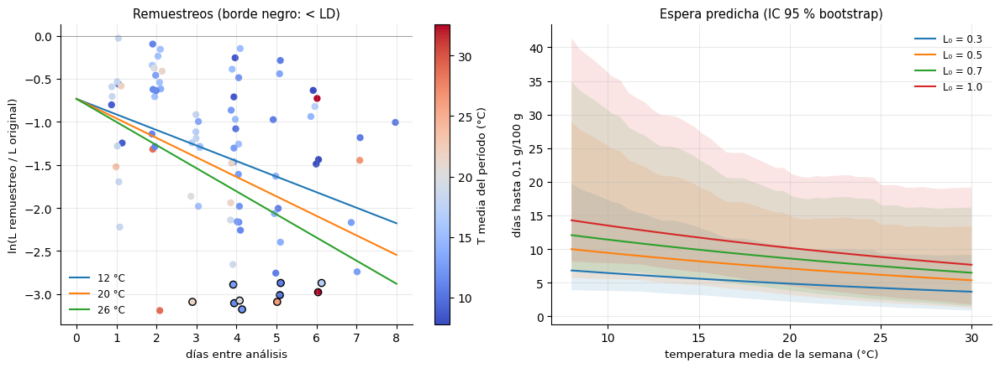

In [145]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
y = np.log(p["l1"] / p["l0"])
sc = ax[0].scatter(p["dias"] + np.random.default_rng(D.SEMILLA).uniform(-.15, .15, len(p)), y, c=p["t_exp"], cmap="coolwarm",
                   marker="o", edgecolor=np.where(p["ld1"], "k", "none"))
d = np.linspace(0, 8, 50)
for T in (12, 20, 26):
    ax[0].plot(d, th[2] - D.k_de(th, T) * d, label=f"{T} °C")
ax[0].axhline(0, color="grey", lw=.5)
ax[0].set(xlabel="días entre análisis", ylabel="ln(L remuestreo / L original)", title="Remuestreos (borde negro: < LD)")
ax[0].legend(); fig.colorbar(sc, ax=ax[0], label="T media del período (°C)")
T = np.linspace(8, 30, 50)
b = r["boot"]
for l0 in (0.3, 0.5, 0.7, 1.0):
    dd = D.dias_hasta(l0, T[:, None], b.T)
    ax[1].plot(T, D.dias_hasta(l0, T, th), label=f"L₀ = {l0}")
    ax[1].fill_between(T, *np.percentile(dd, [2.5, 97.5], axis=1), alpha=.12)
ax[1].set(xlabel="temperatura media de la semana (°C)", ylabel="días hasta 0,1 g/100 g", title="Espera predicha (IC 95 % bootstrap)")
ax[1].legend(); plt.tight_layout(); plt.show()

### Tabla de espera
Días hasta 0,1 g/100 g según la lactosa del primer análisis y la temperatura media de la semana.

In [146]:
r["tabla"].pivot(index="lactosa_inicial", columns="t_media_semana", values="dias")

t_media_semana,10,15,20,25,30
lactosa_inicial,,,,,
0.2,4.06,3.53,3.06,2.66,2.31
0.3,6.44,5.59,4.85,4.21,3.65
0.5,9.43,8.19,7.11,6.17,5.35
0.7,11.40,9.90,8.59,7.46,6.47
1.0,13.49,11.71,10.17,8.82,7.66
1.5,15.87,13.77,11.96,10.38,9.01


In [147]:
# función para usar: días de espera para una lactosa medida y la temperatura media prevista de la semana
D.dias_hasta(0.6, 18, th).round(1)

np.float64(8.4)

### Datos usados en cada entrenamiento
Cuántos datos entran en cada ajuste de este cuaderno. La unidad es el lote remuestreado (un par: primera y última recepción),
no la muestra. No hay conjunto de prueba aparte: con tan pocos lotes se ajusta con todos y la validación deja un lote afuera por vez.

In [148]:
import datos_entrenamiento as DE

miles = lambda n: f"{int(n):,}".replace(",", ".")
muestras_uat = r["muestras"]
n_lotes = int((muestras_uat.dropna(subset=["lote_id"]).groupby("lote_id")["fecha"].nunique() > 1).sum())
n_boot, n_loo = len(r["boot"]), len(r["loo"])
n_cens = int(p["ld1"].sum())
un_lote = p.iloc[:1]
base_pares = dict(parte="VI", datos="lotes UAT remuestreados, primera y última recepción", disponibles=n_lotes, usadas=len(p),
                  motivo=f"lactosa del primer análisis bajo el límite de detección (sin punto de partida): {miles(n_lotes - len(p))}")

filas = [
    DE.fila(modelo="desfase: ln L1 = ln L0 + c − k(T)·días (con censura)", **base_pares,
            particion=f"sin partición: todos los lotes; intervalos por bootstrap de lotes ({miles(n_boot)} remuestreos)",
            nota=(f"{miles(n_cens)} de los {miles(len(p))} remuestreos están bajo el límite de detección (censurados); "
                  f"los lotes salen de {miles(len(muestras_uat))} muestras UAT de Senasa con lactosa medida (MQ no mide lactosa)")),
    DE.fila(modelo="comparación: sin desfase, sin temperatura y sin tiempo", **base_pares,
            particion="sin partición: mismos lotes que el modelo principal; se comparan por AIC"),
    DE.fila(modelo="validación dejando un lote afuera (los cuatro modelos)", **base_pares,
            entrenamiento=len(p.drop(index=un_lote.index)), prueba=len(un_lote),
            particion=f"un lote afuera por vez ({miles(n_loo)} ajustes)",
            nota="error en ln(lactosa) del remuestreo sin los censurados; entrenamiento y prueba son los de cada ajuste"),
    DE.fila(parte="VI", modelo="transversal: lactosa contra la temperatura de los 5 días previos (no es un modelo)",
            datos="muestras UAT de Senasa con lactosa medida", disponibles=len(muestras_uat), usadas=muestras_uat["t5"].notna().sum(),
            motivo=f"sin temperatura de los 5 días previos: {miles(muestras_uat['t5'].isna().sum())}",
            particion="sin partición", nota="Spearman y mediana por rango de temperatura; sin remuestreo"),
]
display(DE.guardar(filas, "prediccion_deslactosado"))

,parte,modelo,datos,disponibles,excluidas,motivo de exclusión,usadas,entrenamiento,validación,prueba,partición,nota
0,VI,desfase: ln L1 = ln L0 + c − k(T)·días (con censura),"lotes UAT remuestreados, primera y última recepción",87,1,lactosa del primer análisis bajo el límite de detección (sin punto de partida): 1,86,86,<NA>,<NA>,sin partición: todos los lotes; intervalos por bootstrap de lotes (1.000 remuestreos),10 de los 86 remuestreos están bajo el límite de detección (censurados); los lotes salen de 1.176 muestras...
1,VI,"comparación: sin desfase, sin temperatura y sin tiempo","lotes UAT remuestreados, primera y última recepción",87,1,lactosa del primer análisis bajo el límite de detección (sin punto de partida): 1,86,86,<NA>,<NA>,sin partición: mismos lotes que el modelo principal; se comparan por AIC,
2,VI,validación dejando un lote afuera (los cuatro modelos),"lotes UAT remuestreados, primera y última recepción",87,1,lactosa del primer análisis bajo el límite de detección (sin punto de partida): 1,86,85,<NA>,1,un lote afuera por vez (86 ajustes),error en ln(lactosa) del remuestreo sin los censurados; entrenamiento y prueba son los de cada ajuste
3,VI,transversal: lactosa contra la temperatura de los 5 días previos (no es un modelo),muestras UAT de Senasa con lactosa medida,1176,0,sin temperatura de los 5 días previos: 0,1176,1176,<NA>,<NA>,sin partición,Spearman y mediana por rango de temperatura; sin remuestreo


### Lectura
- **El tiempo sí explica la baja**: cuanto más días entre análisis, más baja la lactosa (Spearman en el resumen) y el
  modelo con desfase es el mejor por AIC.
- **La temperatura, dentro de los pares, no alcanza a medirse**: el IC de b incluye 0. Los 86 pares son pocos, casi
  todos de 2020 a 2022, con 1 a 8 días y temperaturas de exposición parecidas dentro de cada estación.
- En el conjunto de las UAT la lactosa baja claramente con la temperatura previa (tabla transversal), así que el
  efecto existe; lo que falta es poder separarlo en la cinética.
- **Factibilidad**: la tabla sirve como orden de magnitud (≈ 5 a 9 días para una lactosa de 0,5 g/100 g, entre 30 y 10 °C), con
  intervalos anchos. Para un predictor operativo hacen falta remuestreos programados (por ejemplo a 0, 3, 7 y 14 días)
  y la fecha de elaboración, que hoy figura en 1 de las muestras UAT (3 en toda la leche fluida).

In [149]:
assert len(p) == 86 and p["lote_id"].is_unique and (p["dias"] > 0).all()
assert r["muestras"].columns.tolist()[:3] == ["Identificador", "Cliente", "lote_id"]
assert r["muestras"]["Cliente"].dropna().astype(str).str.match(r"^IND-\d+$").all()
assert np.isfinite(r["boot"]).all()
print("Verificación: todo en orden.")

Verificación: todo en orden.


### La aplicación, desde el cuaderno
La celda siguiente escribe `app_prediccion.py` (dos pestañas: días de espera para deslactosar una UAT y tipo de
muestra según lo medido). La de después la abre en http://localhost:8501.

Streamlit no corre adentro de una celda: es un programa aparte, y mientras está abierto el kernel queda ocupado.
Para abrirla cambiá `ABRIR_APP = True` y ejecutá la celda; para cerrarla, interrumpí el kernel (■). También se abre
desde una terminal, en la carpeta `trabajo_senasa_mq`: `../.venv/bin/streamlit run app_prediccion.py`.

In [150]:
%%writefile app_prediccion.py
# Trabajo Senasa + MQ · aplicación Streamlit con los dos modelos predictivos
# 1) Cuántos días esperar para que una leche UAT baje de 0,1 g/100 g de lactosa (src/deslactosado_uat.py).
# 2) Tipo de muestra (familia y subtipo) a partir de lo medido (src/prediccion_tipo.py).
# Los modelos los guardan los notebooks prediccion_deslactosado.ipynb y prediccion_tipo.ipynb en resultados/modelos/.
# Para abrirla, desde la carpeta trabajo_senasa_mq:  ../.venv/bin/streamlit run app_prediccion.py
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import streamlit as st

AQUI = Path(__file__).resolve().parent
sys.path.insert(0, str(AQUI / "src"))
import deslactosado_uat as D  # noqa: E402
import prediccion_tipo as PT  # noqa: E402

st.set_page_config(page_title="Predicciones Senasa + MQ", layout="centered")
st.title("Predicciones Senasa + MQ")
st.caption("Dos modelos ajustados en los notebooks del trabajo. Cargá los parámetros y la app devuelve el resultado.")


@st.cache_resource
def cargar(ruta):
    return joblib.load(ruta)


faltan = [p for p in (D.SALIDA_MODELO, PT.SALIDA_MODELO) if not p.exists()]
if faltan:
    st.error("Faltan modelos: " + ", ".join(p.name for p in faltan) + ". Ejecutá los notebooks prediccion_*.ipynb.")
    st.stop()

tab1, tab2 = st.tabs(["Deslactosado UAT", "Tipo de muestra"])

# ------------------------------------------------------------------ 1. deslactosado
with tab1:
    m = cargar(D.SALIDA_MODELO)
    th, boot, umbral = m["theta"], m["boot"], m["umbral"]
    st.subheader("¿Cuántos días esperar?")
    st.write(f"Modelo de primer orden ajustado con {m['n_lotes']} lotes UAT remuestreados de Senasa "
             f"({m['rango_dias'][0]} a {m['rango_dias'][1]} días entre análisis). Umbral de deslactosado: "
             f"**{umbral:.1f} g/100 g**.")
    c1, c2 = st.columns(2)
    l0 = c1.number_input("Lactosa medida (g/100 g)", 0.01, 3.0, 0.60, step=0.01, format="%.2f")
    t_sem = c2.slider("Temperatura media de la semana (°C)", 5.0, 35.0, 18.0, step=0.5)

    if l0 <= umbral:
        st.success(f"Ya está en {umbral:.1f} g/100 g o menos: no hace falta esperar.")
    else:
        dias = float(D.dias_hasta(l0, t_sem, th))
        dd = D.dias_hasta(l0, t_sem, boot.T)
        inf, sup = np.percentile(dd, [2.5, 97.5])
        k1, k2 = st.columns(2)
        k1.metric("Días de espera estimados", f"{dias:.1f}")
        k2.metric("Intervalo 95 % (bootstrap)", f"{inf:.1f} a {sup:.1f}")
        st.write(f"Tasa a esa temperatura: k = {float(D.k_de(th, t_sem)):.3f} por día "
                 f"(la lactosa baja ~{100 * (1 - np.exp(-float(D.k_de(th, t_sem)))):.0f} % por día).")
        if dias > m["rango_dias"][1]:
            st.warning(f"La espera supera los {m['rango_dias'][1]} días observados entre análisis: es una extrapolación.")
        lo, hi = m["rango_t"]
        if not lo - 2 <= t_sem <= hi + 2:
            st.warning(f"Temperatura fuera del rango observado ({lo:.0f} a {hi:.0f} °C): es una extrapolación.")

    st.info("El efecto de la temperatura dentro de los remuestreos no es significativo (el IC incluye cero): "
            "tomá el resultado como orden de magnitud, no como garantía.")

    T = np.linspace(5, 35, 61)
    fig, ax = plt.subplots(figsize=(8, 4))
    for v, col in [(0.3, "#9ecae1"), (0.5, "#4292c6"), (1.0, "#08519c")]:
        ax.plot(T, D.dias_hasta(v, T, th), color=col, lw=1, label=f"L₀ = {v}")
    if l0 > umbral:
        dT = D.dias_hasta(l0, T[:, None], boot.T)
        ax.fill_between(T, *np.percentile(dT, [2.5, 97.5], axis=1), color="#c0392b", alpha=0.15)
        ax.plot(T, D.dias_hasta(l0, T, th), color="#c0392b", lw=2, label=f"esta muestra (L₀ = {l0:.2f})")
        ax.scatter([t_sem], [D.dias_hasta(l0, t_sem, th)], s=200, marker="*", color="#c0392b", zorder=5)
    ax.axvspan(*m["rango_t"], color="grey", alpha=0.08, label="temperaturas observadas")
    ax.set(xlabel="temperatura media de la semana (°C)", ylabel=f"días hasta {umbral:.1f} g/100 g",
           title="Espera predicha según la temperatura")
    ax.legend(fontsize=8)
    st.pyplot(fig)

# ------------------------------------------------------------------ 2. tipo de muestra
with tab2:
    paq = cargar(PT.SALIDA_MODELO)
    st.subheader("¿Qué tipo de muestra es?")
    st.write("Cargá los análisis que se midieron; los que no, dejalos sin marcar (el modelo también usa *qué* "
             "análisis se pidieron). Con probabilidad menor a "
             f"{paq['umbral']:.2f} el resultado queda como «sin decidir».")

    CAMPOS = [  # (variable, etiqueta, valor por defecto, medida por defecto)
        ("humedad", "Humedad (g/100 g)", 3.5, True),
        ("grasa", "Materia grasa (g/100 g)", 26.0, True),
        ("proteinas", "Proteínas (g/100 g)", 25.0, True),
        ("cenizas", "Cenizas (g/100 g)", 6.0, False),
        ("grasa_es", "Materia grasa en extracto seco (g/100 g)", 45.0, False),
        ("cloruros", "Cloruros (NaCl g/100 g)", 1.5, False),
        ("acidez_naoh", "Acidez (ml NaOH 0,1 N / 10 g SNG)", 15.0, False),
        ("acidez_lactico", "Acidez (% ácido láctico)", 0.15, False),
        ("lactosa", "Lactosa (g/100 g)", 38.0, False),
        ("galactosa", "D-galactosa (g/100 g)", 0.1, False),
        ("azucares", "Azúcares totales (g/100 g)", 50.0, False),
        ("ph", "pH", 6.6, False),
        ("aw", "Actividad de agua", 0.85, False),
        ("almidon", "Almidón total (g/100 g)", 1.0, False),
        ("sodio", "Sodio (mg/100 g)", 400.0, False),
        ("calcio", "Calcio (mg/100 g)", 900.0, False),
        ("brix", "Grado Brix (°Bx)", 70.0, False),
        ("solubilidad", "Solubilidad (%)", 99.0, False),
    ]
    valores = {}
    c1, c2 = st.columns(2)
    for i, (var, etiqueta, defecto, medido) in enumerate(CAMPOS):
        col = c1 if i % 2 == 0 else c2
        if col.checkbox(etiqueta, value=medido, key=f"chk_{var}"):
            valores[var] = col.number_input(etiqueta, value=float(defecto), key=f"val_{var}", label_visibility="collapsed")

    if not valores:
        st.warning("Marcá al menos un análisis.")
        st.stop()

    fila = {v: np.nan for v in PT.VARIABLES}
    fila.update(valores)
    n_medidos = len(valores)
    if np.isfinite(fila["humedad"]):                         # igual que en el entrenamiento
        fila["solidos"] = 100 - fila["humedad"]
    fila["n_analisis"] = n_medidos
    for v in PT.VARIABLES:
        fila[f"pide_{v}"] = int(np.isfinite(fila[v]))
    X = pd.DataFrame([fila])[paq["columnas"]]
    if np.isfinite(fila["humedad"]) and not 0 <= fila["humedad"] <= 100:
        st.error("La humedad tiene que estar entre 0 y 100.")
        st.stop()

    res = PT.predecir(paq, X).iloc[0]
    k1, k2 = st.columns(2)
    k1.metric("Familia", res["familia_pred"], f"prob. {res['prob_familia']:.2f}", delta_color="off")
    if pd.notna(res["subtipo_pred"]):
        k2.metric("Subtipo", res["subtipo_pred"], f"prob. {res['prob_subtipo']:.2f}", delta_color="off")
    if res["decision"] == "sin decidir":
        st.warning("Probabilidad baja: el modelo no decide. Mirá las alternativas abajo o agregá análisis.")
    else:
        st.success("Propuesta del modelo con probabilidad suficiente.")

    mf = paq["modelos"]["familia"]
    pf = pd.Series(mf.predict_proba(X)[0], index=mf.classes_).sort_values(ascending=True).tail(6)
    fig2, ax2 = plt.subplots(figsize=(8, 3.5))
    ax2.barh(pf.index, pf.values, color=["#c0392b" if i == res["familia_pred"] else "#4292c6" for i in pf.index])
    ax2.axvline(paq["umbral"], color="black", lw=0.8, ls="--", label=f"umbral {paq['umbral']:.2f}")
    ax2.set(xlim=(0, 1), xlabel="probabilidad", title="Familias más probables")
    ax2.legend(fontsize=8, loc="lower right")
    st.pyplot(fig2)

    if res["familia_pred"] in paq["modelos"]:
        ms = paq["modelos"][res["familia_pred"]]
        ps = pd.Series(ms.predict_proba(X)[0], index=ms.classes_).sort_values(ascending=False)
        st.write("Subtipos dentro de la familia: " + " · ".join(f"{k} {v:.2f}" for k, v in ps.items()))

    st.caption("Validación agrupada por envío: familia 81 % de acierto en general, 95 % cuando la probabilidad es ≥ 0,80.")
    with st.expander("Ver la fila que recibe el modelo"):
        st.dataframe(X.T.rename(columns={0: "valor"}))

Overwriting app_prediccion.py


In [151]:
import sys
ABRIR_APP = False   # True para abrirla (bloquea el kernel hasta interrumpirlo)
if ABRIR_APP:
    print("Abrir http://localhost:8501 en el navegador. Para cortarla: interrumpir el kernel (■).")
    !"{sys.executable}" -m streamlit run app_prediccion.py --server.headless true
else:
    print("App escrita en app_prediccion.py. Para abrirla: ABRIR_APP = True y volver a ejecutar esta celda.")

App escrita en app_prediccion.py. Para abrirla: ABRIR_APP = True y volver a ejecutar esta celda.


<a id="parte-vii"></a>

# Parte VII · Árbol de decisión en cascada: familia y subtipo

El trabajo de otro integrante del grupo: con solo la composición, un árbol de decisión predice la familia y otro, dentro de la familia, el subtipo. Tres versiones (solo arc, con la clase «sin clasificar», arc + MQ con umbral), búsqueda en cuadrícula con validación cruzada, ROC uno contra el resto y una aplicación.

*(Generada a partir de `arbol_decision.ipynb`.)*

## Árbol de decisión en cascada: familia y subtipo

**Qué es.** El trabajo de otro integrante del grupo, llevado al proyecto con el mismo código y las mismas reglas.
Con solo los análisis de composición de una muestra (humedad, grasa, proteínas, cenizas, sólidos totales, lactosa y
galactosa), un primer árbol predice la **familia** del producto y, dentro de esa familia, un segundo árbol predice el
**subtipo**. Los análisis que no se midieron quedan vacíos: el árbol de scikit-learn aprende hacia qué lado mandarlos.

**Las tres versiones.**
- **V1, solo arc.** `dataset_senasa_revision.xlsx` (Senasa revisada). En cada árbol de subtipo se dejan afuera las
  clases con menos de 5 muestras de entrenamiento.
- **V2, arc con la clase SIN CLASIFICAR.** En las familias con subtipos, las muestras sin subtipo forman una clase más.
- **V3, arc + MQ.** El 80 % de arc más todas las MQ nuevas, ya filtradas, entrenan. SIN CLASIFICAR solo se responde si
  su probabilidad llega a 0,85; si no, se da el subtipo real más probable. Es la versión final.

En las tres:
- la prueba es un 20 % de arc, al azar, estratificado por familia y subtipo;
- cada árbol se elige por validación cruzada de 5 pliegues (F1 macro) sobre una cuadrícula de `max_depth` y
  `min_samples_leaf`;
- dentro de cada familia, los subtipos con menos de 20 muestras pasan a «OTRO».

**Qué cambia respecto de los cuadernos originales.**
- Semilla 42, como el resto del trabajo (el original usaba 2026).
- Rutas del proyecto.
- El filtro «declarado vs medido» sale del mismo cálculo del proyecto.
- Las descripciones de las muestras se usan solo para los filtros: no se muestran.

Quedan afuera:
- la exportación a JSON para la página web;
- el modelo guardado que venía con el trabajo (acá se vuelve a entrenar);
- las tablas con ejemplos de descripciones;
- la parte de `Algoritmos.ipynb` que repite a V3.

In [152]:
import sys
import time
import warnings
from pathlib import Path
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "rutas.py").exists()) / "src"
sys.path.insert(0, str(SRC))
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, confusion_matrix
from sklearn.tree import plot_tree
import arbol_decision as AD
import datos_entrenamiento as DE
from arbol_decision import AGRUPADO, FAMILIA, PREDICTORAS, SUBTIPO, coma
from arbol_decision import SUBTIPO_SIN_CLASIFICAR as SC

warnings.filterwarnings("ignore", category=UndefinedMetricWarning)   # clases que un pliegue no predice nunca
AZUL, AMBAR, GRIS, ROJO, VERDE = "#0055a5", "#f0a800", "#6b7280", "#c0392b", "#2e8b57"
COLORES = {"V1": GRIS, "V2": AMBAR, "V3": AZUL}
inicio = time.time()
print(f"Semilla {AD.SEMILLA} · prueba {coma(AD.PRUEBA * 100, 0)} % de arc · umbral de {SC} en V3: {coma(AD.UMBRAL_SIN_CLASIFICAR, 2)}")

Semilla 42 · prueba 20 % de arc · umbral de SIN CLASIFICAR en V3: 0,85


### 1. Datos

**Qué se saca.**
- V1 y V2: las filas de arc sin ningún análisis y las atípicas (o excluidas porque humedad + sólidos no da 100).
- V3 aplica además los filtros de MQ, en orden. La tabla muestra cuántas filas saca cada uno, por origen y por familia;
  cada fila ya descontó las anteriores.

**Después de filtrar.**
- MQ solo conserva los subtipos que existen en arc para esa familia.
- La familia «sin clasificar» queda aparte, para predecirla al final.

In [153]:
D = {v: AD.preparar(v) for v in AD.VERSIONES}
D3 = D["V3"]
resumen_datos = pd.DataFrame({AD.TITULOS[v]: {
    "filas de las planillas": d.disponibles, "para modelar": len(d.modelado), "de MQ": len(d.muestras_mq),
    "«sin clasificar» (aparte)": len(d.sin_clasificar), "entrenamiento": len(d.ent), "prueba (arc)": len(d.pru),
    "con subtipo real": int(d.modelado[SUBTIPO].notna().sum()), f"pasan a {SC}": d.pasan_sc} for v, d in D.items()})
display(resumen_datos.style.format("{:.0f}").set_caption("Las tres versiones: cuántas muestras usa cada una"))
c1 = D["V1"].conteos
print("V1 y V2: " + " · ".join(f"{i.lstrip('− ')}: {c1.loc[i, 'arc']}" for i in c1.index))
display(D3.conteos.style.set_caption("V3: filas que saca cada filtro, en orden (por origen y por familia, los dos orígenes juntos)"))
print("V3, subtipos de MQ que no están en arc (quedan sin subtipo):",
      ", ".join(f"{f} / {s} ({n})" for (f, s), n in D3.sin_par.items()) or "ninguno")
m3 = D3.modelado
display(pd.concat([m3[FAMILIA].value_counts().rename("muestras"), D3.muestras_mq[FAMILIA].value_counts().rename("de MQ"),
                   m3.groupby(FAMILIA)[SUBTIPO].apply(lambda s: s.notna().sum()).rename("con subtipo"),
                   m3.groupby(FAMILIA)[AGRUPADO].apply(lambda s: (s == SC).sum()).rename(SC),
                   m3.groupby(FAMILIA)[PREDICTORAS].apply(lambda d: d.notna().mean() * 100).round(0).add_prefix("% medido: ")], axis=1)
        .fillna(0).style.format(precision=0).background_gradient(subset=[f"% medido: {p}" for p in PREDICTORAS], cmap="Blues", vmin=0, vmax=100)
        .set_caption("V3 (arc + MQ): muestras por familia, con subtipo, que pasan a SIN CLASIFICAR y % medido de cada análisis"))
crema = m3[AGRUPADO] == "CREMA"
print(f"CREMA (manteca / crema) solo está en MQ: entrena {crema.loc[D3.ent.index].sum()} · prueba {crema.loc[D3.pru.index].sum()}: no tiene evaluación")

,V1 · solo arc,V2 · arc + SIN CLASIFICAR,"V3 · arc + MQ, umbral 0,85"
filas de las planillas,16347,16347,30089
para modelar,15125,15125,24186
de MQ,0,0,9184
«sin clasificar» (aparte),9,9,1026
entrenamiento,12100,12100,21185
prueba (arc),3025,3025,3001
con subtipo real,9299,9299,13748
pasan a SIN CLASIFICAR,0,5128,9391


V1 y V2: planillas completas: 16347 · sin ningún análisis (arc y MQ): 1143 · atípica o excluida por humedad y sólidos (arc): 70 · quedan: 15134


,arc,MQ,queso,leche en polvo,dulce de leche,leche fluida,suero / permeado,manteca / crema,base nutricional,concentrado proteico,yogur / bebida lactea,sin clasificar,otras
planillas completas,16347,13742,7043,5637,4474,2952,2328,1337,1717,1111,716,1302,1472
− sin ningún análisis (arc y MQ),1143,1902,713,1110,544,177,83,107,5,62,37,50,157
− atípica o excluida por humedad y sólidos (arc),70,0,0,0,37,1,17,0,0,0,3,0,12
− R1 control de laboratorio (MQ),0,249,44,39,0,30,14,24,30,1,0,67,0
− R2 cliente IND-41 (arc y MQ),67,44,4,13,62,3,3,5,0,1,0,12,8
"− R3 IND-59 en serie (MUESTRA n, N°n, CREMA n) (MQ)",0,47,2,0,0,27,3,6,0,0,4,5,0
"− R4 serie por tiempo (n MIN, n') (MQ)",0,42,0,0,0,0,6,0,0,0,0,36,0
− R5 humedad + grasa + proteínas + cenizas > 102 (MQ),0,9,1,0,0,0,0,4,1,0,1,2,0
− ensayo o pool (MQ),0,474,49,88,0,24,55,3,14,69,16,104,52
− declarado vs medido: no coincide (arc y MQ),56,150,176,20,6,0,1,0,1,2,0,0,0


V3, subtipos de MQ que no están en arc (quedan sin subtipo): manteca / crema / DOBLE CREMA (3), queso / BRIE (2), queso / CRIOLLO (51), queso / MASCARPONE (8)


,muestras,de MQ,con subtipo,SIN CLASIFICAR,% medido: humedad,% medido: grasa,% medido: proteinas,% medido: cenizas,% medido: solidos_totales,% medido: lactosa,% medido: galactosa
desc_familia,,,,,,,,,,,
queso,6054,2198,4052,2002,64,57,10,2,59,32,31
leche en polvo,4367,2992,188,4179,38,49,25,35,38,29,1
dulce de leche,3825,112,2866,959,78,88,74,65,78,10,10
leche fluida,2690,742,1933,757,9,11,16,4,9,72,53
suero / permeado,1717,829,1665,52,14,28,16,21,14,49,9
base nutricional,1610,140,263,1347,5,7,3,3,5,91,1
manteca / crema,1186,1037,1183,3,28,94,2,1,16,0,0
concentrado proteico,847,211,790,57,46,49,52,45,46,37,3
helado,751,82,0,0,10,25,15,15,10,84,84


CREMA (manteca / crema) solo está en MQ: entrena 848 · prueba 0: no tiene evaluación


### 2. Entrenamiento de las tres versiones

Cada versión entrena su cascada con su propia regla para el segundo nivel.
- **V1.** Las clases con menos de 5 muestras de entrenamiento quedan afuera: no entrenan, pero en la prueba siguen
  estando y cuentan como error.
- **V2 y V3.** Árbol si hay al menos dos clases con dos muestras cada una. Constante si hay una sola clase, o si alguna
  tiene una sola muestra.

En las tres, las familias sin subtipos terminan en el primer nivel. La tabla es el plan de V3.

In [154]:
t0 = time.time()
E = {v: AD.entrenar(D[v]) for v in AD.VERSIONES}          # (modelos, búsquedas, plan) de cada versión
modelos, busquedas, plan = E["V3"]
pru, ent = D3.pru, D3.ent
print(f"Las tres cascadas, entrenadas en {coma(time.time() - t0, 0)} s · árboles de subtipo: "
      + " · ".join(f"{v} {sum(e['tipo'] == 'árbol' for e in E[v][0]['subtipo'].values())}" for v in AD.VERSIONES))
with pd.option_context("display.max_colwidth", 160):
    display(plan.style.set_caption("V3: qué modelo lleva cada familia (clases con sus muestras de entrenamiento)"))
afuera = E["V1"][2][f"afuera (< {AD.MINIMO_POR_CLASE})"]
print("V1, clases que quedan afuera por tener menos de 5 muestras: " + "; ".join(f"{f}: {a}" for f, a in afuera.items() if isinstance(a, str) and a != "—"))

Las tres cascadas, entrenadas en 12 s · árboles de subtipo: V1 10 · V2 10 · V3 11


,entrenamiento,clases tras agrupar,SIN CLASIFICAR (entrenamiento),decisión,motivo,clases (entrenamiento)
familia,,,,,,
agua / hisopado,72,4,13.000000,árbol,5 pliegues,"AGUA DE ENJUAGUE (36), HISOPADO (17), SIN CLASIFICAR (13), OTRO (6)"
arroz con leche / postre,97,3,4.000000,árbol,"4 pliegues (la clase más chica, SIN CLASIFICAR, tiene 4)","ARROZ CON LECHE (85), OTRO (8), SIN CLASIFICAR (4)"
base nutricional,1316,3,1105.000000,árbol,5 pliegues,"SIN CLASIFICAR (1105), CASEINATOS (197), OTRO (14)"
carnicos,0,0,nan,sin subtipo,la familia no tiene subtipos,
concentrado proteico,719,6,48.000000,árbol,5 pliegues,"WPC (575), SIN CLASIFICAR (48), CASEINA (44), CASEINATO DE SODIO (26), CASEINATO DE CALCIO (17), OTRO (9)"
dulce de leche,3082,4,777.000000,árbol,5 pliegues,"FAMILIAR (1058), REPOSTERO (840), SIN CLASIFICAR (777), HELADERO (407)"
helado,0,0,nan,sin subtipo,la familia no tiene subtipos,
leche en polvo,4092,3,3925.000000,árbol,5 pliegues,"SIN CLASIFICAR (3925), MODIFICADA (162), OTRO (5)"
leche fluida,2301,6,665.000000,árbol,5 pliegues,"UAT (1078), SIN CLASIFICAR (665), CRUDA (296), CONCENTRADA (150), CHOCOLATADA (76), OTRO (36)"


V1, clases que quedan afuera por tener menos de 5 muestras: manteca / crema: OTRO (1)


### 3. Primer nivel: la familia (V3)

Se compara con la línea de base que siempre responde la familia más común. El mapa de calor muestra el F1 macro de
validación de cada combinación de la cuadrícula.

Mejor combinación: {'max_depth': None, 'min_samples_leaf': 5} · F1 macro de validación 0,717
Árbol de familia: profundidad 37 · 1103 hojas


,exactitud,precisión (macro),exhaustividad (macro),F1 (macro)
línea de base (mayoritaria),"0,257","0,018","0,071","0,029"
árbol de familia,"0,889","0,701","0,667","0,671"


max_depth,∞,2,3,4,5,6,8,10
min_samples_leaf,,,,,,,,
1,"0,710","0,171","0,230","0,341","0,456","0,516","0,639","0,682"
2,"0,709","0,171","0,230","0,341","0,456","0,516","0,636","0,681"
5,"0,717","0,171","0,230","0,341","0,456","0,515","0,637","0,679"
10,"0,703","0,171","0,230","0,341","0,452","0,505","0,615","0,658"
20,"0,682","0,171","0,230","0,340","0,450","0,502","0,609","0,651"
50,"0,640","0,171","0,230","0,339","0,449","0,499","0,596","0,632"


,precisión,sensibilidad,F1,soporte
clase,,,,
agua / hisopado,"0,000","0,000","0,000",16
arroz con leche / postre,"1,000","0,818","0,900",11
base nutricional,"0,837","0,959","0,894",294
carnicos,"0,500","0,667","0,571",3
concentrado proteico,"0,653","0,633","0,643",128
dulce de leche,"0,981","0,978","0,980",743
helado,"0,752","0,769","0,760",134
leche en polvo,"0,882","0,873","0,878",275
leche fluida,"0,837","0,887","0,861",389


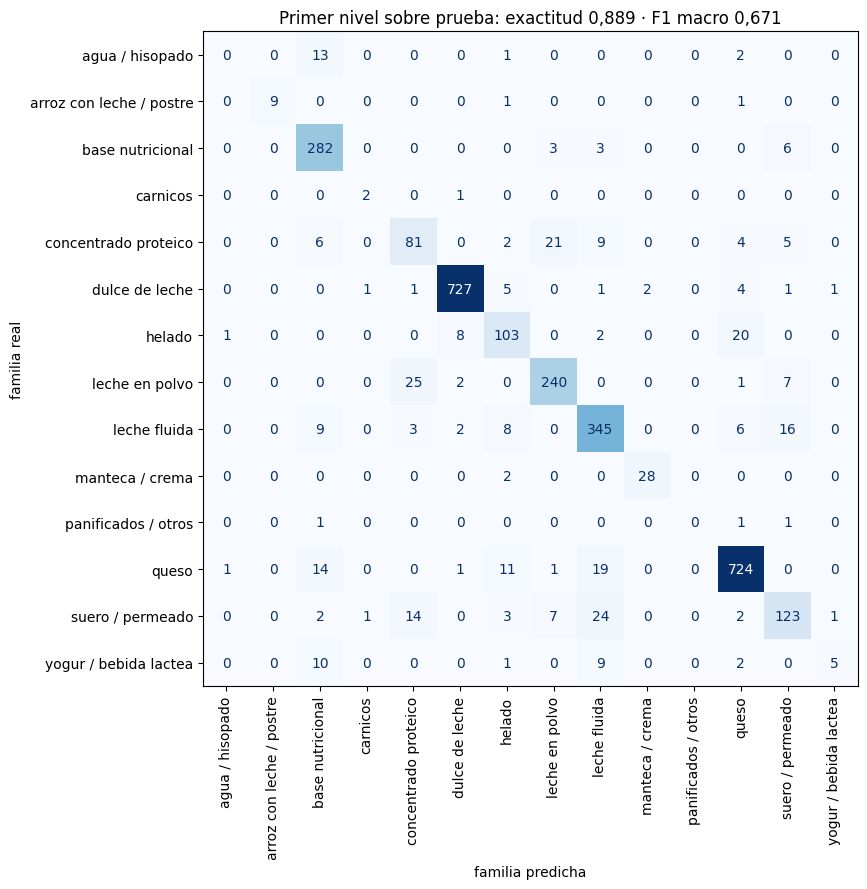

In [155]:
cf = busquedas["familia"]
arbol_familia = modelos["familia"]
pred_familia = arbol_familia.predict(pru[PREDICTORAS])
resultados_familia = AD.familia_vs_base(modelos, ent, pru)
print(f"Mejor combinación: {cf.best_params_} · F1 macro de validación {coma(cf.best_score_)}")
print(f"Árbol de familia: profundidad {arbol_familia.get_depth()} · {arbol_familia.get_n_leaves()} hojas")
display(resultados_familia.style.format(precision=3, decimal=",").set_caption(f"Primer nivel sobre las {len(pru)} muestras de prueba"))
mapa = pd.DataFrame(cf.cv_results_).pivot(index="param_min_samples_leaf", columns="param_max_depth", values="mean_test_score")
mapa.columns = [str(int(v)) if pd.notna(v) else "∞" for v in mapa.columns]
mapa.index.name, mapa.columns.name = "min_samples_leaf", "max_depth"
display(mapa.style.format(precision=3, decimal=",").background_gradient(cmap="RdYlGn", axis=None)
        .set_caption("F1 macro de validación: filas min_samples_leaf, columnas max_depth"))
rep = classification_report(pru[FAMILIA], pred_familia, zero_division=0, output_dict=True)
reporte_familia = pd.DataFrame([{"clase": k, "precisión": v["precision"], "sensibilidad": v["recall"], "F1": v["f1-score"],
                                 "soporte": int(v["support"])} for k, v in rep.items()
                                if isinstance(v, dict) and k not in ("macro avg", "weighted avg")]).set_index("clase")
display(reporte_familia.style.format(precision=3, decimal=",").format("{:.0f}", subset=["soporte"])
        .background_gradient(subset=["F1"], cmap="RdYlGn", vmin=0, vmax=1).set_caption("Reporte de clasificación de la familia (prueba)"))
fig, ax = plt.subplots(figsize=(11, 9))
ConfusionMatrixDisplay.from_predictions(pru[FAMILIA], pred_familia, cmap="Blues", xticks_rotation=90, colorbar=False, ax=ax)
ax.set_xlabel("familia predicha"); ax.set_ylabel("familia real")
ax.set_title(f"Primer nivel sobre prueba: exactitud {coma(resultados_familia.loc['árbol de familia', 'exactitud'])} · "
             f"F1 macro {coma(resultados_familia.loc['árbol de familia', 'F1 (macro)'])}")
plt.tight_layout(); plt.show()

#### Cómo es el árbol de familia

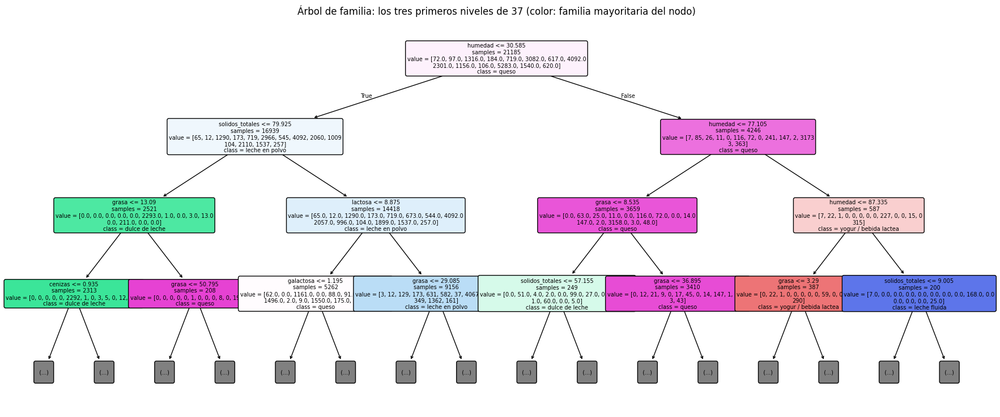

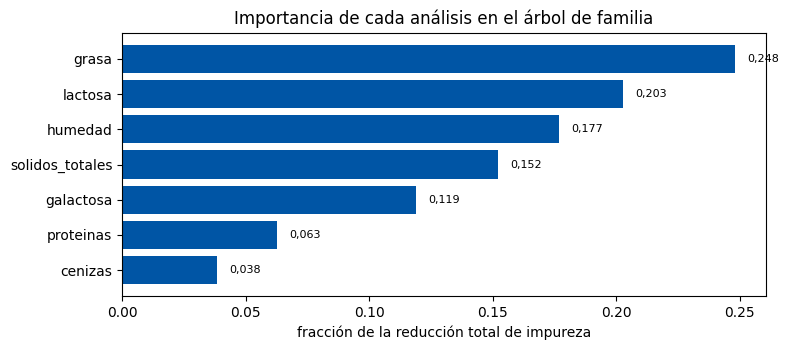

Raíz: ¿humedad ≤ 30,59? · las faltantes van a la izquierda


In [156]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(arbol_familia, max_depth=3, feature_names=PREDICTORAS, class_names=list(arbol_familia.classes_), filled=True,
          rounded=True, fontsize=7, impurity=False, proportion=False, ax=ax)
ax.set_title(f"Árbol de familia: los tres primeros niveles de {arbol_familia.get_depth()} (color: familia mayoritaria del nodo)")
plt.show()
importancias = pd.Series(arbol_familia.feature_importances_, index=PREDICTORAS).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(importancias.index, importancias.values, color=AZUL)
for k, v in enumerate(importancias.values):
    ax.text(v + 0.005, k, coma(v), va="center", fontsize=8)
ax.set_xlabel("fracción de la reducción total de impureza"); ax.set_title("Importancia de cada análisis en el árbol de familia")
plt.tight_layout(); plt.show()
t_ = arbol_familia.tree_
print(f"Raíz: ¿{PREDICTORAS[t_.feature[0]]} ≤ {coma(t_.threshold[0], 2)}? · las faltantes van a la "
      f"{'izquierda' if t_.missing_go_to_left[0] else 'derecha'}")

#### Curvas ROC de la familia

Una curva por familia (uno contra el resto) con las probabilidades del árbol, más la curva micro (todas las clases
juntas). Un árbol da pocas probabilidades distintas, por eso las curvas tienen pocos escalones.

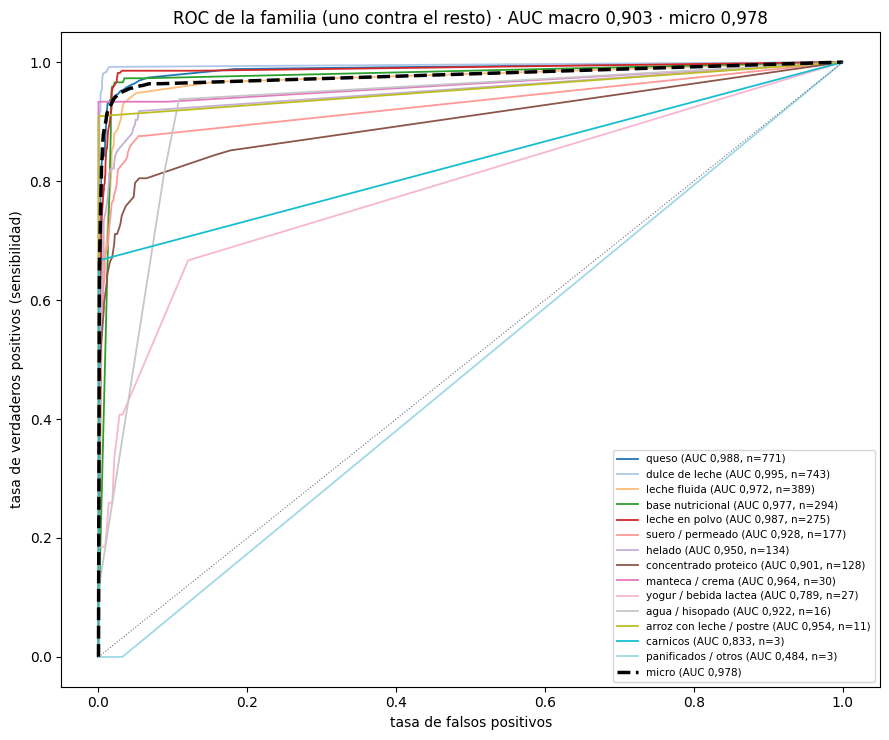

AUC familia: macro 0,903 · micro 0,978


In [157]:
roc_familia, omitidas_familia = AD.roc_ovr(pru[FAMILIA], arbol_familia.predict_proba(pru[PREDICTORAS]), arbol_familia.classes_)
fig, ax = plt.subplots(figsize=(9, 7.5))
colores = plt.cm.tab20(np.linspace(0, 1, len(roc_familia["clases"])))
for cu, col in zip(sorted(roc_familia["clases"], key=lambda x: -x["soporte"]), colores):
    ax.plot(cu["fpr"], cu["tpr"], color=col, lw=1.3, label=f"{cu['clase']} (AUC {coma(cu['auc'])}, n={cu['soporte']})")
ax.plot(roc_familia["fpr"], roc_familia["tpr"], color="black", lw=2.5, ls="--", label=f"micro (AUC {coma(roc_familia['auc_micro'])})")
ax.plot([0, 1], [0, 1], color=GRIS, lw=0.8, ls=":")
ax.set_xlabel("tasa de falsos positivos"); ax.set_ylabel("tasa de verdaderos positivos (sensibilidad)")
ax.set_title(f"ROC de la familia (uno contra el resto) · AUC macro {coma(roc_familia['auc_macro'])} · micro {coma(roc_familia['auc_micro'])}")
ax.legend(fontsize=7.5, loc="lower right"); plt.tight_layout(); plt.show()
print(f"AUC familia: macro {coma(roc_familia['auc_macro'])} · micro {coma(roc_familia['auc_micro'])}"
      + (f" · sin muestras en la prueba: {', '.join(map(str, omitidas_familia))}" if omitidas_familia else ""))

### 4. Segundo nivel: el subtipo dentro de cada familia (V3)

Cada árbol se mide sobre las muestras de prueba de su familia **real**: es la calidad del segundo nivel aislado. Esta
tabla usa la predicción cruda del árbol, sin el umbral de SIN CLASIFICAR.
- **(a)** todas las clases, SIN CLASIFICAR incluida.
- **(b)** solo las muestras con subtipo real, que es lo comparable con V1.

In [158]:
resultados_subtipo = AD.tabla_subtipo(modelos, busquedas, plan, ent, pru, "V3")
CON_ARBOL = list(resultados_subtipo.index[resultados_subtipo["tipo"] == "árbol"])
tabla_s = resultados_subtipo.copy()
tabla_s["max_depth"] = [("∞" if pd.isna(v) else f"{int(v)}") if t == "árbol" else "—" for v, t in zip(tabla_s["max_depth"], tabla_s["tipo"])]
ENTEROS = ["min_samples_leaf", "pliegues", "hojas"]
display(tabla_s.style.format({k: (lambda v: "—" if pd.isna(v) else f"{int(v)}") for k in ENTEROS})
        .format(precision=3, decimal=",", na_rep="—", subset=[k for k in tabla_s.columns if k not in ["tipo", "max_depth", *ENTEROS]])
        .background_gradient(subset=["F1 macro (a)", "F1 macro (b)"], cmap="RdYlGn", vmin=0, vmax=1)
        .set_caption("Segundo nivel por familia, con la familia real y sin umbral: (a) todas las clases; (b) solo subtipo real"))
tabla_imp = pd.DataFrame({"familia (nivel 1)": arbol_familia.feature_importances_,
                          **{f: modelos["subtipo"][f]["modelo"].feature_importances_ for f in CON_ARBOL}}, index=PREDICTORAS).T
display(tabla_imp.style.format(precision=2, decimal=",").background_gradient(cmap="Blues", axis=1, vmin=0, vmax=1)
        .set_caption("Importancia de cada análisis en cada árbol (cada fila suma 1)"))

,tipo,clases,entrenamiento,prueba (a),prueba (b),max_depth,min_samples_leaf,pliegues,F1 macro validación,hojas,exactitud (a),F1 macro (a),F1 macro base (a),exactitud (b),F1 macro (b),F1 macro base (b),% reales → SIN CLASIFICAR
familia,,,,,,,,,,,,,,,,,
agua / hisopado,árbol,4,72,16,15,3,1,5,"0,619",5,"0,562","0,508","0,180","0,533","0,456","0,250","0,067"
arroz con leche / postre,árbol,3,97,11,11,5,1,4,"0,784",8,"1,000","1,000","0,450","1,000","1,000","0,450","0,000"
base nutricional,árbol,3,1316,294,52,5,1,5,"0,513",13,"0,827","0,468","0,301","0,019","0,250","0,000","0,981"
concentrado proteico,árbol,6,719,128,119,∞,1,5,"0,671",59,"0,953","0,834","0,146","0,966","0,886","0,183","0,017"
dulce de leche,árbol,4,3082,743,561,8,1,5,"0,731",128,"0,708","0,719","0,128","0,774","0,814","0,209","0,082"
leche en polvo,árbol,3,4092,275,21,6,1,5,"0,606",21,"0,945","0,839","0,320","0,476","0,810","0,000","0,524"
leche fluida,árbol,6,2301,389,297,∞,1,5,"0,621",558,"0,699","0,495","0,130","0,791","0,584","0,182","0,162"
manteca / crema,árbol,4,1156,30,30,5,10,3,"0,539",9,"0,933","0,327","0,000","0,933","0,327","0,000","0,000"
queso,árbol,31,5283,771,540,∞,5,5,"0,294",636,"0,521","0,248","0,015","0,465","0,251","0,000","0,222"


,humedad,grasa,proteinas,cenizas,solidos_totales,lactosa,galactosa
familia (nivel 1),"0,18","0,25","0,06","0,04","0,15","0,20","0,12"
agua / hisopado,"0,00","0,00","0,00","0,00","0,00","0,81","0,19"
arroz con leche / postre,"0,21","0,25","0,48","0,00","0,00","0,00","0,07"
base nutricional,"0,00","0,05","0,00","0,13","0,05","0,76","0,02"
concentrado proteico,"0,05","0,17","0,19","0,15","0,01","0,37","0,06"
dulce de leche,"0,05","0,12","0,16","0,25","0,37","0,03","0,01"
leche en polvo,"0,00","0,15","0,43","0,01","0,00","0,38","0,02"
leche fluida,"0,06","0,11","0,16","0,03","0,02","0,24","0,38"
manteca / crema,"0,00","0,85","0,03","0,00","0,12","0,00","0,00"
queso,"0,32","0,29","0,08","0,00","0,13","0,05","0,13"


#### ROC, matrices y reportes del subtipo

Son las muestras de prueba de cada familia real que tienen subtipo agrupado, sea un subtipo real o SIN CLASIFICAR.
- La ROC usa las probabilidades del árbol tal como salen.
- Las matrices y los reportes usan la predicción **con el umbral de 0,85**.

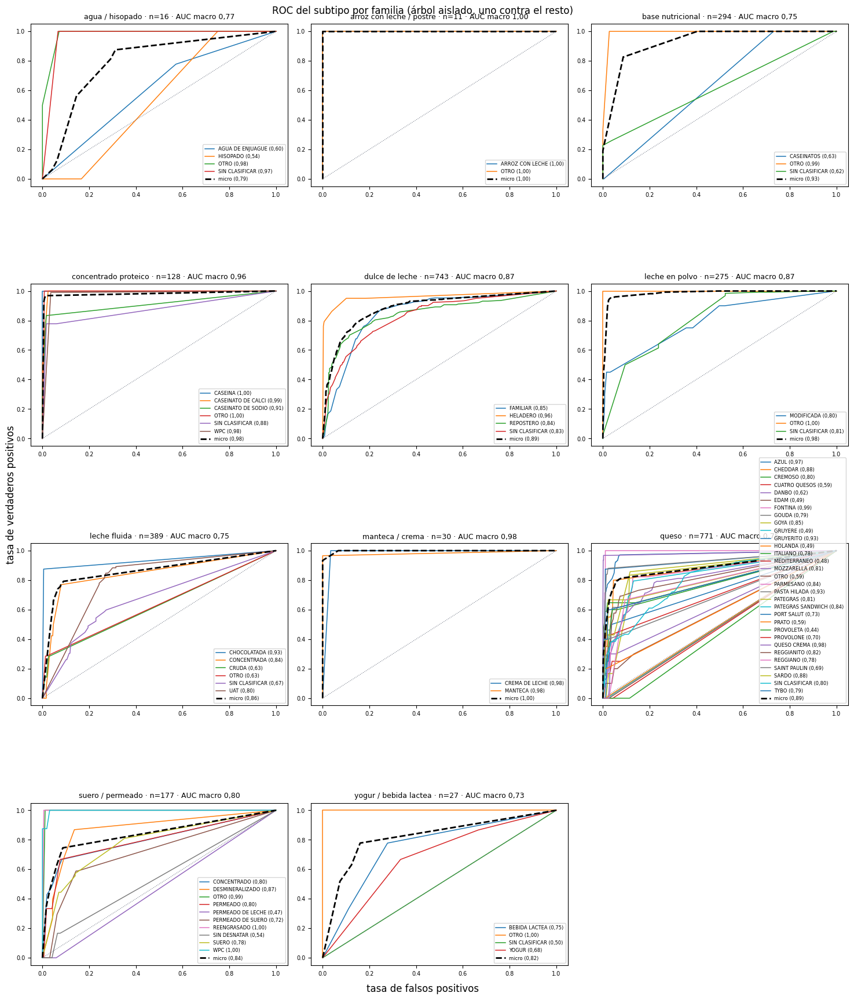

,muestras,AUC macro,AUC micro
agua / hisopado,16,"0,773","0,794"
arroz con leche / postre,11,"1,000","1,000"
base nutricional,294,"0,748","0,930"
concentrado proteico,128,"0,959","0,981"
dulce de leche,743,"0,872","0,886"
leche en polvo,275,"0,868","0,984"
leche fluida,389,"0,753","0,862"
manteca / crema,30,"0,983","0,998"
queso,771,"0,748","0,888"
suero / permeado,177,"0,798","0,839"


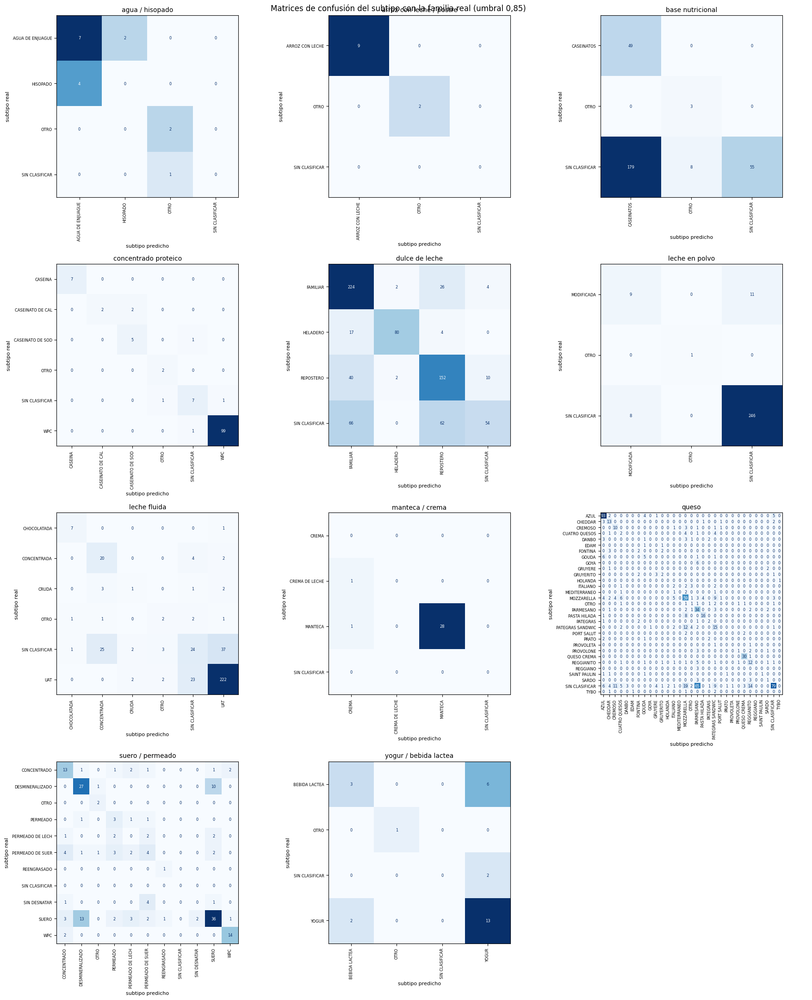

,precisión,sensibilidad,F1,soporte
clase,,,,
AZUL,"0,775","0,886","0,827",105
CHEDDAR,"0,448","0,650","0,531",20
CREMOSO,"0,400","0,588","0,476",17
CUATRO QUESOS,"0,105","0,167","0,129",12
DANBO,"0,000","0,000","0,000",10
EDAM,"0,000","0,000","0,000",2
FONTINA,"0,333","0,286","0,308",7
GOUDA,"0,357","0,385","0,370",13
GOYA,"0,000","0,000","0,000",6


,precisión,sensibilidad,F1,soporte
clase,,,,
FAMILIAR,"0,646","0,875","0,743",256
HELADERO,"0,952","0,792","0,865",101
REPOSTERO,"0,623","0,745","0,679",204
SIN CLASIFICAR,"0,794","0,297","0,432",182


,precisión,sensibilidad,F1,soporte
clase,,,,
CHOCOLATADA,"0,778","0,875","0,824",8
CONCENTRADA,"0,408","0,769","0,533",26
CRUDA,"0,200","0,143","0,167",7
OTRO,"0,286","0,286","0,286",7
SIN CLASIFICAR,"0,444","0,261","0,329",92
UAT,"0,838","0,892","0,864",249


,precisión,sensibilidad,F1,soporte
clase,,,,
CASEINATOS,"0,215","1,000","0,354",49
OTRO,"0,273","1,000","0,429",3
SIN CLASIFICAR,"1,000","0,227","0,370",242


In [159]:
roc_subtipo, conf_subtipo, reportes_subtipo, sin_prueba = {}, {}, {}, []
n_ = len(CON_ARBOL); columnas = 3; filas_g = int(np.ceil(n_ / columnas))
fig, ejes = plt.subplots(filas_g, columnas, figsize=(5 * columnas, 4.4 * filas_g), squeeze=False)
for ax, familia in zip(ejes.ravel(), CON_ARBOL):
    arbol = modelos["subtipo"][familia]["modelo"]
    en_pru = (pru[FAMILIA] == familia) & pru[AGRUPADO].notna()
    Xf, yf = pru.loc[en_pru, PREDICTORAS], pru.loc[en_pru, AGRUPADO]
    r, omit = AD.roc_ovr(yf, arbol.predict_proba(Xf), arbol.classes_) if len(yf) else (None, [])
    if r is None:
        sin_prueba.append(familia); ax.axis("off"); continue
    roc_subtipo[familia] = r
    for cu in r["clases"]:
        ax.plot(cu["fpr"], cu["tpr"], lw=1.1, label=f"{cu['clase'][:18]} ({coma(cu['auc'], 2)})")
    ax.plot(r["fpr"], r["tpr"], color="black", lw=2, ls="--", label=f"micro ({coma(r['auc_micro'], 2)})")
    ax.plot([0, 1], [0, 1], color=GRIS, lw=0.8, ls=":")
    ax.set_title(f"{familia} · n={len(yf)} · AUC macro {coma(r['auc_macro'], 2)}", fontsize=9)
    ax.legend(fontsize=6, loc="lower right"); ax.tick_params(labelsize=7)
    pred_u, _ = AD.predecir_subtipo(modelos["subtipo"][familia], Xf, AD.UMBRAL_SIN_CLASIFICAR)
    etiquetas = list(arbol.classes_)
    conf_subtipo[familia] = (etiquetas, confusion_matrix(yf, pred_u, labels=etiquetas))
    rep = classification_report(yf, pred_u, labels=etiquetas, zero_division=0, output_dict=True)
    reportes_subtipo[familia] = pd.DataFrame([{"clase": k, "precisión": rep[k]["precision"], "sensibilidad": rep[k]["recall"],
                                               "F1": rep[k]["f1-score"], "soporte": int(rep[k]["support"])} for k in etiquetas]).set_index("clase")
for ax in ejes.ravel()[n_:]:
    ax.axis("off")
fig.supxlabel("tasa de falsos positivos"); fig.supylabel("tasa de verdaderos positivos")
fig.suptitle("ROC del subtipo por familia (árbol aislado, uno contra el resto)", fontsize=12)
plt.tight_layout(); plt.show()
display(pd.DataFrame({f: {"muestras": sum(cu["soporte"] for cu in r["clases"]), "AUC macro": r["auc_macro"], "AUC micro": r["auc_micro"]}
                      for f, r in roc_subtipo.items()}).T
        .style.format(precision=3, decimal=",", subset=["AUC macro", "AUC micro"]).format("{:.0f}", subset=["muestras"])
        .set_caption("AUC del subtipo por familia"))
CON_PRUEBA = list(conf_subtipo)
fig, ejes = plt.subplots(int(np.ceil(len(CON_PRUEBA) / columnas)), columnas, figsize=(6 * columnas, 5.5 * int(np.ceil(len(CON_PRUEBA) / columnas))), squeeze=False)
for ax, familia in zip(ejes.ravel(), CON_PRUEBA):
    etiquetas, matriz = conf_subtipo[familia]
    ConfusionMatrixDisplay(matriz, display_labels=[e[:16] for e in etiquetas]).plot(cmap="Blues", xticks_rotation=90, colorbar=False, ax=ax)
    ax.set_title(familia, fontsize=10); ax.set_xlabel("subtipo predicho", fontsize=8); ax.set_ylabel("subtipo real", fontsize=8)
    ax.tick_params(labelsize=6)
    for t in ax.texts:
        t.set_fontsize(6)
for ax in ejes.ravel()[len(CON_PRUEBA):]:
    ax.axis("off")
fig.suptitle(f"Matrices de confusión del subtipo con la familia real (umbral {coma(AD.UMBRAL_SIN_CLASIFICAR, 2)})", fontsize=12)
plt.tight_layout(); plt.show()
for familia in resultados_subtipo.loc[CON_PRUEBA, "prueba (a)"].sort_values(ascending=False).index[:4]:
    display(reportes_subtipo[familia].style.format(precision=3, decimal=",").format("{:.0f}", subset=["soporte"])
            .background_gradient(subset=["F1"], cmap="RdYlGn", vmin=0, vmax=1).set_caption(f"Reporte del subtipo · {familia}"))
if sin_prueba:
    print("Familias con árbol pero sin ROC (sin muestras de prueba o con una sola clase):", ", ".join(sin_prueba))

### 5. La cascada de punta a punta (V3, umbral 0,85)

Primero se predice la familia y después el subtipo, con el modelo de esa familia. Si el primer árbol se equivoca, el
subtipo va a un árbol que no corresponde. Cuenta como acierto solo si familia y subtipo son correctos.

«Con familia real» es la cascada ideal, en la que el segundo nivel recibe la familia correcta. Las familias sin subtipos
quedan afuera.

In [160]:
T = {v: AD.muestra_a_muestra(E[v][0], D[v].pru) for v in AD.VERSIONES}     # una fila por muestra de prueba (Identificador)
t3 = T["V3"]
ev3 = pd.Series(AD.evaluar(modelos, pru))
ev3_crudo = pd.Series(AD.evaluar(modelos, pru, crudo=True))
familia_comun = ent[FAMILIA].mode()[0]
subtipo_comun = ent.loc[ent[FAMILIA] == familia_comun, AGRUPADO].mode()[0]
base = ((pru[FAMILIA] == familia_comun) & (pru[AGRUPADO] == subtipo_comun))
con_sub, con_real = pru[AGRUPADO].notna(), pru[SUBTIPO].notna()
resumen_cascada = pd.DataFrame({
    "(a) todas las clases": {"muestras de prueba": con_sub.sum(), "familia correcta": t3["acierto familia"].to_numpy()[con_sub.to_numpy()].mean(),
                             "familia y subtipo (punta a punta)": ev3["punta a punta (a)"], "subtipo con familia real": ev3["con familia real (a)"],
                             f"línea de base ({familia_comun} → {subtipo_comun})": base[con_sub].mean()},
    "(b) solo subtipo real": {"muestras de prueba": con_real.sum(), "familia correcta": t3["acierto familia"].to_numpy()[con_real.to_numpy()].mean(),
                              "familia y subtipo (punta a punta)": ev3["punta a punta (b)"], "subtipo con familia real": ev3["con familia real (b)"],
                              f"línea de base ({familia_comun} → {subtipo_comun})": base[con_real].mean()}})
display(resumen_cascada.style.format(precision=3, decimal=",").format("{:.0f}", subset=pd.IndexSlice["muestras de prueba", :])
        .set_caption("De punta a punta sobre la prueba, en las dos versiones"))
for v in ["(a)", "(b)"]:
    print(f"{v}: familia y subtipo correctos {coma(ev3[f'punta a punta {v}'] * 100, 1)} % · con la familia real "
          f"{coma(ev3[f'con familia real {v}'] * 100, 1)} % · se pierden "
          f"{coma((ev3[f'con familia real {v}'] - ev3[f'punta a punta {v}']) * 100, 1)} puntos por errores del primer nivel")
print(f"De las {con_real.sum()} muestras de prueba con subtipo real, la cascada da {SC} a {coma(ev3['reales → SIN CLASIFICAR'] * 100, 1)} % "
      f"con el umbral de {coma(AD.UMBRAL_SIN_CLASIFICAR, 2)}; sin umbral serían {coma(ev3_crudo['reales → SIN CLASIFICAR'] * 100, 1)} %")
g = t3["familia real"].to_numpy()
m_a, m_b = con_sub.to_numpy(), con_real.to_numpy()
por_familia = pd.DataFrame({"muestras (a)": pd.Series(m_a).groupby(g).sum(), "muestras (b)": pd.Series(m_b).groupby(g).sum(),
                            "familia correcta (b)": t3["acierto familia"][m_b].groupby(g[m_b]).mean(),
                            "familia y subtipo (a)": t3["acierto subtipo"][m_a].groupby(g[m_a]).mean(),
                            "familia y subtipo (b)": t3["acierto subtipo"][m_b].groupby(g[m_b]).mean(),
                            f"reales → {SC}": (t3["subtipo predicho"] == SC)[m_b].groupby(g[m_b]).mean()})
por_familia = por_familia[por_familia["muestras (a)"] > 0]
display(por_familia.style.format(precision=3, decimal=",", na_rep="—").format("{:.0f}", subset=["muestras (a)", "muestras (b)"])
        .background_gradient(subset=["familia y subtipo (a)", "familia y subtipo (b)"], cmap="RdYlGn", vmin=0, vmax=1)
        .set_caption("De punta a punta, por familia real: (a) todas las clases; (b) solo subtipo real"))

,(a) todas las clases,(b) solo subtipo real
muestras de prueba,2861,1848
familia correcta,"0,896","0,880"
familia y subtipo (punta a punta),"0,568","0,651"
subtipo con familia real,"0,635","0,731"
línea de base (queso → SIN CLASIFICAR),"0,081","0,000"


(a): familia y subtipo correctos 56,8 % · con la familia real 63,5 % · se pierden 6,7 puntos por errores del primer nivel
(b): familia y subtipo correctos 65,1 % · con la familia real 73,1 % · se pierden 8,0 puntos por errores del primer nivel
De las 1848 muestras de prueba con subtipo real, la cascada da SIN CLASIFICAR a 5,6 % con el umbral de 0,85; sin umbral serían 19,4 %


,muestras (a),muestras (b),familia correcta (b),familia y subtipo (a),familia y subtipo (b),reales → SIN CLASIFICAR
agua / hisopado,16,15,"0,000","0,000","0,000","0,133"
arroz con leche / postre,11,11,"0,818","0,818","0,818","0,000"
base nutricional,294,52,"0,942","0,354","0,942","0,000"
concentrado proteico,128,119,"0,630","0,625","0,630","0,176"
dulce de leche,743,561,"0,979","0,678","0,804","0,029"
leche en polvo,275,21,"0,762","0,825","0,286","0,476"
leche fluida,389,297,"0,912","0,656","0,808","0,084"
manteca / crema,30,30,"0,933","0,933","0,933","0,000"
queso,771,540,"0,933","0,445","0,500","0,028"
suero / permeado,177,177,"0,695","0,407","0,407","0,068"


### 6. Errores más frecuentes (V3)

Los 15 pares real → predicho más repetidos en cada nivel.
- En la familia, sobre toda la prueba.
- En el subtipo, entre las muestras cuya familia la cascada acertó, con el umbral de 0,85.

El original mostraba descripciones de ejemplo; acá no se muestran.

In [161]:
errores_familia, errores_subtipo = AD.errores_frecuentes(t3)
display(errores_familia.style.hide(axis="index").set_caption("Los errores más frecuentes de la familia"))
display(errores_subtipo.style.hide(axis="index").set_caption("Los errores más frecuentes del subtipo (familia bien predicha)"))

familia real,familia predicha,muestras
leche en polvo,concentrado proteico,25
suero / permeado,leche fluida,24
concentrado proteico,leche en polvo,21
helado,queso,20
queso,leche fluida,19
leche fluida,suero / permeado,16
queso,base nutricional,14
suero / permeado,concentrado proteico,14
agua / hisopado,base nutricional,13
queso,helado,11


familia real,subtipo real,subtipo predicho,muestras
base nutricional,SIN CLASIFICAR,CASEINATOS,178
queso,SIN CLASIFICAR,PARMESANO,65
dulce de leche,SIN CLASIFICAR,FAMILIAR,64
dulce de leche,SIN CLASIFICAR,REPOSTERO,61
dulce de leche,REPOSTERO,FAMILIAR,38
leche fluida,SIN CLASIFICAR,UAT,33
dulce de leche,FAMILIAR,REPOSTERO,26
leche fluida,SIN CLASIFICAR,CONCENTRADA,24
leche fluida,UAT,SIN CLASIFICAR,21
queso,SIN CLASIFICAR,MOZZARELLA,19


### 7. Qué aporta MQ y qué aporta el umbral

Viene de la sección C.2 de `Algoritmos.ipynb`. Son dos cascadas medidas sobre la misma prueba, el 20 % de arc de V3:
- la de **solo arc**, entrenada con el 80 % de arc y la receta de V3;
- la de **arc + MQ**, que es la de V3.

Cada una se mide sin umbral, con 0,7 (solo como prueba) y con 0,85, el umbral que se guarda. Las dos usan las mismas
clases. En la tabla, el F1 de subtipo de cada familia se calcula con la familia real.

In [162]:
t0 = time.time()
modelos_solo_arc, _, _ = AD.entrenar_cascada(D3.ent_arc, D3.familias, "V3", umbral=AD.UMBRAL_SIN_CLASIFICAR)
UMBRALES = [None, 0.7, AD.UMBRAL_SIN_CLASIFICAR]
comparacion = pd.DataFrame({f"{nombre} · {'sin umbral' if u is None else 'umbral ' + coma(u, 2).rstrip('0')}":
                            AD.evaluar(m, pru, crudo=u is None, umbral=u, por_familia=True)
                            for nombre, m in [("solo arc", modelos_solo_arc), ("arc + MQ", modelos)] for u in UMBRALES})
print(f"Entrenamiento: solo arc {len(D3.ent_arc)} · arc + MQ {len(ent)} · prueba, la misma para todas: {len(pru)} de arc "
      f"({coma(time.time() - t0, 0)} s)")
display(comparacion.style.format(precision=3, decimal=",", na_rep="—").background_gradient(cmap="RdYlGn", axis=1)
        .set_caption(f"Las dos cascadas con tres umbrales, sobre las {len(pru)} muestras de prueba de arc"))

Entrenamiento: solo arc 12001 · arc + MQ 21185 · prueba, la misma para todas: 3001 de arc (5 s)


,solo arc · sin umbral,"solo arc · umbral 0,7","solo arc · umbral 0,85",arc + MQ · sin umbral,"arc + MQ · umbral 0,7","arc + MQ · umbral 0,85"
familia: exactitud,"0,898","0,898","0,898","0,889","0,889","0,889"
familia: F1 macro,"0,704","0,704","0,704","0,671","0,671","0,671"
punta a punta (a),"0,631","0,630","0,582","0,625","0,618","0,568"
con familia real (a),"0,700","0,699","0,648","0,696","0,688","0,635"
punta a punta (b),"0,564","0,617","0,655","0,577","0,614","0,651"
con familia real (b),"0,650","0,705","0,744","0,655","0,692","0,731"
reales → SIN CLASIFICAR,"0,215","0,128","0,061","0,194","0,122","0,056"
reales → SIN CLASIFICAR (familia real),"0,167","0,081","0,036","0,151","0,082","0,038"
F1 subtipo (a) · agua / hisopado,"0,508","0,508","0,375","0,508","0,508","0,375"
F1 subtipo (b) · agua / hisopado,"0,456","0,456","0,567","0,456","0,456","0,567"


### 8. Las tres versiones, una al lado de la otra

Viene de `Arbol_comparacion.ipynb`. Las columnas «original» son los números de los cuadernos del compañero, que usaban
la semilla 2026: las de familia son las de la diapositiva 6 de la presentación. Las tres pruebas no son idénticas,
porque V3 filtra más; diferencias de 1 o 2 puntos no son concluyentes.

,V1,V1 original,V2,V2 original,V3,V3 original
familia: exactitud,"0,893","0,885","0,892","0,889","0,889","0,896"
familia: F1 macro,"0,701","0,697","0,689","0,693","0,671",—
punta a punta (a),—,—,"0,631","0,639","0,568","0,561"
con familia real (a),—,—,"0,703","0,716","0,635",—
punta a punta (b),"0,666","0,676","0,587","0,589","0,651","0,621"
con familia real (b),"0,758","0,765","0,670","0,669","0,731",—
reales → SIN CLASIFICAR,—,—,"0,183","0,189","0,056","0,097"
familia: AUC macro,"0,920",—,"0,920",—,"0,903",—
familia: AUC micro,"0,983",—,"0,985",—,"0,978",—
muestras de prueba,3025,—,3025,—,3001,—


V1: exactitud de familia 89,3 % (original 88,5 %)
V2: exactitud de familia 89,2 % (original 88,9 %)
V3: exactitud de familia 88,9 % (original 89,6 %)


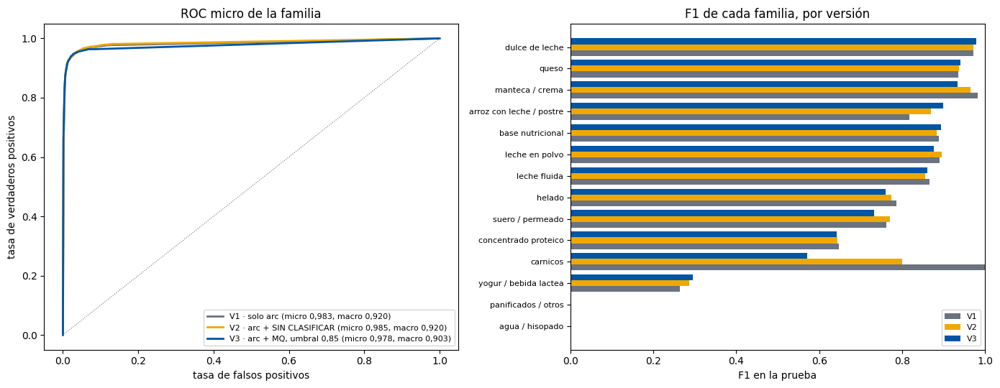

In [163]:
EV = {v: AD.evaluar(E[v][0], D[v].pru) for v in AD.VERSIONES}
ROC = {v: AD.roc_ovr(D[v].pru[FAMILIA], E[v][0]["familia"].predict_proba(D[v].pru[PREDICTORAS]), E[v][0]["familia"].classes_)[0]
       for v in AD.VERSIONES}
filas_v = {}
for v in AD.VERSIONES:
    filas_v[v] = {**EV[v], "familia: AUC macro": ROC[v]["auc_macro"], "familia: AUC micro": ROC[v]["auc_micro"],
                  "muestras de prueba": len(D[v].pru)}
    filas_v[f"{v} original"] = {k: AD.ORIGINAL[v].get(k, np.nan) for k in filas_v[v]}
versiones = pd.DataFrame(filas_v).drop(index="reales → SIN CLASIFICAR (familia real)")
display(versiones.style.format(precision=3, decimal=",", na_rep="—").format("{:.0f}", subset=pd.IndexSlice["muestras de prueba", :], na_rep="—")
        .set_caption("Métricas principales de las tres versiones (sobre su propia prueba) y las del original"))
for v in AD.VERSIONES:
    print(f"{v}: exactitud de familia {coma(EV[v]['familia: exactitud'] * 100, 1)} % (original {coma(AD.ORIGINAL[v]['familia: exactitud'] * 100, 1)} %)")

fig, ejes = plt.subplots(1, 2, figsize=(14, 5.5))
for v in AD.VERSIONES:
    ejes[0].plot(ROC[v]["fpr"], ROC[v]["tpr"], color=COLORES[v], lw=2, label=f"{AD.TITULOS[v]} (micro {coma(ROC[v]['auc_micro'])}, macro {coma(ROC[v]['auc_macro'])})")
ejes[0].plot([0, 1], [0, 1], color=GRIS, lw=0.8, ls=":")
ejes[0].set(xlabel="tasa de falsos positivos", ylabel="tasa de verdaderos positivos", title="ROC micro de la familia")
ejes[0].legend(fontsize=8, loc="lower right")
f1_fam = pd.DataFrame({v: pd.Series({r_: d_["f1-score"] for r_, d_ in classification_report(
    D[v].pru[FAMILIA], E[v][0]["familia"].predict(D[v].pru[PREDICTORAS]), zero_division=0, output_dict=True).items()
    if isinstance(d_, dict) and r_ not in ("macro avg", "weighted avg")}) for v in AD.VERSIONES})
f1_fam = f1_fam.sort_values("V3")
y_ = np.arange(len(f1_fam))
for k, v in enumerate(AD.VERSIONES):
    ejes[1].barh(y_ + (k - 1) * 0.27, f1_fam[v], 0.27, color=COLORES[v], label=v)
ejes[1].set_yticks(y_, f1_fam.index, fontsize=8); ejes[1].set_xlim(0, 1)
ejes[1].set(xlabel="F1 en la prueba", title="F1 de cada familia, por versión"); ejes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

#### Las mismas muestras en las tres versiones

Para comparar muestra por muestra se toman los Identificadores que están en **las tres** pruebas. Están cargadas
hacia las familias grandes, así que sirven para ver **qué cambió**, no para reemplazar las métricas de arriba.
- En el subtipo solo entran las que tienen subtipo real en las tres, es decir, el universo de (b).
- «acierto → SIN CLASIFICAR» cuenta las que la versión nueva dejó sin subtipo.

Muestras de prueba compartidas por las tres versiones: 1456 · con subtipo real en las tres: 745


,V1,V2,V3
familia,"0,920","0,920","0,906"
familia y subtipo (b),"0,718","0,626","0,734"


,V1 → V2,V2 → V3,V1 → V3
acierto → acierto,1335,1302,1302
acierto → error,5,38,38
error → acierto,5,17,17
error → error,111,99,99


,V1 → V2,V2 → V3,V1 → V3
acierto → acierto,441,440,500
acierto → error,94,26,35
error → acierto,25,107,47
error → error,185,172,163
"de esas, acierto → SIN CLASIFICAR",70,8,13


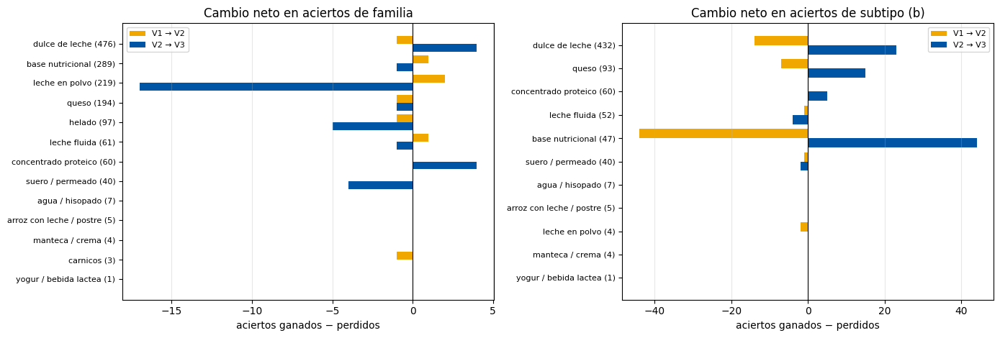

In [164]:
comp = AD.compartidas(T)
print(f"Muestras de prueba compartidas por las tres versiones: {comp.n} · con subtipo real en las tres: {comp.n_b}")
display(comp.exactitud.style.format(precision=3, decimal=",").set_caption("Exactitud sobre las mismas muestras"))
display(comp.familia.style.set_caption("Familia: transiciones entre versiones (muestras compartidas)"))
display(comp.subtipo.style.set_caption("Familia y subtipo (b): transiciones entre versiones"))
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, (nombre, t_) in zip(ejes, comp.neto.items()):
    y_ = np.arange(len(t_))
    ax.barh(y_ - 0.2, t_["V1 → V2"], 0.4, color=COLORES["V2"], label="V1 → V2")
    ax.barh(y_ + 0.2, t_["V2 → V3"], 0.4, color=COLORES["V3"], label="V2 → V3")
    ax.set_yticks(y_, [f"{i} ({n})" for i, n in t_["muestras"].items()], fontsize=8); ax.invert_yaxis()
    ax.axvline(0, color="k", lw=0.8); ax.grid(axis="x", alpha=0.3); ax.legend(fontsize=8)
    ax.set(xlabel="aciertos ganados − perdidos", title=f"Cambio neto en aciertos de {nombre}")
plt.tight_layout(); plt.show()

### 9. ¿Cuánto ayuda partir al azar?

Las tres versiones parten al azar. Pero las muestras de un mismo envío se parecen, porque son el mismo producto en días
seguidos, y al azar caen a los dos lados. En la Parte V (la Parte V (`prediccion_tipo.ipynb`)) la validación se agrupa por envío.

Se toma el árbol de familia de V3, con los mismos parámetros, y se valida en 5 pliegues de dos maneras, sobre todo lo
que modela V3:
- al azar;
- agrupando por envío.

In [165]:
envio, tam_envio, n_envios = AD.por_envio(D3, cf.best_params_)
display(envio.style.format(precision=3, decimal=",").set_caption(f"Árbol de familia de V3, 5 pliegues, {n_envios} envíos"))
caida = envio.loc["al azar (estratificada)", "exactitud"] - envio.loc["agrupada por envío", "exactitud"]
print(f"Agrupando por envío la exactitud baja {coma(caida * 100, 1)} puntos y el F1 macro "
      f"{coma((envio.iloc[0]['F1 macro'] - envio.iloc[1]['F1 macro']) * 100, 1)}.")

,exactitud,F1 macro,exactitud (desvío entre pliegues)
al azar (estratificada),"0,880","0,728","0,003"
agrupada por envío,"0,869","0,689","0,004"


Agrupando por envío la exactitud baja 1,1 puntos y el F1 macro 3,9.


### 10. Las muestras «sin clasificar»

Las muestras de la familia «sin clasificar», de arc y de MQ, no entrenan: acá la cascada de V3 les asigna familia y
subtipo. Para las de arc se muestra la cadena de preguntas del árbol de familia, identificadas por su código de
muestra.

In [166]:
sc_todas = D3.sin_clasificar
pred_sc = AD.predecir_cascada(modelos, sc_todas)
pred_sc_crudo = AD.predecir_cascada(modelos, sc_todas, crudo=True)
print(f"«sin clasificar» predichas: {len(sc_todas)} (arc {(sc_todas['origen'] == 'arc').sum()} · MQ {(sc_todas['origen'] == 'MQ').sum()}) · "
      f"subtipo {SC}: sin umbral {(pred_sc_crudo['subtipo predicho'] == SC).sum()} → con umbral {(pred_sc['subtipo predicho'] == SC).sum()}")
display(pd.crosstab(pred_sc["familia predicha"], sc_todas["origen"], margins=True, margins_name="total")
        .sort_values("total", ascending=False).style.set_caption("Familia que la cascada da a las muestras «sin clasificar», por origen"))
display(pd.concat([sc_todas["origen"], pred_sc[["familia predicha", "subtipo predicho"]].fillna("—")], axis=1)
        .value_counts().head(15).rename("muestras").to_frame().style.set_caption("Las 15 combinaciones familia / subtipo más frecuentes"))
sc_arc = sc_todas[sc_todas["origen"] == "arc"]
display(pd.concat([sc_arc[["Identificador"] + PREDICTORAS], pred_sc.loc[sc_arc.index]], axis=1).set_index("Identificador")
        .style.format(precision=2, decimal=",", na_rep="—").set_caption(f"Las {len(sc_arc)} «sin clasificar» de arc, con lo que les da la cascada"))
for idx in sc_arc.index:
    pasos, hoja, cuentas = AD.camino(arbol_familia, sc_arc.loc[[idx]])
    print(f"{sc_arc.loc[idx, 'Identificador']} → {pred_sc.loc[idx, 'familia predicha']} / {pred_sc.loc[idx, 'subtipo predicho'] or '—'}")
    print("   " + " → ".join(pasos))
    print(f"   hoja {hoja}: " + ", ".join(f"{k} {v}" for k, v in cuentas.head(4).items()))

«sin clasificar» predichas: 1026 (arc 9 · MQ 1017) · subtipo SIN CLASIFICAR: sin umbral 433 → con umbral 405


origen,MQ,arc,total
familia predicha,,,
total,1017,9,1026
leche en polvo,170,0,170
suero / permeado,150,1,151
panificados / otros,145,0,145
carnicos,130,0,130
base nutricional,106,1,107
queso,77,2,79
manteca / crema,77,0,77
leche fluida,47,2,49


,humedad,grasa,proteinas,cenizas,solidos_totales,lactosa,galactosa,familia predicha,p̂ familia,subtipo predicho,p̂ subtipo
Identificador,,,,,,,,,,,
MO-03608-01,"88,57","2,92",—,—,"11,43",—,—,leche fluida,"1,00",UAT,"1,00"
MO-03609-01,"64,26","14,38",—,—,"35,74",—,—,queso,"1,00",SIN CLASIFICAR,"1,00"
MQ-17885-01,—,—,—,—,—,"5,21","0,00",helado,"1,00",—,—
MQ-25645-01,—,—,—,—,—,"0,11","1,79",queso,"0,67",QUESO CREMA,"1,00"
MQ-29372-01,—,—,—,—,—,"5,45",—,leche fluida,"0,88",SIN CLASIFICAR,"1,00"
MQ-40250-01,—,—,—,—,—,"16,28","0,32",suero / permeado,"0,60",WPC,"0,67"
MQ-40250-02,—,—,—,—,—,"0,68","0,00",helado,"0,62",—,—
MQ-40469-01,—,—,—,—,—,"0,00",—,base nutricional,"0,84",CASEINATOS,"0,21"
MQ-41207-01,—,—,—,—,—,"0,65","0,00",helado,"0,56",—,—


MO-03608-01 → leche fluida / UAT
   ¿humedad ≤ 30,59? 88,57: no → ¿humedad ≤ 77,10? 88,57: no → ¿humedad ≤ 87,33? 88,57: no → ¿solidos_totales ≤ 9,01? 11,43: no → ¿cenizas ≤ 0,75? no medido: no → ¿grasa ≤ 0,30? 2,92: no → ¿cenizas ≤ 0,92? no medido: sí
   hoja 2203: leche fluida 142
MO-03609-01 → queso / SIN CLASIFICAR
   ¿humedad ≤ 30,59? 64,26: no → ¿humedad ≤ 77,10? 64,26: sí → ¿grasa ≤ 8,53? 14,38: no → ¿grasa ≤ 36,89? 14,38: sí → ¿grasa ≤ 13,24? 14,38: no → ¿solidos_totales ≤ 25,66? 35,74: no → ¿grasa ≤ 34,76? 14,38: sí → ¿solidos_totales ≤ 30,59? 35,74: no → ¿grasa ≤ 15,03? 14,38: sí → ¿humedad ≤ 61,85? 64,26: no
   hoja 2084: queso 90
MQ-17885-01 → helado / —
   ¿humedad ≤ 30,59? no medido: sí → ¿solidos_totales ≤ 79,92? no medido: no → ¿lactosa ≤ 8,88? 5,21: sí → ¿galactosa ≤ 1,20? 0,00: sí → ¿lactosa ≤ 0,45? 5,21: no → ¿galactosa ≤ 0,13? 0,00: sí → ¿lactosa ≤ 6,73? 5,21: sí → ¿lactosa ≤ 1,34? 5,21: no → ¿galactosa ≤ 0,04? 0,00: sí → ¿lactosa ≤ 4,87? 5,21: no → ¿lactosa ≤ 6,42?

### 11. Guardar el modelo

Se guarda la cascada de V3 en `resultados/modelos/arbol_decision.joblib`, que es lo que carga la aplicación. Después se
comprueba que, al cargarla, da las mismas predicciones.

In [167]:
modelos["version"] = "V3"
ruta_modelo = AD.guardar(modelos)
cargado = joblib.load(ruta_modelo)
iguales = AD.predecir_cascada(cargado, pru).fillna("—").equals(AD.predecir_cascada(modelos, pru).fillna("—"))
print(f"Modelo guardado: {ruta_modelo.relative_to(ruta_modelo.parents[2]).as_posix()} · mismas predicciones tras guardar y cargar: {iguales}")

Modelo guardado: resultados/modelos/arbol_decision.joblib · mismas predicciones tras guardar y cargar: True


### Datos usados en cada entrenamiento

Una fila por cada árbol de familia, con las mismas columnas que en las otras partes.
- **V3:** además, una fila por cada árbol de subtipo.
- **V1, V2 y la cascada de solo arc de la sección 7:** los árboles de subtipo van en una sola fila por versión.

Entrenamiento y prueba son los de la partición 80 / 20. La validación cruzada de 5 pliegues se hace dentro del
entrenamiento y solo sirve para elegir los parámetros.

In [168]:
def miles(n):
    return f"{int(n):,}".replace(",", ".")

PARTICION = "80 / 20 al azar, estratificada por familia y subtipo (solo arc); 5 pliegues dentro del entrenamiento para elegir parámetros"
filas = []
for v in AD.VERSIONES:
    d, (m, b, p) = D[v], E[v]
    origenes = [o for o in ["arc", "MQ"] if o in d.conteos.columns]
    motivos = [f"{i.lstrip('− ').rsplit(' (', 1)[0]}: {miles(d.conteos.loc[i, origenes].sum())}"
               for i in d.conteos.index[1:-1] if d.conteos.loc[i, origenes].sum() > 0]
    motivos.append(f"familia «sin clasificar» (se predice al final): {miles(len(d.sin_clasificar))}")
    filas.append(DE.fila(
        parte="VII", modelo=f"{v}: árbol de familia", datos="arc" + (" + MQ nuevas" if v == "V3" else ""),
        disponibles=d.disponibles, usadas=len(d.modelado), motivo="; ".join(motivos), entrenamiento=len(d.ent), prueba=len(d.pru),
        particion=PARTICION, nota=("MQ entero va al entrenamiento; la prueba es solo de arc" if v == "V3" else "")))
    arboles = [f for f, e in m["subtipo"].items() if e["tipo"] == "árbol"]
    if v == "V3":
        for f in arboles:
            y = AD.y_subtipo(d.ent, f, v)
            en_pru = (d.pru[FAMILIA] == f) & d.pru[AGRUPADO].notna()
            filas.append(DE.fila(
                parte="VII", modelo=f"V3: árbol de subtipo · {f}", datos=f"muestras de {f} (arc + MQ)",
                disponibles=(d.modelado[FAMILIA] == f).sum(), usadas=len(y) + en_pru.sum(), entrenamiento=len(y), prueba=en_pru.sum(),
                particion=PARTICION, nota=f"incluye la clase {SC} ({int((y == SC).sum())} de entrenamiento)"))
    else:
        y_tot = sum(len(AD.y_subtipo(d.ent, f, v)) for f in arboles)
        p_tot = int(((d.pru[FAMILIA].isin(arboles)) & d.pru[AGRUPADO].notna()).sum())
        disp = int(d.modelado[FAMILIA].isin(arboles).sum())
        filas.append(DE.fila(
            parte="VII", modelo=f"{v}: {len(arboles)} árboles de subtipo (uno por familia)", datos="muestras de esas familias (arc)",
            disponibles=disp, usadas=y_tot + p_tot, entrenamiento=y_tot, prueba=p_tot, particion=PARTICION,
            motivo=("sin subtipo; en el entrenamiento, clases con menos de 5 muestras" if v == "V1" else ""),
            nota=("" if v == "V1" else f"incluye la clase {SC}")))
arboles_sa = [f for f, e in modelos_solo_arc["subtipo"].items() if e["tipo"] == "árbol"]
filas.append(DE.fila(parte="VII", modelo="V3 solo arc (sección 7): árbol de familia", datos="arc, con los filtros de V3",
                     disponibles=len(D3.muestras), usadas=len(D3.muestras), entrenamiento=len(D3.ent_arc), prueba=len(pru),
                     particion=PARTICION, nota="solo para comparar: no se guarda"))
y_sa = sum(len(AD.y_subtipo(D3.ent_arc, f, "V3")) for f in arboles_sa)
p_sa = int((pru[FAMILIA].isin(arboles_sa) & pru[AGRUPADO].notna()).sum())
filas.append(DE.fila(parte="VII", modelo=f"V3 solo arc (sección 7): {len(arboles_sa)} árboles de subtipo", datos="muestras de esas familias (arc)",
                     disponibles=int(D3.muestras[FAMILIA].isin(arboles_sa).sum()), usadas=y_sa + p_sa, entrenamiento=y_sa, prueba=p_sa,
                     particion=PARTICION, nota="solo para comparar: no se guarda"))
for nombre in envio.index:
    filas.append(DE.fila(parte="VII", modelo=f"comprobación: árbol de familia de V3, validación {nombre}", datos="arc + MQ nuevas (lo que modela V3)",
                         disponibles=len(D3.modelado), usadas=len(D3.modelado),
                         entrenamiento=round(np.mean([a for a, _ in tam_envio[nombre]])),
                         prueba=len(D3.modelado) - round(np.mean([a for a, _ in tam_envio[nombre]])),
                         particion=f"validación cruzada de 5 pliegues {nombre}", nota="entrenamiento y prueba son el promedio por pliegue"))
with pd.option_context("display.max_colwidth", 120):
    display(DE.guardar(filas, "arbol_decision"))

,parte,modelo,datos,disponibles,excluidas,motivo de exclusión,usadas,entrenamiento,validación,prueba,partición,nota
0,VII,V1: árbol de familia,arc,16347,1222,sin ningún análisis: 1.143; atípica o excluida por humedad y sólidos: 70; familia «sin clasificar» (se predice al fi...,15125,12100,<NA>,3025,"80 / 20 al azar, estratificada por familia y subtipo (solo arc); 5 pliegues dentro del entrenamiento para elegir par...",
1,VII,V1: 10 árboles de subtipo (uno por familia),muestras de esas familias (arc),14278,5128,"sin subtipo; en el entrenamiento, clases con menos de 5 muestras",9150,7320,<NA>,1830,"80 / 20 al azar, estratificada por familia y subtipo (solo arc); 5 pliegues dentro del entrenamiento para elegir par...",
2,VII,V2: árbol de familia,arc,16347,1222,sin ningún análisis: 1.143; atípica o excluida por humedad y sólidos: 70; familia «sin clasificar» (se predice al fi...,15125,12100,<NA>,3025,"80 / 20 al azar, estratificada por familia y subtipo (solo arc); 5 pliegues dentro del entrenamiento para elegir par...",
3,VII,V2: 10 árboles de subtipo (uno por familia),muestras de esas familias (arc),14278,0,,14278,11423,<NA>,2855,"80 / 20 al azar, estratificada por familia y subtipo (solo arc); 5 pliegues dentro del entrenamiento para elegir par...",incluye la clase SIN CLASIFICAR
4,VII,V3: árbol de familia,arc + MQ nuevas,30089,5903,sin ningún análisis: 3.045; atípica o excluida por humedad y sólidos: 70; R1 control de laboratorio: 249; R2 cliente...,24186,21185,<NA>,3001,"80 / 20 al azar, estratificada por familia y subtipo (solo arc); 5 pliegues dentro del entrenamiento para elegir par...",MQ entero va al entrenamiento; la prueba es solo de arc
5,VII,V3: árbol de subtipo · agua / hisopado,muestras de agua / hisopado (arc + MQ),88,0,,88,72,<NA>,16,"80 / 20 al azar, estratificada por familia y subtipo (solo arc); 5 pliegues dentro del entrenamiento para elegir par...",incluye la clase SIN CLASIFICAR (13 de entrenamiento)
6,VII,V3: árbol de subtipo · arroz con leche / postre,muestras de arroz con leche / postre (arc + MQ),108,0,,108,97,<NA>,11,"80 / 20 al azar, estratificada por familia y subtipo (solo arc); 5 pliegues dentro del entrenamiento para elegir par...",incluye la clase SIN CLASIFICAR (4 de entrenamiento)
7,VII,V3: árbol de subtipo · base nutricional,muestras de base nutricional (arc + MQ),1610,0,,1610,1316,<NA>,294,"80 / 20 al azar, estratificada por familia y subtipo (solo arc); 5 pliegues dentro del entrenamiento para elegir par...",incluye la clase SIN CLASIFICAR (1105 de entrenamiento)
8,VII,V3: árbol de subtipo · concentrado proteico,muestras de concentrado proteico (arc + MQ),847,0,,847,719,<NA>,128,"80 / 20 al azar, estratificada por familia y subtipo (solo arc); 5 pliegues dentro del entrenamiento para elegir par...",incluye la clase SIN CLASIFICAR (48 de entrenamiento)
9,VII,V3: árbol de subtipo · dulce de leche,muestras de dulce de leche (arc + MQ),3825,0,,3825,3082,<NA>,743,"80 / 20 al azar, estratificada por familia y subtipo (solo arc); 5 pliegues dentro del entrenamiento para elegir par...",incluye la clase SIN CLASIFICAR (777 de entrenamiento)


### Lectura

**La familia sale bien con un solo árbol.**
- V3 acierta la familia en 8,9 de cada 10 muestras de prueba (exactitud 0,889, contra 0,257 de la línea de base);
  F1 macro 0,67; AUC macro 0,90 y micro 0,98.
- El árbol elegido es profundo: sin límite de profundidad y con 5 muestras por hoja como mínimo, llega a 37 niveles y
  unas 1 100 hojas. La primera pregunta es la humedad (≤ 30,6 %).
- Se acierta muy bien dulce de leche (F1 0,98), queso (0,94) y manteca / crema (0,93).
- Fallan las familias chicas o con pocos análisis: agua / hisopado y panificados no se aciertan nunca, y yogur tiene
  un F1 de 0,29.

**El subtipo es lo difícil.**
- De punta a punta, con el umbral de 0,85, familia y subtipo salen bien en el 65 % de las muestras con subtipo real
  (b), y en el 57 % si se cuenta SIN CLASIFICAR (a).
- Con la familia real serían 73 % y 64 %: los errores del primer nivel cuestan unos 7 u 8 puntos.
- Va bien en base nutricional (94 %), manteca / crema (93 %), leche fluida (81 %) y dulce de leche (80 %).
- Va mal en queso (50 %), suero / permeado (41 %), leche en polvo (29 %) y yogur (12 %). Son subtipos que no se
  distinguen por la composición.

**El umbral es un intercambio.** Sin umbral, el 19 % de las muestras con subtipo real recibe SIN CLASIFICAR; con 0,85,
el 5,6 %. Eso sube (b) del 58 % al 65 % y baja (a) del 63 % al 57 %.

**Sumar MQ no mejora la familia en arc.** Sobre la misma prueba, la cascada de solo arc acierta 0,898 y la de arc + MQ
0,889 (F1 macro 0,70 contra 0,67).
- MQ ayuda en el subtipo de concentrado proteico (F1 0,82 → 0,89) y de suero / permeado (0,41 → 0,47).
- Empeora el de manteca / crema (0,49 → 0,33), donde MQ suma CREMA, que la prueba de arc no tiene.

**Contra los números del compañero (semilla 2026).** La exactitud de familia da 89,3 / 89,2 / 88,9 % para V1 / V2 / V3,
contra 88,5 / 88,9 / 89,6 % en la diapositiva 6.
- Todas las diferencias son menores que un punto. Una prueba de 3 000 muestras tiene un error estándar de unos
  0,6 puntos, y con otra semilla la prueba es otra.
- En V3, además, el archivo de MQ no es el mismo: el filtro de errores de carga encuentra 3 filas y no 10.
- Las conclusiones no cambian:
  - V2 pierde en (b) porque usa SIN CLASIFICAR como refugio (18 % de las reales);
  - V3 recupera buena parte con el umbral, aunque queda por debajo de V1 en (b) (0,651 contra 0,666);
  - sobre las 1 456 muestras que están en las tres pruebas, V3 es la mejor en el subtipo (0,73 contra 0,72 y 0,63).

**La partición al azar casi no infla la familia.** Agrupando por envío, la exactitud del árbol de familia baja apenas
1,1 puntos (0,880 → 0,869). La diferencia con el ~79 % de la Parte V (la Parte V (`prediccion_tipo.ipynb`)) no viene de la
partición. Las dos partes usan muestras, filtros y familias distintas, y otro modelo.

**Las «sin clasificar».** Las 1 026 muestras (9 de arc) reciben una familia; 405 se quedan sin subtipo, porque
SIN CLASIFICAR supera el umbral.

Modelo: `resultados/modelos/arbol_decision.joblib`, con `AD.predecir_cascada(joblib.load(...), X)` sobre las 7
columnas de `AD.PREDICTORAS`. Lo usa `app_arbol.py`.

In [169]:
assert set(D3.modelado["Cliente"].dropna().astype(str).str.match(r"^IND-\d+$")) <= {True}
assert "Descripción" not in D3.modelado.columns and "Descripción" not in D3.sin_clasificar.columns
assert AD.SALIDA_MODELO.exists() and (DE.CARPETA / "arbol_decision.csv").exists() and iguales
assert not set(D3.pru.index) & set(D3.ent.index) and (D3.pru["origen"] == "arc").all()
print(f"Verificación: todo en orden · la parte tardó {coma((time.time() - inicio) / 60, 1)} min")

Verificación: todo en orden · la parte tardó 0,9 min


### La aplicación, desde el cuaderno
La celda siguiente escribe `app_arbol.py` (¿qué producto es esta muestra?, con la cascada de V3 y la cadena de preguntas de cada
árbol). La de después la abre en http://localhost:8501.

Streamlit no corre adentro de una celda: es un programa aparte, y mientras está abierto el kernel queda ocupado.
Para abrirla cambiá `ABRIR_APP = True` y ejecutá la celda; para cerrarla, interrumpí el kernel (■). También se abre
desde una terminal, en la carpeta `trabajo_senasa_mq`: `../.venv/bin/streamlit run app_arbol.py`.

In [170]:
%%writefile app_arbol.py
# Trabajo Senasa + MQ · ¿qué producto es esta muestra? · aplicación Streamlit (Parte VII)
# Carga la cascada de árboles de decisión de V3 (familia → subtipo, src/arbol_decision.py) y clasifica una muestra
# por su composición. El modelo lo guarda arbol_decision.ipynb en resultados/modelos/arbol_decision.joblib.
# Para abrirla, desde la carpeta trabajo_senasa_mq:  ../.venv/bin/streamlit run app_arbol.py
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import streamlit as st

AQUI = Path(__file__).resolve().parent
sys.path.insert(0, str(AQUI / "src"))
import arbol_decision as AD  # noqa: E402

AZUL, GRIS, ROJO = "#0055a5", "#6b7280", "#c0392b"
NOMBRES = {"humedad": "Humedad (%)", "grasa": "Grasa (%)", "proteinas": "Proteínas (%)", "cenizas": "Cenizas (%)",
           "solidos_totales": "Sólidos totales (%)", "lactosa": "Lactosa (%)", "galactosa": "Galactosa (%)"}
coma = AD.coma

st.set_page_config(page_title="¿Qué producto es esta muestra?", layout="centered")
st.title("¿Qué producto es esta muestra?")
st.caption("Árbol de decisión en cascada sobre las muestras de Senasa y MQ: un árbol predice la familia y, "
           "dentro de la familia, otro árbol predice el subtipo. Solo con los análisis de laboratorio.")


@st.cache_resource
def cargar(ruta):
    return joblib.load(ruta)


if not AD.SALIDA_MODELO.exists():
    st.error(f"Falta {AD.SALIDA_MODELO.name}. Ejecutá antes arbol_decision.ipynb, que lo genera.")
    st.stop()
modelos = cargar(AD.SALIDA_MODELO)
PREDICTORAS = modelos["predictoras"]
arbol_familia = modelos["familia"]
SC = modelos["subtipo_sin_clasificar"]
UMBRAL = float(modelos["umbral_sin_clasificar"])

# ---------- 1 · Los análisis de la muestra ----------
st.subheader("Análisis de la muestra")
st.write("Cada análisis tiene su casilla «no medido»: si se marca, el valor queda vacío (NaN) y el árbol lo manda "
         "hacia el lado que aprendió para los faltantes. No se imputa nada.")
valores = {}
for col in PREDICTORAS:
    c1, c2 = st.columns([3, 1])
    no_medido = c2.checkbox("no medido", key=f"nm_{col}", value=pd.isna(modelos["medianas"][col]))
    inicial = modelos["medianas"][col]
    v = c1.number_input(NOMBRES.get(col, col), min_value=0.0, max_value=100.0, step=0.1,
                        value=0.0 if pd.isna(inicial) else float(round(inicial, 2)), disabled=no_medido, key=f"v_{col}")
    valores[col] = np.nan if no_medido else v
fila = pd.DataFrame([valores])[PREDICTORAS]
if fila.isna().all(axis=1).iloc[0]:
    st.warning("No hay ningún análisis medido: el árbol igual responde, pero solo con la regla para faltantes.")


# ---------- 2 · La predicción de los dos niveles ----------
def barras(probs, titulo, elegido):
    probs = probs.sort_values(ascending=False).head(8)
    fig, ax = plt.subplots(figsize=(8, 0.6 + 0.45 * len(probs)))
    ax.barh(probs.index, probs.values, color=[ROJO if k == elegido else GRIS if k == SC else AZUL for k in probs.index])
    for k, p in enumerate(probs.values):
        ax.text(min(p + 0.01, 0.9), k, coma(p), va="center")
    ax.set_xlim(0, 1); ax.set_xlabel("probabilidad"); ax.invert_yaxis(); ax.set_title(titulo)
    plt.tight_layout()
    return fig


st.subheader("Predicción")
p_familia = pd.Series(arbol_familia.predict_proba(fila)[0], index=arbol_familia.classes_)
familia = arbol_familia.predict(fila)[0]
entrada = modelos["subtipo"][familia]
if entrada["tipo"] == "árbol":
    p_subtipo = pd.Series(entrada["modelo"].predict_proba(fila)[0], index=entrada["modelo"].classes_)
elif entrada["tipo"] == "constante":
    p_subtipo = pd.Series(entrada["probabilidades"])
else:
    p_subtipo = None
hoja_dice = None if p_subtipo is None else p_subtipo.idxmax()          # lo que dice la hoja (puede ser SIN CLASIFICAR)
subtipo = AD.predecir_subtipo(entrada, fila, UMBRAL)[0][0]             # con el umbral: la predicción que se muestra
p_sc = float(p_subtipo[SC]) if p_subtipo is not None and SC in p_subtipo.index else None
reales = p_subtipo.drop(SC) if p_sc is not None else None

c1, c2 = st.columns(2)
c1.metric("Familia", familia, f"{coma(p_familia[familia] * 100, 1)} %", delta_color="off")
if subtipo is None:
    c2.metric("Subtipo", "—")
    c2.info(f"**La familia no tiene subtipos** ({entrada.get('motivo', 'la familia no tiene subtipos')}): "
            "la cascada termina en la familia.")
elif subtipo == SC:
    c2.metric("Subtipo", "sin clasificar", f"{coma(p_subtipo[subtipo] * 100, 1)} %", delta_color="off")
    c2.warning("**Sin clasificar: el modelo no asigna subtipo.** La muestra se parece más a las de la familia "
               "que se cargaron sin subtipo que a cualquier subtipo real.")
    if len(reales) and reales.max() > 0:
        c2.caption(f"Subtipo real más probable: {reales.idxmax()} ({coma(reales.max() * 100, 1)} %).")
else:
    c2.metric("Subtipo", subtipo, f"{coma(p_subtipo[subtipo] * 100, 1)} %", delta_color="off")
    if p_sc is not None:
        c2.caption(f"Probabilidad de SIN CLASIFICAR: {coma(p_sc * 100, 1)} % (por debajo del umbral, así que se muestra el subtipo real).")
    if entrada["tipo"] == "constante":
        c2.caption("Para esta familia no hay árbol de subtipo: se predice el más común.")
    if subtipo == "OTRO":
        c2.caption(f"«OTRO» agrupa los subtipos con menos de {modelos['minimo_subtipo']} muestras en la familia.")
if p_sc is not None:
    st.caption(f"Umbral de «sin clasificar»: {coma(UMBRAL * 100, 0)} %. Solo se muestra «sin clasificar» si la probabilidad "
               f"de SIN CLASIFICAR llega a ese valor; si no, se muestra el subtipo real más probable.")
st.pyplot(barras(p_familia, "Primer nivel: probabilidad de cada familia (rojo: la elegida)", familia))
if p_subtipo is not None:
    st.pyplot(barras(p_subtipo, f"Segundo nivel ({familia}): probabilidad de cada subtipo", subtipo))
    if SC in p_subtipo.index:
        st.caption(f"«{SC}» (gris si no es la elegida) no es un subtipo: reúne las muestras de la familia "
                   "que llegaron sin subtipo.")
else:
    st.write(f"Segundo nivel: «{familia}» no tiene subtipos, no hay probabilidades de subtipo.")
st.write("Los árboles responden en escalones: la probabilidad no cambia hasta que un valor cruza el corte de alguna "
         "pregunta, y entonces salta.")


# ---------- 3 · Por qué: la cadena de preguntas de cada árbol ----------
def explicar(arbol, que):
    pasos, hoja, cuentas = AD.camino(arbol, fila)
    st.markdown("\n".join(f"1. {p}" for p in pasos))
    st.write(f"Llega a la hoja {hoja}: de las **{cuentas.sum()}** muestras de entrenamiento que respondieron igual, "
             + ", ".join(f"**{v}** eran {k}" for k, v in cuentas.head(5).items())
             + f". {len(pasos)} preguntas, de {arbol.get_depth()} posibles en el árbol de {que}.")


st.subheader("Por qué")
pestanas = st.tabs(["árbol de familia", "árbol de subtipo"])
with pestanas[0]:
    explicar(arbol_familia, "familia")
with pestanas[1]:
    if entrada["tipo"] == "árbol":
        explicar(entrada["modelo"], f"subtipo de {familia}")
        if hoja_dice == SC and subtipo == SC:
            st.write(f"Esa hoja asigna «{SC}» y su probabilidad ({coma(p_sc * 100, 1)} %) llega al umbral "
                     f"({coma(UMBRAL * 100, 0)} %): el modelo no asigna subtipo.")
        elif hoja_dice == SC:
            st.write(f"Ojo: esa hoja asigna «{SC}», pero su probabilidad ({coma(p_sc * 100, 1)} %) no llega al "
                     f"umbral ({coma(UMBRAL * 100, 0)} %). Por eso la predicción mostrada es el subtipo real más probable, "
                     f"**{subtipo}**. El camino de preguntas es el del árbol; la decisión final la toma el umbral.")
    elif entrada["tipo"] == "constante":
        st.write(f"No hay árbol: en «{familia}» se predice siempre **{subtipo}**. Proporciones del entrenamiento: "
                 + ", ".join(f"{k} {coma(v * 100, 1)} %" for k, v in p_subtipo.items()) + ".")
    else:
        st.write(f"«{familia}»: {entrada.get('motivo', 'la familia no tiene subtipos')}. No hay segundo nivel.")

with st.expander("Ver la fila que reciben los modelos"):
    st.dataframe(fila)

Overwriting app_arbol.py


In [171]:
import sys
ABRIR_APP = False   # True para abrirla (bloquea el kernel hasta interrumpirlo)
if ABRIR_APP:
    print("Abrir http://localhost:8501 en el navegador. Para cortarla: interrumpir el kernel (■).")
    !"{sys.executable}" -m streamlit run app_arbol.py --server.headless true
else:
    print("App escrita en app_arbol.py. Para abrirla: ABRIR_APP = True y volver a ejecutar esta celda.")

App escrita en app_arbol.py. Para abrirla: ABRIR_APP = True y volver a ejecutar esta celda.


<a id="parte-viii"></a>

# Parte VIII · Leche cruda y temperatura de Rafaela

La relación de la leche cruda con la temperatura, mirada directamente: cada parámetro en el tiempo, rectas por industria-día, linealidad, anomalías y desfase de una semana; células somáticas y recuento bacteriano.

*(Generada a partir de `temperatura_leche_cruda.ipynb`.)*

## Leche cruda y temperatura de Rafaela

**Qué es.** Las Partes III y IV usan la temperatura dentro de un modelo: el ciclo anual de la proteína y la grasa, y
la probabilidad de superar los umbrales de calidad. Esta parte mira la relación directamente, antes de modelar: a cada
medición de leche cruda se le suma la temperatura de Rafaela **del mismo día** y se pregunta cuánto se parecen, si
la relación es lineal, si sobrevive al calendario y con qué ventana de días responde la leche.

**Las preguntas, en orden.**
1. Cada parámetro de la leche cruda y la temperatura en el tiempo, con el mismo eje.
2. Grasa, proteína y sólidos totales contra la temperatura: rectas por mínimos cuadrados, por industria-día.
3. ¿Es lineal? ¿Mejora al promediar la temperatura de varios días? ¿Sobrevive al restar el mes (anomalías)?
4. ¿La leche se parece más a la temperatura de la semana anterior? (desfase de una semana)
5. Células somáticas (RCS) y recuento bacteriano (RBT) contra la temperatura, con el umbral de la Parte IV.

**Datos.**
- **Leche cruda**: `../datos/leche_cruda.csv` (`R.LECHE_CRUDA`; las industrias ya van como `IND-nn`). `fecha`
  es la del informe y `fecha_origen` dice de dónde salió: `nombre` y `contenido` son la fecha escrita en el
  archivo; `creación` es la fecha de creación del archivo, que coincide con la real dentro de ±3 días en el
  89% de los casos.
- **Temperatura**: `datos_entrada/temperatura_rafaela.csv` (`R.TEMPERATURA`), NASA POWER diaria (`t_media` es
  T2M, la media de 24 h; validada contra la estación SMN Rafaela, r = 0,98).
  Las precipitaciones quedan fuera de este cuaderno: a diferencia de la temperatura, la serie de NASA POWER no se
  validó contra el SMN.
- **Recuentos**: células somáticas (RCS) y recuento bacteriano (RBT) se corrigen con las mismas reglas que la
  regresión logística (`src/logistica_leche.py`): el RBT de IND-59 desde mayo de 2024 viene en otra unidad y se
  descarta, y unos pocos RCS redondos de esa industria, que parecen un RBT mal ubicado, también.
- **Confidencialidad**: `archivo` (el nombre del archivo del informe) es texto libre. Se reemplaza al cargar por
  `informe`, un identificador (`INF-nnnnn`) numerado por (cliente, fecha, archivo), y la columna se descarta.
- **Salida**: gráficos en `resultados/temperatura_leche_cruda/`.

In [172]:
import sys
from pathlib import Path
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "rutas.py").exists()) / "src"
sys.path.insert(0, str(SRC))

import time
import numpy as np
import pandas as pd
from IPython.display import display

import datos_entrenamiento as DE
import logistica_leche as L
import rutas as R

inicio = time.time()
RAIZ = R.RAIZ
SALIDA_DIR = R.RESULTADOS / "temperatura_leche_cruda"
SALIDA_DIR.mkdir(parents=True, exist_ok=True)

leche = pd.read_csv(R.LECHE_CRUDA, encoding="utf-8-sig", low_memory=False, parse_dates=["fecha"])
temp = pd.read_csv(R.TEMPERATURA, encoding="utf-8-sig", parse_dates=["fecha"])
N_ARCHIVO = len(leche)

# `archivo` es texto libre: se reemplaza por un identificador del informe y se descarta
# (numerado por cliente, fecha y archivo; el mismo nombre de archivo aparece en varios clientes)
orden = leche[["cliente", "fecha", "archivo"]].drop_duplicates().sort_values(["cliente", "fecha", "archivo"])
informe = pd.Series([f"INF-{i:05d}" for i in range(1, len(orden) + 1)], index=pd.MultiIndex.from_frame(orden))
leche.insert(1, "informe", informe.reindex(pd.MultiIndex.from_frame(leche[["cliente", "fecha", "archivo"]])).to_numpy())
leche = leche.drop(columns="archivo")
assert leche["informe"].notna().all() and "archivo" not in leche.columns
print(f"informes: {leche['informe'].nunique():,} · industrias: {leche['cliente'].nunique()}")

# Recuentos: las mismas reglas que L.cargar_leche (la regresión logística, Parte IV)
c = L.CAMBIO_UNIDAD_RBT
de_ind = leche["cliente"] == c["cliente"]
en_ufc = de_ind & (leche["fecha"] >= c["desde"]) & (leche["rbt"] >= c["minimo_en_ufc"])
tras = de_ind & (leche["fecha"] >= c["descartar_desde"])
raros = (de_ind & (leche["fecha"] >= pd.Timestamp("2024-06-01"))
         & (leche["celulas_somaticas"] >= 2000) & (leche["celulas_somaticas"] % 1000 == 0))
print(f"RBT descartados de {c['cliente']}: {int(((en_ufc | tras) & leche['rbt'].notna()).sum())} "
      f"(en UFC/mL: {int(en_ufc.sum())}) · RCS descartados: {int(raros.sum())}")
leche.loc[en_ufc | tras, "rbt"] = np.nan
leche.loc[raros, "celulas_somaticas"] = np.nan

print("leche cruda:", leche.shape, "|", leche["fecha"].min().date(), "->", leche["fecha"].max().date(),
      "| fechas nulas:", int(leche["fecha"].isna().sum()))
print("temperatura:", temp.shape, "|", temp["fecha"].min().date(), "->", temp["fecha"].max().date())
dias = pd.date_range(temp["fecha"].min(), temp["fecha"].max())
print("días faltantes en la serie:", len(dias) - temp["fecha"].nunique(),
      "| días sin valor:", temp.loc[temp["t_media"].isna(), "fecha"].dt.date.tolist())
assert temp["fecha"].is_unique

informes: 21,117 · industrias: 10
RBT descartados de IND-59: 21215 (en UFC/mL: 21093) · RCS descartados: 6
leche cruda: (628035, 22) | 2015-09-22 -> 2026-09-07 | fechas nulas: 0
temperatura: (4307, 4) | 2015-01-01 -> 2026-10-16
días faltantes en la serie: 0 | días sin valor: [datetime.date(2026, 10, 13), datetime.date(2026, 10, 14), datetime.date(2026, 10, 15), datetime.date(2026, 10, 16)]


### Unión por fecha

La fecha de la leche cruda es solo día (sin hora), igual que la de la temperatura, así que la unión es exacta
por día. Se verifica que no se duplique ninguna medición.

In [173]:
assert (leche["fecha"] == leche["fecha"].dt.normalize()).all()
cruce = leche.merge(temp[["fecha", "t_media", "t_max", "t_min"]], on="fecha", how="left", validate="many_to_one")
assert len(cruce) == len(leche)

con_t = cruce["t_media"].notna()
print(f"mediciones con temperatura: {int(con_t.sum()):,} de {len(cruce):,} ({100 * con_t.mean():.1f}%)")
sin_t = cruce.loc[~con_t, "fecha"]
fuera = pd.cut(sin_t, [pd.Timestamp.min, temp["fecha"].min() - pd.Timedelta(days=1), temp["fecha"].max(), pd.Timestamp.max],
               labels=["antes de la serie", "dentro (día sin valor)", "después de la serie"])
print("sin temperatura, por motivo:")
print(fuera.value_counts().to_string())
print("\nsin temperatura, por año:")
print(sin_t.dt.year.value_counts().sort_index().to_string())

mediciones con temperatura: 628,035 de 628,035 (100.0%)
sin temperatura, por motivo:
fecha
antes de la serie         0
dentro (día sin valor)    0
después de la serie       0

sin temperatura, por año:
Series([], )


In [174]:
# cobertura por industria y por origen de la fecha
comp = ["grasa", "proteina", "lactosa", "solidos_totales", "celulas_somaticas", "crioscopia"]
cruce["con_composicion"] = cruce[comp].notna().any(axis=1)
por_ind = cruce.groupby("cliente").agg(
    mediciones=("fecha", "size"),
    con_temperatura=("t_media", lambda s: int(s.notna().sum())),
    con_composicion_y_temperatura=("t_media", lambda s: int((s.notna() & cruce.loc[s.index, "con_composicion"]).sum())),
    desde=("fecha", "min"), hasta=("fecha", "max"))
por_ind["desde"], por_ind["hasta"] = por_ind["desde"].dt.date, por_ind["hasta"].dt.date
print(por_ind.to_string())
print()
print(cruce.groupby("fecha_origen")["t_media"].agg(mediciones="size", con_temperatura="count").to_string())

         mediciones  con_temperatura  con_composicion_y_temperatura       desde       hasta
cliente                                                                                    
IND-103         768              768                            748  2021-12-06  2026-09-04
IND-29        53423            53423                          46772  2019-09-05  2026-08-28
IND-30        17135            17135                          16942  2019-09-09  2026-09-02
IND-51         5363             5363                           2589  2024-09-15  2026-09-03
IND-57        35121            35121                          30239  2019-09-05  2026-09-03
IND-59        85771            85771                          54150  2019-09-09  2026-09-04
IND-68       156065           156065                         148803  2019-09-06  2026-09-07
IND-81       181799           181799                         178648  2015-09-22  2026-09-04
IND-88        82642            82642                          77284  2019-09-06 

In [175]:
# control: la temperatura asignada es la del día, sin desplazamientos
muestra = cruce[con_t].sample(2000, random_state=L.SEMILLA)
ref = temp.set_index("fecha")
assert (muestra["t_media"].to_numpy() == ref.loc[muestra["fecha"], "t_media"].to_numpy()).all()
print(cruce[con_t][["t_media", "t_max", "t_min"]].describe().round(2).to_string())

         t_media      t_max      t_min
count  628035.00  628035.00  628035.00
mean       19.71      27.02      13.32
std         6.71       7.21       6.31
min         2.46       8.78      -3.54
25%        14.37      21.52       8.39
50%        20.27      27.29      13.83
75%        25.00      32.44      18.09
max        35.31      45.02      29.61


### Gráficos: cada parámetro y la temperatura en el tiempo

Un gráfico por parámetro común de la leche cruda (los que informan las diez industrias) y uno de la
temperatura, todos con **el mismo eje de tiempo** para poder ponerlos uno al lado del otro. Al final, un
panel con todos apilados.

- **Cómo se resume.** Las industrias entran y salen de la serie en distintos momentos y tienen niveles
  distintos; un promedio crudo de todas las mediciones mezclaría ese cambio de composición con el de la
  leche. Por eso primero se toma la mediana de cada industria en cada día, y después, por semana, la
  mediana de esos valores (línea) y su rango intercuartil (banda: el 50% central de las industrias-día).
- **Período**: desde septiembre de 2019, cuando arrancan las industrias de forma continua (antes hay
  mediciones sueltas: la celda imprime cuántas). La temperatura cubre todo el período (desde 2015).
- **Escala logarítmica** en células somáticas y recuento bacteriano, que son muy asimétricos.
- Una semana con menos de 3 industrias con dato no se dibuja (queda un hueco).
- La urea total no se grafica: es `mun × 2,144`. Agua agregada y PAL tienen pocas mediciones.
- **Ojo con dos escalones** que no son estacionales y aparecen en todas las industrias a la vez (no es
  que cambie el grupo de industrias): el **punto crioscópico** sube unos 0,006 °C a mediados de 2024 en
  8 de las 10 industrias, y el **MUN** tiene saltos bruscos (2020-T2, 2021-T3, 2025-T2), con tramos
  casi planos e iguales entre industrias en 2025. Parecen cambios de calibración o de método del equipo,
  no de la leche: hay que confirmarlo antes de usarlos para modelar.
- En el recuento bacteriano ya no entra el RBT de IND-59 desde mayo de 2024, que está en otra unidad (valores mil
  veces más altos). Con esos valores la línea casi no cambiaba, porque la mediana entre industrias los amortigua,
  pero la banda se ensanchaba desde mediados de 2024.
- Los PNG quedan en `resultados/temperatura_leche_cruda/`.

In [176]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import LogLocator, FuncFormatter

GRAFICOS = SALIDA_DIR

# paleta de referencia (modo claro): leche en azul, temperatura en naranja; texto y grilla neutros
SUPERFICIE, TEXTO, TEXTO_2, GRILLA = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
AZUL, NARANJA = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": GRILLA, "axes.labelcolor": TEXTO_2, "xtick.color": TEXTO_2, "ytick.color": TEXTO_2,
    "text.color": TEXTO, "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

PARAMETROS = {   # columna: (título, unidad, escala log)
    "grasa": ("Grasa", "g/100 g", False),
    "proteina": ("Proteína", "g/100 g", False),
    "lactosa": ("Lactosa", "g/100 g", False),
    "solidos_totales": ("Sólidos totales", "g/100 g", False),
    "solidos_no_grasos": ("Sólidos no grasos", "g/100 g", False),
    "crioscopia": ("Punto crioscópico", "°C", False),
    "celulas_somaticas": ("Células somáticas", "miles/mL", True),
    "rbt": ("Recuento bacteriano total", "miles UFC/mL", True),
    "mun": ("Nitrógeno ureico (MUN)", "mg/dL", False),
}
DESDE, HASTA = pd.Timestamp("2019-09-01"), cruce["fecha"].max()

print(f"mediciones antes de {DESDE:%Y-%m-%d}, fuera de los gráficos: {int((cruce['fecha'] < DESDE).sum())}")
base = cruce[(cruce["fecha"] >= DESDE)]
dia = base.groupby(["cliente", "fecha"])[list(PARAMETROS)].median()          # una fila por industria-día
dia = dia.reset_index()
semana = dia.groupby(pd.Grouper(key="fecha", freq="W-MON", label="left", closed="left"))
MIN_INDUSTRIAS = 3   # una semana con menos industrias no es representativa (p. ej. la última, incompleta)
resumen_sem = {}
for p in PARAMETROS:
    q = semana[p].quantile([0.25, 0.5, 0.75]).unstack()
    n_ind = dia[dia[p].notna()].groupby(pd.Grouper(key="fecha", freq="W-MON", label="left", closed="left"))["cliente"].nunique()
    pocas = n_ind.reindex(q.index).fillna(0) < MIN_INDUSTRIAS
    q[pocas] = float("nan")
    resumen_sem[p] = q
    print(f"{p:18s} semanas con datos: {int((~pocas).sum())} | descartadas por < {MIN_INDUSTRIAS} industrias: {int(pocas.sum())}"
          f" | industrias por semana (mediana): {int(n_ind.median())}")

t = temp[(temp["fecha"] >= DESDE)].set_index("fecha")
t_sem = t[["t_media", "t_max", "t_min"]].resample("W-MON", label="left", closed="left").mean()


def eje_tiempo(ax):
    ax.set_xlim(DESDE, HASTA)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[4, 7, 10]))
    ax.grid(axis="x", which="minor", color=GRILLA, linewidth=0.4)
    ax.tick_params(axis="both", length=0)


def dibujar_parametro(ax, p, titulo=True):
    nombre, unidad, log = PARAMETROS[p]
    r = resumen_sem[p].dropna()
    ax.fill_between(r.index, r[0.25], r[0.75], color=AZUL, alpha=0.18, linewidth=0)
    ax.plot(r.index, r[0.5], color=AZUL, linewidth=1.6, solid_joinstyle="round", solid_capstyle="round")
    if log:
        ax.set_yscale("log")
        ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
        ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}".replace(",", ".")))
        ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: ""))
    else:
        lo, hi = r[0.25].quantile(0.005), r[0.75].quantile(0.995)    # recorte robusto: semanas raras no aplastan la serie
        margen = (hi - lo) * 0.08
        ax.set_ylim(lo - margen, hi + margen)
    ax.set_ylabel(unidad)
    if titulo:
        ax.set_title(nombre)
    eje_tiempo(ax)


def dibujar_temperatura(ax, titulo=True):
    ax.fill_between(t_sem.index, t_sem["t_min"], t_sem["t_max"], color=NARANJA, alpha=0.18, linewidth=0)
    ax.plot(t.index, t["t_media"], color=NARANJA, linewidth=0.4, alpha=0.35)
    ax.plot(t_sem.index, t_sem["t_media"], color=NARANJA, linewidth=1.6, solid_joinstyle="round", solid_capstyle="round")
    ax.set_ylabel("°C")
    if titulo:
        ax.set_title("Temperatura en Rafaela")
    eje_tiempo(ax)

mediciones antes de 2019-09-01, fuera de los gráficos: 60


grasa              semanas con datos: 366 | descartadas por < 3 industrias: 1 | industrias por semana (mediana): 7
proteina           semanas con datos: 366 | descartadas por < 3 industrias: 1 | industrias por semana (mediana): 7
lactosa            semanas con datos: 366 | descartadas por < 3 industrias: 1 | industrias por semana (mediana): 7
solidos_totales    semanas con datos: 366 | descartadas por < 3 industrias: 1 | industrias por semana (mediana): 7
solidos_no_grasos  semanas con datos: 366 | descartadas por < 3 industrias: 1 | industrias por semana (mediana): 7
crioscopia         semanas con datos: 366 | descartadas por < 3 industrias: 1 | industrias por semana (mediana): 7
celulas_somaticas  semanas con datos: 366 | descartadas por < 3 industrias: 1 | industrias por semana (mediana): 7
rbt                semanas con datos: 366 | descartadas por < 3 industrias: 1 | industrias por semana (mediana): 7
mun                semanas con datos: 366 | descartadas por < 3 industrias: 1 | 

#### Temperatura

Línea gruesa: media semanal de la temperatura media diaria (NASA POWER, T2M). Línea fina: el valor de
cada día. Banda: entre la mínima y la máxima diarias, promediadas por semana.

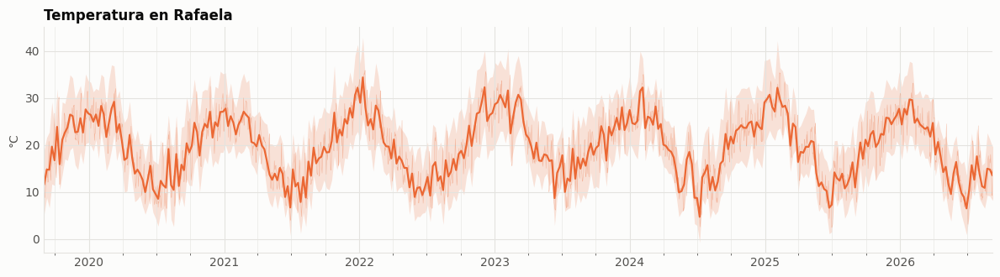

In [177]:
fig, ax = plt.subplots(figsize=(12, 3.4))
dibujar_temperatura(ax)
fig.tight_layout()
fig.savefig(GRAFICOS / "temperatura.png", dpi=150)
plt.show()

#### Parámetros de la leche cruda

Línea: mediana semanal de las medianas por industria y día. Banda: rango intercuartil (el 50% central).

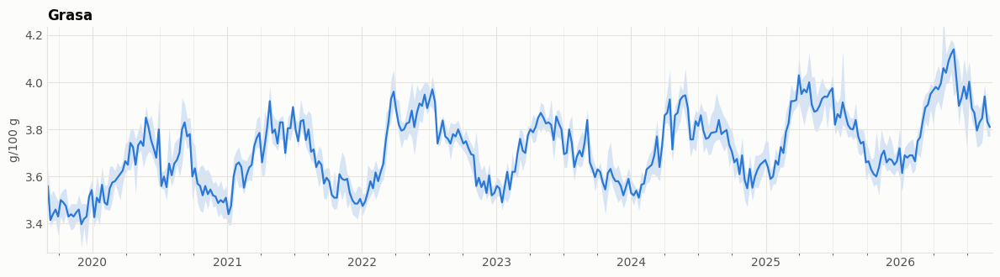

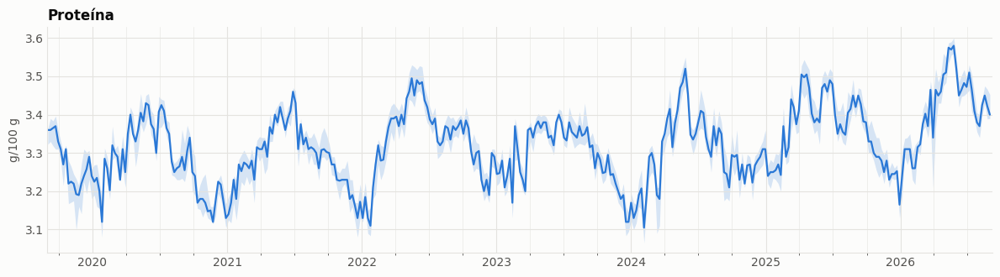

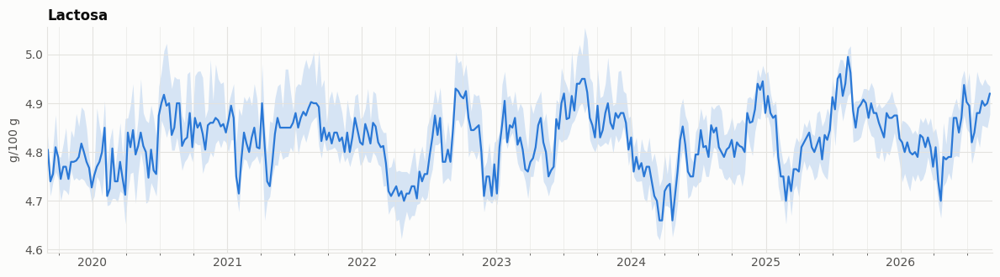

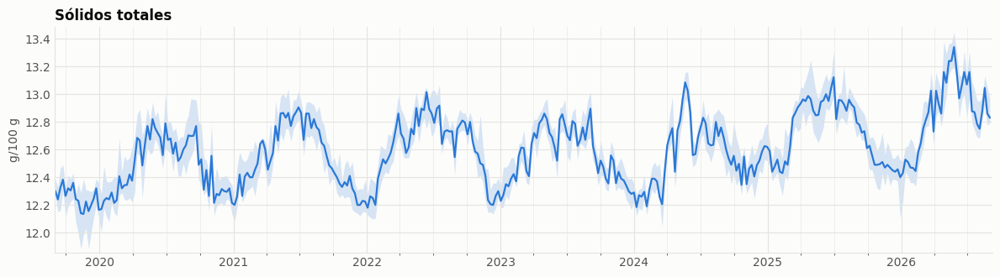

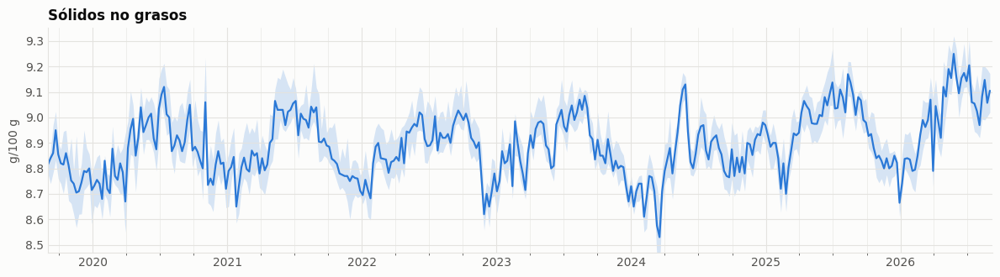

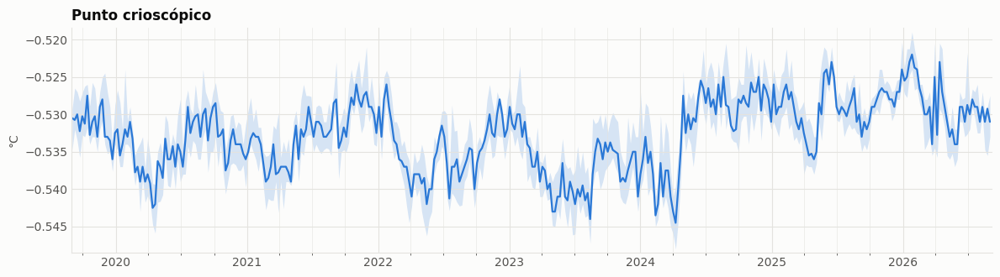

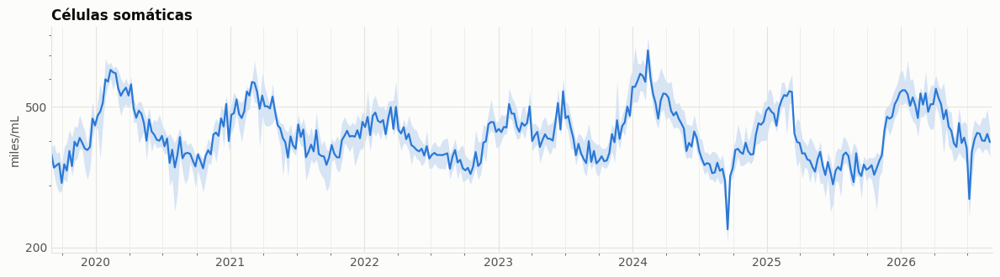

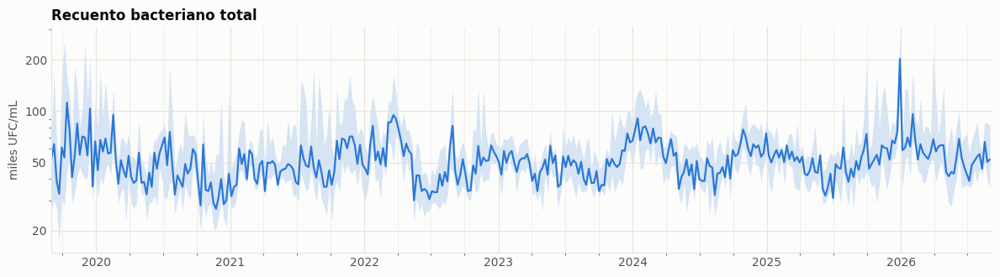

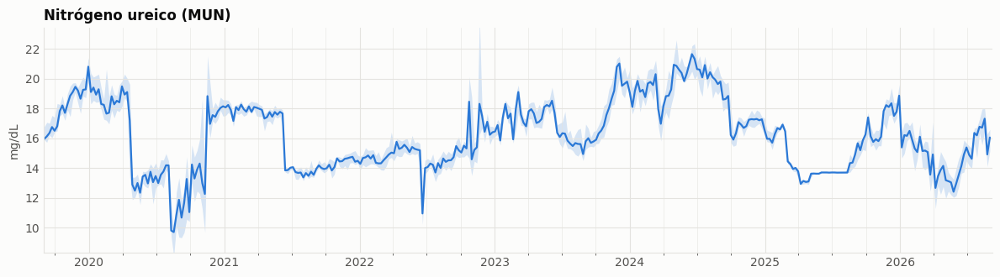

In [178]:
for p in PARAMETROS:
    fig, ax = plt.subplots(figsize=(12, 3.4))
    dibujar_parametro(ax, p)
    fig.tight_layout()
    fig.savefig(GRAFICOS / f"{p}.png", dpi=150)
    plt.show()

#### Todo junto, para cruzar

Mismo eje de tiempo para todos los paneles y la temperatura arriba. Cada panel tiene su propia escala
vertical: lo que se compara es **cuándo** sube y baja cada serie, no su nivel.

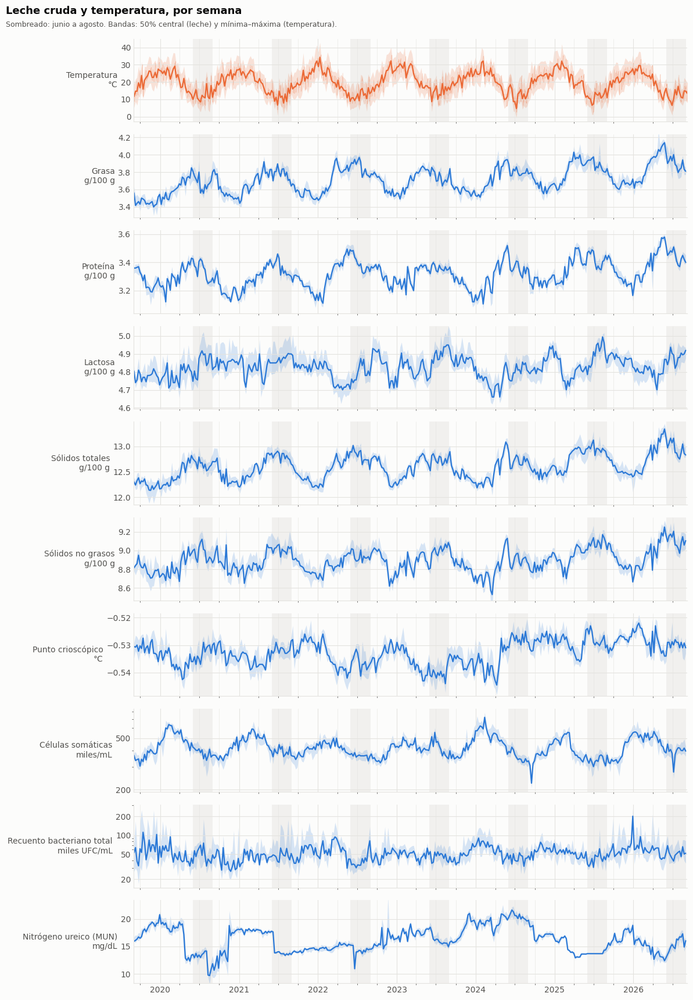

gráficos en resultados\temperatura_leche_cruda ['celulas_somaticas.png', 'correlacion_celulas_somaticas_temperatura.png', 'correlacion_grasa_temperatura.png', 'correlacion_grasa_temperatura_desfase_1semana.png', 'correlacion_proteina_temperatura.png', 'correlacion_proteina_temperatura_desfase_1semana.png', 'correlacion_rbt_temperatura.png', 'correlacion_solidos_totales_temperatura.png', 'correlacion_solidos_totales_temperatura_desfase_1semana.png', 'crioscopia.png', 'grasa.png', 'lactosa.png', 'linealidad_semanal_temperatura.png', 'mun.png', 'panel_leche_temperatura.png', 'proteina.png', 'rbt.png', 'solidos_no_grasos.png', 'solidos_totales.png', 'temperatura.png']


In [179]:
filas = 1 + len(PARAMETROS)
fig, axes = plt.subplots(filas, 1, figsize=(12, 1.75 * filas), sharex=True)
dibujar_temperatura(axes[0], titulo=False)
axes[0].set_ylabel("Temperatura\n°C", rotation=0, ha="right", va="center")
for ax, p in zip(axes[1:], PARAMETROS):
    dibujar_parametro(ax, p, titulo=False)
    nombre, unidad, _ = PARAMETROS[p]
    ax.set_ylabel(f"{nombre}\n{unidad}", rotation=0, ha="right", va="center")
# un sombreado suave en cada invierno (junio a agosto) ayuda a alinear la vista entre paneles
for ax in axes:
    for anio in range(DESDE.year, HASTA.year + 1):
        ax.axvspan(pd.Timestamp(anio, 6, 1), pd.Timestamp(anio, 9, 1), color=GRILLA, alpha=0.45, linewidth=0, zorder=0)
fig.suptitle("Leche cruda y temperatura, por semana", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.text(0.01, 0.985 - 0.2 / filas, "Sombreado: junio a agosto. Bandas: 50% central (leche) y mínima–máxima (temperatura).",
         ha="left", va="top", color=TEXTO_2, fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.975))
fig.savefig(GRAFICOS / "panel_leche_temperatura.png", dpi=150)
plt.show()
print("gráficos en", GRAFICOS.relative_to(RAIZ), sorted(f.name for f in GRAFICOS.glob("*.png")))

### Correlación lineal: grasa, proteína y sólidos totales contra la temperatura

Cada punto es una **industria-día**: la mediana de una industria en un día (la misma tabla `dia` de los
gráficos de arriba, desde septiembre de 2019) contra la temperatura media de Rafaela de ese día. Resumir
por industria-día evita que los días con muchas muestras de una sola industria dominen la nube.

- **Recta**: regresión lineal por mínimos cuadrados, `componente = a + b · temperatura`. La pendiente `b`
  es cuánto cambia el componente (g/100 g) por cada °C.
- **Pearson r** mide qué tan bien se ajustan los puntos a esa recta; **R² = r²** es la parte de la
  variación que la recta explica con la temperatura.
- **Por industria**: el mismo r dentro de cada industria. Si la relación aparece en todas, no es un efecto
  de qué industrias informan en cada época del año.
- Los sólidos totales son `grasa + sólidos no grasos`, y la proteína es la mayor parte variable de los no
  grasos: si la relación con la temperatura es lineal en los sólidos, tiene que verse en sus componentes.

industrias-día: 9,436 | industrias: 10
Grasa: grasa = 3.967 -0.0127 · temperatura (-0.13 g/100 g cada 10 °C) | r = -0.368 | R² = 0.136 | n = 7,818


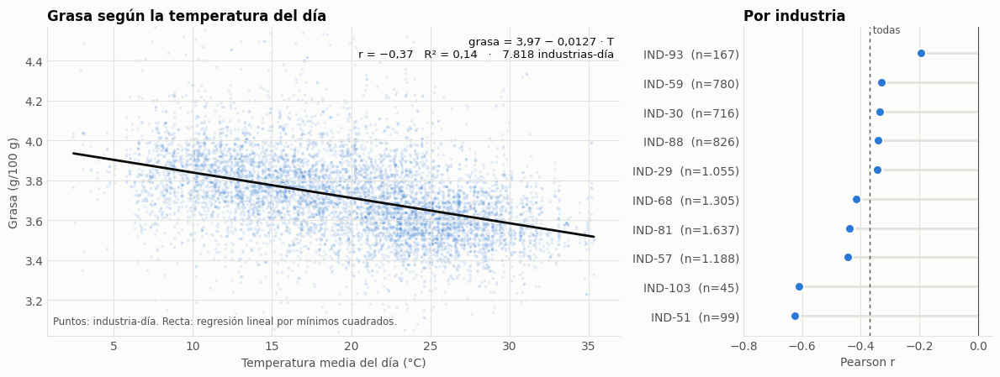

Proteína: proteína = 3.494 -0.0089 · temperatura (-0.09 g/100 g cada 10 °C) | r = -0.494 | R² = 0.244 | n = 7,821


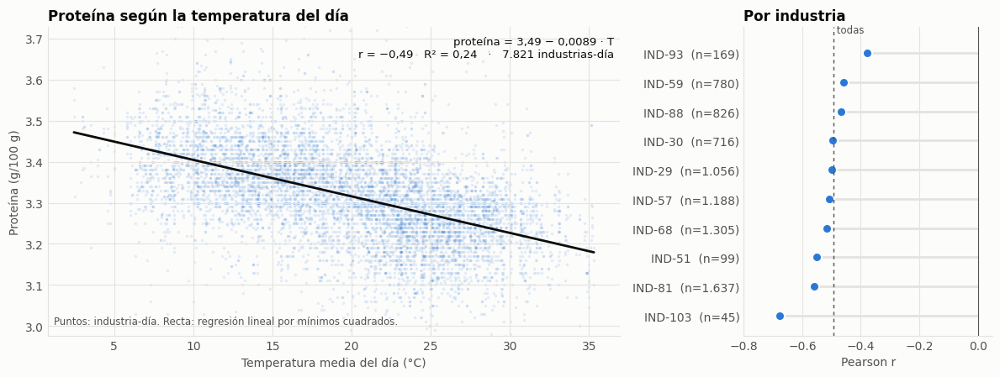

Sólidos totales: sólidos totales = 13.094 -0.0246 · temperatura (-0.25 g/100 g cada 10 °C) | r = -0.445 | R² = 0.198 | n = 7,822


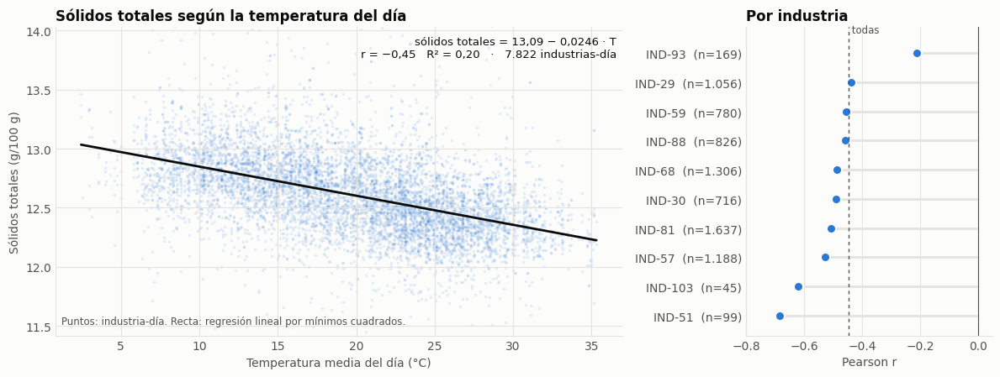


r por industria:
         grasa  proteina  solidos_totales
cliente                                  
IND-103 -0.611    -0.678           -0.619
IND-29  -0.344    -0.499           -0.438
IND-30  -0.335    -0.496           -0.490
IND-51  -0.626    -0.549           -0.683
IND-57  -0.445    -0.508           -0.526
IND-59  -0.330    -0.459           -0.456
IND-68  -0.414    -0.517           -0.487
IND-81  -0.439    -0.558           -0.506
IND-88  -0.340    -0.468           -0.458
IND-93  -0.193    -0.378           -0.212


In [180]:
import numpy as np

COMPONENTES = ["grasa", "proteina", "solidos_totales"]
dec = lambda v, d: f"{v:.{d}f}".replace("-", "−").replace(".", ",")      # coma decimal

RECUENTOS = ["celulas_somaticas", "rbt"]      # sección final: escala logarítmica
corr = dia[["cliente", "fecha"] + COMPONENTES + ["solidos_no_grasos", "lactosa"] + RECUENTOS].merge(
    temp[["fecha", "t_media"]], on="fecha", how="left", validate="many_to_one")
corr = corr.dropna(subset=["t_media"])
print(f"industrias-día: {len(corr):,} | industrias: {corr['cliente'].nunique()}")


def recta(g, p, x="t_media"):
    g = g.dropna(subset=[p, x])
    b, a = np.polyfit(g[x], g[p], 1)
    return a, b, g[p].corr(g[x]), len(g)


def figura_correlacion(p, x="t_media", eje_x="Temperatura media del día (°C)",
                       titulo="según la temperatura del día", archivo=None, umbral=None):
    # Con escala log (recuentos), la recta y el r se calculan sobre log10 del valor: la pendiente es un factor
    # multiplicativo por °C. `umbral` dibuja una línea horizontal (el corte de la regresión logística).
    nombre, unidad, log = PARAMETROS[p]
    col = p
    if log:
        col = f"log10_{p}"
        corr[col] = np.log10(corr[p].where(corr[p] > 0))
    a, b, r, n = recta(corr, col, x)
    if log:
        print(f"{nombre}: log10 = {a:.3f} {b:+.4f} · temperatura (×{10 ** (10 * b):.2f} cada 10 °C, "
              f"{100 * (10 ** (10 * b) - 1):+.0f} %) | r = {r:.3f} | R² = {r ** 2:.3f} | n = {n:,}")
    else:
        print(f"{nombre}: {nombre.lower()} = {a:.3f} {b:+.4f} · temperatura ({10 * b:+.2f} g/100 g cada 10 °C)"
              f" | r = {r:.3f} | R² = {r ** 2:.3f} | n = {n:,}")
    por_ind = (corr.groupby("cliente")
               .apply(lambda g: pd.Series(dict(zip(["a", "pendiente", "r", "n"], recta(g, col, x)))), include_groups=False)
               .drop(columns="a").sort_values("r"))
    por_ind["n"] = por_ind["n"].astype(int)

    fig, (ax, ax_ind) = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [2.3, 1]})
    d = corr.dropna(subset=[col, x])
    ax.scatter(d[x], d[col], s=6, color=AZUL, alpha=0.12, linewidths=0, rasterized=True)
    xr = np.array([d[x].min(), d[x].max()])
    ax.plot(xr, a + b * xr, color=TEXTO, linewidth=2, solid_capstyle="round")
    lo, hi = d[col].quantile([0.005, 0.995])     # recorte robusto: unos pocos días raros no aplastan la nube
    margen = (hi - lo) * 0.05
    ax.set_ylim(lo - margen, hi + margen)
    ax.set_xlabel(eje_x)
    ax.set_title(f"{nombre} {titulo}")
    signo = "−" if b < 0 else "+"
    if log:
        # eje en log10 con rótulos en la unidad original (1-2-5 por década)
        marcas = [m * 10 ** e for e in range(-1, 6) for m in (1, 2, 5)]
        marcas = [m for m in marcas if lo - margen <= np.log10(m) <= hi + margen]
        ax.set_yticks(np.log10(marcas), [f"{m:,.0f}".replace(",", ".") if m >= 1 else f"{m:g}".replace(".", ",")
                                         for m in marcas])
        ax.set_ylabel(f"{nombre} ({unidad}, escala log)")
        if umbral is not None:
            ax.axhline(np.log10(umbral), color=NARANJA, linewidth=1.2, linestyle=(0, (4, 3)))
            ax.text(xr[0], np.log10(umbral), f" umbral de la Parte IV: {umbral:,.0f}".replace(",", "."),
                    color=NARANJA, fontsize=8.5, va="bottom")
        factor = 10 ** (10 * b)
        ecuacion = (f"log₁₀ = {dec(a, 2)} {signo} {dec(abs(b), 4)} · T   (×{dec(factor, 2)} cada 10 °C)")
    else:
        ax.set_ylabel(f"{nombre} ({unidad})")
        ecuacion = f"{nombre.lower()} = {dec(a, 2)} {signo} {dec(abs(b), 4)} · T"
    ax.text(0.99, 0.97, f"{ecuacion}\n"
            f"r = {dec(r, 2)}   R² = {dec(r ** 2, 2)}   ·   {n:_} industrias-día".replace("_", "."),
            transform=ax.transAxes, ha="right", va="top", color=TEXTO, fontsize=9.5)
    ax.text(0.01, 0.03, "Puntos: industria-día. Recta: regresión lineal por mínimos cuadrados"
            + (" sobre log₁₀." if log else "."),
            transform=ax.transAxes, ha="left", va="bottom", color=TEXTO_2, fontsize=8.5)
    ax.tick_params(axis="both", length=0)

    y = range(len(por_ind))
    ax_ind.hlines(y, 0, por_ind["r"], color=GRILLA, linewidth=2)
    ax_ind.plot(por_ind["r"], y, "o", color=AZUL, markersize=8, markeredgecolor=SUPERFICIE, markeredgewidth=1.5)
    ax_ind.axvline(r, color=TEXTO_2, linewidth=1, linestyle=(0, (3, 3)))
    ax_ind.text(r, len(por_ind) - 0.4, " todas", color=TEXTO_2, fontsize=8.5, va="bottom")
    ax_ind.axvline(0, color=TEXTO_2, linewidth=0.8)
    ax_ind.set_yticks(list(y), [f"{c}  (n={k:,})".replace(",", ".") for c, k in por_ind["n"].items()])
    ax_ind.set_ylim(-0.7, len(por_ind) - 0.1)
    ax_ind.set_xlim(min(-0.8 if not log else -0.05, por_ind["r"].min() - 0.05),
                    max(0.05 if not log else 0.8, por_ind["r"].max() + 0.05))
    ax_ind.set_xlabel("Pearson r")
    ax_ind.set_title("Por industria")
    ax_ind.grid(axis="y", visible=False)
    ax_ind.tick_params(axis="both", length=0)
    fig.tight_layout()
    fig.savefig(GRAFICOS / (archivo or f"correlacion_{p}_temperatura.png"), dpi=150)
    plt.show()
    return por_ind


por_industria = {}
for p in COMPONENTES:
    por_industria[p] = figura_correlacion(p)
print()
print("r por industria:")
print(pd.DataFrame({p: por_industria[p]["r"] for p in COMPONENTES}).round(3).to_string())

#### ¿Es lineal? Y ¿mejora al promediar la temperatura?

Tres pruebas, las mismas para los tres componentes (más sólidos no grasos y lactosa como referencia):

1. **Curvatura.** Se ajusta también `a + b·T + c·T²`. Si el R² cuadrático no supera al lineal, una recta
   alcanza: la relación es lineal en el rango de temperaturas de Rafaela.
2. **Medias por tramo de temperatura** (tramos de 2 °C). Si caen sobre la recta, no hay un umbral ni una
   meseta escondidos en la nube.
3. **Ventana de temperatura.** La vaca no responde a la temperatura de un día aislado: se prueba la media
   de los últimos 7, 15, 30, 60 y 90 días, y además la serie semanal (mediana entre industrias-día, como
   en los gráficos), que promedia el ruido de día a día. Si el r sube, la relación es más lineal de lo que
   muestra la nube diaria.

In [181]:
REFERENCIA = COMPONENTES + ["solidos_no_grasos", "lactosa"]
VENTANAS = [1, 7, 15, 30, 60, 90]
serie_t = temp.set_index("fecha")["t_media"].sort_index()
for w in VENTANAS:
    corr[f"t{w}"] = corr["fecha"].map(serie_t.rolling(f"{w}D").mean())

g_sem = pd.Grouper(key="fecha", freq="W-MON", label="left", closed="left")
sem = corr.groupby(g_sem).agg({**{p: "median" for p in REFERENCIA}, **{f"t{w}": "mean" for w in VENTANAS}})
sem = sem[corr.groupby(g_sem)["cliente"].nunique() >= MIN_INDUSTRIAS].dropna()


def r2(x, y, grado):
    coef = np.polyfit(x, y, grado)
    resid = y - np.polyval(coef, x)
    return 1 - (resid ** 2).sum() / ((y - y.mean()) ** 2).sum()


filas = []
for p in REFERENCIA:
    for nivel, tabla in [("industria-día", corr), ("semana", sem)]:
        for w in VENTANAS:
            d = tabla[[p, f"t{w}"]].dropna()
            x, y = d[f"t{w}"].to_numpy(), d[p].to_numpy()
            filas.append({"componente": p, "nivel": nivel, "ventana_días": w, "n": len(d),
                          "r": np.corrcoef(x, y)[0, 1], "R²_lineal": r2(x, y, 1), "R²_cuadrático": r2(x, y, 2)})
lin = pd.DataFrame(filas)
lin["ganancia_cuadrática"] = lin["R²_cuadrático"] - lin["R²_lineal"]
pd.set_option("display.width", 160)
for nivel in ["industria-día", "semana"]:
    print(f"--- r de Pearson por ventana de temperatura · nivel {nivel}")
    print(lin[lin.nivel == nivel].pivot(index="componente", columns="ventana_días", values="r").loc[REFERENCIA].round(3).to_string())
    print()
print("--- curvatura: lo que agrega el término T² al R² (máximo sobre ventanas y niveles)")
print(lin.groupby("componente")["ganancia_cuadrática"].max().loc[REFERENCIA].round(4).to_string())
mejor = lin[lin.nivel == "semana"].loc[lambda t: t.groupby("componente")["r"].idxmin()].set_index("componente").loc[REFERENCIA]
print()
print("--- mejor ventana a nivel semanal")
print(mejor[["ventana_días", "n", "r", "R²_lineal", "R²_cuadrático"]].round(3).to_string())

--- r de Pearson por ventana de temperatura · nivel industria-día
ventana_días          1      7      15     30     60     90
componente                                                 
grasa             -0.368 -0.389 -0.368 -0.319 -0.211 -0.090
proteina          -0.494 -0.582 -0.557 -0.490 -0.359 -0.216
solidos_totales   -0.445 -0.498 -0.481 -0.436 -0.335 -0.217
solidos_no_grasos -0.408 -0.484 -0.477 -0.449 -0.390 -0.310
lactosa           -0.111 -0.138 -0.154 -0.180 -0.226 -0.251

--- r de Pearson por ventana de temperatura · nivel semana
ventana_días          1      7      15     30     60     90
componente                                                 
grasa             -0.598 -0.600 -0.568 -0.486 -0.311 -0.118
proteina          -0.682 -0.733 -0.700 -0.612 -0.444 -0.261
solidos_totales   -0.718 -0.749 -0.722 -0.647 -0.493 -0.310
solidos_no_grasos -0.685 -0.749 -0.738 -0.689 -0.592 -0.462
lactosa           -0.202 -0.240 -0.266 -0.315 -0.394 -0.436

--- curvatura: lo que agrega el t

##### Medias por tramo de temperatura

Serie semanal contra la temperatura media de los 7 días previos. Los puntos claros son las semanas; los
oscuros, la media de las semanas en cada tramo de 2 °C con su error estándar. La recta es la regresión
lineal sobre las semanas.

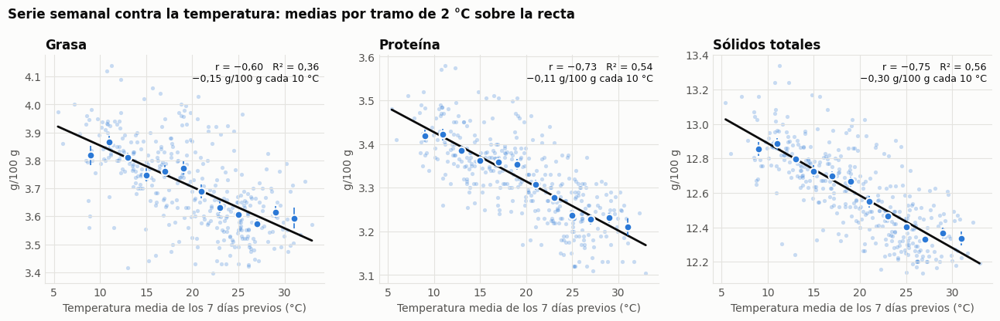

In [182]:
W = 7
fig, axes = plt.subplots(1, len(COMPONENTES), figsize=(13, 4.2))
tramos = np.arange(np.floor(sem[f"t{W}"].min() / 2) * 2, sem[f"t{W}"].max() + 2, 2)
for ax, p in zip(axes, COMPONENTES):
    nombre, unidad, _ = PARAMETROS[p]
    x, y = sem[f"t{W}"], sem[p]
    b, a = np.polyfit(x, y, 1)
    r = np.corrcoef(x, y)[0, 1]
    ax.scatter(x, y, s=14, color=AZUL, alpha=0.25, linewidths=0)
    xr = np.array([x.min(), x.max()])
    ax.plot(xr, a + b * xr, color=TEXTO, linewidth=2, solid_capstyle="round", zorder=3)
    medias = y.groupby(pd.cut(x, tramos), observed=True).agg(["mean", "sem", "size"]).query("size >= 5")
    centros = [iv.mid for iv in medias.index]
    ax.errorbar(centros, medias["mean"], yerr=medias["sem"], fmt="o", color=AZUL, markersize=7,
                markeredgecolor=SUPERFICIE, markeredgewidth=1.5, elinewidth=1.2, capsize=0, zorder=4)
    ax.set_title(nombre)
    ax.set_xlabel(f"Temperatura media de los {W} días previos (°C)")
    ax.set_ylabel(unidad)
    ax.text(0.98, 0.97, f"r = {dec(r, 2)}   R² = {dec(r ** 2, 2)}\n{dec(10 * b, 2)} g/100 g cada 10 °C",
            transform=ax.transAxes, ha="right", va="top", color=TEXTO, fontsize=9)
    ax.tick_params(axis="both", length=0)
fig.suptitle("Serie semanal contra la temperatura: medias por tramo de 2 °C sobre la recta",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
fig.savefig(GRAFICOS / "linealidad_semanal_temperatura.png", dpi=150)
plt.show()

#### Más allá del calendario: anomalías y desfasaje

La temperatura acompaña a la estación, y con la estación cambian también la alimentación, el fotoperíodo
y el momento de lactancia de los rodeos. Para separar la temperatura del calendario se le resta a cada
serie semanal la media de su mes calendario (**anomalía**): si en las semanas más cálidas *de lo normal
para esa época* la leche viene más pobre *de lo normal para esa época*, hay un efecto de la temperatura
que el calendario no explica.

El **desfasaje** compara la composición de una semana con la temperatura de k semanas antes (k > 0) o
después (k < 0). Un componente que responde a la temperatura tiene su máximo |r| en k ≥ 0; si lo tiene
en k < 0 (la leche "se adelanta" a la temperatura), lo está moviendo otra cosa del ciclo anual.

In [183]:
sem_a = sem.copy()
mes = sem_a.index.month
for col in REFERENCIA + [f"t{W}"]:
    sem_a[col] = sem_a[col] - sem_a[col].groupby(mes).transform("mean")

filas = []
for p in REFERENCIA:
    r_crudo = sem[p].corr(sem[f"t{W}"])
    r_anom = sem_a[p].corr(sem_a[f"t{W}"])
    b_anom = np.polyfit(sem_a[f"t{W}"], sem_a[p], 1)[0]
    rezagos = {k: sem[p].corr(sem[f"t{W}"].shift(k)) for k in range(-12, 13)}
    k_mejor = min(rezagos, key=lambda k: rezagos[k])
    filas.append({"componente": p, "r_crudo": r_crudo, "r_anomalías": r_anom,
                  "pendiente_anom_10°C": 10 * b_anom, "semanas_mejor_desfasaje": k_mejor,
                  "r_mejor_desfasaje": rezagos[k_mejor]})
print(f"semanas: {len(sem)} | temperatura: media de los {W} días previos")
print(pd.DataFrame(filas).set_index("componente").round(3).to_string())

semanas: 366 | temperatura: media de los 7 días previos
                   r_crudo  r_anomalías  pendiente_anom_10°C  semanas_mejor_desfasaje  r_mejor_desfasaje
componente                                                                                              
grasa               -0.600       -0.270               -0.101                       -7             -0.717
proteina            -0.733       -0.475               -0.107                       -6             -0.735
solidos_totales     -0.749       -0.409               -0.244                        0             -0.749
solidos_no_grasos   -0.749       -0.390               -0.134                        0             -0.749
lactosa             -0.240       -0.078               -0.015                       11             -0.456


#### Lectura

- **Es lineal en los tres.** El término cuadrático agrega como mucho 0,013 de R² (grasa), y en proteína
  y sólidos totales menos de 0,01; las medias por tramo de 2 °C caen sobre la recta. No hay umbral ni
  meseta en el rango de temperaturas de Rafaela. La relación es negativa en las diez industrias, en los
  tres componentes.
- **La linealidad aumenta al promediar, y lo hace en los tres.** Con la temperatura del día y la nube de
  industrias-día el r es moderado (grasa −0,37, proteína −0,49, sólidos −0,45) porque cada día suma ruido
  de muestreo. Con la media de los 7 días previos sube en los tres, y con la serie semanal llega a
  grasa −0,60, proteína −0,73 y sólidos −0,75 (R² 0,36 / 0,54 / 0,56). Ventanas de más de 15 días
  empeoran el ajuste: la respuesta es de días, no de meses.
- **Proteína y sólidos van juntos; la grasa acompaña, pero menos.** Los sólidos totales son lineales sobre
  todo por los **sólidos no grasos** (mismo r, −0,75), y la proteína es la que más se les parece. La grasa
  queda más baja y su mejor desfasaje es de −7 semanas (r −0,72 contra −0,60 sin desfasaje): pica en
  otoño, antes del frío, así que una parte de su ciclo la mueve otra cosa (fotoperíodo, lactancia,
  dieta). En proteína el desfasaje no distingue nada (−0,735 a −6 semanas contra −0,733 sin desfasaje),
  y en sólidos el mejor es 0.
- **El efecto sobrevive al calendario.** Descontada la media de cada mes, el r sigue negativo: proteína
  −0,48, sólidos −0,41, grasa −0,27. La lactosa casi no responde (−0,08).
- **Correlación no es causa**: esto muestra que la leche viene más pobre en las semanas más cálidas, también
  descontado el mes, no que el calor sea el único mecanismo.

### Correlación con la temperatura de la semana previa

Exploración: ¿la leche se parece más a la temperatura **de la semana anterior** que a la de la semana en que
se la analiza? Para cada fecha de análisis `d` se toma la temperatura media de los 7 días de `d−13` a `d−7`
(la semana inmediatamente anterior a la ventana de 7 días que termina en `d`), y como variante las medias de
15 y 30 días que terminan en `d−7`. Se compara con la misma ventana **sin desfase** (que termina en `d`).

- Misma serie diaria de temperatura, mismo agregado de la leche (mediana por industria-día y mediana semanal
  `W-MON` con al menos 3 industrias) y mismas funciones que arriba.
- Se compara en la **misma muestra** (las filas que tienen ambas temperaturas), a nivel industria-día y semana.
- **Anomalías**: se resta la media del mes calendario a la leche y a la temperatura (con y sin desfase). Si el
  desfase mejora el r solo en crudo y no en anomalías, la mejora viene de que el ciclo anual de la leche está
  corrido respecto del de la temperatura, no de una respuesta a la temperatura reciente.
- Convención: r es negativo (más calor, leche más pobre), así que **Δr = r con desfase − r sin desfase
  negativo significa que el desfase mejora la relación**.

In [184]:
LAG = 7                               # días de desfase: una semana
VENT_DESF = [1, 7, 15, 30]            # ventana principal: 7; variantes: 1, 15 y 30 días
NIVELES = [("industria-día", "ind"), ("semana", "sem")]

# temperatura sin desfase (termina en d, ya calculada como t{w}) y con desfase (termina en d - 7)
for w in VENT_DESF:
    if f"t{w}" not in corr:
        corr[f"t{w}"] = corr["fecha"].map(serie_t.rolling(f"{w}D").mean())
    corr[f"d{w}"] = (corr["fecha"] - pd.Timedelta(days=LAG)).map(serie_t.rolling(f"{w}D").mean())

# control: d7 de una fecha cualquiera es la media de los 7 días de d-13 a d-7
f0 = corr["fecha"].iloc[len(corr) // 2]
assert np.isclose(serie_t[f0 - pd.Timedelta(days=13): f0 - pd.Timedelta(days=7)].mean(),
                  corr.loc[corr["fecha"] == f0, "d7"].iloc[0])
print(f"ventana con desfase para {f0:%Y-%m-%d}: {f0 - pd.Timedelta(days=13):%Y-%m-%d} a {f0 - pd.Timedelta(days=7):%Y-%m-%d}")

agg = {**{p: "median" for p in REFERENCIA}, **{f"t{w}": "mean" for w in VENT_DESF}, **{f"d{w}": "mean" for w in VENT_DESF}}
sem_d = corr.groupby(g_sem).agg(agg)
sem_d = sem_d[corr.groupby(g_sem)["cliente"].nunique() >= MIN_INDUSTRIAS].dropna()
print(f"industrias-día: {len(corr):,} | semanas: {len(sem_d)} (la sección anterior: {len(sem)})")
assert sem_d.index.equals(sem.index)

tablas = {"ind": corr, "sem": sem_d}
meses = {"ind": corr["fecha"].dt.month, "sem": pd.Series(sem_d.index.month, index=sem_d.index)}


def estadisticos(x, y):
    b, a = np.polyfit(x, y, 1)
    return {"r": np.corrcoef(x, y)[0, 1], "pendiente": b, "R²_lin": r2(x, y, 1), "R²_cuad": r2(x, y, 2)}


filas = []
for nivel, k in NIVELES:
    tabla, mes = tablas[k], meses[k]
    for p in REFERENCIA:
        for w in VENT_DESF:
            d = tabla[[p, f"t{w}", f"d{w}"]].dropna()
            a = d - d.groupby(mes.loc[d.index].to_numpy()).transform("mean")
            fila = {"componente": p, "nivel": nivel, "ventana_días": w, "n": len(d)}
            for sufijo, col in [("sin", f"t{w}"), ("con", f"d{w}")]:
                for nombre_e, v in estadisticos(d[col].to_numpy(), d[p].to_numpy()).items():
                    fila[f"{nombre_e}_{sufijo}"] = v
                e_a = estadisticos(a[col].to_numpy(), a[p].to_numpy())
                fila[f"r_anom_{sufijo}"], fila[f"pend_anom_{sufijo}"] = e_a["r"], e_a["pendiente"]
            filas.append(fila)
desf = pd.DataFrame(filas)
desf["Δr"] = desf["r_con"] - desf["r_sin"]
desf["Δr_anom"] = desf["r_anom_con"] - desf["r_anom_sin"]

pd.set_option("display.width", 200)
ppal = desf[desf["ventana_días"] == 7]
for nivel, _ in NIVELES:
    print(f"--- ventana de 7 días · nivel {nivel} · n = {ppal[ppal.nivel == nivel]['n'].iloc[0]:,}")
    t_ = ppal[ppal.nivel == nivel].set_index("componente").loc[REFERENCIA]
    print(t_[["r_sin", "r_con", "Δr", "pendiente_sin", "pendiente_con", "R²_lin_sin", "R²_lin_con",
              "R²_cuad_sin", "R²_cuad_con"]].round(4).to_string())
    print(t_[["r_anom_sin", "r_anom_con", "Δr_anom", "pend_anom_sin", "pend_anom_con"]].round(4).to_string())
    print()
print("--- variantes de ventana: r sin desfase / con desfase (crudo y anomalías)")
for nivel, _ in NIVELES:
    v = desf[(desf.nivel == nivel) & desf["componente"].isin(COMPONENTES)]
    print(f"nivel {nivel}")
    print(v.pivot(index="componente", columns="ventana_días", values=["r_sin", "r_con", "r_anom_sin", "r_anom_con"])
          .round(3).to_string())
    print()

ventana con desfase para 2021-03-03: 2021-02-18 a 2021-02-24
industrias-día: 9,436 | semanas: 366 (la sección anterior: 366)


--- ventana de 7 días · nivel industria-día · n = 7,818
                    r_sin   r_con      Δr  pendiente_sin  pendiente_con  R²_lin_sin  R²_lin_con  R²_cuad_sin  R²_cuad_con
componente                                                                                                               
grasa             -0.3892 -0.3297  0.0595        -0.0146        -0.0123      0.1515      0.1087       0.1519       0.1088
proteina          -0.5824 -0.5028  0.0796        -0.0114        -0.0098      0.3392      0.2529       0.3393       0.2529
solidos_totales   -0.4979 -0.4388  0.0591        -0.0299        -0.0262      0.2479      0.1925       0.2484       0.1925
solidos_no_grasos -0.4840 -0.4417  0.0423        -0.0155        -0.0141      0.2343      0.1951       0.2344       0.1952
lactosa           -0.1377 -0.1558 -0.0181        -0.0025        -0.0028      0.0190      0.0243       0.0195       0.0244
                   r_anom_sin  r_anom_con  Δr_anom  pend_anom_sin  pend_anom_con
component

In [185]:
# ¿el desfase agrega información sobre la temperatura de la propia semana? Semanal, en anomalías:
# R² con la temperatura de la semana sola, con la desfasada sola y con ambas
def r2_multiple(X, y):
    X1 = np.column_stack([np.ones(len(X)), X])
    coef, *_ = np.linalg.lstsq(X1, y, rcond=None)
    return 1 - ((y - X1 @ coef) ** 2).sum() / ((y - y.mean()) ** 2).sum()


filas = []
for p in COMPONENTES + ["solidos_no_grasos", "lactosa"]:
    d = sem_d[[p, "t7", "d7"]]
    a = d - d.groupby(meses["sem"].to_numpy()).transform("mean")
    filas.append({"componente": p,
                  "R²_t7_sola": r2_multiple(a[["t7"]].to_numpy(), a[p].to_numpy()),
                  "R²_desfase_sola": r2_multiple(a[["d7"]].to_numpy(), a[p].to_numpy()),
                  "R²_ambas": r2_multiple(a[["t7", "d7"]].to_numpy(), a[p].to_numpy()),
                  "r_t7_vs_d7_anom": a["t7"].corr(a["d7"])})
print("--- semana, anomalías: R² con la temperatura de la semana, con la desfasada y con ambas")
print(pd.DataFrame(filas).set_index("componente").round(4).to_string())

# curva de r contra el desfase (en semanas, por calendario) con la misma serie semanal: crudo y anomalías
ks = list(range(-12, 13))
completa = sem_d.reindex(pd.date_range(sem_d.index.min(), sem_d.index.max(), freq="7D"))
curvas = {}
for p in COMPONENTES + ["solidos_no_grasos", "lactosa"]:
    cr, an = [], []
    for k in ks:
        d = pd.DataFrame({"y": completa[p], "x": completa["t7"].shift(k)}).dropna()
        cr.append(d["y"].corr(d["x"]))
        a = d - d.groupby(d.index.month).transform("mean")
        an.append(a["y"].corr(a["x"]))
    curvas[p] = pd.DataFrame({"crudo": cr, "anomalías": an}, index=ks)
res = []
for p, cv in curvas.items():
    res.append({"componente": p, "r_k0": cv.loc[0, "crudo"], "r_k1": cv.loc[1, "crudo"],
                "k_óptimo": cv["crudo"].idxmin(), "r_óptimo": cv["crudo"].min(),
                "anom_k0": cv.loc[0, "anomalías"], "anom_k1": cv.loc[1, "anomalías"],
                "k_óptimo_anom": cv["anomalías"].idxmin(), "r_óptimo_anom": cv["anomalías"].min()})
print()
print("--- rezago en semanas (k > 0: temperatura de k semanas antes), semana, ventana de 7 días")
print(pd.DataFrame(res).set_index("componente").round(3).to_string())

--- semana, anomalías: R² con la temperatura de la semana, con la desfasada y con ambas
                   R²_t7_sola  R²_desfase_sola  R²_ambas  r_t7_vs_d7_anom
componente                                                               
grasa                  0.0732           0.0341    0.0783           0.4459
proteina               0.2261           0.1011    0.2401           0.4459
solidos_totales        0.1672           0.0706    0.1759           0.4459
solidos_no_grasos      0.1520           0.0685    0.1617           0.4459
lactosa                0.0061           0.0002    0.0066           0.4459



--- rezago en semanas (k > 0: temperatura de k semanas antes), semana, ventana de 7 días
                    r_k0   r_k1  k_óptimo  r_óptimo  anom_k0  anom_k1  k_óptimo_anom  r_óptimo_anom
componente                                                                                         
grasa             -0.600 -0.521        -7    -0.717   -0.270   -0.191              0         -0.270
proteina          -0.733 -0.646        -6    -0.735   -0.475   -0.333              0         -0.475
solidos_totales   -0.749 -0.672         0    -0.749   -0.409   -0.270              0         -0.409
solidos_no_grasos -0.749 -0.697         0    -0.749   -0.390   -0.261              0         -0.390
lactosa           -0.240 -0.269        11    -0.456   -0.078   -0.006              0         -0.078


#### Dispersión con la temperatura desfasada una semana

Los mismos gráficos de dispersión de arriba (cada punto es una industria-día, recta por mínimos cuadrados y
r por industria), pero el eje x es la **temperatura media del día una semana antes del análisis** (`d − 7`)
en lugar de la del mismo día. Abajo de cada gráfico se imprime el r sin desfase para comparar.

Grasa: grasa = 3.932 -0.0110 · temperatura (-0.11 g/100 g cada 10 °C) | r = -0.319 | R² = 0.102 | n = 7,818


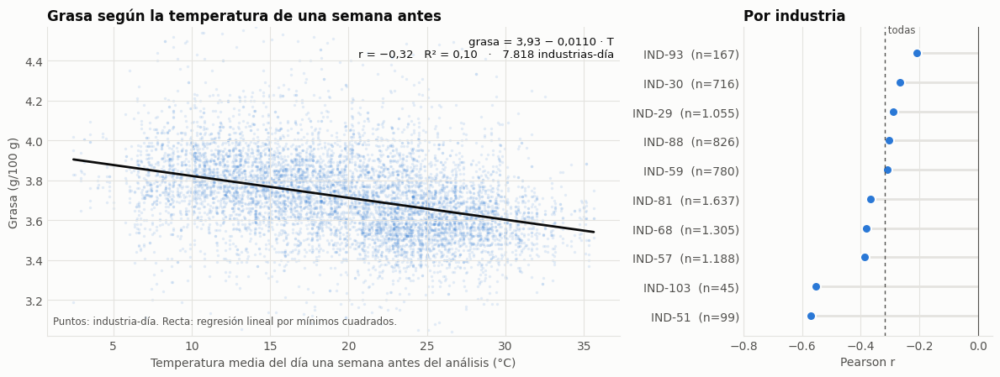

   sin desfase (temperatura del mismo día): r = -0.368

Proteína: proteína = 3.496 -0.0090 · temperatura (-0.09 g/100 g cada 10 °C) | r = -0.505 | R² = 0.255 | n = 7,821


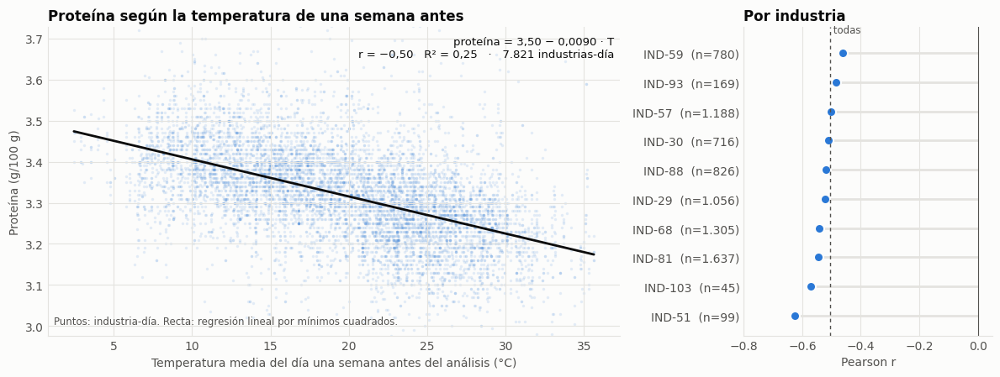

   sin desfase (temperatura del mismo día): r = -0.494

Sólidos totales: sólidos totales = 13.069 -0.0234 · temperatura (-0.23 g/100 g cada 10 °C) | r = -0.424 | R² = 0.180 | n = 7,822


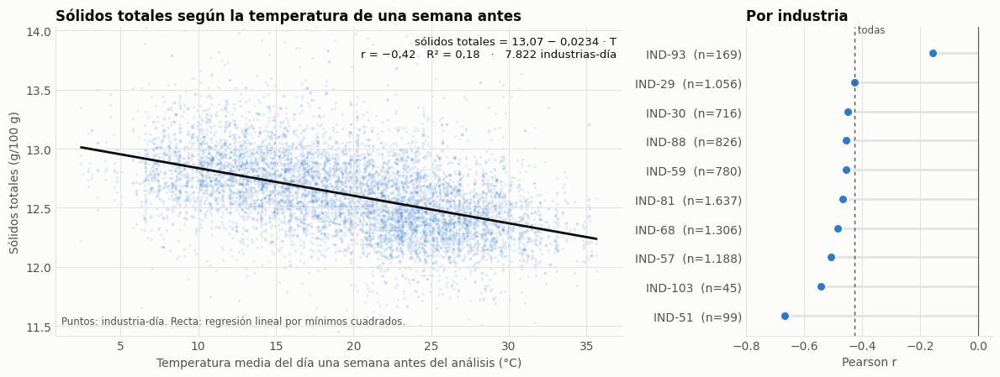

   sin desfase (temperatura del mismo día): r = -0.445

r por industria con desfase de una semana (entre paréntesis, sin desfase):
                   grasa         proteina  solidos_totales
cliente                                                   
IND-103  -0.552 (-0.611)  -0.571 (-0.678)  -0.541 (-0.619)
IND-29   -0.288 (-0.344)  -0.523 (-0.499)  -0.425 (-0.438)
IND-30   -0.266 (-0.335)  -0.511 (-0.496)    -0.45 (-0.49)
IND-51   -0.572 (-0.626)  -0.624 (-0.549)  -0.666 (-0.683)
IND-57   -0.387 (-0.445)  -0.501 (-0.508)  -0.508 (-0.526)
IND-59    -0.309 (-0.33)  -0.462 (-0.459)  -0.454 (-0.456)
IND-68    -0.38 (-0.414)  -0.542 (-0.517)  -0.483 (-0.487)
IND-81   -0.365 (-0.439)  -0.545 (-0.558)  -0.465 (-0.506)
IND-88    -0.302 (-0.34)  -0.519 (-0.468)  -0.453 (-0.458)
IND-93   -0.208 (-0.193)  -0.486 (-0.378)  -0.155 (-0.212)


In [186]:
corr["t_media_7d_antes"] = (corr["fecha"] - pd.Timedelta(days=LAG)).map(serie_t)
f0 = corr["fecha"].iloc[len(corr) // 2]
assert np.isclose(corr.loc[corr["fecha"] == f0, "t_media_7d_antes"].iloc[0], serie_t[f0 - pd.Timedelta(days=LAG)])

por_industria_desf = {}
for p in COMPONENTES:
    por_industria_desf[p] = figura_correlacion(
        p, x="t_media_7d_antes", eje_x="Temperatura media del día una semana antes del análisis (°C)",
        titulo="según la temperatura de una semana antes",
        archivo=f"correlacion_{p}_temperatura_desfase_1semana.png")
    _, _, r0, _ = recta(corr, p)
    print(f"   sin desfase (temperatura del mismo día): r = {r0:.3f}\n")
print("r por industria con desfase de una semana (entre paréntesis, sin desfase):")
print(pd.DataFrame({p: por_industria_desf[p]["r"].round(3).astype(str) + " ("
                       + por_industria[p]["r"].reindex(por_industria_desf[p].index).round(3).astype(str) + ")"
                    for p in COMPONENTES}).to_string())

#### Lectura del desfase

Ventana de 7 días; r de Pearson sin desfase → con desfase de una semana. Industria-día: 7.818 filas; semana: 366.

| Componente | Industria-día, crudo | Industria-día, anomalías | Semana, crudo | Semana, anomalías |
|---|---|---|---|---|
| Grasa | −0,389 → −0,330 (Δr +0,060) | −0,129 → −0,062 (+0,066) | −0,600 → −0,517 (+0,083) | −0,271 → −0,185 (+0,086) |
| Proteína | −0,582 → −0,503 (+0,080) | −0,289 → −0,157 (+0,132) | −0,733 → −0,642 (+0,091) | −0,476 → −0,318 (+0,158) |
| Sólidos totales | −0,498 → −0,439 (+0,059) | −0,190 → −0,100 (+0,091) | −0,749 → −0,667 (+0,081) | −0,409 → −0,266 (+0,143) |

- **Dispersión con la temperatura del día una semana antes** (industria-día, gráficos de arriba): grasa
  r = −0,32 (sin desfase −0,37), proteína −0,50 (−0,49) y sólidos totales −0,42 (−0,45). La nube y la recta
  se ven casi iguales que sin desfase, porque la temperatura de un día y la de una semana después están muy
  correlacionadas. Proteína es la única que mejora apenas, y solo con un día aislado (ver «Variantes de
  ventana»): con la media de 7 días hasta el análisis el r sigue siendo mejor (−0,58).
- **El desfase no mejora la relación lineal: la empeora, en los tres componentes y en los cuatro cortes.** Δr
  es positivo en todas las celdas (el r se acerca a cero). A nivel semanal el R² lineal baja de 0,360 a
  0,267 en grasa, de 0,538 a 0,412 en proteína y de 0,560 a 0,445 en sólidos totales; la pendiente se achica
  (proteína −0,0113 → −0,0099 g/100 g por °C; grasa −0,0148 → −0,0128; sólidos −0,0304 → −0,0271). La
  relación sigue siendo lineal con el desfase: el término cuadrático suma menos de 0,002 de R².
- **Lo que se pierde está en la parte que no es calendario.** En crudo el desfase conserva alrededor del
  85-90% del r (proteína semanal −0,733 → −0,642), porque el ciclo anual es lento y una semana lo mueve poco.
  En anomalías conserva solo 65-68% (proteína −0,476 → −0,318; sólidos −0,409 → −0,266; grasa −0,271
  → −0,185). O sea: lo que sobrevive al desfase es sobre todo el ciclo estacional compartido, y la
  respuesta a la temperatura reciente, la que queda al descontar el mes, está en la **misma semana**.
- **El desfase no agrega información sobre la temperatura de la propia semana.** En anomalías semanales, el
  R² de la proteína es 0,226 con la temperatura de la semana, 0,101 con la desfasada y 0,240 con las dos
  (grasa 0,073 / 0,034 / 0,078; sólidos 0,167 / 0,071 / 0,176): sumar la desfasada aporta como mucho 0,014.
- **Variantes de ventana.** Con 15 y 30 días terminando en `d−7` el r también baja respecto de terminar en `d`
  (proteína semanal en crudo −0,700 → −0,604 con 15 días y −0,612 → −0,515 con 30; industria-día
  −0,557 → −0,479 y −0,490 → −0,413). La única mejora aparece con **un solo día** de temperatura: en proteína a
  nivel industria-día el día `d−7` rinde igual que el día `d` (−0,505 contra −0,494; en anomalías −0,174
  contra −0,085), y en anomalías semanales también (−0,381 contra −0,252). No es un efecto real del
  desfase: un día aislado es una medida ruidosa de la temperatura reciente y el día `d−7` se parece a
  la media de 7 días; en ninguna ventana supera a la media de 7 días hasta `d` (proteína −0,582, semanal
  −0,733).
- **El rezago óptimo coincide con la sección anterior.** Con la serie semanal por calendario, el r en crudo
  pasa de −0,600 (k = 0) a −0,521 (k = 1) en grasa, de −0,733 a −0,646 en proteína y de −0,749 a −0,672 en
  sólidos. El mejor rezago es k = 0 en sólidos y anomalías de todos los componentes, y en crudo k = −6 en
  proteína (−0,735, lo mismo que sin desfase) y k = −7 en grasa (−0,717): la leche se adelanta a la
  temperatura, señal de ciclo anual y no de respuesta. En los tres componentes, ningún k > 0 es el mejor.
- **Lactosa (referencia).** Es la única donde el desfase sube un poco el r en crudo (semanal −0,240 → −0,271), con
  un r muy bajo y en anomalías casi nulo (−0,078 → −0,014): no hay nada que explicar con la temperatura.

**Conclusión.** Usar la temperatura de la semana previa no mejora la correlación: la empeora en todos los cortes, y
la caída es mayor en anomalías que en crudo. La leche responde a la temperatura de los últimos días, no a la de
la semana anterior; lo que el desfase conserva es el ciclo estacional compartido. Para modelar, la ventana de
7 días que termina en la fecha del análisis es mejor que la de la semana previa. Correlación no es causa, y
estas conclusiones valen para esta serie (diez industrias, desde septiembre de 2019).

### Células somáticas (RCS) y recuento bacteriano (RBT) contra la temperatura

Los mismos gráficos de dispersión que para grasa, proteína y sólidos, ahora para los dos recuentos de calidad:

- **Cada punto es una industria-día** (mediana de la industria en el día) contra la temperatura media de ese día.
- **Escala logarítmica**: los recuentos son muy asimétricos (unos pocos días con valores diez veces más altos). La
  recta y el r se calculan sobre log₁₀ del recuento, así que la pendiente se lee como un **factor**: «×1,2 cada
  10 °C» quiere decir un 20 % más.
- **Línea naranja**: el umbral que usa la regresión logística de la Parte IV (400 000 células/mL y 100 000 UFC/mL;
  los datos están en miles por mL).
- El RBT de IND-59 desde mayo de 2024 no entra (otra unidad, ver la primera celda).
- Debajo, la misma prueba de **anomalías** de la sección de linealidad: serie semanal (mediana entre industrias-día,
  al menos 3 industrias) contra la temperatura media de los 7 días previos, en crudo y restando a las dos la media
  de su mes calendario. Si el r se va a cero en anomalías, lo que se ve en la nube es la estación, no el calor.

Células somáticas: log10 = 2.530 +0.0045 · temperatura (×1.11 cada 10 °C, +11 %) | r = 0.231 | R² = 0.053 | n = 7,809


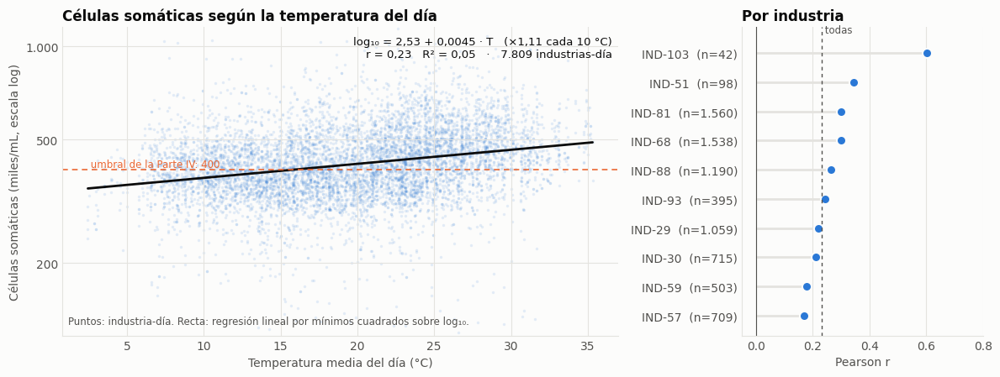

Recuento bacteriano total: log10 = 1.659 +0.0053 · temperatura (×1.13 cada 10 °C, +13 %) | r = 0.110 | R² = 0.012 | n = 8,308


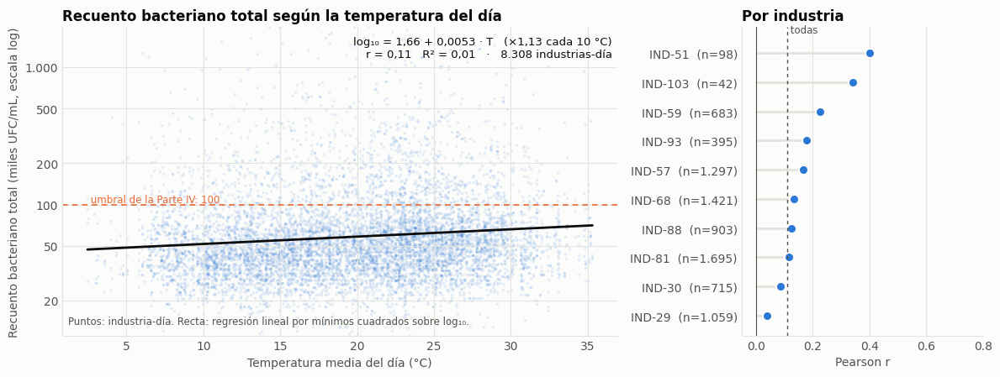


r por industria (sobre log10):
         celulas_somaticas    rbt
cliente                          
IND-103              0.602  0.342
IND-29               0.219  0.038
IND-30               0.210  0.087
IND-51               0.345  0.400
IND-57               0.168  0.166
IND-59               0.177  0.226
IND-68               0.300  0.133
IND-81               0.300  0.117
IND-88               0.263  0.124
IND-93               0.245  0.179

--- serie semanal contra la temperatura media de los 7 días previos (log10 del recuento)
                   semanas  r_crudo  factor_10°C_crudo  r_anomalías  factor_10°C_anomalías
recuento                                                                                  
celulas_somaticas      366    0.511              1.155        0.021                  1.008
rbt                    366    0.391              1.180        0.109                  1.106


In [187]:
UMBRALES = {"celulas_somaticas": L.UMBRAL_RCS, "rbt": L.UMBRAL_RBT}      # en miles por mL, como los datos
por_industria_rec = {}
for p in RECUENTOS:
    por_industria_rec[p] = figura_correlacion(p, umbral=UMBRALES[p])
print()
print("r por industria (sobre log10):")
print(pd.DataFrame({p: por_industria_rec[p]["r"] for p in RECUENTOS}).round(3).to_string())

# semanal, crudo y anomalías (como en «Más allá del calendario»)
logs = [f"log10_{p}" for p in RECUENTOS]
sem_rec = corr.groupby(g_sem).agg({**{c_: "median" for c_ in logs}, f"t{W}": "mean"})
sem_rec = sem_rec[corr.groupby(g_sem)["cliente"].nunique() >= MIN_INDUSTRIAS]
filas = []
for p, c_ in zip(RECUENTOS, logs):
    d = sem_rec[[c_, f"t{W}"]].dropna()
    a_ = d - d.groupby(d.index.month).transform("mean")
    b_crudo = np.polyfit(d[f"t{W}"], d[c_], 1)[0]
    b_anom = np.polyfit(a_[f"t{W}"], a_[c_], 1)[0]
    filas.append({"recuento": p, "semanas": len(d), "r_crudo": d[c_].corr(d[f"t{W}"]),
                  "factor_10°C_crudo": 10 ** (10 * b_crudo), "r_anomalías": a_[c_].corr(a_[f"t{W}"]),
                  "factor_10°C_anomalías": 10 ** (10 * b_anom)})
print()
print(f"--- serie semanal contra la temperatura media de los {W} días previos (log10 del recuento)")
print(pd.DataFrame(filas).set_index("recuento").round(3).to_string())

#### Lectura de los recuentos

- **Los dos recuentos suben con el calor, al revés que la composición, pero la nube diaria casi no lo muestra.**
  Células somáticas: r = 0,23 (R² 0,05), ×1,11 cada 10 °C (un 11 % más). Recuento bacteriano: r = 0,11 (R² 0,01),
  ×1,13 cada 10 °C. La relación es positiva en las diez industrias, en los dos recuentos (de 0,17 a 0,60 en RCS y de
  0,04 a 0,40 en RBT; los r más altos son de las industrias con menos días, IND-103 e IND-51).
- **La mayoría de los días están lejos del umbral.** La recta de RCS cruza los 400 000 cél/mL alrededor de los
  16 °C. Ese corte está en el medio de la nube, y por eso la Parte IV lo puede modelar. El RBT queda casi entero
  por debajo de 100 000 UFC/mL, a cualquier temperatura, y por eso la Parte IV tiene tan pocos positivos ahí.
- **Lo que se ve es la estación, no el calor.** Con la serie semanal, el r de células somáticas sube a 0,51, y
  restando la media de cada mes cae a 0,02 (×1,01 cada 10 °C): el verano trae más células, pero una semana más
  caliente de lo normal para la fecha no trae más células de lo normal. Es lo mismo que encuentra la regresión
  logística (Parte IV): con la fecha en el modelo, el odds ratio por grado de anomalía es 0,99.
- **En el recuento bacteriano queda una señal chica**: r 0,39 en crudo y 0,11 en anomalías (×1,11 cada 10 °C).
  Con 366 semanas el error típico de r ronda 0,05, y las semanas seguidas no son independientes, así que está
  apenas en el borde de lo distinguible de cero. Es coherente con que el calor favorezca el crecimiento de
  bacterias entre el ordeñe y el enfriado, pero no alcanza para afirmarlo.
- **Correlación no es causa**, igual que arriba.

### Datos usados en cada entrenamiento

Una fila por cada ajuste, con las mismas columnas que en las otras partes. Son rectas por mínimos cuadrados (por
industria-día y por semana) que describen la asociación con todos los datos: no hay partición y ninguna se usa para
predecir casos nuevos.

In [188]:
def miles(n):
    return f"{int(n):,}".replace(",", ".")

SIN_PART = "sin partición: describe la asociación con todos los datos"
NOMBRES = {"grasa": "grasa", "proteina": "proteína", "solidos_totales": "sólidos totales",
           "celulas_somaticas": "log10 de células somáticas", "rbt": "log10 del recuento bacteriano"}
n_dia = len(dia)
filas = []
for p in COMPONENTES + RECUENTOS:
    col = f"log10_{p}" if p in RECUENTOS else p
    n = int(corr[[col, "t_media"]].notna().all(axis=1).sum())
    filas.append(DE.fila("VIII", f"recta por mínimos cuadrados: {NOMBRES[p]} ~ temperatura del día", "industrias-día desde septiembre de 2019 "
                         "(mediana de cada industria en el día)", n_dia, n,
                         motivo=f"sin {NOMBRES[p]} ese día o sin temperatura: {miles(n_dia - n)}", particion=SIN_PART,
                         nota="también por industria y con la temperatura de una semana antes" if p in COMPONENTES else "también por industria"))
n_sem_tot = int(corr.groupby(g_sem).ngroups)
filas.append(DE.fila("VIII", "serie semanal: recta y parábola contra la temperatura de 1 a 90 días (5 componentes)",
                     "semanas (mediana entre industrias-día)", n_sem_tot, len(sem),
                     motivo=f"semanas con menos de {MIN_INDUSTRIAS} industrias o sin algún componente: {miles(n_sem_tot - len(sem))}",
                     particion=SIN_PART, nota="las mismas semanas sirven para las anomalías mensuales y el desfase de una semana"))
with pd.option_context("display.max_colwidth", 120):
    display(DE.guardar(filas, "temperatura_leche_cruda"))

,parte,modelo,datos,disponibles,excluidas,motivo de exclusión,usadas,entrenamiento,validación,prueba,partición,nota
0,VIII,recta por mínimos cuadrados: grasa ~ temperatura del día,industrias-día desde septiembre de 2019 (mediana de cada industria en el día),9436,1618,sin grasa ese día o sin temperatura: 1.618,7818,7818,<NA>,<NA>,sin partición: describe la asociación con todos los datos,también por industria y con la temperatura de una semana antes
1,VIII,recta por mínimos cuadrados: proteína ~ temperatura del día,industrias-día desde septiembre de 2019 (mediana de cada industria en el día),9436,1615,sin proteína ese día o sin temperatura: 1.615,7821,7821,<NA>,<NA>,sin partición: describe la asociación con todos los datos,también por industria y con la temperatura de una semana antes
2,VIII,recta por mínimos cuadrados: sólidos totales ~ temperatura del día,industrias-día desde septiembre de 2019 (mediana de cada industria en el día),9436,1614,sin sólidos totales ese día o sin temperatura: 1.614,7822,7822,<NA>,<NA>,sin partición: describe la asociación con todos los datos,también por industria y con la temperatura de una semana antes
3,VIII,recta por mínimos cuadrados: log10 de células somáticas ~ temperatura del día,industrias-día desde septiembre de 2019 (mediana de cada industria en el día),9436,1627,sin log10 de células somáticas ese día o sin temperatura: 1.627,7809,7809,<NA>,<NA>,sin partición: describe la asociación con todos los datos,también por industria
4,VIII,recta por mínimos cuadrados: log10 del recuento bacteriano ~ temperatura del día,industrias-día desde septiembre de 2019 (mediana de cada industria en el día),9436,1128,sin log10 del recuento bacteriano ese día o sin temperatura: 1.128,8308,8308,<NA>,<NA>,sin partición: describe la asociación con todos los datos,también por industria
5,VIII,serie semanal: recta y parábola contra la temperatura de 1 a 90 días (5 componentes),semanas (mediana entre industrias-día),367,1,semanas con menos de 3 industrias o sin algún componente: 1,366,366,<NA>,<NA>,sin partición: describe la asociación con todos los datos,las mismas semanas sirven para las anomalías mensuales y el desfase de una semana


### Conclusiones de la parte

**Composición: con más calor, la leche es más pobre.**
- Por industria-día, r de −0,37 en grasa, −0,49 en proteína y −0,45 en sólidos totales, con el mismo signo en las
  diez industrias.
- La relación es lineal: el término cuadrático agrega como mucho 0,013 de R².
- Por semana, con la temperatura media de los 7 días previos, llega a −0,60 / −0,73 / −0,75.
- Restando el calendario se mantiene en parte (−0,27 / −0,48 / −0,41), así que no es solo la estación.
- Usar la temperatura de la semana anterior no la mejora.

**Recuentos: lo que se ve es la estación.**
- En crudo, el RCS y el RBT suben con la temperatura: r 0,23 y 0,11 por industria-día, ×1,11 y ×1,13 cada 10 °C.
- En anomalías semanales, el RCS cae a 0,02. Coincide con la Parte IV.
- El RBT queda en 0,11, en el borde de lo distinguible de cero.

**Límites.**
- Todo es asociación con la temperatura de un solo punto, no causalidad.
- La parte describe; los modelos que predicen la leche cruda son los de las Partes III y IV.

In [189]:
assert "archivo" not in leche.columns
assert set(leche["cliente"].astype(str).str.match(r"^IND-\d+$")) == {True}
assert (DE.CARPETA / "temperatura_leche_cruda.csv").exists()
print(f"Verificación: todo en orden · la parte tardó {(time.time() - inicio) / 60:.1f} min".replace(".", ","))

Verificación: todo en orden · la parte tardó 0,2 min


<a id="datos-por-entrenamiento"></a>

# Datos usados en cada entrenamiento

Cada parte cierra con su propia tabla de datos usados; acá están todas juntas. Por cada modelo se indica:
- cuántas filas había disponibles;
- cuántas se excluyeron y por qué;
- cuántas se usaron y cómo se repartieron entre entrenamiento, validación y prueba.

En el agrupamiento no hay respuesta correcta y, por lo tanto, no hay conjunto de prueba: entrenamiento es igual a usadas.
Los números salen de esta misma corrida y quedan en `resultados/datos_entrenamiento/`.


In [190]:
import datos_entrenamiento as DE
datos_por_modelo = DE.todas()
print(f"{len(datos_por_modelo)} modelos en {datos_por_modelo['parte'].nunique()} partes")
with pd.option_context("display.max_rows", 200, "display.max_colwidth", 80):
    display(datos_por_modelo)

102 modelos en 8 partes


,parte,modelo,datos,disponibles,excluidas,motivo de exclusión,usadas,entrenamiento,validación,prueba,partición,nota
0,I,"k-medias preliminar y consenso de outliers, solo Senasa","muestras de Senasa con los cuatro análisis (humedad, grasa, proteínas y ceni...",16347,13687,8 con humedad + sólidos incoherentes; 1727 de familias no lácteas; 4006 ques...,2660,2660,NaN,NaN,sin partición: se ajusta con todas las muestras que usa,"k-medias preliminar con k = 5 (silueta, 50 reinicios, semilla 42); el consen..."
1,I,"k-medias final, solo Senasa",muestras del k-medias preliminar sin los outliers,2660,63,63 outliers por consenso,2597,2597,NaN,NaN,sin partición: se ajusta con todas las muestras que usa,"k = 5 por silueta máxima (0.854); 50 reinicios, semilla 42"
2,I,"segundo nivel del DDL: regresión logística, solo Senasa",muestras con tag DDL del k-medias final,2116,595,sin subtipo conocido: no se usan para ajustar (el modelo les propone un subtag),1521,1521,NaN,NaN,sin partición en este cuaderno (se ajusta con todas las que tienen subtipo);...,"subtipo conocido por clase: {'FAMILIAR': 749, 'REPOSTERO': 620, 'HELADERO': ..."
3,I,"segundo nivel de polvos: k-medias en base seca, solo Senasa","muestras con tag POLVO_GRASO, POLVO_MAGRO o PROT_ALTA",471,8,0 con humedad > 15 (no son polvo); 8 outliers de la rama (consenso),463,463,NaN,NaN,sin partición: se ajusta con todas las muestras que usa,"k = 8 por silueta (0.73) en grasa, proteína y cenizas en base seca; además d..."
4,I,"rama de queso: regla del CAA, no se entrena, solo Senasa",quesos que confirma el catálogo,4006,2379,2379 sin materia grasa o sin sólidos totales; 0 imposibles (MG > ST o humeda...,1627,0,NaN,NaN,no se entrena: el subtag sale de la clase de humedad del CAA (art. 605),"entran las 1627, sin quitar outliers"
5,I,"quesos sin tag previo: k-medias y mezcla de gaussianas, solo Senasa",quesos de la rama (humedad y MGES),1627,43,43 outliers por consenso,1584,1584,NaN,NaN,sin partición: se ajusta con todas las muestras que usa; estabilidad con 10 ...,"k-medias con k = 5 (silueta) y mezcla con k = 7 (BIC); es un ensayo, no un m..."
6,I,"k-medias preliminar y consenso de outliers, Senasa + MQ","muestras de Senasa y de MQ con los cuatro análisis (humedad, grasa, proteína...",30089,26152,8 con humedad + sólidos incoherentes; 2319 de familias no lácteas; 5915 ques...,3937,3937,NaN,NaN,sin partición: se ajusta con todas las muestras que usa,"k-medias preliminar con k = 5 (silueta, 50 reinicios, semilla 42); el consen..."
7,I,"k-medias final, Senasa + MQ",muestras del k-medias preliminar sin los outliers,3937,101,101 outliers por consenso,3836,3836,NaN,NaN,sin partición: se ajusta con todas las muestras que usa,"k = 5 por silueta máxima (0.835); 50 reinicios, semilla 42"
8,I,"segundo nivel del DDL: regresión logística, Senasa + MQ",muestras con tag DDL del k-medias final,2226,625,sin subtipo conocido: no se usan para ajustar (el modelo les propone un subtag),1601,1601,NaN,NaN,sin partición en este cuaderno (se ajusta con todas las que tienen subtipo);...,"subtipo conocido por clase: {'FAMILIAR': 789, 'REPOSTERO': 637, 'HELADERO': ..."
9,I,"segundo nivel de polvos: k-medias en base seca, Senasa + MQ","muestras con tag POLVO_GRASO, POLVO_MAGRO o PROT_ALTA",1156,18,2 con humedad > 15 (no son polvo); 16 outliers de la rama (consenso),1138,1138,NaN,NaN,sin partición: se ajusta con todas las muestras que usa,"k = 7 por silueta (0.77) en grasa, proteína y cenizas en base seca; además d..."


<a id="conclusiones-generales"></a>

# Conclusiones generales

Cada parte cierra con sus propias conclusiones y sus números; acá van las ideas principales del trabajo.

**Parte I · Agrupamiento (no supervisado).**
- Con humedad, grasa, proteínas y cenizas, el k-medias encuentra **tipos de producto**:
  - en solo Senasa, 5 grupos con silueta 0,854;
  - en Senasa + MQ, también 5 grupos, con silueta 0,835.
- Los cinco son los mismos en las dos poblaciones: dulce de leche, polvo graso, polvo magro, proteína alta y líquido.
  Con 10 arranques, el k-medias preliminar del consenso de outliers caía en mínimos locales y el número de grupos cambiaba con la semilla; con 50
  arranques, ocho semillas dan los mismos cinco grupos.
- Cuando se revela la familia de cada muestra, que el algoritmo no vio, los grupos coinciden con ella (Rand ajustado
  0,97 y 0,92).
- Quitar los outliers **dentro de cada tipo de producto y por consenso** de tres métodos descarta el 2,4 % y el 2,6 % de
  las muestras. La regla clásica del rango intercuartil descartaba el 8,6 % y el 9,2 %, y con ellas casi todos los dulces de leche
  heladeros, que son legítimos.
- Dentro de cada familia hace falta un segundo nivel:
  - subtipos del dulce de leche;
  - clases de polvo, en base seca;
  - el queso, que va por su propia rama con la humedad del Código Alimentario.

**Parte II · Números contra categorías.**
- Pasar los análisis a categorías y agrupar con k-modas (k fijo en 5, el mismo k que el numérico) **no reemplaza** al
  k-medias:
  - con cuatro variables en tres niveles hay solo 53 o 61 perfiles distintos;
  - por eso la silueta de Hamming sube sola con k y no sirve para elegirlo;
  - en solo Senasa, 4 de sus 5 grupos son dulce de leche casi puro (parten el dulce de leche) y uno mezcla los polvos
    con dulce de leche; en Senasa + MQ solo 2 de 5, y los otros mezclan polvos, líquidos y dulce de leche;
  - el acuerdo con el numérico es bajo (Rand ajustado 0,12 y 0,33; con k = 6 era 0,07 y 0,25);
  - los heladeros no tienen un grupo propio y el grupo donde caen cambia con la semilla.
- Las categorías sirven para describir y para las reglas de asociación, no para encontrar tipos de producto.

**Parte III · Regresión (supervisado): el ciclo anual de la leche cruda.**
- El día del año explica una parte chica de cada muestra: baja el error un 10 % en proteína y un 7 % en grasa.
- En cambio, explica bien el **promedio semanal**: baja el error un 28 % en proteína y un 26 % en grasa, en los años
  2024–2026, que el modelo no vio.
- La proteína pica a fines de mayo y la grasa a mediados de mayo; las dos tocan fondo en diciembre.
- Se eligió un ciclo con senos y cosenos de dos armónicos (Fourier):
  - el polinomio del día del año necesita grado 3 y aun así tiene un salto entre el 31 de diciembre y el 1 de enero;
  - la regresión lineal de grado 1 no capta el ciclo (mejora menos del 2 %);
  - k-NN, árbol y SVR llegan a errores parecidos: el SVR con núcleo RBF queda apenas mejor en proteína (0,0873 contra
    0,0879 de RMSE semanal) y el k-NN en grasa (0,1490 contra 0,1495). Es un empate técnico, y ellos no dan una forma
    que se pueda leer.
- Un grado más de calor que lo normal para la fecha baja la proteína y la grasa en apenas 0,01 g/100 g.

**Parte IV · Regresión logística (supervisado): calidad de la leche cruda.**
- La probabilidad de superar las 400 000 células somáticas por mL se predice razonablemente: AUC 0,69, contra 0,57 de
  la industria sola, con probabilidades calibradas.
- La de superar las 100 000 bacterias por mL apenas mejora a la industria sola: AUC 0,58.
- Lo que explica el riesgo es la **estación**, no el calor: con la fecha en el modelo, cada grado de anomalía tiene un
  odds ratio de 0,99, que no difiere de 1.
- La **lactosa** baja es la mejor señal de células somáticas altas, por la mastitis: odds ratio de 0,70 por cada
  +0,1 g/100 g.
- Con el corte de Youden, el modelo detecta 3 de cada 4 muestras con células altas, a cambio de dar falsa alarma en la
  mitad de las buenas.
- Contra Bayes ingenuo, k-NN, SVM lineal y un árbol, con las mismas variables:
  - el SVM lineal empata con la logística en los dos umbrales;
  - en células somáticas, el k-NN le saca 0,004 de AUC pero calibra peor (ECE 0,069 contra 0,050); en bacterias
    queda 0,011 por debajo;
  - Bayes calibra mucho peor;
  - la logística se elige porque es la única que da odds ratios con intervalos, que es lo que responde la pregunta del
    calor, y porque rinde igual dejando una industria afuera.

**Parte V · Predicción del tipo de producto (supervisado).**
- Con la composición y el texto de la descripción, un modelo de árboles potenciados acierta la familia en el 79 % de las
  muestras (F1 macro 0,62), validando por envío para que muestras hermanas no se repartan entre entrenamiento y prueba.
- Cuando la probabilidad supera 0,8 decide sola el 65 % de las muestras, con un acierto del 95 %; el resto queda para
  revisión manual.

**Parte VI · Lactosa residual de la leche deslactosada (supervisado).**
- Con solo 86 lotes medidos dos veces, la caída de la lactosa da un orden de magnitud. La lactosa baja con los días
  (Spearman −0,37), pero el intervalo del efecto de la temperatura incluye el cero.
- Sirve como guía para el control de la enzima, no como predictor operativo.

**Parte VII · Árbol de decisión en cascada (supervisado, trabajo de otro integrante).**
- Con solo la composición, un árbol acierta la familia en el 89 % de una prueba al azar del 20 % (F1 macro 0,67,
  AUC macro 0,90). Agrupando por envío baja apenas un punto.
- El subtipo es lo difícil: la cascada completa acierta familia y subtipo en el 65 % de las muestras con subtipo real.
  Va bien en manteca, leche fluida y dulce de leche, y mal en queso, suero y leche en polvo.
- La clase «sin clasificar» con umbral de 0,85 (V3) evita que el modelo se refugie en ella (19 % → 6 % de las reales).
  Sumar las muestras de MQ no mejora la familia, pero sí el subtipo de concentrados y sueros.

**Parte VIII · Leche cruda y temperatura de Rafaela (asociación).**
- Con más calor, la leche es más pobre: r de −0,37 en grasa, −0,49 en proteína y −0,45 en sólidos totales por
  industria-día, en las diez industrias y de forma lineal. Restando el calendario se mantiene en parte (r −0,27 a
  −0,48 por semana).
- Los recuentos suben con la temperatura en crudo, pero en anomalías semanales las células somáticas caen a r 0,02:
  es la estación, como en la Parte IV. En el recuento bacteriano queda una señal chica (r 0,11), en el borde.

**Límites.**
- Las muestras de laboratorio no son un muestreo al azar de la producción: reflejan lo que cada cliente decidió
  analizar.
- Una industria cambió la unidad del recuento bacteriano en 2024 y esos valores se descartaron.
- Las Partes V y VII responden casi la misma pregunta con muestras, filtros y validación distintos. Sus exactitudes
  (79 % y 89 %) no se comparan directamente.
